# Test results — every analysis and test behind the paper, with its results

**What this notebook is.** All the analyses whose numbers or caches the paper uses, and the tests run on them:
the beam-matched ring TODs, the spectral fits along the TRIS ring, the model comparison, the 408 MHz sky models,
the T–T indices, the Haslam scale/offset fits, the zero-level and survey-subset robustness tests, the prediction at
other frequencies (RHINO), and the beam tests. `10_paper_plots.ipynb` reads the caches and CSVs written here.

Built from eleven earlier notebooks, part of a twelfth and three script-based beam tests (`NOTEBOOK_INDEX.md` maps
each Part to its origin). Added on top: this overview, one banner per Part, one copied setup cell (Part K2) and the
Markdown of Parts K3–K5. **Stored outputs are from the original notebooks and were not re-run after the merge.**

**The pipeline.** The beam-matched TODs, the model comparison (TRIS excluded), the model selection, our spectral model (the best model fitted with TRIS), the 408 MHz prediction and the RHINO prediction are made by `python run_pipeline.py --step all` (`moonrunes.pipeline`, described in `PIPELINE.md`) into `paper_outputs/pipeline/`. The Parts below read those products and do not rebuild them; a Part's own results are checks (`test_outputs/`) unless the paper quotes them.

**Order.** The Parts are in dependency order, so *Run All* works from a clean state: A writes the TOD cache that
B, E, H and I read; B writes the fit cache that D–I and K2 read; H writes what I reads.

| Part | What | Was | Writes (main files) | Feeds the paper |
|---|---|---|---|---|
| A | Beam-matched ring TODs, compared with the old TODs (the TODs themselves are made by pipeline step 2) | `18_beam_matched_tods` | `test_outputs/beam_matched_vs_old/` | — (reads `paper_outputs/pipeline/step2_ring_tods/`) |
| B | Curved power-law fits per ring sample; which 408 MHz sky model matches (the power law is pipeline step 5) | `12_sky_models_vs_fit_408` | `test_outputs/sky_models_408/` | — (a check of pipeline steps 5–6) |
| C | Model comparison diagnostics (evidence, convergence, robustness of the verdict) of pipeline step 3 | `11_model_comparison_diagnostics` | `paper_outputs/model_comparison/diagnostic_plots/` | Section 5 counts (main.tex:501) — four points, TRIS excluded by design |
| D | Model-choice decision sheet (five criteria, with and without Cygnus) | `15_model_choice_decision_sheet` | `paper_outputs/model_choice/` | stacked residuals (main.tex:503); criterion 1 = step 3 evidence (no TRIS), 2–5 = six-point fits |
| E | T–T indices along the ring; sky models fitted to TRIS at 600/820 MHz | `14_ring_tt_betas` | `paper_outputs/phil_plots/` | `tab:step1` (Plot 6a) |
| F | Haslam and the sky models against the power-law prediction: scale–offset (York); a check of pipeline step 6 | `16_haslam_vs_power_law_408` | `test_outputs/plot3_haslam_vs_fit/` | main.tex:647 ratio (`tab:scale-offset` is step 6's) |
| G | Haslam calibrated with one gain and offset | `17_haslam_gain_offset_calibration` | `test_outputs/plot3_haslam_calibration/` | possibly main.tex:647 (unconfirmed) |
| H | Zero-level offsets as fit parameters | `20_zero_level_offsets` | `paper_outputs/zero_level_offsets/` | main.tex:394; input of I |
| I | Robustness of the Haslam gain and offset: survey subsets, models, sample subsets, zero levels | `21_robustness_check` | `paper_outputs/robustness_check/` | main.tex:396 and others |
| J | Fits on 13 points and the TOD prediction at any frequency (Tests 1–5; Test 6 is pipeline step 7) | `19_power_law_tod_prediction` | `test_outputs/tod_prediction/` | — |
| K1 | Beam widths (FWHM) and smoothing | `09_beam_fwhm_tests` | — | the 19.155°/23.366° beam (fig2, `tab:surveys`) |
| K2 | Map-route elliptical beam, harmonic checks, convolve→deconvolve, two-step vs one-step matching, beam-specification variants | `03_diagnostics`, cells 39–114 | `test_outputs/beam_variants/` | — |
| K3 | Beam averaging with spectral-index blobs (Haslam) | `beam_averaging_blobs/` (script) | that folder | main.tex:275 |
| K4 | Two-step vs one-step beam matching with four FWHM scalings (Haslam) | `scripts/fwhm_scaling_test.py` | `test_outputs/fwhm_scaling_test/` | main.tex:273 |
| K5 | The K3 and K4 tests at LWA1 35 MHz and Stockert 1420 MHz | `beam_tests_lwa35_stockert1420/` (scripts) | that folder | — |

**Survey sets differ between Parts** (see `HANDOVER.md`): B, D (fits), E, F, G, H, I use the six-point set (TRIS 600,
TRIS 820, LWA1 35, Maipu 45, LWA1 80, Stockert 1420); C and the evidence read by D use
the pipeline's step 3 data sets, TRIS excluded (`comparison.exclude_tris`; 11 points with the current configs, 4 in the stored outputs); J uses 13 points (six + LWA1 38–74 MHz).

**How to run.** Kernel: the `limtod` conda environment; working directory `notebooks/`. Each Part starts with its own
setup cell and can be run on its own from there once the Parts it reads have been run (or their caches exist).
`model_comparison/run_comparison.py` must have been run for Parts C and D. Parts K3–K5 show saved results only; the
scripts that make them are named in each Part.

# Part A — Beam-matched ring TODs

**Origin:** `notebooks/18_beam_matched_tods.ipynb` (archived: `../moonrunes_archive_2026-11-16/notebooks/18_beam_matched_tods.ipynb`)

| | |
|---|---|
| **Reads** | `paper_outputs/pipeline/step2_ring_tods/` (`beam_matched_tods.npz`, made by `run_pipeline.py --step ring_tods`), `test_outputs/beam_matched_vs_old/old_native_tods.npz` |
| **Writes** | `test_outputs/beam_matched_vs_old/` (`beam_matched_minus_old.csv`, figure) |
| **Feeds the paper** | nothing directly (the TODs it reads feed fig4 and fig8) |

**Stored outputs** are from the original notebook (not re-run after the merge). The cache is reused when its key matches the config (`REBUILD = False`).

**Pipeline:** the TODs come from pipeline step 2 (`moonrunes.pipeline.step_ring_tods`); this Part reads them and compares them with the old TODs.

## Beam-matched ring TODs for every survey and sky model

**Why.** The older route (`sed.tod_beam: native`, `sed_prototype.Inputs._native_tod`) makes a TRIS ring TOD from the map at its
**own resolution**, degraded to nside 16 and observed with limTOD's measured TRIS beam on an nside-16 grid. That is a
convolution with the TRIS beam, but **not beam matching**: each survey's own beam (LWA1 35 MHz 4.65°, Maipu 4.6°,
LWA1 80 MHz 2.04°, LFSM 5.1°, …) stays in the TOD on top of the TRIS beam, and the sky is pixelised at nside 16
(3.7° pixels) before the beam is applied. The TRIS data themselves see the sky through the TRIS beam only.

**What this notebook does.** It makes ring TODs with the **pipeline's own beam matching**: stage 2's `tris_cuts`
kernel (`moonrunes.elliptical_beam`, `PIPELINE.md` Appendix A.9), evaluated directly at the 120 ring pointings.

* **Kernel:** the measured TRIS cut beam (19.155° × 23.366°, E plane 7° east of the meridian, zero beyond 90°).
  For a survey whose own beam would widen the TRIS core by more than 0.2% (natives above ~1.2°), the cut beam is
  compressed to the quadrature widths √(TRIS² − native²), so that after the survey's own beam the total is the TRIS
  beam (`broad_native_kernel: scaled_cuts`). Narrower natives use the cut beam as is.
* **Pointings:** TRIS is a zenith-pointing drift scan, so ring sample k sees RA = LST_k, Dec = 42.433° (limTOD's
  `tris_zenith_geometry`).
* **Sky grid:** the map is put on nside 64 (0.92° pixels, `beam_matching.elliptical.nside_work`), 4× finer than the
  old TOD route; partial maps use the normalised convolution, and a sample is kept when the observed-weight fraction
  is ≥ 0.5 (`beam_matching.weight_floor`), the same floor as the old coverage cut.
* **Maps:** every fitted survey and Haslam at their own frequency; the seven 408 MHz sky models of notebook 12; and
  GSM2008 and GSM2016 at the TRIS effective frequencies (600.5, 817.8 MHz).
* **Corrections stretched to the TRIS frequencies:** the Carter and Irfan corrections are defined at 408 MHz and GINAN
  at 350 MHz, so they cannot be applied at 600/820 MHz directly. Each is applied to the base model's 408 MHz map
  (GSM2008 or GSM2016; GINAN to GSM2016 as in notebook 12), and the corrected map is carried to 600.5 / 817.8 MHz
  with the base model's own per-pixel spectrum: T_corr(ν) = T_corr(408) × T_model(ν) / T_model(408). This keeps
  each model's spectral shape and scales the correction with it; it is an assumption, not part of the published
  corrections. Applying Carter (a Haslam calibration) to GSM2008 is natural because GSM2008 is locked to Haslam at
  408 MHz; for GSM2016 it is a test of the same idea.
* **LFSM stretched to the TRIS frequencies:** LFSM is only valid up to 408 MHz and has no spectrum above it, so it is
  extended as a power law with its own per-pixel spectral index between 300 and 408 MHz:
  T(ν) = T(408) (ν/408)^β, β = ln[T(408)/T(300)] / ln(408/300). Also an assumption. Temperatures are converted exactly as for
  the SED fit (`sky_maps.rj_excess`: RJ, CMB removed).

**Outputs** go to `paper_outputs/beam_matched_tods/`: the TODs (`beam_matched_tods.npz` and a CSV), the native
beams used, and a comparison with the old TODs. Notebooks 14 (T–T and TRIS-frequency TODs) read them.
**Used everywhere:** `sed_prototype.Inputs.ring_tod` makes exactly these TODs
(`run_pipeline.yaml` `sed.tod_beam: beam_matched`; equal to the cache here to 0 K), so the pipeline and the SED fits
(`run_comparison.py`) use them. The old TODs this
notebook compares against are kept in `old_native_tods.npz`.

Rerun: Restart & Run All (a few minutes; the result is cached).

In [1]:
%matplotlib inline
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT_DIR = REPO / "test_outputs" / "beam_matched_vs_old"          # this Part's comparison with the old TODs
PIPE2 = REPO / "paper_outputs" / "pipeline" / "step2_ring_tods"  # run_pipeline.py step 2 makes the TODs; read only
OLD_SNAPSHOT = OUT_DIR / "old_native_tods.npz"                    # the old TODs, saved 2026-10-27
CYG_A_RA = 299.9

sys.path.insert(0, str(REPO / "src"))
from moonrunes.style import use_tris_style, COLORS
use_tris_style()
plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12,
                     "legend.fontsize": 10, "figure.facecolor": "white"})
OUT_DIR.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png")
    plt.show()
    print(f"saved {(OUT_DIR / f'{name}.png').relative_to(REPO)}")

### The beam-matched observation

`ring_tod(sky, observed, frame, native_fwhm)` rotates a map to equatorial (as `Inputs._rotated` does), and evaluates
the pipeline's beam-matching kernel for that native beam at the 120 ring pointings. The table lists the kernel chosen
for each native width.

In [2]:
sys.dont_write_bytecode = True
sys.path.insert(0, str(REPO / "src"))
import healpy as hp
from moonrunes import frames, sky_maps, elliptical_beam
from moonrunes.config import load_config
from moonrunes.stage1_tris_maps import import_limtod_tris

config = load_config(REPO / "configs" / "run_pipeline.yaml")
SPEC = elliptical_beam.beam_spec_from_config(config, kernel="tris_cuts")
FLOOR = float(config.require("beam_matching.weight_floor"))
tris = import_limtod_tris(config)
RA = np.load(PIPE2 / "beam_matched_tods.npz")["ra_deg"]
geom = tris.tris_zenith_geometry(RA)
assert np.allclose(geom.elevation_deg, 90.0) and np.allclose(geom.lst_deg, RA)
DEC = float(geom.latitude_deg)
VEC = hp.ang2vec(np.radians(90.0 - DEC) * np.ones_like(RA), np.radians(RA))
print(f"{RA.size} pointings at Dec {DEC:.3f} deg, RA = LST 0-357 deg; kernel spec: tris_cuts, "
      f"E {SPEC.fwhm_e_deg} x H {SPEC.fwhm_h_deg} deg, nside_work {SPEC.nside_work}, weight floor {FLOOR}")


rows = []
for n in sorted({0.24, 0.33, 0.59, 0.8, 0.933, 1.0, 2.04, 4.6, 4.65, 5.1}):
    k = elliptical_beam.kernel_for(SPEC, n)
    rows.append({"native FWHM [deg]": n, "kernel": k.shape, "kernel E x H [deg]": f"{k.fwhm_e_deg:.2f} x {k.fwhm_h_deg:.2f}",
                 "expected total E x H [deg]": f"{k.expected_e_deg:.2f} x {k.expected_h_deg:.2f}"})
print(pd.DataFrame(rows).to_string(index=False))

120 pointings at Dec 42.433 deg, RA = LST 0-357 deg; kernel spec: tris_cuts, E 19.155 x H 23.366 deg, nside_work 64, weight floor 0.5
 native FWHM [deg]    kernel kernel E x H [deg] expected total E x H [deg]
             0.240 tris_cuts      19.16 x 23.37              19.16 x 23.37
             0.330 tris_cuts      19.16 x 23.37              19.16 x 23.37
             0.590 tris_cuts      19.16 x 23.37              19.16 x 23.37
             0.800 tris_cuts      19.16 x 23.37              19.17 x 23.38
             0.933 tris_cuts      19.16 x 23.37              19.18 x 23.38
             1.000 tris_cuts      19.16 x 23.37              19.18 x 23.39
             2.040 tris_cuts      19.05 x 23.28              19.16 x 23.37
             4.600 tris_cuts      18.59 x 22.91              19.16 x 23.37
             4.650 tris_cuts      18.58 x 22.90              19.16 x 23.37
             5.100 tris_cuts      18.46 x 22.80              19.16 x 23.37


### Build the TODs (cached)

In [3]:
# The beam-matched ring TODs of every survey and sky model are made by the pipeline
# (`python run_pipeline.py --step ring_tods`, step 2; code in moonrunes.pipeline.step_ring_tods); this Part reads them.
CACHE = PIPE2 / "beam_matched_tods.npz"
if not CACHE.exists():
    raise FileNotFoundError(f"{CACHE.relative_to(REPO)} is missing: run `python run_pipeline.py --step ring_tods` first")
z = np.load(CACHE, allow_pickle=False)
BM = {k: z[k] for k in z.files}
META = pd.read_csv(PIPE2 / "beam_matched_tods_meta.csv")
print(f"beam-matched TODs read from {CACHE.relative_to(REPO)}")
print(META.round(3).to_string(index=False))

beam-matched TODs read from paper_outputs/pipeline/step2_ring_tods/beam_matched_tods.npz
          kind                        name  freq_mhz  native_fwhm_deg    kernel  kernel_e_deg  kernel_h_deg  n_valid
        survey              LWA_35MHz.fits      35.0            4.650 tris_cuts        18.582        22.899      120
        survey                LWA1_38.fits      38.0            4.280 tris_cuts        18.671        22.971      120
        survey                LWA1_40.fits      40.0            4.070 tris_cuts        18.718        23.009      120
        survey                LWA1_45.fits      45.0            3.620 tris_cuts        18.810        23.084      120
        survey            MAIPU_45mhZ.fits      45.0            4.600 tris_cuts        18.594        22.909      120
        survey                LWA1_50.fits      50.0            3.260 tris_cuts        18.876        23.137      120
        survey                LWA1_60.fits      60.0            2.710 tris_cuts        18.96

### How much does beam matching change the TODs?

The beam-matched TOD minus the old TOD (`Inputs._native_tod`), in kelvin, per ring sample: the median, the median of
the absolute value and the largest absolute value. The old TODs are the fit inputs of notebook 12's power-law fits,
its 408 MHz sky-model TODs and notebook 14's GSM TODs at the TRIS frequencies, as they were before the switch; they
were saved to `old_native_tods.npz` on 2026-10-27, because rerunning notebooks 12 and 14 replaces those caches.

In [4]:
# The old TODs, as notebook 12's fit cache, its sky_tods.npz and notebook 14's GSM cache held them before
# the switch (rerunning those notebooks replaces them with the beam-matched ones).
zo = np.load(OLD_SNAPSHOT, allow_pickle=False)
assert np.allclose(zo["ra_deg"], RA)
old = {k: zo[k] for k in zo.files if k != "ra_deg"}

NATIVE_OF = META.groupby("name")["native_fwhm_deg"].first().to_dict()
rows = []
for k in [k for k in BM if not k.startswith("weight::") and k != "ra_deg"]:
    if k not in old:
        continue
    d = BM[k] - old[k]
    ok = np.isfinite(d)
    rows.append({"TOD": k.split("::", 1)[1].replace("::", " at "), "kind": k.split("::")[0],
                 "native FWHM [deg]": float(NATIVE_OF[k.split("::")[1]]),
                 "N": int(ok.sum()), "median new − old [K]": np.median(d[ok]),
                 "median |new − old| [K]": np.median(np.abs(d[ok])), "largest |new − old| [K]": np.abs(d[ok]).max(),
                 "RA of largest [deg]": RA[ok][np.argmax(np.abs(d[ok]))]})
CMP = pd.DataFrame(rows)
CMP.to_csv(OUT_DIR / "beam_matched_minus_old.csv", index=False)
with pd.option_context("display.width", 220):
    print(CMP.round(3).to_string(index=False))

                        TOD      kind  native FWHM [deg]   N  median new − old [K]  median |new − old| [K]  largest |new − old| [K]  RA of largest [deg]
             LWA_35MHz.fits    survey              4.650 120               -30.169                  41.927                  263.759               302.75
           MAIPU_45mhZ.fits    survey              4.600 120               -17.256                  23.701                  105.259               302.75
             LWA_80MHz.fits    survey              2.040 120                -1.926                   2.290                   18.304               302.75
STOCKERT_VILLA_1400MHZ.fits    survey              0.590 120                -0.000                   0.001                    0.010               305.75
 HASLAM_DESTRIPED_ONLY.fits    survey              0.933 120                -0.018                   0.021                    0.237               300.00
       Haslam (uncorrected)  model408              0.933 120                -0.018

#### Figure 1 — beam-matched minus old TOD along the ring
Each line is one TOD: the beam-matched ring TOD minus the old one, in kelvin. Left: the surveys used in the SED fit
and Haslam; right: the 408 MHz sky models. The dotted line is Cygnus A.

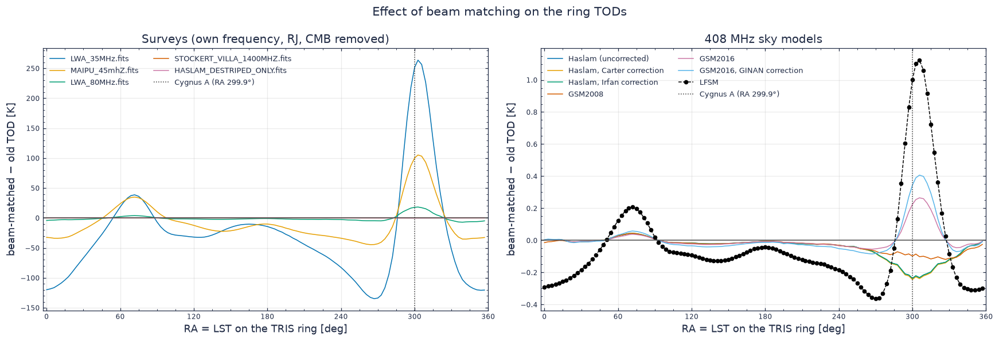

saved test_outputs/beam_matched_vs_old/fig1_beam_matched_minus_old.png


In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 5.5), sharex=True)
cols = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#000000", "#882255"]
for ax, kind in ((a1, "survey"), (a2, "model408")):
    keys = [k for k in BM if k.startswith(kind + "::") and k in old]
    for c, k in zip(cols, keys):
        ax.plot(RA, BM[k] - old[k], color=c, label=k.split("::")[1])
    ax.axhline(0, color="0.3")
    ax.axvline(CYG_A_RA, color="0.2", ls=":", label=f"Cygnus A (RA {CYG_A_RA:g}°)")
    ax.set_xlim(-3, 360); ax.set_xticks(np.arange(0, 361, 60)); ax.grid(alpha=0.25)
    ax.set_xlabel("RA = LST on the TRIS ring [deg]"); ax.set_ylabel("beam-matched − old TOD [K]")
    ax.legend(fontsize=8.5, ncol=2)
a1.set_title("Surveys (own frequency, RJ, CMB removed)"); a2.set_title("408 MHz sky models")
fig.suptitle("Effect of beam matching on the ring TODs", fontsize=14)
fig.tight_layout()
save(fig, "fig1_beam_matched_minus_old")

### Where the beam-matched TODs are used

The pipeline's own TOD code makes these TODs: `sed_prototype.Inputs.ring_tod`, set by
`run_pipeline.yaml` `sed.tod_beam: beam_matched` (the older route is `sed.tod_beam: native`). Its TODs equal this
notebook's cache to 0 K, with the same valid samples, for every survey and Haslam.

* **Read from this notebook's cache:** notebook 14 (T–T β, the β matrix and the TRIS-frequency TODs).
* **Made by `Inputs.ring_tod`:** the SED fits behind `paper_outputs/model_comparison/results/` (`run_comparison.py`), notebook 12's
  fit cache and 408 MHz sky-model TODs (and so notebooks 13, 15, 16 and 17, which read them), notebook 11, and notebooks
  07, 08 and 10. Their caches carry a `tod_key`, so fits made from the old TODs are redone, not reused.
* **Not changed:** notebooks 01, 03, 09 and `beam_averaging_blobs/`, which study the TRIS beam itself with limTOD, and
  the map route and stage 2, which smooth with `beam_matching.kernel`.


# Part B — Spectral fits along the ring and the 408 MHz sky models

**Origin:** `notebooks/12_sky_models_vs_fit_408.ipynb` (archived: `../moonrunes_archive_2026-11-16/notebooks/12_sky_models_vs_fit_408.ipynb`)

| | |
|---|---|
| **Reads** | power-law fits: `paper_outputs/pipeline/step5_fit/``fits/`; 408 MHz sky-model TODs: `paper_outputs/pipeline/step2_ring_tods/``sky_tods.npz`; `res/`, `configs/run_pipeline.yaml`, `configs/model_comp_config.yaml`, `error_bars.csv` (curved power law) |
| **Writes** | `test_outputs/sky_models_408/` (curved power-law fits in `cache/fits/`, `chi2_sky_models_vs_fits.csv`, figures) |
| **Feeds the paper** | nothing directly: the 408 MHz prediction and `tab:408-residuals` come from pipeline steps 5–6; this Part is a check that adds the curved power law |

**Stored outputs** are from the original notebook (not re-run after the merge). Survey set: six points. Its Summary cell quotes χ²/N values from an earlier run (2026-10-23) that differ from its own CSV.

**Pipeline:** the power-law fits (step 5) and the 408 MHz sky-model TODs (step 2) come from the pipeline; this Part fits only the curved power law and reads the rest.

## Which sky model matches the fitted 408 MHz sky along the TRIS ring?

**The question.** The model comparison (`model_comparison/`) fits a power law and a curved power
law to the SED at every TRIS ring sample. Haslam is **not** one of the fitted points, so each fit
*predicts* the 408 MHz sky seen through the TRIS beam. This notebook asks which existing 408 MHz sky
model agrees best with that prediction.

**What it does.**
1. **Fits:** reruns the power law and the curved power law at every ring sample with UltraNest,
   with the same data, error bars, priors and sampler settings as `run_comparison.py`
   (`configs/model_comp_config.yaml`), but keeping the posterior. The pivot is 408 MHz, so the
   predicted 408 MHz temperature is the amplitude A.
2. **Sky-model TODs:** builds each sky model at 408 MHz and beam-matches it to the TRIS beam at the
   ring pointings, exactly as the pipeline does for every map (`sed_prototype.Inputs.ring_tod`,
   `sed.tod_beam: beam_matched`; the same TODs as notebook 18).
3. **Compares:** χ² = Σ (T_model − A_fit)² / σ_A² over the ring samples, for every pair of sky model
   and fit. The lowest χ² wins.

**Temperatures** are Rayleigh–Jeans with the CMB removed, the convention of the SED fits.

**Rerun:** Restart & Run All. The fits and TODs are cached in `paper_outputs/sky_models_408/cache/`;
delete that folder to rebuild them (about 15 minutes). Settings are in the next cell.

In [6]:
%matplotlib inline
import os
os.environ.setdefault("TQDM_DISABLE", "1")
import sys
import json
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MC_DIR = REPO / "model_comparison"
CONFIG_PATH = REPO / "configs" / "model_comp_config.yaml"
ERRORS_CSV = REPO / "configs" / "error_bars.csv"
OUT_DIR = REPO / "test_outputs" / "sky_models_408"   # a check: the pipeline (steps 5-6) makes the paper's numbers
CACHE_DIR = OUT_DIR / "cache"

# ---- fits ----
RUN_FITS = True            # run any fit missing from the cache (False: use the cache only)
SEED = 12345               # UltraNest draws from numpy's global RNG; seeded per ring sample
BEST_FIT = "maxlike"       # "maxlike" (maximum-likelihood point) or "median" (posterior median) of A

# ---- the Haslam map the corrections are applied to: the pipeline's target ----
HASLAM_FILE = "HASLAM_DESTRIPED_ONLY.fits"

# ---- Haslam corrections, as  E_corrected = scale * E + offset_k,  where E is the CMB-removed
# ---- RJ Haslam temperature.  None = not yet specified (the entry is skipped and reported).
T_CMB_RJ_408 = None        # filled in below from moonrunes.sky_maps.cmb_rj_k(408)
IRFAN_MONOPOLE_K = 8.9     # Irfan & Puglisi 2025: CMB + radio background + 21 cm (Wehus et al. 2017)
HASLAM_CORRECTIONS = {
    "Haslam, Carter correction": dict(
        scale=1.029, offset_k=0.91,
        ref="Carter et al. 2025 (B-GSM), arXiv:2504.04503: Eq. 2 T_cal = a T + b on CMB-subtracted "
            "maps, Table 2 a_408 = 1.029 ± 0.003, b_408 = +0.91 ± 0.05 K; one value for the whole sky"),
    "Haslam, Irfan correction": dict(
        scale=1.0, offset_k="irfan",   # = -(8.9 K - T_CMB,RJ(408)), set below
        ref="Irfan & Puglisi 2025, arXiv:2512.08522: T_sync = T_408 - 8.9 K (8.9 ± 1.3 K = CMB + "
            "radio background + 21 cm). Removes ~6.2 K more than the CMB alone"),
}

# ---- GINAN correction (McKay et al. 2025, arXiv:2509.11846): a correction to GSM2016,
# ---- T = (T_GSM16 - T_offset(f)) * F_scale(f), valid only for 60-350 MHz.  It is built at
# ---- GINAN_FREQ_MHZ and carried to 408 MHz with GSM2016's own per-pixel ratio
# ---- T_GSM16(408) / T_GSM16(GINAN_FREQ_MHZ).
GINAN_FREQ_MHZ = 350.0     # top of the correction's valid range

# ---- reading the evidence ----
CYG_A_RA = 299.9           # deg

# ---- Figure 1 only: spectral index used to scale the TRIS rings to 408 MHz, T * (408 / nu_eff)^beta
TRIS_BETA = -2.7

PL, CURVED = "power law", "curved power law"
FITS = [PL, CURVED]
# Fits in ink (black / grey); sky models in Okabe-Ito, colourblind-safe.
FIT_STYLE = {PL: dict(color="black", ls="-"), CURVED: dict(color="0.5", ls="--")}
SKY_STYLE = {
    "Haslam (uncorrected)":      dict(color="#E69F00", ls="-"),
    "Haslam, Carter correction": dict(color="#56B4E9", ls="-"),
    "Haslam, Irfan correction":  dict(color="#009E73", ls="-"),
    "GSM2008":                   dict(color="#0072B2", ls="--"),
    "GSM2016":                   dict(color="#D55E00", ls="--"),
    "GSM2016, GINAN correction": dict(color="#CC79A7", ls="--"),
    "LFSM":                      dict(color="#000000", ls=":"),
}

plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 13,
                     "axes.labelsize": 12, "legend.fontsize": 10, "figure.facecolor": "white"})
OUT_DIR.mkdir(exist_ok=True)
CACHE_DIR.mkdir(exist_ok=True)

def save(fig, name):
    # Save a figure as PNG in OUT_DIR, then show it inline.
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"saved {(OUT_DIR / f'{name}.png').relative_to(REPO)}")

### 1. Inputs

The repo's loader builds the ring data, the fitted surveys and the TRIS beam once (a few minutes).
It is only built if something is missing from the cache.

In [7]:
sys.dont_write_bytecode = True                   # leave no __pycache__ in model_comparison/
sys.path.insert(0, str(REPO / "src"))
sys.path.insert(0, str(MC_DIR))
from moonrunes import sky_maps
from moonrunes.sed_prototype import MIN_COVERAGE
from models import build_models, prior_transform
import run_comparison as rc                      # imported for its data helpers; main() is not run

with open(CONFIG_PATH) as f:
    cfg = yaml.safe_load(f)
assert cfg["data"]["route"] == "tod", cfg["data"]
from moonrunes.config import load_config
assert load_config(REPO / "configs" / "run_pipeline.yaml").require("pipeline.target_file") == HASLAM_FILE  # the one place the target is set
MODELS = build_models(cfg)
SCFG = cfg["sampler"]
PRIOR_KEY = json.dumps({n: cfg["priors"][n] for n in ("A_K", "beta", "C")}, sort_keys=True)
from moonrunes.config import load_config
from moonrunes.sed_prototype import tod_method_key
# How the ring TODs are made (run_pipeline.yaml sed.tod_beam: beam_matched).  Cached results
# made from other TODs do not match it and are redone.
TOD_KEY = tod_method_key(load_config(REPO / "configs" / "run_pipeline.yaml"))

T_CMB_RJ_408 = float(sky_maps.cmb_rj_k(408.0))
HASLAM_CORRECTIONS["Haslam, Irfan correction"]["offset_k"] = -(IRFAN_MONOPOLE_K - T_CMB_RJ_408)
print(f"T_CMB in RJ at 408 MHz: {T_CMB_RJ_408:.3f} K")
print(f"Irfan offset on the CMB-removed map: {HASLAM_CORRECTIONS['Haslam, Irfan correction']['offset_k']:+.3f} K")

_INP = None
def get_inputs():
    global _INP
    if _INP is None:
        from moonrunes.config import load_config
        from moonrunes.sed_prototype import Inputs
        print("building the TOD-route inputs (takes a few minutes)...")
        _INP = Inputs(load_config(REPO / "configs" / "run_pipeline.yaml"), REPO / "res",
                      target_file=HASLAM_FILE, verbose=False)
    return _INP

ra_path = CACHE_DIR / "ring_ra.npy"
if not ra_path.exists():
    np.save(ra_path, np.asarray(get_inputs().ra, dtype=float))
RA = np.load(ra_path)
N_RING = RA.size
print(f"{N_RING} ring samples, RA {RA.min():.2f}-{RA.max():.2f} deg")

T_CMB in RJ at 408 MHz: 2.716 K
Irfan offset on the CMB-removed map: -6.184 K
120 ring samples, RA 0.00-357.00 deg


### 2. The fitted 408 MHz sky: power law and curved power law

Each ring sample is fitted with the data, error bars, priors and UltraNest settings of the model
comparison run. Results are cached per sample; a cached fit made with different priors is redone.

In [8]:
PIPE_FITS = REPO / "paper_outputs" / "pipeline" / "step5_fit" / "fits"   # the power law: run_pipeline.py step 5 makes these fits

def fit_path(unit, model):
    folder = PIPE_FITS if model == PL else CACHE_DIR / "fits"
    return folder / f"unit{unit:03d}__{model.replace(' ', '_')}.npz"

def run_nested(model, nu, t, s, seed):
    # The same likelihood and UltraNest call as run_comparison.log_evidence, keeping the posterior.
    import ultranest
    names, fn = MODELS[model]
    transform = prior_transform(names, cfg["priors"])
    norm = -np.sum(np.log(s * np.sqrt(2 * np.pi)))
    def loglike(params):
        r = (t - fn(nu, params)) / s
        return -0.5 * np.sum(r * r, axis=-1) + norm
    np.random.seed(seed)
    sampler = ultranest.ReactiveNestedSampler(names, loglike, transform, vectorized=True,
                                              log_dir=SCFG.get("log_dir"))
    logging.getLogger("ultranest").setLevel(logging.WARNING)
    res = sampler.run(min_num_live_points=int(SCFG["min_num_live_points"]), dlogz=float(SCFG["dlogz"]),
                      show_status=False, viz_callback=False)
    return dict(logz=res["logz"], logzerr=res["logzerr"], samples=res["samples"],
                maxpoint=np.asarray(res["maximum_likelihood"]["point"]), names=np.array(names))

def load_fit(unit, model):
    p = fit_path(unit, model)
    if not p.exists():
        return None
    z = np.load(p, allow_pickle=False)
    if str(z["prior_key"]) != PRIOR_KEY or "tod_key" not in z.files or str(z["tod_key"]) != TOD_KEY:
        return None                                  # made with other priors or other ring TODs: redo
    return {k: z[k] for k in z.files}

fits = {m: {} for m in FITS}
missing = [(u, m) for u in range(N_RING) for m in FITS if load_fit(u, m) is None]
pl_missing = sorted(u for u, m in missing if m == PL)
if pl_missing:
    print(f"!! {len(pl_missing)} power-law fits are missing from {PIPE_FITS.relative_to(REPO)}: run "
          "`python run_pipeline.py --step fit` (step 5); this Part fits only the curved power law itself")
missing = [(u, m) for u, m in missing if m != PL]
if missing and RUN_FITS:
    (CACHE_DIR / "fits").mkdir(exist_ok=True)
    errors = rc.read_error_bars(ERRORS_CSV)
    need = {u for u, _ in missing}
    print(f"fitting {len(missing)} (sample, model) pairs...")
    for uid, _, pts in rc.tod_units(get_inputs(), errors):
        if uid not in need:
            continue
        pts = rc.usable(pts)
        if len(pts) < int(cfg["data"]["min_points"]):
            continue
        nu, t, s = (np.array([q[i] for q in pts], dtype=float) for i in (1, 2, 3))
        for m in FITS:
            if (uid, m) in missing:
                r = run_nested(m, nu, t, s, SEED + uid)
                np.savez(fit_path(uid, m), **r, nu=nu, t=t, s=s, keys=np.array([q[0] for q in pts]),
                         prior_key=PRIOR_KEY, tod_key=TOD_KEY)
for u in range(N_RING):
    for m in FITS:
        r = load_fit(u, m)
        if r is not None:
            fits[m][u] = r

A_best, A_sig = {}, {}
for m in FITS:
    A_best[m], A_sig[m] = np.full(N_RING, np.nan), np.full(N_RING, np.nan)
    for u, r in fits[m].items():
        iA = list(map(str, r["names"])).index("A_K")
        a = r["samples"][:, iA]
        A_best[m][u] = float(r["maxpoint"][iA]) if BEST_FIT == "maxlike" else float(np.median(a))
        A_sig[m][u] = float(np.std(a))
    print(f"{m:<18}: {len(fits[m])} samples fitted;  A(408) median {np.nanmedian(A_best[m]):.2f} K, "
          f"σ_A median {np.nanmedian(A_sig[m]):.2f} K ({100 * np.nanmedian(A_sig[m] / A_best[m]):.1f}%)")

power law         : 120 samples fitted;  A(408) median 32.15 K, σ_A median 0.17 K (0.5%)
curved power law  : 120 samples fitted;  A(408) median 35.67 K, σ_A median 2.19 K (6.3%)


### 3. Sky-model TODs at 408 MHz

GSM2008, GSM2016 and LFSM come from `pygdsm`, without the CMB, in Rayleigh–Jeans K. The Haslam
corrections (Carter, Irfan) are applied to the pipeline's destriped Haslam map before it is observed.
The GINAN correction applies to GSM2016 and is valid only up to 350 MHz, so it is built at 350 MHz
and carried to 408 MHz with GSM2016's own ratio T(408)/T(350) in each pixel. Every map is
beam-matched to the TRIS beam at the ring pointings with the pipeline's own call
(`Inputs.ring_tod`): the TRIS cut beam with the map's own beam taken out. The native beams of the
`pygdsm` models are those of notebook 18 (GSM2008 1°, GSM2016 48′, LFSM 5.1°); the Haslam maps use
Haslam's 56′.

In [9]:
# The 408 MHz sky-model TODs (Haslam and its corrections, GSM2008, GSM2016, GINAN, LFSM) are made by the pipeline
# (`python run_pipeline.py --step ring_tods`, step 2; code in moonrunes.pipeline._sky_model_maps_408); this Part reads them.
SKY_SOURCES = {
    "Haslam (uncorrected)":      "Remazeilles et al. 2015 destriped (not desourced) Haslam, res/" + HASLAM_FILE,
    "GSM2008":                   "de Oliveira-Costa et al. 2008, pygdsm GlobalSkyModel, include_cmb=False",
    "GSM2016":                   "Zheng et al. 2017, pygdsm GlobalSkyModel16, TRJ, include_cmb=False",
    "LFSM":                      "Dowell et al. 2017, pygdsm LowFrequencySkyModel, include_cmb=False",
    "GSM2016, GINAN correction": "McKay et al. 2025 (GINAN receiver), arXiv:2509.11846 v3 coefficients via pygdsm "
                                 "McKaySkyModel at 350 MHz, x GSM2016 ratio 408/350 per pixel",
} | {k: v["ref"] for k, v in HASLAM_CORRECTIONS.items()}

tod_path = REPO / "paper_outputs" / "pipeline" / "step2_ring_tods" / "sky_tods.npz"
if not tod_path.exists():
    raise FileNotFoundError(f"{tod_path.relative_to(REPO)} is missing: run `python run_pipeline.py --step ring_tods` first")
z = np.load(tod_path, allow_pickle=False)
SKY_TOD = {str(n): (z[f"tod_{i}"], z[f"cov_{i}"]) for i, n in enumerate(z["names"])}
print(f"sky-model TODs read from {tod_path.relative_to(REPO)}")

skipped = [k for k, v in HASLAM_CORRECTIONS.items() if v["scale"] is None or v["offset_k"] is None]
for k in skipped:
    print(f"!! SKIPPED: {k} -- scale/offset not specified in the settings cell")

# Check: the beam is normalised, so a corrected map's TOD must equal scale * TOD + offset.
h = SKY_TOD["Haslam (uncorrected)"][0]
for name, c in HASLAM_CORRECTIONS.items():
    if name in SKY_TOD:
        dev = np.nanmax(np.abs(SKY_TOD[name][0] - (c["scale"] * h + c["offset_k"])))
        print(f"linearity check {name}: max |TOD - (a TOD_H + b)| = {dev:.2e} K")

SKY_NAMES = [n for n in SKY_STYLE if n in SKY_TOD]
T_SKY = {n: np.where(SKY_TOD[n][1] >= MIN_COVERAGE, SKY_TOD[n][0], np.nan) for n in SKY_NAMES}
print("\n" + pd.DataFrame({"source": [SKY_SOURCES[n] for n in SKY_NAMES],
                          "ring mean [K]": [np.nanmean(T_SKY[n]) for n in SKY_NAMES]},
                         index=SKY_NAMES).round(2).to_string())

sky-model TODs read from paper_outputs/pipeline/step2_ring_tods/sky_tods.npz
linearity check Haslam, Carter correction: max |TOD - (a TOD_H + b)| = 6.50e-13 K
linearity check Haslam, Irfan correction: max |TOD - (a TOD_H + b)| = 4.33e-13 K

                                                                                                                                                                                                   source  ring mean [K]
Haslam (uncorrected)                                                                                             Remazeilles et al. 2015 destriped (not desourced) Haslam, res/HASLAM_DESTRIPED_ONLY.fits          28.38
Haslam, Carter correction  Carter et al. 2025 (B-GSM), arXiv:2504.04503: Eq. 2 T_cal = a T + b on CMB-subtracted maps, Table 2 a_408 = 1.029 ± 0.003, b_408 = +0.91 ± 0.05 K; one value for the whole sky          30.11
Haslam, Irfan correction                            Irfan & Puglisi 2025, arXiv:2512.08522: T_sync = T_408 -

#### Figure 1 — the fitted 408 MHz sky and the sky models along the ring
The black and grey lines are the 408 MHz temperatures the power law and the curved power law predict
from the other surveys, with their 1σ bands. The coloured lines are each sky model observed through
the TRIS beam. The markers are the measured TRIS rings at 600 and 820 MHz, scaled to 408 MHz with a fixed
spectral index (`TRIS_BETA`, −2.7), for display only; they play no part in the χ².

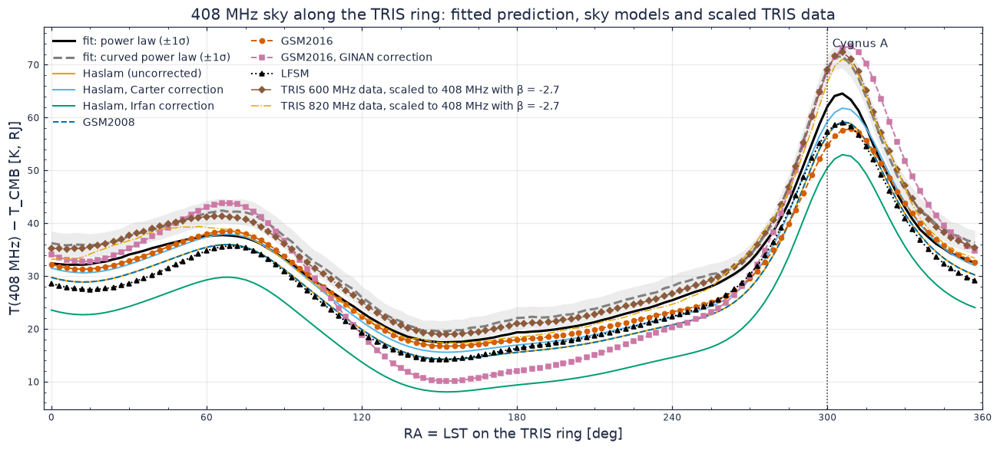

saved test_outputs/sky_models_408/fig1_T408_vs_ra.png


In [10]:
# Measured TRIS rings (CMB-removed RJ, with ring_sigma), as used in the fits; read from the fit cache.
TRIS_STYLE = {"TRIS_600": dict(fmt=".", mfc="white"), "TRIS_820": dict(fmt="x", mfc="0.6")}
tris = {k: (np.full(N_RING, np.nan), np.full(N_RING, np.nan)) for k in TRIS_STYLE}
tris_nu = {}
for u, r in fits[PL].items():
    keys = list(map(str, r["keys"]))
    for k in TRIS_STYLE:
        if k in keys:
            j = keys.index(k)
            tris_nu[k] = float(r["nu"][j])
            f = (408.0 / tris_nu[k]) ** TRIS_BETA          # scale to 408 MHz (errors scale the same)
            tris[k][0][u], tris[k][1][u] = r["t"][j] * f, r["s"][j] * f

fig, ax = plt.subplots(figsize=(12, 5.5))
for m in FITS:
    st = FIT_STYLE[m]
    ax.fill_between(RA, A_best[m] - A_sig[m], A_best[m] + A_sig[m], color=st["color"], alpha=0.15, lw=0)
    ax.plot(RA, A_best[m], color=st["color"], ls=st["ls"], lw=2, label=f"fit: {m} (±1σ)")
for n in SKY_NAMES:
    ax.plot(RA, T_SKY[n], lw=1.3, **SKY_STYLE[n], label=n)
for k, st in TRIS_STYLE.items():
    # ax.errorbar(RA, tris[k][0], yerr=tris[k][1], fmt=st["fmt"], ms=3.5, mfc=st["mfc"], mec="black",
    #             ecolor="black", elinewidth=0.8, capsize=0, zorder=5,
    #             label=f"TRIS {k.split('_')[1]} MHz data, scaled to 408 MHz with β = {TRIS_BETA:g}")
    ax.plot(RA, tris[k][0], ls='-.',
                    label=f"TRIS {k.split('_')[1]} MHz data, scaled to 408 MHz with β = {TRIS_BETA:g}")
ax.axvline(CYG_A_RA, color="0.2", ls=":", lw=1)
ax.text(CYG_A_RA + 2, 0.97, "Cygnus A", transform=ax.get_xaxis_transform(), va="top", fontsize=10)
ax.set_xlim(-3, 360); ax.set_xticks(np.arange(0, 361, 60))
ax.set_xlabel("RA = LST on the TRIS ring [deg]"); ax.set_ylabel("T(408 MHz) − T_CMB [K, RJ]")
ax.legend(ncol=2, fontsize=9, frameon=False, loc="upper left")
ax.grid(alpha=0.25)
ax.set_title("408 MHz sky along the TRIS ring: fitted prediction, sky models and scaled TRIS data")
fig.tight_layout()
save(fig, "fig1_T408_vs_ra")

#### Figure 2 — sky model minus fit, per ring sample
Each line is a plain subtraction, sky model minus fitted prediction, in kelvin. The grey band is the
fit's own 1σ, so a line inside it agrees with the fit at that sample.

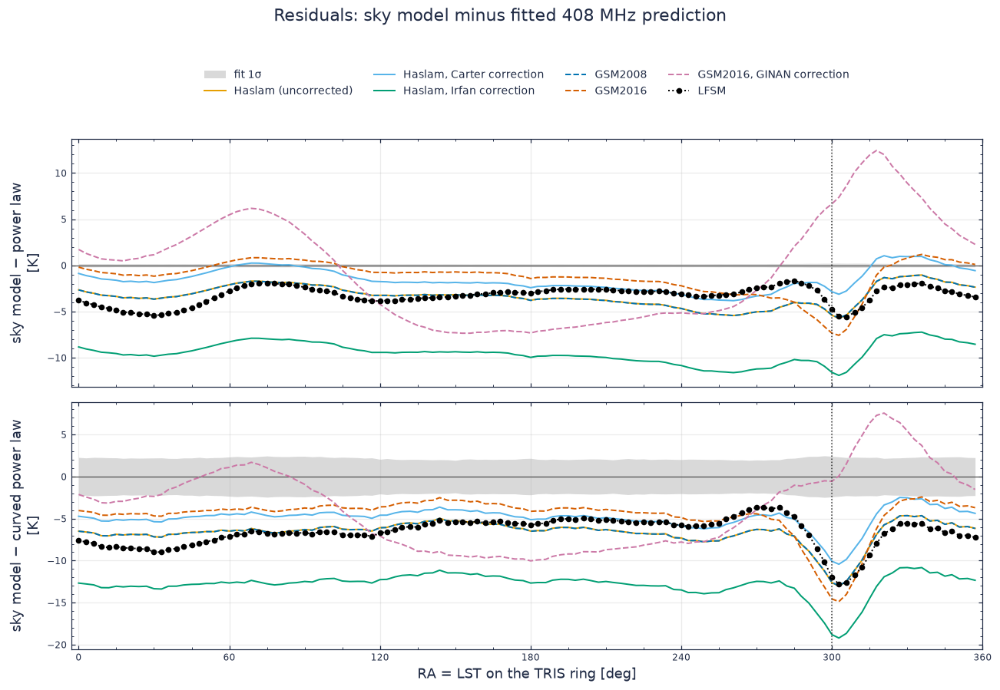

saved test_outputs/sky_models_408/fig2_residual_vs_ra.png


In [11]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, m in zip(axes, FITS):
    ax.fill_between(RA, -A_sig[m], A_sig[m], color="0.85", lw=0, label=f"fit 1σ")
    ax.axhline(0, color="0.3", lw=0.8)
    for n in SKY_NAMES:
        ax.plot(RA, T_SKY[n] - A_best[m], lw=1.3, **SKY_STYLE[n], label=n)
    ax.axvline(CYG_A_RA, color="0.2", ls=":", lw=1)
    ax.set_ylabel(f"sky model − {m}\n[K]")
    ax.grid(alpha=0.25)
axes[0].legend(ncol=4, fontsize=9, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.32))
axes[1].set_xlabel("RA = LST on the TRIS ring [deg]")
axes[1].set_xlim(-3, 360); axes[1].set_xticks(np.arange(0, 361, 60))
fig.suptitle("Residuals: sky model minus fitted 408 MHz prediction", y=1.02)
fig.tight_layout()
save(fig, "fig2_residual_vs_ra")

### 4. χ² for every pair, and the winner

χ² = Σ_k (T_model,k − A_fit,k)² / σ_A,k², over ring samples where both exist; σ_A is the posterior
standard deviation of the fit's 408 MHz temperature. The sky models carry no error of their own here.

In [12]:
rows = []
for m in FITS:
    for n in SKY_NAMES:
        r = T_SKY[n] - A_best[m]
        ok = np.isfinite(r) & np.isfinite(A_sig[m]) & (A_sig[m] > 0)
        chi2 = float(np.sum((r[ok] / A_sig[m][ok]) ** 2))
        rows.append({"fit": m, "sky model": n, "N samples": int(ok.sum()), "chi2": chi2,
                     "chi2 / N": chi2 / ok.sum(),
                     "mean of residual [K]": float(np.mean(r[ok])),
                     "median of residual [K]": float(np.median(r[ok])),
                     "std of residual [K]": float(np.std(r[ok])),
                     "samples within fit 1σ": int(np.sum(np.abs(r[ok]) <= A_sig[m][ok]))})
chi = pd.DataFrame(rows)
chi["rank (per fit)"] = chi.groupby("fit")["chi2"].rank().astype(int)
chi = chi.sort_values(["fit", "chi2"]).reset_index(drop=True)
chi.to_csv(OUT_DIR / "chi2_sky_models_vs_fits.csv", index=False)
print(f"saved {(OUT_DIR / 'chi2_sky_models_vs_fits.csv').relative_to(REPO)}  (best fit = {BEST_FIT})\n")
with pd.option_context("display.width", 200):
    print(chi.round(2).to_string(index=False))

winners = {m: chi[chi["fit"] == m].iloc[0]["sky model"] for m in FITS}
print()
for m in FITS:
    print(f"WINNER against the {m}: {winners[m]}")
if skipped:
    print("\n!! not included:", ", ".join(skipped))

saved test_outputs/sky_models_408/chi2_sky_models_vs_fits.csv  (best fit = maxlike)

             fit                 sky model  N samples      chi2  chi2 / N  mean of residual [K]  median of residual [K]  std of residual [K]  samples within fit 1σ  rank (per fit)
curved power law Haslam, Carter correction        120    650.89      5.42                 -4.92                   -4.73                 1.27                      0               1
curved power law                   GSM2016        120    652.50      5.44                 -4.63                   -4.03                 2.37                      0               2
curved power law GSM2016, GINAN correction        120   1008.26      8.40                 -3.71                   -3.01                 4.74                     40               3
curved power law                      LFSM        120   1131.83      9.43                 -6.57                   -6.23                 1.73                      0               4
curved power la

#### Figure 3 — χ² per sample for every pair
Bars show χ²/N, the mean squared residual in units of the fit's σ, for each sky model against each
fit. Shorter is better; the axis is logarithmic because the values span orders of magnitude.

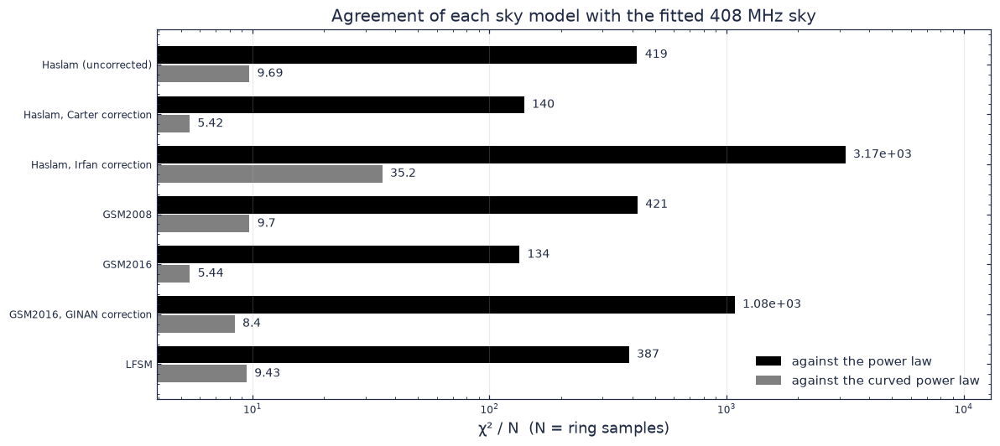

saved test_outputs/sky_models_408/fig3_chi2_per_sample.png


In [13]:
fig, ax = plt.subplots(figsize=(11, 5))
y = np.arange(len(SKY_NAMES))[::-1]
h = 0.38
for j, m in enumerate(FITS):
    sub = chi[chi["fit"] == m].set_index("sky model").loc[SKY_NAMES]
    ax.barh(y + (0.5 - j) * h, sub["chi2 / N"], h * 0.92, color=FIT_STYLE[m]["color"],
            label=f"against the {m}")
    for yi, v in zip(y + (0.5 - j) * h, sub["chi2 / N"]):
        ax.text(v * 1.08, yi, f"{v:.3g}", va="center", fontsize=9)
ax.set_xscale("log")
ax.set_yticks(y); ax.set_yticklabels(SKY_NAMES)
ax.set_xlabel("χ² / N  (N = ring samples)")
ax.legend(frameon=False, loc="lower right")
ax.grid(alpha=0.25, axis="x")
ax.set_xlim(right=ax.get_xlim()[1] * 3)
ax.set_title("Agreement of each sky model with the fitted 408 MHz sky")
fig.tight_layout()
save(fig, "fig3_chi2_per_sample")

### Summary

Results from the run on 2026-10-23: 120 ring samples, best fit = maximum-likelihood A, seed 12345.

* **Winner: GSM2016 and the Carter-corrected Haslam, effectively tied.** Against the power law, GSM2016
  is first (χ²/N 134.0) and Carter second (134.2). Against the curved power law, the order flips:
  Carter first (5.3), GSM2016 second (5.5). The gaps are tiny next to everything else, so no single
  winner can be named between these two.
* **GINAN-corrected GSM2016: right average level, wrong shape.** Its mean residual is the smallest of
  all against the power law (−0.35 K), but its scatter is the largest (std 5.6 K): it is about 6 K too
  bright around RA 70° and 12 K too bright near RA 320°, and about 7 K too faint between RA 130° and
  260°. The 1.53× scale exaggerates the contrast between bright and faint sky. It ranks 6th of 7
  against the power law (χ²/N 1059) and 3rd against the curved power law (8.3). The correction is
  only valid up to 350 MHz; here it is built at 350 MHz and carried to 408 MHz with GSM2016's own
  slope, which is an assumption.
* **Then a cluster, then Irfan.** Uncorrected Haslam, GSM2008 and LFSM sit together (power law χ²/N
  368–408, curved 9.4–9.6). GSM2008 is almost identical to Haslam at 408 MHz, as expected (it is built
  from it). The Irfan correction is last (power law 3108, curved 35). It subtracts the full 8.9 K
  monopole, which includes the radio background that the fitted surveys still contain.
* **Almost every sky model is colder than both fits.** Mean residual (model − fit): −0.4 to −9.4 K
  against the power law, −3.7 to −12.8 K against the curved power law. This is the same deficit the
  TOD route finds for Haslam.
* **χ² mixes the offset and the shape.** Apart from GINAN, the residual scatter (std) is 1.0–2.4 K and
  the mean offsets are larger, so the offset sets the ranking. The power law's σ_A is only 0.17 K, so
  its χ² values are very large; the curved power law's σ_A is 2.2 K, so its χ² values are small. The
  ranking, not the size of χ², is what matters.
* **Caveats.** GSM2008, GSM2016, LFSM (and so GINAN) all use Haslam as an input at 408 MHz, so they are
  not independent of it. The sky models carry no error bars in χ². The Carter and Irfan corrections are
  single whole-sky values, applied to the destriped Haslam map.


# Part C — Model comparison diagnostics

**Origin:** `notebooks/11_model_comparison_diagnostics.ipynb` (archived: `../moonrunes_archive_2026-11-16/notebooks/11_model_comparison_diagnostics.ipynb`)

| | |
|---|---|
| **Reads** | `paper_outputs/pipeline/step3_model_comparison/` (`evidence_per_unit_tod.csv`, `maxlike_per_unit_tod.csv`: pipeline step 3), `configs/model_comp_config.yaml`, `error_bars.csv`, `res/` |
| **Writes** | `paper_outputs/model_comparison/diagnostic_plots/` |
| **Feeds the paper** | Section 5 tie/borderline counts (main.tex:501) |

**Stored outputs** are from the original notebook (not re-run after the merge). **The results it reads are the 2026-10-29 run on four points without TRIS** (LWA1 35, Maipu 45, LWA1 80, Stockert); the paper describes the comparison on six points with TRIS.

**Pipeline:** the comparison it diagnoses is pipeline step 3: every allowed map, **TRIS excluded by design**, UltraNest evidence. The stored outputs read the 2026-10-29 `run_comparison.py` results (four points); step 3's products from the 2026-11-16 run have 11 points.

## Model comparison diagnostics

Diagnostics for the spectral-model comparison in `model_comparison/` (power law, curved power law, moment expansion
of order 2 and of order 3, per TRIS ring sample on the TOD route). Nothing here edits that module or reruns the full
comparison.

**What the comparison is decided on** is `comparison.statistic` in `configs/model_comp_config.yaml`, and this notebook
follows it:

* `max_likelihood`: each model's best fit, ln L_max = −χ²_min/2 + const.
  **No Occam penalty**, so a model is not penalised for its extra parameters. A model that contains another (the
  curved power law is the power law at C = 0) can never do worse than it. Read from
  `results/maxlike_per_unit_tod.csv`.
* `evidence`: UltraNest's ln Z, which includes the Occam penalty. Read from `results/evidence_per_unit_tod.csv`.

**Which data sets** go into every SED: the maps `sed.exclude_maps` (`configs/run_pipeline.yaml`) leaves in, plus TRIS
unless `comparison.exclude_tris` (2026-11-17; until then `data.datasets`, a list of `error_bars.csv` keys). Every rerun here builds its points with `run_comparison.select_datasets`, so it uses the same
data as the comparison.

* **Part 1** (always runs) reads the comparison's per-sample CSV for the chosen statistic and looks at the
  **per-sample** differences between models. No sums over samples: neighbouring ring samples are 3° apart under a
  ~20° beam, so they are strongly correlated and a sum would overstate the difference.
* **Parts 2–4 are evidence diagnostics** (UltraNest, Occam penalty included). With `statistic: max_likelihood` they
  are kept for reference: they show how the evidence would read the same data, and how big the Occam penalty is.
  * **Part 2** (`RUN_RERUNS`) reruns the four models for a few samples to get posteriors, best fits and maximum
    likelihoods.
  * **Part 3** (`RUN_PRIOR_SENSITIVITY`) reruns the curved power law with a narrower prior on the curvature C.
  * **Part 4** (`RUN_CONVERGENCE`) checks that UltraNest's ln Z has converged: against an exact grid integral, over
    seeds, live points and the stopping rule.
* **Part 5** (`RUN_ML_FITS`) fits every model at every ring sample (maximum likelihood, the same fitter as
  `run_comparison.max_likelihood`) and shows the fitted models at the TRIS frequencies against the TRIS rings, and the
  χ² of every fit. With `statistic: max_likelihood` it is checked against the comparison's own CSV.

Reruns use the same `model_comp_config.yaml`, priors, data sets, UltraNest settings, error table (`error_bars.csv`) and ring TODs
(`sed.tod_beam`) as `run_comparison.py`, and are cached in `paper_outputs/model_comparison/diagnostic_plots/cache/`, so a cached
sample is never rerun. Every figure is shown here and saved as a PNG in `paper_outputs/model_comparison/diagnostic_plots/`.

### Settings
All paths, sample numbers and flags. Switch a flag to `True` to run that part.

In [14]:
%matplotlib inline
import os
os.environ.setdefault("TQDM_DISABLE", "1")
import sys
import copy
import logging
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpecFromSubplotSpec

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MC_DIR = REPO / "model_comparison"
EV_CSV = REPO / "paper_outputs" / "pipeline" / "step3_model_comparison" / "evidence_per_unit_tod.csv"   # statistic: evidence
ML_CSV = REPO / "paper_outputs" / "pipeline" / "step3_model_comparison" / "maxlike_per_unit_tod.csv"     # statistic: max_likelihood
CONFIG_PATH = REPO / "configs" / "model_comp_config.yaml"
ERRORS_CSV = REPO / "configs" / "error_bars.csv"
PLOT_DIR = REPO / "paper_outputs" / "model_comparison" / "diagnostic_plots"
CACHE_DIR = PLOT_DIR / "cache"

# ---- flags ----
RUN_RERUNS = True               # Part 2: rerun the four models for RERUN_UNITS
RUN_PRIOR_SENSITIVITY = True    # Part 3: rerun the curved power law with narrower C priors
RUN_CONVERGENCE = True          # Part 4: convergence tests of the evidence (about 5 min, cached)
RUN_ML_FITS = True              # Part 5: maximum-likelihood fit of every model at every ring sample (cached)

# ---- samples (TOD-route unit = TRIS ring sample index; its RA is read from the CSV) ----
RERUN_UNITS = [0, 40, 75, 89, 100, 102]
SENS_UNITS = [0, 40, 75, 100, 102]
C_HALF_WIDTHS = [0.5, 0.2, 0.1]  # 0.5 is model_comp_config.yaml's prior; the others override it here
CONV_UNITS = [0, 89, 102]        # Part 4: a tie (0), a power-law win (89), a curved win at Cygnus (102)
CONV_SEEDS = [1, 2, 3, 4, 5]     # Part 4: repeat runs at the default settings
CONV_LIVE = [100, 1600]          # Part 4: live points tried besides model_comp_config.yaml's default (400)
CONV_STRICT_DLOGZ = 0.1          # Part 4: a stricter stopping rule than model_comp_config.yaml's 0.5
# Part 4: grid points per axis for the exact integral, by number of parameters (two per model, to show it
# has converged).  The 4-parameter order-3 model uses fewer points per axis: 81^4 would be 43 million points.
GRID_N = {2: [41, 81], 3: [41, 81], 4: [25, 41]}

# ---- what the comparison is decided on: model_comp_config.yaml comparison.statistic ----
with open(CONFIG_PATH) as f:
    cfg = yaml.safe_load(f)
STAT = (cfg.get("comparison") or {}).get("statistic", "evidence")
ML_STAT = STAT == "max_likelihood"
CSV_PATH = ML_CSV if ML_STAT else EV_CSV
ML_STARTS = int((cfg.get("comparison") or {}).get("ml_starts", 24))   # Part 5: as run_comparison.max_likelihood
SC = "lnL_max" if ML_STAT else "lnZ"          # the per-model score
DSC = "Δ" + SC                                # a difference of scores
FIGTAG = "dlnLmax" if ML_STAT else "dlogZ"    # Part 1 figure file names
TIE = 1.0                        # |Δ| < 1: indistinguishable (for lnL_max: |Δχ²| < 2)
STRONG = 2.0                     # |Δ| > 2: strong (for lnL_max: |Δχ²| > 4)
CYG_A_RA = 299.9                 # deg
N_CURVE_SAMPLES = 1000           # posterior draws used for the model bands

PL, CURVED = "power law", "curved power law"
MOMENT, MOMENT3 = "moment expansion (order 2)", "moment expansion (order 3)"
ALL4 = (PL, CURVED, MOMENT, MOMENT3)
SHORT = {PL: "power law", CURVED: "curved PL", MOMENT: "moment (2nd order)", MOMENT3: "moment (3rd order)"}
# Okabe-Ito, colourblind-safe
COL = {PL: "#0072B2", CURVED: "#D55E00", MOMENT: "#009E73", MOMENT3: "#CC79A7"}
UNIT_COLS = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"]
# 5-class diverging (PuOr, colourblind-safe), grey midpoint
CLASS_COLS = ["#542788", "#998ec3", "#d9d9d9", "#f1a340", "#b35806"]
POINT_NAMES = {"TRIS_600": "TRIS 600", "TRIS_820": "TRIS 820", "LWA_35MHz.fits": "LWA 35",
               "MAIPU_45mhZ.fits": "Maipu 45", "LWA_80MHz.fits": "LWA 80",
               "CHIPASS_1400MHz.fits": "CHIPASS 1400", "STOCKERT_VILLA_1400MHZ.fits": "Stockert 1420",
               "RHODES_HARTRAO_2326MHz.fits": "Rhodes 2326", "ARCADE2_315.fits": "ARCADE2 3150",
               "ARCADE2_341.fits": "ARCADE2 3410"}

plt.rcParams.update({"axes.grid": False, "figure.dpi": 110, "font.size": 12, "axes.titlesize": 13,
                     "axes.labelsize": 12, "legend.fontsize": 10, "figure.facecolor": "white"})
PLOT_DIR.mkdir(exist_ok=True)

def save(fig, name):
    """Save a figure as PNG in PLOT_DIR, then show it inline."""
    fig.savefig(PLOT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"saved {(PLOT_DIR / f'{name}.png').relative_to(REPO)}")

## Part 1 — per-sample model comparison from the saved CSV

The score per model is `SC`: **ln L_max** (best fit, no Occam penalty; Δ = −Δχ²/2) with `statistic: max_likelihood`,
or **ln Z** (evidence, with its sampling error) with `statistic: evidence`. The same ±1 / ±2 bands are used for
"indistinguishable" and "strong"; for ln L_max they are Δχ² = 2 and 4.

In [15]:
P1 = CSV_PATH.exists()
# Ring samples and their RA are a property of the ring, not of the run: take them from whichever CSV exists.
_ra_src = CSV_PATH if P1 else next((p for p in (ML_CSV, EV_CSV) if p.exists()), None)
if _ra_src is None:
    raise FileNotFoundError("no comparison CSV in model_comparison/results/: run model_comparison/run_comparison.py")
_units = pd.read_csv(_ra_src).sort_values("ra_deg").reset_index(drop=True)
RA_OF = dict(zip(_units["unit"], _units["ra_deg"]))
ALL_UNITS_RING = sorted(int(u) for u in _units["unit"])

if not P1:
    print(f"PART 1 SKIPPED: {CSV_PATH.relative_to(REPO)} does not exist (comparison.statistic = {STAT}).\n"
          "Run model_comparison/run_comparison.py first.")
else:
    ev = pd.read_csv(CSV_PATH).sort_values("ra_deg").reset_index(drop=True)
    lz = {m: ev[("lnLmax " if ML_STAT else "logZ ") + m].to_numpy() for m in ALL4}
    # ln L_max has no sampling error; ln Z carries UltraNest's
    lze = {m: np.zeros(len(ev)) if ML_STAT else ev[f"logZerr {m}"].to_numpy() for m in ALL4}
    ra = ev["ra_deg"].to_numpy()

    def diff(a, b):
        return lz[a] - lz[b], np.hypot(lze[a], lze[b])

    dC, dC_err = diff(CURVED, PL)       # curved - power law
    dM, dM_err = diff(MOMENT, PL)       # moment - power law
    dM3, dM3_err = diff(MOMENT3, PL)    # moment (order 3) - power law
    dMC, dMC_err = diff(MOMENT, CURVED) # moment - curved
    dM32, dM32_err = diff(MOMENT3, MOMENT)  # moment order 3 - order 2

    print(f"comparison.statistic = {STAT}: score {SC}" + ("  (no Occam penalty)" if ML_STAT else "  (Occam penalty included)"))
    print(f"{CSV_PATH.relative_to(REPO)}: {len(ev)} ring samples, RA {ra.min():.0f}-{ra.max():.0f} deg")
    print(f"points per sample: {sorted(ev['n_points'].unique())}")
    print("inputs:", sorted(ev["inputs"].unique()))
    if ML_STAT:
        print("median χ² per sample: " + ", ".join(f"{SHORT[m]} {np.median(ev[f'chi2 {m}']):.2f}" for m in ALL4))
    else:
        print(f"ln Z error per sample (median): " + ", ".join(f"{SHORT[m]} {np.median(lze[m]):.2f}" for m in lz))
        print(f"error on a difference (median): dC {np.median(dC_err):.2f}, dM {np.median(dM_err):.2f}, dM3 {np.median(dM3_err):.2f}")

comparison.statistic = evidence: score lnZ  (Occam penalty included)
paper_outputs/pipeline/step3_model_comparison/evidence_per_unit_tod.csv: 120 ring samples, RA 0-357 deg
points per sample: [np.int64(11)]
inputs: ['LWA_35MHz.fits;LWA1_38.fits;LWA1_40.fits;LWA1_45.fits;MAIPU_45mhZ.fits;LWA1_50.fits;LWA1_60.fits;LWA1_70.fits;LWA1_74.fits;LWA_80MHz.fits;STOCKERT_VILLA_1400MHZ.fits']
ln Z error per sample (median): power law 0.19, curved PL 0.20, moment (2nd order) 0.20, moment (3rd order) 0.20
error on a difference (median): dC 0.28, dM 0.28, dM3 0.28


#### Figure 1 — score difference along the ring
One panel per extra-parameter model (curved power law, moment expansion of order 2 and of order 3). Each point is one
TRIS ring sample: above zero the extra-parameter model scores higher than the power law, below zero the power law
does. With ln L_max (no Occam penalty) the curved power law can never be below zero, because it contains the power
law. The grey band (|Δ| < 1) means the two cannot be told apart, the faint lines at ±2 mark a strong preference, and
the dotted line is Cygnus A. Error bars only for ln Z (sampling error).

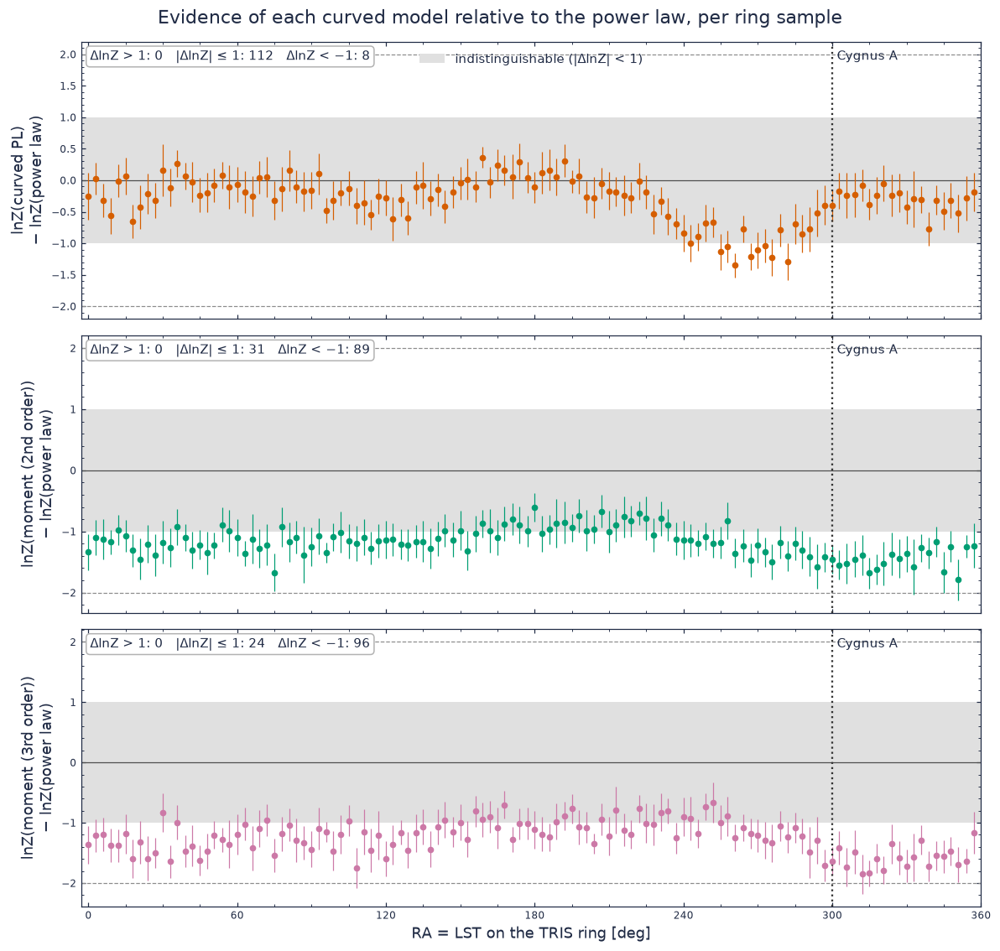

saved paper_outputs/model_comparison/diagnostic_plots/fig1_dlogZ_vs_ra.png


In [16]:
def counts3(d):
    return int((d > TIE).sum()), int((np.abs(d) <= TIE).sum()), int((d < -TIE).sum())

def yerr_of(e):
    return None if ML_STAT else e

if not P1:
    print("Figure 1 skipped: no comparison CSV.")
else:
    fig, axes = plt.subplots(3, 1, figsize=(11, 10.5), sharex=True)
    for ax, d, e, m in zip(axes, (dC, dM, dM3), (dC_err, dM_err, dM3_err), (CURVED, MOMENT, MOMENT3)):
        ax.axhspan(-TIE, TIE, color="0.88", lw=0, label=f"indistinguishable (|{DSC}| < 1)")
        for y in (-STRONG, STRONG):
            ax.axhline(y, color="0.55", lw=0.8, ls="--")
        ax.axhline(0, color="0.3", lw=0.8)
        ax.errorbar(ra, d, yerr=yerr_of(e), fmt="o", ms=4, color=COL[m], ecolor=COL[m], elinewidth=0.8, capsize=0)
        ax.axvline(CYG_A_RA, color="0.2", ls=":", lw=1.5)
        ax.text(CYG_A_RA + 2, 0.97, "Cygnus A", transform=ax.get_xaxis_transform(), va="top", fontsize=10)
        up, tie, down = counts3(d)
        ax.text(0.01, 0.97, f"{DSC} > 1: {up}   |{DSC}| ≤ 1: {tie}   {DSC} < −1: {down}",
                transform=ax.transAxes, va="top", fontsize=10,
                bbox=dict(fc="white", ec="0.7", boxstyle="round,pad=0.3"))
        ax.set_ylabel(f"{SC}({SHORT[m]})\n− {SC}(power law)")
    axes[0].legend(loc="upper center", frameon=False)
    axes[-1].set_xlabel("RA = LST on the TRIS ring [deg]")
    axes[-1].set_xlim(-3, 360); axes[-1].set_xticks(np.arange(0, 361, 60))
    fig.suptitle(("Best-fit log-likelihood (no Occam penalty)" if ML_STAT else "Evidence")
                 + " of each curved model relative to the power law, per ring sample")
    fig.tight_layout()
    save(fig, f"fig1_{FIGTAG}_vs_ra")

#### Figure 2 — absolute score along the ring
The four models' score (ln L_max or ln Z) for every ring sample on one axis. The overall level follows how well the
data constrain each sample (mostly the error-bar normalisation), so read the gaps between the lines, not their height.

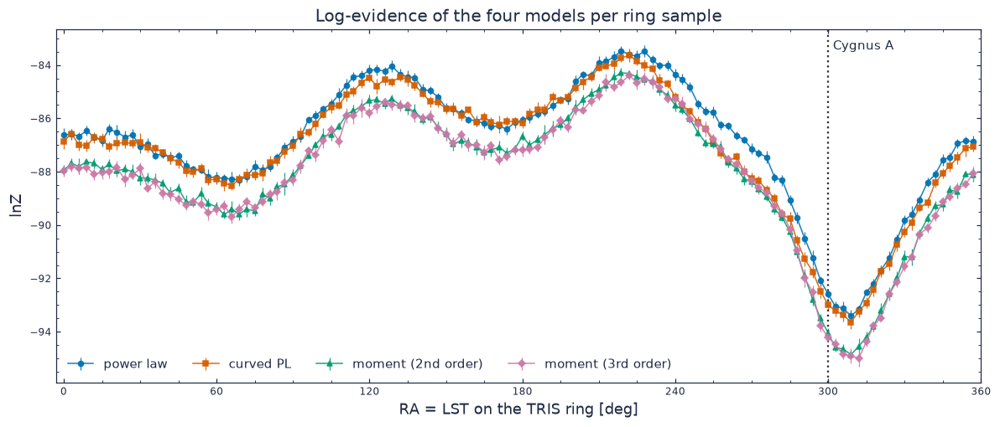

saved paper_outputs/model_comparison/diagnostic_plots/fig2_logZ_vs_ra.png


In [17]:
if not P1:
    print("Figure 2 skipped: no comparison CSV.")
else:
    fig, ax = plt.subplots(figsize=(11, 4.8))
    for m, mk in zip(ALL4, ("o", "s", "^", "D")):
        ax.errorbar(ra, lz[m], yerr=yerr_of(lze[m]), fmt=mk + "-", ms=4, lw=1, color=COL[m], label=SHORT[m],
                    elinewidth=0.8, alpha=0.9)
    ax.axvline(CYG_A_RA, color="0.2", ls=":", lw=1.5)
    ax.text(CYG_A_RA + 2, 0.97, "Cygnus A", transform=ax.get_xaxis_transform(), va="top", fontsize=10)
    ax.set_xlabel("RA = LST on the TRIS ring [deg]"); ax.set_ylabel(SC)
    ax.set_xlim(-3, 360); ax.set_xticks(np.arange(0, 361, 60))
    ax.legend(frameon=False, ncol=4, loc="lower left")
    ax.set_title(("Best-fit log-likelihood" if ML_STAT else "Log-evidence") + " of the four models per ring sample")
    fig.tight_layout()
    save(fig, "fig2_lnLmax_vs_ra" if ML_STAT else "fig2_logZ_vs_ra")

#### Figure 3 — distribution of the score differences
Histograms of Δ over the 120 ring samples, for the curved power law and the moment expansion (orders 2 and 3) against
the power law. The grey band is the indistinguishable range, the solid line is zero and the dashed line the median.

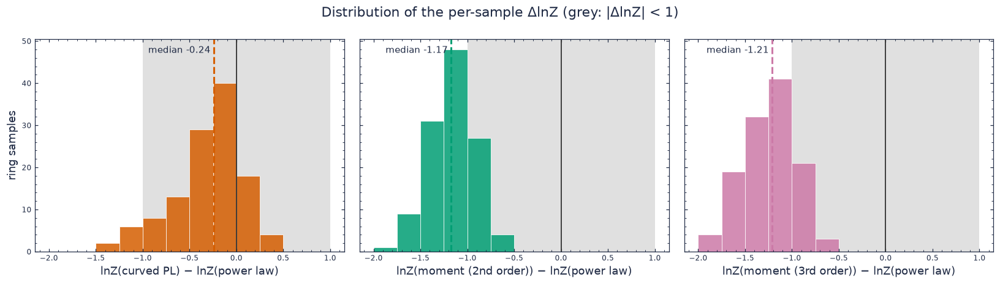

saved paper_outputs/model_comparison/diagnostic_plots/fig3_dlogZ_histograms.png


In [18]:
if not P1:
    print("Figure 3 skipped: no comparison CSV.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
    lo = np.floor(min(dC.min(), dM.min(), dM3.min())); hi = np.ceil(max(dC.max(), dM.max(), dM3.max()))
    bins = np.arange(lo, hi + 0.25, 0.25)
    for ax, d, m in zip(axes, (dC, dM, dM3), (CURVED, MOMENT, MOMENT3)):
        ax.axvspan(-TIE, TIE, color="0.88", lw=0)
        ax.hist(d, bins=bins, color=COL[m], alpha=0.85, edgecolor="white", linewidth=0.6)
        ax.axvline(0, color="0.2", lw=1.2)
        med = np.median(d)
        ax.axvline(med, color=COL[m], lw=2, ls="--")
        ax.text(med, 0.97, f" median {med:+.2f} ", transform=ax.get_xaxis_transform(), va="top",
                ha="right" if med < 0 else "left", fontsize=10)
        ax.set_xlabel(f"{SC}({SHORT[m]}) − {SC}(power law)")
    axes[0].set_ylabel("ring samples")
    fig.suptitle(f"Distribution of the per-sample {DSC} (grey: |{DSC}| < 1)")
    fig.tight_layout()
    save(fig, f"fig3_{FIGTAG}_histograms")

#### Figure 4 — how often each model is preferred
For each pair (A vs B) the bar splits the 120 ring samples by Δ = score(A) − score(B): purple means A is favoured,
orange that B is, and grey that they cannot be told apart. Read the bar's colour balance; the numbers are sample
counts.

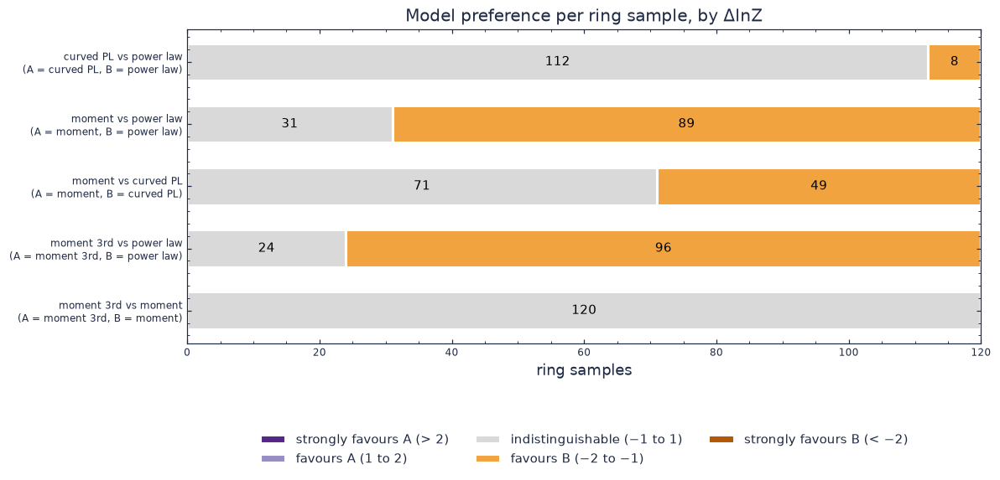

saved paper_outputs/model_comparison/diagnostic_plots/fig4_preference_counts.png
                         strongly favours A (> 2)  favours A (1 to 2)  indistinguishable (−1 to 1)  favours B (−2 to −1)  strongly favours B (< −2)
curved PL vs power law                          0                   0                          112                     8                          0
moment vs power law                             0                   0                           31                    89                          0
moment vs curved PL                             0                   0                           71                    49                          0
moment 3rd vs power law                         0                   0                           24                    96                          0
moment 3rd vs moment                            0                   0                          120                     0                          0


In [19]:
if not P1:
    print("Figure 4 skipped: no comparison CSV.")
else:
    CLASSES = [("strongly favours A (> 2)", lambda d: d > STRONG),
               ("favours A (1 to 2)", lambda d: (d > TIE) & (d <= STRONG)),
               ("indistinguishable (−1 to 1)", lambda d: np.abs(d) <= TIE),
               ("favours B (−2 to −1)", lambda d: (d < -TIE) & (d >= -STRONG)),
               ("strongly favours B (< −2)", lambda d: d < -STRONG)]
    PAIRS = [("curved PL vs power law", dC), ("moment vs power law", dM), ("moment vs curved PL", dMC),
             ("moment 3rd vs power law", dM3), ("moment 3rd vs moment", dM32)]   # "moment" = 2nd order
    table = pd.DataFrame({lab: [int(f(d).sum()) for _, d in PAIRS] for lab, f in CLASSES},
                         index=[p for p, _ in PAIRS])
    assert (table.sum(axis=1) == len(ev)).all()

    fig, ax = plt.subplots(figsize=(11, 5.6))
    y = np.arange(len(PAIRS))[::-1]
    left = np.zeros(len(PAIRS))
    for (lab, _), c in zip(CLASSES, CLASS_COLS):
        w = table[lab].to_numpy()
        ax.barh(y, w, left=left, color=c, edgecolor="white", linewidth=2, height=0.6, label=lab)
        for yi, li, wi in zip(y, left, w):
            if wi >= 4:
                ax.text(li + wi / 2, yi, str(wi), ha="center", va="center", fontsize=10,
                        color="white" if c in (CLASS_COLS[0], CLASS_COLS[4]) else "black")
        left += w
    ax.set_yticks(y); ax.set_yticklabels([f"{p}\n(A = {p.split(' vs ')[0]}, B = {p.split(' vs ')[1]})" for p, _ in PAIRS])
    ax.set_xlim(0, len(ev)); ax.set_xlabel("ring samples")
    ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False)
    ax.set_title(f"Model preference per ring sample, by {DSC}")
    fig.tight_layout()
    save(fig, "fig4_preference_counts" if not ML_STAT else "fig4_preference_counts_lnLmax")
    print(table.to_string())

## Part 2 — posteriors, best fits and maximum likelihood (reruns)

**Parts 2–4 are evidence diagnostics** (UltraNest, Occam penalty included). With `comparison.statistic:
max_likelihood` they do not decide anything; they show how the evidence would read the same data. Figure 6 in
particular splits each ΔlnZ into the gain in fit (ΔlnL_max) and the Occam penalty.

**What the evidence run saves.** With `statistic: evidence`, `run_comparison.py` writes per sample only the sample
index, RA, number of points, the inputs used, and ln Z ± error for each model: no best-fit parameters, no maximum
log-likelihood and no posterior samples (`sampler.log_dir` is `null`). The next cell checks this, and then (only if
`RUN_RERUNS = True`) reruns the four models for `RERUN_UNITS` and caches each result.

In [20]:
with open(CONFIG_PATH) as f:
    cfg = yaml.safe_load(f)
EV = pd.read_csv(EV_CSV) if EV_CSV.exists() else None   # the latest evidence run, if any (may be older than the ML run)
log_dir = cfg["sampler"].get("log_dir")
sample_files = (sorted(Path(log_dir).rglob("equal_weighted_post.txt")) if log_dir and Path(log_dir).exists() else [])
if EV is not None:
    saved_cols = list(EV.columns)
    extra = [c for c in saved_cols if not c.startswith(("logZ ", "logZerr "))]
    print(f"{EV_CSV.relative_to(REPO)}: columns saved per sample:", ", ".join(extra), "+ logZ and logZerr per model")
    print("best-fit parameters saved:   ", any("best" in c or "beta" in c for c in saved_cols))
    print("max log-likelihood saved:    ", any("logl" in c.lower() or "maxl" in c.lower() for c in saved_cols))
else:
    print("no evidence CSV (comparison.statistic has not been 'evidence' yet)")
print(f"posterior samples on disk:    {bool(sample_files)}  (sampler.log_dir = {log_dir!r})")
POSTERIORS_SAVED = bool(sample_files)
if POSTERIORS_SAVED:
    print("Posterior files found: NOTE run_comparison reuses one log_dir for every sample and model, "
          "so only the last run's files survive. Not used here.")

paper_outputs/pipeline/step3_model_comparison/evidence_per_unit_tod.csv: columns saved per sample: unit, ra_deg, n_points, inputs + logZ and logZerr per model
best-fit parameters saved:    False
max log-likelihood saved:     False
posterior samples on disk:    False  (sampler.log_dir = None)


In [21]:
sys.dont_write_bytecode = True                   # leave no __pycache__ in model_comparison/
sys.path.insert(0, str(REPO / "src"))
sys.path.insert(0, str(MC_DIR))
# Drop repo modules a long-running kernel loaded earlier, so the imports below read the current files
# (otherwise e.g. sed_prototype.tod_method_key, added on 2026-10-27, is missing until a kernel restart).
for _name in [n for n in sys.modules if n.split(".")[0] in ("moonrunes", "models", "run_comparison")]:
    del sys.modules[_name]
from models import build_models, prior_transform
import run_comparison as rc                      # imported for its data helpers; main() is not run
from moonrunes.config import load_config
from moonrunes.sed_prototype import tod_method_key
import hashlib, json
# The data sets, exactly as pipeline step 3 and run_comparison choose them: the maps run_pipeline.yaml sed.exclude_maps
# leaves in, plus TRIS unless model_comp_config.yaml comparison.exclude_tris.
_RUN_CFG, TRIS_SEL, MAPS_SEL = rc.select_datasets(None, load_config(REPO / "configs" / "run_pipeline.yaml"), REPO / "res",
                                                  exclude_tris=bool(cfg["comparison"]["exclude_tris"]))
DATASETS = [rc.tris_key(f) for f in TRIS_SEL] + MAPS_SEL
print("data sets:", ", ".join(POINT_NAMES.get(k, k) for k in DATASETS),
      "(run_pipeline.yaml sed.exclude_maps; TRIS {})".format("excluded" if cfg["comparison"]["exclude_tris"] else "included"))
# What the cached results were made from: the ring TODs (run_pipeline.yaml sed.tod_beam), the data sets, the error bars
# (error_bars.csv) and the target map.  Cached results made from anything else are redone.
# (The cache key holds the chosen data sets.)
TOD_KEY = json.dumps({"tod": tod_method_key(_RUN_CFG), "datasets": DATASETS,
                      "error_bars": hashlib.md5(ERRORS_CSV.read_bytes()).hexdigest(),
                      "target": _RUN_CFG.require("pipeline.target_file")}, sort_keys=True)

ALL_MODELS = build_models(cfg)
# The four models diagnosed here; model_comp_config.yaml's models.moment_orders must include both 2 and 3.
assert set(ALL4) <= set(ALL_MODELS), list(ALL_MODELS)
MODELS = {m: ALL_MODELS[m] for m in ALL4}
SCFG = cfg["sampler"]
# Moment expansion: beta fixed at model_comp_config.yaml's models.moment_beta_fixed (omega1 free), or free if null.
BETA_FIX = cfg["models"].get("moment_beta_fixed")
TAG = {PL: "base", CURVED: "base"} | {m: "base" if BETA_FIX is None else f"beta{float(BETA_FIX):g}" for m in (MOMENT, MOMENT3)}
print("moment expansion:", "beta free, omega1 = 0" if BETA_FIX is None else f"beta fixed at {float(BETA_FIX):g}, omega1 free")
assert cfg["priors"]["C"]["type"] == "uniform" and -cfg["priors"]["C"]["low"] == cfg["priors"]["C"]["high"] == 0.5

def slug(s):
    return "".join(ch if ch.isalnum() else "_" for ch in s).strip("_")

def cache_path(unit, model, tag):
    return CACHE_DIR / f"unit{unit:03d}__{slug(model)}__{tag}.npz"

_INP = None
def get_inputs():
    """The TOD-route inputs (built once, takes a few minutes)."""
    global _INP
    if _INP is None:
        from moonrunes.config import load_config
        from moonrunes.sed_prototype import Inputs
        print("building the TOD-route inputs (takes a few minutes)...")
        _INP = Inputs(_RUN_CFG, REPO / "res", target_file=_RUN_CFG.require("pipeline.target_file"), verbose=False)
    return _INP

_POINTS = {}
def unit_points(units):
    """(nu, t, s, keys) per unit, built exactly as run_comparison does (TOD route, the chosen data sets)."""
    need = [u for u in units if u not in _POINTS]
    if need:
        errors = rc.read_error_bars(ERRORS_CSV)
        inp = get_inputs()
        for uid, _, pts in rc.tod_units(inp, errors, TRIS_SEL):
            if uid in need:
                pts = rc.usable(pts)
                _POINTS[uid] = (np.array([q[1] for q in pts]), np.array([q[2] for q in pts]),
                                np.array([q[3] for q in pts]), [q[0] for q in pts])
    return {u: _POINTS[u] for u in units}

def run_nested(model, priors, nu, t, s):
    """The same likelihood and UltraNest call as rc.log_evidence, keeping the posterior."""
    import ultranest
    names, fn = MODELS[model]
    transform = prior_transform(names, priors)
    norm = -np.sum(np.log(s * np.sqrt(2 * np.pi)))
    def loglike(params):
        r = (t - fn(nu, params)) / s
        return -0.5 * np.sum(r * r, axis=-1) + norm
    sampler = ultranest.ReactiveNestedSampler(names, loglike, transform, vectorized=True,
                                              log_dir=SCFG.get("log_dir"))
    logging.getLogger("ultranest").setLevel(logging.WARNING)
    res = sampler.run(min_num_live_points=int(SCFG["min_num_live_points"]), dlogz=float(SCFG["dlogz"]),
                      show_status=False, viz_callback=False)
    return dict(logz=res["logz"], logzerr=res["logzerr"], samples=res["samples"],
                maxlogl=res["maximum_likelihood"]["logl"], maxpoint=np.asarray(res["maximum_likelihood"]["point"]),
                names=np.array(names))

def get_results(units, model, tag, priors, allow_run):
    """{unit: result} from the cache; missing ones are run only if allow_run."""
    out, missing = {}, []
    for u in units:
        p = cache_path(u, model, tag)
        z = np.load(p, allow_pickle=False) if p.exists() else None
        if z is not None and "tod_key" in z.files and str(z["tod_key"]) == TOD_KEY:   # from the current TODs
            out[u] = {k: z[k] for k in z.files}
        else:
            missing.append(u)
    if missing and allow_run:
        CACHE_DIR.mkdir(parents=True, exist_ok=True)
        logging.getLogger("ultranest").setLevel(logging.WARNING)
        for u, (nu, t, s, keys) in unit_points(missing).items():
            r = run_nested(model, priors, nu, t, s)
            r.update(nu=nu, t=t, s=s, keys=np.array(keys), unit=u, tag=tag, tod_key=TOD_KEY)
            np.savez(cache_path(u, model, tag), **r)
            out[u] = r
            print(f"  ran unit {u:3d}, {SHORT[model]:<20} [{tag}]  lnZ = {r['logz']:.2f} ± {r['logzerr']:.2f}")
    return out

HASLAM_CACHE = CACHE_DIR / "haslam_tod.npz"
def haslam_points(allow_run):
    """Haslam (the target map, NOT a fit point) through the TRIS beam, per ring sample, for plotting only."""
    z = np.load(HASLAM_CACHE, allow_pickle=False) if HASLAM_CACHE.exists() else None
    if z is not None and "tod_key" in z.files and str(z["tod_key"]) == TOD_KEY:   # from the current TODs
        return {k: z[k] for k in z.files}
    if not allow_run:
        return None
    from moonrunes.sky_maps import rj_excess
    from moonrunes.sed_prototype import sigma_for
    inp = get_inputs(); m = inp.target; d = inp.tods[m["name"]]
    t = np.array([float(rj_excess(v, m)) for v in d["tod"]])
    out = dict(nu=float(m["freq_mhz"]), t=t, s=np.asarray(sigma_for(m, t), dtype=float),
               good=np.asarray(d["good"], dtype=bool), map_file=str(m["file"]), tod_key=TOD_KEY)   # not "file": that is np.savez's own argument
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    np.savez(HASLAM_CACHE, **out)
    return out

P2 = {m: get_results(RERUN_UNITS, m, TAG[m], cfg["priors"], RUN_RERUNS) for m in MODELS}
HAS = haslam_points(RUN_RERUNS)
P2_UNITS = [u for u in RERUN_UNITS if all(u in P2[m] for m in MODELS)]
if not P2_UNITS:
    print("PART 2 SKIPPED: no cached reruns found and RUN_RERUNS = False. "
          "Set RUN_RERUNS = True in the settings cell to rerun units", RERUN_UNITS)
else:
    print(f"Part 2 results available for units {P2_UNITS}"
          + ("" if len(P2_UNITS) == len(RERUN_UNITS) else f" (missing: {sorted(set(RERUN_UNITS) - set(P2_UNITS))})"))
    same = []
    if EV is not None:
        _ev = EV.set_index("unit")
        same = [u for u in P2_UNITS if u in _ev.index and _ev.loc[u, "inputs"] == ";".join(str(k) for k in P2[PL][u]["keys"])]
    if same:
        print("\nrerun lnZ against the evidence CSV, where it used the same points "
              "(UltraNest is not seeded, so expect agreement within the errors):")
        for u in same:
            print(f"  unit {u:3d}: " + "   ".join(
                f"{SHORT[m]} {float(P2[m][u]['logz']):+.2f} vs {_ev.loc[u, f'logZ {m}']:+.2f}" for m in MODELS))
    else:
        print("no evidence CSV made from the same points to compare the reruns with")

data sets: LWA 35, LWA1_38.fits, LWA1_40.fits, LWA1_45.fits, Maipu 45, LWA1_50.fits, LWA1_60.fits, LWA1_70.fits, LWA1_74.fits, LWA 80, CHIPASS 1400, Stockert 1420, Rhodes 2326 (run_pipeline.yaml sed.exclude_maps; TRIS excluded)
moment expansion: beta fixed at -2.7, omega1 free
building the TOD-route inputs (takes a few minutes)...
  ran unit   0, power law            [base]  lnZ = -86.62 ± 0.25
  ran unit  40, power law            [base]  lnZ = -84.08 ± 0.23
  ran unit  75, power law            [base]  lnZ = -83.62 ± 0.17
  ran unit  89, power law            [base]  lnZ = -87.06 ± 0.14
  ran unit 100, power law            [base]  lnZ = -92.36 ± 0.18
  ran unit 102, power law            [base]  lnZ = -93.31 ± 0.21
  ran unit   0, curved PL            [base]  lnZ = -86.96 ± 0.22
  ran unit  40, curved PL            [base]  lnZ = -84.49 ± 0.25
  ran unit  75, curved PL            [base]  lnZ = -84.07 ± 0.19
  ran unit  89, curved PL            [base]  lnZ = -88.07 ± 0.20
  ran unit 100, c

#### Figure 5 — data and fitted models for the rerun samples
Each panel is one ring sample: the SED points (the chosen data sets) (CMB-free Rayleigh–Jeans temperature) with their
error bars, and each model's posterior median with its 68% band (none for the curved power law), for all four models.
Haslam 408 MHz (open diamond) is plotted for comparison only and is not used in any fit. The small panel below shows the
residuals, data minus model in units of σ, for the power law and the curved power law.

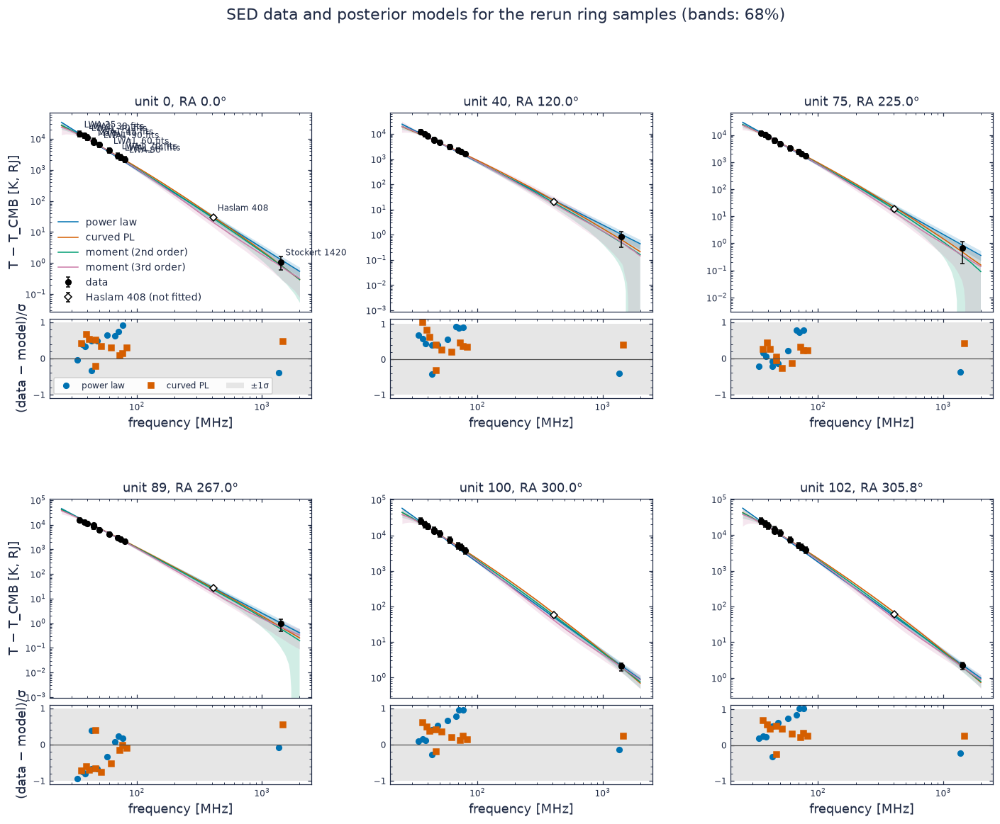

saved paper_outputs/model_comparison/diagnostic_plots/fig5_sed_fits_per_unit.png


In [22]:
def model_band(model, samples, nu):
    names, fn = MODELS[model]
    rng = np.random.default_rng(0)
    sel = samples if len(samples) <= N_CURVE_SAMPLES else samples[rng.choice(len(samples), N_CURVE_SAMPLES, replace=False)]
    curves = fn(nu, sel)
    return np.percentile(curves, [16, 50, 84], axis=0)

if not P2_UNITS:
    print("Figure 5 skipped: no Part 2 results (set RUN_RERUNS = True).")
else:
    ncol = 3; nrow = int(np.ceil(len(P2_UNITS) / ncol))
    fig = plt.figure(figsize=(5.2 * ncol, 5.6 * nrow))
    outer = fig.add_gridspec(nrow, ncol, hspace=0.35, wspace=0.3)
    grid = np.geomspace(25, 2000, 200)
    for i, u in enumerate(P2_UNITS):
        g = GridSpecFromSubplotSpec(2, 1, subplot_spec=outer[i // ncol, i % ncol], height_ratios=[3, 1.2], hspace=0.05)
        ax = fig.add_subplot(g[0]); axr = fig.add_subplot(g[1], sharex=ax)
        r0 = P2[PL][u]; nu, t, s, keys = r0["nu"], r0["t"], r0["s"], [str(k) for k in r0["keys"]]
        for m in MODELS:
            lo_, med_, hi_ = model_band(m, P2[m][u]["samples"], grid)
            if m != CURVED:   # no band for the curved power law
                ax.fill_between(grid, lo_, hi_, color=COL[m], alpha=0.18, lw=0)
            ax.plot(grid, med_, color=COL[m], lw=1.0, label=SHORT[m])
        ax.errorbar(nu, t, yerr=s, fmt="o", color="black", ms=5, capsize=2, zorder=5, label="data")
        if HAS is not None and bool(HAS["good"][u]):   # plotted only, not in any fit
            hn, ht, hs = float(HAS["nu"]), float(HAS["t"][u]), float(HAS["s"][u])
            ax.errorbar(hn, ht, yerr=hs, fmt="D", ms=5, mfc="white", mec="black", ecolor="black",
                        capsize=2, zorder=6, label="Haslam 408 (not fitted)")
            if i == 0:
                ax.annotate("Haslam 408", (hn, ht), xytext=(4, 6), textcoords="offset points", fontsize=8)
        if i == 0:
            for n_, t_, k_ in zip(nu, t, keys):
                ax.annotate(POINT_NAMES.get(k_, k_), (n_, t_), xytext=(4, 6), textcoords="offset points", fontsize=8)
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_title(f"unit {u}, RA {RA_OF[u]:.1f}°", fontsize=12)
        ax.tick_params(labelbottom=False)
        if i % ncol == 0:
            ax.set_ylabel("T − T_CMB [K, RJ]")
        for m, off, mk in ((PL, 0.96, "o"), (CURVED, 1.04, "s")):
            _, med_at, _ = model_band(m, P2[m][u]["samples"], nu)
            axr.plot(nu * off, (t - med_at) / s, mk, color=COL[m], ms=5, label=SHORT[m])
        axr.axhspan(-1, 1, color="0.9", lw=0, label="±1σ"); axr.axhline(0, color="0.3", lw=0.8)
        if i == 0:
            axr.legend(loc="lower left", fontsize=8, ncol=3, frameon=True, framealpha=0.9)
        axr.set_xscale("log")
        if i % ncol == 0:
            axr.set_ylabel("(data − model)/σ")
        axr.set_xlabel("frequency [MHz]")
    fig.axes[0].legend(loc="lower left", fontsize=9, frameon=False)
    fig.suptitle("SED data and posterior models for the rerun ring samples (bands: 68%)", y=1.0)
    save(fig, "fig5_sed_fits_per_unit")

#### Figure 6 — better fit or Occam penalty?
Left: for the curved power law and the moment expansion (orders 2 and 3), how much higher their best-fit log-likelihood
is than the power law's (hatched) and how much higher their evidence is (solid); a big gain in fit
with no gain in evidence means the extra parameter is paid for by its prior. Right: each model's Occam
penalty, max lnL − lnZ, which grows with the prior volume the data rule out.

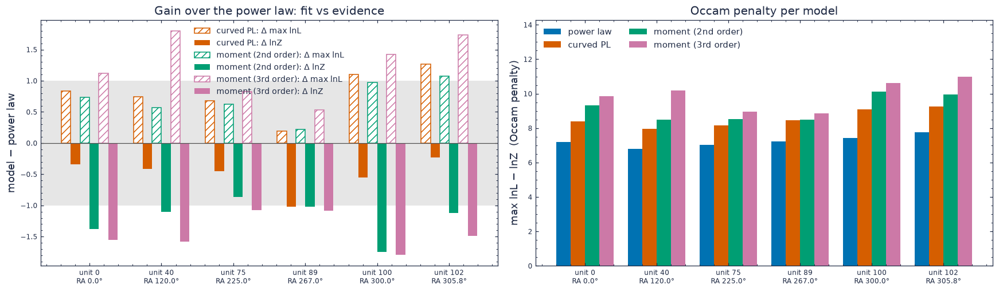

saved paper_outputs/model_comparison/diagnostic_plots/fig6_maxlogl_vs_logZ.png
     power law max lnL  curved PL max lnL  moment (2nd order) max lnL  moment (3rd order) max lnL  power law lnZ  curved PL lnZ  moment (2nd order) lnZ  moment (3rd order) lnZ
0               -79.42             -78.58                      -78.68                      -78.30         -86.62         -86.96                  -87.99                  -88.17
40              -77.27             -76.52                      -76.70                      -75.47         -84.08         -84.49                  -85.18                  -85.65
75              -76.58             -75.90                      -75.96                      -75.76         -83.62         -84.07                  -84.49                  -84.70
89              -79.81             -79.62                      -79.60                      -79.28         -87.06         -88.07                  -88.08                  -88.14
100             -84.95             -83.84

In [23]:
if not P2_UNITS:
    print("Figure 6 skipped: no Part 2 results (set RUN_RERUNS = True).")
else:
    maxl = {m: np.array([float(P2[m][u]["maxlogl"]) for u in P2_UNITS]) for m in MODELS}
    lzr = {m: np.array([float(P2[m][u]["logz"]) for u in P2_UNITS]) for m in MODELS}
    x = np.arange(len(P2_UNITS)); w = 0.13
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.8))
    for j, m in enumerate((CURVED, MOMENT, MOMENT3)):
        a1.bar(x + (2 * j - 2.5) * w, maxl[m] - maxl[PL], w, color="white", edgecolor=COL[m], hatch="///",
               label=f"{SHORT[m]}: Δ max lnL")
        a1.bar(x + (2 * j - 1.5) * w, lzr[m] - lzr[PL], w, color=COL[m], label=f"{SHORT[m]}: Δ lnZ")
    a1.axhline(0, color="0.3", lw=0.8); a1.axhspan(-TIE, TIE, color="0.9", lw=0, zorder=0)
    a1.set_xticks(x); a1.set_xticklabels([f"unit {u}\nRA {RA_OF[u]:.1f}°" for u in P2_UNITS])
    a1.set_ylabel("model − power law"); a1.legend(frameon=False, fontsize=9)
    a1.set_title("Gain over the power law: fit vs evidence")
    for j, m in enumerate(MODELS):
        a2.bar(x + (j - 1.5) * 0.2, maxl[m] - lzr[m], 0.2, color=COL[m], label=SHORT[m])
    a2.set_xticks(x); a2.set_xticklabels([f"unit {u}\nRA {RA_OF[u]:.1f}°" for u in P2_UNITS])
    a2.set_ylabel("max lnL − lnZ  (Occam penalty)"); a2.set_ylim(0, 1.3 * max(float((maxl[m] - lzr[m]).max()) for m in MODELS))
    a2.legend(frameon=False, ncol=2, loc="upper left")
    a2.set_title("Occam penalty per model")
    fig.tight_layout()
    save(fig, "fig6_maxlogl_vs_logZ")
    print(pd.DataFrame({f"{SHORT[m]} max lnL": maxl[m] for m in MODELS} |
                       {f"{SHORT[m]} lnZ": lzr[m] for m in MODELS}, index=P2_UNITS).round(2).to_string())

#### Figure 7 — posterior of the curvature C
The marginal posterior of the curved power law's curvature C for each rerun ring sample, with the
prior range shaded. A posterior that fills the prior means the data do not constrain C; one well
away from zero means real curvature.

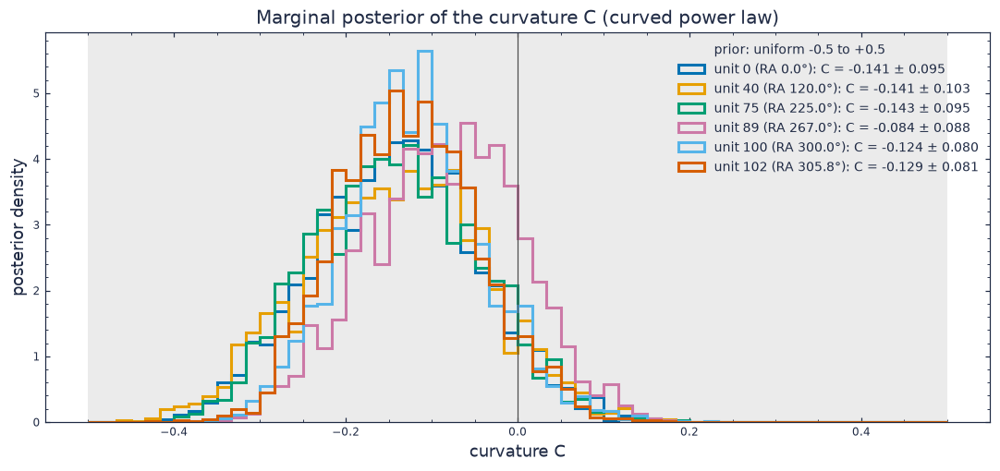

saved paper_outputs/model_comparison/diagnostic_plots/fig7_C_posterior.png


In [24]:
if not P2_UNITS:
    print("Figure 7 skipped: no Part 2 results (set RUN_RERUNS = True).")
else:
    names = [str(n) for n in P2[CURVED][P2_UNITS[0]]["names"]]; ic = names.index("C")
    lo_c, hi_c = cfg["priors"]["C"]["low"], cfg["priors"]["C"]["high"]
    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.axvspan(lo_c, hi_c, color="0.92", lw=0, label=f"prior: uniform {lo_c:+g} to {hi_c:+g}")
    bins = np.linspace(lo_c, hi_c, 61)
    for u, c in zip(P2_UNITS, UNIT_COLS):
        smp = P2[CURVED][u]["samples"][:, ic]
        ax.hist(smp, bins=bins, density=True, histtype="step", lw=2, color=c,
                label=f"unit {u} (RA {RA_OF[u]:.1f}°): C = {np.median(smp):+.3f} ± {np.std(smp):.3f}")
    ax.axvline(0, color="0.3", lw=0.8)
    ax.set_xlim(lo_c - 0.05, hi_c + 0.05); ax.set_xlabel("curvature C"); ax.set_ylabel("posterior density")
    ax.legend(frameon=False, fontsize=9)
    ax.set_title("Marginal posterior of the curvature C (curved power law)")
    fig.tight_layout()
    save(fig, "fig7_C_posterior")

## Part 3 — prior sensitivity of the curvature

The curved power law is rerun with the C prior narrowed from ±0.5 (config) to ±0.2 and ±0.1. The
prior is overridden here only; `model_comp_config.yaml` is not edited. The ±0.5 points and the power-law reference
are taken from Part 2's cache, and are computed only if missing.

In [25]:
P3_READY = False
if not RUN_PRIOR_SENSITIVITY and not any(cache_path(u, CURVED, f"C{w:g}").exists()
                                         for u in SENS_UNITS for w in C_HALF_WIDTHS if w != 0.5):
    print("PART 3 SKIPPED: no cached prior-sensitivity runs and RUN_PRIOR_SENSITIVITY = False. "
          "Set it to True in the settings cell to run units", SENS_UNITS)
else:
    ref = get_results(SENS_UNITS, PL, "base", cfg["priors"], RUN_PRIOR_SENSITIVITY)
    sens = {}
    for w in C_HALF_WIDTHS:
        pri = copy.deepcopy(cfg["priors"])
        pri["C"] = {"type": "uniform", "low": -w, "high": w}
        tag = "base" if w == 0.5 else f"C{w:g}"
        sens[w] = get_results(SENS_UNITS, CURVED, tag, pri, RUN_PRIOR_SENSITIVITY)
    S3_UNITS = [u for u in SENS_UNITS if u in ref and all(u in sens[w] for w in C_HALF_WIDTHS)]
    P3_READY = bool(S3_UNITS)
    if not P3_READY:
        print("Part 3: incomplete cache, nothing to plot.")

  ran unit   0, curved PL            [C0.2]  lnZ = -86.17 ± 0.24
  ran unit  40, curved PL            [C0.2]  lnZ = -84.14 ± 0.17
  ran unit  75, curved PL            [C0.2]  lnZ = -83.55 ± 0.20
  ran unit 100, curved PL            [C0.2]  lnZ = -92.16 ± 0.31
  ran unit 102, curved PL            [C0.2]  lnZ = -92.93 ± 0.22
  ran unit   0, curved PL            [C0.1]  lnZ = -86.44 ± 0.20
  ran unit  40, curved PL            [C0.1]  lnZ = -84.20 ± 0.16
  ran unit  75, curved PL            [C0.1]  lnZ = -83.38 ± 0.18
  ran unit 100, curved PL            [C0.1]  lnZ = -92.42 ± 0.16
  ran unit 102, curved PL            [C0.1]  lnZ = -92.91 ± 0.18


#### Figure 8 — curved-model evidence against the width of the C prior
Each line is one ring sample: lnZ(curved) − lnZ(power law) as the C prior is narrowed. If the curvature
is not needed, a narrower prior raises the curved model's evidence towards the power law's; if the data
need |C| beyond the prior, it falls.

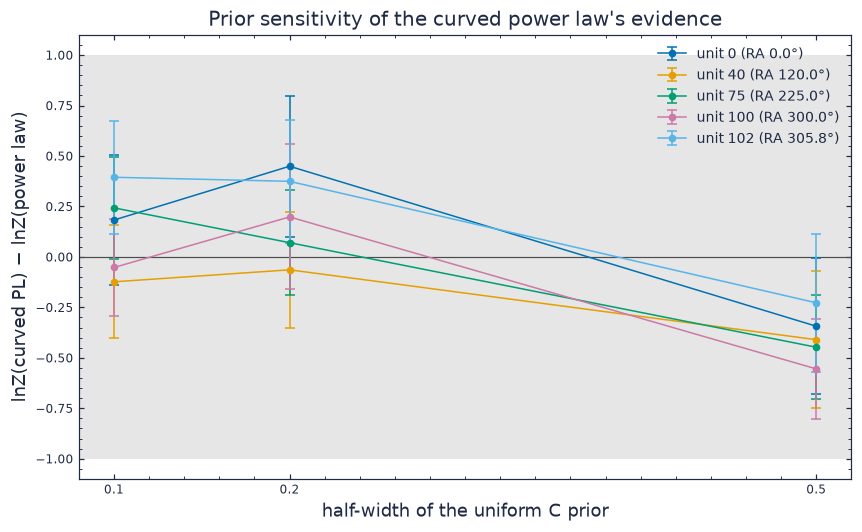

saved paper_outputs/model_comparison/diagnostic_plots/fig8_prior_sensitivity_C.png
     C ±0.5  C ±0.2  C ±0.1
0     -0.34    0.45    0.18
40    -0.41   -0.06   -0.12
75    -0.45    0.07    0.24
100   -0.55    0.20   -0.05
102   -0.23    0.37    0.39

Sign of ΔlnZ flips with the prior width for: unit 0, unit 75, unit 100, unit 102


In [26]:
if not P3_READY:
    print("Figure 8 skipped: no Part 3 results (set RUN_PRIOR_SENSITIVITY = True).")
else:
    W = np.array(C_HALF_WIDTHS)
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.axhspan(-TIE, TIE, color="0.9", lw=0); ax.axhline(0, color="0.3", lw=0.8)
    rows, flips = {}, []
    for u, c in zip(S3_UNITS, UNIT_COLS):
        d = np.array([float(sens[w][u]["logz"]) - float(ref[u]["logz"]) for w in W])
        e = np.array([np.hypot(float(sens[w][u]["logzerr"]), float(ref[u]["logzerr"])) for w in W])
        ax.errorbar(W, d, yerr=e, fmt="o-", color=c, capsize=3, label=f"unit {u} (RA {RA_OF[u]:.1f}°)")
        rows[u] = d
        if np.any(np.sign(d) != np.sign(d[0])):
            flips.append(u)
    ax.set_xlabel("half-width of the uniform C prior"); ax.set_ylabel("lnZ(curved PL) − lnZ(power law)")
    ax.set_xticks(W); ax.legend(frameon=False, fontsize=9)
    ax.set_title("Prior sensitivity of the curved power law's evidence")
    fig.tight_layout()
    save(fig, "fig8_prior_sensitivity_C")
    print(pd.DataFrame(rows, index=[f"C ±{w:g}" for w in W]).T.round(2).to_string())
    print("\nSign of ΔlnZ flips with the prior width for:", ", ".join(f"unit {u}" for u in flips) if flips else "no unit")

## Part 4 — is the evidence converged?

ln Z comes from a sampler, so it is only an estimate. Four plain checks, each on the three ring samples
in `CONV_UNITS` and all four models, with the same data and priors as the model comparison:

1. **Exact answer.** For models with 2–4 parameters the evidence can be computed directly:
   ln Z = ln ∫ likelihood × prior, summed on a fine grid. UltraNest should land within its quoted error.
2. **Repeat runs.** The same run with 5 different random seeds. The spread should be about the quoted error.
3. **More or fewer live points, stricter stopping.** 100, 400 (the default) and 1600 live points, and
   stopping at dlogz 0.1 instead of 0.5. ln Z should not drift.
4. **Does the conclusion change?** The model comparison only uses ΔlnZ (model − power law) and the
   ±1 tie band. If every run gives the same verdict, the sampling noise does not matter.

Every run is seeded (UltraNest draws from numpy's global random generator) and cached in
`diagnostic_plots/cache/convergence/`. The tables are also saved as CSV in `diagnostic_plots/`.

In [27]:
CONV_DIR = CACHE_DIR / "convergence"
DEFAULT_LIVE, DEFAULT_DLOGZ = int(SCFG["min_num_live_points"]), float(SCFG["dlogz"])
SETTINGS = ([("seed", DEFAULT_LIVE, DEFAULT_DLOGZ, sd) for sd in CONV_SEEDS]
            + [("live", L, DEFAULT_DLOGZ, CONV_SEEDS[0]) for L in CONV_LIVE]
            + [("dlogz", DEFAULT_LIVE, CONV_STRICT_DLOGZ, CONV_SEEDS[0])])
REF = ("seed", DEFAULT_LIVE, DEFAULT_DLOGZ, CONV_SEEDS[0])   # the default run

def setting_label(st):
    kind, L, dz, sd = st
    if kind == "seed":
        return f"seed {sd}"
    if kind == "live":
        return f"{L} live points"
    return f"dlogz {dz:g}"

def conv_path(u, m, L, dz, sd):
    return CONV_DIR / f"unit{u:03d}__{slug(m)}__{TAG[m]}__L{L}_d{dz:g}_s{sd}.npz"

def run_setting(m, nu, t, s, L, dz, sd):
    # The same likelihood and UltraNest call as rc.log_evidence, with explicit live points, dlogz and seed.
    import ultranest
    names, fn = MODELS[m]
    transform = prior_transform(names, cfg["priors"])
    norm = -np.sum(np.log(s * np.sqrt(2 * np.pi)))
    def loglike(params):
        r = (t - fn(nu, params)) / s
        return -0.5 * np.sum(r * r, axis=-1) + norm
    np.random.seed(sd)
    sampler = ultranest.ReactiveNestedSampler(names, loglike, transform, vectorized=True, log_dir=None)
    logging.getLogger("ultranest").setLevel(logging.WARNING)
    res = sampler.run(min_num_live_points=L, dlogz=dz, show_status=False, viz_callback=False)
    return dict(logz=res["logz"], logzerr=res["logzerr"], ncall=res["ncall"], samples=res["samples"])

def grid_logz(m, nu, t, s, samples, n, width=8.0):
    # ln ∫ L x prior on an n^d grid aligned with the posterior's correlation axes (±width sigma).
    # Parameters with a log-uniform prior are integrated in ln(value), where their prior is flat.
    names, fn = MODELS[m]; d = len(names); P = cfg["priors"]
    is_log = np.array([P[k]["type"] == "loguniform" for k in names])
    lo = np.array([np.log(P[k]["low"]) if g else P[k]["low"] for k, g in zip(names, is_log)])
    hi = np.array([np.log(P[k]["high"]) if g else P[k]["high"] for k, g in zip(names, is_log)])
    x = np.array(samples, dtype=float); x[:, is_log] = np.log(x[:, is_log])
    mu, chol = x.mean(0), np.linalg.cholesky(np.cov(x.T))
    u1 = np.linspace(-width, width, n)
    X = mu + np.stack([g.ravel() for g in np.meshgrid(*[u1] * d, indexing="ij")], -1) @ chol.T
    inside = np.all((X >= lo) & (X <= hi), axis=1)          # outside the prior: zero
    theta = X[inside].copy(); theta[:, is_log] = np.exp(theta[:, is_log])
    norm = -np.sum(np.log(s * np.sqrt(2 * np.pi)))
    ll = np.full(len(X), -np.inf)
    ll[inside] = np.concatenate([-0.5 * np.sum(((t - fn(nu, theta[k:k + 200000])) / s) ** 2, axis=-1) + norm
                                 for k in range(0, len(theta), 200000)])
    ll = ll.reshape([n] * d); top = ll.max(); L = np.exp(ll - top)
    for _ in range(d):
        L = np.trapezoid(L, u1, axis=-1)
    return float(np.log(L) + top - np.sum(np.log(hi - lo)) + np.log(abs(np.linalg.det(chol))))

def grid_ns(m):
    # (coarse, fine) grid points per axis for model m, from GRID_N by its number of parameters
    return GRID_N[len(MODELS[m][0])]

def exact(u, m):
    # the exact ln Z: the finer grid
    return GRID[(u, m)][grid_ns(m)[-1]]

CONV, GRID = {}, {}
def conv_cached(path):
    # A cached run counts only if it was made from the current ring TODs.
    if not path.exists():
        return None
    z = np.load(path, allow_pickle=False)
    return {k: z[k] for k in z.files} if "tod_key" in z.files and str(z["tod_key"]) == TOD_KEY else None

have = all(conv_cached(conv_path(u, m, *st[1:])) is not None for u in CONV_UNITS for m in MODELS for st in SETTINGS)
if not (RUN_CONVERGENCE or have):
    print("PART 4 SKIPPED: set RUN_CONVERGENCE = True in the settings cell.")
else:
    CONV_DIR.mkdir(parents=True, exist_ok=True)
    pts = {u: (P2[PL][u]["nu"], P2[PL][u]["t"], P2[PL][u]["s"]) if u in P2[PL] else unit_points([u])[u][:3]
           for u in CONV_UNITS}
    for u in CONV_UNITS:
        nu, t, s = pts[u]
        for m in MODELS:
            for st in SETTINGS:
                path = conv_path(u, m, *st[1:])
                r = conv_cached(path)
                if r is None:
                    r = dict(run_setting(m, nu, t, s, *st[1:]), tod_key=TOD_KEY); np.savez(path, **r)
                CONV[(u, m, st)] = r
            GRID[(u, m)] = {n: grid_logz(m, nu, t, s, CONV[(u, m, REF)]["samples"], n) for n in grid_ns(m)}
    print(f"{len(CONV)} UltraNest runs ({len(CONV_UNITS)} samples x {len(MODELS)} models x {len(SETTINGS)} settings), "
          f"{len(GRID)} grid integrals")

96 UltraNest runs (3 samples x 4 models x 8 settings), 12 grid integrals


#### Check 1 — UltraNest against the exact integral
`grid` is the exact ln Z at two grid resolutions (`grid points per axis`: 41 and 81 for 2–3 parameters,
25 and 41 for the 4-parameter order-3 model): if the coarse and fine columns agree, the grid has converged.
`UltraNest − grid` should be about the size of the quoted error or smaller.

In [28]:
if CONV:
    rows = []
    for u in CONV_UNITS:
        for m in MODELS:
            r = CONV[(u, m, REF)]
            g = exact(u, m); nc, nf = grid_ns(m)
            rows.append({"sample": u, "RA [deg]": RA_OF[u], "model": SHORT[m],
                         "UltraNest ln Z": float(r["logz"]), "quoted error": float(r["logzerr"]),
                         "grid points per axis": f"{nc} / {nf}",
                         "grid ln Z (coarse)": GRID[(u, m)][nc], "grid ln Z (fine)": g,
                         "UltraNest − grid": float(r["logz"]) - g})
    T1 = pd.DataFrame(rows)
    T1.to_csv(PLOT_DIR / "convergence_check1_exact.csv", index=False)
    print(T1.round(3).to_string(index=False))
    gconv = max(abs(GRID[k][grid_ns(k[1])[0]] - GRID[k][grid_ns(k[1])[-1]]) for k in GRID)
    worst = T1.loc[T1["UltraNest − grid"].abs().idxmax()]
    print(f"\nGrid resolution changes ln Z by at most {gconv:.3f}.")
    print(f"Largest |UltraNest − grid| = {abs(worst['UltraNest − grid']):.2f} "
          f"(sample {worst['sample']}, {worst['model']}; quoted error {worst['quoted error']:.2f}).")
    print(f"UltraNest within its quoted error of the exact value in "
          f"{int((T1['UltraNest − grid'].abs() <= T1['quoted error']).sum())} of {len(T1)} cases.")

 sample  RA [deg]              model  UltraNest ln Z  quoted error grid points per axis  grid ln Z (coarse)  grid ln Z (fine)  UltraNest − grid
      0      0.00          power law         -86.434         0.168              41 / 81             -86.616           -86.616             0.182
      0      0.00          curved PL         -87.023         0.222              41 / 81             -86.979           -86.980            -0.044
      0      0.00 moment (2nd order)         -87.931         0.196              41 / 81             -87.925           -87.874            -0.056
      0      0.00 moment (3rd order)         -87.700         0.241              25 / 41             -87.984           -87.966             0.266
     89    267.00          power law         -86.997         0.197              41 / 81             -86.899           -86.899            -0.098
     89    267.00          curved PL         -88.198         0.101              41 / 81             -88.001           -87.995           

#### Check 2 — the same run with five seeds
`spread` is the largest minus the smallest ln Z over the five runs, `std` their standard deviation.
If `std` is about the `typical quoted error`, the quoted error is honest.

In [29]:
if CONV:
    rows = []
    for u in CONV_UNITS:
        for m in MODELS:
            z = np.array([float(CONV[(u, m, st)]["logz"]) for st in SETTINGS if st[0] == "seed"])
            e = np.array([float(CONV[(u, m, st)]["logzerr"]) for st in SETTINGS if st[0] == "seed"])
            rows.append({"sample": u, "model": SHORT[m], "mean ln Z": z.mean(), "spread": z.max() - z.min(),
                         "std": z.std(ddof=1), "typical quoted error": float(np.median(e)),
                         "mean − exact": z.mean() - exact(u, m)})
    T2 = pd.DataFrame(rows)
    T2.to_csv(PLOT_DIR / "convergence_check2_seeds.csv", index=False)
    print(T2.round(3).to_string(index=False))

 sample              model  mean ln Z  spread   std  typical quoted error  mean − exact
      0          power law    -86.568   0.424 0.178                 0.168         0.047
      0          curved PL    -86.999   0.175 0.065                 0.222        -0.019
      0 moment (2nd order)    -87.961   0.255 0.109                 0.196        -0.087
      0 moment (3rd order)    -87.950   0.405 0.175                 0.241         0.016
     89          power law    -86.993   0.359 0.157                 0.197        -0.094
     89          curved PL    -88.141   0.196 0.085                 0.211        -0.146
     89 moment (2nd order)    -88.132   0.223 0.087                 0.206         0.041
     89 moment (3rd order)    -88.072   0.353 0.152                 0.190        -0.091
    102          power law    -93.302   0.411 0.168                 0.185        -0.063
    102          curved PL    -93.429   0.395 0.183                 0.166         0.075
    102 moment (2nd order)    -9

#### Check 3 — live points and stopping rule
ln Z for 100, 400 (default) and 1600 live points, and for the stricter stop, next to the exact value.
More live points should move ln Z towards the exact value, not away from it.

In [30]:
if CONV:
    cols = [st for st in SETTINGS if st[0] != "seed" or st == REF]
    cols = sorted(cols, key=lambda st: (st[0] == "dlogz", st[1]))
    rows = []
    for u in CONV_UNITS:
        for m in MODELS:
            row = {"sample": u, "model": SHORT[m]}
            for st in cols:
                row[f"{setting_label(st) if st != REF else f'{DEFAULT_LIVE} live points (default)'}"] = float(CONV[(u, m, st)]["logz"])
            row["exact (grid)"] = exact(u, m)
            rows.append(row)
    T3 = pd.DataFrame(rows)
    T3.to_csv(PLOT_DIR / "convergence_check3_settings.csv", index=False)
    with pd.option_context("display.width", 200):
        print(T3.round(3).to_string(index=False))
    calls = {setting_label(st): int(np.median([int(CONV[(u, m, st)]["ncall"]) for u in CONV_UNITS for m in MODELS]))
             for st in cols}
    print("\nlikelihood calls per run (median):", ", ".join(f"{k}: {v}" for k, v in calls.items()))

 sample              model  100 live points  400 live points (default)  1600 live points  dlogz 0.1  exact (grid)
      0          power law          -86.682                    -86.434           -86.532    -86.500       -86.616
      0          curved PL          -86.741                    -87.023           -86.961    -86.889       -86.980
      0 moment (2nd order)          -87.631                    -87.931           -87.922    -87.790       -87.874
      0 moment (3rd order)          -87.766                    -87.700           -88.019    -87.843       -87.966
     89          power law          -86.788                    -86.997           -86.962    -87.028       -86.899
     89          curved PL          -88.481                    -88.198           -87.988    -88.190       -87.995
     89 moment (2nd order)          -88.128                    -88.261           -88.075    -88.154       -88.174
     89 moment (3rd order)          -88.087                    -87.936           -87.952

#### Check 4 — does the verdict change?
For curved − power law and moment (orders 2 and 3) − power law, ΔlnZ from every run (each run paired with the power-law run
at the same settings), and from the exact integral. The verdict uses the comparison's own rule:
> +1 favours the model, < −1 favours the power law, otherwise a tie.

In [31]:
def verdict(d):
    return "favours model" if d > TIE else ("favours power law" if d < -TIE else "tie")

if CONV:
    rows = []
    for u in CONV_UNITS:
        for m in (CURVED, MOMENT, MOMENT3):
            d = np.array([float(CONV[(u, m, st)]["logz"]) - float(CONV[(u, PL, st)]["logz"]) for st in SETTINGS])
            dg = exact(u, m) - exact(u, PL)
            v = pd.Series([verdict(x) for x in d]).value_counts()
            rows.append({"sample": u, "RA [deg]": RA_OF[u], "comparison": f"{SHORT[m]} − power law",
                         "exact ΔlnZ": dg, "exact verdict": verdict(dg),
                         "lowest ΔlnZ": d.min(), "highest ΔlnZ": d.max(),
                         "runs agreeing with exact": f"{int((v.get(verdict(dg), 0)))} of {len(d)}"})
    T4 = pd.DataFrame(rows)
    T4.to_csv(PLOT_DIR / "convergence_check4_verdicts.csv", index=False)
    with pd.option_context("display.width", 200):
        print(T4.round(2).to_string(index=False))

 sample  RA [deg]                     comparison  exact ΔlnZ     exact verdict  lowest ΔlnZ  highest ΔlnZ runs agreeing with exact
      0      0.00          curved PL − power law       -0.36               tie        -0.59         -0.06                   8 of 8
      0      0.00 moment (2nd order) − power law       -1.26 favours power law        -1.59         -0.95                   7 of 8
      0      0.00 moment (3rd order) − power law       -1.35 favours power law        -1.50         -1.08                   8 of 8
     89    267.00          curved PL − power law       -1.10 favours power law        -1.69         -1.02                   8 of 8
     89    267.00 moment (2nd order) − power law       -1.27 favours power law        -1.34         -0.91                   6 of 8
     89    267.00 moment (3rd order) − power law       -1.08 favours power law        -1.30         -0.90                   4 of 8
    102    305.75          curved PL − power law       -0.27               tie     

#### Figure 9 — ΔlnZ from every run, against the exact value
Each panel is one ring sample. Dots are the individual runs (5 seeds, other live points, stricter stop),
the bar is the exact value from the grid integral, and the grey band is the ±1 tie range.

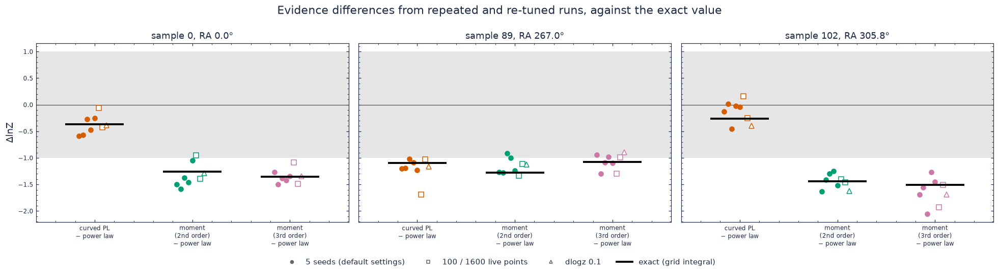

saved paper_outputs/model_comparison/diagnostic_plots/fig9_convergence_dlogZ.png


In [32]:
if CONV:
    fig, axes = plt.subplots(1, len(CONV_UNITS), figsize=(6 * len(CONV_UNITS), 4.6), sharey=True)
    marks = {"seed": "o", "live": "s", "dlogz": "^"}
    for ax, u in zip(np.atleast_1d(axes), CONV_UNITS):
        ax.axhspan(-TIE, TIE, color="0.9", lw=0)
        ax.axhline(0, color="0.3", lw=0.8)
        for j, m in enumerate((CURVED, MOMENT, MOMENT3)):
            for k, st in enumerate(SETTINGS):
                d = float(CONV[(u, m, st)]["logz"]) - float(CONV[(u, PL, st)]["logz"])
                ax.plot(j + (k - len(SETTINGS) / 2) * 0.04, d, marks[st[0]], color=COL[m], ms=6, mfc="white" if st[0] != "seed" else COL[m])
            dg = exact(u, m) - exact(u, PL)
            ax.hlines(dg, j - 0.3, j + 0.3, color="black", lw=2.5)
        ax.set_xticks([0, 1, 2]); ax.set_xticklabels([SHORT[m].replace(" (", "\n(") + "\n− power law" for m in (CURVED, MOMENT, MOMENT3)])
        ax.set_xlim(-0.6, 2.6)
        ax.set_title(f"sample {u}, RA {RA_OF[u]:.1f}°", fontsize=12)
    np.atleast_1d(axes)[0].set_ylabel("ΔlnZ")
    from matplotlib.lines import Line2D
    handles = [Line2D([], [], marker="o", ls="", color="0.4", label="5 seeds (default settings)"),
               Line2D([], [], marker="s", ls="", color="0.4", mfc="white", label="100 / 1600 live points"),
               Line2D([], [], marker="^", ls="", color="0.4", mfc="white", label=f"dlogz {CONV_STRICT_DLOGZ:g}"),
               Line2D([], [], color="black", lw=2.5, label="exact (grid integral)")]
    fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.06))
    fig.suptitle("Evidence differences from repeated and re-tuned runs, against the exact value")
    fig.tight_layout()
    save(fig, "fig9_convergence_dlogZ")

#### Part 4 in plain numbers

*Evidence diagnostics (Occam penalty included); see the note at the top of Part 2.*

Run on 2026-10-29 on the current data (beam-matched TODs; 4 points per sample: LWA1 35, Maipu 45, LWA1 80 and
Stockert 1420, no TRIS); samples 0 (RA 0°), 89 (RA 267°) and 102 (RA 305.8°); all four models; 96 UltraNest runs and
12 grid integrals; tables in `diagnostic_plots/convergence_check*.csv`.

* **The exact integral is reliable to about 0.1.** Refining the grid (41 → 81 points per axis; 25 → 41 for the
  4-parameter order-3 model) changes ln Z by at most 0.10 (the moment expansions; the power law and curved power law
  by less than 0.003). With 4 points the posteriors are broader, so the grid is coarser relative to them than before.
* **UltraNest is close to exact.** At the default settings it is off by 0.01 to 0.33 in ln Z (worst: sample 102,
  curved PL, −0.33 against a quoted error of 0.17). It is within its quoted error in 11 of 12 cases.
* **The quoted error is honest.** Over 5 seeds the scatter (std) is 0.01–0.22, against a typical quoted error of
  0.15–0.23. The mean of the 5 runs is within 0.13 of the exact value in every case.
* **Settings do not bias it.** 1600 live points and the stricter stop (dlogz 0.1) land within 0.16 of the exact
  value; 400 live points (the default) within 0.33; 100 live points is noisier (up to 0.50 off, sample 102 curved PL).
  1600 live points cost about 3.1× the likelihood calls of the default, the stricter stop about 2.6×.
* **Most verdicts sit near the ±1 line, so they are borderline.** The exact ΔlnZ against the power law is −0.57 /
  −1.10 / −1.21 at sample 0 (curved PL / moment order 2 / order 3), −0.86 / −0.91 / −0.88 at sample 89 and −0.80 /
  −1.53 / −1.70 at sample 102. Only 4 of the 9 comparisons give the exact verdict in all 8 runs; in the others 1–2 runs
  cross the ±1 line. Every run in every comparison is below zero: the power law is never worse.
* **No Cygnus curvature without TRIS.** At sample 102 the curved power law no longer wins (exact −0.80, all runs
  −1.14 to −0.11). The +3.9 of the 6-point run came from the TRIS points.

## Part 5 — the fitted models at the TRIS frequencies, and the χ² of every fit

Every model is fitted at **every** ring sample: the same points as the comparison (`run_comparison.tod_units` with the
data sets of pipeline step 3, the `error_bars.csv` errors, and TRIS with its **published** uncertainties,
`sed_prototype.ring_sigma` = statistical ⊕ published zero level), the same Gaussian likelihood and the same prior
ranges (`model_comp_config.yaml`). The fit is the **maximum likelihood inside the prior ranges** (the minimum χ²), found with
L-BFGS-B in the sampler's unit cube from `ML_STARTS` starting points (`comparison.ml_starts`, seeded): the same fitter
as `run_comparison.max_likelihood`. With `statistic: max_likelihood` these are the comparison's own best fits, and the
χ² is checked against `results/maxlike_per_unit_tod.csv`. For the Part 2 samples it is also checked against UltraNest's
maximum likelihood. Results are cached in `diagnostic_plots/cache/ml_fits_all_samples.npz` under the data key.

In [33]:
ML_CACHE = CACHE_DIR / "ml_fits_all_samples.npz"
ALL_UNITS = ALL_UNITS_RING
ML_KEY = json.dumps({"data": TOD_KEY, "priors": cfg["priors"], "models": list(MODELS),
                     "beta_fixed": cfg["models"].get("moment_beta_fixed"), "starts": ML_STARTS}, sort_keys=True)

def ml_fit(m, nu, t, s, rng):
    # Minimum chi^2 inside the prior box, searched in the unit cube of prior_transform.
    names, fn = MODELS[m]
    tr = prior_transform(names, cfg["priors"])
    chi2 = lambda u: float(np.sum(((t - fn(nu, tr(np.atleast_2d(u)))[0]) / s) ** 2))
    best = None
    for u0 in np.vstack([np.full(len(names), 0.5), rng.uniform(0.02, 0.98, (ML_STARTS - 1, len(names)))]):
        r = minimize(chi2, u0, method="L-BFGS-B", bounds=[(0.0, 1.0)] * len(names))
        if best is None or r.fun < best.fun:
            best = r
    return tr(np.atleast_2d(best.x))[0]

from scipy.optimize import minimize
PTS5, FIT5 = {}, {m: {} for m in MODELS}
z = np.load(ML_CACHE, allow_pickle=False) if ML_CACHE.exists() else None
if z is not None and str(z["key"]) == ML_KEY:
    for u in ALL_UNITS:
        PTS5[u] = (z[f"u{u}__nu"], z[f"u{u}__t"], z[f"u{u}__s"], [str(k) for k in z[f"u{u}__keys"]])
        for m in MODELS:
            FIT5[m][u] = z[f"u{u}__{slug(m)}"]
    print(f"Part 5: maximum-likelihood fits loaded from {ML_CACHE.relative_to(REPO)}")
elif not RUN_ML_FITS:
    print("PART 5 SKIPPED: no matching cache and RUN_ML_FITS = False.")
else:
    PTS5 = unit_points(ALL_UNITS)
    rng = np.random.default_rng(0)
    for u in ALL_UNITS:
        nu, t, s, keys = PTS5[u]
        for m in MODELS:
            FIT5[m][u] = ml_fit(m, nu, t, s, rng)
    out = {"key": ML_KEY}
    for u, (nu, t, s, keys) in PTS5.items():
        out.update({f"u{u}__nu": nu, f"u{u}__t": t, f"u{u}__s": s, f"u{u}__keys": np.array(keys)})
        out.update({f"u{u}__{slug(m)}": FIT5[m][u] for m in MODELS})
    np.savez(ML_CACHE, **out)
    print(f"Part 5: fitted {len(MODELS)} models at {len(ALL_UNITS)} ring samples; saved {ML_CACHE.relative_to(REPO)}")
P5 = bool(PTS5)

if P5:
    # Per-sample chi^2 and its contribution from each point
    RA5 = np.array([RA_OF[u] for u in ALL_UNITS])
    # Both TRIS bands are always shown in Figure 10; FITTED_TRIS are those among the chosen data sets.
    TRIS_KEYS = ["TRIS_600", "TRIS_820"]
    FITTED_TRIS = [k for k in TRIS_KEYS if all(k in PTS5[u][3] for u in ALL_UNITS)]
    def model_at(m, u, nu):
        return MODELS[m][1](np.atleast_1d(np.asarray(nu, dtype=float)), FIT5[m][u][None, :])[0]
    CHI = {}
    for m in MODELS:
        for u in ALL_UNITS:
            nu, t, s, keys = PTS5[u]
            r2 = ((t - model_at(m, u, nu)) / s) ** 2
            CHI[(m, u)] = dict(chi2=float(r2.sum()), n=len(t), k=len(MODELS[m][0]), contrib=dict(zip(keys, r2)))
    print("points per sample:", sorted({";".join(PTS5[u][3]) for u in ALL_UNITS}))

if P5 and ML_STAT and ML_CSV.exists():
    # The comparison's own best fits (run_comparison.max_likelihood) against the fits here: same data, same fitter.
    _ml = pd.read_csv(ML_CSV).set_index("unit")
    _same = [u for u in ALL_UNITS if u in _ml.index and _ml.loc[u, "inputs"] == ";".join(PTS5[u][3])]
    if _same:
        dd = np.array([[CHI[(m, u)]["chi2"] - _ml.loc[u, f"chi2 {m}"] for m in MODELS] for u in _same])
        print(f"check against {ML_CSV.relative_to(REPO)} ({len(_same)} samples with the same points): "
              f"χ² here − χ² in the CSV: median {np.median(dd):+.2e}, range {dd.min():+.2e} to {dd.max():+.2e}")
    else:
        print(f"{ML_CSV.relative_to(REPO)} was made from other points: no check")

Part 5: fitted 4 models at 120 ring samples; saved paper_outputs/model_comparison/diagnostic_plots/cache/ml_fits_all_samples.npz
points per sample: ['LWA_35MHz.fits;LWA1_38.fits;LWA1_40.fits;LWA1_45.fits;MAIPU_45mhZ.fits;LWA1_50.fits;LWA1_60.fits;LWA1_70.fits;LWA1_74.fits;LWA_80MHz.fits;STOCKERT_VILLA_1400MHZ.fits']


#### Figure 10 — the fitted models at 600 and 820 MHz, with the TRIS rings

Each model's best fit at every ring sample, evaluated at the TRIS effective frequencies (600.5 and 817.8 MHz), drawn
along the ring with the TRIS ring data on top (black points, **published uncertainties**: statistical ⊕ zero level).
A TRIS band that is not among the fitted data sets is still drawn (open points): the models are then a prediction
at that frequency, not a fit to it. **Bottom:** model − TRIS in kelvin; the grey band is the TRIS ±1σ. The dotted line is Cygnus A. The table gives the
median and rms of model − TRIS and the median |model − TRIS| / σ; the values per sample are saved to
`diagnostic_plots/part5_model_tods_at_tris.csv`.

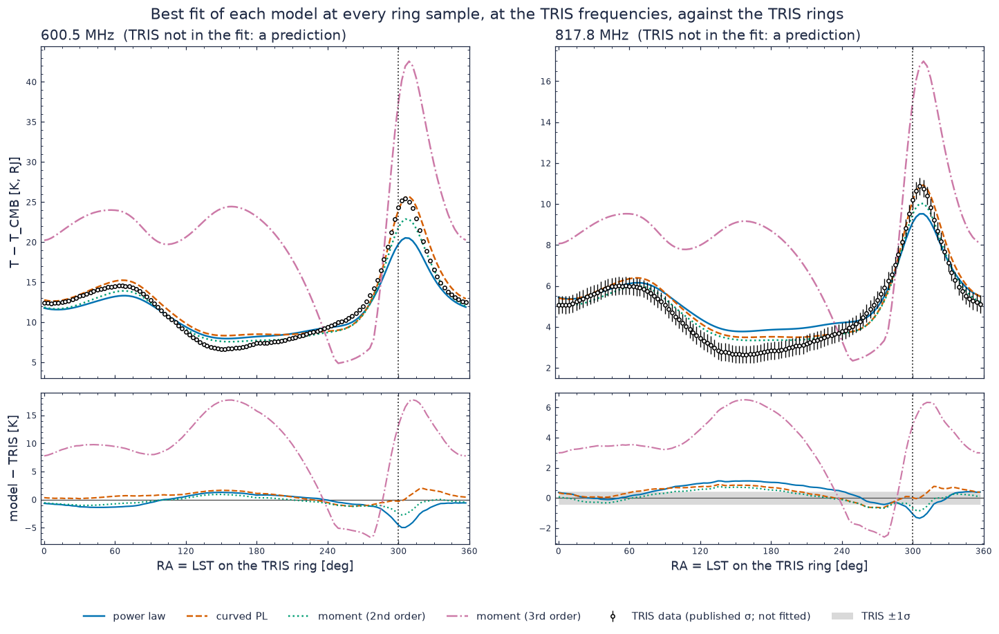

saved paper_outputs/model_comparison/diagnostic_plots/fig10_models_at_tris_frequencies.png
saved diagnostic_plots/part5_model_tods_at_tris.csv and part5_model_minus_tris_summary.csv

             model TRIS band  median (model − TRIS) [K]  rms [K]  max |model − TRIS| [K]  median |model − TRIS| / σ  samples with |model − TRIS| > σ
         power law 600.5 MHz                     -0.622    1.465                   4.952                     13.457                              117
         curved PL 600.5 MHz                      0.662    0.953                   1.994                     11.178                              118
moment (2nd order) 600.5 MHz                     -0.400    0.868                   2.711                      9.803                              111
moment (3rd order) 600.5 MHz                      9.566   11.166                  17.771                    143.110                              120
         power law 817.8 MHz                      0.382    0.684        

In [34]:
if not P5:
    print("Figure 10 skipped: no Part 5 fits (set RUN_ML_FITS = True).")
else:
    TT5, SS5, NN5 = {}, {}, {}
    for k in TRIS_KEYS:
        if k in FITTED_TRIS:   # a fit point: exactly as fitted
            TT5[k] = np.array([PTS5[u][1][PTS5[u][3].index(k)] for u in ALL_UNITS])
            SS5[k] = np.array([PTS5[u][2][PTS5[u][3].index(k)] for u in ALL_UNITS])
            NN5[k] = float(PTS5[ALL_UNITS[0]][0][PTS5[ALL_UNITS[0]][3].index(k)])
        else:                  # not fitted: the ring as run_comparison.tod_units would build it, for comparison only
            from moonrunes import sky_maps
            from moonrunes.sed_prototype import ring_sigma
            ring = get_inputs().rings[int(k.split("_")[1])]
            NN5[k] = float(ring.effective_frequency_mhz)
            TT5[k] = np.array([ring.temperature_k[u] - sky_maps.cmb_rj_k(NN5[k]) for u in ALL_UNITS])
            SS5[k] = np.asarray(ring_sigma(ring), dtype=float)[ALL_UNITS]
    MT5 = {(m, k): np.array([model_at(m, u, NN5[k])[0] for u in ALL_UNITS]) for m in MODELS for k in TRIS_KEYS}
    LS5 = {PL: "-", CURVED: "--", MOMENT: ":", MOMENT3: "-."}

    fig, axes = plt.subplots(2, max(len(TRIS_KEYS), 1), figsize=(8 * max(len(TRIS_KEYS), 1), 8.5), sharex=True,
                             squeeze=False, gridspec_kw=dict(height_ratios=[2.2, 1], hspace=0.06, wspace=0.2))
    rows, csv_cols = [], {"unit": ALL_UNITS, "RA [deg]": RA5}
    for c, k in enumerate(TRIS_KEYS):
        ax, ar = axes[0, c], axes[1, c]
        ax.errorbar(RA5, TT5[k], yerr=SS5[k], fmt="o", ms=3.5, color="black", elinewidth=0.9, capsize=0, zorder=3,
                    label="TRIS data (published σ)" if k in FITTED_TRIS else "TRIS data (published σ; not fitted)",
                    mfc="black" if k in FITTED_TRIS else "white")
        ar.fill_between(RA5, -SS5[k], SS5[k], color="0.85", lw=0, label="TRIS ±1σ")
        ar.axhline(0, color="0.3", lw=0.8)
        csv_cols[f"TRIS {NN5[k]:g} MHz [K]"] = TT5[k]; csv_cols[f"TRIS {NN5[k]:g} MHz σ [K]"] = SS5[k]
        for m in MODELS:
            d = MT5[(m, k)] - TT5[k]
            ax.plot(RA5, MT5[(m, k)], color=COL[m], ls=LS5[m], lw=1.6, label=SHORT[m])
            ar.plot(RA5, d, color=COL[m], ls=LS5[m], lw=1.4)
            csv_cols[f"{SHORT[m]} at {NN5[k]:g} MHz [K]"] = MT5[(m, k)]
            csv_cols[f"{SHORT[m]} − TRIS at {NN5[k]:g} MHz [K]"] = d
            rows.append({"model": SHORT[m], "TRIS band": f"{NN5[k]:g} MHz", "median (model − TRIS) [K]": np.median(d),
                         "rms [K]": np.sqrt(np.mean(d ** 2)), "max |model − TRIS| [K]": np.max(np.abs(d)),
                         "median |model − TRIS| / σ": np.median(np.abs(d) / SS5[k]),
                         "samples with |model − TRIS| > σ": int(np.sum(np.abs(d) > SS5[k]))})
        for a in (ax, ar):
            a.axvline(CYG_A_RA, color="0.2", ls=":", lw=1.2)
        ax.set_title(f"{NN5[k]:g} MHz" + ("" if k in FITTED_TRIS else "  (TRIS not in the fit: a prediction)"), loc="left")
        ar.set_xlabel("RA = LST on the TRIS ring [deg]"); ar.set_xlim(-3, 360); ar.set_xticks(np.arange(0, 361, 60))
    axes[0, 0].set_ylabel("T − T_CMB [K, RJ]")
    axes[1, 0].set_ylabel("model − TRIS [K]")
    h, l = axes[0, 0].get_legend_handles_labels(); h2, l2 = axes[1, 0].get_legend_handles_labels()
    fig.legend(h + h2, l + l2, loc="upper center", ncol=6, frameon=False, bbox_to_anchor=(0.5, 0.02))
    fig.suptitle("Best fit of each model at every ring sample, at the TRIS frequencies, against the TRIS rings", y=0.94)
    save(fig, "fig10_models_at_tris_frequencies")
    pd.DataFrame(csv_cols).to_csv(PLOT_DIR / "part5_model_tods_at_tris.csv", index=False)
    t10 = pd.DataFrame(rows)
    t10.to_csv(PLOT_DIR / "part5_model_minus_tris_summary.csv", index=False)
    print("saved diagnostic_plots/part5_model_tods_at_tris.csv and part5_model_minus_tris_summary.csv\n")
    with pd.option_context("display.width", 200):
        print(t10.round(3).to_string(index=False))

#### Figure 11 — χ² of every fit

For each model and ring sample, χ² = Σ ((T − model)/σ)² over the sample's points at the best fit, with ν = N − k degrees
of freedom (N points, k parameters). **Top:** χ² along the ring; **bottom:** χ²/ν (order 3 has ν = N − 4). The tables
give, per model, the median, range and how many samples exceed χ²/ν = 1 and 2, and which points carry the χ² (median
share of χ² per input). χ² is not summed over samples: neighbouring samples are correlated. Saved to
`diagnostic_plots/part5_chi2_per_sample.csv` (with every point's contribution) and `part5_chi2_summary.csv`.

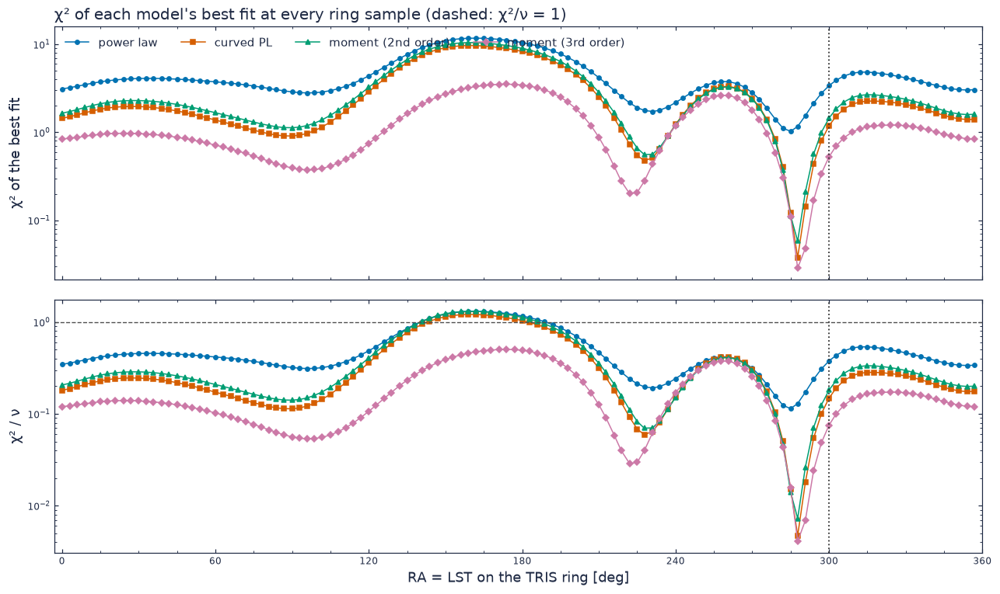

saved paper_outputs/model_comparison/diagnostic_plots/fig11_chi2_per_sample.png
saved diagnostic_plots/part5_chi2_summary.csv and part5_chi2_per_sample.csv

             model  parameters k points N ν = N − k  median χ²  mean $$\chi^2$$  min χ²  max χ²  RA of max [deg]  median χ²/ν  samples χ²/ν > 1  samples χ²/ν > 2
         power law             2       11         9      3.763            4.691   1.027  11.785           162.00        0.418                17                 0
         curved PL             3       11         8      1.891            2.949   0.038   9.713           158.75        0.236                13                 0
moment (2nd order)             3       11         8      2.170            3.252   0.058  10.495           158.75        0.271                16                 0
moment (3rd order)             4       11         7      0.952            1.282   0.029   3.531           173.75        0.136                 0                 0

median share of a sample's χ² fr

In [35]:
if not P5:
    print("Figure 11 skipped: no Part 5 fits (set RUN_ML_FITS = True).")
else:
    MK5 = {PL: "o", CURVED: "s", MOMENT: "^", MOMENT3: "D"}
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw=dict(hspace=0.08))
    for m in MODELS:
        c2 = np.array([CHI[(m, u)]["chi2"] for u in ALL_UNITS])
        dof = np.array([CHI[(m, u)]["n"] - CHI[(m, u)]["k"] for u in ALL_UNITS])
        a1.plot(RA5, c2, MK5[m] + "-", color=COL[m], ms=3.5, lw=1, label=SHORT[m])
        a2.plot(RA5, np.where(dof > 0, c2 / np.maximum(dof, 1), np.nan), MK5[m] + "-", color=COL[m], ms=3.5, lw=1)
    for a in (a1, a2):
        a.axvline(CYG_A_RA, color="0.2", ls=":", lw=1.2)
        a.set_yscale("log")
    a2.axhline(1, color="0.3", lw=0.9, ls="--")
    a1.set_ylabel("χ² of the best fit"); a2.set_ylabel("χ² / ν")
    a2.set_xlabel("RA = LST on the TRIS ring [deg]"); a2.set_xlim(-3, 360); a2.set_xticks(np.arange(0, 361, 60))
    a1.legend(frameon=False, ncol=4, loc="upper left")
    a1.set_title("χ² of each model's best fit at every ring sample (dashed: χ²/ν = 1)", loc="left")
    save(fig, "fig11_chi2_per_sample")

    rows, per = [], []
    for m in MODELS:
        c2 = np.array([CHI[(m, u)]["chi2"] for u in ALL_UNITS])
        n = np.array([CHI[(m, u)]["n"] for u in ALL_UNITS]); kpar = len(MODELS[m][0]); dof = n - kpar
        red = np.where(dof > 0, c2 / np.maximum(dof, 1), np.nan)
        rows.append({"model": SHORT[m], "parameters k": kpar, "points N": "/".join(map(str, sorted(set(n)))),
                     "ν = N − k": "/".join(map(str, sorted(set(dof)))), "median χ²": np.median(c2),
                     'mean '+r'$$\chi^2$$': np.mean(c2),
                     "min χ²": c2.min(), "max χ²": c2.max(), f"RA of max [deg]": RA5[np.argmax(c2)],
                     "median χ²/ν": np.nanmedian(red), "samples χ²/ν > 1": int(np.sum(red > 1)),
                     "samples χ²/ν > 2": int(np.sum(red > 2))})
        for u in ALL_UNITS:
            d = CHI[(m, u)]
            per.append({"unit": u, "RA [deg]": RA_OF[u], "model": SHORT[m], "N": d["n"], "k": d["k"], "ν": d["n"] - d["k"],
                        "χ²": d["chi2"], "χ²/ν": d["chi2"] / (d["n"] - d["k"]) if d["n"] > d["k"] else np.nan,
                        **{f"χ² from {POINT_NAMES.get(kk, kk)}": v for kk, v in d["contrib"].items()},
                        **{f"best-fit {nm}": v for nm, v in zip(MODELS[m][0], FIT5[m][u])}})
    t11 = pd.DataFrame(rows); t11p = pd.DataFrame(per)
    t11.to_csv(PLOT_DIR / "part5_chi2_summary.csv", index=False)
    t11p.to_csv(PLOT_DIR / "part5_chi2_per_sample.csv", index=False)
    print("saved diagnostic_plots/part5_chi2_summary.csv and part5_chi2_per_sample.csv\n")
    with pd.option_context("display.width", 220):
        print(t11.round(3).to_string(index=False))
    share = {}
    for m in MODELS:
        sub = t11p[t11p["model"] == SHORT[m]]
        cols = [c for c in sub.columns if c.startswith("χ² from ")]
        share[SHORT[m]] = (sub[cols].div(sub["χ²"], axis=0)).median() * 100
    print("\nmedian share of a sample's χ² from each input [%]:")
    print(pd.DataFrame(share).rename(index=lambda c: c.replace("χ² from ", "")).round(1).to_string())

    # Check: the minimum χ² here against UltraNest's own maximum likelihood (Part 2 reruns, same data key).
    if P2_UNITS:
        chk = []
        for u in P2_UNITS:
            for m in MODELS:
                r = P2[m][u]; s = np.asarray(r["s"], dtype=float)
                c2_un = -2 * (float(r["maxlogl"]) + np.sum(np.log(s * np.sqrt(2 * np.pi))))
                chk.append({"unit": u, "model": SHORT[m], "χ² here (L-BFGS-B)": CHI[(m, u)]["chi2"],
                            "χ² at UltraNest's max likelihood": c2_un, "difference": CHI[(m, u)]["chi2"] - c2_un})
        chk = pd.DataFrame(chk)
        print(f"\ncheck against UltraNest (Part 2 samples): χ² here − χ² at UltraNest's best point: "
              f"median {chk['difference'].median():+.3f}, range {chk['difference'].min():+.3f} to {chk['difference'].max():+.3f} "
              "(≤ 0 means the optimiser found an equal or better fit)")

## Part 6 — how robust is the verdict?

Six checks of the Part 1 verdict, all from results already on disk (the two comparison CSVs and the Part 5 maximum-likelihood
fits); nothing here reruns UltraNest or Parts 2–4. Only Figure 17 refits, and only with the maximum-likelihood fitter.

**Facts to keep in mind when reading every number below.**

* **4 points per fit.** Every ring sample is fitted with only LWA1 35, Maipu 45, LWA1 80 and Stockert 1420. TRIS 600 and
  820 are **not** in the fit (`comparison.exclude_tris`), so comparing the fits with TRIS (Figure 15) is a genuine held-out test.
* **Few degrees of freedom.** With N = 4 the power law (k = 2) has ν = 2, the curved power law and the order-2 moment
  expansion (k = 3) have ν = 1, and the order-3 moment expansion (k = 4) has ν = 0: it passes through every point.
  The small-sample AIC (AICc) divides by N − k − 1, which is ≤ 0 for k ≥ 3, so it is undefined here and only AIC and BIC
  are used. Leaving one point out would leave 3 points for 3–4 parameters, so leave-one-out prediction is not made.
* **Correlated samples.** Ring samples are 3° apart under a ~20° beam, so the counts are not 120 independent votes, no
  ln Z is summed over samples, and standard errors of means stacked over samples (Figure 16) are underestimates.
* **The Cygnus A mask is a decision, not a result.** The samples within `MASK_HALF_WIDTH` = 25° of Cygnus A (RA 299.9°)
  are excluded in the masked numbers because the sky there is too bright and structured to model reliably; `MASK_ALT` =
  15° is the narrower alternative. Every ring plot shades both windows (dark ±15°, light ±25°), and numbers are given
  with and without the mask.

In [36]:
# ---- Part 6 settings ----
MASK_HALF_WIDTH = 25.0     # deg: Cygnus A mask; samples with |RA − CYG_A_RA| <= this are excluded (a decision, not a result)
MASK_ALT = 15.0            # deg: the narrower alternative mask
BORDER = 0.4               # a Δ within this of ±TIE is "borderline"
IC_TIE = 2.0               # |ΔAIC|, |ΔBIC|, |Δχ²| <= 2: indistinguishable
SYS_NSE = 3.0              # Figure 16: |mean residual| > SYS_NSE standard errors ...
SYS_FRAC = 0.75            # ... and at least SYS_FRAC of the samples share its sign -> "systematic"
ERR_SCALES = (0.7, 1.5)    # Figure 17: the errors of all fit points multiplied by these (1.0 = Part 5)
RUN_ERR_SENS = True        # Figure 17: refit every model at every sample at each scale (maximum likelihood, cached)
EXTRA = (CURVED, MOMENT, MOMENT3)   # the extra-parameter models, each compared with the power law

def cyg_dist(r):
    # distance from Cygnus A in RA [deg], wrapping at 360
    return np.abs((np.asarray(r, dtype=float) - CYG_A_RA + 180.0) % 360.0 - 180.0)

def keep(r, half):
    # samples kept under a mask of half-width `half` [deg]; None keeps all
    r = np.asarray(r, dtype=float)
    return np.ones(r.shape, bool) if half is None else cyg_dist(r) > half

MASKS = {"all samples": None, f"excl. ±{MASK_ALT:g}°": MASK_ALT, f"excl. ±{MASK_HALF_WIDTH:g}°": MASK_HALF_WIDTH}

def shade_mask(ax, label=False):
    ax.axvspan(CYG_A_RA - MASK_HALF_WIDTH, CYG_A_RA + MASK_HALF_WIDTH, color="0.94", lw=0, zorder=0,
               label=f"Cygnus mask ±{MASK_HALF_WIDTH:g}°" if label else None)
    ax.axvspan(CYG_A_RA - MASK_ALT, CYG_A_RA + MASK_ALT, color="0.84", lw=0, zorder=0,
               label=f"Cygnus mask ±{MASK_ALT:g}°" if label else None)

def ring_axis(ax):
    ax.set_xlabel("RA = LST on the TRIS ring [deg]"); ax.set_xlim(-3, 360); ax.set_xticks(np.arange(0, 361, 60))

BORDER_COL = f"borderline (within {BORDER:g} of ±{TIE:g})"
def classify(d):
    # Δ = score(model) − score(power law): > TIE favours the model, < −TIE the power law
    d = np.asarray(d, dtype=float)
    return {"favours model": int((d > TIE).sum()), "tie": int((np.abs(d) <= TIE).sum()),
            "favours power law": int((d < -TIE).sum()), BORDER_COL: int((np.abs(np.abs(d) - TIE) <= BORDER).sum())}

def classify_ic(d):
    # Δ = criterion(model) − criterion(power law): lower is better, so < −IC_TIE favours the model
    d = np.asarray(d, dtype=float)
    return {"favours model": int((d < -IC_TIE).sum()), "indistinguishable": int((np.abs(d) <= IC_TIE).sum()),
            "favours power law": int((d > IC_TIE).sum())}

# Both comparison runs (evidence and maximum likelihood), joined on the ring-sample index.
J = None
if not (EV_CSV.exists() and ML_CSV.exists()):
    print("Part 6: Figures 12 (table) and 13 need both", EV_CSV.relative_to(REPO), "and", ML_CSV.relative_to(REPO),
          "- missing:", [p.name for p in (EV_CSV, ML_CSV) if not p.exists()])
else:
    _e, _m = pd.read_csv(EV_CSV), pd.read_csv(ML_CSV)
    assert len(_e) == len(_m) == len(ALL_UNITS_RING) and set(_e["unit"]) == set(_m["unit"]) == set(ALL_UNITS_RING), \
        "the evidence and max-likelihood CSVs do not cover the same ring samples"
    J = _e.merge(_m, on="unit", suffixes=(" (ev)", " (ml)")).sort_values("unit").reset_index(drop=True)
    _same = bool((J["n_points (ev)"] == J["n_points (ml)"]).all() and (J["inputs (ev)"] == J["inputs (ml)"]).all())
    if not _same:
        print("WARNING: the evidence and max-likelihood runs used different data at",
              int(((J["n_points (ev)"] != J["n_points (ml)"]) | (J["inputs (ev)"] != J["inputs (ml)"])).sum()),
              "samples; Figure 13 compares them anyway")
    RA6 = J["ra_deg (ev)"].to_numpy()
    DZ = {m: (J[f"logZ {m}"] - J[f"logZ {PL}"]).to_numpy() for m in EXTRA}      # Δ ln Z (Occam penalty included)
    DL = {m: (J[f"lnLmax {m}"] - J[f"lnLmax {PL}"]).to_numpy() for m in EXTRA}  # Δ ln L_max (no Occam penalty)
    import datetime
    _mt = lambda p: datetime.datetime.fromtimestamp(p.stat().st_mtime).strftime("%Y-%m-%d %H:%M")
    print(f"Part 6: {len(J)} ring samples in both runs; same data in both: {_same}")
    print(f"  evidence run       {EV_CSV.relative_to(REPO)} ({_mt(EV_CSV)}): inputs {sorted(J['inputs (ev)'].unique())}")
    print(f"  max-likelihood run {ML_CSV.relative_to(REPO)} ({_mt(ML_CSV)}): inputs {sorted(J['inputs (ml)'].unique())}")
for _lab, _h in MASKS.items():
    print(f"  {_lab}: {int(keep(np.array([RA_OF[u] for u in ALL_UNITS_RING]), _h).sum())} samples")

Part 6: 120 ring samples in both runs; same data in both: False
  evidence run       paper_outputs/pipeline/step3_model_comparison/evidence_per_unit_tod.csv (2026-11-16 19:55): inputs ['LWA_35MHz.fits;LWA1_38.fits;LWA1_40.fits;LWA1_45.fits;MAIPU_45mhZ.fits;LWA1_50.fits;LWA1_60.fits;LWA1_70.fits;LWA1_74.fits;LWA_80MHz.fits;STOCKERT_VILLA_1400MHZ.fits']
  max-likelihood run paper_outputs/pipeline/step3_model_comparison/maxlike_per_unit_tod.csv (2026-10-28 19:03): inputs ['LWA_35MHz.fits;MAIPU_45mhZ.fits;LWA_80MHz.fits;STOCKERT_VILLA_1400MHZ.fits']
  all samples: 120 samples
  excl. ±15°: 110 samples
  excl. ±25°: 103 samples


#### Figure 12 — Figure 1 with the Cygnus A mask

Δ score along the ring for the curved power law and the moment expansion (orders 2 and 3), each against the power law, as in
Figure 1 (the score is the run's statistic, `SC`). The shaded windows are the Cygnus A masks (dark ±15°, light ±25°); samples
inside ±25° are drawn in grey. Solid horizontal lines mark ±1 (the tie band lies between them), dashed lines ±2. The boxes
give the counts with and without the mask. The table counts, for **both** statistics (ΔlnZ from the evidence run, ΔlnL_max
from the max-likelihood run, with the same thresholds), how often the model or the power law is favoured, how often they tie,
and how often Δ is borderline (within 0.4 of ±1), for all samples and for the two masks. Saved to
`diagnostic_plots/part6_counts_masked.csv`.

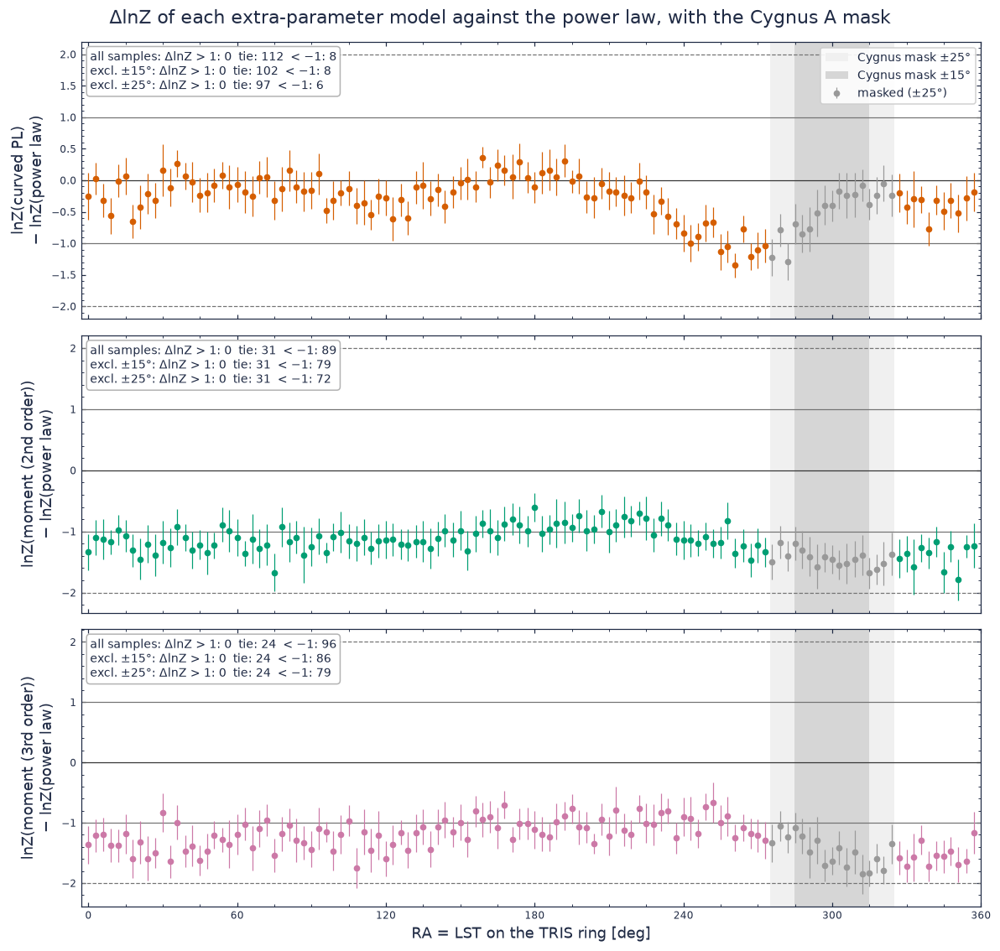

saved paper_outputs/model_comparison/diagnostic_plots/fig12_dscore_vs_ra_masked.png
saved diagnostic_plots/part6_counts_masked.csv

                statistic                      comparison     samples   n  favours model  tie  favours power law  borderline (within 0.4 of ±1)
          evidence (ΔlnZ)          curved PL vs power law all samples 120              0  112                  8                             22
          evidence (ΔlnZ)          curved PL vs power law  excl. ±15° 110              0  102                  8                             19
          evidence (ΔlnZ)          curved PL vs power law  excl. ±25° 103              0   97                  6                             16
          evidence (ΔlnZ) moment (2nd order) vs power law all samples 120              0   31                 89                            102
          evidence (ΔlnZ) moment (2nd order) vs power law  excl. ±15° 110              0   31                 79                             99
    

In [37]:
if not P1:
    print("Figure 12 skipped: no comparison CSV for Part 1.")
else:
    km = keep(ra, MASK_HALF_WIDTH)
    fig, axes = plt.subplots(3, 1, figsize=(11, 10.5), sharex=True)
    for ax, d, e, m in zip(axes, (dC, dM, dM3), (dC_err, dM_err, dM3_err), EXTRA):
        shade_mask(ax, label=(m == CURVED))
        for y, ls in ((TIE, "-"), (-TIE, "-"), (STRONG, "--"), (-STRONG, "--")):
            ax.axhline(y, color="0.45", lw=0.8, ls=ls)
        ax.axhline(0, color="0.2", lw=0.8)
        ax.errorbar(ra[km], d[km], yerr=None if ML_STAT else e[km], fmt="o", ms=4, color=COL[m], elinewidth=0.8, capsize=0)
        ax.errorbar(ra[~km], d[~km], yerr=None if ML_STAT else e[~km], fmt="o", ms=4, color="0.6", elinewidth=0.8,
                    capsize=0, label=f"masked (±{MASK_HALF_WIDTH:g}°)" if m == CURVED else None)
        txt = "\n".join(f"{lab}: {DSC} > 1: {c['favours model']}  tie: {c['tie']}  < −1: {c['favours power law']}"
                        for lab, h in MASKS.items() for c in [classify(d[keep(ra, h)])])
        ax.text(0.01, 0.97, txt, transform=ax.transAxes, va="top", fontsize=9,
                bbox=dict(fc="white", ec="0.7", boxstyle="round,pad=0.3"))
        ax.set_ylabel(f"{SC}({SHORT[m]})\n− {SC}(power law)")
    axes[0].legend(loc="upper right", frameon=True, framealpha=0.9, fontsize=9)
    ring_axis(axes[-1])
    fig.suptitle(f"{DSC} of each extra-parameter model against the power law, with the Cygnus A mask")
    fig.tight_layout()
    save(fig, "fig12_dscore_vs_ra_masked")

if J is None:
    print("Table for Figure 12 skipped: needs both comparison CSVs.")
else:
    rows = []
    for stat, D in (("evidence (ΔlnZ)", DZ), ("max likelihood (ΔlnL_max)", DL)):
        for m in EXTRA:
            for lab, h in MASKS.items():
                k_ = keep(RA6, h)
                rows.append({"statistic": stat, "comparison": f"{SHORT[m]} vs power law", "samples": lab,
                             "n": int(k_.sum()), **classify(D[m][k_])})
    t12 = pd.DataFrame(rows)
    t12.to_csv(PLOT_DIR / "part6_counts_masked.csv", index=False)
    print("saved diagnostic_plots/part6_counts_masked.csv\n")
    with pd.option_context("display.width", 220):
        print(t12.to_string(index=False))

#### Figure 13 — how much of the evidence difference is the Occam penalty?

For every ring sample (all 120, not only the Part 2 reruns). **Top:** for each extra-parameter model, ΔlnZ against the power
law (y, evidence run, Occam penalty included) against ΔlnL_max (x, max-likelihood run: the gain in best fit, no penalty).
Points are coloured by RA (a cyclic colour scale); samples inside the ±25° Cygnus mask have a black edge. On the dashed 1:1
line the evidence would follow the fit exactly; the vertical distance below it is the Occam penalty. The grey band is the
±1 tie range in ΔlnZ. **Bottom:** the Occam penalty per sample, ΔlnL_max − ΔlnZ, along the ring, with the masks shaded.
Both CSVs are joined on the sample index. Saved to `diagnostic_plots/part6_occam_penalty.csv` (per sample) and
`part6_occam_penalty_summary.csv`.

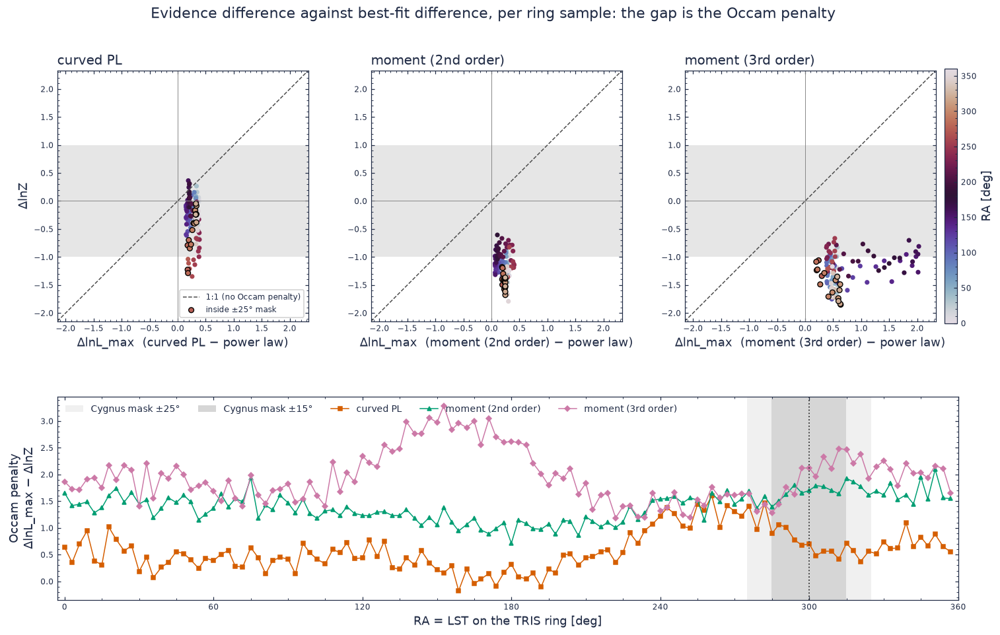

saved paper_outputs/model_comparison/diagnostic_plots/fig13_occam_penalty.png
saved diagnostic_plots/part6_occam_penalty.csv and part6_occam_penalty_summary.csv

             model     samples   n  median ΔlnL_max  median ΔlnZ  median Occam penalty  min Occam penalty  max Occam penalty  samples ΔlnL_max > 1  samples ΔlnZ > 1
         curved PL all samples 120            0.301       -0.242                 0.538             -0.175              1.605                     0                 0
         curved PL  excl. ±15° 110            0.304       -0.238                 0.515             -0.175              1.605                     0                 0
         curved PL  excl. ±25° 103            0.303       -0.201                 0.496             -0.175              1.605                     0                 0
moment (2nd order) all samples 120            0.247       -1.173                 1.414              0.712              2.094                     0                 0
moment (2nd o

In [38]:
if J is None:
    print("Figure 13 skipped: needs both", EV_CSV.name, "and", ML_CSV.name)
else:
    from matplotlib.gridspec import GridSpec
    inm = ~keep(RA6, MASK_HALF_WIDTH)
    fig = plt.figure(figsize=(16, 9.5))
    gs = GridSpec(2, 3, figure=fig, height_ratios=[1.25, 1], hspace=0.32, wspace=0.25)
    lo = min(min(DL[m].min(), DZ[m].min()) for m in EXTRA) - 0.3
    hi = max(max(DL[m].max(), DZ[m].max()) for m in EXTRA) + 0.3
    for j, m in enumerate(EXTRA):
        ax = fig.add_subplot(gs[0, j])
        ax.axhspan(-TIE, TIE, color="0.9", lw=0, zorder=0)
        ax.plot([lo, hi], [lo, hi], color="0.3", ls="--", lw=1, label="1:1 (no Occam penalty)")
        ax.axhline(0, color="0.5", lw=0.6); ax.axvline(0, color="0.5", lw=0.6)
        sc = ax.scatter(DL[m][~inm], DZ[m][~inm], c=RA6[~inm], cmap="twilight", vmin=0, vmax=360, s=22, lw=0)
        ax.scatter(DL[m][inm], DZ[m][inm], c=RA6[inm], cmap="twilight", vmin=0, vmax=360, s=26, edgecolors="black",
                   linewidths=0.9, label=f"inside ±{MASK_HALF_WIDTH:g}° mask")
        ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
        ax.set_xlabel(f"ΔlnL_max  ({SHORT[m]} − power law)")
        ax.set_ylabel("ΔlnZ" if j == 0 else "")
        ax.set_title(SHORT[m], loc="left")
        if j == 0:
            ax.legend(loc="lower right", fontsize=8, frameon=True, framealpha=0.9)
    cb = fig.colorbar(sc, ax=[fig.axes[0], fig.axes[1], fig.axes[2]], fraction=0.015, pad=0.01)
    cb.set_label("RA [deg]")
    ax = fig.add_subplot(gs[1, :])
    shade_mask(ax, label=True)
    MK6 = {CURVED: "s", MOMENT: "^", MOMENT3: "D"}
    for m in EXTRA:
        ax.plot(RA6, DL[m] - DZ[m], MK6[m] + "-", color=COL[m], ms=3.5, lw=1, label=SHORT[m])
    ax.axvline(CYG_A_RA, color="0.2", ls=":", lw=1.2)
    ax.set_ylabel("Occam penalty\nΔlnL_max − ΔlnZ"); ring_axis(ax)
    ax.legend(ncol=5, loc="upper left", frameon=False, fontsize=9)
    fig.suptitle("Evidence difference against best-fit difference, per ring sample: the gap is the Occam penalty", y=0.97)
    save(fig, "fig13_occam_penalty")

    per = pd.DataFrame({"unit": J["unit"], "RA [deg]": RA6, f"inside ±{MASK_ALT:g}°": ~keep(RA6, MASK_ALT),
                        f"inside ±{MASK_HALF_WIDTH:g}°": inm})
    rows = []
    for m in EXTRA:
        per[f"ΔlnL_max {SHORT[m]}"] = DL[m]; per[f"ΔlnZ {SHORT[m]}"] = DZ[m]; per[f"Occam penalty {SHORT[m]}"] = DL[m] - DZ[m]
        for lab, h in MASKS.items():
            k_ = keep(RA6, h); oc = (DL[m] - DZ[m])[k_]
            rows.append({"model": SHORT[m], "samples": lab, "n": int(k_.sum()), "median ΔlnL_max": np.median(DL[m][k_]),
                         "median ΔlnZ": np.median(DZ[m][k_]), "median Occam penalty": np.median(oc),
                         "min Occam penalty": oc.min(), "max Occam penalty": oc.max(),
                         "samples ΔlnL_max > 1": int((DL[m][k_] > TIE).sum()), "samples ΔlnZ > 1": int((DZ[m][k_] > TIE).sum())})
    t13 = pd.DataFrame(rows)
    per.to_csv(PLOT_DIR / "part6_occam_penalty.csv", index=False)
    t13.to_csv(PLOT_DIR / "part6_occam_penalty_summary.csv", index=False)
    print("saved diagnostic_plots/part6_occam_penalty.csv and part6_occam_penalty_summary.csv\n")
    with pd.option_context("display.width", 220):
        print(t13.round(3).to_string(index=False))

#### Figure 14 — information criteria (AIC and BIC)

From the Part 5 best fits: AIC = χ² + 2k and BIC = χ² + k ln N, with N = 4 points and k = 2 (power law), 3 (curved power
law, moment order 2) or 4 (moment order 3). Each panel shows ΔAIC (solid) and ΔBIC (dashed), extra-parameter model minus power
law, along the ring; **below zero favours the extra-parameter model**. Dashed horizontal lines at ±2 bound the
"indistinguishable" range. The masks are shaded. AICc is undefined at this N (N − k − 1 ≤ 0 for k ≥ 3), and with only 4
points both criteria are crude: an extra parameter costs a fixed 2 (AIC) or ln 4 ≈ 1.39 (BIC) in χ². Saved to
`diagnostic_plots/part6_information_criteria_counts.csv` and `part6_information_criteria_per_sample.csv`.

points per sample N = [np.int64(11)]; k = power law 2, curved PL 3, moment (2nd order) 3, moment (3rd order) 4; AICc undefined for k >= N - 1


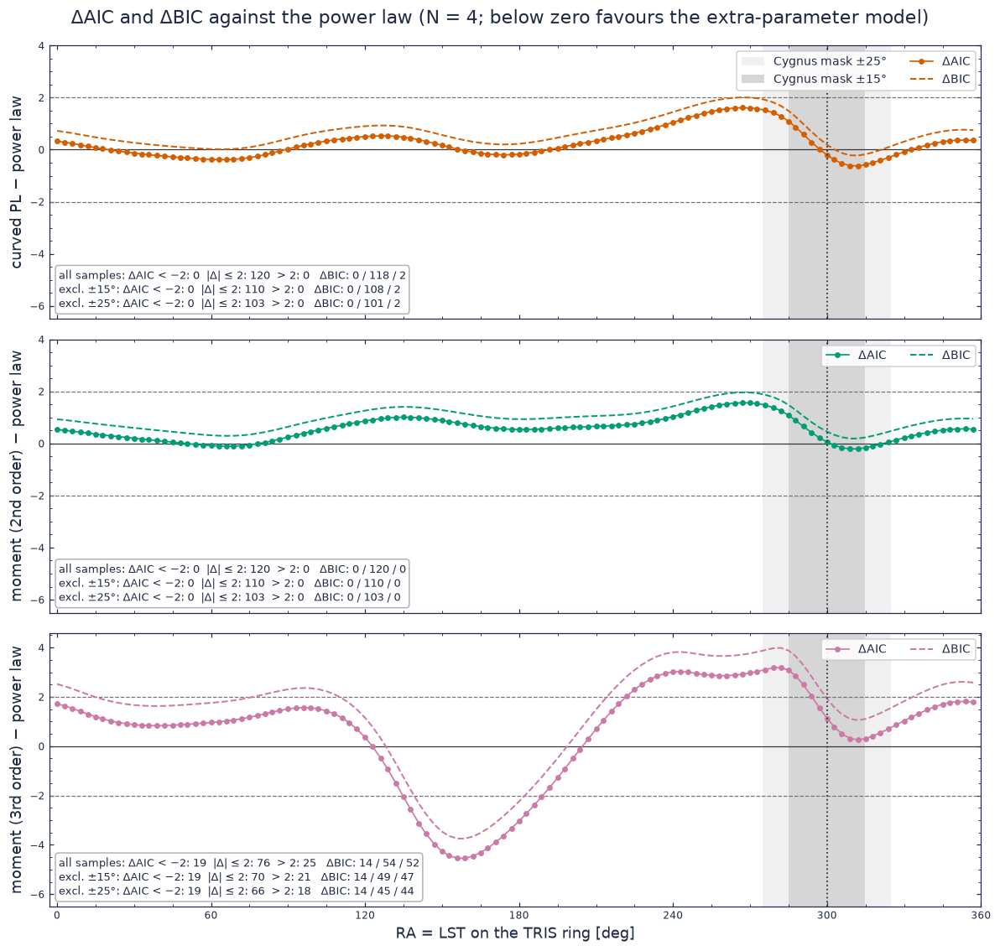

saved paper_outputs/model_comparison/diagnostic_plots/fig14_information_criteria.png
saved diagnostic_plots/part6_information_criteria_counts.csv and part6_information_criteria_per_sample.csv

criterion                      comparison     samples   n  favours model  indistinguishable  favours power law  median Δ
      AIC          curved PL vs power law all samples 120              0                120                  0      0.17
      AIC          curved PL vs power law  excl. ±15° 110              0                110                  0      0.18
      AIC          curved PL vs power law  excl. ±25° 103              0                103                  0      0.18
      AIC moment (2nd order) vs power law all samples 120              0                120                  0      0.56
      AIC moment (2nd order) vs power law  excl. ±15° 110              0                110                  0      0.56
      AIC moment (2nd order) vs power law  excl. ±25° 103              0         

In [39]:
if not P5:
    print("Figure 14 skipped: no Part 5 fits (set RUN_ML_FITS = True).")
else:
    C2 = {m: np.array([CHI[(m, u)]["chi2"] for u in ALL_UNITS]) for m in MODELS}
    NPT = np.array([CHI[(PL, u)]["n"] for u in ALL_UNITS])
    KPAR = {m: len(MODELS[m][0]) for m in MODELS}
    AIC = {m: C2[m] + 2 * KPAR[m] for m in MODELS}
    BIC = {m: C2[m] + KPAR[m] * np.log(NPT) for m in MODELS}
    dAIC = {m: AIC[m] - AIC[PL] for m in EXTRA}; dBIC = {m: BIC[m] - BIC[PL] for m in EXTRA}
    print(f"points per sample N = {sorted(set(NPT))}; k = " + ", ".join(f"{SHORT[m]} {KPAR[m]}" for m in MODELS)
          + "; AICc undefined for k >= N - 1")
    fig, axes = plt.subplots(3, 1, figsize=(11, 10.5), sharex=True)
    for ax, m in zip(axes, EXTRA):
        shade_mask(ax, label=(m == CURVED))
        for y in (IC_TIE, -IC_TIE):
            ax.axhline(y, color="0.45", lw=0.8, ls="--")
        ax.axhline(0, color="0.2", lw=0.8)
        ax.plot(RA5, dAIC[m], "o-", color=COL[m], ms=3.5, lw=1.1, label="ΔAIC")
        ax.plot(RA5, dBIC[m], "--", color=COL[m], lw=1.3, label="ΔBIC")
        ax.axvline(CYG_A_RA, color="0.2", ls=":", lw=1.2)
        txt = "\n".join(f"{lab}: ΔAIC < −2: {a['favours model']}  |Δ| ≤ 2: {a['indistinguishable']}  > 2: {a['favours power law']}"
                        f"   ΔBIC: {b['favours model']} / {b['indistinguishable']} / {b['favours power law']}"
                        for lab, h in MASKS.items() for a, b in [(classify_ic(dAIC[m][keep(RA5, h)]), classify_ic(dBIC[m][keep(RA5, h)]))])
        ax.text(0.01, 0.03, txt, transform=ax.transAxes, va="bottom", fontsize=8.5,
                bbox=dict(fc="white", ec="0.7", boxstyle="round,pad=0.3"), zorder=5)
        ax.set_ylim(-6.5, max(4.0, 1.15 * max(dAIC[m].max(), dBIC[m].max())))
        ax.set_ylabel(f"{SHORT[m]} − power law")
        ax.legend(loc="upper right", fontsize=9, frameon=True, framealpha=0.9, ncol=2)
    ring_axis(axes[-1])
    fig.suptitle("ΔAIC and ΔBIC against the power law (N = 4; below zero favours the extra-parameter model)")
    fig.tight_layout()
    save(fig, "fig14_information_criteria")

    rows = []
    for crit, D in (("AIC", dAIC), ("BIC", dBIC)):
        for m in EXTRA:
            for lab, h in MASKS.items():
                k_ = keep(RA5, h)
                rows.append({"criterion": crit, "comparison": f"{SHORT[m]} vs power law", "samples": lab, "n": int(k_.sum()),
                             **classify_ic(D[m][k_]), "median Δ": np.median(D[m][k_])})
    t14 = pd.DataFrame(rows)
    per = pd.DataFrame({"unit": ALL_UNITS, "RA [deg]": RA5, "N": NPT,
                        **{f"ΔAIC {SHORT[m]}": dAIC[m] for m in EXTRA}, **{f"ΔBIC {SHORT[m]}": dBIC[m] for m in EXTRA}})
    t14.to_csv(PLOT_DIR / "part6_information_criteria_counts.csv", index=False)
    per.to_csv(PLOT_DIR / "part6_information_criteria_per_sample.csv", index=False)
    print("saved diagnostic_plots/part6_information_criteria_counts.csv and part6_information_criteria_per_sample.csv\n")
    with pd.option_context("display.width", 220):
        print(t14.round(2).to_string(index=False))

#### Figure 15 — held-out prediction at TRIS 600 and 820 MHz

For each model's best fit (Part 5, the arrays behind Figure 10; nothing is refitted), the standardised miss
z = (model − TRIS) / σ_TRIS at both TRIS bands for every ring sample, with σ_TRIS the published uncertainty (statistical ⊕
zero level). Because TRIS is not in the fit, this is a **true prediction**: the models never saw these data. **Top:** the
distribution of z over the ring per model (box: quartiles; whiskers: 1.5 × the interquartile range; dots: further samples).
**Bottom:** z along the ring with the masks shaded. The y axis is linear within ±1 and logarithmic beyond (z spans more
than two decades). |z| ≤ 1 (dashed lines) is within the TRIS uncertainty. Saved to `diagnostic_plots/part6_tris_prediction_z.csv`
(summary) and `part6_tris_prediction_z_per_sample.csv`.

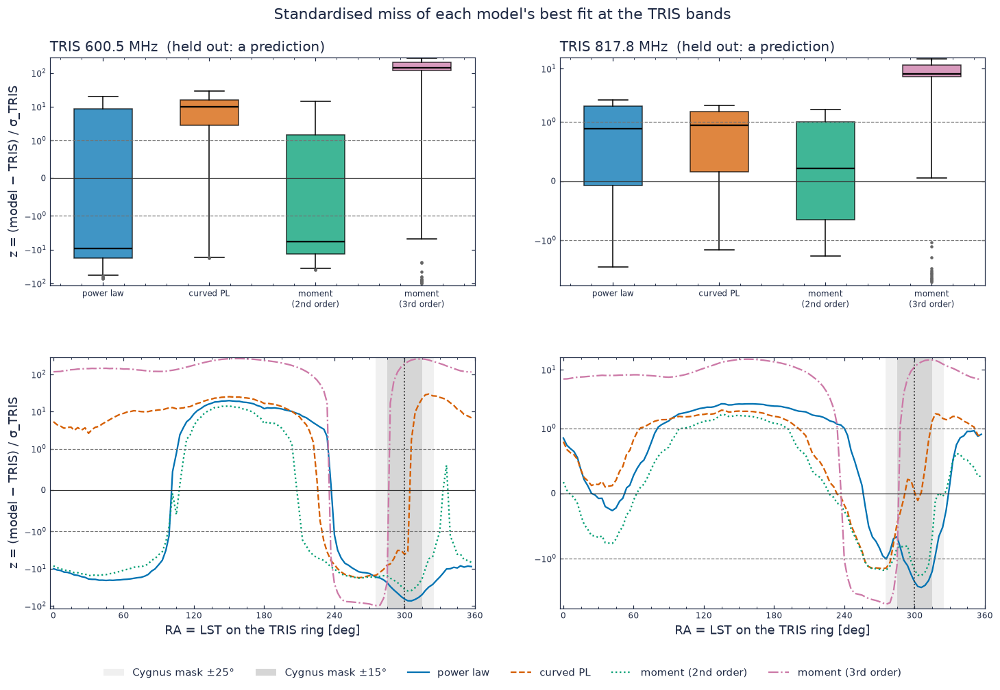

saved paper_outputs/model_comparison/diagnostic_plots/fig15_tris_prediction_z.png
saved diagnostic_plots/part6_tris_prediction_z.csv and part6_tris_prediction_z_per_sample.csv

TRIS band  held out              model     samples   n  median z   rms z  median |z|  samples |z| <= 1
600.5 MHz      True          power law all samples 120    -9.312  21.644      13.457                 3
600.5 MHz      True          power law  excl. ±15° 110    -8.199  15.157      12.624                 3
600.5 MHz      True          power law  excl. ±25° 103    -5.922  13.477      12.322                 3
600.5 MHz      True          curved PL all samples 120     9.833  14.281      11.178                 2
600.5 MHz      True          curved PL  excl. ±15° 110    10.123  14.750      12.088                 2
600.5 MHz      True          curved PL  excl. ±25° 103    10.082  14.123      11.597                 2
600.5 MHz      True moment (2nd order) all samples 120    -5.952  12.857       9.803                 9

In [40]:
if not P5 or "MT5" not in globals():
    print("Figure 15 skipped: needs the Part 5 fits and Figure 10's arrays (set RUN_ML_FITS = True and run Part 5).")
else:
    Z15 = {(m, k): (MT5[(m, k)] - TT5[k]) / SS5[k] for m in MODELS for k in TRIS_KEYS}
    fig, axes = plt.subplots(2, len(TRIS_KEYS), figsize=(8 * len(TRIS_KEYS), 9.5), squeeze=False,
                             gridspec_kw=dict(height_ratios=[1, 1.1], hspace=0.3, wspace=0.2))
    for c, k in enumerate(TRIS_KEYS):
        held = k not in FITTED_TRIS
        ax, ar = axes[0, c], axes[1, c]
        bp = ax.boxplot([Z15[(m, k)] for m in MODELS], patch_artist=True, widths=0.55,
                        flierprops=dict(marker="o", ms=3, mfc="0.4", mec="none"), medianprops=dict(color="black", lw=1.5))
        for patch, m in zip(bp["boxes"], MODELS):
            patch.set_facecolor(COL[m]); patch.set_alpha(0.75)
        ax.set_xticks(range(1, len(MODELS) + 1)); ax.set_xticklabels([SHORT[m].replace(" (", "\n(") for m in MODELS])
        shade_mask(ar, label=(c == 0))
        for m in MODELS:
            ar.plot(RA5, Z15[(m, k)], color=COL[m], ls=LS5[m], lw=1.5, label=SHORT[m])
        ar.axvline(CYG_A_RA, color="0.2", ls=":", lw=1.2); ring_axis(ar)
        for a in (ax, ar):
            a.set_yscale("symlog", linthresh=1.0)
            a.axhline(0, color="0.2", lw=0.8)
            for y in (-1, 1):
                a.axhline(y, color="0.45", lw=0.8, ls="--")
        ax.set_title(f"TRIS {NN5[k]:g} MHz" + ("  (held out: a prediction)" if held else "  (in the fit: not a prediction)"), loc="left")
    axes[0, 0].set_ylabel("z = (model − TRIS) / σ_TRIS"); axes[1, 0].set_ylabel("z = (model − TRIS) / σ_TRIS")
    h, l = axes[1, 0].get_legend_handles_labels()
    fig.legend(h, l, loc="upper center", ncol=6, frameon=False, bbox_to_anchor=(0.5, 0.04))
    fig.suptitle("Standardised miss of each model's best fit at the TRIS bands", y=0.95)
    save(fig, "fig15_tris_prediction_z")

    rows = []
    for k in TRIS_KEYS:
        for m in MODELS:
            for lab, h in MASKS.items():
                k_ = keep(RA5, h); zz = Z15[(m, k)][k_]
                rows.append({"TRIS band": f"{NN5[k]:g} MHz", "held out": k not in FITTED_TRIS, "model": SHORT[m],
                             "samples": lab, "n": int(k_.sum()), "median z": np.median(zz), "rms z": np.sqrt(np.mean(zz ** 2)),
                             "median |z|": np.median(np.abs(zz)), "samples |z| <= 1": int((np.abs(zz) <= 1).sum())})
    t15 = pd.DataFrame(rows)
    per = pd.DataFrame({"unit": ALL_UNITS, "RA [deg]": RA5,
                        **{f"z {SHORT[m]} at {NN5[k]:g} MHz": Z15[(m, k)] for k in TRIS_KEYS for m in MODELS}})
    t15.to_csv(PLOT_DIR / "part6_tris_prediction_z.csv", index=False)
    per.to_csv(PLOT_DIR / "part6_tris_prediction_z_per_sample.csv", index=False)
    print("saved diagnostic_plots/part6_tris_prediction_z.csv and part6_tris_prediction_z_per_sample.csv\n")
    with pd.option_context("display.width", 220):
        print(t15.round(3).to_string(index=False))

#### Figure 16 — stacked signed residuals against frequency

For each model's best fit (Part 5), the standardised residual (data − model)/σ of each fit point, averaged over the ring
samples: dots are the mean, bars the standard error std/√n (an **underestimate**, since neighbouring samples are correlated).
Filled markers use all samples, open markers exclude the ±25° Cygnus mask. A survey is marked as **systematic** (star, label
"S") when |mean| > 3 standard errors **and** at least 75% of the samples have the same sign. One panel per model; x is the
survey frequency. The residuals are recomputed from the cached best-fit parameters at each fitted point. Saved to
`diagnostic_plots/part6_stacked_residuals.csv`.

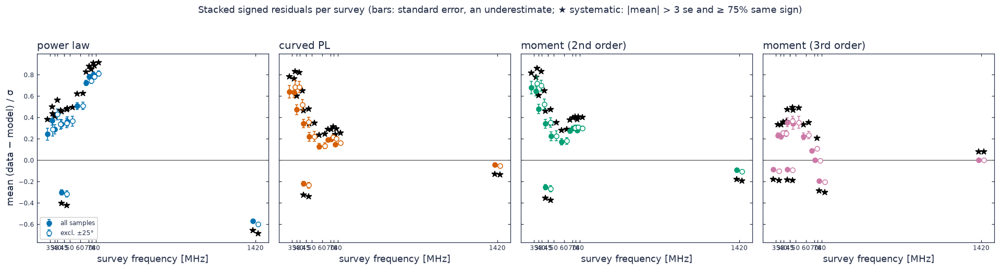

saved paper_outputs/model_comparison/diagnostic_plots/fig16_stacked_residuals.png
saved diagnostic_plots/part6_stacked_residuals.csv

             model        survey  frequency [MHz]     samples   n  mean residual [σ]  standard error [σ]  |mean| / se  fraction with the mean's sign  systematic
         power law        LWA 35             35.0 all samples 120              0.245               0.057        4.288                          0.758        True
         power law        LWA 35             35.0  excl. ±25° 103              0.290               0.064        4.514                          0.786        True
         power law  LWA1_38.fits             38.0 all samples 120              0.375               0.047        7.988                          0.833        True
         power law  LWA1_38.fits             38.0  excl. ±25° 103              0.430               0.051        8.402                          0.864        True
         power law  LWA1_40.fits             40.0 all samples

In [41]:
if not P5:
    print("Figure 16 skipped: no Part 5 fits (set RUN_ML_FITS = True).")
else:
    KEYS16 = sorted({k for u in ALL_UNITS for k in PTS5[u][3]},
                    key=lambda k: float(PTS5[ALL_UNITS[0]][0][PTS5[ALL_UNITS[0]][3].index(k)]) if k in PTS5[ALL_UNITS[0]][3] else 0.0)
    NU16 = {k: float(next(PTS5[u][0][PTS5[u][3].index(k)] for u in ALL_UNITS if k in PTS5[u][3])) for k in KEYS16}
    R16 = {}
    for m in MODELS:
        for k in KEYS16:
            v = np.full(len(ALL_UNITS), np.nan)
            for i, u in enumerate(ALL_UNITS):
                nu, t, s, keys = PTS5[u]
                if k in keys:
                    j = keys.index(k)
                    v[i] = (t[j] - model_at(m, u, nu[j])[0]) / s[j]
            R16[(m, k)] = v
    rows = []
    for m in MODELS:
        for k in KEYS16:
            for lab, h in (("all samples", None), (f"excl. ±{MASK_HALF_WIDTH:g}°", MASK_HALF_WIDTH)):
                v = R16[(m, k)][keep(RA5, h)]; v = v[np.isfinite(v)]
                mean = float(np.mean(v)); se = float(np.std(v, ddof=1) / np.sqrt(len(v)))
                frac = float(np.mean(np.sign(v) == np.sign(mean))) if mean != 0 else 0.0
                rows.append({"model": SHORT[m], "survey": POINT_NAMES.get(k, k), "frequency [MHz]": NU16[k], "samples": lab,
                             "n": len(v), "mean residual [σ]": mean, "standard error [σ]": se, "|mean| / se": abs(mean) / se if se > 0 else np.inf,
                             "fraction with the mean's sign": frac,
                             "systematic": bool(se > 0 and abs(mean) > SYS_NSE * se and frac >= SYS_FRAC)})
    t16 = pd.DataFrame(rows)
    fig, axes = plt.subplots(1, len(MODELS), figsize=(4.4 * len(MODELS), 4.6), sharey=True)
    for ax, m in zip(axes, MODELS):
        ax.axhline(0, color="0.3", lw=0.8)
        for lab, off, filled in (("all samples", 1 / 1.05, True), (f"excl. ±{MASK_HALF_WIDTH:g}°", 1.05, False)):
            sub = t16[(t16["model"] == SHORT[m]) & (t16["samples"] == lab)]
            x = sub["frequency [MHz]"].to_numpy() * off
            ax.errorbar(x, sub["mean residual [σ]"], yerr=sub["standard error [σ]"], fmt="o", ms=6, color=COL[m],
                        mfc=COL[m] if filled else "white", capsize=2, label=lab)
            for xi, yi, se, sy in zip(x, sub["mean residual [σ]"], sub["standard error [σ]"], sub["systematic"]):
                if sy:
                    ax.plot(xi, yi + np.sign(yi or 1) * (se + 0.08), "*", color="black", ms=8)
        ax.set_xscale("log"); ax.set_xlabel("survey frequency [MHz]"); ax.set_title(SHORT[m], loc="left")
        ax.set_xticks([NU16[k] for k in KEYS16]); ax.set_xticklabels([f"{NU16[k]:g}" for k in KEYS16])
        ax.minorticks_off()
    axes[0].set_ylabel("mean (data − model) / σ")
    axes[0].legend(loc="lower left", fontsize=8, frameon=True, framealpha=0.9)
    fig.suptitle(f"Stacked signed residuals per survey (bars: standard error, an underestimate; ★ systematic: "
                 f"|mean| > {SYS_NSE:g} se and ≥ {SYS_FRAC:.0%} same sign)", y=1.02, fontsize=12)
    fig.tight_layout()
    save(fig, "fig16_stacked_residuals")
    t16.to_csv(PLOT_DIR / "part6_stacked_residuals.csv", index=False)
    print("saved diagnostic_plots/part6_stacked_residuals.csv\n")
    with pd.option_context("display.width", 220):
        print(t16.round(3).to_string(index=False))

#### Figure 17 — error-bar sensitivity (maximum likelihood only)

The errors of **all** fit points multiplied by 0.7 and by 1.5 (`ERR_SCALES`), and every model refitted at every sample with
the Part 5 fitter (same `ML_STARTS`, seeded; cached in `diagnostic_plots/cache/` under a key holding the scale and the data
key); scale 1.0 is Part 5. No sampler is run. For each extra-parameter model against the power law, the bars count the
samples where Δχ² (top) or ΔAIC (bottom) favours the model (< −2, purple), is indistinguishable (|Δ| ≤ 2, grey) or favours the
power law (> 2, orange), for each scale, with all samples and with the ±25° mask (n above each bar). Scaling every error by the
same factor c leaves the best fit unchanged and divides every χ² by c², so the refit is also a check of the fitter (printed).
Saved to `diagnostic_plots/part6_error_scale_counts.csv`.

errors × 0.7: refitted 4 models at 120 samples; saved paper_outputs/model_comparison/diagnostic_plots/cache/ml_fits_errscale_0.7.npz
  check: max |χ²(×0.7) · 0.7² − χ²(×1)| = 1.67e-06  (0 expected: a uniform scale leaves the best fit unchanged)
errors × 1.5: refitted 4 models at 120 samples; saved paper_outputs/model_comparison/diagnostic_plots/cache/ml_fits_errscale_1.5.npz
  check: max |χ²(×1.5) · 1.5² − χ²(×1)| = 1.16e-06  (0 expected: a uniform scale leaves the best fit unchanged)


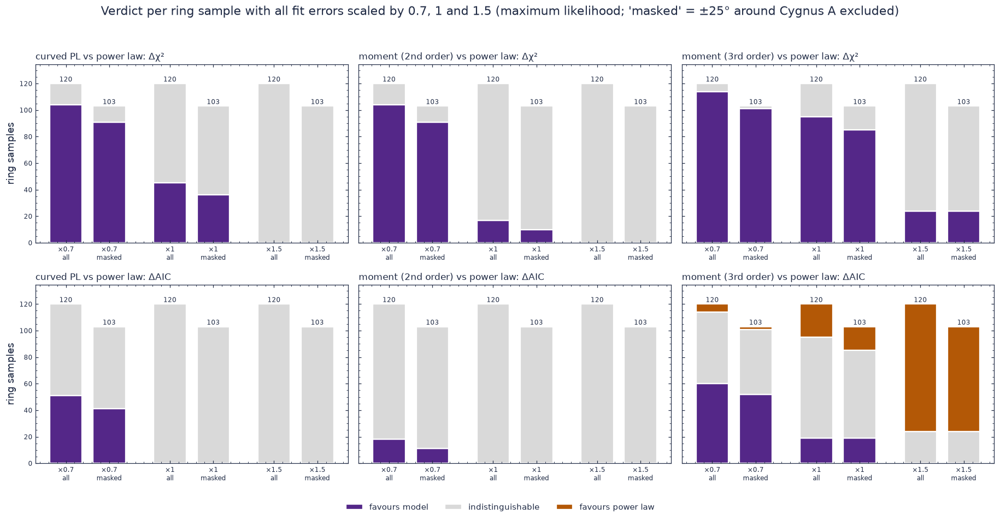

saved paper_outputs/model_comparison/diagnostic_plots/fig17_error_scale_sensitivity.png
saved diagnostic_plots/part6_error_scale_counts.csv

 error scale                      comparison statistic     samples   n  favours model  indistinguishable  favours power law  median Δ
         0.7          curved PL vs power law       Δχ² all samples 120            104                 16                  0     -3.73
         0.7          curved PL vs power law      ΔAIC all samples 120             51                 69                  0     -1.73
         0.7          curved PL vs power law       Δχ²  excl. ±25° 103             91                 12                  0     -3.71
         0.7          curved PL vs power law      ΔAIC  excl. ±25° 103             41                 62                  0     -1.71
         0.7 moment (2nd order) vs power law       Δχ² all samples 120            104                 16                  0     -2.94
         0.7 moment (2nd order) vs power law      ΔAIC 

In [42]:
if not RUN_ERR_SENS:
    print("Figure 17 skipped: RUN_ERR_SENS = False.")
elif not P5:
    print("Figure 17 skipped: no Part 5 fits (set RUN_ML_FITS = True).")
else:
    C2S = {1.0: {m: np.array([CHI[(m, u)]["chi2"] for u in ALL_UNITS]) for m in MODELS}}
    for sc in ERR_SCALES:
        key = json.dumps({"ml": ML_KEY, "err_scale": float(sc)}, sort_keys=True)
        path = CACHE_DIR / f"ml_fits_errscale_{sc:g}.npz"
        z = np.load(path, allow_pickle=False) if path.exists() else None
        if z is not None and str(z["key"]) == key:
            C2S[sc] = {m: z[f"chi2__{slug(m)}"] for m in MODELS}
            print(f"errors × {sc:g}: fits loaded from {path.relative_to(REPO)}")
        else:
            rng = np.random.default_rng(0)
            out, c2s = {"key": key}, {m: np.zeros(len(ALL_UNITS)) for m in MODELS}
            for i, u in enumerate(ALL_UNITS):
                nu, t, s, keys = PTS5[u]
                for m in MODELS:
                    p = ml_fit(m, nu, t, s * sc, rng)
                    c2s[m][i] = float(np.sum(((t - MODELS[m][1](nu, p[None, :])[0]) / (s * sc)) ** 2))
                    out[f"u{u}__{slug(m)}"] = p
            out.update({f"chi2__{slug(m)}": c2s[m] for m in MODELS})
            CACHE_DIR.mkdir(parents=True, exist_ok=True)
            np.savez(path, **out)
            C2S[sc] = c2s
            print(f"errors × {sc:g}: refitted {len(MODELS)} models at {len(ALL_UNITS)} samples; saved {path.relative_to(REPO)}")
        dev = max(float(np.max(np.abs(C2S[sc][m] * sc ** 2 - C2S[1.0][m]))) for m in MODELS)
        print(f"  check: max |χ²(×{sc:g}) · {sc:g}² − χ²(×1)| = {dev:.2e}  (0 expected: a uniform scale leaves the best fit unchanged)")

    SCALES = sorted(C2S)
    rows = []
    for sc in SCALES:
        for m in EXTRA:
            dc2 = C2S[sc][m] - C2S[sc][PL]
            daic = dc2 + 2 * (len(MODELS[m][0]) - len(MODELS[PL][0]))
            for lab, h in (("all samples", None), (f"excl. ±{MASK_HALF_WIDTH:g}°", MASK_HALF_WIDTH)):
                k_ = keep(RA5, h)
                for stat, d in (("Δχ²", dc2), ("ΔAIC", daic)):
                    rows.append({"error scale": sc, "comparison": f"{SHORT[m]} vs power law", "statistic": stat,
                                 "samples": lab, "n": int(k_.sum()), **classify_ic(d[k_]), "median Δ": float(np.median(d[k_]))})
    t17 = pd.DataFrame(rows)
    fig, axes = plt.subplots(2, len(EXTRA), figsize=(5.6 * len(EXTRA), 8.6), sharey=True)
    CLS17 = [("favours model", CLASS_COLS[0]), ("indistinguishable", CLASS_COLS[2]), ("favours power law", CLASS_COLS[4])]
    for r, stat in enumerate(("Δχ²", "ΔAIC")):
        for c, m in enumerate(EXTRA):
            ax = axes[r, c]
            sub = t17[(t17["statistic"] == stat) & (t17["comparison"] == f"{SHORT[m]} vs power law")]
            labs, x = [], 0
            for sc in SCALES:
                for lab in ("all samples", f"excl. ±{MASK_HALF_WIDTH:g}°"):
                    row = sub[(sub["error scale"] == sc) & (sub["samples"] == lab)].iloc[0]
                    bottom = 0
                    for cl, col in CLS17:
                        ax.bar(x, row[cl], bottom=bottom, color=col, edgecolor="white", linewidth=1.5, width=0.75,
                               label=cl if (r == 0 and c == 0 and sc == SCALES[0] and lab == "all samples") else None)
                        bottom += row[cl]
                    ax.text(x, bottom + 1.5, f"{row['n']}", ha="center", fontsize=8)
                    labs.append(f"×{sc:g}\n{'all' if lab == 'all samples' else 'masked'}")
                    x += 1
                x += 0.4
            ax.set_xticks([i + 0.4 * (i // 2) for i in range(len(labs))]); ax.set_xticklabels(labs, fontsize=8)
            ax.set_title(f"{SHORT[m]} vs power law: {stat}", loc="left", fontsize=11)
            ax.set_ylim(0, 1.12 * len(ALL_UNITS))
            if c == 0:
                ax.set_ylabel("ring samples")
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.0))
    fig.suptitle("Verdict per ring sample with all fit errors scaled by 0.7, 1 and 1.5 (maximum likelihood; "
                 f"'masked' = ±{MASK_HALF_WIDTH:g}° around Cygnus A excluded)", y=0.995)
    fig.tight_layout(rect=(0, 0.05, 1, 0.97))
    save(fig, "fig17_error_scale_sensitivity")
    t17.to_csv(PLOT_DIR / "part6_error_scale_counts.csv", index=False)
    print("saved diagnostic_plots/part6_error_scale_counts.csv\n")
    with pd.option_context("display.width", 220):
        print(t17.round(2).to_string(index=False))

#### Part 6 in plain numbers

*From the evidence run of 2026-10-29 12:01 and the max-likelihood run of 2026-10-28 19:03, both on the same 4 points per
sample (LWA1 35, Maipu 45, LWA1 80, Stockert 1420; TRIS not fitted). Mask: ±25° around Cygnus A (±15° in brackets where
it differs). Counts are not independent votes.*

* **(a) The mask changes the counts, not the verdict.** Evidence, curved PL vs power law: favours the model / tie / favours
  the power law = 0 / 114 / 6 with all 120 samples, 0 / 106 / 4 without ±15° and 0 / 99 / 4 without ±25°; 68 of the 120
  are borderline (within 0.4 of ±1). Moment order 2: 0 / 58 / 62 → 0 / 57 / 53 → 0 / 56 / 47. Order 3: 0 / 41 / 79 →
  0 / 41 / 69 → 0 / 39 / 64. With ln L_max (no Occam penalty) the curved PL and moment order 2 tie with the power law at
  every sample with or without the mask; order 3 is "favoured" at the same 23 samples in every case, all outside the mask.
* **(b) The evidence difference is almost all Occam penalty.** The best-fit gain over the power law is small (median
  ΔlnL_max +0.30 curved PL, +0.25 moment order 2, +0.53 order 3), and the Occam penalty is larger at every sample: median
  0.94 (range 0.38–1.44), 1.26 (0.31–1.99) and 1.76 (0.87–3.02). So ΔlnZ is negative at all 120 samples for all three
  models (median −0.64, −1.01, −1.10). The mask moves these medians by less than 0.1.
* **(c) AIC and BIC lean the same way as the evidence but call more ties.** Curved PL and moment order 2 are
  indistinguishable from the power law at every sample by both criteria (median ΔAIC +1.40 and +1.51, ΔBIC +0.78 and
  +0.89, on the power-law side); the evidence instead favours the power law over moment order 2 at 62 samples. Order 3:
  AIC favours the power law at 97 samples (80 with the mask) and ties at 23; BIC favours the power law at 13 (6). Neither
  criterion favours an extra-parameter model anywhere. AICc is undefined at N = 4.
* **(d) At 600 MHz the curved power law predicts TRIS best, by a wide margin.** Median standardised miss z: curved PL
  −0.21 (+0.29 with the mask), median |z| 5.2 (3.9), within 1σ at 21 samples; power law −21.3 (−15.4), within 1σ at
  1 sample; moment order 2 −8.4 (−8.1); order 3 +109. At 820 MHz (larger TRIS error) the three lower-order models are
  close: median |z| 0.58 for moment order 2 (0.44 with the mask; within 1σ at 94 samples), 0.75 for the power law (80)
  and 0.76 for the curved PL (83); order 3 is at 6.3.
* **(e) Under the power law all four surveys carry systematic residuals; the extra parameter moves them, not removes
  them.** Power law: LWA1 80 +0.91σ (all 120 samples positive), Stockert −0.25σ (all negative), Maipu −0.07σ (85%
  negative), LWA1 35 +0.22σ (+0.26σ and 77% positive with the mask, where it passes the test). Curved PL / moment order 2:
  LWA1 80 drops to +0.29σ / +0.43σ and Stockert to −0.03σ / −0.05σ, but LWA1 35 rises to +0.60σ; all four are still
  flagged (85–87% same sign). Order 3 passes through every point, so its residuals are below 0.015σ and its flags are
  numerical noise.
* **(f) Scaling all errors by 0.7 or 1.5 does not change the verdict for the curved PL or moment order 2.** Both stay
  indistinguishable from the power law at every sample by Δχ² and ΔAIC at ×0.7, ×1 and ×1.5 (curved PL median Δχ² −1.23,
  −0.60, −0.27). Only order 3 moves: Δχ² favours it at 73 / 23 / 0 samples and ΔAIC favours the power law at 47 / 97 / 120.
  The refits reproduce χ²/c² to 1.5 × 10⁻⁶, as a uniform scale should.
* **Skipped:** no figure was skipped (all of Figures 12–17 ran; Figure 17's refits are cached in
  `diagnostic_plots/cache/ml_fits_errscale_*.npz`).

## Summary

*From the run of 2026-10-29 (`evidence_per_unit_tod.csv` written 12:01; `comparison.statistic: evidence`, so the Occam
penalty is included). The max-likelihood run on the same points (`maxlike_per_unit_tod.csv`, 2026-10-28 19:03) is
quoted for comparison.*

**What was looked at.** Every one of the 120 ring samples has the same **4 points**: LWA1 35, Maipu 45, LWA1 80 and
Stockert 1420 (the 2026-10-29 run's `data.datasets`; **TRIS 600 and 820 are not in the fit**). Beam-matched TODs, published survey error
bars. Each ln Z carries a sampling error of about ±0.2 (median 0.18–0.20 by model), so a difference between two models
is uncertain by about ±0.27. Parts 2–4 rerun the evidence on 6 samples (Part 4: 3 samples) on the same data; Part 5
fits every model at every sample at maximum likelihood and compares the fits with the TRIS rings, which they did not
see.

**Findings, in plain language.**

* **The power law has the highest evidence at every one of the 120 samples,** but mostly not by much.
* **Curved power law vs power law: a tie almost everywhere.** In 114 of 120 samples |ΔlnZ| ≤ 1 (median −0.64); the
  power law is favoured in the other 6 (RA 33°, 39°, 252°, 273°, 288°, 297°; lowest −1.22). The curved model is never
  favoured, Cygnus included.
* **The moment expansions lose more often.** Order 2: tie in 58 samples, power law favoured in 62 (median −1.01,
  lowest −1.76). Order 3: tie in 41, power law favoured in 79 (median −1.10, lowest −1.97). Neither is ever favoured,
  and no difference anywhere exceeds 2 in size (no strong preference).
* **Among the extra-parameter models nothing separates.** Moment order 2 vs curved PL: tie in 119; order 3 vs order 2:
  tie in all 120; order 3 vs curved PL: tie in 116, curved favoured in 4.
* **The data barely use the extra parameter (Part 2).** It raises the best-fit ln L by only 0.1–0.7 at the six rerun
  samples (Cygnus included), less than its Occam cost, so the evidence falls by 0.3–1.2.
* **The curved model's deficit is all Occam penalty (Part 3).** Narrowing the C prior from ±0.5 to ±0.2 or ±0.1 moves
  curved − power law from −0.3…−0.8 to −0.06…+0.25, i.e. to zero: the 4 points are consistent with C = 0 but do not
  rule out moderate curvature. The sign flips at 4 of the 5 samples, all inside the tie band.
* **The evidences are converged, but the verdicts are borderline (Part 4).** UltraNest is within 0.33 of the exact
  integral, but most exact ΔlnZ values lie within 0.3 of −1, so individual "power law favoured" verdicts can flip
  between runs. None turns positive.
* **Without the Occam penalty it is a tie (max-likelihood run, same points).** The best-fit ln L gain over the power law
  is a median +0.30 (curved PL), +0.25 (moment order 2) and +0.53 (order 3), inside ±1 at every sample, except order 3
  at 23 samples. Order 3 has 4 parameters for 4 points, so it passes through every point (χ² = 0) and its "gain" means
  nothing.
* **χ² (Part 5).** Median χ² (mean in brackets): power law 1.07 (1.44) for ν = 2, curved PL 0.43 (0.89) and moment
  order 2 0.52 (0.99) for ν = 1, order 3 0 (ν = 0). The power law fits the 4 points well (median χ²/ν 0.53; > 2 at only
  3 samples). Its χ² comes mostly from LWA 80 (median share 85%); the curved models' from LWA 35 (62–77%).
* **TRIS, held out, separates the models (Part 5, Fig 10).** Extrapolated to 600.5 MHz, where TRIS's error is 0.07 K,
  the curved power law lands on the ring (median −0.01 K, rms 0.51 K). The power law is low almost everywhere (median
  −1.44 K, rms 2.0 K, up to 5.8 K low at Cygnus; more than 1σ off at 119 of 120 samples). Moment order 2 is in between
  (−0.56 K) and order 3 is far off (+7.3 K). At 817.8 MHz, where TRIS's error is 0.43 K, the power law, curved PL and
  moment order 2 are all within about 0.2 K median; order 3 is +2.7 K off.
* **No sums.** Neighbouring ring samples share most of the beam, so the counts above are not 120 independent votes; a
  summed ln Z or χ² would overstate the evidence many times over.

**What this means.** With only the four survey maps (35–1420 MHz) the comparison cannot tell the models apart: the
power law fits them well, the extra parameter buys almost nothing, and the evidence therefore prefers the power law,
weakly (ties at most samples, never strong). The curvature found before (at Cygnus) came from the TRIS points. The
held-out TRIS data point the other way: at 600 MHz the power law fitted to the surveys misses TRIS by about 1.4 K
(about 20σ), while the curved power law predicts it to within about 0.01 K median. So the survey points alone favour
the simplest model, but the curvature is needed to join the surveys to TRIS. Order 3 has no degrees of freedom with
4 points and should not be read.

# Part D — Model-choice decision sheet

**Origin:** `notebooks/15_model_choice_decision_sheet.ipynb` (archived: `../moonrunes_archive_2026-11-16/notebooks/15_model_choice_decision_sheet.ipynb`)

| | |
|---|---|
| **Reads** | `paper_outputs/pipeline/step3_model_comparison/` (evidence), `paper_outputs/pipeline/step5_fit/``fits/` (power law), `test_outputs/sky_models_408/cache/fits/` (curved power law, Part B), `configs/model_comp_config.yaml` |
| **Writes** | `paper_outputs/model_choice/` |
| **Feeds the paper** | stacked residuals (main.tex:503) and the criteria behind Section 5 |

**Stored outputs** are from the original notebook (not re-run after the merge). **It combines the four-point evidence (criterion 1) with the six-point UltraNest fits (criteria 2–5).**

**Pipeline:** criterion 1 uses the step 3 evidence (TRIS excluded, by design; four points in the stored outputs); criteria 2–5 use the six-point fits (TRIS included). The selection itself is pipeline step 4.

## Model-choice decision sheet: power law, curved power law, moment expansion

This notebook lays out what each criterion says about the three spectral models, with and without the
Cygnus region. **It does not choose a model.** The rule below is for the reader to apply.

### Decision rule (to be applied by the reader, not by this notebook)

A more complex model (curved power law or moment expansion) is preferred over the power law **only if it
satisfies all three conditions**:

1. **More wins than losses in ΔlnZ:** clearly more samples with ΔlnZ > +1 than with ΔlnZ < −1 (criterion 1);
2. **Better held-out prediction:** it predicts the left-out points better than the power law (criterion 3);
3. **A systematic power-law residual pattern with frequency:** the stacked power-law residuals show a
   same-sign pattern across many samples (criterion 4).

Otherwise the power law is the default. **If both the curved power law and the moment expansion pass,**
prefer the one with the better held-out prediction; **if they are still tied, report a tie and do not choose**
(they have the same number of parameters).

### The three models (from `model_comparison/models.py` and `model_comp_config.yaml`, unchanged)

With x = ln(ν / 408 MHz):

* **Power law:** T = A·e^(βx)
* **Curved power law:** T = A·e^(βx + Cx²)
* **Moment expansion (order 2):** T = A·e^(β̄x)·(1 + ω₁x + ω₂x²/2), with **β̄ fixed at −2.7**
  (`models.moment_beta_fixed` in `model_comp_config.yaml`; the next code cell checks that the value is still −2.7)
  and ω₁, ω₂ free.

The parameter counts and prior ranges are read from `models.py` / `model_comp_config.yaml` and printed below.

### Sample sets

Every criterion is computed three ways: **all 120 ring samples**; **excluding RA within ±15° of Cygnus A**
(RA 299.9°); and **excluding RA within ±25°** (the TRIS beam is about 19–23° wide, so neighbouring samples
also see Cygnus A).

### Warnings

* **The ring samples are not independent.** They are 3° apart under a ~20° beam, so neighbouring samples
  see mostly the same sky. Counts are not independent votes, and the standard errors on the stacked
  statistics (criterion 4) are **underestimates**. No summed ln Z totals are shown for the same reason.
* **Survey scale and zero-level errors are common offsets, but are treated as independent per point.**
  Each survey's published gain and zero-level errors widen its error bars at every sample, but in reality
  they shift all samples of that survey together (TODO N-15). This makes the error bars at different
  samples correlated in a way the fits ignore.

### Inputs: every evidence and every best fit comes from UltraNest

* `paper_outputs/model_comparison/results/evidence_per_unit_tod.csv`: UltraNest ln Z per sample for all three models
  (the run of 2026-10-22, with `moment_beta_fixed = -2.7`, as `evidence_summary_tod.csv` records). Used for
  criterion 1 and for the ×1 column of criterion 5.
* `paper_outputs/sky_models_408/cache/fits/unitNNN__power_law.npz` and `__curved_power_law.npz`: the
  6 fitted points per sample (ν, T, σ) and the UltraNest posteriors and best fits (notebook 12, same data,
  priors and sampler settings). Their best fits are used for criteria 2 and 4.
* **No saved moment-expansion fits exist for the 120 samples** (only 6 samples in notebook 11's cache), so the
  moment expansion is run here with UltraNest at the original error bars, to get its best fits.
* **Criterion 5 needs evidences and best fits with changed error bars,** so all three models are run here with
  UltraNest at ×0.7 and ×1.5.
* These new runs use `run_comparison.py`'s likelihood and `model_comp_config.yaml`'s priors and sampler settings, seeded per
  sample, and are cached in `paper_outputs/model_choice/cache/` (about 35 minutes the first time).
* **The only fits not made with UltraNest are the leave-one-point-out refits of criterion 3** (2,160 small fits),
  which are quick maximum-likelihood fits (scipy) within the same prior ranges.
* "Best fit" = the maximum-likelihood point UltraNest found.

Outputs go to `paper_outputs/model_choice/`. Rerun: Restart & Run All (seconds once cached).

In [43]:
%matplotlib inline
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import logging
from scipy.optimize import least_squares

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MC_DIR = REPO / "model_comparison"
FIT_CACHE = REPO / "paper_outputs" / "pipeline" / "step5_fit" / "fits"                                   # power law: run_pipeline.py step 5
CURVED_CACHE = REPO / "test_outputs" / "sky_models_408" / "cache" / "fits"   # curved power law: Part B
RA_FILE = REPO / "paper_outputs" / "pipeline" / "step5_fit" / "ring_ra.npy"
EV_CSV = REPO / "paper_outputs" / "pipeline" / "step3_model_comparison" / "evidence_per_unit_tod.csv"
SUMMARY_CSV = REPO / "paper_outputs" / "pipeline" / "step3_model_comparison" / "evidence_summary_tod.csv"
OUT_DIR = REPO / "paper_outputs" / "model_choice"

# ---- sample sets ----
CYG_A_RA = 299.9
EXCLUDE_HALF_WIDTHS = [None, 15.0, 25.0]      # None = all samples

# ---- reading the criteria ----
TIE = 1.0              # |dlnZ| <= 1: tie; > +1 favours the first model of the pair
BORDER = 0.4           # "borderline": within 0.4 of +/-1 (notebook 11 Part 4: sampling noise moves dlnZ by up to ~0.4)
IC_THRESHOLD = 2.0     # AIC/BIC: a difference larger than 2 counts as one model being better
LOO_TIE_FRAC = 0.05    # held-out prediction: mean z^2 within 5% of each other counts as a tie
PATTERN_NSEM = 3.0     # stacked residuals: a survey is "systematic" if its mean is > 3 standard errors from 0
PATTERN_SIGN = 0.75    #   ... and at least 75% of samples have residuals of that sign
PATTERN_MIN_SURVEYS = 2  # a residual "pattern with frequency" needs at least this many systematic surveys

# ---- error sensitivity ----
ERROR_SCALES = [0.7, 1.0, 1.5]
SCALE_TRIS_TOO = False   # False: scale only the non-TRIS surveys (see the criterion 5 note)

# ---- UltraNest runs made here (moment expansion at x1; all models at the other error scales) ----
RUN_ULTRANEST = True     # False: use the cache only
SEED = 12345             # UltraNest draws from numpy's global random generator; seeded with SEED + sample index
UN_DIR = OUT_DIR / "cache"

EXPECTED_BETA_FIXED = -2.7     # the value stated in the markdown cell above

PL, CURVED, MOMENT = "power law", "curved power law", "moment expansion (order 2)"
MODELS_ORDER = [PL, CURVED, MOMENT]
SHORT = {PL: "power law", CURVED: "curved PL", MOMENT: "moment exp."}
PAIRS = [(CURVED, PL), (MOMENT, PL), (MOMENT, CURVED)]     # (first, second): d = first - second
PAIR_LABEL = {p: f"{SHORT[p[0]]} vs {SHORT[p[1]]}" for p in PAIRS}
SURVEYS = ["LWA_35MHz.fits", "MAIPU_45mhZ.fits", "LWA_80MHz.fits", "TRIS_600", "TRIS_820",
           "STOCKERT_VILLA_1400MHZ.fits"]
SURVEY_NAME = {"LWA_35MHz.fits": "LWA 35", "MAIPU_45mhZ.fits": "Maipu 45", "LWA_80MHz.fits": "LWA 80",
               "TRIS_600": "TRIS 600", "TRIS_820": "TRIS 820", "STOCKERT_VILLA_1400MHZ.fits": "Stockert 1420"}
# Okabe-Ito, colourblind-safe (same model colours as notebook 11)
COL = {PL: "#0072B2", CURVED: "#D55E00", MOMENT: "#009E73"}
PAIR_COL = {(CURVED, PL): "#D55E00", (MOMENT, PL): "#009E73", (MOMENT, CURVED): "#CC79A7"}
# 3-class PuOr (diverging, grey midpoint): favours first / tie / favours second
VERDICT_COL = {"first": "#b35806", "tie": "#d9d9d9", "second": "#542788"}

plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.titlesize": 11.5,
                     "axes.labelsize": 10.5, "legend.fontsize": 9, "figure.facecolor": "white"})
OUT_DIR.mkdir(exist_ok=True)

def save(fig, name):
    # Save a figure as PNG in OUT_DIR, then show it inline.
    fig.savefig(OUT_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"saved {(OUT_DIR / name).relative_to(REPO)}")

### Models, priors and parameter counts, read from `models.py`

In [44]:
sys.dont_write_bytecode = True                   # leave no __pycache__ in model_comparison/
sys.path.insert(0, str(MC_DIR))
sys.path.insert(0, str(REPO / "src"))
from models import build_models                  # the model definitions, unchanged
from moonrunes.config import load_config
from moonrunes.sed_prototype import tod_method_key
# How the ring TODs are made (run_pipeline.yaml sed.tod_beam: beam_matched).  Cached results
# made from other TODs do not match it and are redone.
TOD_KEY = tod_method_key(load_config(REPO / "configs" / "run_pipeline.yaml"))

cfg = yaml.safe_load(open(REPO / "configs" / "model_comp_config.yaml"))
# This sheet compares three models; model_comp_config.yaml may list more moment orders (e.g. order 3), which are not used here.
MODELS = {m: v for m, v in build_models(cfg).items() if m in MODELS_ORDER}
PRIORS = cfg["priors"]
BETA_FIXED = cfg["models"].get("moment_beta_fixed")
assert list(MODELS) == MODELS_ORDER, list(MODELS)
assert BETA_FIXED is not None and float(BETA_FIXED) == EXPECTED_BETA_FIXED, \
    f"model_comp_config.yaml now has moment_beta_fixed = {BETA_FIXED}; update the markdown cell at the top"
K = {m: len(MODELS[m][0]) for m in MODELS}

run_beta = pd.read_csv(SUMMARY_CSV)["moment_beta_fixed"].iloc[0]
print(f"moment expansion: beta fixed at {float(BETA_FIXED):g} (model_comp_config.yaml); "
      f"the evidence CSV was made with moment_beta_fixed = {run_beta}")
assert str(run_beta) != "free" and float(run_beta) == float(BETA_FIXED)

rows = []
for m in MODELS:
    names = MODELS[m][0]
    rows.append({"model": m, "parameters (k)": K[m], "names": ", ".join(names),
                 "prior ranges": "; ".join(f"{n}: {PRIORS[n]['type']} [{PRIORS[n]['low']:g}, {PRIORS[n]['high']:g}]"
                                           for n in names)})
print(pd.DataFrame(rows).to_string(index=False))

moment expansion: beta fixed at -2.7 (model_comp_config.yaml); the evidence CSV was made with moment_beta_fixed = -2.7
                     model  parameters (k)               names                                                                  prior ranges
                 power law               2           A_K, beta                         A_K: loguniform [1, 1000]; beta: uniform [-3.5, -1.5]
          curved power law               3        A_K, beta, C A_K: loguniform [1, 1000]; beta: uniform [-3.5, -1.5]; C: uniform [-0.5, 0.5]
moment expansion (order 2)               3 A_K, omega1, omega2   A_K: loguniform [1, 1000]; omega1: uniform [-1, 1]; omega2: uniform [-1, 1]


### Load the data and the cached evidence

In [45]:
RA = np.load(RA_FILE)
ev = pd.read_csv(EV_CSV).set_index("unit").sort_index()
UNITS = ev.index.to_numpy()
assert np.allclose(RA[UNITS], ev["ra_deg"])
DATA = {}
for u in UNITS:
    z = np.load(FIT_CACHE / f"unit{u:03d}__power_law.npz", allow_pickle=False)
    assert "tod_key" in z.files and str(z["tod_key"]) == TOD_KEY, \
        "notebook 12's fit cache was made from other ring TODs: rerun notebook 12 first"
    keys = [str(k) for k in z["keys"]]
    assert sorted(keys) == sorted(SURVEYS), keys
    DATA[u] = dict(nu=z["nu"].astype(float), t=z["t"].astype(float), s=z["s"].astype(float), keys=keys)
LNZ = {m: ev[f"logZ {m}"].to_numpy() for m in MODELS}
print(f"{len(UNITS)} ring samples, each with the 6 points {', '.join(SURVEY_NAME[k] for k in SURVEYS)}")

def ra_distance(ra, ref):
    return np.abs((ra - ref + 180.0) % 360.0 - 180.0)

SETS = {}
for w in EXCLUDE_HALF_WIDTHS:
    label = "all samples" if w is None else f"excl. RA {CYG_A_RA:g} ± {w:g}°"
    SETS[label] = np.ones(len(UNITS), bool) if w is None else ra_distance(ev["ra_deg"].to_numpy(), CYG_A_RA) > w
for k, v in SETS.items():
    print(f"  {k:<26} {v.sum():>3} samples")
SET_NAMES = list(SETS)

AssertionError: ['TRIS_600', 'TRIS_820', 'LWA_35MHz.fits', 'LWA1_38.fits', 'LWA1_40.fits', 'LWA1_45.fits', 'MAIPU_45mhZ.fits', 'LWA1_50.fits', 'LWA1_60.fits', 'LWA1_70.fits', 'LWA1_74.fits', 'LWA_80MHz.fits', 'STOCKERT_VILLA_1400MHZ.fits']

### Best fits and evidences from UltraNest

The power law and the curved power law at the original error bars come from notebook 12's cache. Everything else
(the moment expansion at ×1, all three models at ×0.7 and ×1.5) is run here with UltraNest: the same Gaussian
likelihood as `run_comparison.py`, the priors and sampler settings of `model_comp_config.yaml`, seeded. Checks: the new
moment-expansion ln Z at ×1 against the CSV (they should agree within the sampling noise of about ±0.3, notebook 11
Part 4), and UltraNest's best-fit χ² against a direct maximum-likelihood search (scipy).

In [ ]:
import ultranest
SCFG = cfg["sampler"]

def prior_box(m):
    names = MODELS[m][0]
    is_log = np.array([PRIORS[n]["type"] == "loguniform" for n in names])
    lo = np.array([np.log(PRIORS[n]["low"]) if g else PRIORS[n]["low"] for n, g in zip(names, is_log)])
    hi = np.array([np.log(PRIORS[n]["high"]) if g else PRIORS[n]["high"] for n, g in zip(names, is_log)])
    return names, is_log, lo, hi

BOX = {m: prior_box(m) for m in MODELS}

def to_theta(m, x):
    _, is_log, _, _ = BOX[m]
    th = np.array(x, dtype=float, copy=True)
    th[..., is_log] = np.exp(th[..., is_log])
    return th

def scaled_s(d, scale):
    s = d["s"].copy()
    for i, k in enumerate(d["keys"]):
        if SCALE_TRIS_TOO or not k.startswith("TRIS"):
            s[i] *= scale
    return s

def run_ultranest(m, nu, t, s, seed):
    # The same likelihood and UltraNest call as run_comparison.log_evidence (models.py, model_comp_config.yaml priors).
    from models import prior_transform
    names, fn = MODELS[m]
    transform = prior_transform(names, PRIORS)
    norm = -np.sum(np.log(s * np.sqrt(2 * np.pi)))
    def loglike(params):
        r = (t - fn(nu, params)) / s
        return -0.5 * np.sum(r * r, axis=-1) + norm
    np.random.seed(seed)
    sampler = ultranest.ReactiveNestedSampler(names, loglike, transform, vectorized=True, log_dir=None)
    logging.getLogger("ultranest").setLevel(logging.WARNING)
    res = sampler.run(min_num_live_points=int(SCFG["min_num_live_points"]), dlogz=float(SCFG["dlogz"]),
                      show_status=False, viz_callback=False)
    return dict(logz=float(res["logz"]), logzerr=float(res["logzerr"]),
                maxpoint=np.asarray(res["maximum_likelihood"]["point"], float))

def un_path(sc, m, u):
    return UN_DIR / f"unit{u:03d}__{m.replace(' ', '_').replace('(', '').replace(')', '')}__errx{sc:g}.npz"

UN = {}            # (scale, model, unit) -> dict(logz, logzerr, maxpoint, source)
todo = []
for sc in ERROR_SCALES:
    for m in MODELS:
        for u in UNITS:
            if sc == 1.0 and m in (PL, CURVED):
                z = np.load((FIT_CACHE if m == PL else CURVED_CACHE) / f"unit{u:03d}__{m.replace(' ', '_')}.npz", allow_pickle=False)
                UN[(sc, m, u)] = dict(logz=float(z["logz"]), logzerr=float(z["logzerr"]),
                                      maxpoint=z["maxpoint"].astype(float), source="notebook 12 cache")
            elif un_path(sc, m, u).exists() and str(np.load(un_path(sc, m, u)).get("tod_key", "")) == TOD_KEY:
                z = np.load(un_path(sc, m, u), allow_pickle=False)
                UN[(sc, m, u)] = dict(logz=float(z["logz"]), logzerr=float(z["logzerr"]),
                                      maxpoint=z["maxpoint"].astype(float), source="this notebook (cached)")
            else:
                todo.append((sc, m, u))
if todo and not RUN_ULTRANEST:
    raise RuntimeError(f"{len(todo)} UltraNest runs are missing from the cache; set RUN_ULTRANEST = True")
if todo:
    UN_DIR.mkdir(exist_ok=True)
    print(f"running {len(todo)} UltraNest fits...")
    for i, (sc, m, u) in enumerate(todo):
        d = DATA[u]
        r = run_ultranest(m, d["nu"], d["t"], scaled_s(d, sc), SEED + int(u))
        np.savez(un_path(sc, m, u), **r, tod_key=TOD_KEY)
        UN[(sc, m, u)] = dict(r, source="this notebook")
        if (i + 1) % 120 == 0:
            print(f"  {i + 1} of {len(todo)} done")
print(pd.Series([v["source"] for v in UN.values()]).value_counts().to_string())

# best fits (UltraNest's maximum-likelihood point) and evidences per error scale
FIT = {}
for (sc, m, u), r in UN.items():
    d = DATA[u]; fn = MODELS[m][1]
    model = fn(d["nu"], r["maxpoint"][None, :])[0]
    FIT[(sc, m, u)] = dict(theta=r["maxpoint"], model=model,
                           chi2=float(np.sum(((d["t"] - model) / scaled_s(d, sc)) ** 2)))
ULNZ = {(sc, m): (LNZ[m] if sc == 1.0 else np.array([UN[(sc, m, u)]["logz"] for u in UNITS]))
        for sc in ERROR_SCALES for m in MODELS}

diff = np.array([UN[(1.0, MOMENT, u)]["logz"] for u in UNITS]) - LNZ[MOMENT]
print(f"\nmoment expansion, ln Z run here − CSV (both UltraNest, x1): median {np.median(diff):+.3f}, "
      f"largest |difference| {np.abs(diff).max():.3f}, within 0.5 in {int((np.abs(diff) <= 0.5).sum())} of {len(diff)}")

running 840 UltraNest fits...


  120 of 840 done


  240 of 840 done


  360 of 840 done


  480 of 840 done


  600 of 840 done


  720 of 840 done


  840 of 840 done
this notebook        840
notebook 12 cache    240

moment expansion, ln Z run here − CSV (both UltraNest, x1): median -3.724, largest |difference| 4.516, within 0.5 in 0 of 120


In [ ]:
# Check: UltraNest's best-fit chi2 against a direct maximum-likelihood search (scipy, same prior ranges).
# ml_fit is also used for the leave-one-point-out refits of criterion 3.
def starts(m, nu, t, s):
    # Starting points from straight/quadratic fits in log-log space, clipped into the prior box.
    x = np.log(nu / float(cfg["models"]["nu0_mhz"])); y = np.log(t); w = t / s
    lin = np.polyfit(x, y, 1, w=w); quad = np.polyfit(x, y, 2, w=w)
    if m == PL:
        out = [[lin[1], lin[0]]]
    elif m == CURVED:
        out = [[quad[2], quad[1], quad[0]], [lin[1], lin[0], 0.0]]
    else:
        b = float(BETA_FIXED)
        out = [[lin[1], lin[0] - b, w2] for w2 in (-0.3, 0.0, 0.3)] + [[lin[1], 0.0, 0.0]]
    _, _, lo, hi = BOX[m]
    eps = 1e-9 * (hi - lo)
    return [np.clip(np.array(p, float), lo + eps, hi - eps) for p in out]

def ml_fit(m, nu, t, s):
    names, fn = MODELS[m]
    _, _, lo, hi = BOX[m]
    def resid(x):
        return (t - fn(nu, to_theta(m, x)[None, :])[0]) / s
    best = None
    for x0 in starts(m, nu, t, s):
        r = least_squares(resid, x0, bounds=(lo, hi), method="trf", x_scale="jac")
        if best is None or r.cost < best.cost:
            best = r
    return dict(theta=to_theta(m, best.x), chi2=2 * best.cost)

rows = []
for sc in ERROR_SCALES:
    for m in MODELS:
        gap = np.array([FIT[(sc, m, u)]["chi2"] - ml_fit(m, DATA[u]["nu"], DATA[u]["t"], scaled_s(DATA[u], sc))["chi2"]
                        for u in UNITS])
        rows.append({"errors x": sc, "model": SHORT[m], "median χ²(UltraNest) − χ²(scipy)": np.median(gap),
                     "largest": gap.max()})
print("UltraNest best fit against a direct search (≥ 0: the direct search found an equal or slightly lower χ²)")
print(pd.DataFrame(rows).round(4).to_string(index=False))

UltraNest best fit against a direct search (≥ 0: the direct search found an equal or slightly lower χ²)
 errors x       model  median χ²(UltraNest) − χ²(scipy)  largest
      0.7   power law                            0.0000   0.0003
      0.7   curved PL                            0.0016   0.0052
      0.7 moment exp.                            0.0017   0.0083
      1.0   power law                            0.0000   0.0002
      1.0   curved PL                            0.0017   0.0070
      1.0 moment exp.                            0.0019   0.0053
      1.5   power law                            0.0000   0.0003
      1.5   curved PL                            0.0018   0.0064
      1.5 moment exp.                            0.0017   0.0049


### Criterion 1 — evidence (ΔlnZ per sample, UltraNest values from the CSV)

For each pair, ΔlnZ = ln Z(first) − ln Z(second) at every sample, counted as > +1 (favours the first model),
between −1 and +1 (tie) and < −1 (favours the second). **Borderline** counts samples within 0.4 of ±1, where
notebook 11 Part 4 found that sampling noise alone can move a sample across the line. The spread is the 16th–84th
percentile range. No totals are summed (the samples are correlated).

In [ ]:
def favour_from_counts(first, second, n_first, n_second):
    if n_first > n_second:
        return f"{SHORT[first]} ({n_first} vs {n_second})"
    if n_second > n_first:
        return f"{SHORT[second]} ({n_second} vs {n_first})"
    return f"tie ({n_first} vs {n_second})"

def evidence_counts(d):
    return dict(wins=int((d > TIE).sum()), ties=int((np.abs(d) <= TIE).sum()), losses=int((d < -TIE).sum()),
                borderline=int((np.abs(np.abs(d) - TIE) <= BORDER).sum()),
                median=float(np.median(d)), p16=float(np.percentile(d, 16)), p84=float(np.percentile(d, 84)))

SUMMARY = []    # rows of the CSV summary
C1 = {}
for sname, mask in SETS.items():
    for a, b in PAIRS:
        c = evidence_counts((LNZ[a] - LNZ[b])[mask])
        C1[(sname, (a, b))] = c
        SUMMARY.append({"criterion": "1 evidence (ΔlnZ)", "sample set": sname, "n samples": int(mask.sum()),
                        "comparison": PAIR_LABEL[(a, b)],
                        "result": f"ΔlnZ > +1: {c['wins']}, |ΔlnZ| ≤ 1: {c['ties']}, ΔlnZ < −1: {c['losses']}; "
                                  f"borderline (within {BORDER} of ±1): {c['borderline']}; "
                                  f"median {c['median']:+.2f} (16–84%: {c['p16']:+.2f} to {c['p84']:+.2f})",
                        "favours": favour_from_counts(a, b, c["wins"], c["losses"])})
T1 = pd.DataFrame([{"sample set": s, "comparison": PAIR_LABEL[p], **{k: (round(v, 2) if isinstance(v, float) else v)
                     for k, v in c.items()}} for (s, p), c in C1.items()])
with pd.option_context("display.width", 200):
    print(T1.to_string(index=False))

          sample set               comparison  wins  ties  losses  borderline  median   p16   p84
         all samples   curved PL vs power law     0   114       6          68   -0.64 -0.85 -0.44
         all samples moment exp. vs power law     0    58      62          90   -1.01 -1.34 -0.62
         all samples moment exp. vs curved PL     0   119       1          22   -0.30 -0.63 -0.04
excl. RA 299.9 ± 15°   curved PL vs power law     0   106       4          59   -0.62 -0.83 -0.42
excl. RA 299.9 ± 15° moment exp. vs power law     0    57      53          85   -0.98 -1.26 -0.61
excl. RA 299.9 ± 15° moment exp. vs curved PL     0   109       1          17   -0.25 -0.59 -0.03
excl. RA 299.9 ± 25°   curved PL vs power law     0    99       4          53   -0.60 -0.83 -0.40
excl. RA 299.9 ± 25° moment exp. vs power law     0    56      47          81   -0.92 -1.22 -0.60
excl. RA 299.9 ± 25° moment exp. vs curved PL     0   103       0          15   -0.25 -0.58 -0.03


### Criterion 2 — fit quality: χ², AIC and BIC per sample

From UltraNest's best fits (maximum-likelihood points). With N = 6 points per sample and k parameters (power law k = 2, curved power
law k = 3, moment expansion k = 3, read from `models.py` above): AIC = χ² + 2k, BIC = χ² + k ln N. (The
constant terms of −2 ln L are the same for every model at a given sample, so they cancel in the differences.)
For each pair, ΔAIC and ΔBIC = first − second; a value below −2 means the first model is better, above +2 the
second.

In [ ]:
N_PTS = 6
CHI = {m: np.array([FIT[(1.0, m, u)]["chi2"] for u in UNITS]) for m in MODELS}
AIC = {m: CHI[m] + 2 * K[m] for m in MODELS}
BIC = {m: CHI[m] + K[m] * np.log(N_PTS) for m in MODELS}
print("parameter counts used:", ", ".join(f"{SHORT[m]} k = {K[m]}" for m in MODELS), f"; N = {N_PTS} points")

C2 = {}
for sname, mask in SETS.items():
    for m in MODELS:
        SUMMARY.append({"criterion": "2 fit quality (χ²)", "sample set": sname, "n samples": int(mask.sum()),
                        "comparison": SHORT[m],
                        "result": f"best-fit χ² median {np.median(CHI[m][mask]):.2f} "
                                  f"(16–84%: {np.percentile(CHI[m][mask], 16):.2f} to {np.percentile(CHI[m][mask], 84):.2f}), "
                                  f"k = {K[m]}, dof = {N_PTS - K[m]}",
                        "favours": "(not a comparison; see AIC/BIC rows)"})
    for a, b in PAIRS:
        for ic_name, IC in (("AIC", AIC), ("BIC", BIC)):
            d = (IC[a] - IC[b])[mask]
            better_first, better_second = int((d < -IC_THRESHOLD).sum()), int((d > IC_THRESHOLD).sum())
            C2[(sname, (a, b), ic_name)] = dict(first=better_first, within=int((np.abs(d) <= IC_THRESHOLD).sum()),
                                                 second=better_second, median=float(np.median(d)))
            SUMMARY.append({"criterion": f"2 fit quality ({ic_name})", "sample set": sname, "n samples": int(mask.sum()),
                            "comparison": PAIR_LABEL[(a, b)],
                            "result": f"Δ{ic_name} (first − second) < −2: {better_first}, within ±2: "
                                      f"{C2[(sname, (a, b), ic_name)]['within']}, > +2: {better_second}; "
                                      f"median Δ{ic_name} {np.median(d):+.2f}",
                            "favours": favour_from_counts(a, b, better_first, better_second)})
T2 = pd.DataFrame([{"sample set": s, "comparison": PAIR_LABEL[p], "criterion": ic, **c} for (s, p, ic), c in C2.items()])
with pd.option_context("display.width", 200):
    print(T2.round(2).to_string(index=False))

parameter counts used: power law k = 2, curved PL k = 3, moment exp. k = 3 ; N = 6 points
          sample set               comparison criterion  first  within  second  median
         all samples   curved PL vs power law       AIC     26      94       0   -1.04
         all samples   curved PL vs power law       BIC     28      92       0   -1.25
         all samples moment exp. vs power law       AIC     21      99       0   -0.56
         all samples moment exp. vs power law       BIC     22      98       0   -0.77
         all samples moment exp. vs curved PL       AIC      0     120       0    0.47
         all samples moment exp. vs curved PL       BIC      0     120       0    0.47
excl. RA 299.9 ± 15°   curved PL vs power law       AIC     18      92       0   -0.56
excl. RA 299.9 ± 15°   curved PL vs power law       BIC     20      90       0   -0.77
excl. RA 299.9 ± 15° moment exp. vs power law       AIC     13      97       0   -0.07
excl. RA 299.9 ± 15° moment exp. vs powe

### Criterion 3 — predictive check (leave one point out)

At every sample, each of the 6 points is left out in turn; each model is refitted by maximum likelihood to the
other 5 and predicts the missing point. The **standardised error** is z = (data − prediction) / σ of that point
(the prediction's own uncertainty is not added). A model predicts better when its **mean z²** is lower; the
**median |z|** is shown too, because the mean z² is dominated by the points with the smallest error bars (TRIS 600,
whose σ is about 0.07 K, and Maipu 45). Leaving
out LWA 35 or Stockert 1420 means extrapolating beyond the remaining points, which is a harder test than leaving
out a point in the middle.

In [ ]:
LOO = []   # one row per (unit, left-out survey, model)
for u in UNITS:
    d = DATA[u]
    for i, key in enumerate(d["keys"]):
        keep = np.arange(len(d["t"])) != i
        for m in MODELS:
            f = ml_fit(m, d["nu"][keep], d["t"][keep], d["s"][keep])
            pred = MODELS[m][1](d["nu"][i:i + 1], f["theta"][None, :])[0][0]
            LOO.append({"unit": u, "survey": key, "model": m, "z": (d["t"][i] - pred) / d["s"][i]})
LOO = pd.DataFrame(LOO)
LOO.to_csv(OUT_DIR / "loo_standardised_errors.csv", index=False)

def loo_table(mask, stat="mean z2"):
    sub = LOO[LOO["unit"].isin(UNITS[mask])]
    f = (lambda z: float(np.mean(z ** 2))) if stat == "mean z2" else (lambda z: float(np.median(np.abs(z))))
    rows = {}
    for key in ["all points"] + SURVEYS:
        s2 = sub if key == "all points" else sub[sub["survey"] == key]
        rows[key if key == "all points" else SURVEY_NAME[key]] = {m: f(s2[s2["model"] == m]["z"].to_numpy())
                                                                  for m in MODELS}
    return pd.DataFrame(rows).T

def loo_favour(a, b, za, zb):
    if abs(za - zb) <= LOO_TIE_FRAC * min(za, zb):
        return f"tie (mean z² {za:.2f} vs {zb:.2f})"
    return (f"{SHORT[a]} (mean z² {za:.2f} vs {zb:.2f})" if za < zb else f"{SHORT[b]} (mean z² {zb:.2f} vs {za:.2f})")

C3 = {}
for sname, mask in SETS.items():
    tab = loo_table(mask)
    med = loo_table(mask, "median |z|")
    C3[sname] = tab
    print(f"\n{sname}: left-out point, mean z² | median |z|  (lower = better prediction)")
    print(pd.concat([tab.rename(columns=lambda m: f"{SHORT[m]} mean z²"),
                     med.rename(columns=lambda m: f"{SHORT[m]} median |z|")], axis=1).round(2).to_string())
    for a, b in PAIRS:
        for row in tab.index:
            SUMMARY.append({"criterion": "3 held-out prediction" + ("" if row == "all points" else f" ({row})"),
                            "sample set": sname, "n samples": int(mask.sum()), "comparison": PAIR_LABEL[(a, b)],
                            "result": f"mean z²: {SHORT[a]} {tab.loc[row, a]:.2f}, {SHORT[b]} {tab.loc[row, b]:.2f}; "
                                      f"median |z|: {SHORT[a]} {med.loc[row, a]:.2f}, {SHORT[b]} {med.loc[row, b]:.2f}",
                            "favours": loo_favour(a, b, tab.loc[row, a], tab.loc[row, b])})


all samples: left-out point, mean z² | median |z|  (lower = better prediction)
               power law mean z²  curved PL mean z²  moment exp. mean z²  power law median |z|  curved PL median |z|  moment exp. median |z|
all points                 90.28              22.63                39.17                  1.17                  0.60                    0.93
LWA 35                      0.45               0.97                 1.60                  0.30                  0.64                    1.02
Maipu 45                  143.79              92.70               112.33                  9.57                  5.94                    7.53
LWA 80                      0.74               0.19                 0.26                  0.83                  0.29                    0.24
TRIS 600                  393.61              41.61               120.22                 18.44                  4.75                   10.23
TRIS 820                    2.45               0.26                 0.63  

### Criterion 4 — stacked residuals against frequency

For each model's best fit, the standardised residual (data − model)/σ of every survey, stacked over the samples:
the mean and its standard error (std / √n — an **underestimate**, the samples are correlated). A survey is called
**systematic** when its mean is more than 3 standard errors from zero **and** at least 75% of the samples have a
residual of that sign. A **pattern with frequency** means at least 2 systematic surveys. These thresholds are set in
the settings cell. For the power law, a pattern means curvature may be needed; for the other two models, it shows
what is left after the extra parameter.

In [ ]:
def stacked(sc, m, mask):
    z = np.array([(DATA[u]["t"] - FIT[(sc, m, u)]["model"]) / scaled_s(DATA[u], sc) for u in UNITS[mask]])
    order = [DATA[UNITS[0]]["keys"].index(k) for k in SURVEYS]
    z = z[:, order]
    n = len(z)
    mean, sem = z.mean(0), z.std(0, ddof=1) / np.sqrt(n)
    same_sign = np.where(mean >= 0, (z > 0).mean(0), (z < 0).mean(0))
    systematic = (np.abs(mean) > PATTERN_NSEM * sem) & (same_sign >= PATTERN_SIGN)
    return dict(mean=mean, sem=sem, same_sign=same_sign, systematic=systematic,
                pattern=int(systematic.sum()) >= PATTERN_MIN_SURVEYS)

NU_OF = {k: float(np.mean([DATA[u]["nu"][DATA[u]["keys"].index(k)] for u in UNITS])) for k in SURVEYS}
C4 = {(sc, m, s): stacked(sc, m, mask) for sc in ERROR_SCALES for m in MODELS for s, mask in SETS.items()}

def pattern_text(r):
    sys_ = [f"{SURVEY_NAME[k]} {r['mean'][i]:+.2f}±{r['sem'][i]:.2f} ({100 * r['same_sign'][i]:.0f}% same sign)"
            for i, k in enumerate(SURVEYS) if r["systematic"][i]]
    return (f"{int(r['systematic'].sum())} systematic survey(s)" + (": " + "; ".join(sys_) if sys_ else ""))

rows = []
for (sc, m, sname), r in C4.items():
    for i, k in enumerate(SURVEYS):
        rows.append({"error scale": sc, "model": m, "sample set": sname, "survey": SURVEY_NAME[k],
                     "frequency [MHz]": NU_OF[k], "mean z": r["mean"][i], "standard error": r["sem"][i],
                     "fraction with this sign": r["same_sign"][i], "systematic": bool(r["systematic"][i])})
pd.DataFrame(rows).to_csv(OUT_DIR / "stacked_residuals.csv", index=False)

for sname in SET_NAMES:
    for m in MODELS:
        r = C4[(1.0, m, sname)]
        fav = (("curvature needed (power-law residuals have a pattern)" if r["pattern"] else
                "power law (no pattern in its residuals)") if m == PL else
               ("pattern remains" if r["pattern"] else "no pattern remains"))
        SUMMARY.append({"criterion": "4 stacked residuals", "sample set": sname, "n samples": int(SETS[sname].sum()),
                        "comparison": f"{SHORT[m]} residuals", "result": pattern_text(r), "favours": fav})
    print(f"\n{sname}")
    tab = pd.DataFrame({SHORT[m]: [f"{C4[(1.0, m, sname)]['mean'][i]:+.2f} ± {C4[(1.0, m, sname)]['sem'][i]:.2f}"
                                   + (" *" if C4[(1.0, m, sname)]["systematic"][i] else "") for i in range(len(SURVEYS))]
                        for m in MODELS}, index=[SURVEY_NAME[k] for k in SURVEYS])
    print(tab.to_string())
print("\n* = systematic (mean > 3 standard errors from 0 and ≥ 75% of samples with that sign)")


all samples
                    power law       curved PL     moment exp.
LWA 35         +0.27 ± 0.06 *  +0.66 ± 0.06 *  +0.84 ± 0.06 *
Maipu 45       -0.12 ± 0.01 *  -0.07 ± 0.01 *  -0.09 ± 0.01 *
LWA 80         +0.80 ± 0.03 *    +0.17 ± 0.02    +0.10 ± 0.03
TRIS 600       +0.13 ± 0.00 *    +0.01 ± 0.00  +0.03 ± 0.00 *
TRIS 820       -1.46 ± 0.05 *  -0.15 ± 0.01 *  -0.39 ± 0.02 *
Stockert 1420  -0.74 ± 0.03 *  +0.10 ± 0.01 *    -0.05 ± 0.01

excl. RA 299.9 ± 15°
                    power law       curved PL     moment exp.
LWA 35         +0.29 ± 0.06 *  +0.67 ± 0.06 *  +0.85 ± 0.06 *
Maipu 45       -0.11 ± 0.01 *  -0.07 ± 0.01 *  -0.09 ± 0.01 *
LWA 80         +0.81 ± 0.03 *  +0.18 ± 0.03 *    +0.13 ± 0.03
TRIS 600       +0.12 ± 0.00 *    +0.01 ± 0.00  +0.03 ± 0.00 *
TRIS 820       -1.37 ± 0.04 *  -0.16 ± 0.02 *  -0.40 ± 0.02 *
Stockert 1420  -0.67 ± 0.02 *  +0.11 ± 0.01 *    -0.04 ± 0.01

excl. RA 299.9 ± 25°
                    power law       curved PL     moment exp.
LWA 35       

### Criterion 5 — sensitivity to the error bars

Criteria 1 and 4 repeated with the **non-TRIS survey errors** (LWA, Maipu, Stockert) multiplied by 0.7 and by 1.5.
TRIS keeps its own errors: scaling every error bar by the same factor would leave every best fit unchanged
and only rescale the residuals, so it would test nothing (set `SCALE_TRIS_TOO = True` to do it anyway). Every
evidence is from UltraNest: ×1 from the CSV (the same numbers as criterion 1), ×0.7 and ×1.5 from the runs above.

In [ ]:
C5 = {}
for sname, mask in SETS.items():
    for sc in ERROR_SCALES:
        for a, b in PAIRS:
            c = evidence_counts((ULNZ[(sc, a)] - ULNZ[(sc, b)])[mask])
            C5[(sname, sc, (a, b))] = c
            SUMMARY.append({"criterion": f"5 error sensitivity: evidence, errors x{sc:g}", "sample set": sname,
                            "n samples": int(mask.sum()), "comparison": PAIR_LABEL[(a, b)],
                            "result": f"ΔlnZ > +1: {c['wins']}, |ΔlnZ| ≤ 1: {c['ties']}, ΔlnZ < −1: {c['losses']}; "
                                      f"borderline: {c['borderline']}; median {c['median']:+.2f} (UltraNest)",
                            "favours": favour_from_counts(a, b, c["wins"], c["losses"])})
        for m in MODELS:
            r = C4[(sc, m, sname)]
            fav = (("curvature needed (power-law residuals have a pattern)" if r["pattern"] else
                    "power law (no pattern in its residuals)") if m == PL else
                   ("pattern remains" if r["pattern"] else "no pattern remains"))
            SUMMARY.append({"criterion": f"5 error sensitivity: stacked residuals, errors x{sc:g}", "sample set": sname,
                            "n samples": int(mask.sum()), "comparison": f"{SHORT[m]} residuals",
                            "result": pattern_text(r), "favours": fav})
T5 = pd.DataFrame([{"sample set": s, "errors x": sc, "comparison": PAIR_LABEL[p], "> +1": c["wins"],
                    "tie": c["ties"], "< −1": c["losses"], "borderline": c["borderline"], "median": round(c["median"], 2)}
                   for (s, sc, p), c in C5.items()])
with pd.option_context("display.width", 200):
    print(T5.to_string(index=False))

          sample set  errors x               comparison  > +1  tie  < −1  borderline  median
         all samples       0.7   curved PL vs power law    22   87    11          35   -0.08
         all samples       0.7 moment exp. vs power law     8   51    61          51   -1.08
         all samples       0.7 moment exp. vs curved PL     0   43    77          81   -1.09
         all samples       1.0   curved PL vs power law     0  114     6          68   -0.64
         all samples       1.0 moment exp. vs power law     0   58    62          90   -1.01
         all samples       1.0 moment exp. vs curved PL     0  119     1          22   -0.30
         all samples       1.5   curved PL vs power law    11  100     9          32   -0.25
         all samples       1.5 moment exp. vs power law     4   43    73          76   -1.12
         all samples       1.5 moment exp. vs curved PL     0   90    30          94   -0.84
excl. RA 299.9 ± 15°       0.7   curved PL vs power law    14   85    

### Figure 1 — the decision sheet
One row per sample set, one column per criterion. **Evidence and AIC/BIC:** bars split the samples into favours the
first model (orange), tie (grey) and favours the second (purple); the number of borderline samples is written next
to each evidence bar. **Held-out prediction:** mean z² of the left-out point per survey and overall (lower is better).
**Stacked residuals:** mean (data − model)/σ per survey with standard errors, filled markers are systematic.
**Error sensitivity:** samples with ΔlnZ > +1 (solid) and < −1 (dashed) against the error scale.

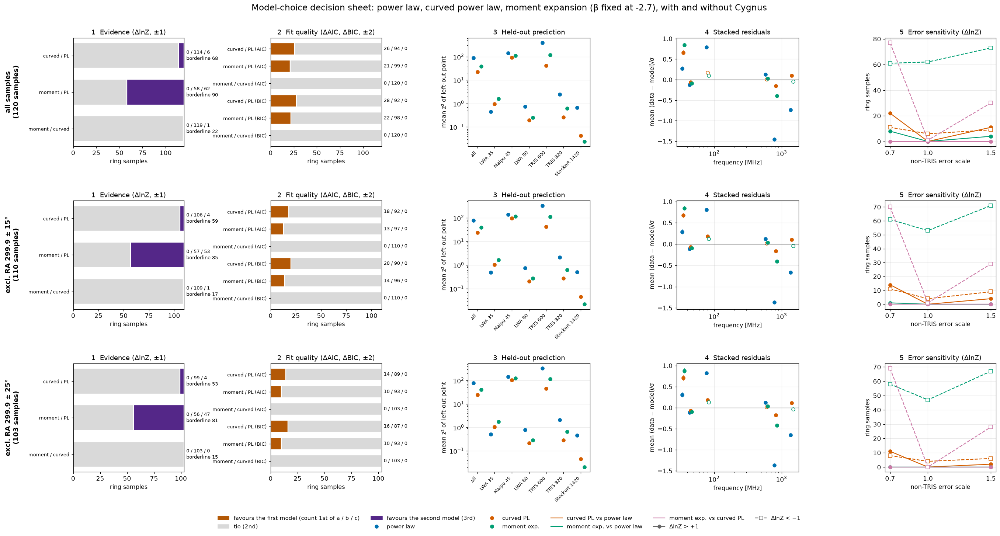

saved model_comparison/model_choice/decision_sheet.png


In [ ]:
def verdict_bars(ax, items, title, border=None):
    # items: list of (label, n_first, n_tie, n_second); counts written to the right of each bar
    y = np.arange(len(items))[::-1]
    for i, (yi, (lab, a, t, b)) in enumerate(zip(y, items)):
        left = 0
        for n, key in ((a, "first"), (t, "tie"), (b, "second")):
            ax.barh(yi, n, left=left, color=VERDICT_COL[key], edgecolor="white", linewidth=1.5, height=0.7)
            left += n
        txt = f"{a} / {t} / {b}" + (f"\nborderline {border[i]}" if border is not None else "")
        ax.text(1.02, yi, txt, transform=ax.get_yaxis_transform(), va="center", fontsize=8.5)
    ax.set_yticks(y); ax.set_yticklabels([it[0] for it in items], fontsize=8.5)
    ax.set_xlim(0, sum(items[0][1:])); ax.set_title(title)

SHEET_LABEL = {(CURVED, PL): "curved / PL", (MOMENT, PL): "moment / PL", (MOMENT, CURVED): "moment / curved"}
fig, axes = plt.subplots(len(SET_NAMES), 5, figsize=(25, 4.3 * len(SET_NAMES)),
                         gridspec_kw=dict(width_ratios=[1.0, 1.0, 1.1, 1.1, 1.0], wspace=0.75, hspace=0.5))
xs = np.arange(len(SURVEYS) + 1)
for r_, sname in enumerate(SET_NAMES):
    ax = axes[r_, 0]
    items = [(SHEET_LABEL[p], C1[(sname, p)]["wins"], C1[(sname, p)]["ties"], C1[(sname, p)]["losses"]) for p in PAIRS]
    verdict_bars(ax, items, "1  Evidence (ΔlnZ, ±1)", [C1[(sname, p)]["borderline"] for p in PAIRS])
    ax.set_xlabel("ring samples")
    ax.text(-0.55, 0.5, f"{sname}\n({int(SETS[sname].sum())} samples)", transform=ax.transAxes, rotation=90,
            ha="center", va="center", fontsize=12, fontweight="bold")

    ax = axes[r_, 1]
    items = [(f"{SHEET_LABEL[p]} ({ic})", C2[(sname, p, ic)]["first"], C2[(sname, p, ic)]["within"],
              C2[(sname, p, ic)]["second"]) for ic in ("AIC", "BIC") for p in PAIRS]
    verdict_bars(ax, items, "2  Fit quality (ΔAIC, ΔBIC, ±2)")
    ax.set_xlabel("ring samples")

    ax = axes[r_, 2]
    tab = C3[sname]
    for j, m in enumerate(MODELS):
        ax.plot(xs + (j - 1) * 0.22, tab[m].to_numpy(), "o", color=COL[m], ms=6, label=SHORT[m])
    ax.set_xticks(xs); ax.set_xticklabels(["all"] + [SURVEY_NAME[k] for k in SURVEYS], rotation=45, ha="right", fontsize=8.5)
    ax.set_yscale("log"); ax.set_ylabel("mean z² of left-out point"); ax.set_title("3  Held-out prediction")
    ax.grid(alpha=0.25, axis="y")

    ax = axes[r_, 3]
    for j, m in enumerate(MODELS):
        rr = C4[(1.0, m, sname)]
        f = np.array([NU_OF[k] for k in SURVEYS]) * (1 + (j - 1) * 0.04)
        ax.errorbar(f, rr["mean"], yerr=rr["sem"], fmt="none", ecolor=COL[m], elinewidth=1)
        for fi, mi, si in zip(f, rr["mean"], rr["systematic"]):
            ax.plot(fi, mi, "o", color=COL[m], mfc=COL[m] if si else "white", ms=6)
    ax.axhline(0, color="0.3", lw=0.8)
    ax.set_xscale("log"); ax.set_xlabel("frequency [MHz]"); ax.set_ylabel("mean (data − model)/σ")
    ax.set_title("4  Stacked residuals"); ax.grid(alpha=0.25)

    ax = axes[r_, 4]
    for p in PAIRS:
        w = [C5[(sname, sc, p)]["wins"] for sc in ERROR_SCALES]
        l = [C5[(sname, sc, p)]["losses"] for sc in ERROR_SCALES]
        ax.plot(ERROR_SCALES, w, "o-", color=PAIR_COL[p], label=f"{PAIR_LABEL[p]}: > +1")
        ax.plot(ERROR_SCALES, l, "s--", color=PAIR_COL[p], mfc="white", label=f"{PAIR_LABEL[p]}: < −1")
    ax.set_xticks(ERROR_SCALES); ax.set_xlabel("non-TRIS error scale"); ax.set_ylabel("ring samples")
    ax.set_title("5  Error sensitivity (ΔlnZ)"); ax.grid(alpha=0.25)

from matplotlib.patches import Patch
from matplotlib.lines import Line2D
h1 = [Patch(color=VERDICT_COL["first"], label="favours the first model (count 1st of a / b / c)"),
      Patch(color=VERDICT_COL["tie"], label="tie (2nd)"),
      Patch(color=VERDICT_COL["second"], label="favours the second model (3rd)")]
h2 = [Line2D([], [], marker="o", ls="", color=COL[m], label=SHORT[m]) for m in MODELS]
h3 = [Line2D([], [], color=PAIR_COL[p], label=PAIR_LABEL[p]) for p in PAIRS] + \
     [Line2D([], [], color="0.4", marker="o", label="ΔlnZ > +1"), Line2D([], [], color="0.4", ls="--", marker="s", mfc="white", label="ΔlnZ < −1")]
fig.legend(handles=h1 + h2 + h3, loc="lower center", ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.02), fontsize=10)
fig.suptitle("Model-choice decision sheet: power law, curved power law, moment expansion (β fixed at "
             f"{float(BETA_FIXED):g}), with and without Cygnus", fontsize=15, y=0.995)
fig.subplots_adjust(bottom=0.1, left=0.07, right=0.98, top=0.93)
save(fig, "decision_sheet.png")

### Figure 2 — stacked residuals against frequency, in detail
Each panel is one model (columns) and sample set (rows). Points are the mean standardised residual per survey with
its standard error (an underestimate, the samples are correlated), for the original error bars and with the non-TRIS
errors ×0.7 and ×1.5. Filled markers are systematic surveys; a run of same-sign points across frequency is the
pattern criterion 4 looks for.

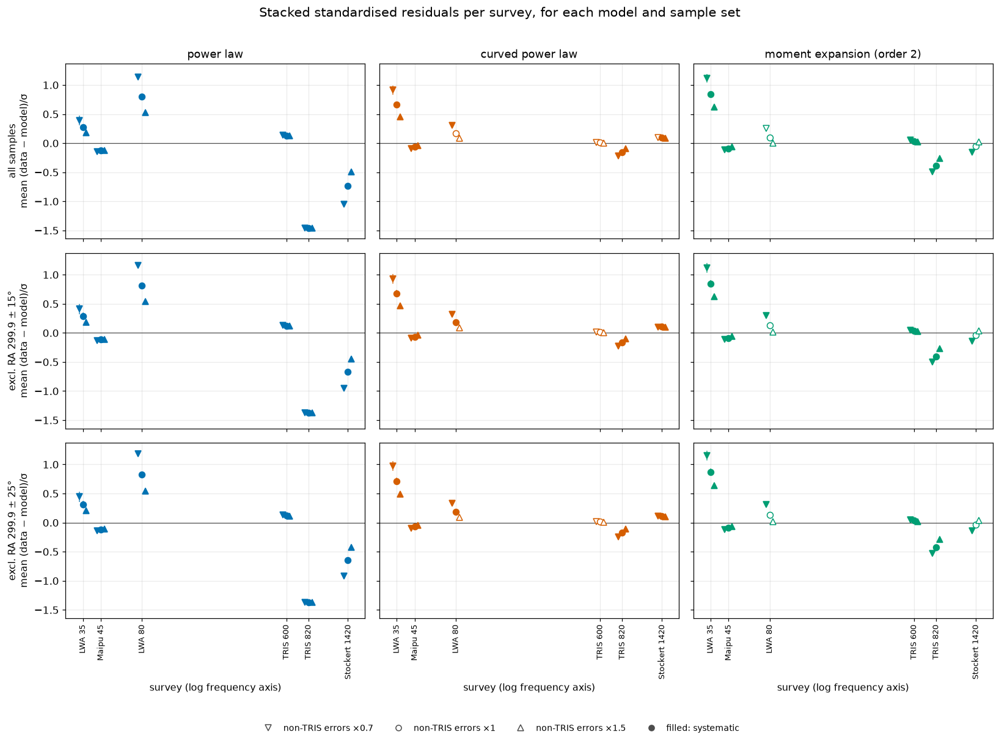

saved model_comparison/model_choice/stacked_residuals_vs_freq.png


In [ ]:
SC_MARK = {0.7: "v", 1.0: "o", 1.5: "^"}
fig, axes = plt.subplots(len(SET_NAMES), len(MODELS), figsize=(15, 3.6 * len(SET_NAMES)), sharex=True, sharey=True)
for r_, sname in enumerate(SET_NAMES):
    for c_, m in enumerate(MODELS):
        ax = axes[r_, c_]
        ax.axhline(0, color="0.3", lw=0.8)
        for j, sc in enumerate(ERROR_SCALES):
            rr = C4[(sc, m, sname)]
            f = np.array([NU_OF[k] for k in SURVEYS]) * (1 + (j - 1) * 0.05)
            ax.errorbar(f, rr["mean"], yerr=rr["sem"], fmt="none", ecolor=COL[m], elinewidth=1, alpha=0.8)
            for fi, mi, si in zip(f, rr["mean"], rr["systematic"]):
                ax.plot(fi, mi, SC_MARK[sc], color=COL[m], mfc=COL[m] if si else "white", ms=6.5)
        ax.set_xscale("log"); ax.grid(alpha=0.25)
        if r_ == 0:
            ax.set_title(f"{m}", fontsize=12)
        if c_ == 0:
            ax.set_ylabel(f"{sname}\nmean (data − model)/σ")
        ax.set_xticks([NU_OF[k] for k in SURVEYS]); ax.minorticks_off()
        ax.set_xticklabels([SURVEY_NAME[k] for k in SURVEYS], rotation=90, fontsize=8.5)
        if r_ == len(SET_NAMES) - 1:
            ax.set_xlabel("survey (log frequency axis)")
handles = [Line2D([], [], marker=SC_MARK[sc], ls="", color="0.3", mfc="white", label=f"non-TRIS errors ×{sc:g}")
           for sc in ERROR_SCALES] + [Line2D([], [], marker="o", ls="", color="0.3", label="filled: systematic")]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.03))
fig.suptitle("Stacked standardised residuals per survey, for each model and sample set", fontsize=14)
fig.tight_layout(rect=(0, 0.02, 1, 0.97))
save(fig, "stacked_residuals_vs_freq.png")

### Figure 3 — ΔlnZ along the ring, with the Cygnus windows
ΔlnZ for each pair at every sample (UltraNest values from the CSV). The darker shading is ±15° around Cygnus A, the
lighter ±25°; the grey band is the tie range and the hatched strips the borderline zones within 0.4 of ±1.

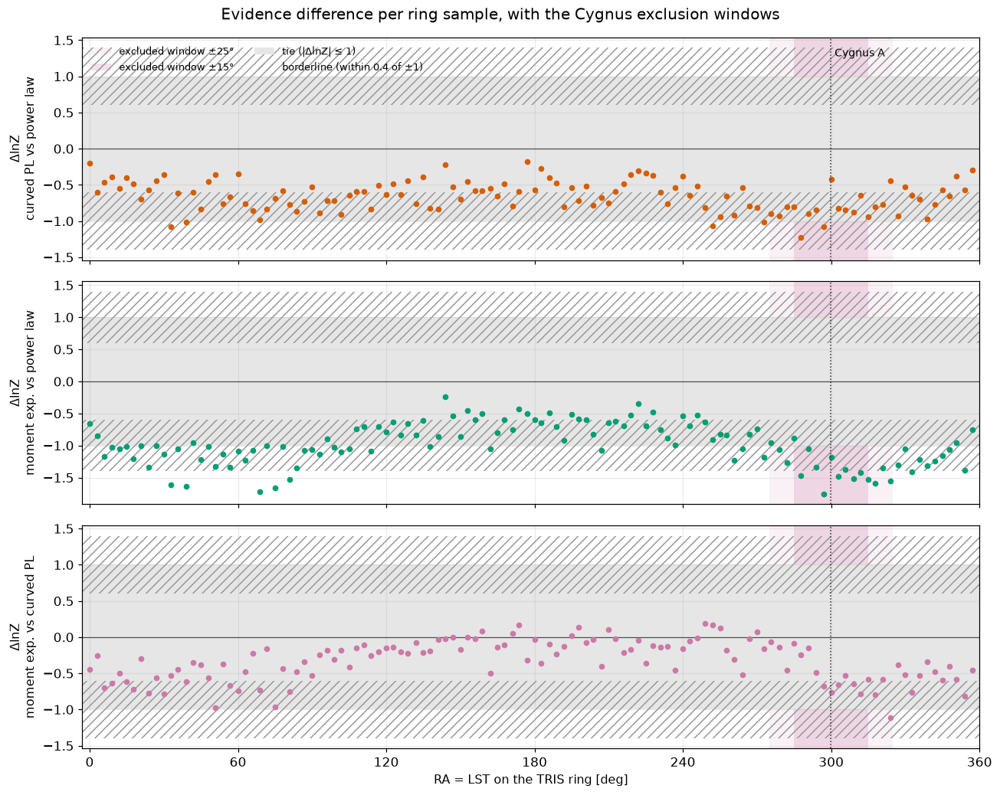

saved model_comparison/model_choice/dlnZ_vs_RA_with_windows.png


In [ ]:
ra = ev["ra_deg"].to_numpy()
fig, axes = plt.subplots(len(PAIRS), 1, figsize=(12, 3.2 * len(PAIRS)), sharex=True)
for ax, (a, b) in zip(axes, PAIRS):
    d = LNZ[a] - LNZ[b]
    for w, alpha in ((25.0, 0.10), (15.0, 0.22)):
        ax.axvspan(CYG_A_RA - w, CYG_A_RA + w, color="#CC79A7", alpha=alpha, lw=0,
                   label=f"excluded window ±{w:g}°")
    ax.axhspan(-TIE, TIE, color="0.9", lw=0, label="tie (|ΔlnZ| ≤ 1)")
    for c in (-TIE, TIE):
        ax.axhspan(c - BORDER, c + BORDER, facecolor="none", edgecolor="0.6", hatch="///", lw=0,
                   label="borderline (within 0.4 of ±1)" if c > 0 else None)
    ax.axhline(0, color="0.3", lw=0.8)
    ax.plot(ra, d, "o", ms=4, color=PAIR_COL[(a, b)])
    ax.axvline(CYG_A_RA, color="0.2", ls=":", lw=1)
    ax.set_ylabel(f"ΔlnZ\n{PAIR_LABEL[(a, b)]}")
    ax.grid(alpha=0.25)
axes[0].text(CYG_A_RA + 1.5, 0.95, "Cygnus A", transform=axes[0].get_xaxis_transform(), va="top", fontsize=9)
axes[0].legend(loc="upper left", ncol=2, frameon=False, fontsize=8.5)
axes[-1].set_xlabel("RA = LST on the TRIS ring [deg]")
axes[-1].set_xlim(-3, 360); axes[-1].set_xticks(np.arange(0, 361, 60))
fig.suptitle("Evidence difference per ring sample, with the Cygnus exclusion windows", fontsize=13)
fig.tight_layout()
save(fig, "dlnZ_vs_RA_with_windows.png")

### Summary table
One row per criterion, sample set and comparison; the `favours` column says, in plain language, which model that
row alone favours (or "tie"). The rules behind `favours` are the thresholds in the settings cell. Applying the
decision rule at the top is left to the reader.

In [ ]:
S = pd.DataFrame(SUMMARY)
S.to_csv(OUT_DIR / "decision_summary.csv", index=False)
print(f"saved {(OUT_DIR / 'decision_summary.csv').relative_to(REPO)}  ({len(S)} rows)")
per_sample = pd.DataFrame({"unit": UNITS, "ra_deg": ev["ra_deg"].to_numpy(),
                           **{f"in: {s}": SETS[s] for s in SET_NAMES},
                           **{f"lnZ {m} (CSV)": LNZ[m] for m in MODELS},
                           **{f"chi2 {m}": CHI[m] for m in MODELS},
                           **{f"AIC {m}": AIC[m] for m in MODELS}, **{f"BIC {m}": BIC[m] for m in MODELS},
                           **{f"UltraNest lnZ {m} (non-TRIS errors x{sc:g})": ULNZ[(sc, m)] for sc in ERROR_SCALES for m in MODELS}})
per_sample.to_csv(OUT_DIR / "per_sample_values.csv", index=False)
print(f"saved {(OUT_DIR / 'per_sample_values.csv').relative_to(REPO)}")
show = S[~S["criterion"].str.startswith("3 held-out prediction (") & ~S["criterion"].str.startswith("2 fit quality (χ²)")]
with pd.option_context("display.width", 250, "display.max_colwidth", 70, "display.max_rows", 300):
    print(show[["criterion", "sample set", "comparison", "favours"]].to_string(index=False))

saved model_comparison/model_choice/decision_summary.csv  (162 rows)
saved model_comparison/model_choice/per_sample_values.csv
                                          criterion           sample set               comparison                                               favours
                                  1 evidence (ΔlnZ)          all samples   curved PL vs power law                                    power law (6 vs 0)
                                  1 evidence (ΔlnZ)          all samples moment exp. vs power law                                   power law (62 vs 0)
                                  1 evidence (ΔlnZ)          all samples moment exp. vs curved PL                                    curved PL (1 vs 0)
                                  1 evidence (ΔlnZ) excl. RA 299.9 ± 15°   curved PL vs power law                                    power law (4 vs 0)
                                  1 evidence (ΔlnZ) excl. RA 299.9 ± 15° moment exp. vs power law                

### Notes for reading the criteria (no decision is made here)

* **Every ln Z carries UltraNest sampling noise of about ±0.3** (notebook 11 Part 4), so samples in the borderline band
  can change category between runs; the ×0.7 and ×1.5 columns are separate runs from the ×1 column.
* **Criterion 3 is the only part not made with UltraNest** (maximum-likelihood refits with 5 of the 6 points).
* **Mean z² in criterion 3 is dominated by TRIS 600 and Maipu 45,** whose small error bars make any miss large in
  units of σ. The per-survey rows and the median |z| show whether a model wins everywhere or only on those points.
* **"Systematic" in criterion 4 is easy to reach:** the standard errors are underestimates (correlated samples), and
  TRIS 600's are close to zero. Read the size and the sign pattern of the means, not only the flags.
* **Error-scale changes affect only LWA, Maipu and Stockert** (`SCALE_TRIS_TOO = False`).
* **All thresholds** (±1, borderline 0.4, ΔAIC/ΔBIC ±2, 5% held-out tie, 3 standard errors, 75% same sign,
  2 surveys) are in the settings cell and can be changed.

# Part E — T–T indices and the sky models against TRIS

**Origin:** `notebooks/14_ring_tt_betas.ipynb` (archived: `../moonrunes_archive_2026-11-16/notebooks/14_ring_tt_betas.ipynb`)

| | |
|---|---|
| **Reads** | `paper_outputs/pipeline/step5_fit/` (`fits/`, `ring_ra.npy`), `paper_outputs/pipeline/step2_ring_tods/` (`sky_tods.npz`, `beam_matched_tods.npz`), `res/`, `configs/run_pipeline.yaml` |
| **Writes** | `paper_outputs/phil_plots/` (Plots 4–6d, `plot6a_models_fitted_to_tris.csv`, …), `gsm_tris_freq_tods.npz` |
| **Feeds the paper** | `tab:step1` (Plot 6a: TRIS = a·model + b, weighted least squares, errors on TRIS only) |

**Stored outputs** are from the original notebook (not re-run after the merge).

**Pipeline:** reads the pipeline's step 2 and step 5 products.

## T–T spectral indices along the TRIS ring, data and sky models (plots for Phil)

**Data.** T–T fits along the TRIS ring (the 120 ring samples) for every pair of the seven surveys that
have ring TODs: LWA1 35/80 MHz, Maipu 45 MHz, Haslam 408 MHz, TRIS 600/820 MHz and Stockert 1420 MHz,
i.e. 21 pairs. All temperatures are Rayleigh–Jeans with the CMB removed. For each pair (lower
frequency $\nu_1$ on x, higher $\nu_2$ on y) a straight line with an intercept is fitted with an
**errors-in-variables** fit (York et al. 2004) that uses both axes' error bars:

$$T_2 = a\,T_1 + b, \qquad \beta = \frac{\ln a}{\ln(\nu_2/\nu_1)}, \qquad
\sigma_\beta = \frac{\sigma_a}{a\,\ln(\nu_2/\nu_1)},$$

with σ_a scaled up by √(χ²/ν) when χ²/ν > 1. A constant offset between the two surveys (a zero-level
error) goes into $b$ and does not bias β.

* **Plot 4:** the T–T plot of every pair, with its fitted line and β.
* **Plot 4a:** β of every pair against the pair's geometric mean frequency.
* **Plot 4b:** the same fits done separately for RA < 200° and RA > 200°, as two β matrices.
* **Plot 5:** a β matrix of the data pairs next to the β each sky model implies. The sky models are
  the seven of notebook 12. For each, the β is taken between its 408 MHz ring TOD and the measured
  TRIS 600 and 820 MHz rings. GSM2008 and GSM2016 are also rebuilt here at the TRIS frequencies
  (one `Inputs._native_tod` call per map, as notebook 12 does at 408 MHz), to give the models' own β.

> **⚠ The β errors are underestimates.** The ring samples are 3° apart, but the TRIS beam is ~20° wide
> (FWHM), so neighbouring samples see almost the same sky and are strongly correlated. The fits treat
> the samples as independent. There are only about 360° / 20° ≈ 18 independent beams on the ring, so
> the true errors are larger, by roughly √(120/18) ≈ 2.6. The per-sample error bars are also mostly
> gain-scale terms (LWA1 20%, Haslam 10%), which are common to the whole ring rather than independent
> per sample; they are used here exactly as the SED fits use them.

**Inputs** (read only), from notebook 12's cache `paper_outputs/sky_models_408/cache/`:
`ring_ra.npy` (the RA of each ring sample); `fits/unitNNN__power_law.npz` (the TRIS, LWA1, Maipu and
Stockert ring data per sample, with the SED fits' error bars); and `sky_tods.npz` (Haslam and every
sky model at 408 MHz through the TRIS beam, with beam coverage).
**Rebuilt here:** GSM2008 and GSM2016 at the TRIS frequencies, cached in `paper_outputs/phil_plots/cache/`.
Figures and CSVs go to `paper_outputs/phil_plots/`. Rerun: Restart & Run All (seconds with the
cache; a few minutes without it, to build the TOD-route inputs).

In [ ]:
%matplotlib inline
import os
os.environ.setdefault("TQDM_DISABLE", "1")
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PIPE2 = REPO / "paper_outputs" / "pipeline" / "step2_ring_tods"   # run_pipeline.py step 2 (ring TODs), read only
PIPE5 = REPO / "paper_outputs" / "pipeline" / "step5_fit"         # run_pipeline.py step 5 (our model's fits), read only
OUT_DIR = REPO / "paper_outputs" / "phil_plots"
CACHE_DIR = OUT_DIR / "cache"                                          # anything rebuilt here
HASLAM_FILE = "HASLAM_DESTRIPED_ONLY.fits"
# Beam matching (notebook 18): use ring TODs made with the pipeline's beam-matching kernel (the TRIS cut beam with
# each map's own beam taken out) instead of the native-resolution limTOD TODs.  TRIS ring data are unchanged.
USE_BEAM_MATCHED = True
BM_FILE = PIPE2 / "beam_matched_tods.npz"

COV_MIN = 0.5              # a model sample is valid when its beam coverage >= this (notebooks 12, 13)
MIN_RATIO = 1.0            # keep every pair (notebook 08 drops pairs closer than x1.3; here LWA 35 vs Maipu 45 is x1.29)
MIN_SAMPLES = 20           # pairs with fewer shared ring samples are left out
INFLATE = True             # scale σ_a by sqrt(χ²/ν) when χ²/ν > 1
GSM_REBUILT = ["GSM2008", "GSM2016"]

# Surveys with ring TODs, low frequency first.  key -> label; keys as in the fit cache.
SURVEYS = {
    "LWA_35MHz.fits":              "LWA1 35",
    "MAIPU_45mhZ.fits":            "Maipu 45",
    "LWA_80MHz.fits":              "LWA1 80",
    "HASLAM":                      "Haslam 408",
    "TRIS_600":                    "TRIS 600",
    "TRIS_820":                    "TRIS 820",
    "STOCKERT_VILLA_1400MHZ.fits": "Stockert 1420",
}
MODELS = ["Haslam (uncorrected)", "Haslam, Carter correction", "Haslam, Irfan correction",
          "GSM2008", "GSM2016", "GSM2016, GINAN correction", "LFSM"]

sys.path.insert(0, str(REPO / "src"))
from moonrunes.style import use_tris_style, COLORS
use_tris_style()
plt.rcParams.update({"figure.dpi": 110, "font.size": 24, "axes.titlesize": 24,
                     "axes.labelsize": 24, "legend.fontsize": 22, "figure.facecolor": "white"})
OUT_DIR.mkdir(exist_ok=True)
CACHE_DIR.mkdir(exist_ok=True)

def save(fig, name):
    # Save a figure as PNG in OUT_DIR, then show it inline.
    fig.savefig(OUT_DIR / f"{name}.png")
    plt.show()
    print(f"saved {(OUT_DIR / f'{name}.png').relative_to(REPO)}")

### 1. The ring TODs

For each survey and ring sample: the CMB-removed RJ temperature and its 1σ, as the SED fits use them,
read from `fits/unitNNN__power_law.npz`. TRIS's error is `ring_sigma` (statistical ⊕ zero level); the
other surveys' errors are their published scale ⊕ zero level ⊕ noise terms (`error_bars.csv`). The
TRIS frequencies are the effective ones stored with the data (600.5 and 817.8 MHz), and these are
used in every β. Haslam is not a fit point, so it is read from notebook 12's `sky_tods.npz`
("Haslam (uncorrected)"), kept where the beam coverage is ≥ `COV_MIN` (0.5). Its error is the
pipeline's Haslam error (`sed_prototype.sigma_for`: 10% scale ⊕ 3 K zero level). The cell prints each
survey's frequency, sample count, median T, median σ and median σ/T.

In [ ]:
sys.dont_write_bytecode = True
sys.path.insert(0, str(REPO / "src"))
from moonrunes.sed_prototype import sigma_for

RA = np.load(PIPE5 / "ring_ra.npy")
N = RA.size

z = np.load(PIPE2 / "sky_tods.npz", allow_pickle=False)
T408 = {}                                        # every sky model at 408 MHz, through the TRIS beam
for i, n in enumerate(str(x) for x in z["names"]):
    T408[n] = np.where(z[f"cov_{i}"] >= COV_MIN, z[f"tod_{i}"], np.nan)
assert set(MODELS) <= set(T408), list(T408)

# Data: (t, s) per survey, NaN where a sample has no usable point.
T, S, FREQ = {}, {}, {}
for k in SURVEYS:
    T[k], S[k] = np.full(N, np.nan), np.full(N, np.nan)
for u in range(N):
    r = np.load(PIPE5 / "fits" / f"unit{u:03d}__power_law.npz", allow_pickle=False)
    for k, nu, t, s in zip((str(x) for x in r["keys"]), r["nu"], r["t"], r["s"]):
        if k in SURVEYS:
            T[k][u], S[k][u], FREQ[k] = t, s, float(nu)
T["HASLAM"] = T408["Haslam (uncorrected)"]
S["HASLAM"] = np.asarray(sigma_for(dict(freq_mhz=408.0, file=HASLAM_FILE), T["HASLAM"]), dtype=float)
FREQ["HASLAM"] = 408.0
NU_TRIS = {k: FREQ[k] for k in ("TRIS_600", "TRIS_820")}

print(pd.DataFrame({"ν [MHz]": [FREQ[k] for k in SURVEYS],
                    "samples": [int(np.isfinite(T[k]).sum()) for k in SURVEYS],
                    "median T [K]": [np.nanmedian(T[k]) for k in SURVEYS],
                    "median σ [K]": [np.nanmedian(S[k]) for k in SURVEYS],
                    "median σ/T [%]": [100 * np.nanmedian(S[k] / T[k]) for k in SURVEYS]},
                   index=list(SURVEYS.values())).round(3).to_string())

               ν [MHz]  samples  median T [K]  median σ [K]  median σ/T [%]
LWA1 35           35.0      120     14102.273      2820.455          20.000
Maipu 45          45.0      120      7499.889       133.330           1.778
LWA1 80           80.0      120      2135.894       427.179          20.000
Haslam 408       408.0      120        28.918         4.167          14.409
TRIS 600         600.5      120        12.353         0.067           0.545
TRIS 820         817.8      120         5.072         0.430           8.482
Stockert 1420   1420.0      120         1.068         0.503          47.108


In [ ]:
# Beam matching: replace every survey TOD, Haslam and the 408 MHz sky models with notebook 18's beam-matched TODs,
# and recompute the survey error bars from the new temperatures with the same sigma_for.  TRIS is left as it is.
if USE_BEAM_MATCHED:
    zb = np.load(BM_FILE, allow_pickle=False)
    assert np.allclose(zb["ra_deg"], RA)
    for k in SURVEYS:
        if k.startswith("TRIS"):
            continue
        f = HASLAM_FILE if k == "HASLAM" else k
        T[k] = zb[f"survey::{f}"]
        S[k] = np.asarray(sigma_for(dict(freq_mhz=FREQ[k], file=f), T[k]), dtype=float)
    for n in MODELS:
        T408[n] = zb[f"model408::{n}"]
    print("using beam-matched TODs (notebook 18) for", ", ".join(v for k, v in SURVEYS.items() if not k.startswith("TRIS")),
          "and the seven 408 MHz sky models")
else:
    print("using the native-resolution limTOD TODs (not beam-matched)")

using beam-matched TODs (notebook 18) for LWA1 35, Maipu 45, LWA1 80, Haslam 408, Stockert 1420 and the seven 408 MHz sky models


### 2. The errors-in-variables line fit

`york` is the York et al. (2004) straight-line fit with uncorrelated errors on both axes, starting from
the `np.polyfit` slope. It is written in variances, so an axis with zero error (a sky model) reduces
it to a weighted fit in the other axis. Its σ_a and σ_b come from the stated error bars. With
`INFLATE` they are multiplied by √(χ²/ν) when χ²/ν > 1 and left alone otherwise. (`scipy.odr`
always rescales, including down.)

`tt_values` and `tt_betas` are notebook 08's functions (Figures 12–13), adapted from per-pixel to
per-ring-sample. `tt_values` returns each survey's ring TOD with its error. `tt_betas` fits every
pair, low frequency first, with `york` in place of `np.polyfit` and the bootstrap. It uses the samples
where both temperatures are positive and both errors are finite. A pair needs at least `MIN_SAMPLES`
(20) such samples. `MIN_RATIO` = 1.0 keeps every pair, including LWA1 35 vs Maipu 45 (×1.29 in
frequency), which notebook 08's ×1.3 cut would drop. The results are saved to `plot4_tt_betas_data.csv`.

In [ ]:
def york(x, y, sx, sy, n_iter=200, tol=1e-12):
    # y = a x + b with errors on both axes (York et al. 2004, Am. J. Phys. 72, 367; no x-y correlation).
    vx, vy = np.asarray(sx, float) ** 2, np.asarray(sy, float) ** 2
    a = np.polyfit(x, y, 1)[0]
    for _ in range(n_iter):
        W = 1.0 / (vy + a * a * vx)
        xb, yb = np.sum(W * x) / W.sum(), np.sum(W * y) / W.sum()
        U, V = x - xb, y - yb
        bet = W * (U * vy + a * V * vx)
        a_new = np.sum(W * bet * V) / np.sum(W * bet * U)
        done = abs(a_new - a) <= tol * abs(a_new)
        a = a_new
        if done:
            break
    W = 1.0 / (vy + a * a * vx)
    xb, yb = np.sum(W * x) / W.sum(), np.sum(W * y) / W.sum()
    b = yb - a * xb
    xa = xb + W * ((x - xb) * vy + a * (y - yb) * vx)          # adjusted x values
    xab = np.sum(W * xa) / W.sum()
    sa = np.sqrt(1.0 / np.sum(W * (xa - xab) ** 2))
    sb = np.sqrt(1.0 / W.sum() + xab ** 2 * sa ** 2)
    chi2 = float(np.sum(W * (y - a * x - b) ** 2))
    dof = x.size - 2
    f = np.sqrt(max(1.0, chi2 / dof)) if INFLATE else 1.0
    return dict(a=a, sa=sa * f, b=b, sb=sb * f, chi2_dof=chi2 / dof)

def slope_to_beta(fit, nu1, nu2):
    L = np.log(nu2 / nu1)
    if not fit["a"] > 0:
        return np.nan, np.nan
    return np.log(fit["a"]) / L, fit["sa"] / (fit["a"] * L)

def tt_values():
    # survey -> (T, σ) along the ring, CMB-removed RJ K; NaN where the sample has no point.
    return {SURVEYS[k]: (T[k], S[k]) for k in SURVEYS}

def tt_betas(vals, freq):
    # β, its error and the sample count for every pair of surveys, low frequency first.
    names_ = sorted(vals, key=lambda n: freq[n])
    rows = []
    for i, lo in enumerate(names_):
        for hi in names_[i + 1:]:
            ratio = freq[hi] / freq[lo]
            (x, sx), (y, sy) = vals[lo], vals[hi]
            ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(sx) & np.isfinite(sy) & (x > 0) & (y > 0)
            if ratio < MIN_RATIO or ok.sum() < MIN_SAMPLES:
                continue
            fit = york(x[ok], y[ok], sx[ok], sy[ok])
            beta, err = slope_to_beta(fit, freq[lo], freq[hi])
            rows.append(dict(lo=lo, hi=hi, nu_lo=freq[lo], nu_hi=freq[hi], beta=beta, err=err, n=int(ok.sum()), **fit))
    return rows

VALS = tt_values()
FREQ_L = {SURVEYS[k]: FREQ[k] for k in SURVEYS}
ORDER = sorted(VALS, key=lambda n: FREQ_L[n])
TT = tt_betas(VALS, FREQ_L)
TT_OF = {(r["lo"], r["hi"]): r for r in TT}
tt_df = pd.DataFrame([{"survey 1 (x)": r["lo"], "survey 2 (y)": r["hi"], "ν1 [MHz]": r["nu_lo"], "ν2 [MHz]": r["nu_hi"],
                       "N samples": r["n"], "slope a": r["a"], "σ_a": r["sa"], "intercept b [K]": r["b"],
                       "σ_b [K]": r["sb"], "χ²/ν": r["chi2_dof"], "β": r["beta"], "σ_β": r["err"]} for r in TT])
tt_df.to_csv(OUT_DIR / "plot4_tt_betas_data.csv", index=False)
print(f"saved {(OUT_DIR / 'plot4_tt_betas_data.csv').relative_to(REPO)}  (σ inflated by √(χ²/ν) when > 1: {INFLATE})\n")
with pd.option_context("display.width", 220):
    print(tt_df.round(3).to_string(index=False))

saved model_comparison/phil_plots/plot4_tt_betas_data.csv  (σ inflated by √(χ²/ν) when > 1: True)

survey 1 (x)  survey 2 (y)  ν1 [MHz]  ν2 [MHz]  N samples  slope a   σ_a  intercept b [K]  σ_b [K]   χ²/ν      β   σ_β
     LWA1 35      Maipu 45      35.0      45.0        120    0.761 0.072        -3564.145  982.543  0.133 -1.085 0.374
     LWA1 35       LWA1 80      35.0      80.0        120    0.179 0.020         -508.976  277.158  0.024 -2.081 0.137
     LWA1 35    Haslam 408      35.0     408.0        120    0.003 0.000          -21.172    4.516  0.058 -2.320 0.040
     LWA1 35      TRIS 600      35.0     600.5        120    0.001 0.000           -6.982    1.611  0.059 -2.339 0.032
     LWA1 35      TRIS 820      35.0     817.8        120    0.001 0.000           -3.434    0.734  0.055 -2.370 0.029
     LWA1 35 Stockert 1420      35.0    1420.0        120    0.000 0.000           -0.577    0.239  0.026 -2.460 0.040
    Maipu 45       LWA1 80      45.0      80.0        120    0.231 0

#### Plot 4 — T–T plots along the TRIS ring, every pair of surveys

Each panel is one pair, lower frequency on x. The points are the 120 ring samples, coloured by RA
(cyclic colour map), drawn without error bars. The black line is the errors-in-variables fit, over the
x range of the data, and each panel quotes β ± σ_β and χ²/ν. Axes are linear, because the fit is
linear in temperature. For surveys reaching 10³ K or more (LWA1 35, Maipu 45, LWA1 80) the ticks are
in units of 10³ or 10⁴ K, with that power in the axis title. **The β errors are underestimates**: the
samples are 3° apart under a ~20° beam, so they are not independent.

/var/folders/hg/70vc82sj49g_2x7dh5q_42pc0000gp/T/ipykernel_38562/3495189115.py:42: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, 0.985))


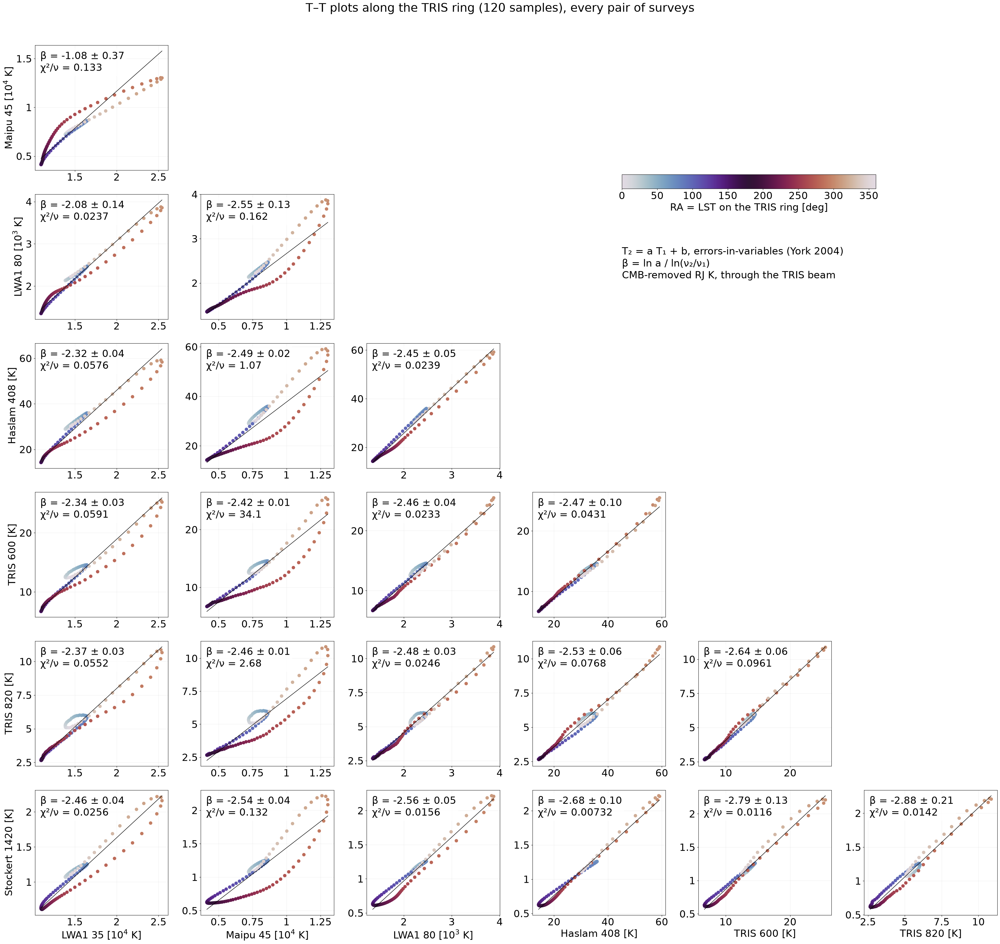

saved model_comparison/phil_plots/plot4_tt_ring_all_pairs.png


In [ ]:
n = len(ORDER) - 1                               # rows: ORDER[1:], columns: ORDER[:-1]
fig, axes = plt.subplots(n, n, figsize=(2*2.75 * n + 1.5, 2*2.6 * n + 1.2), squeeze=False)
cmap_ra = plt.get_cmap("twilight")
from matplotlib.ticker import FuncFormatter
# Surveys reaching 10³ K or more: ticks in units of 10^e K, with the power in the axis title.
EXP = {s: (int(np.floor(np.log10(np.nanmax(VALS[s][0])))) if np.nanmax(VALS[s][0]) >= 1e3 else 0) for s in ORDER}
unit = lambda s: f"[10$^{{{EXP[s]}}}$ K]" if EXP[s] else "[K]"
for i in range(n):
    for j in range(n):
        ax = axes[i, j]
        yi, xj = ORDER[i + 1], ORDER[j]
        if j > i:
            ax.axis("off"); continue
        (x, sx), (y, sy) = VALS[xj], VALS[yi]
        ok = np.isfinite(x) & np.isfinite(y) & (x > 0) & (y > 0)
        sc = ax.scatter(x[ok], y[ok], c=RA[ok], cmap=cmap_ra, vmin=0, vmax=360, s=70, lw=0, zorder=2)
        r = TT_OF.get((xj, yi))
        if r is not None:
            xx = np.linspace(np.nanmin(x[ok]), np.nanmax(x[ok]), 50)
            ax.plot(xx, r["a"] * xx + r["b"], color=COLORS["ink"], zorder=3)
            ax.text(0.04, 0.96, f"β = {r['beta']:.2f} ± {r['err']:.2f}\nχ²/ν = {r['chi2_dof']:.3g}",
                    transform=ax.transAxes, va="top",
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))
        # ax.tick_params(labelsize=7)              # every panel has its own temperature range
        ax.locator_params(nbins=4)
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _, e=EXP[xj]: f"{v / 10 ** e:g}"))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _, e=EXP[yi]: f"{v / 10 ** e:g}"))
        if j == 0:
            ax.set_ylabel(f"{yi} {unit(yi)}")
        if i == n - 1:
            ax.set_xlabel(f"{xj} {unit(xj)}")
        ax.grid(alpha=0.2)
cax = fig.add_axes([0.62, 0.80, 0.25, 0.015])
fig.colorbar(sc, cax=cax, orientation="horizontal", label="RA = LST on the TRIS ring [deg]")
fig.text(0.62, 0.74,
         "T₂ = a T₁ + b, errors-in-variables (York 2004)\n"
         "β = ln a / ln(ν₂/ν₁)\n"
         "CMB-removed RJ K, through the TRIS beam\n"
        #  "⚠ samples 3° apart under a ~20° beam are\n   correlated: β errors are underestimates"
        , va="top")
fig.suptitle("T–T plots along the TRIS ring (120 samples), every pair of surveys", y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.985))
save(fig, "plot4_tt_ring_all_pairs")

#### Plot 4a — β of every pair against the pair's frequency

Each point is one pair from Plot 4, at the geometric mean of its two frequencies, √(ν₁ν₂) (log axis),
with its errors-in-variables β ± σ_β. Each pair is labelled with its two nominal frequencies in MHz
(35, 80: LWA1; 45: Maipu; 408: Haslam; 600, 820: TRIS; 1420: Stockert). The positions use the TRIS
effective frequencies. Pairs involving Maipu 45 are drawn as open orange squares with orange labels;
the rest are black dots. The dashed line is β = −2.7.

> **⚠ The slopes use all 120 ring samples, which are correlated** (3° apart under a ~20° beam), **so
> the uncertainties are underestimates**, by roughly √(120/18) ≈ 2.6.

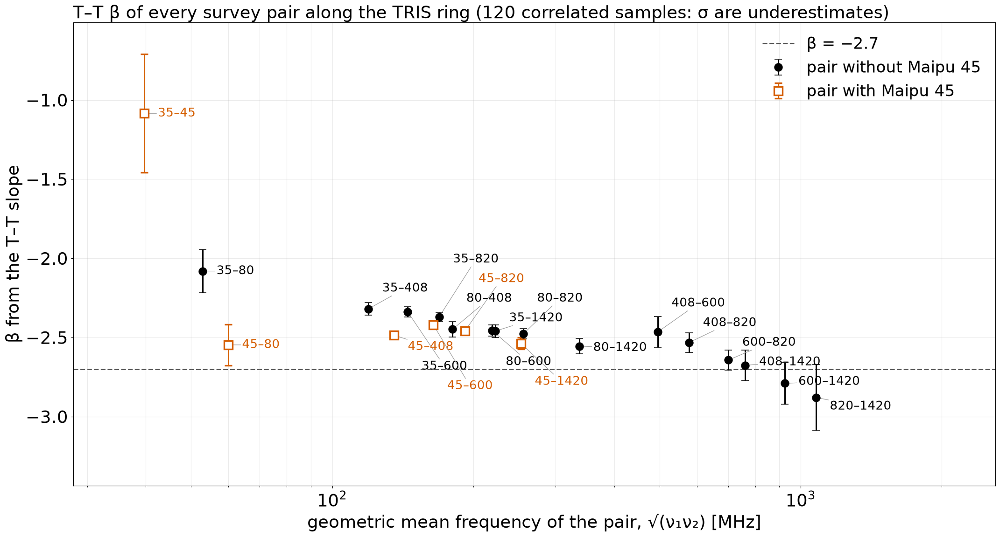

saved model_comparison/phil_plots/plot4a_beta_vs_pair_frequency.png


In [ ]:
fig, ax = plt.subplots(figsize=(20, 11))
gm = np.array([np.sqrt(r["nu_lo"] * r["nu_hi"]) for r in TT])
bt = np.array([r["beta"] for r in TT]); er = np.array([r["err"] for r in TT])
is_maipu = np.array(["Maipu 45" in (r["lo"], r["hi"]) for r in TT])
ax.errorbar(gm[~is_maipu], bt[~is_maipu], yerr=er[~is_maipu], fmt="o", ms=11, color=COLORS["ink"],
            elinewidth=2, capsize=5, label="pair without Maipu 45", zorder=3)
ax.errorbar(gm[is_maipu], bt[is_maipu], yerr=er[is_maipu], fmt="s", ms=12, mfc="white", mec="#D55E00",
            mew=2.2, color="#D55E00", elinewidth=2, capsize=5, label="pair with Maipu 45", zorder=3)
ax.axhline(-2.7, color="0.3", ls="--", lw=1.8, label="β = −2.7", zorder=1)

# Labels: "ν₁–ν₂" (nominal MHz) next to each point, pushed apart (in axes fraction, log x) from each
# other and from the markers until nothing overlaps.
ax.set_xscale("log")
ax.set_xlim(28, 2600)
ax.set_ylim(np.nanmin(bt - er) - 0.35, np.nanmax(bt + er) + 0.2)
nominal = lambda s: s.split()[-1]
lab = [f"{nominal(r['lo'])}–{nominal(r['hi'])}" for r in TT]
to_ax = lambda x, y: ax.transAxes.inverted().transform(ax.transData.transform((x, y)))
pts = np.array([to_ax(x, y) for x, y in zip(gm, bt)])
pos = pts + np.array([0.015, 0.0])
W, H = 0.075, 0.042                                              # label box size in axes fraction
for _ in range(2000):
    moved = False
    for i in range(len(pos)):
        for j in range(i + 1, len(pos)):                         # label against label
            dx, dy = pos[j] - pos[i]
            if abs(dx) < W and abs(dy) < H:
                s = 1.0 if dy >= 0 else -1.0
                step = 0.5 * (H - abs(dy)) + 1e-3
                pos[j, 1] += s * step; pos[i, 1] -= s * step
                moved = True
        for q in pts:                                            # label against every marker
            dx, dy = q - (pos[i] + [W / 2, 0])
            if abs(dx) < W / 2 + 0.006 and abs(dy) < H / 2 + 0.012:
                s = -1.0 if dy >= 0 else 1.0
                pos[i, 1] += s * (H / 2 + 0.012 - abs(dy) + 1e-3)
                moved = True
    if not moved:
        break
for (px, py), (lx, ly), t, m in zip(pts, pos, lab, is_maipu):
    ax.annotate(t, xy=(px, py), xycoords="axes fraction", xytext=(lx, ly), textcoords="axes fraction",
                fontsize=17, va="center", ha="left", color="#D55E00" if m else "black",
                arrowprops=dict(arrowstyle="-", color="0.6", shrinkA=0, shrinkB=6))
ax.set_xlabel("geometric mean frequency of the pair, √(ν₁ν₂) [MHz]")
ax.set_ylabel("β from the T–T slope")
ax.grid(alpha=0.25, which="both")
ax.legend(loc="upper right")
ax.set_title("T–T β of every survey pair along the TRIS ring (120 correlated samples: σ are underestimates)",
             loc="left")
fig.tight_layout()
save(fig, "plot4a_beta_vs_pair_frequency")

#### Plot 4c — β of every pair against its mean frequency, with the frequency span

The same β ± σ_β as Plot 4a, at the geometric mean of the pair's two frequencies, √(ν₁ν₂) (log axis). The
**horizontal bar runs from ν₁ to ν₂**, so its two ends show which surveys the pair is made of; the tick marks
on the x axis are the survey frequencies. Pairs involving Maipu 45 are open orange squares, the rest black
dots; the dashed line is β = −2.7.

> **⚠ The slopes use all 120 correlated ring samples, so the vertical uncertainties are underestimates.**

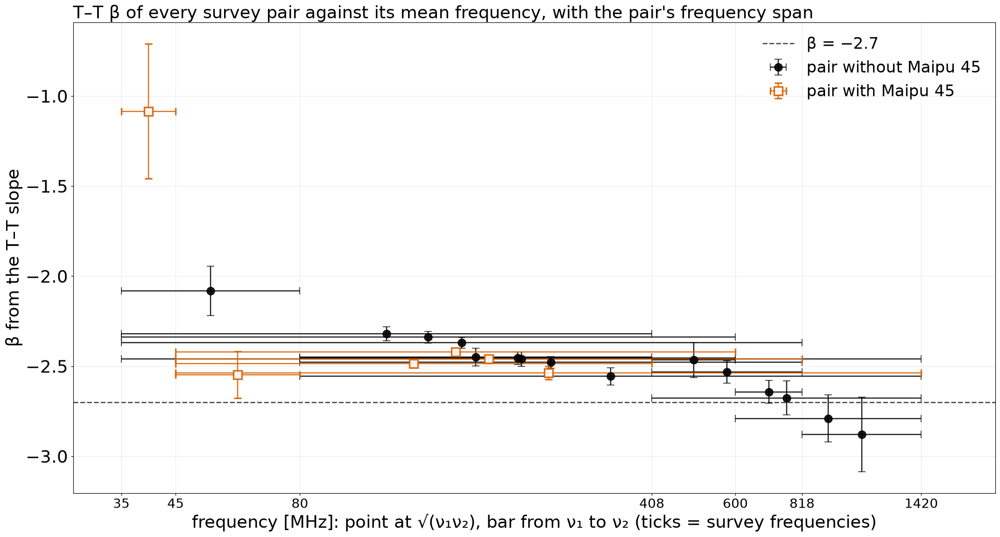

saved model_comparison/phil_plots/plot4c_beta_vs_mean_frequency_span.png


In [ ]:
fig, ax = plt.subplots(figsize=(20, 11))
lo_f = np.array([r["nu_lo"] for r in TT]); hi_f = np.array([r["nu_hi"] for r in TT])
gm = np.sqrt(lo_f * hi_f)
bt = np.array([r["beta"] for r in TT]); er = np.array([r["err"] for r in TT])
is_maipu = np.array(["Maipu 45" in (r["lo"], r["hi"]) for r in TT])
xerr = np.vstack([gm - lo_f, hi_f - gm])
for sel, kw in ((~is_maipu, dict(fmt="o", ms=11, color=COLORS["ink"], label="pair without Maipu 45")),
                (is_maipu, dict(fmt="s", ms=12, mfc="white", mec="#D55E00", mew=2.2, color="#D55E00",
                                label="pair with Maipu 45"))):
    ax.errorbar(gm[sel], bt[sel], yerr=er[sel], xerr=xerr[:, sel], capsize=5, zorder=3,
                alpha=0.9, **kw)
ax.axhline(-2.7, color="0.3", ls="--", lw=1.8, label="β = −2.7", zorder=1)
ax.set_xscale("log")
ax.set_xlim(28, 2000)
ax.set_xticks([FREQ_L[n] for n in ORDER])
ax.set_xticklabels([f"{FREQ_L[n]:.0f}" for n in ORDER], fontsize=18)
ax.minorticks_off()
ax.set_xlabel("frequency [MHz]: point at √(ν₁ν₂), bar from ν₁ to ν₂ (ticks = survey frequencies)")
ax.set_ylabel("β from the T–T slope")
ax.grid(alpha=0.25)
ax.legend(loc="upper right")
ax.set_title("T–T β of every survey pair against its mean frequency, with the pair's frequency span", loc="left")
fig.tight_layout()
save(fig, "plot4c_beta_vs_mean_frequency_span")

#### Plot 4b — the same fits, ring split at RA = 200°

Plot 4 shows two branches in many pairs, so one slope over the whole ring may average two different
spectral indices. Here every pair is refitted with the same `tt_betas`: the same errors-in-variables
fit, with the same √(χ²/ν) inflation. The fit is done separately for the 67 samples with RA < 200°
and the 53 with RA > 200° (no sample lies at exactly 200°). Each matrix is laid out like Plot 5's
left panel: β ± σ_β below the diagonal, χ²/ν above. Both share one colour scale (the 2nd–98th
percentile of the β in the two halves; LWA1 35 vs Maipu 45 is past its end), so a cell whose colour
changes between the halves shows where the index depends on position.
`plot4b_tt_betas_ra_split.csv` lists, for every pair, the whole-ring β, the β in each half, their
difference (RA > 200° minus RA < 200°) and that difference divided by the two σ added in quadrature.

> **⚠ The samples within each half are still correlated, so these uncertainties are underestimates too.**

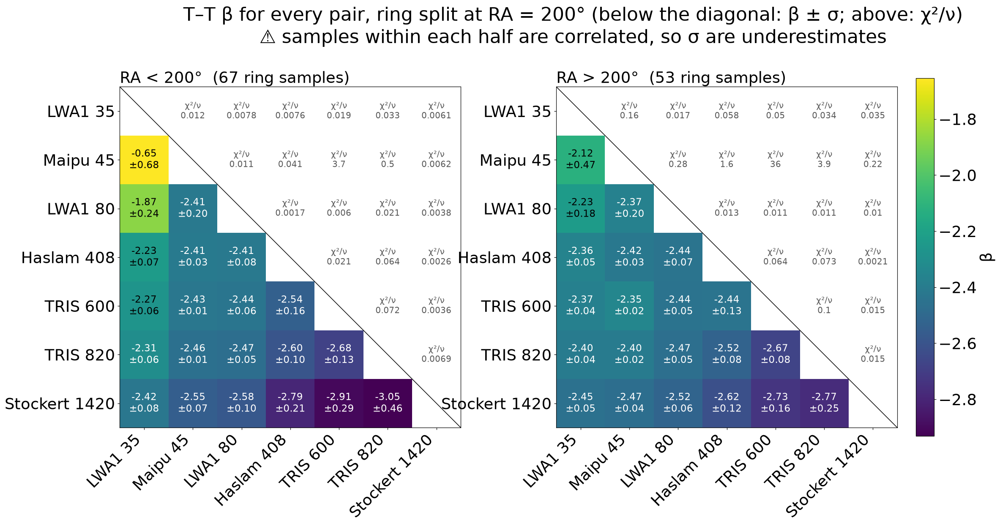

saved model_comparison/phil_plots/plot4b_beta_matrix_ra_split.png
saved model_comparison/phil_plots/plot4b_tt_betas_ra_split.csv

  survey 1      survey 2  β all  σ all  β RA < 200°  σ RA < 200°  β RA > 200°  σ RA > 200°  β(RA>200) − β(RA<200)  difference / combined σ
   LWA1 35      Maipu 45 -1.085  0.374       -0.655        0.676       -2.121        0.469                 -1.466                   -1.782
   LWA1 35       LWA1 80 -2.081  0.137       -1.874        0.245       -2.229        0.185                 -0.355                   -1.156
   LWA1 35    Haslam 408 -2.320  0.040       -2.232        0.073       -2.362        0.051                 -0.130                   -1.469
   LWA1 35      TRIS 600 -2.339  0.032       -2.269        0.060       -2.375        0.040                 -0.106                   -1.463
   LWA1 35      TRIS 820 -2.370  0.029       -2.305        0.056       -2.401        0.037                 -0.096                   -1.420
   LWA1 35 Stockert 1420 -2.460  0.0

In [ ]:
from matplotlib.colors import Normalize
RA_SPLIT = 200.0
HALVES = {f"RA < {RA_SPLIT:g}°": RA < RA_SPLIT, f"RA > {RA_SPLIT:g}°": RA > RA_SPLIT}
TT_H = {}
for h, sel in HALVES.items():
    vals_h = {s: (np.where(sel, t, np.nan), np.where(sel, e, np.nan)) for s, (t, e) in VALS.items()}
    TT_H[h] = {(r["lo"], r["hi"]): r for r in tt_betas(vals_h, FREQ_L)}

NS = len(ORDER)
MAT = {h: np.full((NS, NS), np.nan) for h in HALVES}; ERR = {h: m.copy() for h, m in MAT.items()}
CHI2 = {h: m.copy() for h, m in MAT.items()}
for h in HALVES:
    for i, lo in enumerate(ORDER):
        for j in range(i + 1, NS):
            r = TT_H[h].get((lo, ORDER[j]))
            if r is not None:
                MAT[h][j, i], ERR[h][j, i], CHI2[h][i, j] = r["beta"], r["err"], r["chi2_dof"]

allb = np.concatenate([m[np.isfinite(m)] for m in MAT.values()])
lo_b, hi_b = np.percentile(allb, [2, 98])
norm = Normalize(lo_b, hi_b)
cmap_b = plt.get_cmap("ring").copy(); cmap_b.set_bad("white")
fig, axs = plt.subplots(1, 2, figsize=(26, 12.5), gridspec_kw=dict(wspace=0.28))
for ax, h in zip(axs, HALVES):
    im = ax.imshow(MAT[h], cmap=cmap_b, norm=norm)
    for i in range(NS):
        for j in range(NS):
            if i > j and np.isfinite(MAT[h][i, j]):
                v = MAT[h][i, j]
                ax.text(j, i, f"{v:.2f}\n±{ERR[h][i, j]:.2f}", ha="center", va="center", fontsize=15,
                        color="white" if v < (lo_b + hi_b) / 2 else "black")
            elif i < j and np.isfinite(CHI2[h][i, j]):
                ax.text(j, i, f"χ²/ν\n{CHI2[h][i, j]:.2g}", ha="center", va="center", fontsize=13, color="0.35")
    ax.plot([-0.5, NS - 0.5], [-0.5, NS - 0.5], color=COLORS["ink"])
    ax.set_xticks(range(NS)); ax.set_yticks(range(NS))
    ax.set_xticklabels(ORDER, rotation=45, ha="right"); ax.set_yticklabels(ORDER)
    n_h = int(HALVES[h].sum())
    ax.set_title(f"{h}  ({n_h} ring samples)", loc="left")
fig.colorbar(im, ax=list(axs), shrink=0.8, pad=0.02, label="β")
fig.suptitle("T–T β for every pair, ring split at RA = 200° (below the diagonal: β ± σ; above: χ²/ν)\n"
             "⚠ samples within each half are correlated, so σ are underestimates", y=0.93)
save(fig, "plot4b_beta_matrix_ra_split")

lo_h, hi_h = HALVES
rows = []
for r in TT:
    p = (r["lo"], r["hi"]); a, b = TT_H[lo_h].get(p), TT_H[hi_h].get(p)
    rows.append({"survey 1": p[0], "survey 2": p[1], "β all": r["beta"], "σ all": r["err"],
                 f"β {lo_h}": a["beta"] if a else np.nan, f"σ {lo_h}": a["err"] if a else np.nan,
                 f"β {hi_h}": b["beta"] if b else np.nan, f"σ {hi_h}": b["err"] if b else np.nan})
split = pd.DataFrame(rows)
split["β(RA>200) − β(RA<200)"] = split[f"β {hi_h}"] - split[f"β {lo_h}"]
split["difference / combined σ"] = split["β(RA>200) − β(RA<200)"] / np.hypot(split[f"σ {lo_h}"], split[f"σ {hi_h}"])
split.to_csv(OUT_DIR / "plot4b_tt_betas_ra_split.csv", index=False)
print(f"saved {(OUT_DIR / 'plot4b_tt_betas_ra_split.csv').relative_to(REPO)}\n")
with pd.option_context("display.width", 250):
    print(split.round(3).to_string(index=False))

#### Plots 4d–4f — the same β without the Maipu or RA splits

The β of Plots 4a, 4c and 4b drawn without separating anything: **4d** is Plot 4a with every pair as the same black
dot (labelled ν₁–ν₂, pairs with Maipu 45 not set apart), **4e** is Plot 4c the same way (point at √(ν₁ν₂), bar from
ν₁ to ν₂), and **4f** is a single β matrix fitted over the **whole ring** (all 120 samples, no RA = 200° split; β ± σ
below the diagonal, χ²/ν above). The numbers are the same fits as `plot4_tt_betas_data.csv`.

> **⚠ The slopes use all 120 correlated ring samples, so the uncertainties are underestimates.**

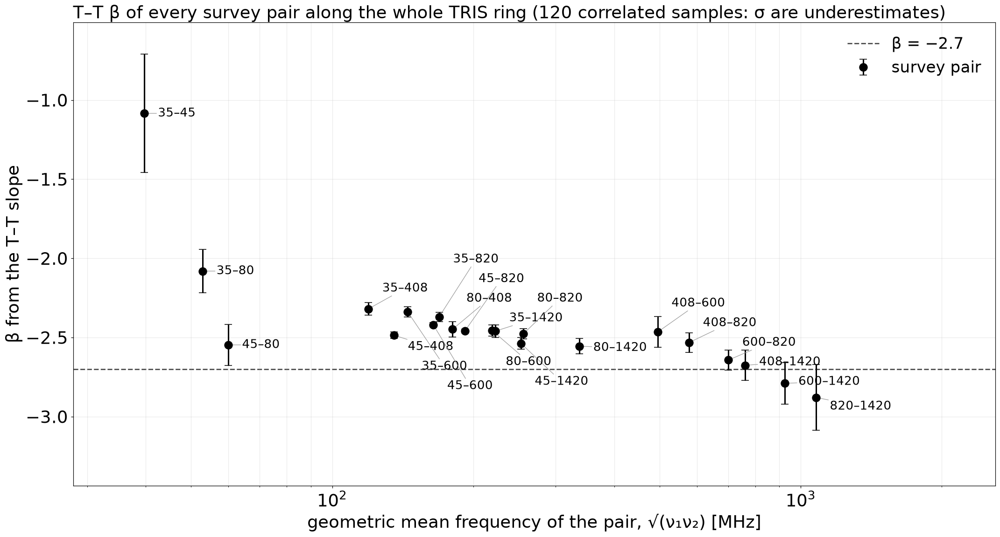

saved model_comparison/phil_plots/plot4d_beta_vs_pair_frequency_all_pairs.png


In [ ]:
fig, ax = plt.subplots(figsize=(20, 11))
gm = np.array([np.sqrt(r["nu_lo"] * r["nu_hi"]) for r in TT])
bt = np.array([r["beta"] for r in TT]); er = np.array([r["err"] for r in TT])
ax.errorbar(gm, bt, yerr=er, fmt="o", ms=11, color=COLORS["ink"], elinewidth=2, capsize=5, label="survey pair", zorder=3)
ax.axhline(-2.7, color="0.3", ls="--", lw=1.8, label="β = −2.7", zorder=1)

# Labels: "ν₁–ν₂" (nominal MHz) next to each point, pushed apart (in axes fraction, log x) from each
# other and from the markers until nothing overlaps.
ax.set_xscale("log")
ax.set_xlim(28, 2600)
ax.set_ylim(np.nanmin(bt - er) - 0.35, np.nanmax(bt + er) + 0.2)
nominal = lambda s: s.split()[-1]
lab = [f"{nominal(r['lo'])}–{nominal(r['hi'])}" for r in TT]
to_ax = lambda x, y: ax.transAxes.inverted().transform(ax.transData.transform((x, y)))
pts = np.array([to_ax(x, y) for x, y in zip(gm, bt)])
pos = pts + np.array([0.015, 0.0])
W, H = 0.075, 0.042                                              # label box size in axes fraction
for _ in range(2000):
    moved = False
    for i in range(len(pos)):
        for j in range(i + 1, len(pos)):                         # label against label
            dx, dy = pos[j] - pos[i]
            if abs(dx) < W and abs(dy) < H:
                s = 1.0 if dy >= 0 else -1.0
                step = 0.5 * (H - abs(dy)) + 1e-3
                pos[j, 1] += s * step; pos[i, 1] -= s * step
                moved = True
        for q in pts:                                            # label against every marker
            dx, dy = q - (pos[i] + [W / 2, 0])
            if abs(dx) < W / 2 + 0.006 and abs(dy) < H / 2 + 0.012:
                s = -1.0 if dy >= 0 else 1.0
                pos[i, 1] += s * (H / 2 + 0.012 - abs(dy) + 1e-3)
                moved = True
    if not moved:
        break
for (px, py), (lx, ly), t in zip(pts, pos, lab):
    ax.annotate(t, xy=(px, py), xycoords="axes fraction", xytext=(lx, ly), textcoords="axes fraction",
                fontsize=17, va="center", ha="left", color=COLORS["ink"],
                arrowprops=dict(arrowstyle="-", color="0.6", shrinkA=0, shrinkB=6))
ax.set_xlabel("geometric mean frequency of the pair, √(ν₁ν₂) [MHz]")
ax.set_ylabel("β from the T–T slope")
ax.grid(alpha=0.25, which="both")
ax.legend(loc="upper right")
ax.set_title("T–T β of every survey pair along the whole TRIS ring (120 correlated samples: σ are underestimates)",
             loc="left")
fig.tight_layout()
save(fig, "plot4d_beta_vs_pair_frequency_all_pairs")

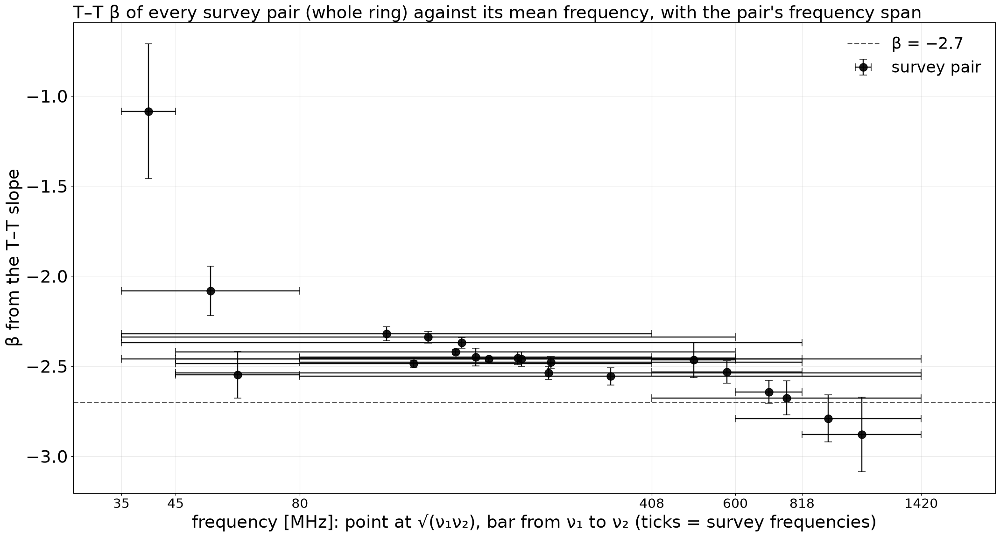

saved model_comparison/phil_plots/plot4e_beta_vs_mean_frequency_span_all_pairs.png


In [ ]:
fig, ax = plt.subplots(figsize=(20, 11))
lo_f = np.array([r["nu_lo"] for r in TT]); hi_f = np.array([r["nu_hi"] for r in TT])
gm = np.sqrt(lo_f * hi_f)
bt = np.array([r["beta"] for r in TT]); er = np.array([r["err"] for r in TT])
xerr = np.vstack([gm - lo_f, hi_f - gm])
ax.errorbar(gm, bt, yerr=er, xerr=xerr, fmt="o", ms=11, color=COLORS["ink"], capsize=5, zorder=3,
            alpha=0.9, label="survey pair")
ax.axhline(-2.7, color="0.3", ls="--", lw=1.8, label="β = −2.7", zorder=1)
ax.set_xscale("log")
ax.set_xlim(28, 2000)
ax.set_xticks([FREQ_L[n] for n in ORDER])
ax.set_xticklabels([f"{FREQ_L[n]:.0f}" for n in ORDER], fontsize=18)
ax.minorticks_off()
ax.set_xlabel("frequency [MHz]: point at √(ν₁ν₂), bar from ν₁ to ν₂ (ticks = survey frequencies)")
ax.set_ylabel("β from the T–T slope")
ax.grid(alpha=0.25)
ax.legend(loc="upper right")
ax.set_title("T–T β of every survey pair (whole ring) against its mean frequency, with the pair's frequency span", loc="left")
fig.tight_layout()
save(fig, "plot4e_beta_vs_mean_frequency_span_all_pairs")

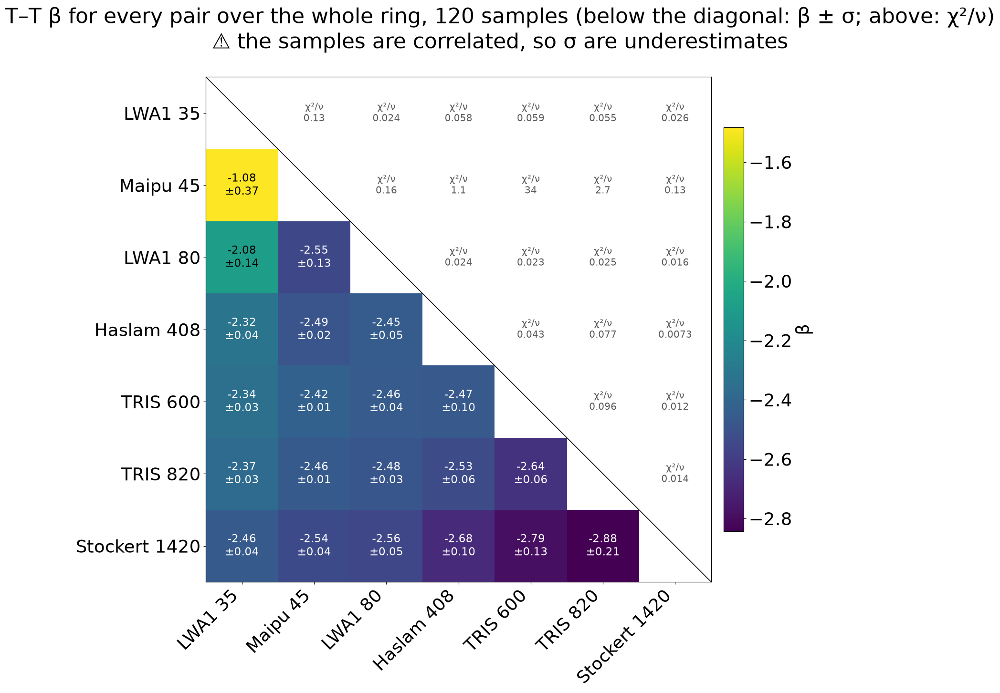

saved model_comparison/phil_plots/plot4f_beta_matrix_whole_ring.png


In [ ]:
from matplotlib.colors import Normalize
NS = len(ORDER)
MAT_W, ERR_W, CHI2_W = (np.full((NS, NS), np.nan) for _ in range(3))
for i, lo in enumerate(ORDER):
    for j in range(i + 1, NS):
        r = TT_OF.get((lo, ORDER[j]))
        if r is not None:
            MAT_W[j, i], ERR_W[j, i], CHI2_W[i, j] = r["beta"], r["err"], r["chi2_dof"]
lo_w, hi_w = np.percentile(MAT_W[np.isfinite(MAT_W)], [2, 98])
cmap_w = plt.get_cmap("ring").copy(); cmap_w.set_bad("white")
fig, ax = plt.subplots(figsize=(15, 12.5))
im = ax.imshow(MAT_W, cmap=cmap_w, norm=Normalize(lo_w, hi_w))
for i in range(NS):
    for j in range(NS):
        if i > j and np.isfinite(MAT_W[i, j]):
            v = MAT_W[i, j]
            ax.text(j, i, f"{v:.2f}\n±{ERR_W[i, j]:.2f}", ha="center", va="center", fontsize=15,
                    color="white" if v < (lo_w + hi_w) / 2 else "black")
        elif i < j and np.isfinite(CHI2_W[i, j]):
            ax.text(j, i, f"χ²/ν\n{CHI2_W[i, j]:.2g}", ha="center", va="center", fontsize=13, color="0.35")
ax.plot([-0.5, NS - 0.5], [-0.5, NS - 0.5], color=COLORS["ink"])
ax.set_xticks(range(NS)); ax.set_yticks(range(NS))
ax.set_xticklabels(ORDER, rotation=45, ha="right"); ax.set_yticklabels(ORDER)
fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02, label="β")
fig.suptitle(f"T–T β for every pair over the whole ring, {N} samples (below the diagonal: β ± σ; above: χ²/ν)\n"
             "⚠ the samples are correlated, so σ are underestimates", y=0.99)
save(fig, "plot4f_beta_matrix_whole_ring")

### 3. Sky models: GSM2008 and GSM2016 at the TRIS frequencies

These use notebook 12's `pygdsm` calls at 408 MHz: CMB not included, RJ K, and GSM2016 with
`data_unit="TRJ"`. They are evaluated at the TRIS **effective** frequencies of the ring data (600.5
and 817.8 MHz, so the frequency ratios match the data's). Each map is observed through the TRIS beam
with one `Inputs._native_tod` call, the pipeline's own limTOD observation. Samples with beam coverage
below `COV_MIN` (0.5) are dropped. The TODs are cached in `phil_plots/cache/` with a key holding the
models and frequencies. The TOD-route inputs are built only when that cache is missing or its key
differs. The cell prints the ring mean of each model at each frequency and of the TRIS data.

In [ ]:
_INP = None
def get_inputs():
    global _INP
    if _INP is None:
        from moonrunes.config import load_config
        from moonrunes.sed_prototype import Inputs
        print("building the TOD-route inputs (takes a few minutes)...")
        _INP = Inputs(load_config(REPO / "configs" / "run_pipeline.yaml"), REPO / "res",
                      target_file=HASLAM_FILE, verbose=False)
    return _INP

def observe_full_sky(sky, frame):
    # TRIS TOD of a full-sky map, with sed_prototype.Inputs' own observation code (notebook 12).
    import healpy as hp
    m = dict(sky=np.asarray(sky, dtype=float), nside=hp.npix2nside(len(sky)), frame=frame)
    return get_inputs()._native_tod(m)

def gsm_map(name, nu):
    # CMB-removed RJ map (galactic) at nu MHz, with notebook 12's pygdsm calls.
    from pygdsm import GlobalSkyModel, GlobalSkyModel16
    if name == "GSM2008":
        return np.array(GlobalSkyModel(freq_unit="MHz", include_cmb=False).generate(nu), dtype=float)
    if name == "GSM2016":
        return np.array(GlobalSkyModel16(freq_unit="MHz", data_unit="TRJ", include_cmb=False).generate(nu), dtype=float)
    raise ValueError(name)

gsm_path, gsm_key_path = CACHE_DIR / "gsm_tris_freq_tods.npz", CACHE_DIR / "gsm_tris_freq_tods_key.json"
gsm_key = json.dumps({"models": GSM_REBUILT, "freqs_mhz": NU_TRIS}, sort_keys=True)
if gsm_path.exists() and gsm_key_path.exists() and gsm_key_path.read_text() == gsm_key:
    zg = np.load(gsm_path, allow_pickle=False)
    GSM_TOD = {(n, k): (zg[f"tod__{n}__{k}"], zg[f"cov__{n}__{k}"]) for n in GSM_REBUILT for k in NU_TRIS}
    print("GSM ring TODs at the TRIS frequencies loaded from the cache")
else:
    GSM_TOD = {(n, k): observe_full_sky(gsm_map(n, nu), "G") for n in GSM_REBUILT for k, nu in NU_TRIS.items()}
    np.savez(gsm_path, **{f"tod__{n}__{k}": v[0] for (n, k), v in GSM_TOD.items()},
             **{f"cov__{n}__{k}": v[1] for (n, k), v in GSM_TOD.items()})
    gsm_key_path.write_text(gsm_key)
    print(f"saved {gsm_path.relative_to(REPO)}")

T_GSM = {(n, k): np.where(c >= COV_MIN, t, np.nan) for (n, k), (t, c) in GSM_TOD.items()}
print(pd.DataFrame({f"ring mean at {nu:g} MHz [K]": [np.nanmean(T_GSM[(n, k)]) for n in GSM_REBUILT]
                    for k, nu in NU_TRIS.items()}, index=GSM_REBUILT).round(3).to_string())
print("TRIS data ring means: " + ", ".join(f"{NU_TRIS[k]:g} MHz {np.nanmean(T[k]):.3f} K" for k in NU_TRIS))

GSM ring TODs at the TRIS frequencies loaded from the cache
         ring mean at 600.5 MHz [K]  ring mean at 817.8 MHz [K]
GSM2008                      10.222                       4.446
GSM2016                      14.030                       8.107
TRIS data ring means: 600.5 MHz 12.139 K, 817.8 MHz 5.008 K


In [ ]:
# Beam matching: GSM2008 and GSM2016 at the TRIS frequencies from notebook 18 instead of the limTOD TODs above.
if USE_BEAM_MATCHED:
    T_GSM = {(n, k): zb[f"modeltris::{n}::{k}"] for n in GSM_REBUILT for k in NU_TRIS}
    # The 408 MHz corrections stretched to the TRIS frequencies with each base model's own spectrum (notebook 18)
    STRETCHED = [("GSM2008", "Carter correction"), ("GSM2008", "Irfan correction"), ("GSM2016", "Carter correction"),
                 ("GSM2016", "Irfan correction"), ("GSM2016", "GINAN correction")]
    T_GSM.update({(f"{b}, {c}", k): zb[f"modeltris::{b}, {c}::{k}"] for b, c in STRETCHED for k in NU_TRIS})
    # LFSM stretched above 408 MHz with its own spectral index between 300 and 408 MHz (notebook 18)
    T_GSM.update({("LFSM, stretched", k): zb[f"modeltris::LFSM, stretched::{k}"] for k in NU_TRIS})
    print("GSM TODs at the TRIS frequencies: beam-matched (notebook 18)")
    print(pd.DataFrame({f"ring mean at {nu:g} MHz [K]": [np.nanmean(T_GSM[(n, k)]) for n in GSM_REBUILT]
                        for k, nu in NU_TRIS.items()}, index=GSM_REBUILT).round(3).to_string())

GSM TODs at the TRIS frequencies: beam-matched (notebook 18)
         ring mean at 600.5 MHz [K]  ring mean at 817.8 MHz [K]
GSM2008                      10.211                       4.442
GSM2016                      14.033                       8.108


#### Plot 6 — ring TODs at 600 and 820 MHz: TRIS data, sky models and stretched corrections

The TRIS ring data (black points with their ring errors, CMB removed, RJ) at 600 and 820 MHz, with every model that
can be put at those frequencies, observed through the TRIS beam with the pipeline's beam matching (notebook 18):

* **GSM2008 and GSM2016** (no correction), evaluated at the TRIS effective frequencies (600.5, 817.8 MHz);
* **the 408 MHz corrections stretched to the TRIS frequencies:** Carter (1.029 T + 0.91 K) and Irfan (−8.9 K
  monopole, i.e. −6.2 K on the CMB-removed map) applied to GSM2008's and GSM2016's 408 MHz maps, and GINAN applied to
  GSM2016 (built at 350 MHz as in notebook 12). Each corrected 408 MHz map is carried to 600.5 / 817.8 MHz with its
  base model's own per-pixel spectrum, T_corr(ν) = T_corr(408) × T_model(ν) / T_model(408). This stretching is an
  assumption, not part of the published corrections.

* **LFSM stretched to the TRIS frequencies:** LFSM is valid only up to 408 MHz, so its 408 MHz map is extended as a
  power law with its own per-pixel spectral index between 300 and 408 MHz (median −2.78), T(ν) = T(408) (ν/408)^β.
  Also an assumption.

Colour marks the correction (none, Carter, Irfan, GINAN) and line style the base model (GSM2008 dashed, GSM2016
solid, LFSM dotted). The Haslam-only TODs are not shown: they have no spectrum of their own to stretch with. The lower panels show model − TRIS in K; the grey band is the TRIS ±1σ (too thin to see at 600 MHz,
where σ ≈ 0.07 K).

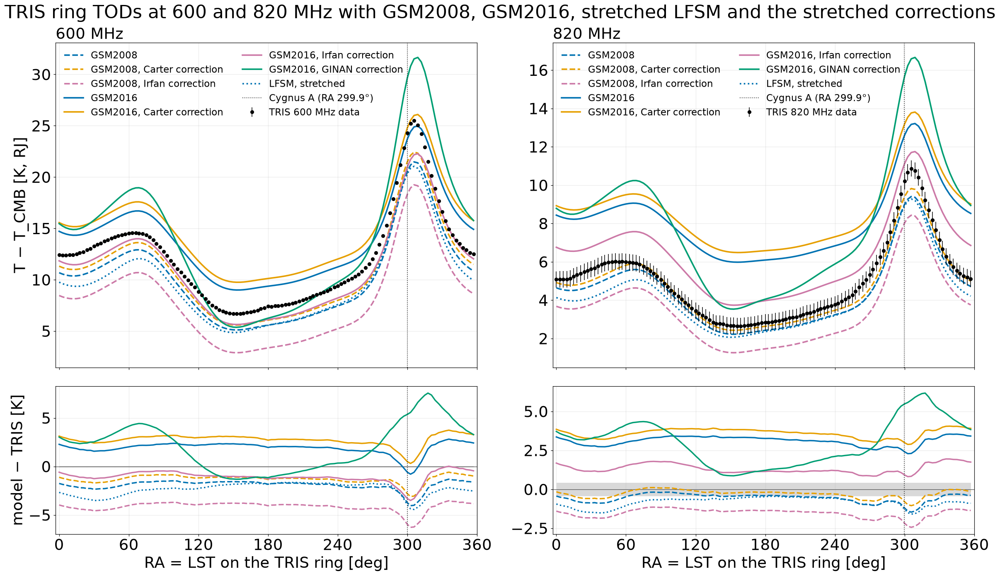

saved model_comparison/phil_plots/plot6_tods_600_820_data_vs_models.png


In [ ]:
# Colour = correction, line style = base model (Okabe-Ito, colourblind-safe)
CORR_COL = {"none": "#0072B2", "Carter correction": "#E69F00", "Irfan correction": "#CC79A7", "GINAN correction": "#009E73",
            "stretched": "#0072B2"}
BASE_LS = {"GSM2008": "--", "GSM2016": "-", "LFSM": ":"}
PLOT6_MODELS = [n for n in ("GSM2008", "GSM2008, Carter correction", "GSM2008, Irfan correction", "GSM2016",
                            "GSM2016, Carter correction", "GSM2016, Irfan correction", "GSM2016, GINAN correction",
                            "LFSM, stretched")
                if (n, "TRIS_600") in T_GSM]
def style6(n):
    base, _, corr = n.partition(", ")
    return dict(color=CORR_COL[corr or "none"], ls=BASE_LS[base])
fig, axes = plt.subplots(2, 2, figsize=(26, 14), sharex=True,
                         gridspec_kw=dict(height_ratios=[2.2, 1], hspace=0.08, wspace=0.18))
for c, k in enumerate(NU_TRIS):
    ax, ar = axes[0, c], axes[1, c]
    ax.errorbar(RA, T[k], yerr=S[k], fmt="o", ms=5, color=COLORS["data"], capsize=0,
                label=f"TRIS {k.split('_')[1]} MHz data", zorder=3)
    ar.fill_between(RA, -S[k], S[k], color="0.85", lw=0, label="TRIS ±1σ")
    ar.axhline(0, color="0.3")
    for n in PLOT6_MODELS:
        ax.plot(RA, T_GSM[(n, k)], lw=2.4, **style6(n), label=n)
        ar.plot(RA, T_GSM[(n, k)] - T[k], lw=2.2, **style6(n))
    for a in (ax, ar):
        a.axvline(299.9, color="0.2", ls=":", label="Cygnus A (RA 299.9°)" if a is ax else None)
        a.grid(alpha=0.25)
    ax.set_title(f"{k.split('_')[1]} MHz", loc="left")
    ax.legend(loc="upper left", fontsize=15, ncol=2)
    ar.set_xlabel("RA = LST on the TRIS ring [deg]")
    ar.set_xlim(-3, 360); ar.set_xticks(np.arange(0, 361, 60))
axes[0, 0].set_ylabel("T − T_CMB [K, RJ]")
axes[1, 0].set_ylabel("model − TRIS [K]")
fig.suptitle("TRIS ring TODs at 600 and 820 MHz with GSM2008, GSM2016, stretched LFSM and the stretched corrections", y=0.94)
save(fig, "plot6_tods_600_820_data_vs_models")

#### Plot 6a — every Plot 6 model fitted to the TRIS TODs (a new, TRIS-calibrated model)

Each model in Plot 6 is fitted to the TRIS ring data at each frequency with a scale and an offset,

$$T_\mathrm{TRIS}(\nu) = a_\nu\,T_\mathrm{model}(\nu) + b_\nu ,$$

by weighted least squares with the TRIS ring errors (statistical ⊕ zero level, `ring_sigma`). The fitted
$a_\nu T_\mathrm{model} + b_\nu$ is that model **calibrated to TRIS**: the new model at 600 and 820 MHz. The plot shows TRIS
minus each calibrated model along the ring (K), so it shows only what a scale and offset cannot fix; the grey band is the
TRIS ±1σ. The table gives a, b, their 1σ, χ²/ν and the rms residual. σ are scaled by √(χ²/ν) when it is above 1.

> **⚠ Caveats.** The 120 ring samples are correlated (3° apart under a ~20° beam), so every σ is an underestimate
> (roughly ×2.6). The TRIS zero-level error is common to the whole ring but is treated as independent per sample; at
> 600 MHz it dominates σ (≈ 0.07 K), so χ²/ν there is large and the fit is driven by the ring's shape.

saved model_comparison/phil_plots/plot6a_models_fitted_to_tris.csv

                     model TRIS band     a   σ_a  b [K]  σ_b [K]   χ²/ν  rms of TRIS − calibrated model [K]  rms before calibration [K]   N
                   GSM2008 600.5 MHz 1.073 0.008  1.177    0.092 32.899                               0.383                       1.990 120
                   GSM2008 817.8 MHz 1.084 0.021  0.194    0.102  0.291                               0.230                       0.631 120
GSM2008, Carter correction 600.5 MHz 1.043 0.008  0.837    0.094 32.888                               0.383                       1.373 120
GSM2008, Carter correction 817.8 MHz 1.053 0.021  0.046    0.105  0.291                               0.230                       0.388 120
 GSM2008, Irfan correction 600.5 MHz 1.074 0.008  3.553    0.075 32.977                               0.384                       4.178 120
 GSM2008, Irfan correction 817.8 MHz 1.085 0.021  1.236    0.084  0.293                     

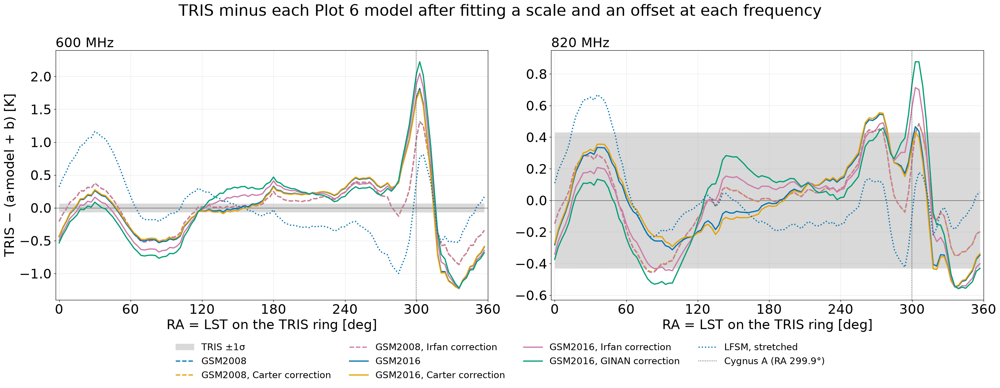

saved model_comparison/phil_plots/plot6a_tris_minus_calibrated_models.png


In [ ]:
def wls_line(x, y, s):
    # y = a x + b by weighted least squares; returns a, b, their covariance (scaled by chi2/nu if > 1), chi2/nu.
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(s) & (s > 0)
    A = np.vstack([x[ok], np.ones(ok.sum())]).T / s[ok, None]
    p, *_ = np.linalg.lstsq(A, y[ok] / s[ok], rcond=None)
    chi2nu = float(np.sum(((y[ok] - A @ p * s[ok]) / s[ok]) ** 2) / (ok.sum() - 2))
    cov = np.linalg.inv(A.T @ A) * max(1.0, chi2nu)
    return p[0], p[1], cov, chi2nu, int(ok.sum())

FIT6 = {}
rows = []
for n in PLOT6_MODELS:
    for k in NU_TRIS:
        a, b, cov, c2, nn = wls_line(T_GSM[(n, k)], T[k], S[k])
        res = T[k] - (a * T_GSM[(n, k)] + b)
        FIT6[(n, k)] = dict(a=a, b=b, cov=cov, chi2nu=c2, res=res)
        rows.append({"model": n, "TRIS band": f"{NU_TRIS[k]:g} MHz", "a": a, "σ_a": np.sqrt(cov[0, 0]), "b [K]": b,
                     "σ_b [K]": np.sqrt(cov[1, 1]), "χ²/ν": c2, "rms of TRIS − calibrated model [K]": np.sqrt(np.nanmean(res ** 2)),
                     "rms before calibration [K]": np.sqrt(np.nanmean((T_GSM[(n, k)] - T[k]) ** 2)), "N": nn})
fit6_df = pd.DataFrame(rows)
fit6_df.to_csv(OUT_DIR / "plot6a_models_fitted_to_tris.csv", index=False)
print(f"saved {(OUT_DIR / 'plot6a_models_fitted_to_tris.csv').relative_to(REPO)}\n")
with pd.option_context("display.width", 250):
    print(fit6_df.round(3).to_string(index=False))
for k in NU_TRIS:
    sub = fit6_df[fit6_df["TRIS band"] == f"{NU_TRIS[k]:g} MHz"].sort_values("rms of TRIS − calibrated model [K]")
    print(f"\nbest after calibration at {NU_TRIS[k]:g} MHz: {sub.iloc[0]['model']} "
          f"(rms {sub.iloc[0]['rms of TRIS − calibrated model [K]']:.3f} K)")

fig, axes = plt.subplots(1, 2, figsize=(26, 9), sharex=True)
for ax, k in zip(axes, NU_TRIS):
    ax.fill_between(RA, -S[k], S[k], color="0.85", lw=0, label="TRIS ±1σ")
    ax.axhline(0, color="0.3")
    for n in PLOT6_MODELS:
        ax.plot(RA, FIT6[(n, k)]["res"], lw=2.2, **style6(n), label=n)
    ax.axvline(299.9, color="0.2", ls=":", label="Cygnus A (RA 299.9°)")
    ax.set_title(f"{k.split('_')[1]} MHz", loc="left")
    ax.set_xlabel("RA = LST on the TRIS ring [deg]"); ax.set_xlim(-3, 360); ax.set_xticks(np.arange(0, 361, 60))
    ax.grid(alpha=0.25)
axes[0].set_ylabel("TRIS − (a·model + b) [K]")
fig.legend(*axes[0].get_legend_handles_labels(), fontsize=17, ncol=4, loc="lower center",
           bbox_to_anchor=(0.5, -0.12))
fig.suptitle("TRIS minus each Plot 6 model after fitting a scale and an offset at each frequency", y=0.97)
fig.tight_layout()
save(fig, "plot6a_tris_minus_calibrated_models")

#### Plot 6b — a suggested correction to GSM2008 and GSM2016

From Plot 6a, the fitted scale of GSM2008 and of GSM2016 is almost the same at 600 and 820 MHz, so the correction has
**one gain for both frequencies** and **one constant offset** (in K, the same form as the Carter and Irfan offsets). Two
forms of the gain are fitted, each jointly to both TRIS rings (240 points):

$$\text{constant gain:}\quad T_\mathrm{corrected}(\nu) = g\,T_\mathrm{GSM}(\nu) + z,$$

$$\text{gain} \times (\nu/408)^\delta:\quad T_\mathrm{corrected}(\nu) = g\,(\nu/408\,\mathrm{MHz})^{\delta}\,T_\mathrm{GSM}(\nu) + z .$$

The second adds a **weak power law in frequency** to the gain. Since the factor is 1 at 408 MHz, $g$ is still the gain at
408 MHz, and $\delta$ tilts the model's spectral index: the corrected model's β is the GSM's β + δ. It is fitted by
non-linear least squares (`scipy.optimize.least_squares`), the constant-gain form by linear least squares; σ are from
the Jacobian, scaled by √(χ²/ν) when it is above 1. With only two frequencies, δ is set by the ratio of the 820 to the
600 MHz scale, and how the offset changes with frequency cannot be measured, so a constant offset is an assumption.

The left panel shows the per-frequency scales $a_\nu$ from Plot 6a with the joint gain of each form ($g$, or
$g(\nu/408)^\delta$ with its ±1σ band); the right panel the per-frequency offsets $b_\nu$ with the joint $z$, extended
down to 408 MHz. Colour marks the base model, line style the form (solid: constant gain, dashed: gain × (ν/408)^δ).
**σ are underestimates** (correlated samples; common TRIS zero level treated as independent).

**Result (2026-10-28).** With δ free, the fit does **not** find a weak factor: δ = −0.58 ± 0.12 (GSM2008) and
−0.26 ± 0.09 (GSM2016), with χ² lower by 441 and 290 for the one extra parameter. That δ is not a spectral tilt of the
model: Plot 6a's scales, each fitted with its own offset, give δ = ln(a₈₂₀/a₆₀₀)/ln(817.8/600.5) = +0.03 ± 0.07
(GSM2008) and −0.04 ± 0.07 (GSM2016), consistent with zero. The large δ appears because the offset is forced to be
the same at both frequencies, while the rings want different offsets (b = +1.18 / +0.19 K for GSM2008, −3.08 /
−3.68 K for GSM2016). With z fixed by the precise 600 MHz ring, δ is the only way left to lower the model at 820 MHz.
It does fix 820 MHz (rms 0.91 → 0.43 K for GSM2008, 0.71 → 0.30 K for GSM2016; 600 MHz unchanged), but extrapolated
down to 408 MHz it raises the gain to 1.34 and 1.20 (Plot 6c). So the data say the gain itself has no measurable
frequency dependence between 600 and 820 MHz; what changes with frequency is the offset, which two frequencies with a
shared z cannot separate from δ.

saved model_comparison/phil_plots/plot6b_gsm_corrections.csv

  model        gain form  g (gain at 408 MHz)    σ_g  δ (frequency power law of the gain)    σ_δ   z [K]  σ_z [K]  corr(g, z)        χ²    χ²/ν   N  rms TRIS − corrected at 600.5 MHz [K]  rms TRIS − corrected at 817.8 MHz [K]
GSM2008    constant gain               1.0803 0.0061                                  NaN    NaN  1.0856   0.0668     -0.9207 4447.7398 18.6880 240                                 0.3848                                 0.9053
GSM2008 gain × (ν/408)^δ               1.3442 0.0636                              -0.5773 0.1243  1.1532   0.0649      0.1247 4006.7065 16.9059 240                                 0.3834                                 0.4348
GSM2016    constant gain               1.0894 0.0083                                  NaN    NaN -3.1663   0.1207     -0.9569 8019.4754 33.6953 240                                 0.5403                                 0.7113
GSM2016 gain × (ν/408)^δ          

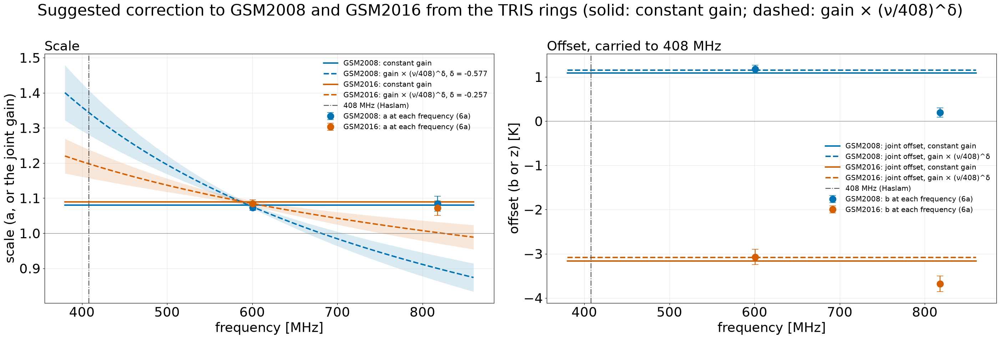

saved model_comparison/phil_plots/plot6b_gsm_correction.png


In [ ]:
# Two forms of the correction, both with one constant offset z (Plot 6b):
#   "constant gain":     T = g T_GSM(nu) + z
#   "gain × (ν/408)^δ":  T = g (nu/408)^delta T_GSM(nu) + z   (a weak power law in frequency; delta tilts beta)
from scipy.optimize import least_squares

FORMS = ["constant gain", "gain × (ν/408)^δ"]
MAIN_FORM = "constant gain"
FORM_LS = {"constant gain": "-", "gain × (ν/408)^δ": "--"}
GSM_BASE = ["GSM2008", "GSM2016"]
GSM_COL = {"GSM2008": "#0072B2", "GSM2016": "#D55E00"}

def corr_model(p, M, f):
    # p = (g, z) or (g, z, delta); M = T_GSM(nu); f = nu / 408 MHz
    d = p[2] if len(p) > 2 else 0.0
    return p[0] * f ** d * M + p[1]

def corr_jac(p, M, f):
    # d corr_model / d p, one row per sample
    d = p[2] if len(p) > 2 else 0.0
    cols = [f ** d * M, np.ones_like(M)]
    if len(p) > 2:
        cols.append(p[0] * f ** d * M * np.log(f))
    return np.vstack(cols).T

def joint_fit(n, form):
    # Fit both TRIS rings at once, weighted by the TRIS ring errors.
    M = np.concatenate([T_GSM[(n, k)] for k in NU_TRIS])
    F = np.concatenate([np.full(N, nu / 408.0) for nu in NU_TRIS.values()])
    Y = np.concatenate([T[k] for k in NU_TRIS]); W = np.concatenate([S[k] for k in NU_TRIS])
    ok = np.isfinite(M) & np.isfinite(Y) & np.isfinite(W) & (W > 0)
    M, F, Y, W = M[ok], F[ok], Y[ok], W[ok]
    p, *_ = np.linalg.lstsq(np.vstack([M, np.ones_like(M)]).T / W[:, None], Y / W, rcond=None)
    if form != MAIN_FORM:
        p = least_squares(lambda q: (Y - corr_model(q, M, F)) / W, np.r_[p, 0.0], x_scale="jac").x
    chi2 = float(np.sum(((Y - corr_model(p, M, F)) / W) ** 2))
    chi2nu = chi2 / (Y.size - p.size)
    J = corr_jac(p, M, F) / W[:, None]
    cov = np.linalg.inv(J.T @ J) * max(1.0, chi2nu)
    rms = {k: float(np.sqrt(np.nanmean((T[k] - corr_model(p, T_GSM[(n, k)], nu / 408.0)) ** 2)))
           for k, nu in NU_TRIS.items()}
    return dict(p=p, g=p[0], z=p[1], delta=float(p[2]) if p.size > 2 else 0.0, cov=cov, chi2=chi2, chi2nu=chi2nu,
                rms=rms, n=int(Y.size))

def corrected(n, form, M, nu):
    # The corrected model at frequency nu for model TOD M, and its 1 sigma from the fit's covariance.
    r = CORR[(n, form)]
    f = np.full_like(M, nu / 408.0)
    J = corr_jac(r["p"], M, f)
    return corr_model(r["p"], M, f), np.sqrt(np.einsum("ij,jk,ik->i", J, r["cov"], J))

def form_label(n, form):
    r = CORR[(n, form)]
    if form == MAIN_FORM:
        return f"{r['g']:.3f} × {n} {r['z']:+.2f} K"
    return f"{r['g']:.3f} (ν/408)^{r['delta']:+.3f} × {n} {r['z']:+.2f} K"

CORR = {(n, form): joint_fit(n, form) for n in GSM_BASE for form in FORMS}
rows = []
for (n, form), r in CORR.items():
    sd = np.sqrt(np.diag(r["cov"]))
    rows.append({"model": n, "gain form": form, "g (gain at 408 MHz)": r["g"], "σ_g": sd[0],
                 "δ (frequency power law of the gain)": r["delta"] if form != MAIN_FORM else np.nan,
                 "σ_δ": sd[2] if form != MAIN_FORM else np.nan,
                 "z [K]": r["z"], "σ_z [K]": sd[1], "corr(g, z)": r["cov"][0, 1] / (sd[0] * sd[1]),
                 "χ²": r["chi2"], "χ²/ν": r["chi2nu"], "N": r["n"],
                 **{f"rms TRIS − corrected at {NU_TRIS[k]:g} MHz [K]": v for k, v in r["rms"].items()}})
corr_df = pd.DataFrame(rows)
corr_df.to_csv(OUT_DIR / "plot6b_gsm_corrections.csv", index=False)
print(f"saved {(OUT_DIR / 'plot6b_gsm_corrections.csv').relative_to(REPO)}\n")
with pd.option_context("display.width", 300):
    print(corr_df.round(4).to_string(index=False))
for n in GSM_BASE:
    c0, c1 = CORR[(n, FORMS[0])], CORR[(n, FORMS[1])]
    print(f"\n{n}: δ = {c1['delta']:+.4f} ± {np.sqrt(c1['cov'][2, 2]):.4f}; χ² falls by {c0['chi2'] - c1['chi2']:.1f} "
          f"for one extra parameter")
    for form in FORMS:
        print(f"  suggested correction ({form}): {n}_corrected = {form_label(n, form)}")
    # For comparison: the δ implied by Plot 6a's per-frequency scales, each fitted with its own offset b_nu.
    (k6, k8) = NU_TRIS
    a6, a8 = FIT6[(n, k6)]["a"], FIT6[(n, k8)]["a"]
    s6, s8 = np.sqrt(FIT6[(n, k6)]["cov"][0, 0]), np.sqrt(FIT6[(n, k8)]["cov"][0, 0])
    lr = np.log(NU_TRIS[k8] / NU_TRIS[k6])
    print(f"  δ from 6a's scales (own offset at each frequency): ln(a_820 / a_600) / ln(817.8 / 600.5) = "
          f"{np.log(a8 / a6) / lr:+.3f} ± {np.hypot(s6 / a6, s8 / a8) / lr:.3f}")

nus = np.linspace(380, 860, 200)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(26, 9))
for n in GSM_BASE:
    col = GSM_COL[n]
    fa = [FIT6[(n, k)] for k in NU_TRIS]
    a1.errorbar(list(NU_TRIS.values()), [f["a"] for f in fa], yerr=[np.sqrt(f["cov"][0, 0]) for f in fa], fmt="o", ms=12,
                color=col, capsize=6, label=f"{n}: a at each frequency (6a)")
    a2.errorbar(list(NU_TRIS.values()), [f["b"] for f in fa], yerr=[np.sqrt(f["cov"][1, 1]) for f in fa], fmt="o", ms=12,
                color=col, capsize=6, label=f"{n}: b at each frequency (6a)")
    for form in FORMS:
        r = CORR[(n, form)]
        style = dict(color=col, ls=FORM_LS[form], lw=2.6)
        gain = r["g"] * (nus / 408.0) ** r["delta"]
        if form != MAIN_FORM:      # ±1σ of g (ν/408)^δ from cov(g, δ)
            Jg = np.vstack([(nus / 408.0) ** r["delta"], gain * np.log(nus / 408.0)]).T
            cg = r["cov"][np.ix_([0, 2], [0, 2])]
            sg = np.sqrt(np.einsum("ij,jk,ik->i", Jg, cg, Jg))
            a1.fill_between(nus, gain - sg, gain + sg, color=col, alpha=0.15, lw=0)
        a1.plot(nus, gain, **style, label=f"{n}: {form}" + (f", δ = {r['delta']:+.3f}" if form != MAIN_FORM else ""))
        a2.plot(nus, np.full_like(nus, r["z"]), **style, label=f"{n}: joint offset, {form}")
for a in (a1, a2):
    a.axvline(408, color="0.3", ls="-.", label="408 MHz (Haslam)")
    a.set_xlabel("frequency [MHz]"); a.grid(alpha=0.25)
a1.axhline(1, color="0.5"); a2.axhline(0, color="0.5")
a1.set_ylabel("scale (a, or the joint gain)"); a2.set_ylabel("offset (b or z) [K]")
a1.set_title("Scale", loc="left"); a2.set_title("Offset, carried to 408 MHz", loc="left")
a1.legend(fontsize=13); a2.legend(fontsize=13)
fig.suptitle("Suggested correction to GSM2008 and GSM2016 from the TRIS rings (solid: constant gain; "
             "dashed: gain × (ν/408)^δ)", y=0.98)
fig.tight_layout()
save(fig, "plot6b_gsm_correction")

#### Plot 6c — the corrected GSM models' 408 MHz TOD against Haslam and its corrections

The corrections of Plot 6b applied to GSM2008's and GSM2016's 408 MHz ring TODs (beam-matched, notebook 18). At
408 MHz the frequency factor is 1, so both forms give $g\,T_\mathrm{GSM}(408) + z$, each with its own fitted $g$ and $z$.
This is the 408 MHz sky that TRIS, through each GSM's spectral shape, predicts. It is compared with Haslam
(uncorrected), Haslam + Carter and Haslam + Irfan (beam-matched). **Top:** the predicted TOD of each form (solid:
constant gain, dashed: gain × (ν/408)^δ) with its ±1σ band from the fit's covariance; **bottom:** each Haslam version
minus the prediction, in K, with the same line styles and the constant-gain prediction's ±1σ in grey. One column per
base model. The table gives the median and rms of each difference for both forms.

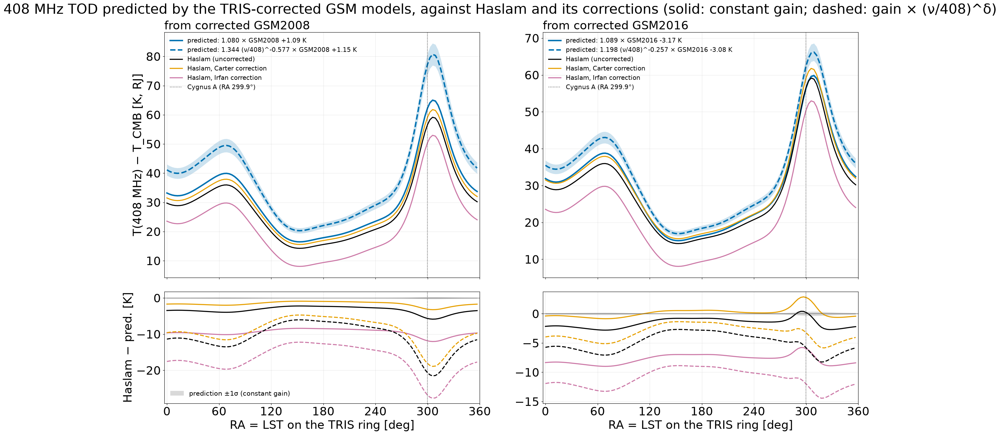

saved model_comparison/phil_plots/plot6c_predicted_408_vs_haslam.png
saved model_comparison/phil_plots/plot6c_haslam_vs_predicted_408.csv

prediction from        gain form            Haslam version  median (Haslam − prediction) [K]  rms [K]
        GSM2008    constant gain      Haslam (uncorrected)                             -3.40     3.49
        GSM2008    constant gain Haslam, Carter correction                             -1.65     1.73
        GSM2008    constant gain  Haslam, Irfan correction                             -9.58     9.59
        GSM2008 gain × (ν/408)^δ      Haslam (uncorrected)                            -11.09    11.63
        GSM2008 gain × (ν/408)^δ Haslam, Carter correction                             -9.35     9.89
        GSM2008 gain × (ν/408)^δ  Haslam, Irfan correction                            -17.28    17.56
        GSM2016    constant gain      Haslam (uncorrected)                             -1.42     1.78
        GSM2016    constant gain Haslam, Cart

In [ ]:
HAS_STYLE = {"Haslam (uncorrected)": dict(color=COLORS["ink"]),
             "Haslam, Carter correction": dict(color="#E69F00"),
             "Haslam, Irfan correction": dict(color="#CC79A7")}
def predict408(n, form):
    return corrected(n, form, T408[n], 408.0)

rows = []
fig, axes = plt.subplots(2, 2, figsize=(26, 14), sharex=True, gridspec_kw=dict(height_ratios=[2.2, 1], hspace=0.08))
for c, n in enumerate(GSM_BASE):
    ax, ar = axes[0, c], axes[1, c]
    for form in FORMS:
        pred, sig = predict408(n, form)
        ax.fill_between(RA, pred - sig, pred + sig, color="#0072B2", alpha=0.2, lw=0)
        ax.plot(RA, pred, color="#0072B2", lw=3, ls=FORM_LS[form], label=f"predicted: {form_label(n, form)}")
        if form == MAIN_FORM:
            ar.fill_between(RA, -sig, sig, color="0.85", lw=0, label="prediction ±1σ (constant gain)")
        for h, st in HAS_STYLE.items():
            d = T408[h] - pred
            ar.plot(RA, d, lw=2.2, ls=FORM_LS[form], **st)
            rows.append({"prediction from": n, "gain form": form, "Haslam version": h,
                         "median (Haslam − prediction) [K]": np.nanmedian(d), "rms [K]": np.sqrt(np.nanmean(d ** 2))})
    ar.axhline(0, color="0.3")
    for h, st in HAS_STYLE.items():
        ax.plot(RA, T408[h], lw=2.2, **st, label=h)
    for a in (ax, ar):
        a.axvline(299.9, color="0.2", ls=":", label="Cygnus A (RA 299.9°)" if a is ax else None)
        a.grid(alpha=0.25)
    ax.set_title(f"from corrected {n}", loc="left")
    ax.legend(fontsize=13, loc="upper left")
    ar.set_xlabel("RA = LST on the TRIS ring [deg]"); ar.set_xlim(-3, 360); ar.set_xticks(np.arange(0, 361, 60))
axes[0, 0].set_ylabel("T(408 MHz) − T_CMB [K, RJ]")
axes[1, 0].set_ylabel("Haslam − pred. [K]")
axes[1, 0].legend(fontsize=14, loc="lower left")
fig.suptitle("408 MHz TOD predicted by the TRIS-corrected GSM models, against Haslam and its corrections "
             "(solid: constant gain; dashed: gain × (ν/408)^δ)", y=0.94)
save(fig, "plot6c_predicted_408_vs_haslam")

cmp408 = pd.DataFrame(rows)
cmp408.to_csv(OUT_DIR / "plot6c_haslam_vs_predicted_408.csv", index=False)
print(f"saved {(OUT_DIR / 'plot6c_haslam_vs_predicted_408.csv').relative_to(REPO)}\n")
with pd.option_context("display.width", 220):
    print(cmp408.round(2).to_string(index=False))

#### Plot 6d — the corrected GSM models at 600 and 820 MHz, with the TRIS ring TODs

Both Plot 6b corrections, $g\,T_\mathrm{GSM}(\nu) + z$ (solid) and $g\,(\nu/408)^\delta\,T_\mathrm{GSM}(\nu) + z$ (dashed), applied to GSM2008's and GSM2016's beam-matched ring TODs at the
TRIS effective frequencies (600.5 and 817.8 MHz), drawn with the TRIS ring data (black points with their ring errors,
CMB removed, RJ). The shaded band on each corrected model is its ±1σ from the fit's (g, z) covariance. **Top:** the
TODs; **bottom:** corrected model − TRIS in K, with the TRIS ±1σ in grey. One column per frequency; colour marks the base model
(GSM2008 blue, GSM2016 orange), line style the form. The table gives the median and rms of corrected model − TRIS at each frequency, before and after the
correction.

> **⚠ Not an independent test.** g and z were fitted to these same two TRIS rings, so the corrected models match TRIS
> by construction; what the plot shows is the structure along the ring that one gain and one offset cannot remove.
> The samples are correlated and the common TRIS zero level is treated as independent, so the bands are underestimates.

**Result (run of 2026-10-27).** At 600 MHz the corrected models follow TRIS to within ±0.5 K over most of the ring; the
rms of corrected − TRIS drops from 1.99 to 0.39 K (GSM2008) and from 2.00 to 0.54 K (GSM2016). The largest differences
are around Cygnus A: −1.3 K (GSM2008) and −1.8 K (GSM2016) near RA 300°, then +0.9 and +1.2 K near RA 335°. At 820 MHz
both corrected models lie **above** TRIS along the whole ring, by 0.1–1.3 K, mostly outside the TRIS ±1σ (0.43 K).
The rms changes from 3.11 to 0.71 K for GSM2016, and goes **up** from 0.63 to 0.91 K for GSM2008. One gain and one
constant offset for both frequencies are therefore set almost entirely by the 600 MHz ring, whose σ is about 6× smaller.

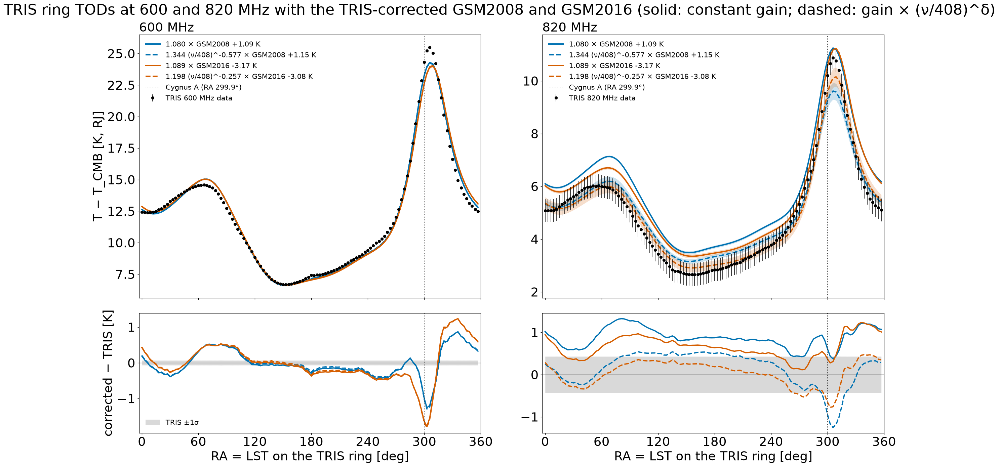

saved model_comparison/phil_plots/plot6d_corrected_gsm_vs_tris_tods.png
saved model_comparison/phil_plots/plot6d_corrected_gsm_minus_tris.csv

  model TRIS band               correction  median (model − TRIS) [K]  rms [K]   N
GSM2008 600.5 MHz                   before                     -1.763    1.990 120
GSM2008 600.5 MHz    after (constant gain)                     -0.084    0.385 120
GSM2008 600.5 MHz after (gain × (ν/408)^δ)                     -0.052    0.383 120
GSM2016 600.5 MHz                   before                      2.042    2.001 120
GSM2016 600.5 MHz    after (constant gain)                     -0.085    0.540 120
GSM2016 600.5 MHz after (gain × (ν/408)^δ)                     -0.057    0.540 120
GSM2008 817.8 MHz                   before                     -0.473    0.631 120
GSM2008 817.8 MHz    after (constant gain)                      0.868    0.905 120
GSM2008 817.8 MHz after (gain × (ν/408)^δ)                      0.289    0.435 120
GSM2016 817.8 MHz          

In [ ]:
def corrected_tris(n, k, form=MAIN_FORM):
    # Plot 6b's correction at TRIS band k, with its 1 sigma from the fit's covariance.
    return corrected(n, form, T_GSM[(n, k)], NU_TRIS[k])

rows = []
fig, axes = plt.subplots(2, 2, figsize=(26, 14), sharex=True,
                         gridspec_kw=dict(height_ratios=[2.2, 1], hspace=0.08, wspace=0.18))
for c, k in enumerate(NU_TRIS):
    ax, ar = axes[0, c], axes[1, c]
    ax.errorbar(RA, T[k], yerr=S[k], fmt="o", ms=5, color=COLORS["data"], capsize=0,
                label=f"TRIS {k.split('_')[1]} MHz data", zorder=3)
    ar.fill_between(RA, -S[k], S[k], color="0.85", lw=0, label="TRIS ±1σ")
    ar.axhline(0, color="0.3")
    for n in GSM_BASE:
        d = T_GSM[(n, k)] - T[k]
        rows.append({"model": n, "TRIS band": f"{NU_TRIS[k]:g} MHz", "correction": "before",
                     "median (model − TRIS) [K]": np.nanmedian(d), "rms [K]": np.sqrt(np.nanmean(d ** 2)),
                     "N": int(np.isfinite(d).sum())})
        for form in FORMS:
            pred, sig = corrected_tris(n, k, form)
            st = dict(color=GSM_COL[n], ls=FORM_LS[form])
            ax.fill_between(RA, pred - sig, pred + sig, color=GSM_COL[n], alpha=0.2, lw=0)
            ax.plot(RA, pred, lw=2.6, **st, label=form_label(n, form))
            ar.plot(RA, pred - T[k], lw=2.4, **st)
            d = pred - T[k]
            rows.append({"model": n, "TRIS band": f"{NU_TRIS[k]:g} MHz", "correction": f"after ({form})",
                         "median (model − TRIS) [K]": np.nanmedian(d), "rms [K]": np.sqrt(np.nanmean(d ** 2)),
                         "N": int(np.isfinite(d).sum())})
    for a in (ax, ar):
        a.axvline(299.9, color="0.2", ls=":", label="Cygnus A (RA 299.9°)" if a is ax else None)
    ax.set_title(f"{k.split('_')[1]} MHz", loc="left")
    ax.legend(loc="upper left", fontsize=14)
    ar.set_xlabel("RA = LST on the TRIS ring [deg]")
    ar.set_xlim(-3, 360); ar.set_xticks(np.arange(0, 361, 60))
axes[0, 0].set_ylabel("T − T_CMB [K, RJ]")
axes[1, 0].set_ylabel("corrected − TRIS [K]")
axes[1, 0].legend(fontsize=14, loc="lower left")
fig.suptitle("TRIS ring TODs at 600 and 820 MHz with the TRIS-corrected GSM2008 and GSM2016 "
             "(solid: constant gain; dashed: gain × (ν/408)^δ)", y=0.94)
save(fig, "plot6d_corrected_gsm_vs_tris_tods")

cmp_tris = pd.DataFrame(rows)
cmp_tris.to_csv(OUT_DIR / "plot6d_corrected_gsm_minus_tris.csv", index=False)
print(f"saved {(OUT_DIR / 'plot6d_corrected_gsm_minus_tris.csv').relative_to(REPO)}\n")
with pd.option_context("display.width", 220):
    print(cmp_tris.round(3).to_string(index=False))

### 4. β implied by each sky model

* **Model 408 MHz vs TRIS data (all seven models):** the model's 408 MHz ring TOD (x, zero error)
  against the measured TRIS 600 and 820 MHz rings (y, with `ring_sigma`), fitted with `york`. With no
  x error this is a weighted fit in y, with σ inflated by √(χ²/ν) when χ²/ν > 1. It is the β between
  the model's 408 MHz sky and the measured TRIS sky.
* **The models' own β (GSM2008, GSM2016 only):** the model against itself at 408 → 600, 408 → 820 and
  600 → 820 MHz. Neither axis has an error, so this is an ordinary least-squares line
  (`np.polyfit(..., cov=True)`). Its error is from the residual scatter and has no χ²/ν.
* **The data's own β (reference row):** Haslam vs TRIS 600 and Haslam vs TRIS 820 (first two columns)
  and TRIS 600 vs TRIS 820 (last column), taken from Plot 4's fits. They include Haslam's error
  bars, so they differ slightly from the "Haslam (uncorrected)" model row, which has no x error.

A purely additive correction (Irfan's monopole) goes into the intercept, so it leaves β unchanged by
construction; Carter's 1.029 scale steepens β by ln(1.029) / ln(ν₂/408). The results are saved to
`plot5_model_implied_betas.csv`.

In [ ]:
def ols_beta(x, y, nu1, nu2):
    ok = np.isfinite(x) & np.isfinite(y) & (x > 0) & (y > 0)
    (a, b), cov = np.polyfit(x[ok], y[ok], 1, cov=True)
    beta, err = slope_to_beta(dict(a=a, sa=np.sqrt(cov[0, 0])), nu1, nu2)
    return dict(a=a, sa=np.sqrt(cov[0, 0]), b=b, sb=np.sqrt(cov[1, 1]), chi2_dof=np.nan, beta=beta, err=err, n=int(ok.sum()))

def york_beta(x, sx, y, sy, nu1, nu2):
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(sx) & np.isfinite(sy) & (x > 0) & (y > 0)
    fit = york(x[ok], y[ok], sx[ok], sy[ok])
    beta, err = slope_to_beta(fit, nu1, nu2)
    return dict(**fit, beta=beta, err=err, n=int(ok.sum()))

COLS = ["408 model → TRIS 600 data", "408 model → TRIS 820 data",
        "408 → 600, model only", "408 → 820, model only", "600 → 820, model only"]
DATA_ROW = "data: Haslam 408, TRIS"
ROWS = [DATA_ROW] + MODELS
MB = {}                                          # (row, column) -> fit dict
zero = np.zeros(N)
for mname in MODELS:
    for c, k in zip(COLS[:2], NU_TRIS):
        MB[(mname, c)] = york_beta(T408[mname], zero, T[k], S[k], 408.0, NU_TRIS[k])
for g in GSM_REBUILT:
    k6, k8 = NU_TRIS
    MB[(g, COLS[2])] = ols_beta(T408[g], T_GSM[(g, k6)], 408.0, NU_TRIS[k6])
    MB[(g, COLS[3])] = ols_beta(T408[g], T_GSM[(g, k8)], 408.0, NU_TRIS[k8])
    MB[(g, COLS[4])] = ols_beta(T_GSM[(g, k6)], T_GSM[(g, k8)], NU_TRIS[k6], NU_TRIS[k8])
# Reference row: the data's own pairs (from Plot 4), placed in the columns they correspond to.
MB[(DATA_ROW, COLS[0])] = TT_OF[("Haslam 408", "TRIS 600")]
MB[(DATA_ROW, COLS[1])] = TT_OF[("Haslam 408", "TRIS 820")]
MB[(DATA_ROW, COLS[4])] = TT_OF[("TRIS 600", "TRIS 820")]

mb_df = pd.DataFrame([{"row": rw, "pair": c, "N samples": f["n"], "slope a": f["a"], "σ_a": f["sa"],
                       "intercept b [K]": f["b"], "χ²/ν": f["chi2_dof"], "β": f["beta"], "σ_β": f["err"]}
                      for (rw, c), f in MB.items()])
mb_df.to_csv(OUT_DIR / "plot5_model_implied_betas.csv", index=False)
print(f"saved {(OUT_DIR / 'plot5_model_implied_betas.csv').relative_to(REPO)}\n")
wide = mb_df.assign(cell=[f"{b:+.3f} ± {e:.3f}" for b, e in zip(mb_df["β"], mb_df["σ_β"])]) \
            .pivot(index="row", columns="pair", values="cell").reindex(index=ROWS, columns=COLS).fillna("—")
with pd.option_context("display.width", 250, "display.max_colwidth", 30):
    print(wide.to_string())

saved model_comparison/phil_plots/plot5_model_implied_betas.csv

pair                      408 model → TRIS 600 data 408 model → TRIS 820 data 408 → 600, model only 408 → 820, model only 600 → 820, model only
row                                                                                                                                            
data: Haslam 408, TRIS               -2.466 ± 0.097            -2.532 ± 0.062                     —                     —        -2.643 ± 0.063
Haslam (uncorrected)                 -2.435 ± 0.021            -2.528 ± 0.028                     —                     —                     —
Haslam, Carter correction            -2.509 ± 0.021            -2.569 ± 0.028                     —                     —                     —
Haslam, Irfan correction             -2.435 ± 0.021            -2.528 ± 0.028                     —                     —                     —
GSM2008                              -2.437 ± 0.021            -2.529 ±

#### Plot 5 — β matrix: data pairs and model-implied β

In the style of notebook 08's Figure 13b. **Left:** β for every pair of surveys along the ring, from
Plot 4 (below the diagonal, β ± σ_β; above it, the pair's χ²/ν). **Right:** the β each sky model
implies. The first two columns, left of the dotted line, are the model's 408 MHz ring TOD against the
measured TRIS 600 and 820 MHz rings. The last three are GSM2008's and GSM2016's own β between their
408, 600 and 820 MHz ring TODs. The top row, above the solid line, is the data's own value in the
columns it corresponds to. Both panels share one colour scale (the 2nd–98th percentile of all the β
shown). No colour bar is drawn; every cell carries its value. **All β errors are underestimates**
(correlated ring samples).

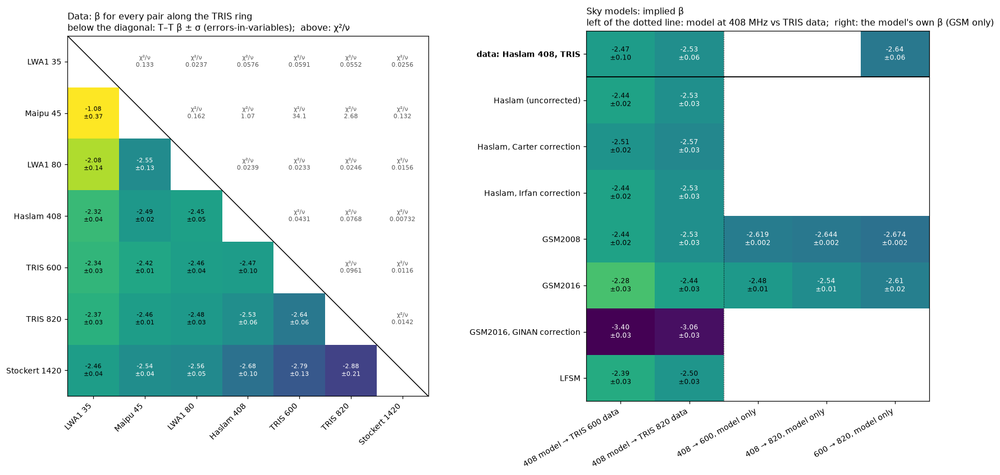

saved model_comparison/phil_plots/plot5_beta_matrix_data_vs_models.png


In [ ]:
from matplotlib.colors import Normalize
NS = len(ORDER)
TT_M = np.full((NS, NS), np.nan); TT_E = np.full((NS, NS), np.nan); CHI = np.full((NS, NS), np.nan)
for i, lo in enumerate(ORDER):
    for j in range(i + 1, NS):
        r = TT_OF.get((lo, ORDER[j]))
        if r is not None:
            TT_M[j, i], TT_E[j, i], CHI[i, j] = r["beta"], r["err"], r["chi2_dof"]
MM = np.full((len(ROWS), len(COLS)), np.nan); ME = MM.copy()
for (rw, c), f in MB.items():
    MM[ROWS.index(rw), COLS.index(c)], ME[ROWS.index(rw), COLS.index(c)] = f["beta"], f["err"]

both = np.concatenate([TT_M[np.isfinite(TT_M)], MM[np.isfinite(MM)]])
lo_b, hi_b = np.percentile(both, [2, 98])
norm = Normalize(lo_b, hi_b)
cmap_b = plt.get_cmap("ring").copy(); cmap_b.set_bad("white")
txt = lambda v: "white" if v < (lo_b + hi_b) / 2 else "black"

fig, (ax, axm) = plt.subplots(1, 2, figsize=(18, 7.8), gridspec_kw=dict(width_ratios=[1, 0.95], wspace=0.45))
im = ax.imshow(TT_M, cmap=cmap_b, norm=norm)
for i in range(NS):
    for j in range(NS):
        if i > j and np.isfinite(TT_M[i, j]):
            ax.text(j, i, f"{TT_M[i, j]:.2f}\n±{TT_E[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                    color=txt(TT_M[i, j]))
        elif i < j and np.isfinite(CHI[i, j]):
            ax.text(j, i, f"χ²/ν\n{CHI[i, j]:.3g}", ha="center", va="center", fontsize=7, color="0.35")
ax.plot([-0.5, NS - 0.5], [-0.5, NS - 0.5], color=COLORS["ink"])
ax.set_xticks(range(NS)); ax.set_yticks(range(NS))
ax.set_xticklabels(ORDER, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(ORDER, fontsize=9)
ax.set_title("Data: β for every pair along the TRIS ring\nbelow the diagonal: T–T β ± σ (errors-in-variables);  "
             "above: χ²/ν", loc="left", fontsize=10.5)

axm.imshow(MM, cmap=cmap_b, norm=norm, aspect="auto")
for i in range(len(ROWS)):
    for j in range(len(COLS)):
        if np.isfinite(MM[i, j]):
            axm.text(j, i, f"{MM[i, j]:.2f}\n±{ME[i, j]:.2f}" if ME[i, j] >= 0.005 else f"{MM[i, j]:.3f}\n±{ME[i, j]:.3f}", ha="center", va="center", fontsize=8,
                     color=txt(MM[i, j]))
axm.axhline(0.5, color=COLORS["ink"])
axm.axvline(1.5, color=COLORS["ink"], ls=":")
axm.set_xticks(range(len(COLS))); axm.set_yticks(range(len(ROWS)))
axm.set_xticklabels(COLS, rotation=30, ha="right", fontsize=9)
axm.set_yticklabels(ROWS, fontsize=9)
axm.get_yticklabels()[0].set_fontweight("bold")
axm.set_title("Sky models: implied β\nleft of the dotted line: model at 408 MHz vs TRIS data;  "
              "right: the model's own β (GSM only)", loc="left", fontsize=10.5)
# fig.colorbar(im, ax=[ax, axm], shrink=0.8, pad=0.02, label="β")
# fig.text(0.12, -0.12, "⚠ Ring samples are 3° apart under a ~20° beam, so they are correlated and every σ here is an "
#          "underestimate (by roughly ×2.6). CMB-removed RJ temperatures through the TRIS beam.", fontsize=10)
save(fig, "plot5_beta_matrix_data_vs_models")

### Summary

**Beam matching.** Every survey TOD, Haslam and the sky models come from the beam-matched
TODs (Part A; `USE_BEAM_MATCHED = True`): the TRIS cut beam with each map's own beam taken out, on a 0.92° grid. Against the
native-resolution limTOD TODs, every T–T β differs by 0.010 or less (well inside σ_β), so the numbers below
hold to that precision.

Results from the run on 2026-10-27: 120 ring samples. σ is scaled by √(χ²/ν) where χ²/ν > 1 (all
`york` fits). **All σ_β are underestimates** (samples 3° apart under a ~20° beam; roughly ×2.6), so
read differences of a few σ as indicative only.

* **The data steepen with frequency (Plots 4, 4a).** β goes from −2.08 ± 0.14 for LWA1 35 vs LWA1 80
  (√(ν₁ν₂) ≈ 53 MHz) through −2.3 to −2.6 for the pairs between 120 and 600 MHz. It reaches −2.64 ± 0.06
  for TRIS 600 vs 820, then −2.80 ± 0.13 and −2.89 ± 0.21 for TRIS 600 and 820 vs Stockert. Only the
  pairs above ~900 MHz are steeper than −2.7. This is the curvature the curved power law fits.
* **LWA1 35 vs Maipu 45 (β = −1.09 ± 0.37) is not meaningful.** The two are only ×1.29 apart in
  frequency (notebook 08 drops such pairs), so a small scale mismatch becomes a large β.
* **Maipu 45 pairs are steeper than the LWA1 35 pairs at similar frequency (Plot 4a)**, by 0.08–0.16:
  vs Haslam −2.48 against −2.32, vs TRIS 600 −2.42 against −2.34, vs TRIS 820 −2.46 against −2.37, and
  vs Stockert −2.54 against −2.46.
* **Plot 4 shows two branches** in most pairs with Maipu or LWA1 35: the samples at RA ≈ 0–150° and
  RA ≈ 200–330° fall on different lines, so one slope over the whole ring averages two different
  spectra (or a beam/calibration difference between the surveys). The Maipu–TRIS 600 χ²/ν of 35 comes
  from this. Most other χ²/ν are ≪ 1 because the error bars are dominated by gain-scale terms.
* **Splitting the ring at RA = 200° (Plot 4b) changes β only modestly.**
  * LWA1 35 pairs are steeper for RA > 200°: by 0.09–0.12 against Haslam and TRIS (≈1.3σ) and by 0.34
    against LWA1 80 (1.1σ).
  * Stockert against Maipu, LWA1 80, Haslam and TRIS is flatter for RA > 200°, by 0.06–0.27, all within 1σ.
  * Maipu vs TRIS 600 and 820 are flatter for RA > 200° by 0.08 and 0.07. These are the only
    differences above 2σ (3.3σ and 2.7σ).
  * The other pairs agree between the halves to within 0.08, all under 0.5σ. LWA1 35 vs Maipu 45
    (−0.68 and −2.12) is again not meaningful.
* **Model 408 MHz → TRIS data.** Uncorrected Haslam, GSM2008 and the Irfan correction give the same β
  (−2.44 to 600, −2.53 to 820); Irfan's correction is a pure offset, so it cannot change β. Carter's
  scale steepens it to −2.52 / −2.57. GSM2016 (−2.27 / −2.44) and LFSM (−2.35 / −2.48) are flatter.
  The GINAN-corrected GSM2016 is far off (−3.39 / −3.06): its 1.53× scale exaggerates the ring's
  contrast at 408 MHz, as notebook 12 found.
* **The models' own β (408 → 600 → 820).** GSM2016 matches the data's own β closely: −2.48 vs −2.47
  (408 → 600), −2.54 vs −2.54 (408 → 820), −2.61 vs −2.64 (600 → 820). GSM2008 is steeper on every pair
  (−2.62, −2.64, −2.67). So GSM2016 has the right spectral slope between 408 and 820 MHz along the
  ring, while GSM2008 falls too fast.
* **Caveats.** All the sky models use Haslam at 408 MHz, so they are not independent of the Haslam
  row. The GSM maps were made at the TRIS effective frequencies (600.5, 817.8 MHz), not 600/820.
  The model-only β have no data errors, so their σ is just the scatter about a line.

**Plots 6a–6c (TRIS-calibrated models, 2026-10-27).** σ below are underestimates (correlated samples; common TRIS zero
level treated as independent).

* **6a:** after a scale and offset per frequency, every model fits TRIS to an rms of 0.38–0.63 K at 600 MHz and
  0.23–0.33 K at 820 MHz. GSM2008 (with or without Carter) is best at both (0.38 K, 0.23 K). The fitted scale is
  ≈ 1.07–1.08 for GSM2008 and GSM2016 at both frequencies; GSM2016's offset is ≈ −3.1 to −3.7 K, GSM2008's +1.2 / +0.2 K.
  The remaining structure is common to all models (≈ ±0.5 K at 600 MHz, up to +2 K near Cygnus A).
* **6b, suggested correction (one gain, constant offset):** GSM2008 → 1.080 × GSM2008 + 1.09 K; GSM2016 → 1.089 ×
  GSM2016 − 3.17 K (g and z correlated, ρ ≈ −0.92 to −0.96). That the offset is constant in frequency is an assumption:
  two frequencies cannot measure how it scales.
* **6b with a power law in frequency on the gain,** g (ν/408)^δ T_GSM + z (2026-10-28): the fit gives δ = −0.58 ± 0.12
  (GSM2008) and −0.26 ± 0.09 (GSM2016), not a weak factor. It mostly stands in for an offset that differs between the
  two rings: Plot 6a's per-frequency scales alone give δ = +0.03 ± 0.07 and −0.04 ± 0.07, consistent with zero. It
  improves 820 MHz (rms 0.91 → 0.43 K, 0.71 → 0.30 K) and leaves 600 MHz unchanged, but carried to 408 MHz its gain is
  1.34 / 1.20, and the predicted 408 MHz TOD is 3–8 K above the constant-gain one.
* **6c, the predicted 408 MHz TOD against Haslam:** from corrected GSM2016, Haslam + Carter agrees
  best (median +0.15 K, rms 0.82 K); uncorrected Haslam is −1.42 K (rms 1.78), Irfan −7.6 K. From corrected GSM2008 every
  Haslam version is lower (Carter −1.65, uncorrected −3.40, Irfan −9.58 K). With the gain × (ν/408)^δ form every Haslam version is much lower still (from GSM2016: Carter −2.94, uncorrected −4.84 K; from GSM2008: Carter −9.35 K), because that form's 408 MHz gain comes from extrapolating δ.


# Part F — Haslam and the sky models against the power-law prediction

**Origin:** `notebooks/16_haslam_vs_power_law_408.ipynb` (archived: `../moonrunes_archive_2026-11-16/notebooks/16_haslam_vs_power_law_408.ipynb`)

| | |
|---|---|
| **Reads** | `paper_outputs/pipeline/step5_fit/` (`fits/`, `ring_ra.npy`), `paper_outputs/pipeline/step2_ring_tods/``sky_tods.npz` |
| **Writes** | `test_outputs/plot3_haslam_vs_fit/` (`haslam_vs_power_law_fits.csv`, figures) |
| **Feeds the paper** | a check of pipeline step 6, which makes `tab:scale-offset` with the same York fit; the ratio in main.tex:647 (this Part says 0.81–0.98, the paper 0.97) |

**Stored outputs** are from the original notebook (not re-run after the merge). Its Summary gives the ratio as 0.81 to 0.98; main.tex:647 says 0.97.

**Pipeline:** the scale-offset fit is pipeline step 6 (`scale_offset_408.csv`); this Part keeps its figures and is an independent check of it.

## Haslam 408 MHz against the power-law SED fit along the TRIS ring

**Purpose.** Test the Haslam 408 MHz map against our best-fit SED along the TRIS ring. The best fit is
the **power law** (chosen with notebook 15's decision sheet); no other spectral model is fitted or
shown. The power law's pivot is 408 MHz, so its amplitude `A_K` is the 408 MHz temperature it
predicts at each ring sample from the other surveys (TRIS 600/820, LWA1 35/80, Maipu 45,
Stockert 1420; **Haslam is not a fit point**).

For every sky model at 408 MHz (Haslam and the six models of notebook 12), a straight line is fitted
to model against prediction along the ring, with the errors-in-variables fit of notebook 14
(York et al. 2004):

$$T_\mathrm{model} = a\,T_\mathrm{PL} + b.$$

The slope $a$ is the scale and the intercept $b$ the offset; perfect agreement is $(a, b) = (1, 0)$.

* **Figure 1:** Haslam (uncorrected, Carter, Irfan) against the power-law prediction, T–T.
* **Figure 2:** all seven models in the scale–offset plane.
* **Figure 3:** model / prediction along the ring for the three Haslam versions.
* **Table:** a, b, χ²/ν and the ratio for every model, with all samples and with Cygnus A excluded.

All temperatures are Rayleigh–Jeans with the CMB removed, through the TRIS beam.

> **Caveats.**
> * **Correlated samples.** The 120 ring samples are 3° apart under a ~20° beam, so they are correlated.
>   Every σ here is an underestimate, by roughly √(120/18) ≈ ×2.6.
> * **Haslam's error.** It is mostly a common scale and zero-level term (10% ⊕ 3 K), but it is treated
>   here as independent per sample.
> * **The prediction.** The power law's 408 MHz value is an interpolation between LWA1 80 and TRIS 600,
>   so it is only as good as that fit. Spectral curvature, if present, would change it; that is not
>   tested here.
> * **Scale and offset.** The intercept absorbs any zero-level offset between the two axes: the slope
>   is the scale, the intercept the offset.
> * **No causes.** The text describes positions and sizes only.

**Inputs** (read only), from notebook 12's cache `paper_outputs/sky_models_408/cache/`:
`fits/unitNNN__power_law.npz` (the power-law fit per ring sample), `sky_tods.npz` (the seven models at
408 MHz through the TRIS beam, with beam coverage) and `ring_ra.npy` (the RA of each sample).
Figures and CSVs go to `paper_outputs/plot3_haslam_vs_fit/`. Rerun: Restart & Run All (seconds).

In [ ]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PIPE2 = REPO / "paper_outputs" / "pipeline" / "step2_ring_tods"   # run_pipeline.py step 2 (ring TODs), read only
PIPE5 = REPO / "paper_outputs" / "pipeline" / "step5_fit"         # run_pipeline.py step 5 (our model's fits), read only
OUT_DIR = REPO / "test_outputs" / "plot3_haslam_vs_fit"   # a check: the paper table is step 6's
HASLAM_FILE = "HASLAM_DESTRIPED_ONLY.fits"

COV_MIN = 0.5              # a model sample is kept when its beam coverage >= this (notebooks 12-14)
INFLATE = True             # scale σ_a, σ_b by sqrt(χ²/ν) when χ²/ν > 1 (notebook 14's rule)
CYG_A_RA, CYG_HALF = 299.9, 25.0     # Cygnus A and the half-width of the excluded / shaded window [deg]

# sky_tods.npz order: 0 Haslam, 1 Carter, 2 Irfan, 3 GSM2008, 4 GSM2016, 5 GINAN, 6 LFSM
MODELS = ["Haslam (uncorrected)", "Haslam, Carter correction", "Haslam, Irfan correction",
          "GSM2008", "GSM2016", "GSM2016, GINAN correction", "LFSM"]
HASLAMS = MODELS[:3]
SHORT = {"Haslam (uncorrected)": "Haslam", "Haslam, Carter correction": "Haslam + Carter",
         "Haslam, Irfan correction": "Haslam + Irfan", "GSM2008": "GSM2008", "GSM2016": "GSM2016",
         "GSM2016, GINAN correction": "GSM2016 + GINAN", "LFSM": "LFSM"}
COLOUR = {"Haslam (uncorrected)": "#E69F00", "Haslam, Carter correction": "#56B4E9",
          "Haslam, Irfan correction": "#CC79A7"}            # Okabe-Ito, as notebook 13; the rest grey

plt.rcParams.update({"figure.dpi": 110, "font.size": 24, "axes.titlesize": 24,
                     "axes.labelsize": 24, "legend.fontsize": 22, "figure.facecolor": "white"})
OUT_DIR.mkdir(exist_ok=True)

def save(fig, name):
    # Save a figure as PNG in OUT_DIR, then show it inline.
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"saved {(OUT_DIR / f'{name}.png').relative_to(REPO)}")

### 1. Inputs: the power-law prediction and the sky models

* **Prediction (x):** the maximum-likelihood `A_K` (`maxpoint`) of the power-law fit at each ring
  sample. Its error is the standard deviation of the posterior `A_K` samples stored with the fit.
* **Sky models (y):** each model's 408 MHz ring TOD from `sky_tods.npz`, kept where its beam coverage is
  ≥ `COV_MIN`. The y error is Haslam's error from `sed_prototype.sigma_for` (10% scale ⊕ 3 K zero
  level, as in notebook 14), evaluated at each model's own temperature. The same rule is used for all
  seven models, which all use Haslam at 408 MHz, so their fits can be compared directly.

In [ ]:
sys.dont_write_bytecode = True
sys.path.insert(0, str(REPO / "src"))
from moonrunes.sed_prototype import sigma_for

RA = np.load(PIPE5 / "ring_ra.npy")
N = RA.size

z = np.load(PIPE2 / "sky_tods.npz", allow_pickle=False)
names = [str(n) for n in z["names"]]
assert names == MODELS, names
T_MOD, S_MOD = {}, {}
for i, n in enumerate(names):
    T_MOD[n] = np.where(z[f"cov_{i}"] >= COV_MIN, z[f"tod_{i}"], np.nan)
    S_MOD[n] = np.asarray(sigma_for(dict(freq_mhz=408.0, file=HASLAM_FILE), T_MOD[n]), dtype=float)

A_PL, S_PL = np.full(N, np.nan), np.full(N, np.nan)
for u in range(N):
    p = PIPE5 / "fits" / f"unit{u:03d}__power_law.npz"
    if not p.exists():
        continue
    r = np.load(p, allow_pickle=False)
    iA = [str(x) for x in r["names"]].index("A_K")
    A_PL[u] = float(r["maxpoint"][iA])
    if "samples" in r.files:
        S_PL[u] = float(np.std(r["samples"][:, iA]))
print(f"power law: {np.isfinite(A_PL).sum()} of {N} samples; median A(408) {np.nanmedian(A_PL):.2f} K, "
      f"median posterior σ {np.nanmedian(S_PL):.3f} K ({100 * np.nanmedian(S_PL / A_PL):.2f}%)")
print(pd.DataFrame({"samples (coverage ≥ 0.5)": [int(np.isfinite(T_MOD[n]).sum()) for n in MODELS],
                    "median T [K]": [np.nanmedian(T_MOD[n]) for n in MODELS],
                    "median σ [K]": [np.nanmedian(S_MOD[n]) for n in MODELS]},
                   index=MODELS).round(3).to_string())

power law: 120 of 120 samples; median A(408) 32.13 K, median posterior σ 0.170 K (0.54%)
                           samples (coverage ≥ 0.5)  median T [K]  median σ [K]
Haslam (uncorrected)                            120        28.918         4.167
Haslam, Carter correction                       120        30.667         4.290
Haslam, Irfan correction                        120        22.734         3.764
GSM2008                                         120        28.911         4.166
GSM2016                                         120        31.333         4.338
GSM2016, GINAN correction                       120        32.797         4.445
LFSM                                            120        27.624         4.078


### 2. The errors-in-variables fit

`york` is copied unchanged from notebook 14: the York et al. (2004) straight-line fit with uncorrelated
errors on both axes. With `INFLATE`, σ_a and σ_b are multiplied by √(χ²/ν) when χ²/ν > 1. It returns
σ_a and σ_b but not their covariance. `fit_model` applies it to one model against the prediction, over
the samples where both are finite. With `exclude_cyg`, it drops RA within ±25° of Cygnus A
(RA 299.9°).

In [ ]:
def york(x, y, sx, sy, n_iter=200, tol=1e-12):
    # y = a x + b with errors on both axes (York et al. 2004, Am. J. Phys. 72, 367; no x-y correlation).
    vx, vy = np.asarray(sx, float) ** 2, np.asarray(sy, float) ** 2
    a = np.polyfit(x, y, 1)[0]
    for _ in range(n_iter):
        W = 1.0 / (vy + a * a * vx)
        xb, yb = np.sum(W * x) / W.sum(), np.sum(W * y) / W.sum()
        U, V = x - xb, y - yb
        bet = W * (U * vy + a * V * vx)
        a_new = np.sum(W * bet * V) / np.sum(W * bet * U)
        done = abs(a_new - a) <= tol * abs(a_new)
        a = a_new
        if done:
            break
    W = 1.0 / (vy + a * a * vx)
    xb, yb = np.sum(W * x) / W.sum(), np.sum(W * y) / W.sum()
    b = yb - a * xb
    xa = xb + W * ((x - xb) * vy + a * (y - yb) * vx)          # adjusted x values
    xab = np.sum(W * xa) / W.sum()
    sa = np.sqrt(1.0 / np.sum(W * (xa - xab) ** 2))
    sb = np.sqrt(1.0 / W.sum() + xab ** 2 * sa ** 2)
    chi2 = float(np.sum(W * (y - a * x - b) ** 2))
    dof = x.size - 2
    f = np.sqrt(max(1.0, chi2 / dof)) if INFLATE else 1.0
    return dict(a=a, sa=sa * f, b=b, sb=sb * f, chi2_dof=chi2 / dof)

CYG = np.abs(RA - CYG_A_RA) <= CYG_HALF

def fit_model(name, exclude_cyg=False):
    x, sx, y, sy = A_PL, np.nan_to_num(S_PL, nan=0.0), T_MOD[name], S_MOD[name]
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(sy)
    if exclude_cyg:
        ok &= ~CYG
    fit = york(x[ok], y[ok], sx[ok], sy[ok])
    ratio = y[ok] / x[ok]
    return dict(**fit, n=int(ok.sum()), mean_ratio=float(np.mean(ratio)), median_ratio=float(np.median(ratio)))

FIT = {(n, ex): fit_model(n, ex) for n in MODELS for ex in (False, True)}
print(f"Cygnus window RA {CYG_A_RA - CYG_HALF:g}–{CYG_A_RA + CYG_HALF:g}°: {int(CYG.sum())} of {N} samples")

Cygnus window RA 274.9–324.9°: 17 of 120 samples


#### Figure 1 — Haslam against the power-law prediction

One panel per Haslam version: uncorrected, with the Carter correction (1.029 × Haslam + 0.91 K) and with
the Irfan correction (the 8.9 K monopole minus T_CMB, i.e. −6.2 K, subtracted from the CMB-removed Haslam).
The axes are shared. x is the power-law fit's 408 MHz prediction and y the Haslam ring TOD. The points
are the ring samples, coloured by RA, drawn without error bars (the fit uses them). The dashed line is
1:1 and the black line the errors-in-variables fit; its a, b, σ_a, σ_b and χ²/ν are in the table at the
end. **σ are underestimates**: correlated samples, and Haslam's error is a common term treated as
independent.

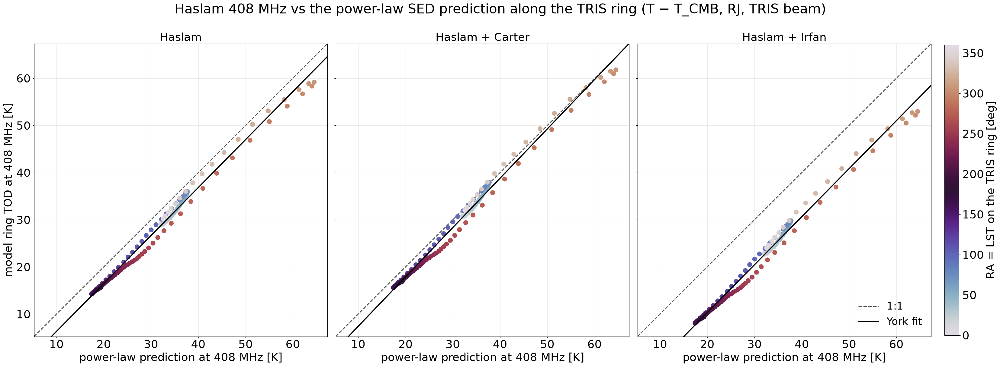

saved model_comparison/plot3_haslam_vs_fit/fig1_haslam_vs_power_law_tt.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(30, 11), sharex=True, sharey=True, layout="constrained")
lo = np.nanmin([np.nanmin(A_PL)] + [np.nanmin(T_MOD[n]) for n in HASLAMS])
hi = np.nanmax([np.nanmax(A_PL)] + [np.nanmax(T_MOD[n]) for n in HASLAMS])
pad = 0.05 * (hi - lo)
lims = np.array([lo - pad, hi + pad])
for ax, n in zip(axes, HASLAMS):
    f = FIT[(n, False)]
    ok = np.isfinite(A_PL) & np.isfinite(T_MOD[n])
    sc = ax.scatter(A_PL[ok], T_MOD[n][ok], c=RA[ok], cmap="twilight", vmin=0, vmax=360, s=110, lw=0, zorder=2)
    ax.plot(lims, lims, color="0.35", ls="--", lw=2, label="1:1", zorder=1)
    ax.plot(lims, f["a"] * lims + f["b"], color="black", lw=2.5, label="York fit", zorder=3)
    ax.set_title(SHORT[n])
    ax.set_xlim(lims); ax.set_ylim(lims); ax.set_aspect("equal")
    ax.set_xlabel("power-law prediction at 408 MHz [K]")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("model ring TOD at 408 MHz [K]")
axes[-1].legend(frameon=False, loc="lower right")
fig.colorbar(sc, ax=list(axes), shrink=0.85, pad=0.015, label="RA = LST on the TRIS ring [deg]")
fig.suptitle("Haslam 408 MHz vs the power-law SED prediction along the TRIS ring (T − T_CMB, RJ, TRIS beam)")
save(fig, "fig1_haslam_vs_power_law_tt")

#### Figure 2 — every sky model in the scale–offset plane

One point per model at (slope a, intercept b) from the same fit against the power-law prediction (all
samples). Each model has its own colour and marker, given in the legend; the Haslam versions are filled
with a black edge. The shaded 1σ ellipses have half-axes σ_a and σ_b. `york` does not return the a–b
covariance, so it is ignored and the ellipses are drawn untilted. Because the x values lie far from 0, a
and b are in fact strongly anti-correlated, so the true ellipses are tilted. The star is perfect
agreement, (1, 0). **Left:** the region around (1, 0), where six of the seven models lie. **Right:** the
full range, including GSM2016 + GINAN; the dashed box is the left panel. GSM2008 lies almost exactly on
uncorrected Haslam, so it is drawn as a smaller cross on top. **σ are underestimates** (correlated
samples).

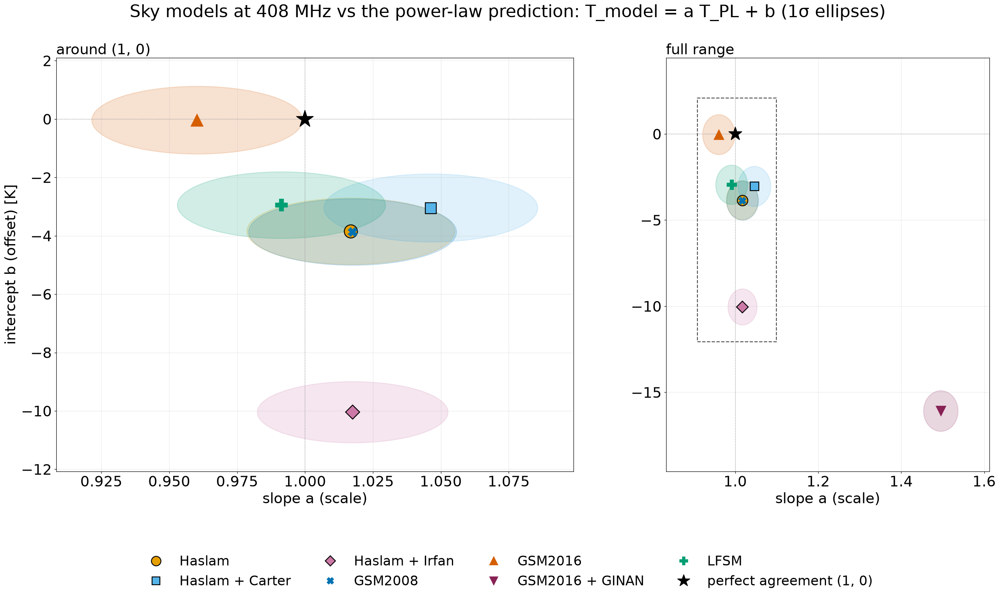

saved model_comparison/plot3_haslam_vs_fit/fig2_scale_offset_plane.png


In [ ]:
STYLE = {   # Okabe-Ito colours (plus Tol's wine), one marker per model
    "Haslam (uncorrected)":      dict(color="#E69F00", marker="o", ms=22),
    "Haslam, Carter correction": dict(color="#56B4E9", marker="s", ms=18),
    "Haslam, Irfan correction":  dict(color="#CC79A7", marker="D", ms=17),
    "GSM2008":                   dict(color="#0072B2", marker="X", ms=14),   # sits on uncorrected Haslam
    "GSM2016":                   dict(color="#D55E00", marker="^", ms=19),
    "GSM2016, GINAN correction": dict(color="#882255", marker="v", ms=19),
    "LFSM":                      dict(color="#009E73", marker="P", ms=19),
}
ZOOM_OUT = ["GSM2016, GINAN correction"]                     # shown only in the full-range panel

def draw(ax, models, ms_scale=1.0):
    for n in models:
        f, st = FIT[(n, False)], STYLE[n]
        ax.add_patch(Ellipse((f["a"], f["b"]), 2 * f["sa"], 2 * f["sb"], fc=st["color"], ec=st["color"],
                             alpha=0.18, lw=1.5, zorder=1))
        ax.plot(f["a"], f["b"], ls="none", marker=st["marker"], ms=st["ms"] * ms_scale, color=st["color"],
                mec="black" if n in HASLAMS else st["color"], mew=1.5, zorder=4 if n == "GSM2008" else 3,
                label=SHORT[n])
    ax.plot(1, 0, ls="none", marker="*", ms=30 * ms_scale, color="black", zorder=5, label="perfect agreement (1, 0)")
    ax.axvline(1, color="0.6", lw=1, ls=":"); ax.axhline(0, color="0.6", lw=1, ls=":")
    ax.grid(alpha=0.25)

fig, (ax, axf) = plt.subplots(1, 2, figsize=(28, 12.5), gridspec_kw=dict(width_ratios=[1.6, 1], wspace=0.22))
near = [n for n in MODELS if n not in ZOOM_OUT]
draw(ax, near)
ea = np.array([[FIT[(n, False)]["a"] - FIT[(n, False)]["sa"], FIT[(n, False)]["a"] + FIT[(n, False)]["sa"]] for n in near] + [[1, 1]])
eb = np.array([[FIT[(n, False)]["b"] - FIT[(n, False)]["sb"], FIT[(n, False)]["b"] + FIT[(n, False)]["sb"]] for n in near] + [[0, 0]])
xr, yr = (ea.min(), ea.max()), (eb.min(), eb.max())
px, py = 0.08 * (xr[1] - xr[0]), 0.08 * (yr[1] - yr[0])
zx, zy = (xr[0] - px, xr[1] + px), (yr[0] - py, yr[1] + py)
ax.set_xlim(zx); ax.set_ylim(zy)
ax.set_xlabel("slope a (scale)"); ax.set_ylabel("intercept b (offset) [K]")
ax.set_title("around (1, 0)", loc="left")

draw(axf, MODELS, ms_scale=0.8)
axf.add_patch(plt.Rectangle((zx[0], zy[0]), zx[1] - zx[0], zy[1] - zy[0], fill=False, ec="0.3", ls="--", lw=1.5))
axf.margins(0.12)
axf.set_xlabel("slope a (scale)")
axf.set_title("full range", loc="left")

h, l = axf.get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.13), markerscale=0.9)
fig.suptitle("Sky models at 408 MHz vs the power-law prediction: T_model = a T_PL + b (1σ ellipses)", y=0.98)
save(fig, "fig2_scale_offset_plane")

#### Figure 3 — model / prediction along the ring

The 408 MHz TOD of each Haslam version divided by the power-law prediction, at every ring sample. The
horizontal line is a ratio of 1; the light shading is RA 299.9 ± 25° (Cygnus A), the window the table
excludes.

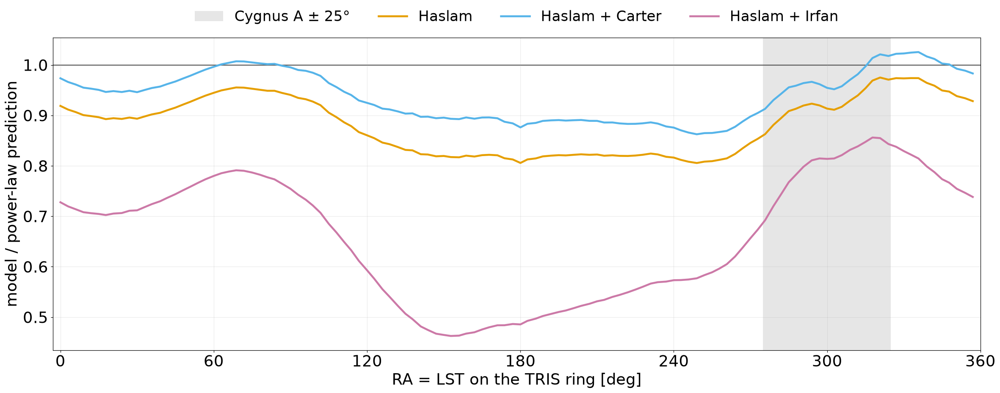

saved model_comparison/plot3_haslam_vs_fit/fig3_ratio_along_ring.png


In [ ]:
fig, ax = plt.subplots(figsize=(22, 9))
ax.axvspan(CYG_A_RA - CYG_HALF, CYG_A_RA + CYG_HALF, color="0.9", lw=0, zorder=0, label="Cygnus A ± 25°")
ax.axhline(1, color="0.3", lw=1.5, zorder=1)
for n in HASLAMS:
    ax.plot(RA, T_MOD[n] / A_PL, lw=3, color=COLOUR[n], label=SHORT[n], zorder=2)
ax.set_xlim(-3, 360); ax.set_xticks(np.arange(0, 361, 60))
ax.set_xlabel("RA = LST on the TRIS ring [deg]")
ax.set_ylabel("model / power-law prediction")
ax.grid(alpha=0.25)
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.13))
fig.tight_layout()
save(fig, "fig3_ratio_along_ring")

### Table — fit and ratio for every model

For each of the seven models: a, σ_a, b, σ_b, χ²/ν, the number of samples, and the mean and median of
model / prediction. There are two versions: all samples, and with RA 299.9 ± 25° excluded. Saved as
`haslam_vs_power_law_fits.csv`. **σ are underestimates** (correlated samples).

In [ ]:
rows = []
for ex in (False, True):
    for n in MODELS:
        f = FIT[(n, ex)]
        rows.append({"samples": "excluding Cygnus A ± 25°" if ex else "all", "model": n,
                     "slope a": f["a"], "σ_a": f["sa"], "intercept b [K]": f["b"], "σ_b [K]": f["sb"],
                     "χ²/ν": f["chi2_dof"], "N samples": f["n"],
                     "mean ratio": f["mean_ratio"], "median ratio": f["median_ratio"]})
tab = pd.DataFrame(rows)
tab.to_csv(OUT_DIR / "haslam_vs_power_law_fits.csv", index=False)
print(f"saved {(OUT_DIR / 'haslam_vs_power_law_fits.csv').relative_to(REPO)}  (σ inflated by √(χ²/ν) when > 1: {INFLATE})\n")
with pd.option_context("display.width", 220):
    print(tab.round(3).to_string(index=False))

saved model_comparison/plot3_haslam_vs_fit/haslam_vs_power_law_fits.csv  (σ inflated by √(χ²/ν) when > 1: True)

                 samples                     model  slope a   σ_a  intercept b [K]  σ_b [K]  χ²/ν  N samples  mean ratio  median ratio
                     all      Haslam (uncorrected)    1.017 0.038           -3.845    1.137 0.065        120       0.881         0.894
                     all Haslam, Carter correction    1.046 0.039           -3.048    1.166 0.064        120       0.939         0.947
                     all  Haslam, Irfan correction    1.018 0.035          -10.046    1.049 0.078        120       0.661         0.705
                     all                   GSM2008    1.017 0.038           -3.872    1.137 0.064        120       0.881         0.894
                     all                   GSM2016    0.960 0.039           -0.040    1.160 0.114        120       0.960         0.961
                     all GSM2016, GINAN correction    1.495 0.041          -1

### Summary

Results from the run on 2026-10-27: 120 ring samples (103 without Cygnus A ± 25°), power law
maximum-likelihood prediction, `york` with σ scaled by √(χ²/ν) where χ²/ν > 1 (χ²/ν is 0.04–0.24 for
every model, so no fit is scaled). **Every σ is an underestimate** (correlated samples, roughly ×2.6;
Haslam's common error treated as independent), and a and b are strongly anti-correlated.

* **Haslam (uncorrected): scale a = 1.021 ± 0.038, offset b = −3.94 ± 1.14 K.** The slope is within 1σ
  of 1; the intercept is 3.9 K below 0. Haslam / prediction has a median of 0.894 (mean 0.882) and runs
  from about 0.81 (RA ≈ 180° and 250°) to 0.98 (RA ≈ 320–330°).
* **Carter moves the offset toward 0 and the scale away from 1; Irfan moves the offset away from 0.**
  Carter: a = 1.050 ± 0.039, b = −3.14 ± 1.17 K (b up by 0.80 K, a up by 0.029); median ratio 0.947.
  Irfan: a = 1.022 ± 0.035, b = −10.14 ± 1.05 K (b down by 6.2 K, a unchanged); median ratio 0.705.
* **GSM2016 + GINAN is the farthest point:** a = 1.492 ± 0.041, b = −16.0 ± 1.2 K. Its median ratio
  is 1.016 (mean 0.927).
* **GSM2016 is the closest point to (1, 0):** a = 0.958 ± 0.039, b = +0.02 ± 1.16 K, median ratio
  0.962. GSM2008 sits on top of uncorrected Haslam (a = 1.020, b = −3.93 K). LFSM is at a = 0.980 ± 0.038,
  b = −2.56 ± 1.14 K, median ratio 0.885.
* **Excluding Cygnus A ± 25° moves the slopes up and the offsets down.** Haslam goes to a = 1.055 ± 0.054,
  b = −4.77 ± 1.47 K (median ratio 0.861) and Carter to a = 1.085, b = −3.99 K. GSM2016 moves the most
  among the models near (1, 0): a = 1.053, b = −2.29 K. LFSM moves least (a = 0.990, b = −2.84 K) and
  GINAN goes to a = 1.616, b = −18.96 K. All the Haslam shifts are within 1σ of the all-sample fit.

# Part G — Haslam calibrated with one gain and offset

**Origin:** `notebooks/17_haslam_gain_offset_calibration.ipynb` (archived: `../moonrunes_archive_2026-11-16/notebooks/17_haslam_gain_offset_calibration.ipynb`)

| | |
|---|---|
| **Reads** | `paper_outputs/pipeline/step5_fit/` (`fits/`, `ring_ra.npy`), `paper_outputs/pipeline/step2_ring_tods/``sky_tods.npz`, `configs/model_comp_config.yaml` |
| **Writes** | `test_outputs/plot3_haslam_calibration/` |
| **Feeds the paper** | possibly the "2–3 K after the best single gain and offset" in main.tex:647 (not confirmed); its g, z equal fig9 (c) |

**Stored outputs** are from the original notebook (not re-run after the merge).

**Pipeline:** reads the pipeline's step 2 and step 5 products.

## Calibrating Haslam 408 MHz with a gain and an offset

**Purpose.** This is Phil's plot 3: Haslam 408 MHz calibrated with a **gain and an offset** along the TRIS
ring, against the power law fitted at each ring sample to every survey that has a ring TOD.

**The fit.** At each ring sample $i$ the sky is a power law $A_i\,(\nu/408\ \mathrm{MHz})^{\beta_i}$. It
is fitted to all the feasible ring surveys: TRIS 600 and 820 MHz (effective 600.5 and 817.8 MHz,
`ring_sigma` errors), LWA1 35 and 80 MHz, Maipu 45 MHz and Stockert 1420 MHz (published errors). These
are the six surveys with ring TODs on the TOD route, as in notebooks 12–16. CHIPASS and Rhodes cover
only part of the sky and enter only the map route, and ARCADE 2 is excluded (`sed.exclude_maps`).
Haslam is not one of the fit points: it is the map being calibrated, with a gain $g$ and offset $z$
shared by all samples:

$$T_{\mathrm{Haslam},i} = g\,A_i + z.$$

A sample is fitted only if it has at least **4** usable points (`min_points` in
`configs/model_comp_config.yaml`), so the power law has at least 2 degrees of freedom. Every ring sample
has all six.

The fit is done in two steps:

1. Per sample, the power-law fit to the six surveys gives the predicted 408 MHz value $P_i = A_i$. This
   is the maximum-likelihood point of notebook 12's UltraNest fit, with the posterior standard deviation
   of $A_i$ as its error.
2. A York errors-in-variables fit of Haslam$_i$ (y) against $P_i$ (x) gives $g$, $z$ and their errors
   and covariance. σ is inflated by √(χ²/ν) when χ²/ν > 1, as in notebook 14.

This is **equivalent to the joint fit** of $g$, $z$ and all $(A_i, \beta_i)$, with Haslam as a seventh
point $g A_i + z$ at each sample. The equivalence holds to first order, treating the posterior of $A_i$
(with $\beta_i$ marginalised) as Gaussian: York's adjusted $x_i$ is the joint fit's $A_i$. The fit is
the same as notebook 16's uncorrected-Haslam row ($a = g$, $b = z$), written here as a correction.

The result is reported as the **correction to Haslam**,

$$T_\mathrm{corrected} = s\,T_\mathrm{Haslam} + o, \qquad s = 1/g, \qquad o = -z/g,$$

with propagated errors. Uncorrected Haslam is $(s, o) = (1, 0)$. It is compared with the published
corrections in `sky_tods.npz` (Carter, Irfan and GINAN), each reduced to its own $(s_k, o_k)$.

* **Figure 1:** Haslam against the power-law prediction, T–T.
* **Figure 2 (main result):** the calibration plane (s, o).
* **Figure 3:** the prediction and the Haslam versions along the ring, with residuals.
* **Table:** the fit (all samples and without Cygnus A) and the published corrections.

All temperatures are Rayleigh–Jeans with the CMB removed, through the TRIS beam.

> **Caveats.**
> * **Correlated samples.** The 120 ring samples are 3° apart under a ~20° beam, so they are correlated.
>   Every σ here is an underestimate, by roughly √(120/18) ≈ ×2.6.
> * **The prediction.** The power law's 408 MHz value is an interpolation between LWA1 80 and TRIS 600,
>   so it is only as good as that fit. TRIS 600 (σ/T ≈ 0.5%) carries most of the weight, so P's error is
>   small (≈ 0.5%).
> * **Common errors.** The scale and zero-level errors (Haslam 10% ⊕ 3 K, the surveys' published scale and
>   zero levels, the TRIS zero levels) are common to all samples, but they are treated here as
>   independent per sample.
> * **A single power law from 35 MHz to 1.4 GHz is assumed.** Curvature is not tested here.
> * **No causes.** The text describes sizes and positions only.

**Inputs** (read only), from notebook 12's cache `paper_outputs/sky_models_408/cache/`:
`fits/unitNNN__power_law.npz` (the power-law fit per ring sample, with its data points), `sky_tods.npz`
(Haslam and its published corrections at 408 MHz through the TRIS beam, with beam coverage) and
`ring_ra.npy`. Loading code, style and caveats follow notebook 16, and `york` is copied from
notebook 14. Figures and the CSV go to `test_outputs/plot3_haslam_calibration/`.
Rerun: Restart & Run All (seconds).

In [ ]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Patch

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PIPE2 = REPO / "paper_outputs" / "pipeline" / "step2_ring_tods"   # run_pipeline.py step 2 (ring TODs), read only
PIPE5 = REPO / "paper_outputs" / "pipeline" / "step5_fit"         # run_pipeline.py step 5 (our model's fits), read only
OUT_DIR = REPO / "test_outputs" / "plot3_haslam_calibration"
HASLAM_FILE = "HASLAM_DESTRIPED_ONLY.fits"

COV_MIN = 0.5              # a model sample is kept when its beam coverage >= this (notebooks 12-16)
INFLATE = True             # scale σ by sqrt(χ²/ν) when χ²/ν > 1 (notebook 14's rule)
CYG_A_RA, CYG_HALF = 299.9, 25.0     # Cygnus A and the half-width of the excluded / shaded window [deg]
with open(REPO / "configs" / "model_comp_config.yaml") as f:
    MIN_POINTS = int(yaml.safe_load(f)["data"]["min_points"])   # 4: minimum usable points per power-law fit
# The surveys with ring TODs on the TOD route (the fit points of notebooks 12-16); Haslam is not one of them.
RING_SURVEYS = {"TRIS_600": "TRIS 600", "TRIS_820": "TRIS 820", "LWA_35MHz.fits": "LWA1 35",
                "MAIPU_45mhZ.fits": "Maipu 45", "LWA_80MHz.fits": "LWA1 80",
                "STOCKERT_VILLA_1400MHZ.fits": "Stockert 1420"}
NU_H = 408.0

# sky_tods.npz order: 0 Haslam, 1 Carter, 2 Irfan, 3 GSM2008, 4 GSM2016, 5 GINAN, 6 LFSM
HASLAM = "Haslam (uncorrected)"
CORRECTIONS = {"Haslam, Carter correction": "Carter", "Haslam, Irfan correction": "Irfan",
               "GSM2016, GINAN correction": "GINAN"}
# Okabe-Ito, as notebooks 13 and 16
COLOUR = {"P": "black", "Haslam": "#E69F00", "fit": "#009E73", "Carter": "#56B4E9", "Irfan": "#CC79A7",
          "GINAN": "#882255"}

plt.rcParams.update({"figure.dpi": 110, "font.size": 24, "axes.titlesize": 24,
                     "axes.labelsize": 24, "legend.fontsize": 22, "figure.facecolor": "white"})
OUT_DIR.mkdir(exist_ok=True)

def save(fig, name):
    # Save a figure as PNG in OUT_DIR, then show it inline.
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"saved {(OUT_DIR / f'{name}.png').relative_to(REPO)}")

### 1. Inputs

* **The power-law prediction P:** at each ring sample, the maximum-likelihood `A_K` of the cached
  power-law fit, and the standard deviation of its posterior `A_K` samples (notebook 16's x axis). The
  cell checks which surveys each fit used and how many points it had. A sample is used only if its fit
  had at least `MIN_POINTS` (4) points, all from the six ring surveys.
* **Haslam and the corrections:** the 408 MHz ring TODs from `sky_tods.npz`, kept where the beam coverage
  is ≥ `COV_MIN`. Haslam's error is `sed_prototype.sigma_for` (10% scale ⊕ 3 K zero level), as in
  notebooks 14 and 16.

A sample is used when Haslam's coverage is ≥ 0.5 and its power-law fit is valid.

In [ ]:
sys.dont_write_bytecode = True
sys.path.insert(0, str(REPO / "src"))
from moonrunes.sed_prototype import sigma_for

RA = np.load(PIPE5 / "ring_ra.npy")
N = RA.size

z = np.load(PIPE2 / "sky_tods.npz", allow_pickle=False)
names = [str(n) for n in z["names"]]
assert names[0] == HASLAM and set(CORRECTIONS) <= set(names), names
T_MOD = {n: np.where(z[f"cov_{i}"] >= COV_MIN, z[f"tod_{i}"], np.nan) for i, n in enumerate(names)}
T_H = T_MOD[HASLAM]
S_H = np.asarray(sigma_for(dict(freq_mhz=NU_H, file=HASLAM_FILE), T_H), dtype=float)

P, S_P, NPTS = np.full(N, np.nan), np.full(N, np.nan), np.zeros(N, dtype=int)
used = {k: 0 for k in RING_SURVEYS}
for u in range(N):
    p = PIPE5 / "fits" / f"unit{u:03d}__power_law.npz"
    if not p.exists():
        continue
    r = np.load(p, allow_pickle=False)
    keys = [str(x) for x in r["keys"]]
    assert set(keys) <= set(RING_SURVEYS), keys             # six ring surveys only; Haslam is never a fit point
    NPTS[u] = len(keys)
    for k in keys:
        used[k] += 1
    if NPTS[u] < MIN_POINTS:
        continue
    iA = [str(x) for x in r["names"]].index("A_K")
    P[u] = float(r["maxpoint"][iA])
    S_P[u] = float(np.std(r["samples"][:, iA]))

USE = np.isfinite(P) & np.isfinite(S_P) & np.isfinite(T_H) & np.isfinite(S_H)
CYG = np.abs(RA - CYG_A_RA) <= CYG_HALF
print("power-law fit points per sample:", {int(k): int(v) for k, v in zip(*np.unique(NPTS, return_counts=True))},
      f"(minimum required {MIN_POINTS})")
print("samples using each survey:", {RING_SURVEYS[k]: v for k, v in used.items()})
print(f"{int(USE.sum())} of {N} samples used (Haslam coverage ≥ {COV_MIN}, power-law fit with ≥ {MIN_POINTS} points); "
      f"{int((USE & CYG).sum())} in RA {CYG_A_RA - CYG_HALF:g}–{CYG_A_RA + CYG_HALF:g}°")
print(f"P(408): median {np.nanmedian(P[USE]):.2f} K, median σ_P/P {100 * np.nanmedian(S_P[USE] / P[USE]):.2f}%;  "
      f"Haslam median σ/T {100 * np.nanmedian(S_H[USE] / T_H[USE]):.1f}%")

power-law fit points per sample: {6: 120} (minimum required 4)
samples using each survey: {'TRIS 600': 120, 'TRIS 820': 120, 'LWA1 35': 120, 'Maipu 45': 120, 'LWA1 80': 120, 'Stockert 1420': 120}
120 of 120 samples used (Haslam coverage ≥ 0.5, power-law fit with ≥ 4 points); 17 in RA 274.9–324.9°
P(408): median 32.13 K, median σ_P/P 0.54%;  Haslam median σ/T 14.4%


### 2. The gain–offset fit and the correction to Haslam

`york` is copied unchanged from notebook 14 (the same function as notebook 16). It does not return the
covariance of slope and intercept, so `york_cov` computes it alongside, from York et al. (2004) for the
same data and slope: cov(a, b) = −x̄_adj σ_a², where x̄_adj is the weighted mean of the adjusted x values.
It applies the same √(χ²/ν) inflation. This covariance is used for the errors on (s, o) and for the
ellipses in Figure 2. Then

$$s = 1/g, \qquad o = -z/g, \qquad
J = \begin{pmatrix} -1/g^2 & 0 \\ z/g^2 & -1/g \end{pmatrix}, \qquad C_{so} = J\,C_{gz}\,J^\mathsf{T}.$$

The fit is run with all samples and with RA 299.9 ± 25° excluded.

In [ ]:
def york(x, y, sx, sy, n_iter=200, tol=1e-12):
    # y = a x + b with errors on both axes (York et al. 2004, Am. J. Phys. 72, 367; no x-y correlation).
    vx, vy = np.asarray(sx, float) ** 2, np.asarray(sy, float) ** 2
    a = np.polyfit(x, y, 1)[0]
    for _ in range(n_iter):
        W = 1.0 / (vy + a * a * vx)
        xb, yb = np.sum(W * x) / W.sum(), np.sum(W * y) / W.sum()
        U, V = x - xb, y - yb
        bet = W * (U * vy + a * V * vx)
        a_new = np.sum(W * bet * V) / np.sum(W * bet * U)
        done = abs(a_new - a) <= tol * abs(a_new)
        a = a_new
        if done:
            break
    W = 1.0 / (vy + a * a * vx)
    xb, yb = np.sum(W * x) / W.sum(), np.sum(W * y) / W.sum()
    b = yb - a * xb
    xa = xb + W * ((x - xb) * vy + a * (y - yb) * vx)          # adjusted x values
    xab = np.sum(W * xa) / W.sum()
    sa = np.sqrt(1.0 / np.sum(W * (xa - xab) ** 2))
    sb = np.sqrt(1.0 / W.sum() + xab ** 2 * sa ** 2)
    chi2 = float(np.sum(W * (y - a * x - b) ** 2))
    dof = x.size - 2
    f = np.sqrt(max(1.0, chi2 / dof)) if INFLATE else 1.0
    return dict(a=a, sa=sa * f, b=b, sb=sb * f, chi2_dof=chi2 / dof)

def york_cov(x, y, sx, sy, fit):
    # cov(a, b) of the York fit above (York et al. 2004: -x̄_adj σ_a²), with the same √(χ²/ν) inflation.
    vx, vy, a = np.asarray(sx, float) ** 2, np.asarray(sy, float) ** 2, fit["a"]
    W = 1.0 / (vy + a * a * vx)
    xb, yb = np.sum(W * x) / W.sum(), np.sum(W * y) / W.sum()
    xa = xb + W * ((x - xb) * vy + a * (y - yb) * vx)
    xab = np.sum(W * xa) / W.sum()
    return -xab * fit["sa"] ** 2

def calibrate(exclude_cyg=False):
    ok = USE & ~CYG if exclude_cyg else USE
    x, y, sx, sy = P[ok], T_H[ok], S_P[ok], S_H[ok]
    f = york(x, y, sx, sy)
    g, zz = f["a"], f["b"]
    cgz = york_cov(x, y, sx, sy, f)
    C = np.array([[f["sa"] ** 2, cgz], [cgz, f["sb"] ** 2]])
    J = np.array([[-1 / g ** 2, 0.0], [zz / g ** 2, -1 / g]])
    Cso = J @ C @ J.T
    return dict(g=g, sg=f["sa"], z=zz, sz=f["sb"], rho_gz=cgz / (f["sa"] * f["sb"]), chi2_dof=f["chi2_dof"],
                n=int(ok.sum()), s=1 / g, o=-zz / g, ss=np.sqrt(Cso[0, 0]), so=np.sqrt(Cso[1, 1]),
                rho_so=Cso[0, 1] / np.sqrt(Cso[0, 0] * Cso[1, 1]), C_so=Cso)

CAL = {ex: calibrate(ex) for ex in (False, True)}
MAIN = CAL[False]
for ex, c in CAL.items():
    print(f"{'excl. Cygnus' if ex else 'all':<12}: g = {c['g']:.3f} ± {c['sg']:.3f}, z = {c['z']:+.2f} ± {c['sz']:.2f} K "
          f"(ρ = {c['rho_gz']:+.2f}) -> s = {c['s']:.3f} ± {c['ss']:.3f}, o = {c['o']:+.2f} ± {c['so']:.2f} K "
          f"(ρ = {c['rho_so']:+.2f}); χ²/ν = {c['chi2_dof']:.3g}, N = {c['n']}")

all         : g = 1.017 ± 0.038, z = -3.85 ± 1.14 K (ρ = -0.95) -> s = 0.983 ± 0.037, o = +3.78 ± 0.98 K (ρ = -0.93); χ²/ν = 0.0645, N = 120
excl. Cygnus: g = 1.055 ± 0.054, z = -4.77 ± 1.47 K (ρ = -0.97) -> s = 0.948 ± 0.048, o = +4.52 ± 1.17 K (ρ = -0.95); χ²/ν = 0.0565, N = 103


### 3. The published corrections as (s, o)

Each correction's 408 MHz ring TOD is fitted against uncorrected Haslam's with an ordinary straight line,
$T_k = s_k\,T_\mathrm{Haslam} + o_k$, over the samples where both have coverage ≥ 0.5. The **scatter** is
the rms of the residuals. Carter (1.029 × Haslam + 0.91 K) and Irfan (an offset only) are linear in Haslam
and the beam is normalised, so their scatter should be at rounding level. GINAN is a correction to GSM2016
and is not linear in Haslam, so its (s, o) is only the best straight line.

In [ ]:
CORR = {}
for name, short in CORRECTIONS.items():
    y = T_MOD[name]
    ok = np.isfinite(T_H) & np.isfinite(y)
    sk, ok_ = np.polyfit(T_H[ok], y[ok], 1)
    CORR[short] = dict(s=sk, o=ok_, scatter=float(np.sqrt(np.mean((y[ok] - (sk * T_H[ok] + ok_)) ** 2))), n=int(ok.sum()))
    print(f"{short:<7}: s = {sk:.4f}, o = {ok_:+.3f} K, rms scatter {CORR[short]['scatter']:.3g} K (N = {CORR[short]['n']})")

Carter : s = 1.0290, o = +0.910 K, rms scatter 1.98e-13 K (N = 120)
Irfan  : s = 1.0000, o = -6.184 K, rms scatter 1.45e-13 K (N = 120)
GINAN  : s = 1.4383, o = -9.496 K, rms scatter 1.16 K (N = 120)


#### Figure 1 — Haslam against the power-law prediction

x is the power-law prediction at 408 MHz, P_i, from the fit to the six ring surveys, and y is the
uncorrected Haslam ring TOD. The points are the ring samples, coloured by RA, drawn without error bars
(the fit uses them: σ_P/P ≈ 0.5%, and Haslam's 10% ⊕ 3 K). The dashed line is 1:1 and the black line is
the York fit T_Haslam = g P + z; g, z, their errors and χ²/ν are in the table at the end. **σ are
underestimates**: correlated samples, and the common scale and zero-level errors are treated as
independent.

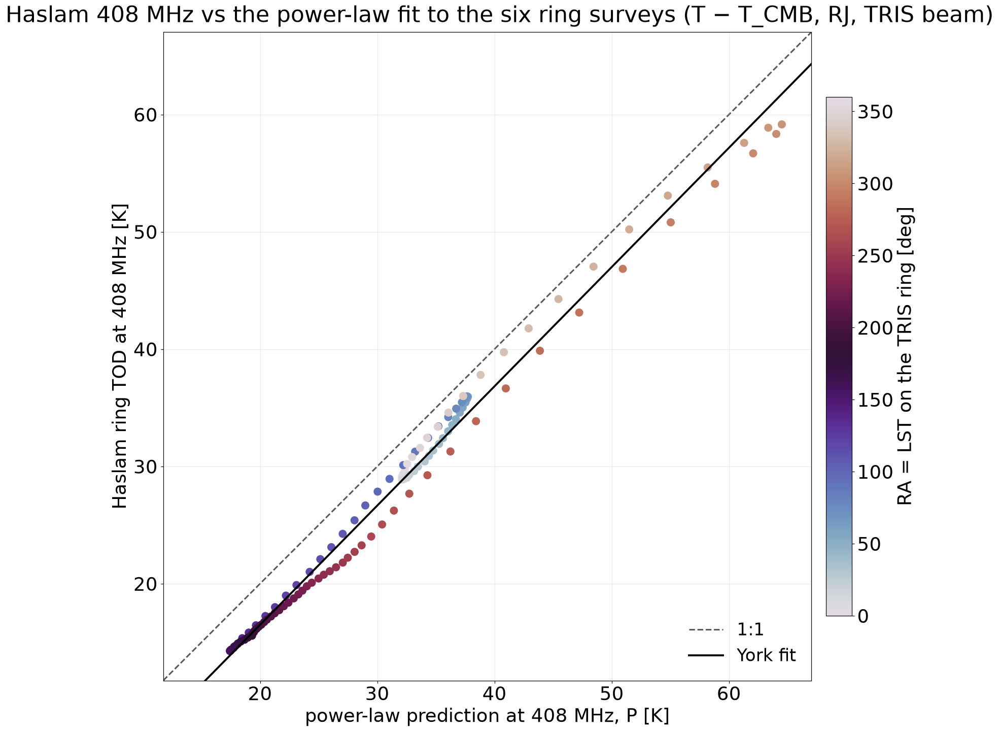

saved model_comparison/plot3_haslam_calibration/fig1_haslam_vs_power_law_tt.png


In [ ]:
fig, ax = plt.subplots(figsize=(15, 13), layout="constrained")
ok = USE
lo = np.nanmin([np.nanmin(P[ok]), np.nanmin(T_H[ok])]); hi = np.nanmax([np.nanmax(P[ok]), np.nanmax(T_H[ok])])
pad = 0.05 * (hi - lo)
lims = np.array([lo - pad, hi + pad])
sc = ax.scatter(P[ok], T_H[ok], c=RA[ok], cmap="twilight", vmin=0, vmax=360, s=110, lw=0, zorder=2)
ax.plot(lims, lims, color="0.35", ls="--", lw=2, label="1:1", zorder=1)
ax.plot(lims, MAIN["g"] * lims + MAIN["z"], color="black", lw=2.5, label="York fit", zorder=3)
ax.set_xlim(lims); ax.set_ylim(lims); ax.set_aspect("equal")
ax.set_xlabel("power-law prediction at 408 MHz, P [K]")
ax.set_ylabel("Haslam ring TOD at 408 MHz [K]")
ax.grid(alpha=0.25)
ax.legend(frameon=False, loc="lower right")
fig.colorbar(sc, ax=ax, shrink=0.8, pad=0.02, label="RA = LST on the TRIS ring [deg]")
fig.suptitle("Haslam 408 MHz vs the power-law fit to the six ring surveys (T − T_CMB, RJ, TRIS beam)")
save(fig, "fig1_haslam_vs_power_law_tt")

#### Figure 2 — the calibration plane (main result)

The correction to Haslam, $T_\mathrm{corrected} = s\,T_\mathrm{Haslam} + o$. The fitted calibration
(all samples) is the filled green circle with its shaded 1σ ellipse. The ellipse uses the full (s, o)
covariance propagated from York's (g, z) covariance. The open green square with the dashed ellipse is the
same fit with Cygnus A ± 25° excluded. Carter, Irfan and GINAN are each correction's own (s, o) from
Section 3, and the star is uncorrected Haslam, (1, 0). The legend identifies each point. **σ are
underestimates** (correlated samples; common errors treated as independent).

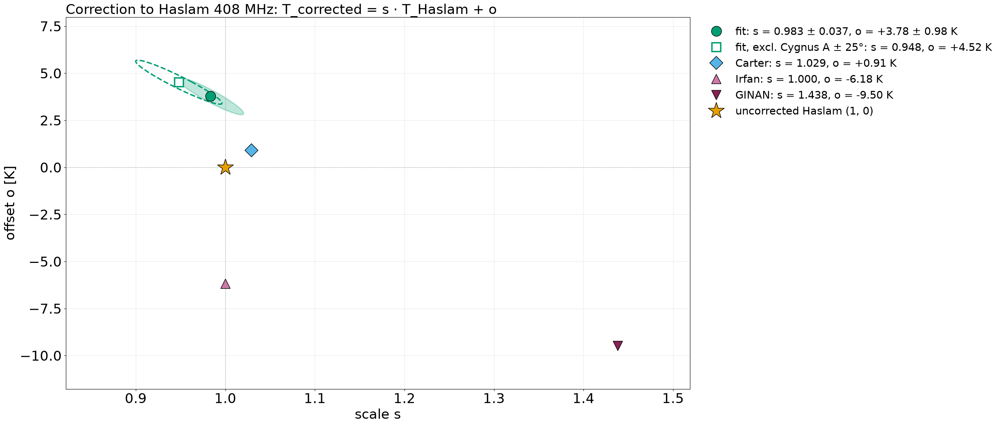

saved model_comparison/plot3_haslam_calibration/fig2_calibration_plane.png


In [ ]:
def ellipse(c, nsig=1.0, **kw):
    w, V = np.linalg.eigh(c["C_so"])
    ang = np.degrees(np.arctan2(V[1, 1], V[0, 1]))
    return Ellipse((c["s"], c["o"]), 2 * nsig * np.sqrt(w[1]), 2 * nsig * np.sqrt(w[0]), angle=ang, **kw)

cx = CAL[True]
fig, ax = plt.subplots(figsize=(20, 12))
ax.add_patch(ellipse(MAIN, fc=COLOUR["fit"], ec=COLOUR["fit"], alpha=0.25, lw=2.5))
ax.add_patch(ellipse(cx, fc="none", ec=COLOUR["fit"], ls="--", lw=2.5))
ax.plot(MAIN["s"], MAIN["o"], "o", ms=18, color=COLOUR["fit"], mec="black", ls="none", zorder=4,
        label=f"fit: s = {MAIN['s']:.3f} ± {MAIN['ss']:.3f}, o = {MAIN['o']:+.2f} ± {MAIN['so']:.2f} K")
ax.plot(cx["s"], cx["o"], "s", ms=16, mfc="white", mec=COLOUR["fit"], mew=2.5, ls="none", zorder=4,
        label=f"fit, excl. Cygnus A ± 25°: s = {cx['s']:.3f}, o = {cx['o']:+.2f} K")
for short, marker in zip(CORR, ("D", "^", "v")):
    c = CORR[short]
    ax.plot(c["s"], c["o"], marker, ms=17, color=COLOUR[short], mec="black", ls="none", zorder=4,
            label=f"{short}: s = {c['s']:.3f}, o = {c['o']:+.2f} K")
ax.plot(1, 0, marker="*", ms=30, color=COLOUR["Haslam"], mec="black", ls="none", zorder=5,
        label="uncorrected Haslam (1, 0)")
ax.axvline(1, color="0.6", lw=1, ls=":"); ax.axhline(0, color="0.6", lw=1, ls=":")
ax.margins(0.15)
ax.set_xlabel("scale s")
ax.set_ylabel("offset o [K]")
ax.grid(alpha=0.25)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=19)
ax.set_title("Correction to Haslam 408 MHz: T_corrected = s · T_Haslam + o", loc="left")
save(fig, "fig2_calibration_plane")

#### Figure 3 — along the ring

**Top:** the power-law prediction P_i (black, with its ±1σ band, about 0.5% wide), uncorrected Haslam,
Haslam with the fitted correction (s, o), and the Carter- and Irfan-corrected Haslam TODs. **Bottom:**
each Haslam version minus P_i, in K, with P's ±1σ band around 0. The light grey shading is RA
299.9 ± 25° (Cygnus A), given in the legend. **σ are underestimates** (correlated samples).

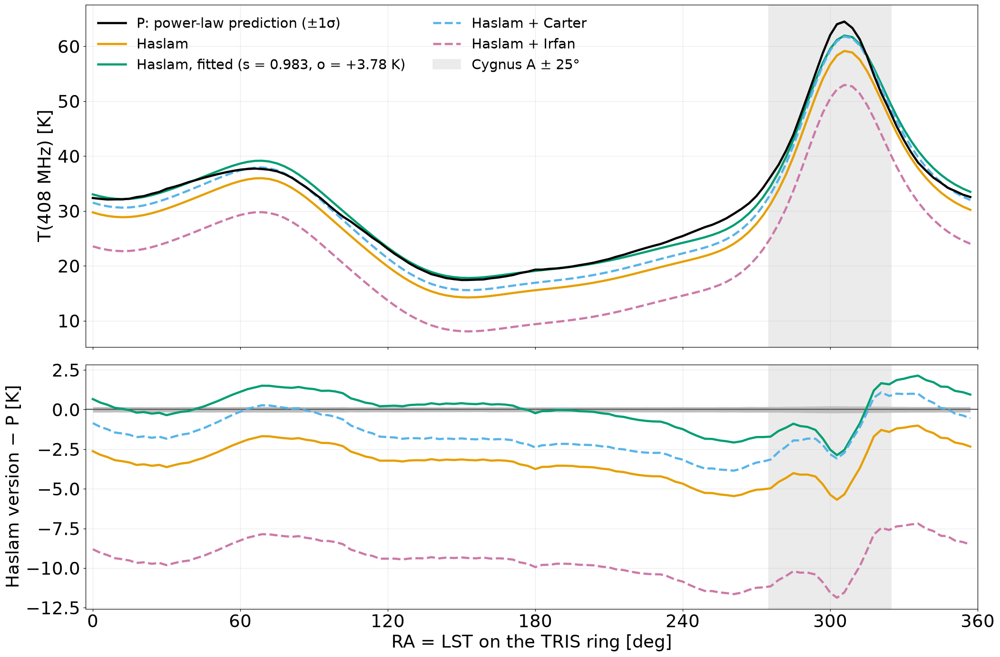

saved model_comparison/plot3_haslam_calibration/fig3_along_ring.png


In [ ]:
H_FIT = MAIN["s"] * T_H + MAIN["o"]
LINES = {"Haslam": (T_H, "-"), f"Haslam, fitted (s = {MAIN['s']:.3f}, o = {MAIN['o']:+.2f} K)": (H_FIT, "-"),
         "Haslam + Carter": (T_MOD["Haslam, Carter correction"], "--"), "Haslam + Irfan": (T_MOD["Haslam, Irfan correction"], "--")}
LCOL = dict(zip(LINES, [COLOUR["Haslam"], COLOUR["fit"], COLOUR["Carter"], COLOUR["Irfan"]]))
Pm = np.where(USE, P, np.nan); Sm = np.where(USE, S_P, np.nan)

fig, (ax, axr) = plt.subplots(2, 1, figsize=(22, 15), sharex=True, gridspec_kw=dict(height_ratios=[1.4, 1], hspace=0.06))
for a in (ax, axr):
    a.axvspan(CYG_A_RA - CYG_HALF, CYG_A_RA + CYG_HALF, color="0.92", lw=0, zorder=0)
ax.fill_between(RA, Pm - Sm, Pm + Sm, color="0.75", lw=0, zorder=1)
ax.plot(RA, Pm, color=COLOUR["P"], lw=3, label="P: power-law prediction (±1σ)", zorder=3)
axr.fill_between(RA, -Sm, Sm, color="0.75", lw=0, zorder=1)
axr.axhline(0, color="0.3", lw=1.5, zorder=1)
for lab, (y, ls) in LINES.items():
    yy = np.where(USE, y, np.nan)
    ax.plot(RA, yy, lw=3, ls=ls, color=LCOL[lab], label=lab, zorder=2)
    axr.plot(RA, yy - Pm, lw=3, ls=ls, color=LCOL[lab], zorder=2)
ax.set_ylabel("T(408 MHz) [K]")
axr.set_ylabel("Haslam version − P [K]")
axr.set_xlabel("RA = LST on the TRIS ring [deg]")
axr.set_xlim(-3, 360); axr.set_xticks(np.arange(0, 361, 60))
for a in (ax, axr):
    a.grid(alpha=0.25)
h, l = ax.get_legend_handles_labels()
h.append(Patch(color="0.92")); l.append("Cygnus A ± 25°")
ax.legend(h, l, frameon=False, ncol=2, loc="upper left", fontsize=19)
save(fig, "fig3_along_ring")

### Table — calibration fits and published corrections

The first two rows are the York gain–offset fits, with all samples and with RA 299.9 ± 25° excluded.
Each gives g, z, χ²/ν, N and the correction (s, σ_s, o, σ_o, and their correlation ρ). The last three
rows are the published corrections' own (s_k, o_k) and the rms scatter about that line. Saved as
`haslam_calibration.csv`. **σ are underestimates** (correlated samples).

In [ ]:
rows = []
for ex, c in CAL.items():
    rows.append({"row": "fit, six-survey power-law prediction", "samples": "excluding Cygnus A ± 25°" if ex else "all",
                 "s": c["s"], "σ_s": c["ss"], "o [K]": c["o"], "σ_o [K]": c["so"], "ρ(s, o)": c["rho_so"],
                 "g": c["g"], "σ_g": c["sg"], "z [K]": c["z"], "σ_z [K]": c["sz"], "χ²/ν": c["chi2_dof"], "N": c["n"],
                 "scatter [K]": np.nan})
for short, c in CORR.items():
    rows.append({"row": f"published: {short}", "samples": "all (coverage ≥ 0.5)", "s": c["s"], "σ_s": np.nan,
                 "o [K]": c["o"], "σ_o [K]": np.nan, "ρ(s, o)": np.nan, "g": np.nan, "σ_g": np.nan, "z [K]": np.nan,
                 "σ_z [K]": np.nan, "χ²/ν": np.nan, "N": c["n"], "scatter [K]": c["scatter"]})
tab = pd.DataFrame(rows)
tab.to_csv(OUT_DIR / "haslam_calibration.csv", index=False)
print(f"saved {(OUT_DIR / 'haslam_calibration.csv').relative_to(REPO)}  (σ inflated by √(χ²/ν) when > 1: {INFLATE})\n")
with pd.option_context("display.width", 260, "display.max_columns", 30):
    print(tab.round(4).to_string(index=False))

saved model_comparison/plot3_haslam_calibration/haslam_calibration.csv  (σ inflated by √(χ²/ν) when > 1: True)

                                 row                  samples      s    σ_s   o [K]  σ_o [K]  ρ(s, o)      g    σ_g   z [K]  σ_z [K]   χ²/ν   N  scatter [K]
fit, six-survey power-law prediction                      all 0.9834 0.0370  3.7817   0.9846  -0.9306 1.0168 0.0383 -3.8454   1.1371 0.0645 120          NaN
fit, six-survey power-law prediction excluding Cygnus A ± 25° 0.9481 0.0482  4.5238   1.1692  -0.9512 1.0548 0.0536 -4.7717   1.4660 0.0565 103          NaN
                   published: Carter     all (coverage ≥ 0.5) 1.0290    NaN  0.9100      NaN      NaN    NaN    NaN     NaN      NaN    NaN 120       0.0000
                    published: Irfan     all (coverage ≥ 0.5) 1.0000    NaN -6.1843      NaN      NaN    NaN    NaN     NaN      NaN    NaN 120       0.0000
                    published: GINAN     all (coverage ≥ 0.5) 1.4383    NaN -9.4960      NaN      NaN  

### Summary

Results from the run on 2026-10-27: 120 ring samples (103 without Cygnus A ± 25°). Every sample's power-law
fit has all six ring surveys (≥ 4 required). χ²/ν is 0.06 in both fits, so no σ is inflated. **Every σ is
an underestimate** (correlated samples, roughly ×2.6; common errors treated as independent). s and o are
strongly anti-correlated (ρ ≈ −0.93), so the 1σ region is the tilted ellipse in Figure 2, not the two
marginal errors. The distances in σ below use the marginal errors only.

* **Fitted correction: s = 0.980 ± 0.037, o = +3.86 ± 0.98 K.** This is from g = 1.021 ± 0.038 and
  z = −3.94 ± 1.14 K, over N = 120. The scale is 0.6σ from 1; the offset is 3.9σ from 0. Uncorrected
  Haslam − P has a median of −3.2 K. After the fitted correction, Haslam − P is −1.9 to +1.4 K outside
  RA 255–345°, and −2.7 to +2.2 K inside it (Figure 3).
* **Carter's and Irfan's scales lie within 1.4σ of the fitted scale; their offsets do not match it.**
  * Carter: s = 1.029 is 1.3σ above the fitted s; o = +0.91 K is 3.0σ below the fitted o.
  * Irfan: s = 1.000 is 0.6σ above; o = −6.18 K has the opposite sign to the fitted +3.86 K, 10σ away.
  * Both corrections are reproduced exactly by the straight-line fit on uncorrected Haslam (rms
    scatter ~1e-14 K).
* **GINAN is the farthest point:** its best straight line on Haslam is s = 1.426, o = −9.21 K, with an rms
  scatter of 1.25 K about that line. That is 0.45 above the fitted s and 13.1 K below the fitted o.
* **The fit lies between uncorrected Haslam and the published offsets in a specific direction:** it moves
  Haslam up by 3.9 K at a scale just below 1. Carter moves it up by 0.9 K at a scale above 1, and Irfan
  down by 6.2 K at a scale of 1.
* **Excluding Cygnus A ± 25° moves the fit along the ellipse: s = 0.948 ± 0.048, o = +4.52 ± 1.17 K**
  (Δs = −0.032, Δo = +0.67 K, within 1σ).

# Part H — Zero-level offsets as fit parameters

**Origin:** `notebooks/20_zero_level_offsets.ipynb` (archived: `../moonrunes_archive_2026-11-16/notebooks/20_zero_level_offsets.ipynb`)

| | |
|---|---|
| **Reads** | `paper_outputs/pipeline/step5_fit/`, `paper_outputs/pipeline/step2_ring_tods/` (`beam_matched_tods.npz`, `sky_tods.npz`), `configs/model_comp_config.yaml`, `error_bars.csv`, `inputs_audit/inputs_audit.md`, the TRIS rings |
| **Writes** | `paper_outputs/zero_level_offsets/` |
| **Feeds the paper** | main.tex:394; read by Part I |

**Stored outputs** are from the original notebook (not re-run after the merge).

**Pipeline:** reads the pipeline's step 2 and step 5 products.

## Zero-level offsets as fit parameters (plots for Phil)

**Question (from a collaborator).** Should the spectral fit include additive zero-level offsets? The TRIS II paper's
Table 3 gives systematic uncertainties much larger than the statistical ones. Phil confirmed these are most likely on
the **zero level**. A zero-level error is one number for a whole survey, so it should enter the fit as a **parameter**
with a Gaussian prior whose width is the quoted systematic, not as an extra random error added in quadrature at every
point (which is what the SED fits do now). This Part tests that and shows what changes.

**The model.** At each ring sample $i$ the sky is a power law (or, in a second configuration, a curved power law):

$$T_i(\nu) = A_i\,(\nu/408\ \mathrm{MHz})^{\beta_i}\ \big[\times\,e^{C_i \ln^2(\nu/408)}\big].$$

Each survey $k$ with a quoted zero-level uncertainty gets **one** additive offset $o_k$, **shared by all ring samples**:

$$T^{\rm meas}_{k,i} = T_i(\nu_k) + o_k + n_{k,i}, \qquad o_k \sim \mathcal N(0,\ \sigma_{{\rm zl},k}^2),$$

where the noise $n_{k,i}$ has the survey's error **without** its zero-level term (scale and noise terms kept), so the
zero level is not counted twice. The fit is the maximum a posteriori point of

$$F(\mathbf o) = \sum_{i\ \rm unmasked} \min_{A_i,\beta_i[,C_i]} \chi^2_i(\mathbf o) + \sum_k (o_k/\sigma_{{\rm zl},k})^2 ,$$

with the per-sample fits nested inside (a few parameters each) and only the shared offsets in the outer minimisation.
No nested sampling.

**Configurations.** (1) power law, offsets on every survey with a quoted zero level; (2) power law, offsets on TRIS only;
(3) curved power law, offsets as (1); (4) the baseline: no offsets, errors as they are now. Two references are added so
that every χ² change can be read: the baseline curved power law, and both models with the zero-level terms removed and
the offsets held at 0.

**Data.** The six ring surveys of the SED fits: TRIS 600 and 820 (ring data), LWA1 35, Maipu 45, LWA1 80, Stockert 1420
(TRIS-beam ring TODs). As in notebook 14, the surveys come from notebook 18's **beam-matched** TODs
(`USE_BEAM_MATCHED = True`) with their errors rebuilt from their components, and TRIS from notebook 12's fit cache
(`paper_outputs/sky_models_408/cache/fits/unitNNN__power_law.npz`, keys `nu`, `t`, `s`). That cache was made before
beam matching (2026-10-23), so its survey points are the older native-resolution TODs; `USE_BEAM_MATCHED = False` uses
them instead. Cygnus A is masked everywhere: RA 299.9 ± 25°.

> **⚠ All σ are underestimates.** The ring samples are 3° apart under a ~20° beam, so there are only about
> 360°/20° ≈ 18 independent samples, not ~100. Errors from the Hessian are therefore too small by roughly
> √(120/18) ≈ 2.6; both are reported.

**Inputs** (read only): notebook 12's cache, notebook 18's `beam_matched_tods.npz`, `src/moonrunes/sed_prototype.py`
(`PUBLISHED_ERRORS`, `ring_sigma`), `configs/error_bars.csv`, the TRIS archive (through limTOD) and
`inputs_audit/inputs_audit.md`. **Outputs:** figures and CSVs in `paper_outputs/zero_level_offsets/`; the profile
fits are cached in its `cache/`. Rerun: Restart & Run All (a few minutes without the cache, seconds with it).

In [ ]:
%matplotlib inline
import os
os.environ.setdefault("TQDM_DISABLE", "1")
import sys
import re
import json
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from scipy.optimize import minimize

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PIPE2 = REPO / "paper_outputs" / "pipeline" / "step2_ring_tods"   # run_pipeline.py step 2 (ring TODs), read only
PIPE5 = REPO / "paper_outputs" / "pipeline" / "step5_fit"         # run_pipeline.py step 5 (our model's fits), read only
BM_FILE = PIPE2 / "beam_matched_tods.npz"   # run_pipeline.py step 2, read only
ERRORS_CSV = REPO / "configs" / "error_bars.csv"
AUDIT_MD = REPO / "inputs_audit" / "inputs_audit.md"
OUT_DIR = REPO / "paper_outputs" / "zero_level_offsets"
CACHE_DIR = OUT_DIR / "cache"
HASLAM_FILE = "HASLAM_DESTRIPED_ONLY.fits"
# Beam matching (notebook 18): survey and Haslam ring TODs made with the pipeline's beam-matching kernel, as notebook 14.
USE_BEAM_MATCHED = True

# The six ring surveys, low frequency first.  key -> label; keys as in the fit cache.
SURVEYS = {"LWA_35MHz.fits": "LWA1 35", "MAIPU_45mhZ.fits": "Maipu 45", "LWA_80MHz.fits": "LWA1 80",
           "TRIS_600": "TRIS 600", "TRIS_820": "TRIS 820", "STOCKERT_VILLA_1400MHZ.fits": "Stockert 1420"}

# Cygnus A mask, applied everywhere
CYG_A_RA = 299.9
MASK_HALF_WIDTH = 25.0     # deg

# Prior width of each survey's shared zero-level offset, in K.  None = no offset for that survey.
#   TRIS: the zero-level uncertainties dT_zero of TRIS II Table 3 ("Accuracy of the absolute measurements of T_sky
#         performed by TRIS at dec = +42 deg"): 66 mK at 0.60 GHz; +430 / -300 mK at 0.82 GHz.  The prior is a
#         symmetric Gaussian, so 820 MHz uses the larger side, 0.430 K (as ring_sigma does).  Table 3 footnote a: the
#         0.82 GHz zero-level uncertainty from the absolute calibration alone is 0.659 K; the quoted +430 / -300 mK
#         comes after an astrophysical assumption on the Galactic signal (Paper III, section 3).  Not used here.
#         (2.5 GHz, 284 mK, is not one of the six surveys.)  If set to None, the fit falls back to the zero-level term
#         inside ring_sigma and prints a warning.
#   Other surveys: their published zero-level uncertainty, sed_prototype.PUBLISHED_ERRORS[...]["zero_k"] (set below);
#         a survey that quotes none (zero_k = 0) gets no offset.
ZERO_LEVEL_SIGMA_K = {
    "TRIS_600": 0.066,     # TRIS II Table 3, 0.60 GHz: dT_zero = 66 mK
    "TRIS_820": 0.430,     # TRIS II Table 3, 0.82 GHz: dT_zero = +430 / -300 mK, larger side (footnote a: 659 mK)
    "LWA_35MHz.fits": "published",
    "MAIPU_45mhZ.fits": "published",
    "LWA_80MHz.fits": "published",
    "STOCKERT_VILLA_1400MHZ.fits": "published",
}
# Map-making zero levels (z-hat) for reference only; a different route (stage 1 maps), read from inputs_audit.md.
ZHAT_EXPECTED = {"TRIS_600": (1.737, 0.043), "TRIS_820": (0.516, 0.027)}

N_INDEP = 18                                   # independent beams on the ring, 360 deg / ~20 deg
PROFILE_POINTS = 41                            # grid points per 1-D profile
TIE = 2.0                                      # |Δχ²| <= 2 (|Δ ln L| <= 1): power law and curved PL indistinguishable
REP_RA = [0.0, 120.0, 240.0]                   # Figure B: the unmasked samples nearest these RAs

with open(REPO / "configs" / "model_comp_config.yaml") as f:
    NU0 = float(yaml.safe_load(f)["models"]["nu0_mhz"])     # 408 MHz

# Okabe-Ito, colourblind-safe, one colour per configuration
CFG_COL = {"baseline": "#000000", "offsets": "#0072B2", "TRIS only": "#E69F00", "curved": "#882255", "reference": "#7F7F7F"}

sys.path.insert(0, str(REPO / "src"))
from moonrunes.style import use_tris_style, COLORS
use_tris_style()
plt.rcParams.update({"figure.dpi": 110, "font.size": 24, "axes.titlesize": 24,
                     "axes.labelsize": 24, "legend.fontsize": 20, "figure.facecolor": "white"})
OUT_DIR.mkdir(exist_ok=True)
CACHE_DIR.mkdir(exist_ok=True)

def save(fig, name):
    # Save a figure as PNG in OUT_DIR, then show it inline.
    fig.savefig(OUT_DIR / f"{name}.png")
    plt.show()
    print(f"saved {(OUT_DIR / f'{name}.png').relative_to(REPO)}")

### 1. The data and how each error is built

**How the per-point errors are made now** (read from `sed_prototype.py` and `error_bars.csv`):

* **TRIS** (`ring_sigma`): the archive's per-sample statistical error (zeros floored to the smallest positive value)
  ⊕ the archive's published zero-level uncertainty (0.066 K at 600 MHz; at 820 MHz the larger side of +0.43 / −0.30 K).
* **Surveys** (`sigma_for`, kind `published` in `error_bars.csv`): scale × |T| ⊕ zero level ⊕ rms noise, with the values
  of `PUBLISHED_ERRORS` (the CSV and the dictionary are checked against each other below).

All are added in quadrature and treated as independent per point. The cell splits each into (a) statistical / noise,
(b) scale and (c) zero level, and checks that the three rebuild the cached total. **LWA1 35 and 80 quote no separate
zero level** (Dowell et al. 2017 give one 15–25% calibration accuracy "for both structure and sky-averaged temperature"),
so their zero-level term cannot be separated: they keep their whole error and get no offset.

In [ ]:
sys.dont_write_bytecode = True
sys.path.insert(0, str(REPO / "src"))
sys.path.insert(0, str(REPO / "model_comparison"))
for _name in [n for n in sys.modules if n.split(".")[0] in ("moonrunes", "models", "run_comparison")]:
    del sys.modules[_name]
from moonrunes.config import load_config
from moonrunes.sed_prototype import PUBLISHED_ERRORS, ring_sigma, sigma_for
from moonrunes.stage1_tris_maps import import_limtod_tris
import run_comparison as rc                       # read_error_bars only

KEYS = list(SURVEYS)
RA = np.load(PIPE5 / "ring_ra.npy")
N = RA.size

# ---- the cached points (notebook 12) ----
T = {k: np.full(N, np.nan) for k in KEYS}
S_CACHE = {k: np.full(N, np.nan) for k in KEYS}
FREQ = {}
for u in range(N):
    r = np.load(PIPE5 / "fits" / f"unit{u:03d}__power_law.npz", allow_pickle=False)
    for k, nu, t, s in zip((str(x) for x in r["keys"]), r["nu"], r["t"], r["s"]):
        T[k][u], S_CACHE[k][u], FREQ[k] = t, s, float(nu)
T_CACHED = {k: v.copy() for k, v in T.items()}

# ---- error components ----
config = load_config(REPO / "configs" / "run_pipeline.yaml")
tris = import_limtod_tris(config)
archive = config.resolve_path("paths.tris_archive_dir")
csv_rows = rc.read_error_bars(ERRORS_CSV)
NOISE, SCALE_FRAC, ZL = {}, {}, {}
for k in KEYS:
    if k.startswith("TRIS_"):
        ring = tris.read_tris_ring(archive / f"TRIS_absolute_{k[5:]}.txt")
        assert np.allclose(np.asarray(ring.ra_deg), RA)
        stat = np.asarray(ring.statistical_uncertainty_k, dtype=float)
        NOISE[k] = np.where(stat > 0, stat, stat[stat > 0].min())        # as ring_sigma floors it
        z = ring.zero_level_uncertainty_k
        ZL[k] = float(z) if np.isscalar(z) else max(z.positive_k, z.negative_k)
        SCALE_FRAC[k] = 0.0
        assert np.allclose(np.hypot(NOISE[k], ZL[k]), ring_sigma(ring)), k
    else:
        row, pub = csv_rows[k], PUBLISHED_ERRORS[k]
        assert row["kind"] == "published", k
        vals = (float(row["scale_frac"]), float(row["zero_level_k"]), float(row["noise_k"]))
        assert np.allclose(vals, (pub["scale"], pub["zero_k"], pub["noise_k"])), (k, vals, pub)   # CSV == dictionary
        SCALE_FRAC[k], ZL[k], NOISE[k] = vals[0], vals[1], np.full(N, vals[2])

def total_sigma(k, t, with_zl=True):
    """The per-point error of survey k at temperatures t, with or without its zero-level term."""
    return np.sqrt(NOISE[k] ** 2 + (SCALE_FRAC[k] * t) ** 2 + (ZL[k] ** 2 if with_zl else 0.0))

for k in KEYS:     # the components rebuild the cached totals exactly
    assert np.allclose(total_sigma(k, T_CACHED[k]), S_CACHE[k], rtol=1e-9), k

# ---- beam-matched survey TODs and Haslam (notebook 18), as notebook 14 ----
if USE_BEAM_MATCHED:
    zb = np.load(BM_FILE, allow_pickle=False)
    assert np.allclose(zb["ra_deg"], RA)
    for k in KEYS:
        if not k.startswith("TRIS_"):
            T[k] = np.asarray(zb[f"survey::{k}"], dtype=float)
    T_H = np.asarray(zb[f"survey::{HASLAM_FILE}"], dtype=float)
    print("surveys and Haslam: beam-matched ring TODs (notebook 18); TRIS: ring data. Largest change from the cached "
          "native TODs: " + ", ".join(f"{SURVEYS[k]} {100 * np.nanmax(np.abs(T[k] / T_CACHED[k] - 1)):.1f}%"
                                         for k in KEYS if not k.startswith("TRIS_")))
else:
    zs = np.load(PIPE2 / "sky_tods.npz", allow_pickle=False)
    assert str(zs["names"][0]) == "Haslam (uncorrected)"
    T_H = np.where(zs["cov_0"] >= 0.5, zs["tod_0"], np.nan)
    print("surveys and Haslam: the cached native-resolution TODs (USE_BEAM_MATCHED = False)")
S_H = np.asarray(sigma_for(dict(freq_mhz=408.0, file=HASLAM_FILE), T_H), dtype=float)
S_TOT = {k: total_sigma(k, T[k]) for k in KEYS}             # the errors as the SED fits use them
S_NOZL = {k: total_sigma(k, T[k], with_zl=False) for k in KEYS}

# ---- the Cygnus mask ----
d_cyg = np.abs((RA - CYG_A_RA + 180.0) % 360.0 - 180.0)
KEEP = (d_cyg > MASK_HALF_WIDTH) & np.all([np.isfinite(T[k]) for k in KEYS], axis=0)
IDX = np.flatnonzero(KEEP)
NS = IDX.size
print(f"{NS} of {N} ring samples used (RA {CYG_A_RA - MASK_HALF_WIDTH:g}–{CYG_A_RA + MASK_HALF_WIDTH:g}° masked)\n")

comp = pd.DataFrame([{"survey": SURVEYS[k], "ν [MHz]": FREQ[k],
                      "(a) noise, median [K]": np.median(NOISE[k][KEEP]),
                      "(b) scale": f"{100 * SCALE_FRAC[k]:g}% → {np.median(SCALE_FRAC[k] * T[k][KEEP]):.3g} K",
                      "(c) zero level [K]": ZL[k] if ZL[k] > 0 else "none quoted",
                      "total, median [K]": np.median(S_TOT[k][KEEP]),
                      "zero level's share of σ² [%]": 100 * np.median(ZL[k] ** 2 / S_TOT[k][KEEP] ** 2)}
                     for k in KEYS])
comp.to_csv(OUT_DIR / "error_components.csv", index=False)
print(comp.round(4).to_string(index=False))

surveys and Haslam: beam-matched ring TODs (notebook 18); TRIS: ring data. Largest change from the cached native TODs: LWA1 35 0.0%, Maipu 45 0.0%, LWA1 80 0.0%, Stockert 1420 0.0%
103 of 120 ring samples used (RA 274.9–324.9° masked)

       survey  ν [MHz]  (a) noise, median [K]        (b) scale (c) zero level [K]  total, median [K]  zero level's share of σ² [%]
      LWA1 35     35.0                  0.000 20% → 2.77e+03 K        none quoted          2771.0992                        0.0000
     Maipu 45     45.0                  0.000     1.7% → 124 K               39.0           129.8048                        9.0271
      LWA1 80     80.0                  0.000      20% → 395 K        none quoted           395.0527                        0.0000
     TRIS 600    600.5                  0.009         0% → 0 K              0.066             0.0666                       98.1744
     TRIS 820    817.8                  0.010         0% → 0 K               0.43             0.4301         

#### The prior widths

From `ZERO_LEVEL_SIGMA_K`. A survey gets an offset only if it has a prior width; for it, the zero-level term is
removed from its per-point error. The TRIS widths are the zero-level uncertainties of TRIS II Table 3: 0.066 K at
600 MHz, and 0.430 K at 820 MHz (the larger side of +0.430 / −0.300 K, used as a symmetric Gaussian; Table 3's
footnote a gives 0.659 K from the absolute calibration alone, before an astrophysical assumption on the Galactic signal,
which is not used here). The next cell checks that these equal the zero-level terms already inside `ring_sigma`.

In [ ]:
PRIOR = {}                       # survey -> prior width (K), only for surveys that get an offset
PRIOR_SOURCE = {}
TABLE3 = {k: ZERO_LEVEL_SIGMA_K[k] for k in ("TRIS_600", "TRIS_820")}
for k in KEYS:
    v = ZERO_LEVEL_SIGMA_K[k]
    if k.startswith("TRIS_"):
        if v is None:
            PRIOR[k], PRIOR_SOURCE[k] = ZL[k], "FALLBACK: zero-level term in ring_sigma (TRIS II Table 3 not filled in)"
        else:
            PRIOR[k], PRIOR_SOURCE[k] = float(v), "TRIS II Table 3"
    elif v == "published":
        if ZL[k] > 0:
            PRIOR[k], PRIOR_SOURCE[k] = ZL[k], "PUBLISHED_ERRORS zero_k"
        else:
            PRIOR_SOURCE[k] = "none quoted: zero level cannot be separated; whole error kept, no offset"
    elif v is not None:
        PRIOR[k], PRIOR_SOURCE[k] = float(v), "ZERO_LEVEL_SIGMA_K"
    else:
        PRIOR_SOURCE[k] = "no offset (ZERO_LEVEL_SIGMA_K is None)"

# check: the Table 3 values against the zero-level terms inside ring_sigma
for k in TABLE3:
    if TABLE3[k] is not None:
        same = np.isclose(float(TABLE3[k]), ZL[k], rtol=0, atol=1e-12)
        print(f"{SURVEYS[k]}: TRIS II Table 3 {float(TABLE3[k]):.3f} K, zero-level term in ring_sigma {ZL[k]:.3f} K -> "
              + ("MATCH" if same else f"DO NOT MATCH (difference {float(TABLE3[k]) - ZL[k]:+.3g} K)"))
print()

if any(TABLE3[k] is None for k in TABLE3):
    print("!" * 100)
    print("!!  WARNING: TRIS II Table 3 is NOT filled in (ZERO_LEVEL_SIGMA_K['TRIS_600'] / ['TRIS_820'] are None).")
    print("!!  The TRIS offset priors fall back to the archive's zero-level terms in ring_sigma:")
    for k in TABLE3:
        if TABLE3[k] is None:
            print(f"!!      {SURVEYS[k]}: {ZL[k]:.3f} K")
    print("!!  Every TRIS result below uses these fallback widths, NOT the Table 3 systematics.")
    print("!" * 100)

OFF_ALL = [k for k in KEYS if k in PRIOR]
OFF_TRIS = [k for k in OFF_ALL if k.startswith("TRIS_")]
SIG = np.array([PRIOR.get(k, np.nan) for k in KEYS])
print(pd.DataFrame({"survey": [SURVEYS[k] for k in KEYS],
                    "offset prior σ [K]": [PRIOR.get(k, np.nan) for k in KEYS],
                    "source": [PRIOR_SOURCE[k] for k in KEYS]}).to_string(index=False))
print("\nsurveys with an offset:", ", ".join(SURVEYS[k] for k in OFF_ALL))

TRIS 600: TRIS II Table 3 0.066 K, zero-level term in ring_sigma 0.066 K -> MATCH
TRIS 820: TRIS II Table 3 0.430 K, zero-level term in ring_sigma 0.430 K -> MATCH

       survey  offset prior σ [K]                                                                   source
      LWA1 35                 NaN none quoted: zero level cannot be separated; whole error kept, no offset
     Maipu 45              39.000                                                  PUBLISHED_ERRORS zero_k
      LWA1 80                 NaN none quoted: zero level cannot be separated; whole error kept, no offset
     TRIS 600               0.066                                                          TRIS II Table 3
     TRIS 820               0.430                                                          TRIS II Table 3
Stockert 1420               0.500                                                  PUBLISHED_ERRORS zero_k

surveys with an offset: Maipu 45, TRIS 600, TRIS 820, Stockert 1420


### 2. The fit

`inner_fit` fits every unmasked sample at once (a vectorised Levenberg–Marquardt in the parameters ln A, β [, C],
on T itself with the given σ): the same minimum-χ² fit as `model_comparison/models.py`'s power law and curved power law,
checked below against `run_comparison.max_likelihood` (the maximum-likelihood helper of notebook 11 and the comparison).
Each evaluation fits every sample from both the previous solution and a fresh start and keeps the better, so F does not depend on the search path. `F` is the outer objective of the introduction; the offsets are searched in units of their prior widths, within ±10 of them (`U_MAX`). The scale
term of each survey's σ is computed from its measured temperature and kept fixed while the offsets move.

In [ ]:
NU = np.array([FREQ[k] for k in KEYS])
X = np.log(NU / NU0)
T_DATA = np.stack([T[k][IDX] for k in KEYS], axis=1)          # (NS, 6)
S_TOT_M = np.stack([S_TOT[k][IDX] for k in KEYS], axis=1)
S_NOZL_M = np.stack([S_NOZL[k][IDX] for k in KEYS], axis=1)
MODEL_NPAR = {"power law": 2, "curved power law": 3}
U_MAX = 10.0                     # offsets are searched within ±10 prior widths

def inner_fit(t, s, npar, p0=None, n_iter=500, tol=1e-11):
    """Minimum chi^2 of T = exp(lnA + beta x [+ C x^2]) at every sample (rows of t, s).  Returns p, chi2, cov."""
    w = 1.0 / s ** 2
    V = np.stack([np.ones_like(X), X, X ** 2][:npar], axis=1)            # (npts, npar)
    if p0 is None or not np.all(np.isfinite(p0)):      # weighted straight line in log T
        lt = np.log(np.clip(t, 1e-300, None)); wl = (np.clip(t, 1e-300, None) / s) ** 2
        p = np.linalg.solve(np.einsum("ni,sn,nj->sij", V, wl, V), np.einsum("ni,sn,sn->si", V, wl, lt)[..., None])[..., 0]
    else:
        p = p0.copy()
    def chi2_of(p):
        m = np.exp(p @ V.T)
        return np.sum(w * (t - m) ** 2, axis=1), m
    c, m = chi2_of(p)
    lam = np.full(t.shape[0], 1e-3)
    eye = np.eye(npar)
    for _ in range(n_iter):
        J = m[:, :, None] * V[None]
        JTJ = np.einsum("sni,sn,snj->sij", J, w, J)
        g = np.einsum("sni,sn,sn->si", J, w, t - m)
        d = np.linalg.solve(JTJ + lam[:, None, None] * JTJ * eye, g[..., None])[..., 0]
        cn, mn = chi2_of(p + d)
        better = cn <= c
        p[better] += d[better]; m[better] = mn[better]
        dc = np.where(better, c - cn, 0.0); c = np.where(better, cn, c)
        lam = np.where(better, lam * 0.3, lam * 10.0).clip(1e-12, 1e12)
        if np.all((np.abs(d).max(axis=1) < tol) | (better & (dc < 1e-13 * np.maximum(c, 1.0)))):
            break
    J = m[:, :, None] * V[None]
    cov = np.linalg.pinv(np.einsum("sni,sn,snj->sij", J, w, J))
    return p, c, cov

CONFIGS = {   # name: (model, surveys whose zero-level term is removed from σ, surveys with a free offset)
    "(4) baseline: power law, errors as now":          ("power law", [], []),
    "baseline curved power law, errors as now":         ("curved power law", [], []),
    "reference: power law, zero levels removed, o = 0": ("power law", OFF_ALL, []),
    "reference: curved PL, zero levels removed, o = 0": ("curved power law", OFF_ALL, []),
    "(1) power law, offsets on all":                    ("power law", OFF_ALL, OFF_ALL),
    "(2) power law, offsets on TRIS only":              ("power law", OFF_TRIS, OFF_TRIS),
    "(3) curved power law, offsets on all":             ("curved power law", OFF_ALL, OFF_ALL),
}
BASE, BASE_C = "(4) baseline: power law, errors as now", "baseline curved power law, errors as now"
REF, REF_C = "reference: power law, zero levels removed, o = 0", "reference: curved PL, zero levels removed, o = 0"
C1, C2, C3 = "(1) power law, offsets on all", "(2) power law, offsets on TRIS only", "(3) curved power law, offsets on all"

class Problem:
    """F(u) for one configuration; u = offsets in units of their prior widths (free surveys only)."""
    def __init__(self, name):
        self.name = name
        self.model, reduced, self.free = CONFIGS[name]
        self.npar = MODEL_NPAR[self.model]
        self.s = np.where([k in reduced for k in KEYS], S_NOZL_M, S_TOT_M)
        self.cols = [KEYS.index(k) for k in self.free]
        self.sig = np.array([PRIOR[k] for k in self.free])
        self.p = None
    def offsets(self, u):
        o = np.zeros(len(KEYS)); o[self.cols] = np.asarray(u) * self.sig
        return o
    def fit(self, u):
        """Per-sample fits at offsets u: from the previous solution (warm) and from a fresh log-space start, keeping
        the lower chi^2 at each sample, so that F depends only on u and not on the path the search took."""
        t = T_DATA - self.offsets(u)
        p, c, cov = inner_fit(t, self.s, self.npar, None)
        if self.p is not None and np.all(np.isfinite(self.p)):
            pw, cw, covw = inner_fit(t, self.s, self.npar, self.p)
            w = cw < c
            p[w], c[w], cov[w] = pw[w], cw[w], covw[w]
        self.p = p
        return p, c, cov
    def F(self, u):
        u = np.asarray(u, float)
        if np.any(np.abs(u) > U_MAX):
            return 1e30
        p, c, _ = self.fit(u)
        val = float(np.sum(c) + np.sum(u ** 2))
        if not np.isfinite(val):
            self.p = None                       # restart the next inner fit from the log-linear guess
            return 1e30
        return val
    def minimise(self, u0=None, fixed=None):
        """MAP offsets.  fixed = (index, value in u): profile over the others."""
        n = len(self.free)
        if n == 0:
            return np.zeros(0)
        if fixed is None:
            f = self.F; x0 = np.zeros(n) if u0 is None else np.asarray(u0, float)
        else:
            j, v = fixed
            others = [i for i in range(n) if i != j]
            def f(x):
                u = np.empty(n); u[j] = v; u[others] = x
                return self.F(u)
            x0 = (np.zeros(n) if u0 is None else np.asarray(u0, float))[others]
            if len(others) == 0:
                return np.array([v])
        r = minimize(f, x0, method="L-BFGS-B", bounds=[(-U_MAX, U_MAX)] * len(x0),
                     options=dict(ftol=1e-15, gtol=1e-9, eps=1e-6, maxls=50))
        r = minimize(f, r.x, method="Nelder-Mead", options=dict(xatol=1e-7, fatol=1e-9, maxiter=4000))  # polish
        if fixed is None:
            return r.x
        u = np.empty(n); u[j] = v; u[others] = r.x
        return u

# ---- check: the inner fit is the comparison's maximum-likelihood fit ----
from models import build_models, prior_transform
with open(REPO / "configs" / "model_comp_config.yaml") as f:
    MC_CFG = yaml.safe_load(f)
MC_MODELS = build_models(MC_CFG)
rng = np.random.default_rng(0)
for model, npar in MODEL_NPAR.items():
    _, c, _ = inner_fit(T_DATA, S_TOT_M, npar)
    names, fn = MC_MODELS[model]
    tr = prior_transform(names, MC_CFG["priors"])
    d = [rc.max_likelihood(names, fn, tr, NU, T_DATA[i], S_TOT_M[i], 8, rng)[1] - c[i] for i in range(0, NS, 10)]
    print(f"{model}: χ²(run_comparison.max_likelihood) − χ²(inner_fit) over {len(d)} samples: "
          f"min {min(d):+.1e}, max {max(d):+.1e}  (≥ 0 and ~0: same minimum)")

power law: χ²(run_comparison.max_likelihood) − χ²(inner_fit) over 11 samples: min +3.6e-13, max +3.4e-11  (≥ 0 and ~0: same minimum)

curved power law: χ²(run_comparison.max_likelihood) − χ²(inner_fit) over 11 samples: min +1.9e-11, max +1.7e-09  (≥ 0 and ~0: same minimum)


#### Running the configurations

For each configuration: the MAP offsets; the numerical Hessian of F at the optimum over the offsets that lie inside
the search box (two step sizes, to show it is stable; an offset at the ±10-prior-width bound has no Hessian error); and
the 1-D profile of F for each offset over the whole box plus a fine grid around the optimum (the other offsets
re-minimised at every grid point). The profiles
are cached, keyed on the data and the settings. Since F = −2 ln(posterior) + const, the covariance of the offsets is
2 H⁻¹ and ΔF = 1 marks the 1σ interval of a profile.

In [ ]:
def hessian(prob, u, h):
    n = len(u); H = np.zeros((n, n)); f0 = prob.F(u)
    for i in range(n):
        for j in range(i, n):
            if i == j:
                e = np.zeros(n); e[i] = h
                H[i, i] = (prob.F(u + e) - 2 * f0 + prob.F(u - e)) / h ** 2
            else:
                ei = np.zeros(n); ei[i] = h; ej = np.zeros(n); ej[j] = h
                H[i, j] = H[j, i] = (prob.F(u + ei + ej) - prob.F(u + ei - ej) - prob.F(u - ei + ej) + prob.F(u - ei - ej)) / (4 * h * h)
    return H

def profile_interval(grid, dF):
    """Where the profile crosses ΔF = 1 on each side of its minimum (NaN if it does not within the grid)."""
    j = int(np.argmin(dF)); lo = hi = np.nan
    for i in range(j, 0, -1):
        if dF[i - 1] >= 1 > dF[i]:
            lo = np.interp(1, [dF[i], dF[i - 1]], [grid[i], grid[i - 1]]); break
    for i in range(j, len(grid) - 1):
        if dF[i + 1] >= 1 > dF[i]:
            hi = np.interp(1, [dF[i], dF[i + 1]], [grid[i], grid[i + 1]]); break
    return lo, hi

KEY = hashlib.md5(json.dumps({"T": [np.round(T_DATA, 10).tolist()], "s": [np.round(S_TOT_M, 12).tolist(), np.round(S_NOZL_M, 12).tolist()],
                              "prior": PRIOR, "configs": {n: [c[0], c[1], c[2]] for n, c in CONFIGS.items()},
                              "grid": PROFILE_POINTS, "u_max": U_MAX, "method": 3}, sort_keys=True).encode()).hexdigest()
RES_CACHE = CACHE_DIR / "results.npz"
cached = None
if RES_CACHE.exists():
    zc = np.load(RES_CACHE, allow_pickle=False)
    if str(zc["key"]) == KEY:
        cached = json.loads(str(zc["blob"]))
        print("configurations read from", RES_CACHE.relative_to(REPO))

RES = {}
if cached is None:
    for name in CONFIGS:
        prob = Problem(name)
        u = prob.minimise()
        out = dict(u=u.tolist())
        if len(u):
            inside = np.abs(u) < U_MAX - 1e-3                 # offsets at the search bound get no Hessian
            out["at_bound"] = (~inside).tolist()
            cov_u = np.full((len(u), len(u)), np.nan)
            ii = np.flatnonzero(inside)
            if ii.size:
                def F_sub(x):
                    uu = u.copy(); uu[ii] = x
                    return prob.F(uu)
                class _Sub:                                      # hessian() needs an object with F
                    F = staticmethod(F_sub)
                H1, H2 = hessian(_Sub, u[ii], 1e-2), hessian(_Sub, u[ii], 3e-3)
                cov_u[np.ix_(ii, ii)] = 2 * np.linalg.inv(H1)
                out["hess_step_rel_diff"] = float(np.max(np.abs(H1 - H2)) / np.max(np.abs(H1)))
            out["cov_u"] = cov_u.tolist()
            prof = []
            for j in range(len(u)):
                su = np.sqrt(cov_u[j, j]) if inside[j] else np.nan
                fine_half = max(5 * su, 0.05) if np.isfinite(su) else 0.5
                grid = np.unique(np.concatenate([np.linspace(-U_MAX, U_MAX, PROFILE_POINTS),
                                                 np.clip(np.linspace(u[j] - fine_half, u[j] + fine_half, PROFILE_POINTS), -U_MAX, U_MAX)]))
                order = np.argsort(np.abs(grid - u[j]))            # walk outwards from the optimum (warm starts)
                Fv = np.empty(grid.size)
                for side in (grid >= u[j], grid < u[j]):
                    uu = u.copy()
                    for g_i in [i for i in order if side[i]]:
                        uu = prob.minimise(u0=uu, fixed=(j, grid[g_i]))
                        Fv[g_i] = prob.F(uu)
                prof.append(dict(grid=grid.tolist(), F=Fv.tolist()))
            out["profiles"] = prof
        RES[name] = out
        print(f"done: {name}")
    np.savez(RES_CACHE, key=KEY, blob=json.dumps(RES))
else:
    RES = cached

# per-sample fits at the MAP offsets
FITS = {}
for name in CONFIGS:
    prob = Problem(name)
    u = np.asarray(RES[name]["u"])
    p, c, cov = prob.fit(u)
    FITS[name] = dict(prob=prob, u=u, o=prob.offsets(u), p=p, chi2=c, cov=cov,
                      F=float(np.sum(c) + np.sum(u ** 2)), prior=float(np.sum(u ** 2)))
    if len(u):
        at = [SURVEYS[k] for k, b in zip(prob.free, RES[name]["at_bound"]) if b]
        hs = RES[name].get("hess_step_rel_diff")
        print(f"{name}: " + (f"Hessian (offsets inside the box) with step 1e-2 vs 3e-3 differs by {100 * hs:.2g}% (max element)"
                             if hs is not None else "no offset inside the box")
              + (f";  AT THE SEARCH BOUND (±{U_MAX:g} prior widths): {', '.join(at)}" if at else ""))

configurations read from model_comparison/zero_level_offsets/cache/results.npz
(1) power law, offsets on all: Hessian (offsets inside the box) with step 1e-2 vs 3e-3 differs by 0.00031% (max element);  AT THE SEARCH BOUND (±10 prior widths): Maipu 45, TRIS 600
(2) power law, offsets on TRIS only: Hessian (offsets inside the box) with step 1e-2 vs 3e-3 differs by 0.00037% (max element);  AT THE SEARCH BOUND (±10 prior widths): TRIS 600
(3) curved power law, offsets on all: Hessian (offsets inside the box) with step 1e-2 vs 3e-3 differs by 6.9e-05% (max element)


### 3. Results

#### Table 1 — the fitted offsets

Per survey and configuration: the MAP offset $o_k$; its 1σ from the Hessian, and the same ×√(120/18) ≈ 2.6 for the
correlated samples; the 1σ interval of the profile (ΔF = 1, asymmetric if the profile is); the prior width and
$o_k$/prior width. For TRIS, the fitted offset is next to the TRIS II Table 3 zero-level uncertainty (0.066 K; 0.430 K, the larger
side of +0.430 / −0.300 K). The sign convention: the survey measures sky + $o_k$.

In [ ]:
CORR_FACTOR = np.sqrt(N / N_INDEP)
rows = []
for name in (C1, C2, C3):
    F_ = FITS[name]; prob = F_["prob"]; cu = np.asarray(RES[name]["cov_u"])
    for j, k in enumerate(prob.free):
        s_o = np.sqrt(cu[j, j]) * prob.sig[j] if not RES[name]["at_bound"][j] else np.nan
        pr = RES[name]["profiles"][j]
        g = np.asarray(pr["grid"]) * prob.sig[j]; dF = np.asarray(pr["F"]) - min(pr["F"])
        lo, hi = profile_interval(g, dF)
        o = F_["o"][KEYS.index(k)]
        t3 = TABLE3.get(k, "—") if k.startswith("TRIS_") else "—"
        rows.append({"configuration": name, "survey": SURVEYS[k], "offset o [K]": o,
                     "at search bound": "YES" if RES[name]["at_bound"][j] else "",
                     "σ Hessian [K]": s_o, f"σ × {CORR_FACTOR:.1f} [K]": s_o * CORR_FACTOR,
                     "profile 1σ [K]": (f"{lo - o:+.3g} / {hi - o:+.3g}" if np.isfinite(lo) and np.isfinite(hi)
                                        else "at bound" if RES[name]["at_bound"][j] else "beyond grid"),
                     "prior σ [K]": PRIOR[k], "o / prior σ": o / PRIOR[k],
                     "TRIS II Table 3 [K]": "not filled in" if t3 is None else t3})
tab1 = pd.DataFrame(rows)
tab1.to_csv(OUT_DIR / "table1_offsets.csv", index=False)
with pd.option_context("display.width", 250, "display.max_columns", 20):
    print(tab1.round(4).to_string(index=False))

# reference only: the map-making zero levels, read from inputs_audit.md
txt = AUDIT_MD.read_text()
m = re.search(r"ẑ = \*\*\+?([\d.]+) ± ([\d.]+) K\*\* at 600 MHz and \*\*\+?([\d.]+) ± ([\d.]+) K\*\* at 820 MHz", txt)
assert m, "z-hat line not found in inputs_audit.md"
zhat = {"TRIS_600": (float(m[1]), float(m[2])), "TRIS_820": (float(m[3]), float(m[4]))}
assert zhat == ZHAT_EXPECTED, zhat
print("\nFor reference only (a DIFFERENT route: stage 1 map-making, not these ring-data fits), from inputs_audit.md:")
for k, (v, e) in zhat.items():
    print(f"   map-making zero level ẑ at {SURVEYS[k]}: +{v:.3f} ± {e:.3f} K")

                       configuration        survey  offset o [K] at search bound  σ Hessian [K]  σ × 2.6 [K]      profile 1σ [K]  prior σ [K]  o / prior σ TRIS II Table 3 [K]
       (1) power law, offsets on all      Maipu 45      390.0000             YES            NaN          NaN            at bound       39.000      10.0000                   —
       (1) power law, offsets on all      TRIS 600       -0.6600             YES            NaN          NaN            at bound        0.066     -10.0000               0.066
       (1) power law, offsets on all      TRIS 820       -0.9505                         0.0015       0.0040 -0.00146 / +0.00168        0.430      -2.2104                0.43
       (1) power law, offsets on all Stockert 1420       -0.4280                         0.0046       0.0118 -0.00454 / +0.00454        0.500      -0.8561                   —
 (2) power law, offsets on TRIS only      TRIS 600       -0.6600             YES            NaN          NaN            at bo

#### Table 2 — χ² per configuration

χ² is the data term summed over the unmasked samples; F adds the prior term Σ(o/σ)². N = 6 points × the unmasked
samples; k counts every per-sample parameter plus the shared offsets; dof = N − k. **Two Δχ² columns**, because the
baseline's errors include the zero-level terms and the offset configurations' do not, so their χ² are on different
scales: "vs baseline" is what the spec asks for; "vs reference" compares with the same smaller errors and the offsets
held at 0, which is the change that freeing the offsets alone makes. AIC = χ² + 2k and BIC = χ² + k ln N.
**⚠ The offsets are shared by all samples and the samples are correlated**, so N overstates the independent
information and AIC/BIC are indicative only.

In [ ]:
NPTS = NS * len(KEYS)
rows = []
for name in CONFIGS:
    F_ = FITS[name]; prob = F_["prob"]
    k_par = NS * prob.npar + len(prob.free)
    chi2 = float(np.sum(F_["chi2"]))
    ref = REF if prob.npar == 2 else REF_C
    rows.append({"configuration": name, "χ² (data)": chi2, "prior term": F_["prior"], "F": F_["F"],
                 "N": NPTS, "k": k_par, "dof": NPTS - k_par, "χ²/dof": chi2 / (NPTS - k_par),
                 "Δχ² vs baseline (4)": chi2 - float(np.sum(FITS[BASE]["chi2"])),
                 "Δχ² vs reference (same σ, o = 0)": chi2 - float(np.sum(FITS[ref]["chi2"])) if prob.free else np.nan,
                 "AIC": chi2 + 2 * k_par, "BIC": chi2 + k_par * np.log(NPTS)})
tab2 = pd.DataFrame(rows)
tab2.to_csv(OUT_DIR / "table2_chi2.csv", index=False)
with pd.option_context("display.width", 250, "display.max_columns", 20):
    print(tab2.round(2).to_string(index=False))

                                   configuration  χ² (data)  prior term         F   N   k  dof  χ²/dof  Δχ² vs baseline (4)  Δχ² vs reference (same σ, o = 0)       AIC       BIC
          (4) baseline: power law, errors as now     393.78        0.00    393.78 618 206  412    0.96                 0.00                               NaN    805.78   1717.63
        baseline curved power law, errors as now     114.52        0.00    114.52 618 309  309    0.37              -279.26                               NaN    732.52   2100.30
reference: power law, zero levels removed, o = 0  212869.58        0.00 212869.58 618 206  412  516.67            212475.80                               NaN 213281.58 214193.43
reference: curved PL, zero levels removed, o = 0    1146.75        0.00   1146.75 618 309  309    3.71               752.97                               NaN   1764.75   3132.53
                   (1) power law, offsets on all   12097.74      205.62  12303.35 618 210  408   29.65        

#### Table 3 — effect on the science

* **(a) Haslam gain and offset.** Plot 3's logic (notebook 17): a York errors-in-variables fit of Haslam (y; 10% ⊕ 3 K,
  `sigma_for`) against a predicted 408 MHz value P (x), T_Haslam = g P + z, over the unmasked samples, with `york` copied
  unchanged from notebook 14 (σ inflated by √(χ²/ν) when > 1). P is (i) the power law through TRIS 600 and 820 alone at
  each sample (two points, so it goes through both), from the raw TRIS data with `ring_sigma`, and from the TRIS data
  minus the fitted TRIS offsets of configurations (1), (2) and (3) with the statistical errors only; and (ii) the
  six-survey fit's A at 408 MHz (the pivot): power law baseline vs (1), curved PL baseline vs (3). The offsets' own uncertainty is common to all samples and is not in σ_P.
* **(b)** The median curvature C and β of the curved power law, with and without offsets (and β of the power law).
* **(c)** Per sample, Δχ² = χ²(power law) − χ²(curved PL): counts of samples where the curved PL is better by more than
  2 (|Δ ln L| > 1), within 2, or worse by more than 2. With offsets, each model uses its own fitted offsets.

In [ ]:
INFLATE = True
def york(x, y, sx, sy, n_iter=200, tol=1e-12):
    # y = a x + b with errors on both axes (York et al. 2004, Am. J. Phys. 72, 367; no x-y correlation).
    vx, vy = np.asarray(sx, float) ** 2, np.asarray(sy, float) ** 2
    a = np.polyfit(x, y, 1)[0]
    for _ in range(n_iter):
        W = 1.0 / (vy + a * a * vx)
        xb, yb = np.sum(W * x) / W.sum(), np.sum(W * y) / W.sum()
        U, V = x - xb, y - yb
        bet = W * (U * vy + a * V * vx)
        a_new = np.sum(W * bet * V) / np.sum(W * bet * U)
        done = abs(a_new - a) <= tol * abs(a_new)
        a = a_new
        if done:
            break
    W = 1.0 / (vy + a * a * vx)
    xb, yb = np.sum(W * x) / W.sum(), np.sum(W * y) / W.sum()
    b = yb - a * xb
    xa = xb + W * ((x - xb) * vy + a * (y - yb) * vx)          # adjusted x values
    xab = np.sum(W * xa) / W.sum()
    sa = np.sqrt(1.0 / np.sum(W * (xa - xab) ** 2))
    sb = np.sqrt(1.0 / W.sum() + xab ** 2 * sa ** 2)
    chi2 = float(np.sum(W * (y - a * x - b) ** 2))
    dof = x.size - 2
    f = np.sqrt(max(1.0, chi2 / dof)) if INFLATE else 1.0
    return dict(a=a, sa=sa * f, b=b, sb=sb * f, chi2_dof=chi2 / dof)

i6, i8 = KEYS.index("TRIS_600"), KEYS.index("TRIS_820")
L68 = np.log(NU[i8] / NU[i6]); L48 = np.log(NU0 / NU[i6])
def tris_only_p408(t6, t8, s6, s8):
    """P(408) from the power law through the two TRIS points, and its 1 sigma."""
    beta = np.log(t8 / t6) / L68
    P = t6 * np.exp(beta * L48)
    c6, c8 = 1 - L48 / L68, L48 / L68                 # ln P = c6 ln t6 + c8 ln t8
    return P, P * np.hypot(c6 * s6 / t6, c8 * s8 / t8)

H, SH = T_H[IDX], S_H[IDX]
rows = []
def add_haslam(label, P, SP):
    f = york(P, H, SP, SH)
    rows.append({"prediction P": label, "g": f["a"], "σ_g": f["sa"], "z [K]": f["b"], "σ_z [K]": f["sb"], "χ²/ν": f["chi2_dof"],
                 "median P [K]": np.median(P)})
t6, t8 = T_DATA[:, i6], T_DATA[:, i8]
add_haslam("TRIS only, raw TRIS (ring_sigma)", *tris_only_p408(t6, t8, S_TOT_M[:, i6], S_TOT_M[:, i8]))
for name in (C1, C2, C3):
    o = FITS[name]["o"]
    add_haslam(f"TRIS only, TRIS − offsets of {name[:3]} ({o[i6]:+.3f}, {o[i8]:+.3f} K)",
               *tris_only_p408(t6 - o[i6], t8 - o[i8], S_NOZL_M[:, i6], S_NOZL_M[:, i8]))
for name, lab in ((BASE, "six-survey power law A(408), (4) baseline"), (C1, "six-survey power law A(408), (1)"),
                  (BASE_C, "six-survey curved PL A(408), baseline"), (C3, "six-survey curved PL A(408), (3)")):
    F_ = FITS[name]
    A = np.exp(F_["p"][:, 0]); sA = A * np.sqrt(F_["cov"][:, 0, 0])
    add_haslam(lab, A, sA)
tab3a = pd.DataFrame(rows)

rows = []
for name in (BASE, REF, C1, C2, BASE_C, REF_C, C3):
    F_ = FITS[name]
    rows.append({"configuration": name, "median β (at 408 MHz)": np.median(F_["p"][:, 1]),
                 "median C": np.median(F_["p"][:, 2]) if F_["prob"].npar == 3 else np.nan,
                 "median σ_C": np.median(np.sqrt(F_["cov"][:, 2, 2])) if F_["prob"].npar == 3 else np.nan})
tab3b = pd.DataFrame(rows)

rows = []
for label, pl, cv in (("baseline (errors as now)", BASE, BASE_C), ("zero levels removed, o = 0", REF, REF_C),
                      ("offsets free: (1) vs (3)", C1, C3)):
    d = FITS[pl]["chi2"] - FITS[cv]["chi2"]
    rows.append({"pair": label, f"curved better (Δχ² > {TIE:g})": int(np.sum(d > TIE)),
                 f"tie (|Δχ²| ≤ {TIE:g})": int(np.sum(np.abs(d) <= TIE)), f"power law better (Δχ² < −{TIE:g})": int(np.sum(d < -TIE)),
                 "median Δχ²": np.median(d), "samples": NS})
tab3c = pd.DataFrame(rows)

for df, name in ((tab3a, "table3a_haslam_gain_offset"), (tab3b, "table3b_curvature"), (tab3c, "table3c_pl_vs_curved")):
    df.to_csv(OUT_DIR / f"{name}.csv", index=False)
with pd.option_context("display.width", 250, "display.max_columns", 20):
    print("(a) Haslam = g P + z  (York; σ inflated by √(χ²/ν) when > 1; underestimates)\n", tab3a.round(4).to_string(index=False))
    print("\n(b) curvature and β\n", tab3b.round(4).to_string(index=False))
    print("\n(c) power law vs curved PL, per sample\n", tab3c.round(2).to_string(index=False))

(a) Haslam = g P + z  (York; σ inflated by √(χ²/ν) when > 1; underestimates)
                                        prediction P      g    σ_g    z [K]  σ_z [K]   χ²/ν  median P [K]
                   TRIS only, raw TRIS (ring_sigma) 0.9867 0.0718  -7.6261   2.3979 0.0247       32.2826
TRIS only, TRIS − offsets of (1) (-0.660, -0.950 K) 0.9757 0.0494  -3.8988   1.4172 0.0281       28.6498
TRIS only, TRIS − offsets of (2) (-0.660, -0.913 K) 0.9744 0.0493  -4.1118   1.4277 0.0288       28.8807
TRIS only, TRIS − offsets of (3) (+0.050, +0.249 K) 0.9921 0.0505 -10.0504   1.7272 0.0623       34.0501
          six-survey power law A(408), (4) baseline 1.0548 0.0536  -4.7711   1.4660 0.0564       28.6658
                   six-survey power law A(408), (1) 1.0275 0.0520  -5.2416   1.4824 0.0271       29.3510
              six-survey curved PL A(408), baseline 0.9807 0.0560  -5.7107   1.7146 0.0222       31.0555
                   six-survey curved PL A(408), (3) 1.0106 0.0512  -8.7932   1.658

#### Figure A — the profile of F for each offset

ΔF = F − F_min against each offset across the whole search box (±10 prior widths, dash-dot lines), with the other
offsets re-minimised at every point, for configurations (1), (2) (TRIS panels only) and (3). The y axis is linear below
ΔF = 1 and logarithmic above. The dashed grey curve is the prior's own contribution, (o/σ_prior)². The dotted line at
ΔF = 1 marks the 1σ interval. For TRIS, green vertical lines mark ± the TRIS II Table 3 zero-level uncertainty (0.066 K; 0.430 K at
820 MHz, whose −0.300 K side is not drawn).

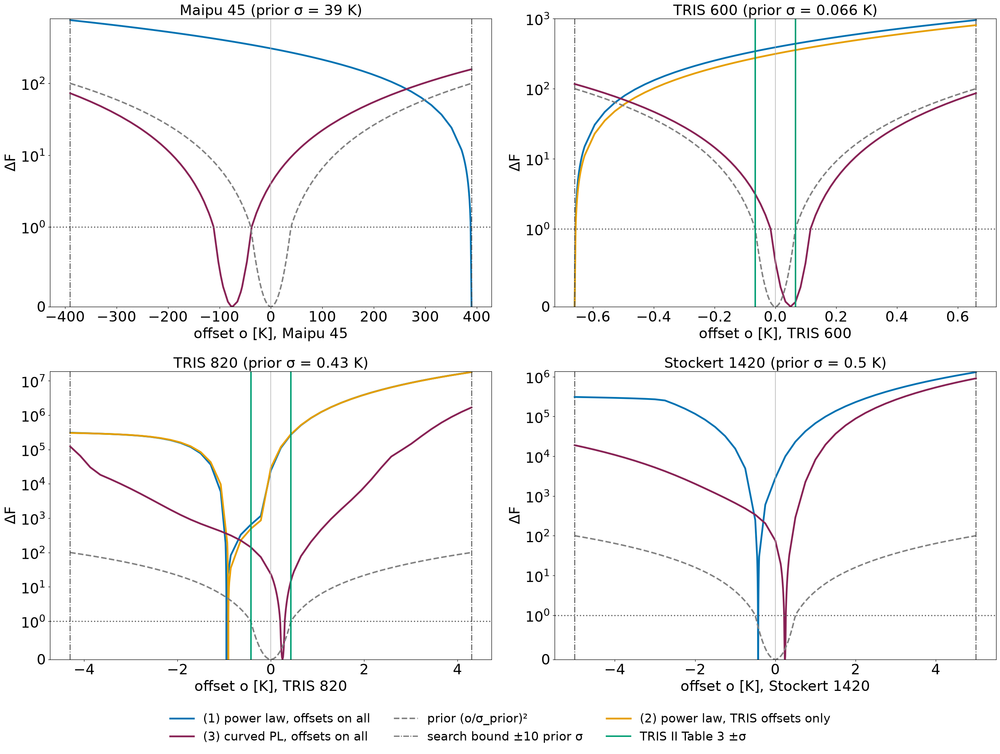

saved model_comparison/zero_level_offsets/figA_offset_profiles.png


In [ ]:
CFG_STYLE = {C1: dict(color=CFG_COL["offsets"], label="(1) power law, offsets on all"),
             C2: dict(color=CFG_COL["TRIS only"], label="(2) power law, TRIS offsets only"),
             C3: dict(color=CFG_COL["curved"], label="(3) curved PL, offsets on all")}
ncol = 2; nrow = int(np.ceil(len(OFF_ALL) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(24, 9 * nrow), squeeze=False)
for a in axes.ravel()[len(OFF_ALL):]:
    a.set_visible(False)
for a, k in zip(axes.ravel(), OFF_ALL):
    xs_all = []
    for name in (C1, C2, C3):
        prob = FITS[name]["prob"]
        if k not in prob.free:
            continue
        j = prob.free.index(k)
        pr = RES[name]["profiles"][j]
        g = np.asarray(pr["grid"]) * prob.sig[j]; dF = np.asarray(pr["F"]) - min(pr["F"])
        a.plot(g, dF, lw=3, **CFG_STYLE[name]); xs_all.append(g)
    xs = np.linspace(min(x.min() for x in xs_all), max(x.max() for x in xs_all), 300)
    a.plot(xs, (xs / PRIOR[k]) ** 2, color="0.5", ls="--", lw=2.5, label="prior (o/σ_prior)²")
    a.axhline(1, color="0.4", ls=":", lw=2)
    a.axvline(0, color="0.7")
    if k in TABLE3:
        if TABLE3[k] is None:
            a.text(0.02, 0.95, "TRIS II Table 3: not filled in\n(prior = archive zero level, fallback)", transform=a.transAxes,
                   va="top", fontsize=18, color="#009E73")
        else:
            for sgn in (-1, 1):
                a.axvline(sgn * TABLE3[k], color="#009E73", lw=2.5, label="TRIS II Table 3 ±σ" if sgn > 0 else None)
    a.set_yscale("symlog", linthresh=1.0); a.set_ylim(0, None)
    for sgn in (-1, 1):
        a.axvline(sgn * U_MAX * PRIOR[k], color="0.3", ls="-.", label=f"search bound ±{U_MAX:g} prior σ" if sgn > 0 else None)
    a.set_xlabel(f"offset o [K], {SURVEYS[k]}")
    a.set_ylabel("ΔF")
    a.set_title(f"{SURVEYS[k]} (prior σ = {PRIOR[k]:g} K)")
h, l = [], []
for a in axes.ravel()[:len(OFF_ALL)]:
    for hh, ll in zip(*a.get_legend_handles_labels()):
        if ll not in l:
            h.append(hh); l.append(ll)
fig.legend(h, l, loc="lower center", ncol=3)
fig.tight_layout(rect=(0, 0.06, 1, 1))
save(fig, "figA_offset_profiles")

#### Figure B — spectral fits at three samples, with and without offsets

At the unmasked samples nearest RA 0°, 120° and 240°: the measured points with their present errors (filled), the
offset-corrected points $T - o_k$ of configuration (1) with their errors without the zero-level term (open), the
baseline power law (black) and the configuration (1) power law (blue). LWA1 has no offset, so its open and filled
points coincide. Lower panels: data − model in K, at each survey (filled: baseline; open: configuration (1), corrected
points against its model).

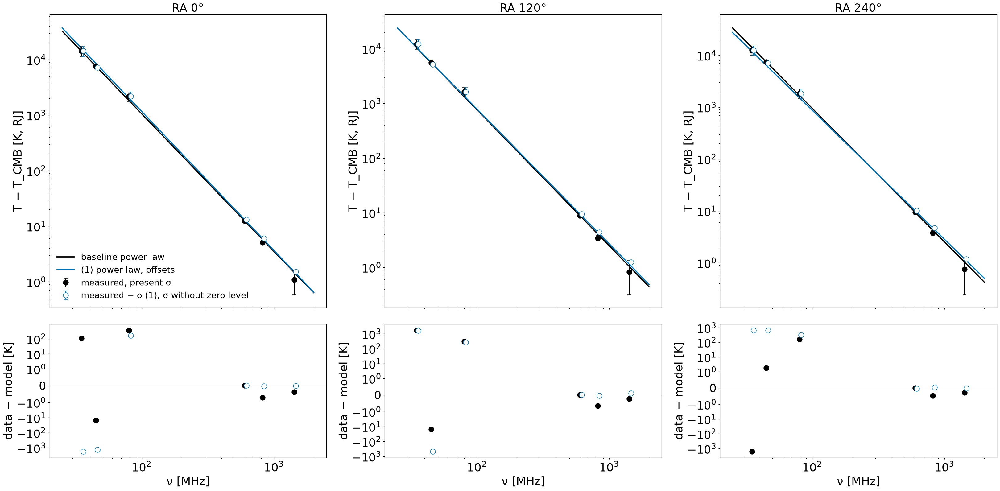

saved model_comparison/zero_level_offsets/figB_spectra_with_without_offsets.png


In [ ]:
REP = [int(np.argmin(np.abs((RA[IDX] - r + 180) % 360 - 180))) for r in REP_RA]
nug = np.geomspace(25, 2000, 300); xg = np.log(nug / NU0)
fig, axes = plt.subplots(2, 3, figsize=(30, 15), gridspec_kw=dict(height_ratios=[2.2, 1]), sharex=True)
o1 = FITS[C1]["o"]
for c, i in enumerate(REP):
    a, r = axes[0, c], axes[1, c]
    for name, col, lab in ((BASE, CFG_COL["baseline"], "baseline power law"), (C1, CFG_COL["offsets"], "(1) power law, offsets")):
        p = FITS[name]["p"][i]
        a.plot(nug, np.exp(p[0] + p[1] * xg), color=col, lw=2.5, label=lab)
    a.errorbar(NU, T_DATA[i], yerr=S_TOT_M[i], fmt="o", ms=11, color=COLORS["ink"], capsize=4, label="measured, present σ")
    a.errorbar(NU * 1.03, T_DATA[i] - o1, yerr=FITS[C1]["prob"].s[i], fmt="o", ms=11, mfc="white", color=CFG_COL["offsets"],
               capsize=4, label="measured − o (1), σ without zero level")
    a.set_xscale("log"); a.set_yscale("log")
    a.set_title(f"RA {RA[IDX][i]:.0f}°")
    a.set_ylabel("T − T_CMB [K, RJ]")
    mb = np.exp(FITS[BASE]["p"][i, 0] + FITS[BASE]["p"][i, 1] * X)
    m1 = np.exp(FITS[C1]["p"][i, 0] + FITS[C1]["p"][i, 1] * X)
    r.axhline(0, color="0.6")
    r.plot(NU, T_DATA[i] - mb, "o", ms=11, color=COLORS["ink"])
    r.plot(NU * 1.03, T_DATA[i] - o1 - m1, "o", ms=11, mfc="white", color=CFG_COL["offsets"])
    r.set_yscale("symlog", linthresh=1.0)
    r.set_xlabel("ν [MHz]"); r.set_ylabel("data − model [K]")
axes[0, 0].legend(loc="lower left", fontsize=18)
fig.tight_layout()
save(fig, "figB_spectra_with_without_offsets")

#### Figure C — residuals at each survey, stacked over the samples

Data − model **in K** at each survey (one panel per survey, low to high frequency), over all unmasked samples, for the
baseline power law and curved PL and for configurations (1) and (3); with offsets, the residual is of the full
measurement model, $T^{\rm meas} - [T(\nu) + o_k]$. Boxes span the 25–75th percentiles, whiskers the 5–95th, the line
is the median. The shaded bands are the median present error (light) and the median error without the zero-level term
(dark), ±1σ. A systematic residual pattern shows up as boxes that sit away from zero; it "goes away" if the boxes with
offsets centre on zero. (Residuals are not divided by σ.)

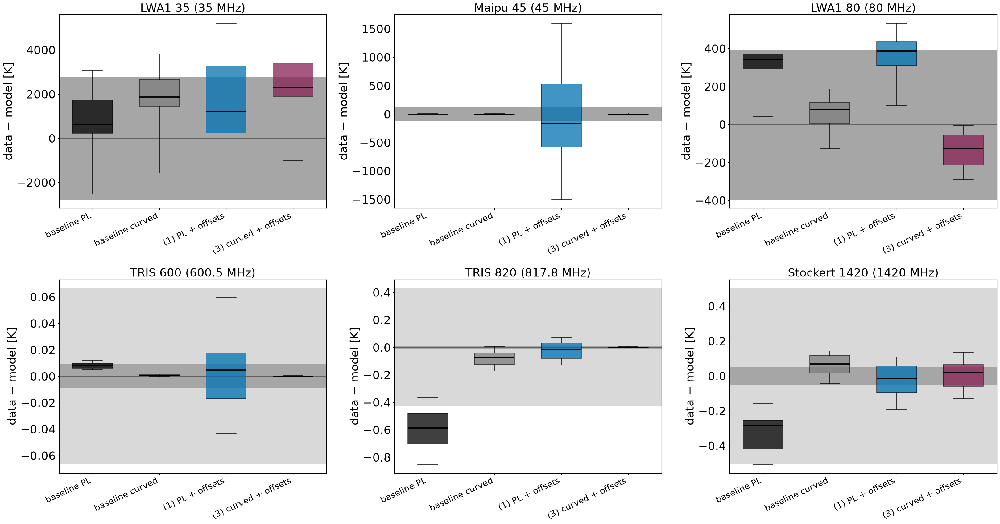

saved model_comparison/zero_level_offsets/figC_residuals_by_survey_K.png
configuration  baseline PL  baseline curved  (1) PL + offsets  (3) curved + offsets
survey                                                                             
LWA1 35           619.6232        1872.9144         1194.3607             2318.3560
Maipu 45          -15.9784          -8.9861         -161.1832               -7.1218
LWA1 80           341.0085          79.3306          386.9889             -125.5804
TRIS 600            0.0083           0.0007            0.0047                0.0001
TRIS 820           -0.5877          -0.0766           -0.0122               -0.0004
Stockert 1420      -0.2816           0.0682           -0.0162                0.0214


In [ ]:
SHOW = [(BASE, "baseline PL", CFG_COL["baseline"]), (BASE_C, "baseline curved", CFG_COL["reference"]),
        (C1, "(1) PL + offsets", CFG_COL["offsets"]), (C3, "(3) curved + offsets", CFG_COL["curved"])]
def model_T(name):
    p = FITS[name]["p"]
    curv = p[:, 2:3] * X ** 2 if p.shape[1] > 2 else 0.0
    return np.exp(p[:, 0:1] + p[:, 1:2] * X + curv)
RESID = {name: T_DATA - (model_T(name) + FITS[name]["o"]) for name, _, _ in SHOW}
fig, axes = plt.subplots(2, 3, figsize=(30, 16))
rows = []
for a, j in zip(axes.ravel(), np.argsort(NU)):
    k = KEYS[j]
    a.axhspan(-np.median(S_TOT_M[:, j]), np.median(S_TOT_M[:, j]), color="0.85", lw=0, zorder=0)
    a.axhspan(-np.median(S_NOZL_M[:, j]), np.median(S_NOZL_M[:, j]), color="0.65", lw=0, zorder=0)
    a.axhline(0, color="0.3")
    data = [RESID[name][:, j] for name, _, _ in SHOW]
    bp = a.boxplot(data, whis=(5, 95), widths=0.6, patch_artist=True, showfliers=False,
                   medianprops=dict(color=COLORS["ink"], lw=2.5))
    for patch, (_, _, col) in zip(bp["boxes"], SHOW):
        patch.set_facecolor(col); patch.set_alpha(0.75)
    a.set_xticks(range(1, len(SHOW) + 1), [s for _, s, _ in SHOW], rotation=25, ha="right", fontsize=18)
    a.set_title(f"{SURVEYS[k]} ({NU[j]:g} MHz)")
    a.set_ylabel("data − model [K]")
    for (name, short, _), d in zip(SHOW, data):
        rows.append({"survey": SURVEYS[k], "configuration": short, "median residual [K]": np.median(d),
                     "rms residual [K]": np.sqrt(np.mean(d ** 2)), "median present σ [K]": np.median(S_TOT_M[:, j]),
                     "median σ without zero level [K]": np.median(S_NOZL_M[:, j])})
fig.tight_layout()
save(fig, "figC_residuals_by_survey_K")
tabC = pd.DataFrame(rows)
tabC.to_csv(OUT_DIR / "figC_residuals_by_survey.csv", index=False)
print(tabC.pivot(index="survey", columns="configuration", values="median residual [K]")
          .reindex([SURVEYS[KEYS[j]] for j in np.argsort(NU)])[[s for _, s, _ in SHOW]].round(4).to_string())

### Caveats

* **The offsets are constant.** Each survey's offset is one number shared by every ring sample. A zero-level error from
  the survey's own map-making could vary with position on the sky; this fit assumes it does not.
* **An offset can mimic curvature** when the frequency coverage is thin (here nothing between 80 and 600 MHz): a shift of
  the high-frequency points changes the slope between the TRIS bands and the low-frequency surveys. Table 3(b) reports how
  the curvature moves.
* **All σ are underestimates**: neighbouring samples see almost the same sky (3° apart under a ~20° beam); the ×2.6
  column is a rough correction, not an exact one. The scale (gain) terms, also common to each survey, are still treated
  as independent per point.
* **The 820 MHz TRIS prior is symmetric.** TRIS II Table 3 quotes +0.430 / −0.300 K; the prior uses the larger side,
  0.430 K, as a symmetric Gaussian, so it is wider than quoted on the negative side. Table 3's footnote a gives 0.659 K
  from the absolute calibration alone; no configuration uses it.
* **LWA1 35 and 80 get no offset**: no separate zero-level uncertainty is quoted, so their whole 20% error is kept.
* This notebook describes sizes and positions only; it does not assign causes.

### Summary

Run of 2026-11-03: 103 of 120 ring samples (Cygnus A ± 25° masked), beam-matched survey TODs. The TRIS priors are the
TRIS II Table 3 zero-level uncertainties, 0.066 K and 0.430 K (the larger side of +0.430 / −0.300 K); they equal the
zero-level terms inside `ring_sigma`, and every number is unchanged from the 2026-11-02 run. Hessian σ are underestimates
(×√(120/18) ≈ 2.6 in brackets).

* **Fitted offsets.** With the curved power law (3), every offset lies within ~2 prior widths: TRIS 600 +0.050 ± 0.066 K
  (±0.17), TRIS 820 +0.249 ± 0.049 K (±0.13), Stockert +0.241 ± 0.022 K (±0.06), Maipu −74 ± 37 K (±96), i.e. 0.76, 0.58,
  0.48 and 1.9 prior widths. With the power law (1) they do not fit inside the quoted systematics: TRIS 600 (−0.66 K) and
  Maipu (+390 K) sit at the ±10-prior-width edge of the search, so the power law's optimum is further out still; TRIS 820
  is −0.95 K (2.2 prior widths) and Stockert −0.43 K (0.86). TRIS-only offsets (2) give the same TRIS values as (1).
  LWA1 35 and 80 quote no separate zero level and get no offset.
* **820 MHz vs Table 3.** The curved fit's +0.25 K lies on the positive side, inside +0.43 K (0.58 of it). The power
  law's −0.91 to −0.95 K lies on the negative side: 2.1–2.2 times 0.43 K and 3.0–3.2 times the quoted −0.30 K side, so
  the symmetric prior is wider there than Table 3 quotes. Against footnote a's 0.659 K (absolute calibration alone),
  +0.25 K is 0.38 of it and −0.91 to −0.95 K is 1.4 times it. (The stage 1 map-making zero level
  ẑ = +0.516 ± 0.027 K comes from a different route and is shown for reference only.)
* **χ².** Taking the zero-level terms out of the per-point errors (offsets held at 0) raises χ² from 394 to 212 870 for the
  power law and from 115 to 1147 for the curved PL: TRIS is left with ~0.01 K statistical errors. Freeing the offsets
  brings the curved PL to χ² = 524 (χ²/dof 1.72; Δχ² = −622 against the same errors with offsets at 0), but the power
  law only to 12 098 (χ²/dof 29.7; TRIS-only offsets 11 624). The baseline χ² are lower because its errors are larger,
  not because it fits better.
* **Haslam gain and offset** (York, T_Haslam = g P + z). From the TRIS-only power-law prediction: g = 0.987 ± 0.072,
  z = −7.6 ± 2.4 K with the raw TRIS data; with the power-law TRIS offsets (1)/(2) g = 0.976/0.974, z = −3.9/−4.1 K
  (±1.4); with the curved-fit TRIS offsets (3) g = 0.992 ± 0.051, z = −10.1 ± 1.7 K. From the six-survey fits' A(408):
  power law g 1.055 → 1.028, z −4.8 → −5.2 K; curved PL g 0.981 → 1.011, z −5.7 → −8.8 K. g stays within its errors of 1
  throughout; across the eight rows of Table 3(a), z ranges from −10.1 K (TRIS only, offsets of (3)) to −3.9 K (TRIS
  only, offsets of (1)), a spread of 6.2 K.
* **Curvature.** Median C goes from −0.129 (baseline) to −0.149 (zero-level terms removed, offsets at 0) to −0.207 with
  the offsets free (3), and β at 408 MHz from −2.73 to −2.92: the offsets do not absorb the curvature; the curved fit
  curves more. The curved PL beats the power law by Δχ² > 2 at 59 of 103 samples in the baseline and at 102 of 103 with
  offsets.
* **Main caveat.** Once the zero levels become shared parameters, the per-point errors left (TRIS ≈ 0.01 K, Stockert ≈
  0.05 K) are smaller than the scatter of the data about either spectral model from sample to sample, so χ² stays large
  (and the power law's offsets run to the search edge). All σ are underestimates (correlated samples), the offsets are
  assumed constant along the ring, and the 820 MHz TRIS prior is symmetric although Table 3 quotes +0.430 / −0.300 K.

# Part I — Robustness of the Haslam gain and offset (survey subsets and more)

**Origin:** `notebooks/21_robustness_check.ipynb` (archived: `../moonrunes_archive_2026-11-16/notebooks/21_robustness_check.ipynb`)

| | |
|---|---|
| **Reads** | `paper_outputs/pipeline/step5_fit/`, `paper_outputs/pipeline/step2_ring_tods/``beam_matched_tods.npz`, Part H's outputs, the TRIS rings |
| **Writes** | `paper_outputs/robustness_check/` (`robustness_table.csv`, figure) |
| **Feeds the paper** | main.tex:396 (and, by keyword only, 490, 507–508, 607) |

**Stored outputs** are from the original notebook (not re-run after the merge). Its data cell refers to "notebook 08 Figures 15–16 (cell 50)"; notebook 08 is in git at `a5c827c`.

**Pipeline:** reads the pipeline's step 2 and step 5 products.

## Robustness check of the Haslam gain and offset

**Question (a collaborator's comment 2 on the TRIS paper).** Is the Haslam gain and offset correction robust across
subsets of the input maps and across spectral models?

**What is fitted.** Haslam = g P + z over the ring samples (York, errors on both axes, σ inflated by √(χ²/ν) when > 1, as
Plot 3 and notebook 08 Figures 15–16). P is the spectral fit's A at the 408 MHz pivot, as in Figures 15–16 Part 1(c).
Haslam is always the target, never an input. The data, the errors and the functions (`york`, `york_cov`, `inner_fit`
with the log-frequencies passed in, `tris_only_p408`, `haslam_fit`) are those of notebook 08 Figures 15–16. The only
change: `haslam_fit` takes the Haslam samples as arguments so that a subset of the ring can be fitted. Errors are as
now (zero-level terms inside the per-point errors, no offsets fitted).

**Baseline** (the reference for every difference): six-survey power law, Cygnus A mask RA 299.9 ± 25° (103 of 120
samples). It should give g = 1.0548 ± 0.0536, z = −4.77 ± 1.47 K.

**The grid (fixed; nothing added).**
1. Survey subsets: all six; each one left out; both LWA1 bands left out; Maipu 45 + TRIS 600 + TRIS 820 (power law only);
   TRIS only, the two-point power law of Plot 3 (power law only; reference row).
2. Spectral models: power law for every subset; curved power law for subsets with at least four surveys.
3. Sample subsets (all six surveys, both models): Cygnus A mask ±15° and ±35°; the two halves of the ±25° unmasked ring
   split at RA = 200°.
4. Zero-level treatment: three rows copied from notebook 20's Table 3(a), not refitted.

Differences are fit − baseline, in g units or K. "Inside baseline error bars" = |g − g_baseline| < σ_g(baseline) and
|z − z_baseline| < σ_z(baseline).

Output: `paper_outputs/robustness_check/` — `robustness_table.csv`, `robustness_gz_plane.png` / `.pdf`.

### 1. Data, errors and the fitting functions

In [ ]:
%matplotlib inline
import os
os.environ.setdefault("TQDM_DISABLE", "1")
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
warnings.filterwarnings("ignore")
from moonrunes.config import load_config
from moonrunes import sed_prototype as sp
from moonrunes.sed_prototype import PUBLISHED_ERRORS, ring_sigma, sigma_for
from moonrunes.style import use_tris_style, COLORS
use_tris_style()

config = load_config(REPO / "configs" / "run_pipeline.yaml")
OUT = REPO / "paper_outputs" / "robustness_check"
OUT.mkdir(parents=True, exist_ok=True)
ZL_DIR = REPO / "paper_outputs" / "zero_level_offsets"            # notebook 20, read only

def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(OUT / f"{name}.{ext}")

print("ERRORS AS NOW: every per-point error includes its zero-level term (ring_sigma for TRIS, sigma_for for the "
      "surveys and Haslam);\nno zero-level offsets are fitted (except in the copied notebook 20 rows, which say so).  "
      "Haslam is the target, never an input.\nDifferences are fit − baseline, in K or in g units.\n")

# ---- data and errors, as notebook 08 Figures 15-16 (cell 50) ----
SRC = REPO / "paper_outputs" / "pipeline" / "step5_fit"                       # run_pipeline.py step 5: TRIS ring data and the fits
BM = REPO / "paper_outputs" / "pipeline" / "step2_ring_tods" / "beam_matched_tods.npz"     # run_pipeline.py step 2
HASLAM = "HASLAM_DESTRIPED_ONLY.fits"
SURVEYS = {"LWA_35MHz.fits": "LWA1 35", "MAIPU_45mhZ.fits": "Maipu 45", "LWA_80MHz.fits": "LWA1 80",
           "TRIS_600": "TRIS 600", "TRIS_820": "TRIS 820", "STOCKERT_VILLA_1400MHZ.fits": "Stockert 1420"}
KEYS = list(SURVEYS)
NOT_TRIS = [k for k in KEYS if not k.startswith("TRIS_")]
NU0 = 408.0
CYG_RA, CYG_HALF = 299.9, 25.0      # the baseline mask
RA_SPLIT = 200.0                    # the two halves of the ring
INFLATE = True                      # york(): scale σ by sqrt(χ²/ν) when χ²/ν > 1 (notebook 14's rule)

RA = np.load(SRC / "ring_ra.npy")
N = RA.size
T = {k: np.full(N, np.nan) for k in KEYS}
S_CACHE = {k: np.full(N, np.nan) for k in KEYS}
FREQ = {}
for u in range(N):
    r = np.load(SRC / "fits" / f"unit{u:03d}__power_law.npz", allow_pickle=False)
    for k, nu, t, s in zip((str(x) for x in r["keys"]), r["nu"], r["t"], r["s"]):
        T[k][u], S_CACHE[k][u], FREQ[k] = t, s, float(nu)
zb = np.load(BM, allow_pickle=False)
assert np.allclose(zb["ra_deg"], RA)
for k in NOT_TRIS:
    T[k] = np.asarray(zb[f"survey::{k}"], dtype=float)
TH_ALL = np.asarray(zb[f"survey::{HASLAM}"], dtype=float)

tris_mod = sp.import_limtod_tris(config)
archive = config.resolve_path("paths.tris_archive_dir")
S, RINGS = {}, {}
for k in KEYS:
    if k.startswith("TRIS_"):
        RINGS[k] = tris_mod.read_tris_ring(archive / f"TRIS_absolute_{k[5:]}.txt")
        assert np.allclose(np.asarray(RINGS[k].ra_deg), RA)
        S[k] = ring_sigma(RINGS[k])
        assert np.allclose(S[k], S_CACHE[k]), k
    else:
        S[k] = np.asarray(sigma_for(dict(freq_mhz=FREQ[k], file=k), T[k]), dtype=float)
SH_ALL = np.asarray(sigma_for(dict(freq_mhz=NU0, file=HASLAM), TH_ALL), dtype=float)

# every finite sample; the sample sets below are index sets into these
FINITE = np.all([np.isfinite(T[k]) for k in KEYS], axis=0) & np.isfinite(TH_ALL)
NU = np.array([FREQ[k] for k in KEYS])
X = np.log(NU / NU0)
TD = np.stack([T[k] for k in KEYS], axis=1)          # (120, 6); fits are made at every finite sample
SD = np.stack([S[k] for k in KEYS], axis=1)

def cyg_keep(half):
    d = np.abs((RA - CYG_RA + 180.0) % 360.0 - 180.0)
    return FINITE & (d > half)

SAMPLE_SETS = {f"Cygnus A mask ±{CYG_HALF:g}° (baseline)": cyg_keep(CYG_HALF),
               "Cygnus A mask ±15°": cyg_keep(15.0),
               "Cygnus A mask ±35°": cyg_keep(35.0),
               f"±{CYG_HALF:g}° mask, RA < {RA_SPLIT:g}°": cyg_keep(CYG_HALF) & (RA < RA_SPLIT),
               f"±{CYG_HALF:g}° mask, RA ≥ {RA_SPLIT:g}°": cyg_keep(CYG_HALF) & (RA >= RA_SPLIT)}
BASE_SET = f"Cygnus A mask ±{CYG_HALF:g}° (baseline)"
print(f"{FINITE.sum()} of {N} ring samples finite in all six surveys and Haslam")
for name, keep in SAMPLE_SETS.items():
    print(f"  {name}: {keep.sum()} samples")
print("frequencies [MHz]: " + ", ".join(f"{SURVEYS[k]} {FREQ[k]:g}" for k in KEYS))


# ---- the fitting functions, copied unchanged from notebook 08 cell 50 (ANC_ prefix dropped) ----
def york(x, y, sx, sy, n_iter=200, tol=1e-12):
    # y = a x + b with errors on both axes (York et al. 2004, Am. J. Phys. 72, 367; no x-y correlation).
    vx, vy = np.asarray(sx, float) ** 2, np.asarray(sy, float) ** 2
    a = np.polyfit(x, y, 1)[0]
    for _ in range(n_iter):
        W = 1.0 / (vy + a * a * vx)
        xb, yb = np.sum(W * x) / W.sum(), np.sum(W * y) / W.sum()
        U, V = x - xb, y - yb
        bet = W * (U * vy + a * V * vx)
        a_new = np.sum(W * bet * V) / np.sum(W * bet * U)
        done = abs(a_new - a) <= tol * abs(a_new)
        a = a_new
        if done:
            break
    W = 1.0 / (vy + a * a * vx)
    xb, yb = np.sum(W * x) / W.sum(), np.sum(W * y) / W.sum()
    b = yb - a * xb
    xa = xb + W * ((x - xb) * vy + a * (y - yb) * vx)          # adjusted x values
    xab = np.sum(W * xa) / W.sum()
    sa = np.sqrt(1.0 / np.sum(W * (xa - xab) ** 2))
    sb = np.sqrt(1.0 / W.sum() + xab ** 2 * sa ** 2)
    chi2 = float(np.sum(W * (y - a * x - b) ** 2))
    dof = x.size - 2
    f = np.sqrt(max(1.0, chi2 / dof)) if INFLATE else 1.0
    return dict(a=a, sa=sa * f, b=b, sb=sb * f, chi2_dof=chi2 / dof)

def york_cov(x, y, sx, sy, fit):
    # cov(a, b) of the York fit above (York et al. 2004: -x̄_adj σ_a²), with the same √(χ²/ν) inflation.
    vx, vy, a = np.asarray(sx, float) ** 2, np.asarray(sy, float) ** 2, fit["a"]
    W = 1.0 / (vy + a * a * vx)
    xb, yb = np.sum(W * x) / W.sum(), np.sum(W * y) / W.sum()
    xa = xb + W * ((x - xb) * vy + a * (y - yb) * vx)
    xab = np.sum(W * xa) / W.sum()
    return -xab * fit["sa"] ** 2

def inner_fit(t, s, npar, x, p0=None, n_iter=500, tol=1e-11):
    """Minimum chi^2 of T = exp(lnA + beta x [+ C x^2]) at every sample (rows of t, s).  Returns p, chi2, cov.
    Notebook 20's inner_fit, with the log-frequencies x passed in so that a subset of the surveys can be fitted."""
    w = 1.0 / s ** 2
    V = np.stack([np.ones_like(x), x, x ** 2][:npar], axis=1)            # (npts, npar)
    if p0 is None or not np.all(np.isfinite(p0)):      # weighted straight line in log T
        lt = np.log(np.clip(t, 1e-300, None)); wl = (np.clip(t, 1e-300, None) / s) ** 2
        p = np.linalg.solve(np.einsum("ni,sn,nj->sij", V, wl, V), np.einsum("ni,sn,sn->si", V, wl, lt)[..., None])[..., 0]
    else:
        p = p0.copy()
    def chi2_of(p):
        m = np.exp(p @ V.T)
        return np.sum(w * (t - m) ** 2, axis=1), m
    c, m = chi2_of(p)
    lam = np.full(t.shape[0], 1e-3)
    eye = np.eye(npar)
    for _ in range(n_iter):
        J = m[:, :, None] * V[None]
        JTJ = np.einsum("sni,sn,snj->sij", J, w, J)
        g = np.einsum("sni,sn,sn->si", J, w, t - m)
        d = np.linalg.solve(JTJ + lam[:, None, None] * JTJ * eye, g[..., None])[..., 0]
        cn, mn = chi2_of(p + d)
        better = cn <= c
        p[better] += d[better]; m[better] = mn[better]
        dc = np.where(better, c - cn, 0.0); c = np.where(better, cn, c)
        lam = np.where(better, lam * 0.3, lam * 10.0).clip(1e-12, 1e12)
        if np.all((np.abs(d).max(axis=1) < tol) | (better & (dc < 1e-13 * np.maximum(c, 1.0)))):
            break
    J = m[:, :, None] * V[None]
    cov = np.linalg.pinv(np.einsum("sni,sn,snj->sij", J, w, J))
    return p, c, cov

I6, I8 = KEYS.index("TRIS_600"), KEYS.index("TRIS_820")
L68 = np.log(NU[I8] / NU[I6]); L48 = np.log(NU0 / NU[I6])
def tris_only_p408(t6, t8, s6, s8):
    """P(408) from the power law through the two TRIS points, and its 1 sigma (notebook 20)."""
    beta = np.log(t8 / t6) / L68
    P = t6 * np.exp(beta * L48)
    c6, c8 = 1 - L48 / L68, L48 / L68                 # ln P = c6 ln t6 + c8 ln t8
    return P, P * np.hypot(c6 * s6 / t6, c8 * s8 / t8)

def haslam_fit(P, SP, H_T, H_S):
    """Haslam = g P + z (York), notebook 08's haslam_fit with the Haslam samples passed in, so that a sample subset can
    be fitted (notebook 08 reads them from its globals H_T, H_S)."""
    f = york(P, H_T, SP, H_S)
    cgz = york_cov(P, H_T, SP, H_S, f)
    return dict(g=f["a"], sg=f["sa"], z=f["b"], sz=f["sb"], chi2_dof=f["chi2_dof"],
                C=np.array([[f["sa"] ** 2, cgz], [cgz, f["sb"] ** 2]]))

ERRORS AS NOW: every per-point error includes its zero-level term (ring_sigma for TRIS, sigma_for for the surveys and Haslam);
no zero-level offsets are fitted (except in the copied notebook 20 rows, which say so).  Haslam is the target, never an input.
Differences are fit − baseline, in K or in g units.



120 of 120 ring samples finite in all six surveys and Haslam
  Cygnus A mask ±25° (baseline): 103 samples
  Cygnus A mask ±15°: 110 samples
  Cygnus A mask ±35°: 97 samples
  ±25° mask, RA < 200°: 67 samples
  ±25° mask, RA ≥ 200°: 36 samples
frequencies [MHz]: LWA1 35 35, Maipu 45 45, LWA1 80 80, TRIS 600 600.5, TRIS 820 817.8, Stockert 1420 1420


### 2. The grid fits

Each spectral fit is made once per survey subset and model at every finite ring sample; the Haslam fit then uses the
samples of its sample set. `inner_fit` does not report convergence, so the cell checks it from outside: a sample is
flagged if its fit is not finite, or if restarting `inner_fit` from its own solution moves a parameter by more than
1e-6 or lowers χ² by more than 1e-6 χ². Non-finite samples are left out of that Haslam fit; flagged but finite samples are
kept as fitted. Both are counted in the convergence table.

In [ ]:
# The grid: Haslam = g P + z, with P = A at the 408 MHz pivot of a spectral fit to a subset of the surveys.
MODEL_NPAR = {"power law": 2, "curved power law": 3}
OK = np.flatnonzero(FINITE)
NONCONV_TOL = 1e-6

def spectral_p408(cols, npar):
    """A(408) and its 1σ at every finite sample from inner_fit on the surveys in cols.  Convergence check, outside
    inner_fit: a sample is flagged if its fit is not finite (or has no positive variance of ln A), or if restarting
    inner_fit from its own solution moves any parameter by more than 1e-6 or lowers χ² by more than 1e-6 χ²."""
    t, s, x = TD[OK][:, cols], SD[OK][:, cols], X[cols]
    p, c, cov = inner_fit(t, s, npar, x)
    p2, c2, _ = inner_fit(t, s, npar, x, p0=p)
    var = cov[:, 0, 0]
    finite = np.all(np.isfinite(p), axis=1) & np.isfinite(c) & np.isfinite(var) & (var > 0)
    moved = (np.nan_to_num(np.abs(p2 - p), nan=np.inf).max(axis=1) > NONCONV_TOL) | (c - c2 > NONCONV_TOL * np.maximum(c, 1.0))
    A, sA = np.full(N, np.nan), np.full(N, np.nan)
    A[OK] = np.exp(p[:, 0]); sA[OK] = A[OK] * np.sqrt(np.where(var > 0, var, np.nan))
    bad_finite, bad_moved = np.zeros(N, bool), np.zeros(N, bool)
    bad_finite[OK] = ~finite; bad_moved[OK] = finite & moved
    return A, sA, bad_finite, bad_moved

ROWS, CONV = [], []
def add(group, subset, model, n_surveys, P, SP, keep, bad_finite=None, bad_moved=None):
    """One Haslam fit over the samples in keep.  Samples whose spectral fit is not finite are left out of the York fit
    (and counted); samples flagged as not converged but finite are kept with the value inner_fit returned (and counted)."""
    use = keep.copy()
    if bad_finite is not None:
        use &= ~bad_finite
        CONV.append({"group": group, "subset": subset, "model": model, "samples in set": int(keep.sum()),
                     "not finite (left out)": int((keep & bad_finite).sum()),
                     "not converged, finite (kept)": int((keep & bad_moved).sum())})
    f = haslam_fit(P[use], SP[use], TH_ALL[use], SH_ALL[use])
    ROWS.append({"group": group, "subset": subset, "model": model, "number of surveys": n_surveys,
                 "number of samples": int(use.sum()), "g": f["g"], "sigma_g": f["sg"], "z [K]": f["z"],
                 "sigma_z [K]": f["sz"]})

SUBSETS = {"all six": KEYS}
for k in KEYS:
    SUBSETS[f"without {SURVEYS[k]}"] = [q for q in KEYS if q != k]
SUBSETS["without both LWA1 bands"] = ["MAIPU_45mhZ.fits", "TRIS_600", "TRIS_820", "STOCKERT_VILLA_1400MHZ.fits"]
SUBSETS["best-measured three (Maipu 45, TRIS 600, TRIS 820)"] = ["MAIPU_45mhZ.fits", "TRIS_600", "TRIS_820"]

FITS = {}
base_keep = SAMPLE_SETS[BASE_SET]
for name, keys in SUBSETS.items():
    cols = [KEYS.index(k) for k in keys]
    for model, npar in MODEL_NPAR.items():
        if model == "curved power law" and len(keys) < 4:
            continue
        FITS[name, model] = spectral_p408(cols, npar)
        add("survey subsets", name + (" (baseline)" if (name, model) == ("all six", "power law") else ""), model,
            len(keys), *FITS[name, model][:2], base_keep, *FITS[name, model][2:])
P_T, SP_T = tris_only_p408(TD[:, I6], TD[:, I8], SD[:, I6], SD[:, I8])
add("survey subsets", "TRIS only (two-point power law, as Plot 3)", "power law", 2, P_T, SP_T, base_keep & np.isfinite(P_T))

for name, keep in SAMPLE_SETS.items():
    if name == BASE_SET:
        continue
    for model in MODEL_NPAR:
        add("sample subsets", name, model, 6, *FITS["all six", model][:2], keep, *FITS["all six", model][2:])

BASE = ROWS[0]
print(f"baseline (six-survey power law, {BASE['number of samples']} samples): g = {BASE['g']:.4f} ± {BASE['sigma_g']:.4f}, "
      f"z = {BASE['z [K]']:.2f} ± {BASE['sigma_z [K]']:.2f} K")
expected = dict(g=1.0548, sg=0.0536, z=-4.77, sz=1.47)
same = (round(BASE["g"], 4) == expected["g"] and round(BASE["sigma_g"], 4) == expected["sg"]
        and round(BASE["z [K]"], 2) == expected["z"] and round(BASE["sigma_z [K]"], 2) == expected["sz"])
print("expected (notebook 08 Figures 15-16, Part 1(c)): g = 1.0548 ± 0.0536, z = -4.77 ± 1.47 K -> "
      + ("REPRODUCED" if same else "NOT REPRODUCED"))
assert same and BASE["number of samples"] == 103

conv = pd.DataFrame(CONV)
print("\nconvergence of the spectral fits, per Haslam fit (samples in its sample set)\n")
with pd.option_context("display.width", 250, "display.max_columns", 20):
    print(conv.to_string(index=False))

baseline (six-survey power law, 103 samples): g = 1.0548 ± 0.0536, z = -4.77 ± 1.47 K
expected (notebook 08 Figures 15-16, Part 1(c)): g = 1.0548 ± 0.0536, z = -4.77 ± 1.47 K -> REPRODUCED

convergence of the spectral fits, per Haslam fit (samples in its sample set)

         group                                             subset            model  samples in set  not finite (left out)  not converged, finite (kept)
survey subsets                                 all six (baseline)        power law             103                      0                             0
survey subsets                                            all six curved power law             103                      0                             0
survey subsets                                    without LWA1 35        power law             103                      0                             0
survey subsets                                    without LWA1 35 curved power law             103                      0   

### 3. Zero-level treatment: rows copied from notebook 20

Notebook 20's cache (`paper_outputs/zero_level_offsets/cache/results.npz`) stores the fitted offsets of each
configuration, not the Table 3(a) rows. The rows are copied from notebook 20's saved `table3a_haslam_gain_offset.csv`
and checked against the same rows rebuilt from the cached offsets. These rows use notebook 20's treatment: the
zero-level terms are removed from the errors and the offsets are fitted, except the curved baseline row, which has errors
as now.

In [ ]:
# Zero-level treatment: three rows of notebook 20's Table 3(a), copied, not refitted.
# notebook 20's results.npz holds the MAP offsets of each configuration, not the Table 3(a) rows; the rows are copied
# from notebook 20's saved table3a_haslam_gain_offset.csv, and checked against the rows rebuilt from the cached
# offsets (data − offsets, errors without the zero-level terms, as notebook 20 does).
ZL_ROWS = {"six-survey power law A(408), (1)": ("power law", "offsets fitted, notebook 20 configuration (1)"),
           "six-survey curved PL A(408), (3)": ("curved power law", "offsets fitted, notebook 20 configuration (3)"),
           "six-survey curved PL A(408), baseline": ("curved power law", "no offsets, errors as now (notebook 20 baseline)")}
CFG = {"six-survey power law A(408), (1)": ("(1) power law, offsets on all", 2),
       "six-survey curved PL A(408), (3)": ("(3) curved power law, offsets on all", 3),
       "six-survey curved PL A(408), baseline": ("baseline curved power law, errors as now", 3)}
t3a = pd.read_csv(ZL_DIR / "table3a_haslam_gain_offset.csv").set_index("prediction P")
res = json.loads(str(np.load(ZL_DIR / "cache" / "results.npz", allow_pickle=False)["blob"]))

# notebook 20's offset priors: TRIS II Table 3 (= the zero-level term inside ring_sigma), the published zero_k otherwise
PRIOR, S_NOZL = {}, {}
for k in KEYS:
    if k.startswith("TRIS_"):
        z = RINGS[k].zero_level_uncertainty_k
        PRIOR[k] = float(z) if np.isscalar(z) else max(z.positive_k, z.negative_k)
        stat = np.asarray(RINGS[k].statistical_uncertainty_k, dtype=float)
        S_NOZL[k] = np.where(stat > 0, stat, stat[stat > 0].min())
    else:
        e = PUBLISHED_ERRORS[k]
        if e["zero_k"] > 0:
            PRIOR[k] = e["zero_k"]
        S_NOZL[k] = np.hypot(e["scale"] * T[k], e["noise_k"])
assert np.isclose(PRIOR["TRIS_600"], 0.066) and np.isclose(PRIOR["TRIS_820"], 0.430)
OFF_ALL = [k for k in KEYS if k in PRIOR]
ib = np.flatnonzero(base_keep)

print("notebook 20 Table 3(a) rows: copied value vs rebuilt from the cached offsets (rebuilt − copied)")
for lab, (model, subset) in ZL_ROWS.items():
    r = t3a.loc[lab]
    cfg, npar = CFG[lab]
    u = np.asarray(res[cfg]["u"])
    o = np.zeros(len(KEYS))
    if u.size:
        o[[KEYS.index(k) for k in OFF_ALL]] = u * np.array([PRIOR[k] for k in OFF_ALL])
        s = np.stack([S_NOZL[k][ib] if k in OFF_ALL else S[k][ib] for k in KEYS], axis=1)
    else:
        s = SD[ib]
    p, _, cov = inner_fit(TD[ib] - o, s, npar, X)
    A = np.exp(p[:, 0])
    f = haslam_fit(A, A * np.sqrt(cov[:, 0, 0]), TH_ALL[ib], SH_ALL[ib])
    d = np.array([f["g"] - r["g"], f["sg"] - r["σ_g"], f["z"] - r["z [K]"], f["sz"] - r["σ_z [K]"]])
    print(f"  {lab}: Δg {d[0]:+.1e}, Δσ_g {d[1]:+.1e}, Δz {d[2]:+.1e} K, Δσ_z {d[3]:+.1e} K -> "
          + ("same" if np.all(np.abs(d) < 1e-6) else "DIFFERENT"))
    assert np.all(np.abs(d) < 1e-6), lab
    ROWS.append({"group": "zero-level treatment (notebook 20)", "subset": subset, "model": model, "number of surveys": 6,
                 "number of samples": len(ib), "g": r["g"], "sigma_g": r["σ_g"], "z [K]": r["z [K]"],
                 "sigma_z [K]": r["σ_z [K]"]})
# notebook 20's curved baseline is this notebook's all-six curved fit
cv = next(x for x in ROWS if x["subset"] == "all six" and x["model"] == "curved power law")
print(f"  notebook 20 curved baseline − this notebook's all-six curved fit: Δg {t3a.loc['six-survey curved PL A(408), baseline', 'g'] - cv['g']:+.1e}, "
      f"Δz {t3a.loc['six-survey curved PL A(408), baseline', 'z [K]'] - cv['z [K]']:+.1e} K")

notebook 20 Table 3(a) rows: copied value vs rebuilt from the cached offsets (rebuilt − copied)
  six-survey power law A(408), (1): Δg +0.0e+00, Δσ_g +6.9e-18, Δz +0.0e+00 K, Δσ_z +0.0e+00 K -> same
  six-survey curved PL A(408), (3): Δg +0.0e+00, Δσ_g +4.9e-17, Δz +0.0e+00 K, Δσ_z +0.0e+00 K -> same
  six-survey curved PL A(408), baseline: Δg -6.2e-11, Δσ_g -4.1e-12, Δz +1.3e-09 K, Δσ_z -9.2e-11 K -> same
  notebook 20 curved baseline − this notebook's all-six curved fit: Δg +6.2e-11, Δz -1.3e-09 K


### 4. The table

In [ ]:
# The table: every fit against the baseline, by subtraction.
tab = pd.DataFrame(ROWS)
tab["g - g_baseline"] = tab["g"] - BASE["g"]
tab["z - z_baseline [K]"] = tab["z [K]"] - BASE["z [K]"]
IN_G = np.abs(tab["g - g_baseline"]) < BASE["sigma_g"]
IN_Z = np.abs(tab["z - z_baseline [K]"]) < BASE["sigma_z [K]"]
tab["inside baseline error bars"] = np.where(IN_G & IN_Z, "yes", "no")
tab.to_csv(OUT / "robustness_table.csv", index=False)
with pd.option_context("display.width", 300, "display.max_columns", 20, "display.max_colwidth", 60):
    print(f"Haslam = g P + z; baseline g = {BASE['g']:.4f} ± {BASE['sigma_g']:.4f}, z = {BASE['z [K]']:.2f} ± "
          f"{BASE['sigma_z [K]']:.2f} K\n")
    print(tab.round(4).to_string(index=False))

others = tab.index[1:]                           # every fit except the baseline itself
print(f"\n{len(others)} fits besides the baseline: inside the baseline σ_g in g: {int(IN_G[others].sum())}; inside the "
      f"baseline σ_z in z: {int(IN_Z[others].sum())}; inside both: {int((IN_G & IN_Z)[others].sum())}")
out = tab.loc[others][~(IN_G & IN_Z)[others]]
print("\noutside the baseline error bars (baseline σ_g = %.4f, σ_z = %.2f K):" % (BASE["sigma_g"], BASE["sigma_z [K]"]))
for _, r in out.iterrows():
    print(f"  {r['subset']}, {r['model']}: g − g_baseline = {r['g - g_baseline']:+.4f}"
          + ("" if abs(r['g - g_baseline']) < BASE['sigma_g'] else " (outside)")
          + f", z − z_baseline = {r['z - z_baseline [K]']:+.2f} K"
          + ("" if abs(r['z - z_baseline [K]']) < BASE['sigma_z [K]'] else " (outside)"))

# curved − power law for the same subset (same samples)
rows = []
pairs = tab[tab["group"] != "zero-level treatment (notebook 20)"].assign(pair=lambda d: d["subset"].str.replace(" (baseline)", "", regex=False))
for (grp, sub), d in pairs.groupby(["group", "pair"], sort=False):
    if set(d["model"]) == set(MODEL_NPAR):
        pl, cv = d[d["model"] == "power law"].iloc[0], d[d["model"] == "curved power law"].iloc[0]
        dg, dz = cv["g"] - pl["g"], cv["z [K]"] - pl["z [K]"]
        rows.append({"group": grp, "subset": sub, "g curved − g power law": dg,
                     "z curved − z power law [K]": dz,
                     "|Δg| > baseline σ_g": "yes" if abs(dg) > BASE["sigma_g"] else "no",
                     "|Δz| > baseline σ_z": "yes" if abs(dz) > BASE["sigma_z [K]"] else "no"})
tab_cp = pd.DataFrame(rows)
print("\ncurved power law − power law, same survey subset and samples\n")
with pd.option_context("display.width", 300, "display.max_columns", 20):
    print(tab_cp.round(4).to_string(index=False))

Haslam = g P + z; baseline g = 1.0548 ± 0.0536, z = -4.77 ± 1.47 K

                             group                                             subset            model  number of surveys  number of samples      g  sigma_g   z [K]  sigma_z [K]  g - g_baseline  z - z_baseline [K] inside baseline error bars
                    survey subsets                                 all six (baseline)        power law                  6                103 1.0548   0.0536 -4.7711       1.4660          0.0000              0.0000                        yes
                    survey subsets                                            all six curved power law                  6                103 0.9807   0.0560 -5.7107       1.7146         -0.0741             -0.9396                         no
                    survey subsets                                    without LWA1 35        power law                  5                103 1.0545   0.0536 -4.7628       1.4656         -0.0003              0.

### 5. Figure — the g–z plane

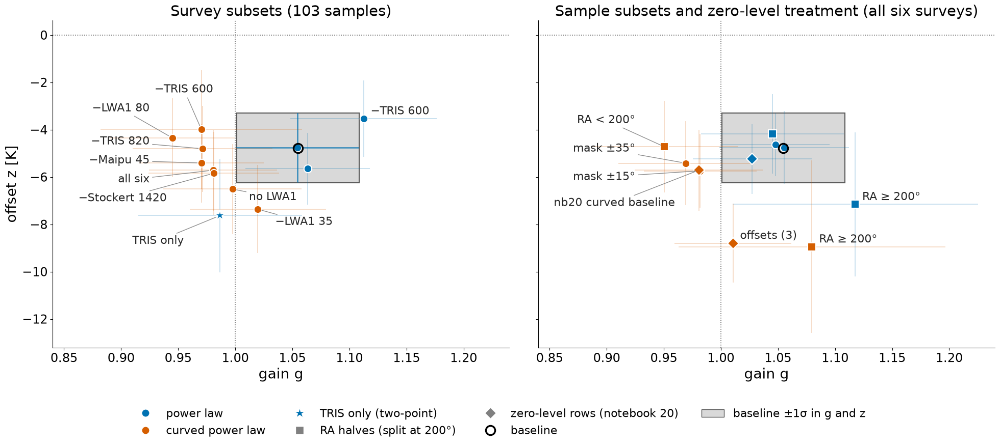

saved robustness_gz_plane.png / .pdf in model_comparison/robustness_check


In [ ]:
# Figure: the g-z plane.  Left: survey subsets; right: mask, RA halves and zero-level treatment.
COL = {"power law": "#0072B2", "curved power law": "#D55E00"}
SHORT = {"all six (baseline)": "baseline", "all six": "all six",
         "without both LWA1 bands": "no LWA1", "best-measured three (Maipu 45, TRIS 600, TRIS 820)": "best 3",
         "TRIS only (two-point power law, as Plot 3)": "TRIS only",
         "Cygnus A mask ±15°": "mask ±15°", "Cygnus A mask ±35°": "mask ±35°",
         f"±{CYG_HALF:g}° mask, RA < {RA_SPLIT:g}°": f"RA < {RA_SPLIT:g}°",
         f"±{CYG_HALF:g}° mask, RA ≥ {RA_SPLIT:g}°": f"RA ≥ {RA_SPLIT:g}°",
         "offsets fitted, notebook 20 configuration (1)": "offsets (1)",
         "offsets fitted, notebook 20 configuration (3)": "offsets (3)",
         "no offsets, errors as now (notebook 20 baseline)": "nb20 curved baseline"}
SHORT.update({f"without {v}": f"−{v}" for v in SURVEYS.values()})
MARK = {"survey subsets": "o", "Cygnus A mask": "o", "RA half": "s", "zero-level treatment (notebook 20)": "D"}

def marker(r):
    if r["subset"].startswith("TRIS only"):
        return "*"
    if r["group"] == "sample subsets":
        return "o" if r["subset"].startswith("Cygnus") else "s"
    return MARK[r["group"]]

CV, PL = "curved power law", "power law"
LABEL_POS = {   # (g, z [K], alignment) of the labels in the crowded parts of the panels, joined to their points
    ("without LWA1 80", CV): (0.925, -3.1, "right"), ("without TRIS 600", CV): (0.955, -2.3, "center"),
    ("without TRIS 820", CV): (0.925, -4.5, "right"), ("without Maipu 45", CV): (0.925, -5.3, "right"),
    ("all six", CV): (0.925, -6.1, "right"), ("without Stockert 1420", CV): (0.94, -6.9, "right"),
    ("TRIS only (two-point power law, as Plot 3)", PL): (0.955, -8.7, "right"),
    ("without both LWA1 bands", CV): (1.012, -6.85, "left"), ("without LWA1 35", CV): (1.035, -7.9, "left"),
    (f"±{CYG_HALF:g}° mask, RA < {RA_SPLIT:g}°", CV): (0.925, -3.6, "right"),
    ("Cygnus A mask ±35°", CV): (0.925, -4.8, "right"), ("Cygnus A mask ±15°", CV): (0.925, -6.0, "right"),
    ("no offsets, errors as now (notebook 20 baseline)", CV): (0.96, -7.1, "right")}

def panel(ax, d, title):
    g0, sg0, z0, sz0 = BASE["g"], BASE["sigma_g"], BASE["z [K]"], BASE["sigma_z [K]"]
    ax.add_patch(Rectangle((g0 - sg0, z0 - sz0), 2 * sg0, 2 * sz0, fc="0.85", ec="0.35", zorder=0))
    ax.axvline(1, color="0.4", ls=":", zorder=1)
    ax.axhline(0, color="0.4", ls=":", zorder=1)
    for i, r in d.iterrows():
        c = COL[r["model"]]
        ax.errorbar(r["g"], r["z [K]"], xerr=r["sigma_g"], yerr=r["sigma_z [K]"], fmt="none", ecolor=c, alpha=0.25,
                    zorder=2)
        ax.plot(r["g"], r["z [K]"], marker(r), ms=16 if marker(r) == "*" else 11, mfc=c, mec="white", mew=1.5, zorder=4)
        if r["inside baseline error bars"] == "no":
            lab = SHORT.get(r["subset"], r["subset"])
            pos = LABEL_POS.get((r["subset"], r["model"]))
            if pos is None:
                ax.annotate(lab, (r["g"], r["z [K]"]), xytext=(10, 6), textcoords="offset points", fontsize=16,
                            color="0.15", zorder=5)
            else:
                ax.annotate(lab, (r["g"], r["z [K]"]), xytext=pos[:2], textcoords="data", ha=pos[2], va="center",
                            fontsize=16, color="0.15", zorder=5,
                            arrowprops=dict(arrowstyle="-", color="0.55", shrinkA=2, shrinkB=6))
    ax.plot(BASE["g"], BASE["z [K]"], "o", ms=13, mfc="none", mec=COLORS["ink"], mew=2.5, zorder=5)
    ax.set_xlabel("gain g")
    ax.set_title(title)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

with plt.rc_context({"font.size": 20, "axes.titlesize": 21, "axes.labelsize": 20, "xtick.labelsize": 17,
                     "ytick.labelsize": 17, "legend.fontsize": 16}):
    fig, axes = plt.subplots(1, 2, figsize=(20, 9), sharex=True, sharey=True)
    panel(axes[0], tab[tab["group"] == "survey subsets"], "Survey subsets (103 samples)")
    panel(axes[1], tab[tab["group"] != "survey subsets"], "Sample subsets and zero-level treatment (all six surveys)")
    axes[0].set_ylabel("offset z [K]")
    axes[0].set_xlim(0.84, 1.24)
    from matplotlib.lines import Line2D
    h = [Line2D([], [], ls="", marker="o", ms=11, mfc=COL["power law"], mec="white", label="power law"),
         Line2D([], [], ls="", marker="o", ms=11, mfc=COL["curved power law"], mec="white", label="curved power law"),
         Line2D([], [], ls="", marker="*", ms=16, mfc=COL["power law"], mec="white", label="TRIS only (two-point)"),
         Line2D([], [], ls="", marker="s", ms=11, mfc="0.5", mec="white", label=f"RA halves (split at {RA_SPLIT:g}°)"),
         Line2D([], [], ls="", marker="D", ms=11, mfc="0.5", mec="white", label="zero-level rows (notebook 20)"),
         Line2D([], [], ls="", marker="o", ms=13, mfc="none", mec=COLORS["ink"], mew=2.5, label="baseline"),
         Rectangle((0, 0), 1, 1, fc="0.85", ec="0.35", label="baseline ±1σ in g and z")]
    fig.legend(handles=h, loc="lower center", ncol=4)
    fig.tight_layout(rect=(0, 0.11, 1, 1))
    save(fig, "robustness_gz_plane")
    plt.show()
print("saved robustness_gz_plane.png / .pdf in", OUT.relative_to(REPO))

### Reading the results (2026-11-05)

Baseline: g = 1.0548 ± 0.0536, z = −4.77 ± 1.47 K (six-survey power law, 103 samples). Every difference is fit − baseline.

* **(i) Inside the baseline error bars.** Of the 28 fits besides the baseline, 14 are inside in g, 22 are inside in z and 11
  are inside in both. No spectral fit was flagged as not converged or not finite, so no sample was left out.
* **(ii) Outside.** All 14 power-law fits are inside except three: without TRIS 600 (Δg +0.058; Δz +1.24 K, inside), TRIS
  only (Δg −0.068, Δz −2.86 K) and RA ≥ 200° (Δg +0.063, Δz −2.38 K). All 14 curved-power-law fits are outside. Twelve
  are outside in g, from Δg −0.057 to −0.110. Their Δz runs from −1.74 to +0.43 K, outside only for no LWA1 (−1.74 K).
  The other two are outside in z only: without LWA1 35 (Δg −0.035, Δz −2.59 K) and RA ≥ 200° (Δg +0.025, Δz −4.17 K).
  Notebook 20's offsets-fitted curved row (3) has Δg −0.044, Δz −4.02 K. Its curved baseline row is the all-six curved
  fit here (Δg −0.074, Δz −0.94 K). Its offsets-fitted power-law row (1) is inside (Δg −0.027, Δz −0.47 K).
* **(iii) Curved − power law, same subset and samples** (12 pairs). |Δg| is larger than the baseline σ_g = 0.0536 in 10 pairs
  (−0.057 to −0.142). The two exceptions are without LWA1 35 (−0.035) and RA ≥ 200° (−0.038). |Δz| is larger than the baseline
  σ_z = 1.47 K in 3 pairs: without LWA1 35 (−2.60 K), no LWA1 (−1.75 K) and RA ≥ 200° (−1.79 K).

# Part J — Fits on 13 points and the TOD prediction at any frequency (RHINO)

**Origin:** `notebooks/19_power_law_tod_prediction.ipynb` (archived: `../moonrunes_archive_2026-11-16/notebooks/19_power_law_tod_prediction.ipynb`)

| | |
|---|---|
| **Reads** | `res/`, `configs/run_pipeline.yaml`, `configs/model_comp_config.yaml`, `error_bars.csv`, `external/irfan_puglisi_2025/` (third party) |
| **Writes** | `test_outputs/tod_prediction/` (Tests 1–5; Test 6's last outputs of 2026-11-05 are kept there) |
| **Feeds the paper** | nothing: the RHINO prediction (fig10, Section 7) is pipeline step 7 |

**Stored outputs** are from the original notebook (not re-run after the merge). **Survey set: 13 points** (six + LWA1 38, 40, 45, 50, 60, 70, 74 MHz). Its first cell's "4 survey points … and both TRIS frequencies" is out of date.

**Pipeline:** Test 6 (RHINO) is pipeline step 7, fed by our spectral model (step 5) rather than this Part's 13-point weighted-least-squares fit.

## Power-law and curved power-law fits along the TRIS ring, and TOD prediction at any frequency

**What.** A spectral model is fitted at each of the 120 TRIS ring samples (TOD route, everything seen through the TRIS
beam), using the **4 survey points of the model comparison and both TRIS frequencies**. The fitted model then
**predicts the ring TOD at any frequency**, still through the TRIS beam. The whole analysis is done for each model in
`FIT_MODELS` (settings): the **power law** (the comparison's winner) and the **curved power law** (a close second),
shown side by side in every test.

* **Data, per ring sample:** the data sets in `DATASETS` (settings), currently 13 points: TRIS 600 and 820 MHz ring
  data (effective 600.5 / 817.8 MHz), and the beam-matched ring TODs (`sed.tod_beam: beam_matched`) of the nine LWA1
  maps (35, 38, 40, 45, 50, 60, 70, 74, 80 MHz; Dowell et al. 2017), Maipu 45 and Stockert 1420 MHz.
  **Caveat:** the nine LWA1 maps share one calibration, but each point carries its own 20% scale error, treated as
  independent of the others; together they therefore pull the fit harder than one 20%-calibrated survey should.
  Haslam 408 MHz is **not** fitted: it is the target, and is used here only as a held-out check (Test 4).
* **Points and error bars** are built by the model comparison's own code (`run_comparison.select_datasets` and
  `tod_units`), so they are exactly the points `run_comparison.py` would fit with these data sets. Error bars are the
  published ones (`configs/error_bars.csv`; TRIS: `sed_prototype.ring_sigma`).
* **Temperatures** are Rayleigh-Jeans with the CMB removed (the fit convention). `predict_tod(..., include_cmb=True)`
  adds T_CMB,RJ(ν) back for a TOD in the convention of the TRIS ring data.
* **Models**, with x = ln(ν/ν0), ν0 = 408 MHz (`configs/model_comp_config.yaml`), as in `model_comparison/models.py`:
  power law T = A exp(β x) (2 parameters); curved power law T = A exp(β x + C x²) (3 parameters).
  dof = number of points − number of parameters.
* **Fit:** weighted least squares, i.e. the minimum of χ² = Σ ((T_i − model_i)/σ_i)², the maximum of the Gaussian
  likelihood. No priors, no Occam penalty. Parameter covariance from the published errors only (`absolute_sigma=True`),
  **not** rescaled by χ²/dof.
* **Prediction uncertainty:** 1σ from the full parameter covariance, σ_T² = J C Jᵀ, so the parameter correlations are
  kept. Outside 35–1420 MHz the prediction is an extrapolation, and there the two models part ways fastest.
* **Residuals** are always data − model in K, with the data's ±1σ shaded beside them.
* **Test 6** takes the best-fit prediction to RHINO (60–80 MHz): deconvolved from the TRIS beam, observed with
  the RHINO beam, against GSM2008, GSM2016 and LFSM through the same beams.

**Outputs** go to `paper_outputs/tod_prediction/` (plots, CSVs; file names carry the model, e.g. `_power_law`, `_curved_power_law`;
the input cache in `paper_outputs/tod_prediction/cache/` is git-ignored). Nothing outside that folder is written, and no existing
code is changed. The whole notebook runs in well under a minute once the cache exists.

### Settings

In [ ]:
%matplotlib inline
import os
os.environ.setdefault("TQDM_DISABLE", "1")
import sys
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MC_DIR = REPO / "model_comparison"
OUT_DIR = REPO / "test_outputs" / "tod_prediction"   # a check: the RHINO prediction is pipeline step 7
CACHE_DIR = OUT_DIR / "cache"
OUT_DIR.mkdir(exist_ok=True); CACHE_DIR.mkdir(exist_ok=True)
ERRORS_CSV = REPO / "configs" / "error_bars.csv"

# ---- the spectral models to fit (names as in model_comparison/models.py); every test shows each of them ----
FIT_MODELS = ["power law", "curved power law"]

# ---- the data sets in every fit (keys as in error_bars.csv); Haslam is never a fit point ----
DATASETS = ["TRIS_600", "TRIS_820", "LWA1_38.fits","LWA1_40.fits","LWA1_45.fits","LWA1_50.fits",
            "LWA1_60.fits", "LWA1_70.fits", "LWA1_74.fits",
            "LWA_35MHz.fits", "MAIPU_45mhZ.fits", "LWA_80MHz.fits", "STOCKERT_VILLA_1400MHZ.fits"]
TARGET_FILE = "HASLAM_DESTRIPED_ONLY.fits"   # held-out check only (Test 4)

# ---- frequencies to predict the ring TOD at (MHz) ----
PRED_FREQS_MHZ = [50.0, 100.0, 150.0, 200.0, 300.0, 408.0, 600.5, 817.8, 1000.0, 1420.0]
SPECTRUM_SAMPLES = [0, 40, 75, 100]          # ring samples whose full spectrum is plotted (Test 5)

with open(REPO / "configs" / "model_comp_config.yaml") as f:
    MC_CFG = yaml.safe_load(f)
NU0 = float(MC_CFG["models"]["nu0_mhz"])     # 408 MHz

NAMES = {"TRIS_600": "TRIS 600", "TRIS_820": "TRIS 820", "LWA_35MHz.fits": "LWA1 35","LWA1_38.fits": "LWA1 38","LWA1_40.fits": "LWA1 40","LWA1_45.fits": "LWA1 45","LWA1_50.fits": "LWA1 50","LWA1_60.fits": "LWA1 60","LWA1_70.fits": "LWA1 70","LWA1_74.fits": "LWA1 74",
         "MAIPU_45mhZ.fits": "Maipu 45", "LWA_80MHz.fits": "LWA1 80", "STOCKERT_VILLA_1400MHZ.fits": "Stockert 1420"}
# Colour per data set, fixed.  The nine LWA1 maps are one survey, so they share one hue, light (35 MHz) to dark
# (80 MHz); the other data sets keep their Okabe-Ito colours (colourblind-safe).
COL = {"TRIS_600": "#D55E00", "TRIS_820": "#E69F00", "MAIPU_45mhZ.fits": "#009E73",
       "STOCKERT_VILLA_1400MHZ.fits": "#CC79A7"}
LWA1_KEYS = ["LWA_35MHz.fits", "LWA1_38.fits", "LWA1_40.fits", "LWA1_45.fits", "LWA1_50.fits", "LWA1_60.fits",
             "LWA1_70.fits", "LWA1_74.fits", "LWA_80MHz.fits"]                   # in frequency order
for _i, _k in enumerate(LWA1_KEYS):
    COL[_k] = plt.get_cmap("Blues")(0.4 + 0.55 * _i / (len(LWA1_KEYS) - 1))
_missing = [k for k in DATASETS if k not in NAMES or k not in COL]
assert not _missing, f"give these data sets a NAMES label and a COL colour: {_missing}"
# fixed per model (not used by any data set above)
MCOL = {"power law": "#000000", "curved power law": "#882255"}
MLS = {"power law": "-", "curved power law": "--"}
SHORT = {"power law": "power law", "curved power law": "curved PL"}
HASLAM_COL = "#7F7F7F"
sys.path.insert(0, str(REPO / "src"))
from moonrunes.style import use_tris_style, COLORS
use_tris_style()
plt.rcParams.update({"axes.grid": False, "figure.dpi": 110, "font.size": 12, "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})

def slug(m):
    return m.replace(" ", "_")

### 1. The SED points at every ring sample
Built with the model comparison's code: `select_datasets` applies `DATASETS` (overriding `sed.exclude_maps` for this
notebook only; `run_pipeline.yaml` is not edited), `sed_prototype.Inputs` makes the beam-matched ring TODs, and
`tod_units` turns them into (ν, T, σ) points. Building `Inputs` takes a few minutes, so the points are cached; the cache
is redone whenever the ring-TOD method, the data sets, the error bars or the target change.

In [ ]:
sys.dont_write_bytecode = True
sys.path.insert(0, str(REPO / "src"))
sys.path.insert(0, str(MC_DIR))
for _name in [n for n in sys.modules if n.split(".")[0] in ("moonrunes", "models", "run_comparison")]:
    del sys.modules[_name]
import run_comparison as rc                       # data helpers only; main() is not run
from moonrunes import sky_maps
from moonrunes.config import load_config
from moonrunes.sed_prototype import Inputs, tod_method_key, sigma_for

RUN_CFG, TRIS_SEL, MAPS_SEL = rc.select_datasets(DATASETS, load_config(REPO / "configs" / "run_pipeline.yaml"), REPO / "res")
KEYS = [rc.tris_key(f) for f in TRIS_SEL] + MAPS_SEL          # in error_bars.csv order
assert TARGET_FILE not in KEYS
CACHE_KEY = json.dumps({"tod": tod_method_key(RUN_CFG), "datasets": KEYS, "target": TARGET_FILE,
                        "error_bars": hashlib.md5(ERRORS_CSV.read_bytes()).hexdigest()}, sort_keys=True)
CACHE = CACHE_DIR / "sed_points.npz"

def build_points():
    """(ra, nu[key], T[key] (120,), S[key] (120,), Haslam TOD dict).  T in K, RJ, CMB removed; NaN = no point."""
    errors = rc.read_error_bars(ERRORS_CSV)
    inp = Inputs(RUN_CFG, REPO / "res", target_file=TARGET_FILE, verbose=True)
    n = inp.ra.size
    nu = {}
    T = {k: np.full(n, np.nan) for k in KEYS}
    S = {k: np.full(n, np.nan) for k in KEYS}
    for uid, _, pts in rc.tod_units(inp, errors, TRIS_SEL):
        for key, f, t, s in rc.usable(pts):
            nu[key], T[key][uid], S[key][uid] = f, t, s
    tgt = inp.target
    h_raw = np.asarray(inp.tods[tgt["name"]]["tod"], dtype=float)
    h_ex = np.asarray(sky_maps.rj_excess(h_raw, tgt), dtype=float)
    h_good = np.asarray(inp.tods[tgt["name"]]["good"], dtype=bool)
    haslam = dict(nu=float(tgt["freq_mhz"]), T=np.where(h_good, h_ex, np.nan),
                  S=np.where(h_good, np.asarray(sigma_for(tgt, h_ex), dtype=float), np.nan))
    return np.asarray(inp.ra, dtype=float), nu, T, S, haslam

if CACHE.exists() and str(np.load(CACHE)["key"]) == CACHE_KEY:
    z = np.load(CACHE)
    RA = z["ra"]
    NU = {k: float(v) for k, v in zip(KEYS, z["nu"])}
    T_DATA = {k: z["T"][i] for i, k in enumerate(KEYS)}
    S_DATA = {k: z["S"][i] for i, k in enumerate(KEYS)}
    HASLAM = dict(nu=float(z["h_nu"]), T=z["h_T"], S=z["h_S"])
    print("SED points read from", CACHE.relative_to(REPO))
else:
    RA, NU, T_DATA, S_DATA, HASLAM = build_points()
    np.savez(CACHE, key=CACHE_KEY, ra=RA, nu=[NU[k] for k in KEYS], T=[T_DATA[k] for k in KEYS],
             S=[S_DATA[k] for k in KEYS], h_nu=HASLAM["nu"], h_T=HASLAM["T"], h_S=HASLAM["S"])
    print("SED points built and cached in", CACHE.relative_to(REPO))

N_SAMP = RA.size
pd.DataFrame({"data set": [NAMES[k] for k in KEYS], "frequency (MHz)": [NU[k] for k in KEYS],
              "samples with a point": [int(np.isfinite(T_DATA[k]).sum()) for k in KEYS],
              "median T (K)": [np.nanmedian(T_DATA[k]) for k in KEYS],
              "median σ (K)": [np.nanmedian(S_DATA[k]) for k in KEYS]}).round(3)

SED points read from tod_prediction/cache/sed_points.npz


,data set,frequency (MHz),samples with a point,median T (K),median σ (K)
0,TRIS 600,600.5,120,12.353,0.067
1,TRIS 820,817.8,120,5.072,0.430
2,LWA1 35,35.0,120,14102.273,2820.455
3,LWA1 38,38.0,120,12253.407,2450.681
4,LWA1 40,40.0,120,10600.396,2120.079
5,LWA1 45,45.0,120,8059.664,1611.933
6,Maipu 45,45.0,120,7499.889,133.330
7,LWA1 50,50.0,120,6251.032,1250.206
8,LWA1 60,60.0,120,4139.135,827.827
9,LWA1 70,70.0,120,2843.986,568.797


### 2. The fit and the prediction function
`sed_model` and `sed_jacobian` define both models; `fit_sed` fits one sample; `fit_ring` fits all 120; `predict_tod`
evaluates a fitted model, with its 1σ uncertainty, at any frequencies. These functions are the whole method. To add a
model, give it a parameter list in `PARAMS` and its terms in `sed_model` / `sed_jacobian`.

In [ ]:
from scipy.optimize import curve_fit

PARAMS = {"power law": ["A_K", "beta"], "curved power law": ["A_K", "beta", "C"]}

def sed_model(nu, p):
    """T(nu) in K (RJ, CMB removed).  p = (A, beta) for the power law, (A, beta, C) for the curved power law:
    T = A exp(beta x + C x^2), x = ln(nu / NU0).  Broadcasts over nu."""
    x = np.log(np.asarray(nu, dtype=float) / NU0)
    curv = p[2] * x ** 2 if len(p) > 2 else 0.0
    return p[0] * np.exp(p[1] * x + curv)

def sed_jacobian(nu, p):
    """dT/dp, shape (..., len(p)): (T/A, T x[, T x^2])."""
    x = np.log(np.asarray(nu, dtype=float) / NU0)
    T = sed_model(nu, p)
    cols = [T / p[0], T * x, T * x ** 2][:len(p)]
    return np.stack(cols, axis=-1)

def fit_sed(nu, t, s, model):
    """Minimum-chi^2 fit of ``model`` through the points (nu, t +/- s).

    Start: a weighted straight line in log T vs log nu (C = 0 for the curved power law).  Then curve_fit
    (Levenberg-Marquardt) on T itself, error bars taken as absolute (no rescaling by chi2/dof).
    Returns the parameters, their covariance, chi2, n and dof."""
    nu, t, s = (np.asarray(x, dtype=float) for x in (nu, t, s))
    ok = np.isfinite(t) & np.isfinite(s) & (s > 0) & (t > 0)
    nu, t, s = nu[ok], t[ok], s[ok]
    npar = len(PARAMS[model])
    if nu.size <= npar:
        return None
    slope, icpt = np.polyfit(np.log(nu / NU0), np.log(t), 1, w=t / s)
    p0 = [np.exp(icpt), slope, 0.0][:npar]
    p, cov = curve_fit(lambda n, *q: sed_model(n, q), nu, t, p0=p0, sigma=s, absolute_sigma=True, maxfev=20000)
    chi2 = float(np.sum(((t - sed_model(nu, p)) / s) ** 2))
    return dict(p=p, cov=cov, chi2=chi2, n=int(nu.size), dof=int(nu.size - npar))

def fit_ring(model, keys=KEYS):
    """fit_sed at every ring sample, with the data sets in ``keys``."""
    npar = len(PARAMS[model])
    out = dict(model=model, p=np.full((N_SAMP, npar), np.nan), cov=np.full((N_SAMP, npar, npar), np.nan),
               chi2=np.full(N_SAMP, np.nan), n=np.zeros(N_SAMP, int), dof=np.zeros(N_SAMP, int))
    nu = np.array([NU[k] for k in keys])
    for i in range(N_SAMP):
        r = fit_sed(nu, [T_DATA[k][i] for k in keys], [S_DATA[k][i] for k in keys], model)
        if r is not None:
            for name in ("p", "cov", "chi2", "n", "dof"):
                out[name][i] = r[name]
    return out

def predict_tod(freqs_mhz, model="power law", fit=None, include_cmb=False):
    """Ring TOD predicted by the fitted ``model`` at ``freqs_mhz``, seen through the TRIS beam.

    Returns (T, sigma), each of shape (len(freqs_mhz), 120 ring samples), in K.
    sigma is the 1 sigma from the parameter covariance: J C J^T with J = dT/dp.
    fit: a fit_ring result (default FITS[model], all of DATASETS).
    include_cmb=False: RJ with the CMB removed (the fit convention).
    include_cmb=True:  + T_CMB,RJ(nu), as in the TRIS ring data."""
    fit = FITS[model] if fit is None else fit
    nu = np.atleast_1d(np.asarray(freqs_mhz, dtype=float))[:, None]          # (nfreq, 1)
    p = [fit["p"][None, :, j] for j in range(fit["p"].shape[1])]             # each (1, nsamp)
    T = sed_model(nu, p)
    J = sed_jacobian(nu, p)                                                   # (nfreq, nsamp, npar)
    sigma = np.sqrt(np.einsum("fsi,sij,fsj->fs", J, fit["cov"], J))
    if include_cmb:
        T = T + np.array([sky_maps.cmb_rj_k(f) for f in nu[:, 0]])[:, None]
    return T, sigma

FITS = {m: fit_ring(m) for m in FIT_MODELS}
for m, F in FITS.items():
    print(f"{m}: fitted {np.isfinite(F['chi2']).sum()} of {N_SAMP} ring samples; points per fit {sorted(set(F['n'].tolist()))}, dof {sorted(set(F['dof'].tolist()))}")

power law: fitted 120 of 120 ring samples; points per fit [13], dof [11]
curved power law: fitted 120 of 120 ring samples; points per fit [13], dof [10]


#### Checks of the fit
* **Same model as the comparison:** `sed_model` against `model_comparison/models.py` at random parameters.
* **Same minimum as the model comparison's optimiser.** `run_comparison.max_likelihood` (L-BFGS-B inside the
  `model_comp_config.yaml` prior box) must find the same χ² at every sample, if the best fit lies inside the box (a positive
  difference means the box cuts the fit off; a negative one would mean this fit missed the minimum).
* **Power law only: same answer as `sed_prototype.fit_power_law`**, the stage 3 prototype's fit.
* **Inside the comparison's prior box?** (A in [1, 1000] K, β in [−3.5, −1.5], C in [−0.5, 0.5].) Reported, not enforced.

In [ ]:
from models import build_models, prior_transform
from moonrunes.sed_prototype import fit_power_law as proto_fit

MC_MODELS = build_models(MC_CFG)
rng = np.random.default_rng(0)
nu_all = np.array([NU[k] for k in KEYS])
check_rows = []
for m in FIT_MODELS:
    names, fn = MC_MODELS[m]
    assert names == PARAMS[m], (names, PARAMS[m])
    q = np.array([[30.0, -2.6, 0.1][:len(names)]])
    assert np.allclose(fn(nu_all, q)[0], sed_model(nu_all, q[0])), m
    transform = prior_transform(names, MC_CFG["priors"])
    F = FITS[m]
    d_chi2, d_proto = [], []
    for i in range(N_SAMP):
        t = np.array([T_DATA[k][i] for k in KEYS]); s = np.array([S_DATA[k][i] for k in KEYS]); ok = np.isfinite(t)
        _, c2, _ = rc.max_likelihood(names, fn, transform, nu_all[ok], t[ok], s[ok], 8, rng)
        d_chi2.append(c2 - F["chi2"][i])
        if m == "power law":
            r = proto_fit(nu_all[ok], t[ok], s[ok])
            d_proto.append(max(abs(r["A"] / F["p"][i, 0] - 1), abs(r["beta"] - F["p"][i, 1])))
    inside = np.ones(N_SAMP, bool)
    for j, n in enumerate(names):
        pr = MC_CFG["priors"][n]
        inside &= (F["p"][:, j] > pr["low"]) & (F["p"][:, j] < pr["high"])
    check_rows.append({"model": m, "min Δχ² (comparison optimiser − this fit)": np.min(d_chi2),
                       "max Δχ²": np.max(d_chi2),
                       "max diff vs sed_prototype.fit_power_law": np.max(d_proto) if d_proto else np.nan,
                       "samples inside prior box": int(inside.sum())})
pd.DataFrame(check_rows)

,model,min Δχ² (comparison optimiser − this fit),max Δχ²,max diff vs sed_prototype.fit_power_law,samples inside prior box
0,power law,1.190159e-13,1.694698e-10,5.245804e-11,120
1,curved power law,-1.345267e-09,7.867980e-09,NaN,120


#### Irfan & Puglisi (2025) β along the ring, for comparison
Irfan & Puglisi 2025 (arXiv:2512.08522, MNRAS, doi:10.1093/mnras/stag517) fit the synchrotron spectrum between 45 and
2300 MHz pixel by pixel and release all-sky maps of the spectral index at 45 MHz, β₄₅, and the curvature c
(Zenodo record 19153811, CC-BY 4.0; HEALPix nside 256, RING, Galactic, 1° resolution), saved in
`external/irfan_puglisi_2025/`. Their model is T ∝ (ν/45 MHz)^(β₄₅ + c ln(ν/45 MHz)), i.e. T ∝ exp(β₄₅ y + c y²) with
y = ln(ν/45 MHz): the same form as our curved power law, so **their c is directly comparable to our C** (a quadratic
coefficient in log ν does not depend on the pivot). Two 408 MHz versions of their β are drawn:

* **Irfan β(408), their recipe:** β₄₅ + c ln(408/45), as their Zenodo record defines the index at 408 MHz. It is the
  exponent of T(408)/T(45) = (408/45)^β, i.e. the mean slope between 45 and 408 MHz.
* **Irfan local slope at 408 MHz:** d ln T / d ln ν = β₄₅ + 2c ln(408/45). This is what our curved power law's β is
  (its slope at the 408 MHz pivot).

Our power law's β is one slope across all the points (35–1420 MHz). Each Irfan map is rotated to equatorial and
averaged through the TRIS beam at the ring pointings, with the same beam matching as the ring TODs (`tris_cuts`
kernel, their 1° resolution taken out). The average is a plain beam average of the parameter; weighting it by Haslam's
408 MHz brightness changes β(408) by 0.001 (median) and at most 0.06. Irfan's maps include Haslam and LWA1 and Maipu
data, so they are not independent of our fits. Their published error maps are fractional and are not drawn.

In [ ]:
IRFAN_DIR = REPO / "external" / "irfan_puglisi_2025"
IRFAN_FILES = {"beta45": IRFAN_DIR / "final_beta_1deg.npy", "c": IRFAN_DIR / "final_cs_1deg.npy"}
IRFAN_NU0, IRFAN_FWHM = 45.0, 1.0           # their pivot (MHz) and map resolution (deg)
IRFAN_CACHE = CACHE_DIR / "irfan_puglisi_2025_ring.npz"

def irfan_ring():
    """Irfan & Puglisi's beta45 and c maps averaged through the TRIS beam at the 120 ring pointings."""
    import healpy as hp
    from moonrunes import elliptical_beam, frames
    from moonrunes.stage1_tris_maps import import_limtod_tris
    geom = import_limtod_tris(RUN_CFG).tris_zenith_geometry(RA)
    vec = hp.ang2vec(np.radians(90.0 - float(geom.latitude_deg)) * np.ones_like(RA),
                     np.radians(np.asarray(geom.lst_deg, dtype=float)))
    spec = elliptical_beam.beam_spec_from_config(RUN_CFG, kernel="tris_cuts")
    b45, c = (np.load(IRFAN_FILES[k], allow_pickle=False) for k in ("beta45", "c"))
    y408 = np.log(NU0 / IRFAN_NU0)
    maps = {"beta45": b45, "c": c, "beta408_recipe": b45 + c * y408, "slope408": b45 + 2 * c * y408}
    out = {}
    for k, m in maps.items():
        eq = frames.rotate_full_sky(m, ("G", "C"))
        out[k] = np.asarray(elliptical_beam.smooth_at_positions(eq, np.isfinite(eq), IRFAN_FWHM, spec, vec)["values"])
    return out

IRFAN_KEY = json.dumps({"tod": tod_method_key(RUN_CFG), "ra": hashlib.md5(RA.tobytes()).hexdigest(),
                        "files": {k: hashlib.md5(p.read_bytes()).hexdigest() for k, p in IRFAN_FILES.items()}}, sort_keys=True)
if IRFAN_CACHE.exists() and str(np.load(IRFAN_CACHE)["key"]) == IRFAN_KEY:
    IRFAN = {k: v for k, v in np.load(IRFAN_CACHE).items() if k != "key"}
else:
    IRFAN = irfan_ring()
    np.savez(IRFAN_CACHE, key=IRFAN_KEY, **IRFAN)
pd.DataFrame({"sample": np.arange(N_SAMP), "ra_deg": RA, "beta_45MHz": IRFAN["beta45"], "c": IRFAN["c"],
              "beta_408MHz_recipe": IRFAN["beta408_recipe"], "local_slope_408MHz": IRFAN["slope408"]}
             ).to_csv(OUT_DIR / "irfan_puglisi_2025_ring.csv", index=False)
pd.DataFrame({"Irfan quantity along the ring": ["β at 45 MHz", "β(408), their recipe", "local slope at 408 MHz", "c"],
              "median": [np.median(IRFAN[k]) for k in ("beta45", "beta408_recipe", "slope408", "c")],
              "min": [np.min(IRFAN[k]) for k in ("beta45", "beta408_recipe", "slope408", "c")],
              "max": [np.max(IRFAN[k]) for k in ("beta45", "beta408_recipe", "slope408", "c")]}).round(3)

,Irfan quantity along the ring,median,min,max
0,β at 45 MHz,-2.420,-2.787,-2.302
1,"β(408), their recipe",-2.506,-2.587,-2.462
2,local slope at 408 MHz,-2.620,-2.679,-2.306
3,c,-0.046,-0.077,0.096


### Test 1 — Fitted parameters along the ring
A, β (and C for the curved power law) with their 1σ errors, and χ²/dof (dof = number of points − number of parameters).
Irfan & Puglisi's β at 408 MHz (both versions above) is drawn on the β panel and their c on the C panel, in green.
The Pearson r panel shows the correlation coefficient of each parameter pair from each fit's covariance,
r = cov(p, q) / (σ_p σ_q): A–β for both models (solid: power law, dashed: curved PL), A–C and β–C for the curved PL.
Saved per model to `paper_outputs/tod_prediction/fit_per_sample_<model>.csv`.

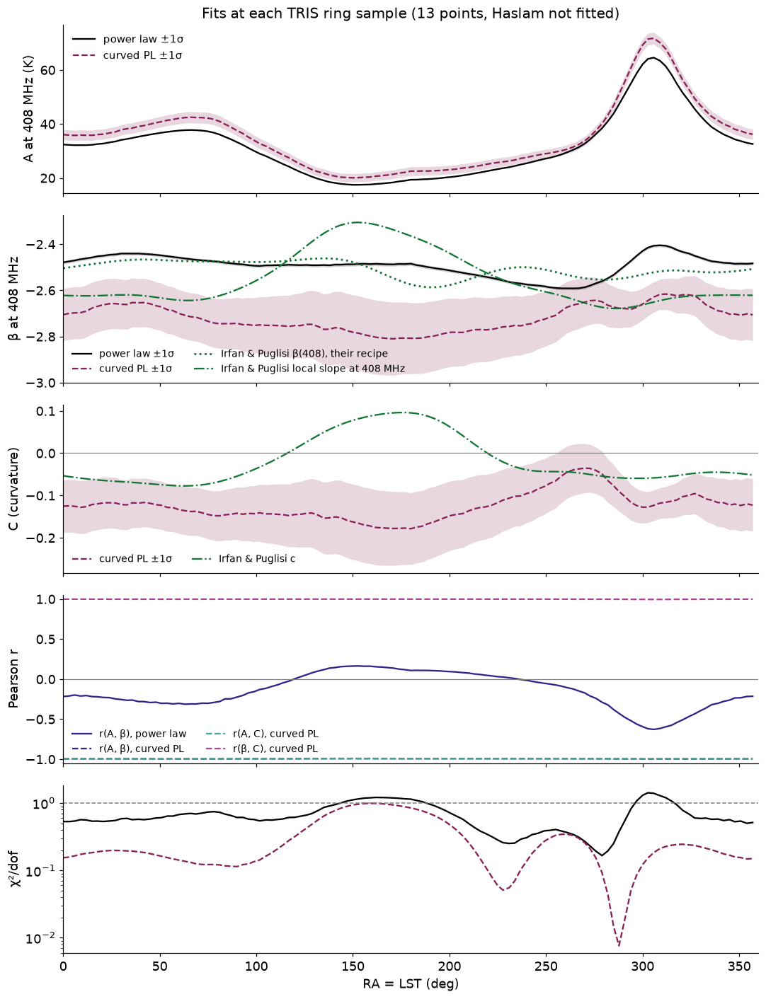

,model,median A_K,median beta,median χ²,mean χ²,dof,median χ²/dof,mean χ²/dof,median C
0,power law,32.150,-2.487,6.525,7.364,11,0.593,0.669,NaN
1,curved power law,35.546,-2.721,1.939,3.079,10,0.194,0.308,-0.126


,difference along the ring,median,min,max
0,power law β − Irfan β(408) recipe,0.019,-0.075,0.115
1,power law β − Irfan local slope 408,0.091,-0.181,0.244
2,curved PL β − Irfan local slope 408,-0.095,-0.488,0.027
3,curved PL C − Irfan c,-0.071,-0.274,0.014


In [ ]:
for m, F in FITS.items():
    df = pd.DataFrame({"sample": np.arange(N_SAMP), "ra_deg": RA})
    for j, n in enumerate(PARAMS[m]):
        df[n] = F["p"][:, j]; df["sigma_" + n] = np.sqrt(F["cov"][:, j, j])
    for a in range(len(PARAMS[m])):
        for b in range(a + 1, len(PARAMS[m])):
            df[f"corr_{PARAMS[m][a]}_{PARAMS[m][b]}"] = F["cov"][:, a, b] / np.sqrt(F["cov"][:, a, a] * F["cov"][:, b, b])
    df["chi2"], df["n_points"], df["dof"], df["chi2_per_dof"] = F["chi2"], F["n"], F["dof"], F["chi2"] / F["dof"]
    df.to_csv(OUT_DIR / f"fit_per_sample_{slug(m)}.csv", index=False)

panels = [("A_K", "A at 408 MHz (K)"), ("beta", "β at 408 MHz"), ("C", "C (curvature)"),
          ("corr", "Pearson r"), ("chi2dof", "χ²/dof")]
PAIR_COL = {("A_K", "beta"): "#332288", ("A_K", "C"): "#44AA99", ("beta", "C"): "#AA4499"}
PAIR_LABEL = {"A_K": "A", "beta": "β", "C": "C"}
fig, ax = plt.subplots(len(panels), 1, figsize=(10, 13), sharex=True)
for m, F in FITS.items():
    for a, (key, label) in zip(ax, panels):
        if key == "chi2dof":
            a.plot(RA, F["chi2"] / F["dof"], color=MCOL[m], ls=MLS[m], label=SHORT[m])
        elif key == "corr":
            for (p1, p2), col in PAIR_COL.items():
                if p1 in PARAMS[m] and p2 in PARAMS[m]:
                    i1, i2 = PARAMS[m].index(p1), PARAMS[m].index(p2)
                    r = F["cov"][:, i1, i2] / np.sqrt(F["cov"][:, i1, i1] * F["cov"][:, i2, i2])
                    a.plot(RA, r, color=col, ls=MLS[m],
                           label=f"r({PAIR_LABEL[p1]}, {PAIR_LABEL[p2]}), {SHORT[m]}")
        elif key in PARAMS[m]:
            j = PARAMS[m].index(key); v = F["p"][:, j]; e = np.sqrt(F["cov"][:, j, j])
            a.fill_between(RA, v - e, v + e, color=MCOL[m], alpha=0.18, lw=0)
            a.plot(RA, v, color=MCOL[m], ls=MLS[m], label=SHORT[m] + " ±1σ")
        a.set_ylabel(label)
IRFAN_COL = "#117733"
ax[1].plot(RA, IRFAN["beta408_recipe"], color=IRFAN_COL, ls=":", lw=1.8, label="Irfan & Puglisi β(408), their recipe")
ax[1].plot(RA, IRFAN["slope408"], color=IRFAN_COL, ls="-.", label="Irfan & Puglisi local slope at 408 MHz")
ax[2].plot(RA, IRFAN["c"], color=IRFAN_COL, ls="-.", label="Irfan & Puglisi c")
ax[1].legend(fontsize=9, ncol=2, loc="lower left")
ax[2].legend(fontsize=9, ncol=2, loc="lower left")
ax[2].axhline(0, color=HASLAM_COL)
ax[3].axhline(0, color=HASLAM_COL); ax[3].set_ylim(-1.05, 1.05)
ax[3].legend(fontsize=9, ncol=2, loc="lower left")
ax[4].axhline(1, color=HASLAM_COL, ls="--"); ax[4].set_yscale("log")
ax[0].legend(fontsize=10)
ax[-1].set_xlabel("RA = LST (deg)"); ax[-1].set_xlim(0, 360)
ax[0].set_title(f"Fits at each TRIS ring sample ({len(KEYS)} points, Haslam not fitted)")
fig.tight_layout(); fig.savefig(OUT_DIR / "test1_fit_parameters.png"); plt.show()

display(pd.DataFrame([{"model": m, **{f"median {n}": np.median(F["p"][:, j]) for j, n in enumerate(PARAMS[m])},
               "median χ²": np.median(F["chi2"]), "mean χ²": np.mean(F["chi2"]), "dof": int(F["dof"][0]),
               "median χ²/dof": np.median(F["chi2"] / F["dof"]), "mean χ²/dof": np.mean(F["chi2"] / F["dof"])}
              for m, F in FITS.items()]).round(3))
cmp = [("power law β − Irfan β(408) recipe", FITS.get("power law"), 1, IRFAN["beta408_recipe"]),
       ("power law β − Irfan local slope 408", FITS.get("power law"), 1, IRFAN["slope408"]),
       ("curved PL β − Irfan local slope 408", FITS.get("curved power law"), 1, IRFAN["slope408"]),
       ("curved PL C − Irfan c", FITS.get("curved power law"), 2, IRFAN["c"])]
display(pd.DataFrame([{"difference along the ring": n, "median": np.median(F["p"][:, j] - ir),
                       "min": np.min(F["p"][:, j] - ir), "max": np.max(F["p"][:, j] - ir)}
                      for n, F, j, ir in cmp if F is not None]).round(3))

### Test 2 — Models vs TRIS, residuals in kelvin
Top: the TRIS ring data (±1σ published error, shaded) and each fitted model at the TRIS effective frequency.
Bottom: residual = data − model, in K, for each model, with the TRIS 1σ error shaded. TRIS is **in** the fits, so this
shows how well each model goes through it, not a prediction.

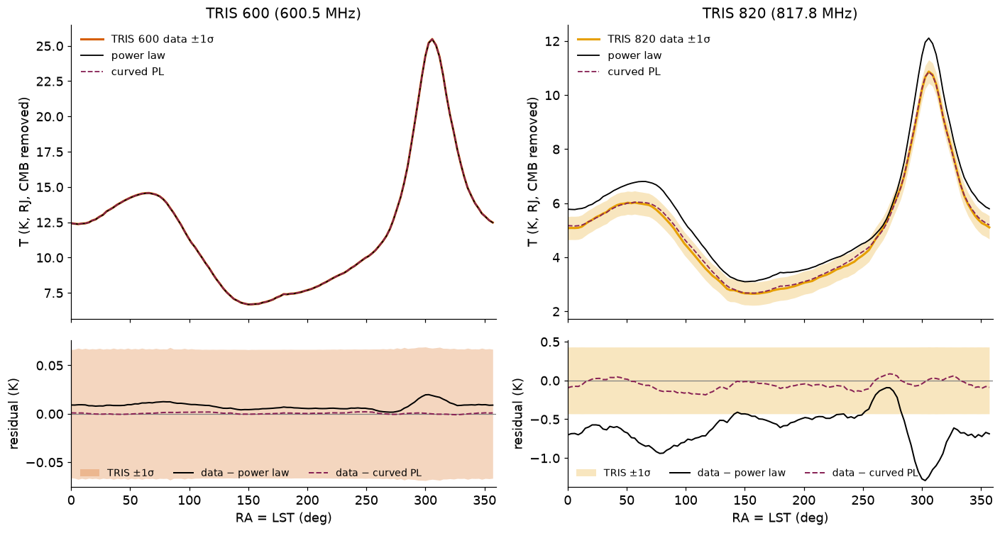

,data set,model,median residual (K),mean residual (K),rms residual (K),max |residual| (K),median σ (K)
0,TRIS 600,power law,0.008,0.008,0.009,0.020,0.067
1,TRIS 600,curved power law,0.000,0.000,0.001,0.002,0.067
2,TRIS 820,power law,-0.607,-0.625,0.666,1.291,0.430
3,TRIS 820,curved power law,-0.057,-0.054,0.084,0.186,0.430


In [ ]:
tris_keys = [k for k in KEYS if k.startswith("TRIS_")]
fig, ax = plt.subplots(2, len(tris_keys), figsize=(6.5 * len(tris_keys), 7), sharex=True,
                       gridspec_kw={"height_ratios": [2, 1]}, squeeze=False)
rows = []
for j, k in enumerate(tris_keys):
    d, s = T_DATA[k], S_DATA[k]
    a, r = ax[0, j], ax[1, j]
    a.fill_between(RA, d - s, d + s, color=COL[k], alpha=0.25, lw=0)
    a.plot(RA, d, color=COL[k], lw=2, label=f"{NAMES[k]} data ±1σ")
    r.fill_between(RA, -s, s, color=COL[k], alpha=0.25, lw=0, label="TRIS ±1σ")
    r.axhline(0, color=HASLAM_COL)
    for m in FIT_MODELS:
        (mod,), _ = predict_tod([NU[k]], m)
        a.plot(RA, mod, color=MCOL[m], ls=MLS[m], label=SHORT[m])
        res = d - mod
        r.plot(RA, res, color=MCOL[m], ls=MLS[m], label=f"data − {SHORT[m]}")
        rows.append({"data set": NAMES[k], "model": m, "median residual (K)": np.nanmedian(res),
                     "mean residual (K)": np.nanmean(res), "rms residual (K)": np.sqrt(np.nanmean(res ** 2)),
                     "max |residual| (K)": np.nanmax(np.abs(res)), "median σ (K)": np.nanmedian(s)})
    a.set_title(f"{NAMES[k]} ({NU[k]:g} MHz)"); a.set_ylabel("T (K, RJ, CMB removed)"); a.legend(fontsize=10)
    r.set_ylabel("residual (K)"); r.set_xlabel("RA = LST (deg)"); r.set_xlim(0, 360)
    r.legend(fontsize=9, loc="lower left", ncol=3)
fig.tight_layout(); fig.savefig(OUT_DIR / "test2_tris_residuals_K.png"); plt.show()
pd.DataFrame(rows).round(3)

### Test 3 — χ² of the fit at every frequency, and residuals in K
For each data set, its own χ² contribution χ²_i = ((T_i − model_i)/σ_i)² along the ring (one panel per model), then the
residual data − model in K for every data set, with the data set's ±1σ shaded. The total χ² per sample is the sum over
the data sets. The samples are correlated (the TRIS beam is ~20° wide and the ring is sampled every 3°), so the medians and means
below are descriptive, not independent tests.

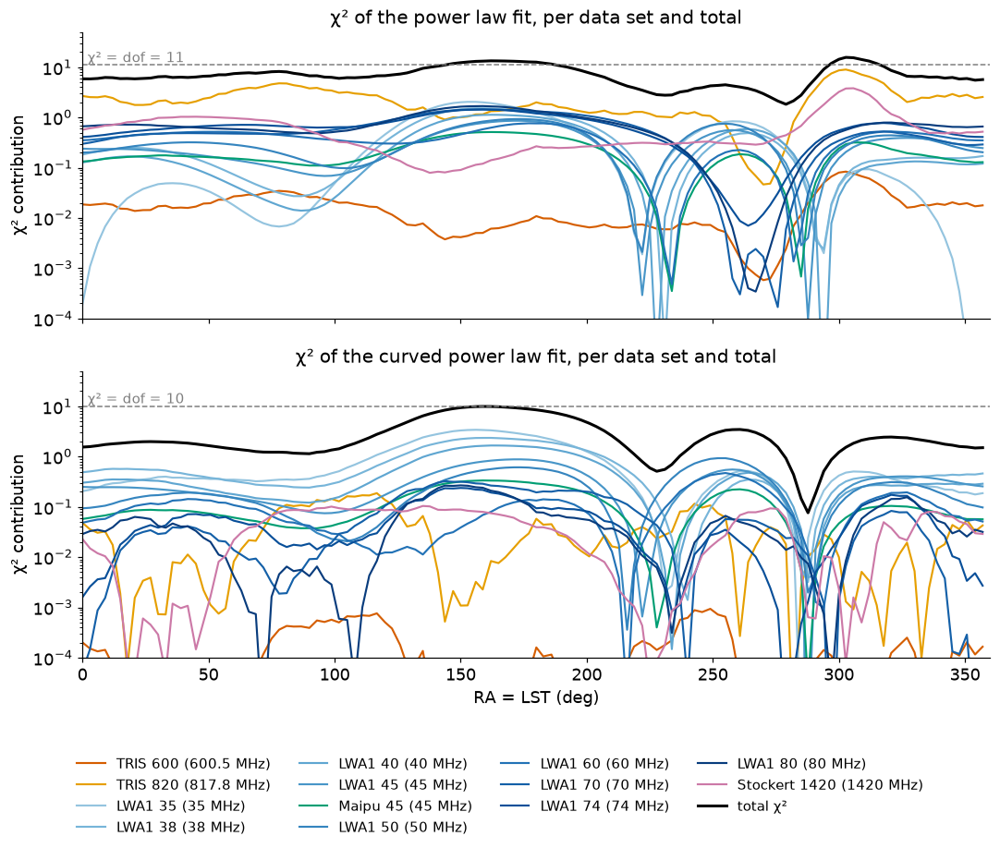

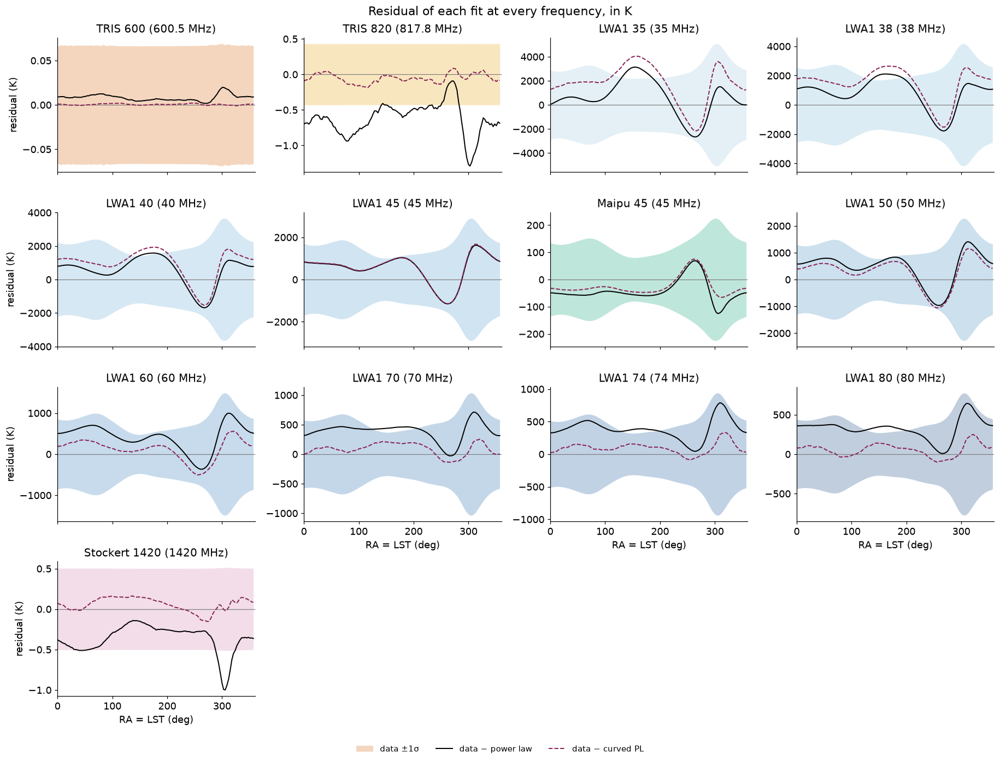

,model,data set,frequency (MHz),median χ²_i,mean χ²_i,max χ²_i,samples with χ²_i > 4,median residual (K),median σ (K)
0,power law,TRIS 600,600.5,0.015,0.018,0.084,0.0,0.008,0.067
1,power law,TRIS 820,817.8,1.991,2.394,8.978,15.0,-0.607,0.430
2,power law,LWA1 35,35.0,0.076,0.416,2.044,0.0,559.391,2820.455
3,power law,LWA1 38,38.0,0.184,0.386,1.522,0.0,1088.568,2450.681
4,power law,LWA1 40,40.0,0.133,0.303,1.131,0.0,781.048,2120.079
5,power law,LWA1 45,45.0,0.236,0.302,0.860,0.0,713.259,1611.933
6,power law,Maipu 45,45.0,0.164,0.204,0.513,0.0,-52.441,133.330
7,power law,LWA1 50,50.0,0.295,0.354,0.929,0.0,614.948,1250.206
8,power law,LWA1 60,60.0,0.391,0.374,0.766,0.0,476.017,827.827
9,power law,LWA1 70,70.0,0.482,0.598,1.443,0.0,426.966,568.797


In [ ]:
RES_K, CHI2_I = {}, {}
for m in FIT_MODELS:
    for k in KEYS:
        (mod,), _ = predict_tod([NU[k]], m)
        RES_K[m, k] = T_DATA[k] - mod
        CHI2_I[m, k] = (RES_K[m, k] / S_DATA[k]) ** 2

fig, ax = plt.subplots(len(FIT_MODELS), 1, figsize=(10, 4.2 * len(FIT_MODELS)), sharex=True, sharey=True, squeeze=False)
for a, m in zip(ax[:, 0], FIT_MODELS):
    F = FITS[m]
    for k in KEYS:
        a.plot(RA, CHI2_I[m, k], color=COL[k], label=f"{NAMES[k]} ({NU[k]:g} MHz)")
    a.plot(RA, F["chi2"], color=COLORS["ink"], lw=2, label="total χ²")
    a.axhline(F["dof"][0], color=HASLAM_COL, ls="--")
    a.text(2, F["dof"][0] * 1.15, f"χ² = dof = {F['dof'][0]}", color=HASLAM_COL, fontsize=10)
    a.set_yscale("log"); a.set_ylim(1e-4, 50); a.set_ylabel("χ² contribution")
    a.set_title(f"χ² of the {m} fit, per data set and total")
ax[-1, 0].set_xlabel("RA = LST (deg)"); ax[-1, 0].set_xlim(0, 360)
h_, l_ = ax[0, 0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=4, fontsize=10)
fig.tight_layout(rect=(0, 0.035 * int(np.ceil((len(KEYS) + 1) / 4)), 1, 1)); fig.savefig(OUT_DIR / "test3_chi2_per_frequency.png"); plt.show()

# residuals in K, one panel per data set (their scales differ by four orders of magnitude), both models in each
NCOL = 4
NROW = int(np.ceil(len(KEYS) / NCOL))
fig, ax = plt.subplots(NROW, NCOL, figsize=(4.2 * NCOL, 3.2 * NROW), sharex=True, squeeze=False)
for a in ax.ravel()[len(KEYS):]:
    a.set_visible(False)
for a, k in zip(ax.ravel(), KEYS):
    a.fill_between(RA, -S_DATA[k], S_DATA[k], color=COL[k], alpha=0.25, lw=0, label="data ±1σ")
    a.axhline(0, color=HASLAM_COL)
    for m in FIT_MODELS:
        a.plot(RA, RES_K[m, k], color=MCOL[m], ls=MLS[m], label=f"data − {SHORT[m]}")
    a.set_title(f"{NAMES[k]} ({NU[k]:g} MHz)"); a.set_xlim(0, 360)
for a in ax[:, 0]:
    a.set_ylabel("residual (K)")
for j, a in enumerate(ax.ravel()[:len(KEYS)]):
    if j + NCOL >= len(KEYS):                     # the lowest visible panel in its column
        a.set_xlabel("RA = LST (deg)"); a.tick_params(labelbottom=True)
h_, l_ = ax[0, 0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=3, fontsize=10)
fig.suptitle("Residual of each fit at every frequency, in K")
fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(OUT_DIR / "test3_residuals_K_all_frequencies.png"); plt.show()

rows = []
for m in FIT_MODELS:
    F = FITS[m]
    for k in KEYS:
        rows.append({"model": m, "data set": NAMES[k], "frequency (MHz)": NU[k],
                     "median χ²_i": np.nanmedian(CHI2_I[m, k]), "mean χ²_i": np.nanmean(CHI2_I[m, k]),
                     "max χ²_i": np.nanmax(CHI2_I[m, k]), "samples with χ²_i > 4": int(np.sum(CHI2_I[m, k] > 4)),
                     "median residual (K)": np.nanmedian(RES_K[m, k]), "median σ (K)": np.nanmedian(S_DATA[k])})
    rows.append({"model": m, "data set": f"total (dof {F['dof'][0]})", "frequency (MHz)": np.nan,
                 "median χ²_i": np.median(F["chi2"]), "mean χ²_i": np.mean(F["chi2"]), "max χ²_i": np.max(F["chi2"]),
                 "samples with χ²_i > 4": np.nan})
chi2_tab = pd.DataFrame(rows)
chi2_tab.to_csv(OUT_DIR / "test3_chi2_per_frequency.csv", index=False)
per_sample = {"ra_deg": RA}
for m in FIT_MODELS:
    per_sample[f"chi2_total {SHORT[m]}"] = FITS[m]["chi2"]
    for k in KEYS:
        per_sample[f"chi2 {NAMES[k]} {SHORT[m]}"] = CHI2_I[m, k]
        per_sample[f"residual_K {NAMES[k]} {SHORT[m]}"] = RES_K[m, k]
pd.DataFrame(per_sample).to_csv(OUT_DIR / "test3_chi2_per_sample.csv", index=False)
chi2_tab.round(3)

### Test 4 — Held-out check at 408 MHz (Haslam)
Haslam is not in the fits, so this is a true prediction: each model's predicted ring TOD at 408 MHz against Haslam's
beam-matched ring TOD (both RJ, CMB removed). Residual = Haslam − prediction, in K, with Haslam's published 1σ (10%
scale ⊕ 3 K zero level) shaded. Haslam's own calibration is what this project questions, so a residual here is not
necessarily a failure of a fit.

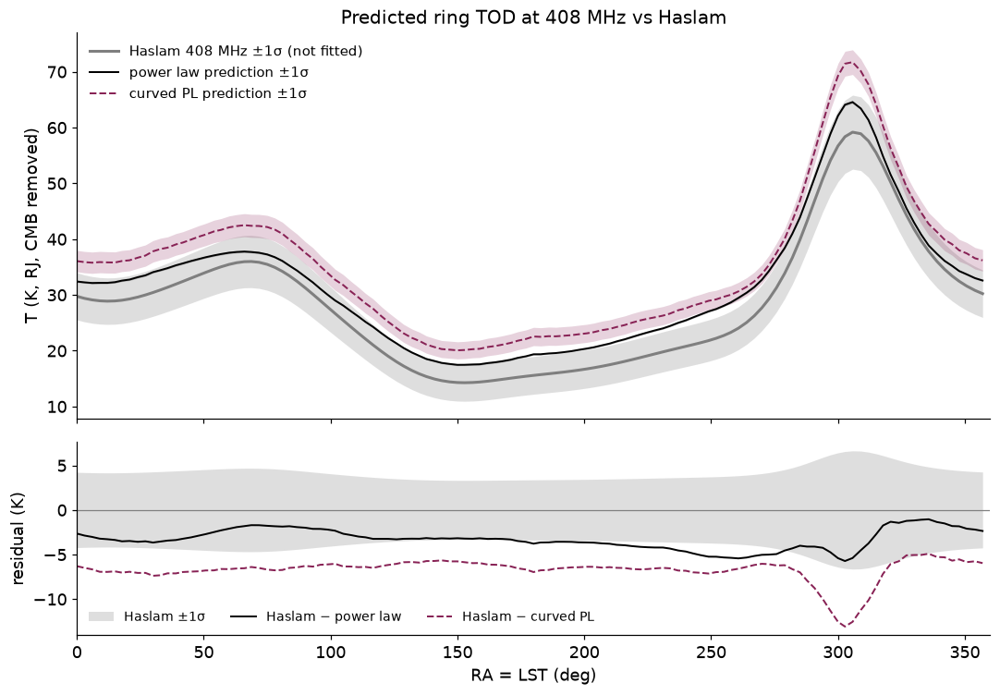

,model,median Haslam − prediction (K),mean (K),rms (K),median σ prediction (K),median σ Haslam (K)
0,power law,-3.252,-3.307,3.494,0.170,4.167
1,curved power law,-6.506,-6.747,6.883,1.892,4.167


In [ ]:
h, hs = HASLAM["T"], HASLAM["S"]
fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax[0].fill_between(RA, h - hs, h + hs, color=HASLAM_COL, alpha=0.25, lw=0)
ax[0].plot(RA, h, color=HASLAM_COL, lw=2, label="Haslam 408 MHz ±1σ (not fitted)")
ax[1].fill_between(RA, -hs, hs, color=HASLAM_COL, alpha=0.25, lw=0, label="Haslam ±1σ")
ax[1].axhline(0, color=HASLAM_COL)
rows = []
for m in FIT_MODELS:
    (p408,), (s408,) = predict_tod([HASLAM["nu"]], m)
    ax[0].fill_between(RA, p408 - s408, p408 + s408, color=MCOL[m], alpha=0.2, lw=0)
    ax[0].plot(RA, p408, color=MCOL[m], ls=MLS[m], label=f"{SHORT[m]} prediction ±1σ")
    ax[1].plot(RA, h - p408, color=MCOL[m], ls=MLS[m], label=f"Haslam − {SHORT[m]}")
    r = h - p408
    rows.append({"model": m, "median Haslam − prediction (K)": np.nanmedian(r), "mean (K)": np.nanmean(r),
                 "rms (K)": np.sqrt(np.nanmean(r ** 2)), "median σ prediction (K)": np.nanmedian(s408),
                 "median σ Haslam (K)": np.nanmedian(hs)})
ax[0].set_ylabel("T (K, RJ, CMB removed)"); ax[0].legend(fontsize=10)
ax[0].set_title("Predicted ring TOD at 408 MHz vs Haslam")
ax[1].set_ylabel("residual (K)"); ax[1].set_xlabel("RA = LST (deg)"); ax[1].set_xlim(0, 360)
ax[1].legend(fontsize=9, ncol=3)
fig.tight_layout(); fig.savefig(OUT_DIR / "test4_haslam_408_heldout.png"); plt.show()
pd.DataFrame(rows).round(3)

### Test 5 — Predicted ring TODs at other frequencies
Top row: each model's ring TOD at every frequency in `PRED_FREQS_MHZ` (1σ bands are drawn but are ~1% of T, so thin on
a log axis). Bottom left: the full spectrum at a few ring samples with the fitted points (and Haslam, not fitted).
Bottom right: the difference between the two models' predictions, curved PL − power law, in K, against frequency, with
each sample's 1σ of the first model shaded; the y axis is linear within ±1 K and logarithmic beyond — where the choice of model matters for a prediction. Saved per model to
`paper_outputs/tod_prediction/predicted_tods_<model>.csv` (fit convention, CMB removed) and `predicted_tods_with_cmb_<model>.csv`.

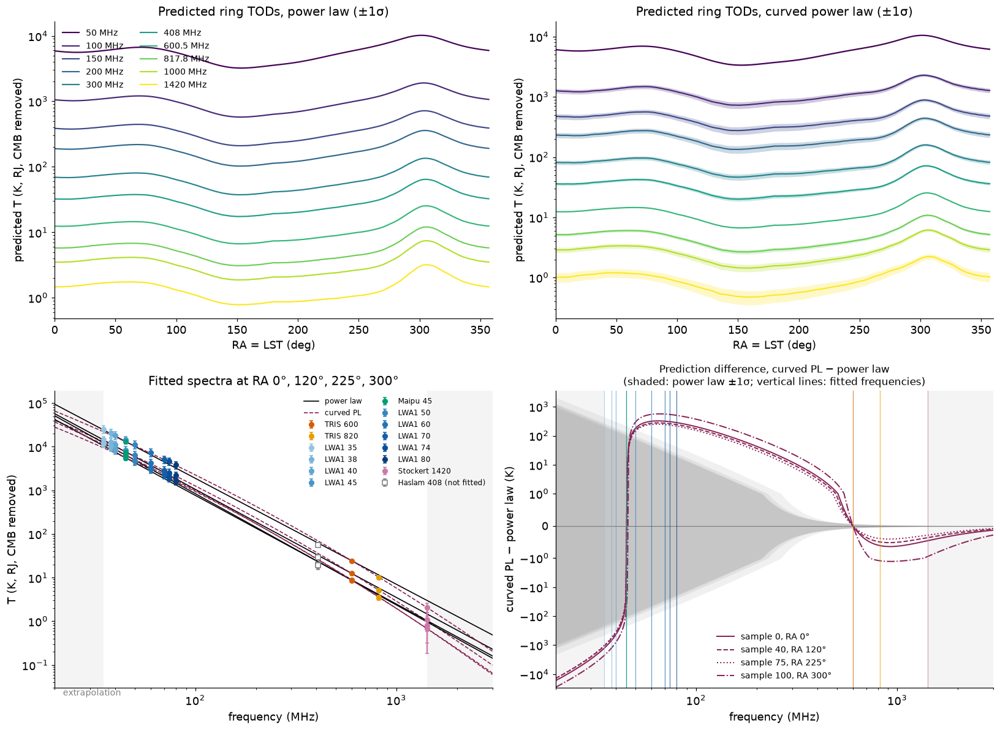

,frequency (MHz),median T power law (K),median σ power law (K),median T curved PL (K),median σ curved PL (K),median curved PL − power law (K)
0,50.0,5807.4060,95.8772,6001.2271,135.0093,167.4943
1,100.0,1042.8712,12.5371,1228.5734,107.9310,189.9842
2,150.0,381.7696,3.6515,462.3146,47.6012,83.4247
3,200.0,187.0041,1.4887,227.6008,22.8938,40.3214
4,300.0,68.6858,0.4182,80.6010,6.5545,11.7562
5,408.0,32.1498,0.1696,35.5457,1.8917,3.4741
6,600.5,12.3434,0.0665,12.3522,0.0666,0.0076
7,817.8,5.7064,0.0363,5.1603,0.2828,-0.5815
8,1000.0,3.4281,0.0250,2.8803,0.2799,-0.5971
9,1420.0,1.4190,0.0130,1.0168,0.1859,-0.4268


In [ ]:
PRED = {}
for m in FIT_MODELS:
    Tp, Sp = predict_tod(PRED_FREQS_MHZ, m)
    Tc, _ = predict_tod(PRED_FREQS_MHZ, m, include_cmb=True)
    PRED[m] = (Tp, Sp)
    for T_, name in ((Tp, "predicted_tods"), (Tc, "predicted_tods_with_cmb")):
        out = {"sample": np.arange(N_SAMP), "ra_deg": RA}
        for f, t, s in zip(PRED_FREQS_MHZ, T_, Sp):
            out[f"T_K_{f:g}MHz"], out[f"sigma_K_{f:g}MHz"] = t, s
        pd.DataFrame(out).to_csv(OUT_DIR / f"{name}_{slug(m)}.csv", index=False)

cmap = plt.get_cmap("ring")
fig = plt.figure(figsize=(15, 11))
gs = fig.add_gridspec(2, 2)
for c, m in enumerate(FIT_MODELS[:2]):
    a = fig.add_subplot(gs[0, c])
    Tp, Sp = PRED[m]
    for i, (f, t, s) in enumerate(zip(PRED_FREQS_MHZ, Tp, Sp)):
        col = cmap(i / max(len(PRED_FREQS_MHZ) - 1, 1))
        a.fill_between(RA, t - s, t + s, color=col, alpha=0.25, lw=0)
        a.plot(RA, t, color=col, label=f"{f:g} MHz")
    a.set_yscale("log"); a.set_xlim(0, 360); a.set_xlabel("RA = LST (deg)")
    a.set_ylabel("predicted T (K, RJ, CMB removed)"); a.set_title(f"Predicted ring TODs, {m} (±1σ)")
    if c == 0:
        a.legend(fontsize=9, ncol=2, loc="upper left")

nu_grid = np.geomspace(20, 3000, 300)
a = fig.add_subplot(gs[1, 0])
G = {m: predict_tod(nu_grid, m) for m in FIT_MODELS}
for j, i in enumerate(SPECTRUM_SAMPLES):
    for m in FIT_MODELS:
        a.plot(nu_grid, G[m][0][:, i], color=MCOL[m], ls=MLS[m],
               label=SHORT[m] if j == 0 else None)
    for k in KEYS:
        a.errorbar(NU[k], T_DATA[k][i], yerr=S_DATA[k][i], fmt="o", ms=5, color=COL[k], capsize=2,
                   label=NAMES[k] if j == 0 else None)
    a.errorbar(HASLAM["nu"], HASLAM["T"][i], yerr=HASLAM["S"][i], fmt="s", ms=5, mfc="white",
               color=HASLAM_COL, capsize=2, label="Haslam 408 (not fitted)" if j == 0 else None)
lo, hi = min(NU.values()), max(NU.values())
a.axvspan(20, lo, color=HASLAM_COL, alpha=0.08, lw=0); a.axvspan(hi, 3000, color=HASLAM_COL, alpha=0.08, lw=0)
a.text(22, 0.02, "extrapolation", fontsize=9, color=HASLAM_COL)
a.set_xscale("log"); a.set_yscale("log"); a.set_xlim(20, 3000)
a.set_xlabel("frequency (MHz)"); a.set_ylabel("T (K, RJ, CMB removed)")
a.set_title("Fitted spectra at RA " + ", ".join(f"{RA[i]:.0f}°" for i in SPECTRUM_SAMPLES)); a.legend(fontsize=8, ncol=2)

if len(FIT_MODELS) >= 2:
    m0, m1 = FIT_MODELS[0], FIT_MODELS[1]
    a = fig.add_subplot(gs[1, 1])
    ls = ["-", "--", ":", "-."]
    for j, i in enumerate(SPECTRUM_SAMPLES):
        a.fill_between(nu_grid, -G[m0][1][:, i], G[m0][1][:, i], color=MCOL[m0], alpha=0.06, lw=0)
        a.plot(nu_grid, G[m1][0][:, i] - G[m0][0][:, i], color=MCOL[m1], ls=ls[j % 4],
               label=f"sample {i}, RA {RA[i]:.0f}°")
    a.axhline(0, color=HASLAM_COL)
    a.axvspan(20, lo, color=HASLAM_COL, alpha=0.08, lw=0); a.axvspan(hi, 3000, color=HASLAM_COL, alpha=0.08, lw=0)
    for k in KEYS:
        a.axvline(NU[k], color=COL[k], alpha=0.7)
    a.set_xscale("log"); a.set_yscale("symlog", linthresh=1.0); a.set_xlim(20, 3000)
    a.set_xlabel("frequency (MHz)"); a.set_ylabel(f"{SHORT[m1]} − {SHORT[m0]} (K)")
    a.set_title(f"Prediction difference, {SHORT[m1]} − {SHORT[m0]}\n(shaded: {SHORT[m0]} ±1σ; vertical lines: fitted frequencies)", fontsize=11)
    a.legend(fontsize=9)
fig.tight_layout(); fig.savefig(OUT_DIR / "test5_predicted_tods.png"); plt.show()

rows = []
for i, f in enumerate(PRED_FREQS_MHZ):
    row = {"frequency (MHz)": f}
    for m in FIT_MODELS:
        Tp, Sp = PRED[m]
        row[f"median T {SHORT[m]} (K)"] = np.median(Tp[i]); row[f"median σ {SHORT[m]} (K)"] = np.median(Sp[i])
    if len(FIT_MODELS) >= 2:
        row[f"median {SHORT[FIT_MODELS[1]]} − {SHORT[FIT_MODELS[0]]} (K)"] = np.median(PRED[FIT_MODELS[1]][0][i] - PRED[FIT_MODELS[0]][0][i])
    rows.append(row)
pd.DataFrame(rows).round(4)

### Test 6 — moved to the pipeline (step 7)

The RHINO prediction (60–80 MHz, through the TRIS beam, deconvolved with a GSM2016 prior and observed with the RHINO
beam at Jodrell Bank, against the sky models) is pipeline step 7: `python run_pipeline.py --step rhino`
(code in `moonrunes.pipeline.step_rhino`, settings in `configs/run_pipeline.yaml` → `pipeline.rhino`). It is fed by
**our spectral model** (step 5: the model chosen in step 4, fitted with UltraNest to every allowed data set,
TRIS included) rather than this Part's 13-point weighted-least-squares fit, so its numbers differ from this Part's
older Test 6 results (`test_outputs/tod_prediction/test6_*`, 2026-11-05). The pipeline writes
`paper_outputs/pipeline/step7_rhino/`; the older Test 6 cells are archived in
`../moonrunes_archive_2026-11-16/notebooks/test_results.ipynb.before_pipeline`.

### Using the prediction
```python
T, sigma = predict_tod([150.0, 350.0], "power law")                   # (2, 120): RJ K, CMB removed, ±1σ
T, sigma = predict_tod([150.0], "curved power law", include_cmb=True) # + T_CMB,RJ(150 MHz), as in the TRIS ring data
fit_other = fit_ring("power law", keys=["TRIS_600", "TRIS_820", "LWA_80MHz.fits", "STOCKERT_VILLA_1400MHZ.fits"])
T, sigma = predict_tod([150.0], "power law", fit=fit_other)           # a fit with fewer data sets (each must be in DATASETS)
```
Column j of `T` and `sigma` is ring sample j; its RA = LST (deg) is `RA[j]`. "samples with χ²_i > 4" is left empty for
the totals.

# Part K — Beam tests

How the TRIS beam is described and applied, and how much it matters: K1 checks the beam widths and the smoothing
code; K2 is the beam-matching and harmonic test suite from the old diagnostics notebook; K3–K5 are the script-based
tests behind the beam paragraphs of the paper (main.tex:271–275), shown here from their saved results.

# Part K1 — Beam widths (FWHM) and the smoothing

**Origin:** `notebooks/09_beam_fwhm_tests.ipynb` (archived: `../moonrunes_archive_2026-11-16/notebooks/09_beam_fwhm_tests.ipynb`)

| | |
|---|---|
| **Reads** | `configs/run_pipeline.yaml`, limTOD's TRIS beam |
| **Writes** | nothing |
| **Feeds the paper** | the 19.155° × 23.366° beam used everywhere (fig2, `tab:surveys`) |

**Stored outputs** are from the original notebook (not re-run after the merge).


## Testing the beam widths (FWHM) and the smoothing

The project leans on two numbers: the TRIS beam's half-power widths, **19.155° (E plane)**
and **23.366° (H plane)**. The larger one is stage 2's smoothing target
(`beam_matching.target_fwhm_deg`). This notebook checks that the code producing and using
them is right, before anything else is tested.

| function | where | what it does |
|---|---|---|
| `TRISPrincipalPlaneCuts.half_power_full_width_deg()` | `limTOD/tris/archive.py` | FWHM of the E and H cuts, where each crosses −3.0103 dB |
| `approximate_tris_gaussian_beam_map()` | `limTOD/tris/beam.py` | elliptical Gaussian beam from (FWHM_E, FWHM_H) |
| `tris_cut_beam_response()` / `tris_cut_beam_map()` | `limTOD/tris/beam.py` | the archive-cut beam: E and H cuts blended with cos²φ / sin²φ |
| `extra_fwhm_deg()` / `smooth_to_target()` | `moonrunes/stage2_beam_matching.py` | the quadrature kernel and the smoothing |

**What is checked**

1. The σ ↔ FWHM constant: FWHM = 2√(2 ln 2) σ = 2.35482 σ.
2. An elliptical Gaussian built from σ_E, σ_H gives back 19.155° and 23.366° from the FWHM function.
3. Degree/radian slips and σ-vs-FWHM mix-ups, the usual culprits: what each would produce,
   and a check that none is happening.
4. The archive-cut beam: its FWHM measured numerically from the E and H cuts.
5. The cut beam at φ = 0 is the E cut and at φ = 90° is the H cut.
6. **Test 2, a round trip:** build an elliptical Gaussian beam *map* with FWHM 19.155° /
   23.366°, read its E and H cuts back off the map, run them through the FWHM function,
   and require the two numbers back to 0.1%. This is repeated at every nside from 16 to
   1024, because the pipeline builds its beam at nside 16.

Every check ends in an `assert`, so the notebook fails loudly if anything breaks. The same
checks run under pytest in `tests/test_beam_fwhm.py`.

In [ ]:
%matplotlib inline
import sys
from pathlib import Path
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
from moonrunes.style import use_tris_style, COLORS
use_tris_style()
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white"})

from moonrunes.config import load_config
from moonrunes.stage1_tris_maps import import_limtod_tris
from moonrunes.stage2_beam_matching import extra_fwhm_deg, smooth_to_target

config = load_config(REPO / "configs" / "run_pipeline.yaml")
tris = import_limtod_tris(config)
CUTS = tris.read_tris_beam_cuts(config.resolve_path("paths.tris_archive_dir") / "TRIS_Beam_Profile.txt")

FWHM_E, FWHM_H = 19.155, 23.366          # the expected values (degrees)
HALF_DB = -10 * np.log10(2)              # half power in dB: -3.0103
RESULTS = []                             # (check, value, expected, pass) for the summary

def record(check, value, expected, ok):
    RESULTS.append((check, value, expected, bool(ok)))
    print(f"{'PASS' if ok else 'FAIL'}  {check}: {value}  (expected {expected})")
    assert ok, check

def fwhm_from_profile(theta_deg, response):
    # FWHM of a peak-normalised profile sampled from the centre outwards: twice the angle
    # where it first falls to half, by linear interpolation between the two bracketing samples.
    r = np.asarray(response) / response[0]
    i = int(np.argmax(r < 0.5))
    t0, t1, r0, r1 = theta_deg[i - 1], theta_deg[i], r[i - 1], r[i]
    return 2 * (t0 + (0.5 - r0) / (r1 - r0) * (t1 - t0))

print(f"archive cuts: {CUTS.angle_deg.size} angles, {CUTS.angle_deg.min():.0f}–{CUTS.angle_deg.max():.0f}°, "
      f"spacing {np.unique(np.diff(CUTS.angle_deg))}°")

archive cuts: 55 angles, 0–176°, spacing [1. 2. 5.]°


---
### 1. The σ ↔ FWHM constant

For a Gaussian $\exp(-\theta^2/2\sigma^2)$, half power is reached at
$\theta = \sigma\sqrt{2\ln 2}$, so

$$\mathrm{FWHM} = 2\sqrt{2\ln 2}\,\sigma \approx 2.35482\,\sigma.$$

limTOD writes the factor as `2.0 * np.sqrt(2.0 * np.log(2.0))`. Below: the constant, and
the σ of each TRIS plane.

In [ ]:
K = 2 * np.sqrt(2 * np.log(2))
print(f"2*sqrt(2 ln 2) = {K:.6f}")
record("FWHM/sigma constant", round(K, 6), 2.354820, abs(K - 2.3548200450309493) < 1e-12)
# The rounded 2.3548 costs ~1e-5 relative -- 0.0002 deg on 23 deg, irrelevant.
print(f"rounded 2.3548 vs exact: relative difference {abs(2.3548 / K - 1):.1e}")

SIGMA_E, SIGMA_H = FWHM_E / K, FWHM_H / K
print(f"sigma_E = {SIGMA_E:.4f} deg, sigma_H = {SIGMA_H:.4f} deg")
# Half power must fall exactly at FWHM/2:
for name, s, f in (("E", SIGMA_E, FWHM_E), ("H", SIGMA_H, FWHM_H)):
    v = np.exp(-0.5 * (f / 2 / s) ** 2)
    record(f"Gaussian({name}) at FWHM/2", round(v, 12), 0.5, abs(v - 0.5) < 1e-12)

2*sqrt(2 ln 2) = 2.354820
PASS  FWHM/sigma constant: 2.35482  (expected 2.35482)
rounded 2.3548 vs exact: relative difference 8.5e-06
sigma_E = 8.1344 deg, sigma_H = 9.9226 deg
PASS  Gaussian(E) at FWHM/2: 0.5  (expected 0.5)
PASS  Gaussian(H) at FWHM/2: 0.5  (expected 0.5)


---
### 2. An elliptical Gaussian through the FWHM function

Build the E and H cuts of an elliptical Gaussian from σ_E and σ_H, in dB as the archive
stores them ($10\log_{10}$ of the power), wrap them in a `TRISPrincipalPlaneCuts`, and ask
`half_power_full_width_deg()` for the widths.

* **Fine grid (0.01°):** tests the function's arithmetic alone. It must return 19.155° and
  23.366° to interpolation error (about $10^{-6}$ degrees).
* **The archive's own grid** (2° steps around the half-power point): what the function
  sees with real data. It interpolates **linearly in dB** between samples, and a Gaussian
  is a parabola in dB, so the straight line between two samples lies *below* the curve and
  crosses −3 dB early. The width comes out **too narrow** by a predictable amount.
  The test therefore computes that chord crossing independently and requires the function
  to match it exactly. The size of the bias is reported as a finding.

In [ ]:
def gaussian_cuts(angles):
    db = lambda s: 10 * np.log10(np.exp(-0.5 * (angles / s) ** 2))
    return tris.TRISPrincipalPlaneCuts(angle_deg=angles, h_plane_db=db(SIGMA_H), e_plane_db=db(SIGMA_E))

def chord_fwhm(angles, sigma):
    # Independent calculation: where the straight line between the two samples that bracket
    # half power (in dB) crosses -3.0103 dB, times two.
    db = 10 * np.log10(np.exp(-0.5 * (angles / sigma) ** 2))
    i = int(np.argmax(db < HALF_DB))
    return 2 * (angles[i - 1] + (HALF_DB - db[i - 1]) / (db[i] - db[i - 1]) * (angles[i] - angles[i - 1]))

e, h = gaussian_cuts(np.arange(0, 60, 0.01)).half_power_full_width_deg()
print(f"fine 0.01° grid: E {e:.6f}, H {h:.6f}  (errors {e - FWHM_E:+.1e}, {h - FWHM_H:+.1e} deg)")
record("Gaussian E FWHM, fine grid", round(e, 5), FWHM_E, abs(e - FWHM_E) < 1e-5)
record("Gaussian H FWHM, fine grid", round(h, 5), FWHM_H, abs(h - FWHM_H) < 1e-5)

e, h = gaussian_cuts(CUTS.angle_deg).half_power_full_width_deg()
ce, ch = chord_fwhm(CUTS.angle_deg, SIGMA_E), chord_fwhm(CUTS.angle_deg, SIGMA_H)
print(f"\narchive grid: E {e:.5f}, H {h:.5f};  independent chord calculation: E {ce:.5f}, H {ch:.5f}")
record("Gaussian E FWHM, archive grid = chord crossing", round(e, 6), round(ce, 6), abs(e - ce) < 1e-9)
record("Gaussian H FWHM, archive grid = chord crossing", round(h, 6), round(ch, 6), abs(h - ch) < 1e-9)
BIAS_E, BIAS_H = e - FWHM_E, h - FWHM_H
print(f"FINDING: on the archive's 2° grid, linear-in-dB interpolation under-reads a Gaussian's FWHM "
      f"by {BIAS_E:+.3f}° (E) and {BIAS_H:+.3f}° (H)")

# The archive cuts themselves give the two numbers the project uses.
e, h = CUTS.half_power_full_width_deg()
print(f"\narchive cuts: E {e:.4f}°, H {h:.4f}°;  config target_fwhm_deg = "
      f"{config.require('beam_matching.target_fwhm_deg')}")
record("archive E FWHM", round(e, 3), FWHM_E, abs(e - FWHM_E) < 5e-4)
record("archive H FWHM", round(h, 3), FWHM_H, abs(h - FWHM_H) < 5e-4)
record("config target = archive H", config.require("beam_matching.target_fwhm_deg"), round(h, 3),
       abs(float(config.require("beam_matching.target_fwhm_deg")) - h) < 5e-4)

# How big is that bias on the REAL cuts? Replace the straight line by a parabola through the
# three samples nearest half power (in dB). Exact for a Gaussian; for the real beam, an estimate.
def parabola_fwhm(angles, db):
    i = int(np.argmax(db < HALF_DB))
    j = slice(i - 2, i + 1) if abs(db[i - 1] - HALF_DB) < abs(db[i] - HALF_DB) else slice(i - 1, i + 2)
    a, b, c = np.polyfit(angles[j], db[j], 2)
    roots = np.roots([a, b, c - HALF_DB]).real
    return 2 * roots[(roots > angles[j][0]) & (roots < angles[j][-1])][0]
pe = parabola_fwhm(CUTS.angle_deg, CUTS.e_plane_db)
ph = parabola_fwhm(CUTS.angle_deg, CUTS.h_plane_db)
record("parabola method recovers a Gaussian exactly",
       round(parabola_fwhm(CUTS.angle_deg, 10 * np.log10(np.exp(-0.5 * (CUTS.angle_deg / SIGMA_H) ** 2))), 4),
       FWHM_H, abs(parabola_fwhm(CUTS.angle_deg, 10 * np.log10(np.exp(-0.5 * (CUTS.angle_deg / SIGMA_H) ** 2))) - FWHM_H) < 1e-3)
print(f"real cuts, parabolic interpolation: E {pe:.3f}° ({pe - FWHM_E:+.3f}), H {ph:.3f}° ({ph - FWHM_H:+.3f})")

fine 0.01° grid: E 19.154998, H 23.365998  (errors -2.0e-06, -1.8e-06 deg)
PASS  Gaussian E FWHM, fine grid: 19.155  (expected 19.155)
PASS  Gaussian H FWHM, fine grid: 23.366  (expected 23.366)

archive grid: E 19.07285, H 23.29104;  independent chord calculation: E 19.07285, H 23.29104
PASS  Gaussian E FWHM, archive grid = chord crossing: 19.072851  (expected 19.072851)
PASS  Gaussian H FWHM, archive grid = chord crossing: 23.291041  (expected 23.291041)
FINDING: on the archive's 2° grid, linear-in-dB interpolation under-reads a Gaussian's FWHM by -0.082° (E) and -0.075° (H)

archive cuts: E 19.1546°, H 23.3661°;  config target_fwhm_deg = 23.366
PASS  archive E FWHM: 19.155  (expected 19.155)
PASS  archive H FWHM: 23.366  (expected 23.366)
PASS  config target = archive H: 23.366  (expected 23.366)
PASS  parabola method recovers a Gaussian exactly: 23.366  (expected 23.366)
real cuts, parabolic interpolation: E 19.192° (+0.037), H 23.423° (+0.057)


---
### 3. Degree/radian slips and σ-vs-FWHM mix-ups

A slip of either kind changes the width by a fixed, recognisable factor:

| mistake | factor on the width | E plane would come out as |
|---|---|---|
| degrees read as radians | × 57.30 | ~1098° (no peak at all) |
| radians read as degrees | ÷ 57.30 | 0.334° |
| σ passed where FWHM is expected | ÷ 2.355 | 8.13° |
| FWHM passed where σ is expected | × 2.355 | 45.1° |
| half width (HWHM) reported as FWHM | ÷ 2 | 9.58° |

So the test is to **measure** the width of the map each function actually produces and
check it against 19.155° / 23.366°. A 0.05° tolerance is far tighter than any of the
factors above.

**3a. The Gaussian beam map.** `approximate_tris_gaussian_beam_map` takes FWHM in degrees,
converts to σ in radians, and evaluates on HEALPix (θ, φ), which are in radians. The map is
sampled at nside 512 (0.11° pixels) along the E plane (φ = 0) and the H plane (φ = 90°),
and the widths are measured from the profile.

In [ ]:
NSIDE_T = 512
theta = np.arange(0, 40, 0.02)
gmap = tris.approximate_tris_gaussian_beam_map(nside=NSIDE_T, fwhm_e_deg=FWHM_E, fwhm_h_deg=FWHM_H)

def map_profile(m, phi_deg):
    return hp.get_interp_val(m, np.radians(theta), np.full(theta.size, np.radians(phi_deg)))

ge, gh = fwhm_from_profile(theta, map_profile(gmap, 0)), fwhm_from_profile(theta, map_profile(gmap, 90))
print(f"Gaussian map, measured: E {ge:.4f}°, H {gh:.4f}°")
record("Gaussian map E width (phi=0)", round(ge, 3), FWHM_E, abs(ge - FWHM_E) < 0.05)
record("Gaussian map H width (phi=90)", round(gh, 3), FWHM_H, abs(gh - FWHM_H) < 0.05)

# The same function given sigma instead of FWHM: shows the mix-up would be caught.
wrong = tris.approximate_tris_gaussian_beam_map(nside=NSIDE_T, fwhm_e_deg=SIGMA_E, fwhm_h_deg=SIGMA_H)
we = fwhm_from_profile(theta, map_profile(wrong, 0))
print(f"if sigma were passed as FWHM: E would measure {we:.3f}° = {FWHM_E / we:.3f}x too narrow")
record("sigma-for-FWHM slip is detectable", round(we, 3), round(FWHM_E / K, 3), abs(we - FWHM_E / K) < 0.05)

Gaussian map, measured: E 19.1560°, H 23.3667°
PASS  Gaussian map E width (phi=0): 19.156  (expected 19.155)
PASS  Gaussian map H width (phi=90): 23.367  (expected 23.366)
if sigma were passed as FWHM: E would measure 8.137° = 2.354x too narrow
PASS  sigma-for-FWHM slip is detectable: 8.137  (expected 8.134)


**3b. The smoothing.** `smooth_to_target` converts the kernel FWHM from degrees with
`np.radians`, and `hp.smoothing(fwhm=...)` expects radians and FWHM, not σ. To check the
whole chain, smooth a single bright pixel (nside 128, 0.46° pixels) straight to the TRIS
target and measure the result's full width through the pixel centre, in both directions.

**What it should measure.** healpy smooths with a Gaussian in *harmonic* space,
$b_\ell = \exp[-\ell(\ell+1)\sigma^2/2]$. On a sphere that is not exactly a Gaussian in angle,
and for a 23° beam the difference is visible. The exact profile is
$\sum_\ell \frac{2\ell+1}{4\pi} b_\ell P_\ell(\cos\theta)$ (`hp.bl2beam`), and its half-power
width is **23.425°**, not 23.366°. So the reference is that exact profile.

**The quadrature chain.** Start from a map already smoothed to 5°, apply
`smooth_to_target(native=5°)`, and the result must be the same as smoothing in one step.
That holds exactly, because harmonic Gaussians multiply: $\sigma^2$ adds. It would come out
as roughly 5 + 23.35 or 23.35 alone if the quadrature were wrong.

In [ ]:
NS = 128
src = np.zeros(hp.nside2npix(NS)); pix0 = hp.ang2pix(NS, 0.0, 0.0, lonlat=True); src[pix0] = 1.0
LON0, LAT0 = hp.pix2ang(NS, pix0, lonlat=True)          # the source pixel's centre (0°, +0.30°)
half = np.arange(0, 40, 0.02)

def full_width(m):
    # Full width at half maximum through the source centre, along latitude and longitude
    # (both sides), averaged.  Measured across, not from one side, so a sub-pixel offset cancels.
    peak = float(hp.get_interp_val(m, LON0, LAT0, lonlat=True))
    widths = []
    for dlon, dlat in ((0, 1), (1, 0)):
        sides = []
        for sign in (1, -1):
            prof = hp.get_interp_val(m, LON0 + sign * dlon * half, LAT0 + sign * dlat * half, lonlat=True)
            sides.append(fwhm_from_profile(half, np.r_[peak, prof[1:]]) / 2)
        widths.append(sum(sides))
    return float(np.mean(widths))

target = float(config.require("beam_matching.target_fwhm_deg"))
exact = fwhm_from_profile(np.arange(0, 40, 0.01),
                          hp.bl2beam(hp.gauss_beam(np.radians(target), lmax=3 * NS - 1),
                                     np.radians(np.arange(0, 40, 0.01))))
w0 = full_width(smooth_to_target(src, 0.0, target))
pre = hp.smoothing(src, fwhm=np.radians(5.0), iter=3)
w5 = full_width(smooth_to_target(pre, 5.0, target))
print(f"kernel for Haslam: extra_fwhm_deg(0.9333, {target}) = {extra_fwhm_deg(0.93333, target):.4f}°")
print(f"exact spherical profile of a {target}° harmonic Gaussian: FWHM {exact:.4f}° "
      f"({exact - target:+.3f}°, {100 * (exact / target - 1):+.2f}%)")
print(f"point source -> target: measured {w0:.3f}°")
print(f"5° map -> target:       measured {w5:.3f}°")
record("smooth_to_target(point source) width", round(w0, 3), round(exact, 3), abs(w0 - exact) < 0.03)
record("quadrature chain 5° -> target", round(w5, 3), round(w0, 3), abs(w5 - w0) < 0.01)
record("extra_fwhm_deg quadrature", round(extra_fwhm_deg(3.0, 5.0), 6), 4.0, abs(extra_fwhm_deg(3.0, 5.0) - 4.0) < 1e-12)
# What a degree/radian slip in the smoothing would do: fwhm=23.366 *radians* = whole-sky, flat map.
print("a deg->rad slip would pass fwhm = 23.366 rad (1339°): the map would come out flat; "
      "a sigma-for-FWHM slip would measure ~9.9°. Neither is close to the measured value.")

kernel for Haslam: extra_fwhm_deg(0.9333, 23.366) = 23.3474°
exact spherical profile of a 23.366° harmonic Gaussian: FWHM 23.4248° (+0.059°, +0.25%)
point source -> target: measured 23.422°
5° map -> target:       measured 23.422°
PASS  smooth_to_target(point source) width: 23.422  (expected 23.425)
PASS  quadrature chain 5° -> target: 23.422  (expected 23.422)
PASS  extra_fwhm_deg quadrature: 4.0  (expected 4.0)
a deg->rad slip would pass fwhm = 23.366 rad (1339°): the map would come out flat; a sigma-for-FWHM slip would measure ~9.9°. Neither is close to the measured value.


---
### 4. The archive-cut beam: FWHM measured numerically

`half_power_full_width_deg()` finds where the tabulated dB cut crosses −3.0103 dB. Here the
width is measured independently, three more ways:

1. **Response function**: `tris_cut_beam_response` evaluated on a fine θ grid at φ = 0
   (E) and φ = 90° (H), and the half-power crossing found on that curve.
2. **HEALPix map**: `tris_cut_beam_map` at nside 512, sampled along the same two planes.
   This also checks the map's orientation, units and θ convention.
3. **Both blends** (`"db"` and `"power"`): on the principal planes they should agree,
   since a blend weight is exactly 0 or 1 there.

method                                     E [deg]   H [deg]
half_power_full_width_deg()                19.1546   23.3661
tris_cut_beam_response, db blend           19.1546   23.3661
tris_cut_beam_response, power blend        19.1546   23.3661
tris_cut_beam_map, nside 512               19.1686   23.3800
PASS  tris_cut_beam_response, db blend: E: 19.155  (expected 19.155)
PASS  tris_cut_beam_response, db blend: H: 23.366  (expected 23.366)
PASS  tris_cut_beam_response, power blend: E: 19.155  (expected 19.155)
PASS  tris_cut_beam_response, power blend: H: 23.366  (expected 23.366)
PASS  tris_cut_beam_map, nside 512: E: 19.169  (expected 19.155)
PASS  tris_cut_beam_map, nside 512: H: 23.38  (expected 23.366)


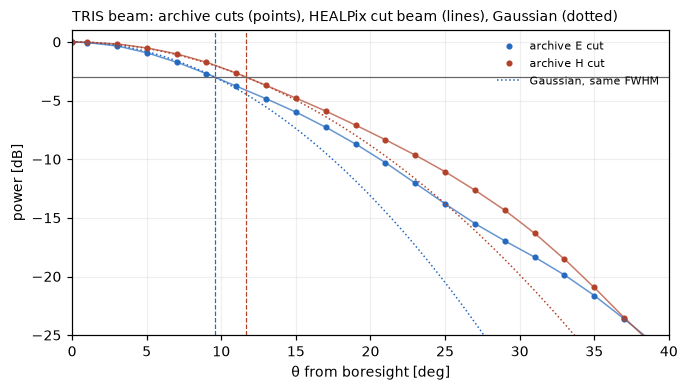

In [ ]:
ref_e, ref_h = CUTS.half_power_full_width_deg()
rows = [("half_power_full_width_deg()", ref_e, ref_h)]
for blend in ("db", "power"):
    resp = lambda phi: tris.tris_cut_beam_response(CUTS, theta, np.full(theta.size, phi), blend=blend)
    rows.append((f"tris_cut_beam_response, {blend} blend", fwhm_from_profile(theta, resp(0.0)),
                 fwhm_from_profile(theta, resp(90.0))))
cmap = tris.tris_cut_beam_map(CUTS, nside=NSIDE_T, normalization="peak")
rows.append(("tris_cut_beam_map, nside 512", fwhm_from_profile(theta, map_profile(cmap, 0)),
             fwhm_from_profile(theta, map_profile(cmap, 90))))

print(f"{'method':<40}{'E [deg]':>10}{'H [deg]':>10}")
for name, e, h in rows:
    print(f"{name:<40}{e:>10.4f}{h:>10.4f}")
for name, e, h in rows[1:]:
    record(f"{name}: E", round(e, 3), round(ref_e, 3), abs(e - ref_e) < 0.05)
    record(f"{name}: H", round(h, 3), round(ref_h, 3), abs(h - ref_h) < 0.05)

fig, ax = plt.subplots()
ax.plot(CUTS.angle_deg, CUTS.e_plane_db, "o", ms=3, color="#256abf", label="archive E cut")
ax.plot(CUTS.angle_deg, CUTS.h_plane_db, "o", ms=3, color="#b2432a", label="archive H cut")
for phi, c in ((0, "#256abf"), (90, "#b2432a")):
    ax.plot(theta, 10 * np.log10(map_profile(cmap, phi)), "-", color=c, alpha=0.7)
ax.plot(theta, 10 * np.log10(map_profile(gmap, 0)), ":", color="#256abf", label="Gaussian, same FWHM")
ax.plot(theta, 10 * np.log10(map_profile(gmap, 90)), ":", color="#b2432a")
ax.axhline(HALF_DB, color="0.4")
for w, c in ((ref_e, "#256abf"), (ref_h, "#b2432a")):
    ax.axvline(w / 2, color=c, ls="--")
ax.set_xlim(0, 40); ax.set_ylim(-25, 1)
ax.set_xlabel("θ from boresight [deg]"); ax.set_ylabel("power [dB]")
ax.set_title("TRIS beam: archive cuts (points), HEALPix cut beam (lines), Gaussian (dotted)",
             loc="left")
ax.legend(); ax.grid(alpha=0.2)
plt.show()

---
### 5. φ = 0 is the E cut, φ = 90° is the H cut

The cut beam blends the cuts with weights $\cos^2\phi$ (E) and $\sin^2\phi$ (H), with φ in
**degrees** (converted inside with `np.deg2rad`). At the archive's own angles the response
must equal $10^{\mathrm{cut}/10}$ exactly at φ = 0° and 180° (E) and φ = 90° and 270° (H).

In floating point $\cos^2(90°) \approx 3.7\times10^{-33}$ rather than 0, so the comparison
is to relative precision $10^{-12}$, not bit-for-bit. A degree/radian slip in φ would show
up here: φ = π/2 passed in radians is read as 1.57°, which is essentially the E plane, not H.

In [ ]:
A = CUTS.angle_deg
E_lin, H_lin = 10 ** (CUTS.e_plane_db / 10), 10 ** (CUTS.h_plane_db / 10)
for blend in ("db", "power"):
    for phi, ref, plane in ((0.0, E_lin, "E"), (180.0, E_lin, "E"), (90.0, H_lin, "H"), (270.0, H_lin, "H")):
        got = tris.tris_cut_beam_response(CUTS, A, np.full(A.size, phi), blend=blend)
        err = np.max(np.abs(got / ref - 1))
        record(f"{blend} blend, phi={phi:.0f} -> {plane} cut (max rel. diff {err:.1e})",
               f"{err:.1e}", "< 1e-12", err < 1e-12)

# What a radian slip in phi would do: phi = pi/2 passed where degrees are expected.
slip = tris.tris_cut_beam_response(CUTS, A, np.full(A.size, np.pi / 2))
print(f"\nif phi were given in radians (pi/2 'degrees' = 1.57°): max deviation from the H cut "
      f"{np.max(np.abs(slip / H_lin - 1)):.2f}, from the E cut {np.max(np.abs(slip / E_lin - 1)):.4f}"
      f"  -> it returns the E cut, so the slip is detectable.")

# In between, the dB blend at 45° is the dB average of the two cuts.
mid = tris.tris_cut_beam_response(CUTS, A, np.full(A.size, 45.0), blend="db")
err = np.max(np.abs(10 * np.log10(mid) - 0.5 * (CUTS.e_plane_db + CUTS.h_plane_db)))
record("db blend at phi=45 is the dB mean of E and H", f"{err:.1e} dB", "< 1e-9", err < 1e-9)

PASS  db blend, phi=0 -> E cut (max rel. diff 0.0e+00): 0.0e+00  (expected < 1e-12)
PASS  db blend, phi=180 -> E cut (max rel. diff 0.0e+00): 0.0e+00  (expected < 1e-12)
PASS  db blend, phi=90 -> H cut (max rel. diff 0.0e+00): 0.0e+00  (expected < 1e-12)
PASS  db blend, phi=270 -> H cut (max rel. diff 0.0e+00): 0.0e+00  (expected < 1e-12)
PASS  power blend, phi=0 -> E cut (max rel. diff 0.0e+00): 0.0e+00  (expected < 1e-12)
PASS  power blend, phi=180 -> E cut (max rel. diff 0.0e+00): 0.0e+00  (expected < 1e-12)
PASS  power blend, phi=90 -> H cut (max rel. diff 0.0e+00): 0.0e+00  (expected < 1e-12)
PASS  power blend, phi=270 -> H cut (max rel. diff 0.0e+00): 0.0e+00  (expected < 1e-12)

if phi were given in radians (pi/2 'degrees' = 1.57°): max deviation from the H cut 4.58, from the E cut 0.0013  -> it returns the E cut, so the slip is detectable.
PASS  db blend at phi=45 is the dB mean of E and H: 7.1e-15 dB  (expected < 1e-9)


---
### 6. Test 2 — round trip on a beam with a known answer

**Procedure**

1. Build the elliptical Gaussian beam map with `approximate_tris_gaussian_beam_map`
   (FWHM_E = 19.155°, FWHM_H = 23.366°). This is a HEALPix map, the form limTOD uses.
2. Read the E and H cuts back off the map: sample it with `hp.get_interp_val` along
   φ = 0 and φ = 90°, and convert to dB as the archive stores them.
3. Wrap the cuts in a `TRISPrincipalPlaneCuts` and run the **same** FWHM function used on
   the archive, `half_power_full_width_deg()`.
4. Compare with 19.155° and 23.366°. **Pass: |error| ≤ 0.1%** (0.019° E, 0.023° H).

**Variations**, because each one isolates a different source of error:

* **nside 16 to 1024.** The map's pixelisation is what the round trip tests. The pipeline
  builds its beam at nside 16 (`tris.nside`, `tris.nside_hires`).
* **Two cut samplings:** fine (every 0.05°), and the archive's own angles (2° steps near
  half power). The archive grid isolates the linear-in-dB interpolation bias from §2.
* **Two normalisations:** `"none"` (the analytic function, peak = 1 at boresight exactly)
  and `"peak"` (divided by the brightest *pixel*, which is what the pipeline builds). At low
  nside no pixel sits on boresight, so the brightest pixel is below 1 and `"peak"` scales
  the whole beam up, which moves the −3 dB point outwards.

The 0.1% criterion is asserted for the configuration that tests the round trip itself:
fine sampling at nside ≥ 128. Every other row is reported, not asserted, and explained below
the table.

 nside  cut sampling  norm     E [deg]       ΔE   H [deg]       ΔH   0.1%?
    16  fine 0.05°    none     19.4265  +1.417%   23.1526  -0.913%   no
    16  fine 0.05°    peak     20.1736  +5.318%   24.0908  +3.102%   no
    16  archive       none     19.2951  +0.731%   23.1268  -1.024%   no
    16  archive       peak     20.0263  +4.549%   24.0388  +2.879%   no
    32  fine 0.05°    none     19.2207  +0.343%   23.3129  -0.227%   no
    32  fine 0.05°    peak     19.4054  +1.307%   23.5410  +0.749%   no
    32  archive       none     19.1345  -0.107%   23.2484  -0.503%   no
    32  archive       peak     19.3148  +0.834%   23.4701  +0.446%   no
    64  fine 0.05°    none     19.1683  +0.070%   23.3529  -0.056%   yes
    64  fine 0.05°    peak     19.2155  +0.316%   23.4094  +0.186%   no
    64  archive       none     19.0860  -0.360%   23.2797  -0.369%   no
    64  archive       peak     19.1307  -0.127%   23.3352  -0.132%   no
   128  fine 0.05°    none     19.1586  +0.019%   23.3628  -

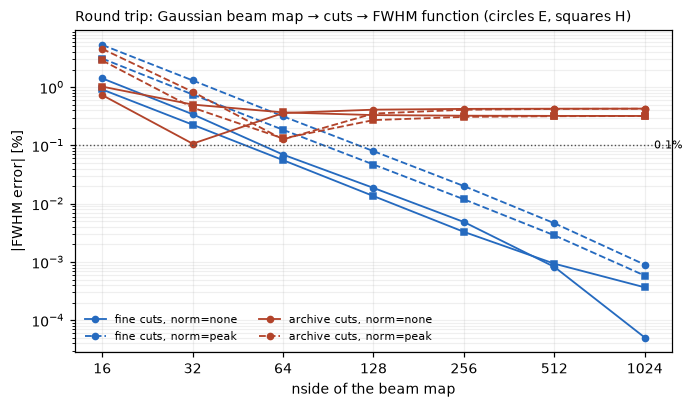

In [ ]:
TOL = 1e-3                                  # 0.1%
FINE = np.arange(0.0, 60.0, 0.05)

def round_trip(nside, angles, normalization):
    m = tris.approximate_tris_gaussian_beam_map(nside=nside, fwhm_e_deg=FWHM_E, fwhm_h_deg=FWHM_H,
                                                normalization=normalization)
    th = np.radians(angles)
    e = hp.get_interp_val(m, th, np.zeros_like(th))
    h = hp.get_interp_val(m, th, np.full_like(th, np.pi / 2))
    cuts = tris.TRISPrincipalPlaneCuts(angle_deg=angles, e_plane_db=10 * np.log10(e),
                                       h_plane_db=10 * np.log10(h))
    return cuts.half_power_full_width_deg()

RT = []
for nside in (16, 32, 64, 128, 256, 512, 1024):
    for grid, angles in (("fine 0.05°", FINE), ("archive", CUTS.angle_deg)):
        for norm in ("none", "peak"):
            e, h = round_trip(nside, angles, norm)
            RT.append(dict(nside=nside, grid=grid, norm=norm, e=e, h=h,
                           de=e / FWHM_E - 1, dh=h / FWHM_H - 1))

print(f"{'nside':>6}  {'cut sampling':<14}{'norm':<6}{'E [deg]':>10}{'ΔE':>9}{'H [deg]':>10}{'ΔH':>9}   0.1%?")
for r in RT:
    ok = abs(r["de"]) <= TOL and abs(r["dh"]) <= TOL
    print(f"{r['nside']:>6}  {r['grid']:<14}{r['norm']:<6}{r['e']:>10.4f}{100 * r['de']:>+8.3f}%"
          f"{r['h']:>10.4f}{100 * r['dh']:>+8.3f}%   {'yes' if ok else 'no'}")
print()
for r in RT:
    if r["grid"].startswith("fine") and r["nside"] >= 128:
        for plane, d, v, ref in (("E", r["de"], r["e"], FWHM_E), ("H", r["dh"], r["h"], FWHM_H)):
            record(f"round trip {plane}, nside {r['nside']}, norm {r['norm']} ({100 * d:+.3f}%)",
                   round(v, 4), ref, abs(d) <= TOL)

# The figure: |error| against nside, one line per configuration.
fig, ax = plt.subplots()
styles = {("fine 0.05°", "none"): ("#256abf", "-"), ("fine 0.05°", "peak"): ("#256abf", "--"),
          ("archive", "none"): ("#b2432a", "-"), ("archive", "peak"): ("#b2432a", "--")}
ns_list = sorted({r["nside"] for r in RT})
for (grid, norm), (c, ls) in styles.items():
    for plane, key, mk in (("E", "de", "o"), ("H", "dh", "s")):
        y = [100 * abs(next(r[key] for r in RT if r["nside"] == n and r["grid"] == grid and r["norm"] == norm))
             for n in ns_list]
        ax.plot(ns_list, y, ls, marker=mk, ms=4, color=c,
                label=f"{grid.split()[0]} cuts, norm={norm}" if plane == "E" else None)
ax.axhline(100 * TOL, color="0.3", ls=":")
ax.text(1100, 100 * TOL, "0.1%", va="center", fontsize=7.5)
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xticks(ns_list); ax.set_xticklabels(ns_list)
ax.set_xlabel("nside of the beam map"); ax.set_ylabel("|FWHM error| [%]")
ax.set_title("Round trip: Gaussian beam map → cuts → FWHM function (circles E, squares H)",
             loc="left")
ax.legend(ncol=2, loc="lower left"); ax.grid(alpha=0.2, which="both")
plt.show()

**Reading the table**

* **Pass, nside ≥ 128 with fine cut sampling:** both widths come back within 0.1%,
  converging to 0.001% at nside 1024. The FWHM function and the beam builder are
  consistent with each other.
* **Archive-grid rows, about −0.3% to −0.4% at every nside:** that is the linear-in-dB
  interpolation bias found in §2 (−0.08° E, −0.075° H). It does not shrink with nside,
  because it comes from the 2° sampling of the cuts, not from the map. The same bias is in
  the archive's own 19.155° and 23.366°.
* **nside 32 and 16 fail; nside 64 passes only with `norm = none`.** Two effects:
  * *Sampling:* a 3.7° pixel (nside 16) is a fifth of the E-plane FWHM, so reading the
    profile back by interpolating between pixel centres is only good to about 1%
    (`norm = none`: +1.4% E, −0.9% H).
  * *Peak normalisation:* at nside 16 the brightest pixel is 2.4° off boresight and holds
    about 0.95 of the true peak. Dividing by it scales the beam up by 5%, and the −3 dB
    point moves outwards: +5.3% (E) and +3.1% (H), about +1.0° and +0.7°.

**What this means for the pipeline.** The beam limTOD uses is built exactly this way, at
`tris.nside` = `tris.nside_hires` = 16, with `normalization="peak"`. limTOD then
normalises it by its sum (`normalize_beam=True`), which removes the peak scaling. So the
+5% is **not** a beam 5% too wide in the TODs. But the 3.7° sampling of a 19–23° beam
remains: the beam's shape, and how it falls between pixel centres, is only resolved to
about 1%. At nside 128 (0.46° pixels), the beam is reproduced to better than 0.1%.

---
### Summary

**No unit or σ-vs-FWHM error anywhere in the chain.** Every function returns the width it
is given, in degrees, with E on φ = 0 and H on φ = 90°. The σ ↔ FWHM constant is the exact
2√(2 ln 2), and the quadrature kernel and the smoothing combine as they should.

**Test 2 (round trip) passes at 0.1% for nside ≥ 128**, and fails below that (§6).

Three findings, all properties of the method rather than bugs:

1. **The 19.155° / 23.366° widths are from linear-in-dB interpolation on a 2° grid.** For a
   Gaussian that reads 0.08° narrow. Parabolic interpolation of the real cuts gives
   **19.19° (E) and 23.42° (H)**, +0.04° and +0.06°. The archive cannot settle which is
   right: it has no samples between 9° and 11° or between 11° and 13°. So the half-power
   widths carry about ±0.06° of interpolation uncertainty, 0.25% of the smoothing target.
2. **healpy's Gaussian smoothing at 23.366° has a real-space FWHM of 23.425°** (+0.25%),
   because a Gaussian in ℓ is not exactly a Gaussian in angle on the sphere at this width.
   The quadrature algebra is exact in ℓ, so stage 2 is self-consistent. If the target is
   meant to be a *real-space* 23.366°, the harmonic FWHM to request is about 23.31°.

3. **A beam map at nside 16 (the pipeline's beam grid) reproduces the Gaussian only to
   about 1%**, and its peak normalisation is off by 5% (removed again by limTOD's sum
   normalisation). At nside 128 the round trip is good to 0.08%, and at 512 to 0.005%.

Findings 1 and 2 shift the smoothed maps' effective beam by about 0.06°. That is negligible next to the
fact that the true TRIS beam is not Gaussian at all (figure in §4: it is much wider in the
shoulders below −10 dB), which no Gaussian smoothing kernel can match.

In [ ]:
n_pass = sum(r[3] for r in RESULTS)
print(f"{n_pass}/{len(RESULTS)} checks passed\n")
for check, value, expected, ok in RESULTS:
    print(f"  {'PASS' if ok else 'FAIL'}  {check}")

48/48 checks passed

  PASS  FWHM/sigma constant
  PASS  Gaussian(E) at FWHM/2
  PASS  Gaussian(H) at FWHM/2
  PASS  Gaussian E FWHM, fine grid
  PASS  Gaussian H FWHM, fine grid
  PASS  Gaussian E FWHM, archive grid = chord crossing
  PASS  Gaussian H FWHM, archive grid = chord crossing
  PASS  archive E FWHM
  PASS  archive H FWHM
  PASS  config target = archive H
  PASS  parabola method recovers a Gaussian exactly
  PASS  Gaussian map E width (phi=0)
  PASS  Gaussian map H width (phi=90)
  PASS  sigma-for-FWHM slip is detectable
  PASS  smooth_to_target(point source) width
  PASS  quadrature chain 5° -> target
  PASS  extra_fwhm_deg quadrature
  PASS  tris_cut_beam_response, db blend: E
  PASS  tris_cut_beam_response, db blend: H
  PASS  tris_cut_beam_response, power blend: E
  PASS  tris_cut_beam_response, power blend: H
  PASS  tris_cut_beam_map, nside 512: E
  PASS  tris_cut_beam_map, nside 512: H
  PASS  db blend, phi=0 -> E cut (max rel. diff 0.0e+00)
  PASS  db blend, phi=180 

# Part K2 — Beam matching, harmonic checks and beam-specification variants

**Origin:** `notebooks/03_diagnostics.ipynb`, cells 39–114 (archived: `../moonrunes_archive_2026-11-16/notebooks/03_diagnostics.ipynb`); its cells 0–38 are `diagnostics.ipynb` Part C

| | |
|---|---|
| **Reads** | `outputs/stage1/`, `res/`, `configs/run_pipeline.yaml`, `paper_outputs/pipeline/step5_fit/``fits/` (beam-variant section) |
| **Writes** | `test_outputs/beam_variants/` (Tables 3–4, JSON, NPZ) |
| **Feeds the paper** | nothing directly |

**Stored outputs** are from the original notebook (not re-run after the merge). The next code cell is a copy of `03_diagnostics.ipynb` cell 1 (its setup), so this Part can run on its own; every name these sections take from earlier cells is defined there (checked statically, 2026-11-16). It has no stored output. The original ran on the `21cmfast` kernel.

**Pipeline:** the beam-variant section reads the TRIS rings from pipeline step 5's fit files.

In [ ]:
%matplotlib inline
import os
os.environ["TQDM_DISABLE"] = "1"

import sys
import warnings
from pathlib import Path

import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
from scipy.stats import norm

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))

warnings.filterwarnings("ignore", category=UserWarning)
from moonrunes.style import use_tris_style, COLORS
use_tris_style()
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white"})

from moonrunes.config import load_config
from moonrunes.stage1_tris_maps import load_stage1, import_limtod_tris

config = load_config(REPO / "configs" / "run_pipeline.yaml")
tris = import_limtod_tris(config)
BORESIGHT_DEC = tris.TRIS_SITE_LATITUDE_DEG
# The default product is the nside 8 run.  outputs/stage1/ holds an older
# nside 16 solve, so load the nside 8 products explicitly.
DEFAULT_RUN = REPO / "outputs" / "stage1"
products = load_stage1(config,
                       maps_path=DEFAULT_RUN / "tris_maps_tris_haslam_v0.npz",
                       manifest_path=DEFAULT_RUN / "stage1_manifest.json")
manifest = products.manifest

# The archive's own per-sample statistical errors, which are what the solver
# weights by. The config floor replaces ONLY the single row published as
# 0.000 K; the other 119 samples keep their published value.
ARCHIVE = config.resolve_path("paths.tris_archive_dir")
_RING_FILE = {600: "TRIS_absolute_600.txt", 820: "TRIS_absolute_820.txt"}
STAT_ERR = {f: np.asarray(tris.read_tris_ring(ARCHIVE / fn).statistical_uncertainty_k,
                          dtype=float)
            for f, fn in _RING_FILE.items()}

FREQS = [int(f) for f in products.frequencies_mhz]
NSIDE = products.nside
NPIX_BAND = products.pixel_indices.size

print("maps     ", products.maps_path)
print("manifest ", products.manifest_path)
print("written  ", manifest["written_utc"])
print()
print(f"run '{manifest['run_name']}': {FREQS} MHz, nside {NSIDE}, "
      f"{NPIX_BAND} pixels in the band, "
      f"{products['data_k'].shape[1]} samples per ring")
print(f"mapmaker {manifest['config_used']['tris']['mapmaker']}, "
      f"solver {manifest['config_used']['tris']['solver']['method']}, "
      f"prior {manifest['config_used']['tris']['prior']['template']}")

---
## The elliptical beam for the map route

> **Note (2026-10-14):** the config uses `beam_matching.kernel: circular_gaussian`, the kernel of the current stage 2 product. "Default" below means the elliptical `tris_cuts` kernel's status when this section ran; the elliptical kernels are implemented and tested but not in use.

Stage 2 and the map route smooth every survey to the TRIS beam, so that each point of a
per-pixel SED is seen through the same beam. Until 2026-10-13 that beam was a **circular
Gaussian of 23.366°**, the larger TRIS axis, because `hp.smoothing` can only apply a kernel
that is the same in every direction. TRIS's beam is not: **19.155° wide in its E plane and
23.366° in its H plane**, with non-Gaussian shoulders. So every matched map was 22% too
wide along E.

`beam_matching.kernel` chooses the shape (`moonrunes/elliptical_beam.py` has the full
derivation):

| kernel | shape | widths | orientation |
|---|---|---|---|
| `circular_gaussian` | Gaussian, the old way (`hp.smoothing`) | 23.366° in every direction | — |
| `elliptical_gaussian` | Gaussian | 19.155° (E) × 23.366° (H) | E plane 7° east of north |
| **`tris_cuts`** (default) | **the measured beam**: archive E and H cuts, blended with cos²φ / sin²φ — the beam limTOD uses for the TOD route | 19.155° × 23.366°, plus the real shoulders | E plane 7° east of north |

#### How the elliptical smoothing works, in four steps

1. **Orientation.** TRIS points at the zenith. Its E plane lies along the meridian, rolled
   7° east (`TRIS_Beam_Profile.txt`, the ring headers, limTOD's
   `TRIS_E_PLANE_EAST_OF_MERIDIAN_DEG`). At the zenith the meridian is the hour circle, so
   on the equatorial sky **E runs north–south (position angle +7°) and H east–west (+97°)**.
   The same orientation is used at every declination.
2. **The kernel at each output point $p$.** For every input pixel $q$: the separation
   $\theta$ and the position angle $\psi$ of $q$ seen from $p$ (north = 0°, east = 90°).
   The weight is the beam $B(\theta, \phi)$ with $\phi = \psi - 7°$. It is zero beyond 90°,
   where the horn sees ground (limTOD's horizon cut).
3. **Normalised convolution**, exactly as for the circular kernel (`PIPELINE.md` A.6):
   $$T_s(p) = \frac{\sum_q K(p,q)\,M(q)\,T(q)}{\sum_q K(p,q)\,M(q)}, \qquad
     w(p) = \frac{\sum_q K(p,q)\,M(q)}{\sum_q K(p,q)}$$
   with $M$ the observed fraction. A pixel is kept only if it was observed **and**
   $w \ge 0.5$ at every evaluation point inside it.
4. **The survey's own beam.** The effective beam is (survey beam) ⊛ (kernel). For Gaussians
   the kernel is $\sqrt{\mathrm{target}^2 - \mathrm{native}^2}$ **per axis**. The measured
   beam has no exact equivalent, so:
   * **native beam ≤ ~1.2°** (Haslam, CHIPASS, Stockert, Rhodes): the kernel is the cut beam
     itself. That widens the E core by at most 0.2% (`max_broadening_fraction`).
   * **broader** (LWA1 35/80, Maipu, ARCADE 2): the cut beam **compressed in angle** along
     E and H to the quadrature widths (`broad_native_kernel: scaled_cuts`), or the
     elliptical Gaussian (`elliptical_gaussian`). Plot 4 measures how close each gets.

It is computed as a direct sum over a working grid (`nside_work` = 64, 0.92° pixels),
evaluated at 4 points per nside 16 pixel and averaged.

#### The plots in this section

1. **The three kernels**, as pictures on the sky.
2. **Their profiles** along the E and H planes, against the archive cuts, and how much
   weight sits in the shoulders.
3. **Which kernel each survey gets**, and why.
4. **A point source through the real smoothing code**: orientation and widths measured on
   the output, for a narrow and for a broad native beam.
5. **Haslam, old kernel vs new**: maps, the difference, and along the TRIS ring.
6. **ARCADE 2's mask edge** under both kernels.
7. **Every map in the map route**: how much the new kernel changes each one in the stripe.

**First run 2026-10-14.** Plots 5–7 smooth real maps and take a few minutes (plot 7:
every survey, twice). The reading of each plot is in the markdown after it.

In [ ]:
# Setup for this section.  Self-contained apart from `config`, `tris`, `BORESIGHT_DEC`
# and `load_stage1`, which the first cell of the notebook defines.
from dataclasses import replace
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from moonrunes import elliptical_beam as eb, frames, sky_maps
from moonrunes.stage2_beam_matching import match_to_tris_beam, observed_mask

KERNEL_NOW = str(config.require("beam_matching.kernel"))
SPEC_CUTS = eb.beam_spec_from_config(config, kernel="tris_cuts")      # reads the archive cuts
SPECS = {
    "circular Gaussian (old)": eb.with_kernel(SPEC_CUTS, "circular_gaussian"),
    "elliptical Gaussian": eb.with_kernel(SPEC_CUTS, "elliptical_gaussian"),
    "TRIS cuts (measured)": SPEC_CUTS,
}
KERNEL_KEY = {"circular Gaussian (old)": "circular_gaussian",
              "elliptical Gaussian": "elliptical_gaussian",
              "TRIS cuts (measured)": "tris_cuts"}
KCOL = {"circular Gaussian (old)": "#6b7280", "elliptical Gaussian": "#eb6834",
        "TRIS cuts (measured)": "#256abf"}
PA_E = SPEC_CUTS.e_plane_east_of_meridian_deg            # position angle of the E plane
FWHM_E, FWHM_H = SPEC_CUTS.fwhm_e_deg, SPEC_CUTS.fwhm_h_deg
HALF_DB = -10 * np.log10(2)
DIVB = plt.get_cmap("ring_div").copy()
DIVB.set_bad("#e8e8e6"); DIVB.set_under("white")
SEQB = plt.get_cmap("ring").copy()
SEQB.set_bad("#e8e8e6"); SEQB.set_under("white")

def config_with_kernel(kernel):
    # A copy of the run config with another beam_matching.kernel (nothing is written).
    c = load_config(config.path)
    c._data["beam_matching"]["kernel"] = kernel
    return c

CONFIGS = {label: config_with_kernel(KERNEL_KEY[label]) for label in SPECS}

def fwhm_from_profile(offsets, response):
    # Twice the offset where a peak-normalised profile first falls to half (as in notebook 09).
    r = np.asarray(response, dtype=float) / response[0]
    i = int(np.argmax(r < 0.5))
    return 2 * (offsets[i - 1] + (0.5 - r[i - 1]) / (r[i] - r[i - 1]) * (offsets[i] - offsets[i - 1]))

def offset_vectors(ra0, dec0, pa_deg, offsets_deg):
    # Unit vectors at angular distance `offsets_deg` from (ra0, dec0), along the great
    # circle leaving it at position angle `pa_deg` (north = 0, east = 90).  Both
    # `pa_deg` and `offsets_deg` may be arrays of the same shape.
    c = np.array(hp.ang2vec(ra0, dec0, lonlat=True))
    a, d = np.radians(ra0), np.radians(dec0)
    east = np.array([-np.sin(a), np.cos(a), 0.0])
    north = np.array([-np.sin(d) * np.cos(a), -np.sin(d) * np.sin(a), np.cos(d)])
    pa = np.radians(np.asarray(pa_deg, dtype=float)).ravel()[:, None]
    t = np.radians(np.asarray(offsets_deg, dtype=float)).ravel()[:, None]
    direction = np.sin(pa) * east + np.cos(pa) * north
    return np.cos(t) * c + np.sin(t) * direction

print(f"beam_matching.kernel in the config: {KERNEL_NOW}")
print(f"TRIS beam {FWHM_E}° (E) × {FWHM_H}° (H); E plane at position angle {PA_E:+.0f}° "
      f"(H at {PA_E + 90:+.0f}°); kernel zero beyond {SPEC_CUTS.horizon_deg:.0f}°")
print(f"working grid nside {SPEC_CUTS.nside_work} ({hp.nside2resol(SPEC_CUTS.nside_work, arcmin=True) / 60:.2f}° pixels), "
      f"{SPEC_CUTS.eval_subdivision ** 2} evaluation points per output pixel")

beam_matching.kernel in the config: circular_gaussian
TRIS beam 19.155° (E) × 23.366° (H); E plane at position angle +7° (H at +97°); kernel zero beyond 90°
working grid nside 64 (0.92° pixels), 4 evaluation points per output pixel


---
### 1. The three kernels on the sky

Each panel is the kernel around its centre, in decibels relative to its peak, on a flat
grid of **east offset** (x, increasing to the right) and **north offset** (y). The grid is
the azimuthal-equidistant projection: distance from the centre is the true angle and
direction is the true position angle, so the shapes are exact.

* **White contour: half power** (−3 dB). Its width along each axis is the FWHM.
* Grey contours: −10 and −20 dB. Dashed lines: the E plane (7° east of north) and H plane.

**What to look for.** The circular kernel is round. The other two are narrower north–south
than east–west and tilted 7° clockwise from vertical. The measured beam (right) has broader
−10 and −20 dB contours than the elliptical Gaussian: those are the shoulders, which only
the measured kernel carries.

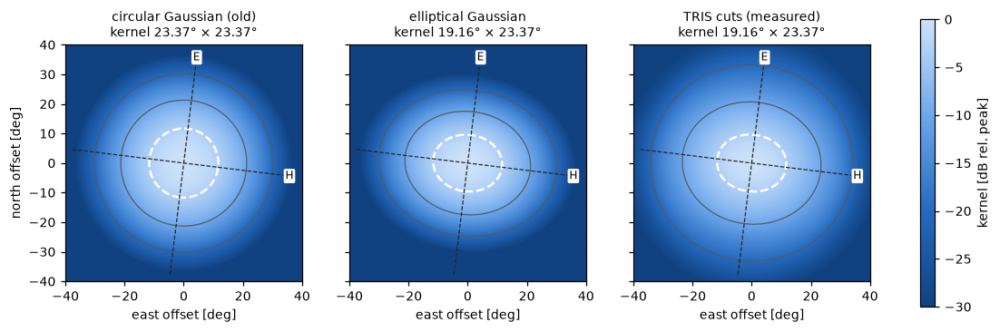

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharey=True)
for ax, (label, spec) in zip(axes, SPECS.items()):
    kernel = eb.kernel_for(spec, 0.0)                    # a point-like native beam
    x, y, resp = eb.kernel_image(kernel, spec, half_width_deg=40.0, step_deg=0.25)
    db = np.clip(10 * np.log10(np.maximum(resp, 1e-6)), -30, 0)
    im = ax.imshow(db, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()],
                   cmap=SEQB.reversed(), vmin=-30, vmax=0)
    ax.contour(x, y, db, levels=[HALF_DB], colors="white")
    ax.contour(x, y, db, levels=[-20, -10], colors="0.35", linestyles="-")
    for pa, name in ((PA_E, "E"), (PA_E + 90, "H")):
        s, c = np.sin(np.radians(pa)), np.cos(np.radians(pa))
        ax.plot([-38 * s, 38 * s], [-38 * c, 38 * c], "--", color="0.15")
        ax.text(36 * s, 36 * c, name, fontsize=8, ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
    ax.set_title(f"{label}\nkernel {kernel.fwhm_e_deg:.2f}° × {kernel.fwhm_h_deg:.2f}°")
    ax.set_xlabel("east offset [deg]")
    ax.set_aspect("equal")
axes[0].set_ylabel("north offset [deg]")
fig.colorbar(im, ax=axes, shrink=0.85, label="kernel [dB rel. peak]")
plt.show()

---
### 2. Profiles along the E and H planes

The same three kernels, cut along the **E plane** (left, position angle 7°) and the
**H plane** (middle, 97°), in dB against angle from the centre. Black dots are the archive's
own cut samples (`TRIS_Beam_Profile.txt`). The horizontal line is half power; each legend
entry gives the FWHM measured from the curve.

**Right: how much weight is in the shoulders.** The fraction of each kernel's total weight
lying beyond angle θ, on a log scale. It is integrated over the sphere: every direction,
weighted by sin θ. A circular and an elliptical Gaussian put almost nothing beyond 30°. The
measured beam puts a visible fraction there, so a bright source 30–60° away contributes to
a smoothed pixel. That is what TRIS itself sees, which is why `tris_cuts` is the default.

**What to look for.** The measured kernel (blue) follows the black dots exactly, including
the slow fall below −10 dB. The circular kernel matches the H-plane width but is too wide
on the E plane.

circular Gaussian (old)    weight beyond 30°:   0.97%   beyond 45°:  0.003%
elliptical Gaussian        weight beyond 30°:   0.47%   beyond 45°:  0.001%
TRIS cuts (measured)       weight beyond 30°:   3.44%   beyond 45°:  0.283%


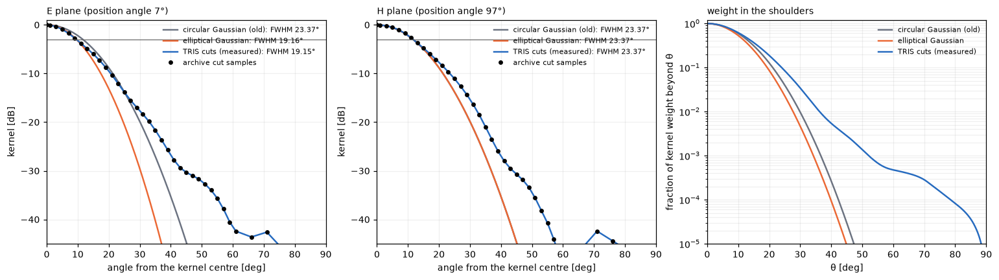

In [ ]:
theta = np.arange(0.0, 90.0, 0.05)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.0))
for ax, (pa, plane, cut_db) in zip(axes[:2], ((PA_E, "E plane", SPEC_CUTS.cut_e_db),
                                              (PA_E + 90, "H plane", SPEC_CUTS.cut_h_db))):
    for label, spec in SPECS.items():
        kernel = eb.kernel_for(spec, 0.0)
        r = eb.kernel_response(kernel, spec, theta, np.full(theta.size, pa))
        ax.plot(theta, 10 * np.log10(np.maximum(r, 1e-7)), color=KCOL[label],
                label=f"{label}: FWHM {fwhm_from_profile(theta, r):.2f}°")
    ax.plot(SPEC_CUTS.cut_angle_deg, cut_db, "o", ms=3.5, color=COLORS["ink"], label="archive cut samples")
    ax.axhline(HALF_DB, color="0.4")
    ax.set_xlim(0, 90); ax.set_ylim(-45, 1)
    ax.set_xlabel("angle from the kernel centre [deg]"); ax.set_ylabel("kernel [dB]")
    ax.set_title(f"{plane} (position angle {pa:.0f}°)", loc="left")
    ax.legend(); ax.grid(alpha=0.2)

# Fraction of the kernel's weight beyond theta (sphere: integrate over position angle with sin(theta)).
th = np.arange(0.0, 90.0, 0.1) + 0.05
pa_grid = np.arange(0.0, 360.0, 1.0)
T, P = np.meshgrid(th, pa_grid, indexing="ij")
ax = axes[2]
for label, spec in SPECS.items():
    kernel = eb.kernel_for(spec, 0.0)
    ring_weight = eb.kernel_response(kernel, spec, T, P).mean(axis=1) * np.sin(np.radians(th))
    beyond = 1.0 - np.cumsum(ring_weight) / ring_weight.sum()
    ax.semilogy(th, np.maximum(beyond, 1e-6), color=KCOL[label], label=label)
    print(f"{label:<26} weight beyond 30°: {100 * np.interp(30, th, beyond):6.2f}%   "
          f"beyond 45°: {100 * np.interp(45, th, beyond):6.3f}%")
ax.set_xlim(0, 90); ax.set_ylim(1e-5, 1.2)
ax.set_xlabel("θ [deg]"); ax.set_ylabel("fraction of kernel weight beyond θ")
ax.set_title("weight in the shoulders", loc="left")
ax.legend(); ax.grid(alpha=0.2, which="both")
plt.tight_layout(); plt.show()

**Reading plot 2 (run 2026-10-14).** On the principal planes, the measured kernel is
19.155° (E) and 23.366° (H), on the archive's own samples. The circular kernel is 23.366°
on both planes, 22% too wide on E. **Weight beyond 30°:** 3.44% for the measured beam,
against 0.97% (circular) and 0.47% (elliptical Gaussian); beyond 45°: 0.28% against
≤ 0.003%. The shoulders are a real few-percent effect, and only `tris_cuts` carries them.

---
### 3. Which kernel each survey gets

The effective beam of a smoothed map is the survey's own beam convolved with the kernel.
So the kernel must be *narrower* than TRIS by the right amount (step 4 at the top of this
section):

* **cut beam, unchanged**: the native beam is narrow enough to neglect. The expected
  effective widths are then a fraction of a percent above TRIS.
* **cut beam, compressed**: the native beam is too broad to neglect. The cut is read at
  `θ × scale`, which shrinks it to the quadrature widths √(target² − native²).

Bars: the kernel's own E (dark) and H (light) widths per survey. Dashed lines: TRIS's
19.155° and 23.366°. A shorter bar means a broader native beam, which needs less extra
smoothing.

survey                              native  kernel E  kernel H  scale E  expect E  expect H  how
LWA1 35 MHz                          4.65°    18.58°    22.90°    1.031    19.16°    23.37°  native beam too broad to neglect (2.90% on E): cut beam compressed to the quadrature core widths (approximate; exact only for Gaussian cores)
LWA1 38 MHz                          4.28°    18.67°    22.97°    1.026    19.16°    23.37°  native beam too broad to neglect (2.47% on E): cut beam compressed to the quadrature core widths (approximate; exact only for Gaussian cores)
LWA1 40 MHz                          4.07°    18.72°    23.01°    1.023    19.16°    23.37°  native beam too broad to neglect (2.23% on E): cut beam compressed to the quadrature core widths (approximate; exact only for Gaussian cores)
LWA1 45 MHz                          3.62°    18.81°    23.08°    1.018    19.16°    23.37°  native beam too broad to neglect (1.77% on E): cut beam compressed to the quadrature core widths (approxi

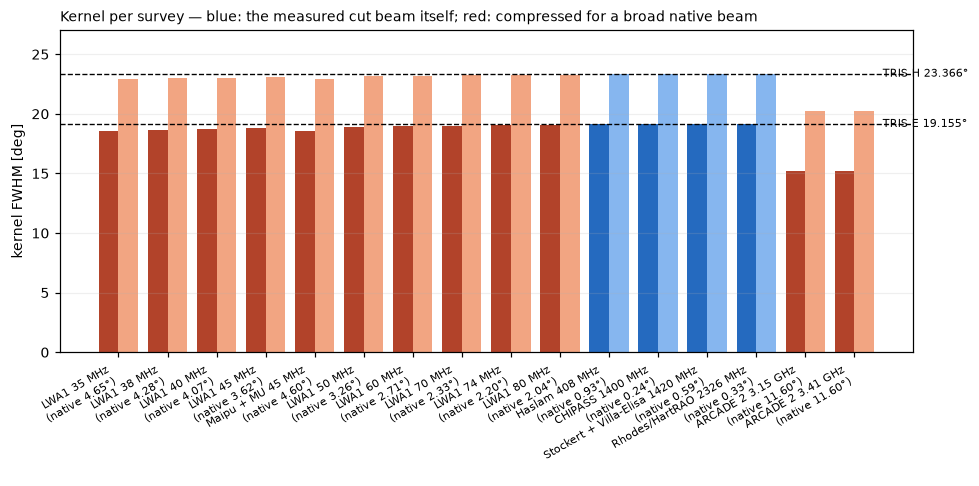

In [ ]:
ALL_MAPS = sky_maps.discover(REPO / "res")
MAPS = [m for m in ALL_MAPS if (m["usable"] and m["role"] == "fit") or m["file"] == "HASLAM.fits"]

rows = []
for m in MAPS:
    k = eb.kernel_for(SPEC_CUTS, m["fwhm_deg"])
    rows.append((m["name"], m["fwhm_deg"], k))
print(f"{'survey':<34}{'native':>8}{'kernel E':>10}{'kernel H':>10}{'scale E':>9}"
      f"{'expect E':>10}{'expect H':>10}  how")
for name, native, k in rows:
    print(f"{name:<34}{native:7.2f}°{k.fwhm_e_deg:9.2f}°{k.fwhm_h_deg:9.2f}°{k.scale_e:9.3f}"
          f"{k.expected_e_deg:9.2f}°{k.expected_h_deg:9.2f}°  {k.note}")

fig, ax = plt.subplots()
xpos = np.arange(len(rows))
ke = [k.fwhm_e_deg for _, _, k in rows]
kh = [k.fwhm_h_deg for _, _, k in rows]
compressed = [k.scale_e > 1.0 or k.shape != "tris_cuts" for _, _, k in rows]
ax.bar(xpos - 0.2, ke, width=0.4, color=["#b2432a" if c else "#256abf" for c in compressed],
       label="kernel E width")
ax.bar(xpos + 0.2, kh, width=0.4, color=["#f2a582" if c else "#86b6ef" for c in compressed],
       label="kernel H width")
ax.axhline(FWHM_E, color=COLORS["ink"], ls="--"); ax.axhline(FWHM_H, color=COLORS["ink"], ls="--")
ax.text(len(rows) - 0.5, FWHM_E, " TRIS E 19.155°", va="center", fontsize=7.5)
ax.text(len(rows) - 0.5, FWHM_H, " TRIS H 23.366°", va="center", fontsize=7.5)
ax.set_xticks(xpos)
ax.set_xticklabels([f"{n}\n(native {nat:.2f}°)" for n, nat, _ in rows], rotation=30, ha="right")
ax.set_ylabel("kernel FWHM [deg]"); ax.set_ylim(0, 27)
ax.set_title("Kernel per survey — blue: the measured cut beam itself; red: compressed for a broad native beam",
             loc="left")
ax.grid(axis="y", alpha=0.2)
plt.show()

---
### 4. A point source through the real smoothing code

Plots 1–3 show the kernel as a function. This plot runs it through
`elliptical_beam.smooth_at_positions`, the same code path the pipeline uses, so a mistake
in orientation, units or normalisation would show here and nowhere earlier.

**Top row: a narrow native beam.** One bright working-grid pixel at TRIS's own declination
(RA 180°, Dec +42.4°). Each panel is the smoothed map around it, in dB, on the same
east/north offset grid as plot 1. If the code is right it reproduces plot 1. A tilt the
other way, or E and H swapped, would be visible immediately.

**Bottom row: a broad native beam.** The same source first smoothed with a Gaussian of
ARCADE 2's 11.6° (left pair) or LWA1 35 MHz's 4.65° (right pair), then with the kernel
the pipeline chooses for that survey. Profiles along E and H against the target (the
measured beam, as for a point source):

* **scaled cuts** (the default for broad beams): the cut beam compressed to the quadrature
  widths;
* **elliptical Gaussian**: the per-axis quadrature Gaussian;
* **uncompensated**: the cut beam applied as if the native beam were negligible. This
  shows how much over-smoothing the compensation removes.

**What to look for.** In the top row, FWHMs of 19.155° / 23.366° on the E / H planes for
the two elliptical kernels, and 23.366° both ways for the circular one. In the bottom row,
how close each route lands to the target's FWHM *and* to its shoulders.

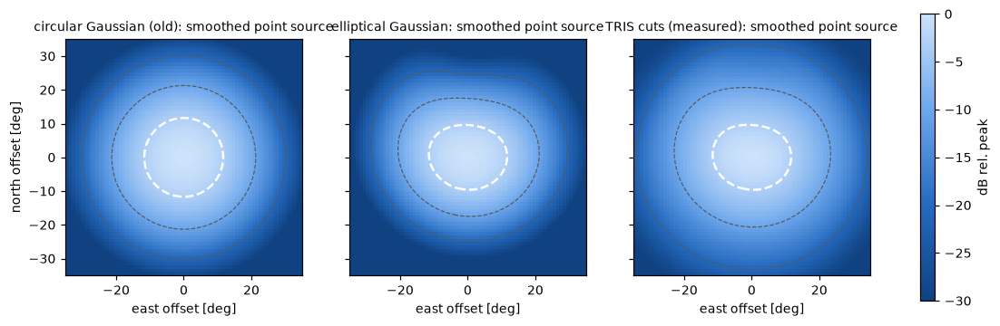

kernel                       E plane (PA 7°)  H plane (PA 97°)       north (Dec)         east (RA)


circular Gaussian (old)              23.366°           23.366°           23.366°           23.366°


elliptical Gaussian                  19.157°           23.203°           19.202°           23.348°


TRIS cuts (measured)                 19.157°           23.242°           19.211°           23.352°
expected: elliptical kernels 19.155° on E and 23.366° on H; circular 23.366° everywhere.
(The single 0.92° source pixel adds < 0.02° in quadrature.)


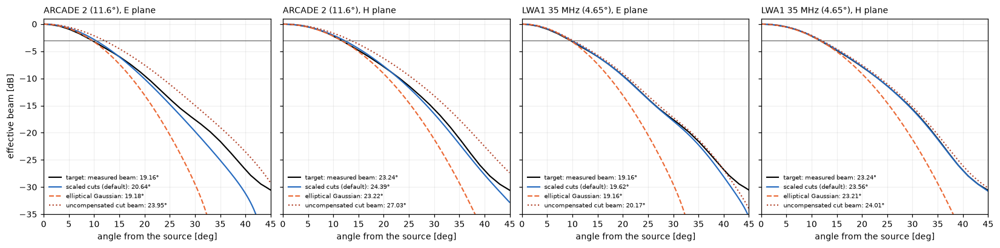

In [ ]:
NW = SPEC_CUTS.nside_work
RA0, DEC0 = 180.0, float(BORESIGHT_DEC)
src = np.zeros(hp.nside2npix(NW))
src_pix = hp.ang2pix(NW, RA0, DEC0, lonlat=True)
src[src_pix] = 1.0
RA0, DEC0 = (float(v) for v in hp.pix2ang(NW, src_pix, lonlat=True))   # the pixel's own centre
ALL_SKY = np.ones(src.size, dtype=bool)

# --- top row: the smoothed point source as an image, through the real code --------------
grid_axis = np.arange(-35.0, 35.0 + 1e-9, 1.0)
GX, GY = np.meshgrid(grid_axis, grid_axis)
img_vectors = offset_vectors(RA0, DEC0, np.degrees(np.arctan2(GX, GY)), np.hypot(GX, GY))
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharey=True)
for ax, (label, spec) in zip(axes, SPECS.items()):
    out = eb.smooth_at_positions(src, ALL_SKY, 0.0, spec, img_vectors)
    v = out["values"].reshape(GX.shape)
    db = np.clip(10 * np.log10(np.maximum(v / np.nanmax(v), 1e-6)), -30, 0)
    im = ax.imshow(db, origin="lower", extent=[grid_axis[0], grid_axis[-1], grid_axis[0], grid_axis[-1]],
                   cmap=SEQB.reversed(), vmin=-30, vmax=0)
    ax.contour(GX, GY, db, levels=[HALF_DB], colors="white")
    ax.contour(GX, GY, db, levels=[-20, -10], colors="0.35")
    ax.set_title(f"{label}: smoothed point source")
    ax.set_xlabel("east offset [deg]"); ax.set_aspect("equal")
axes[0].set_ylabel("north offset [deg]")
fig.colorbar(im, ax=axes, shrink=0.85, label="dB rel. peak")
plt.show()

# Widths measured on the smoothed output, along four directions.
offsets = np.arange(0.0, 45.0, 0.05)
directions = {"E plane (PA 7°)": PA_E, "H plane (PA 97°)": PA_E + 90,
              "north (Dec)": 0.0, "east (RA)": 90.0}
print(f"{'kernel':<26}" + "".join(f"{d:>18}" for d in directions))
for label, spec in SPECS.items():
    widths = []
    for pa in directions.values():
        vec = offset_vectors(RA0, DEC0, np.full(offsets.size, pa), offsets)
        widths.append(fwhm_from_profile(offsets, eb.smooth_at_positions(src, ALL_SKY, 0.0, spec, vec)["values"]))
    print(f"{label:<26}" + "".join(f"{w:17.3f}°" for w in widths))
print("expected: elliptical kernels 19.155° on E and 23.366° on H; circular 23.366° everywhere."
      "\n(The single 0.92° source pixel adds < 0.02° in quadrature.)")

# --- bottom row: broad native beams ---------------------------------------------------------
SPEC_GAUSS_BROAD = replace(SPEC_CUTS, broad_native_kernel="elliptical_gaussian")
target_kernel = eb.kernel_for(SPEC_CUTS, 0.0)            # the measured beam, as for a point source
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for col, (survey, native) in enumerate((("ARCADE 2", 11.6), ("LWA1 35 MHz", 4.65))):
    pre = hp.smoothing(src, fwhm=np.radians(native), iter=3)          # the survey's own beam
    routes = {
        "target: measured beam": (src, target_kernel, SPEC_CUTS, "k", "-"),
        "scaled cuts (default)": (pre, eb.kernel_for(SPEC_CUTS, native), SPEC_CUTS, "#256abf", "-"),
        "elliptical Gaussian": (pre, eb.kernel_for(SPEC_GAUSS_BROAD, native), SPEC_GAUSS_BROAD, "#eb6834", "--"),
        "uncompensated cut beam": (pre, target_kernel, SPEC_CUTS, "#b2432a", ":"),
    }
    for j, (pa, plane) in enumerate(((PA_E, "E plane"), (PA_E + 90, "H plane"))):
        ax = axes[2 * col + j]
        vec = offset_vectors(RA0, DEC0, np.full(offsets.size, pa), offsets)
        for name, (sky, kernel, spec, colour, ls) in routes.items():
            v = eb.smooth_at_positions(sky, ALL_SKY, 0.0, spec, vec, kernel=kernel)["values"]
            ax.plot(offsets, 10 * np.log10(np.maximum(v / v[0], 1e-7)), ls, color=colour,
                    label=f"{name}: {fwhm_from_profile(offsets, v):.2f}°")
        ax.axhline(HALF_DB, color="0.4")
        ax.set_xlim(0, 45); ax.set_ylim(-35, 1)
        ax.set_title(f"{survey} ({native}°), {plane}", loc="left")
        ax.set_xlabel("angle from the source [deg]")
        ax.legend(loc="lower left"); ax.grid(alpha=0.2)
axes[0].set_ylabel("effective beam [dB]")
plt.tight_layout(); plt.show()

**Reading plot 4 (run 2026-10-14).**

* **Orientation is right.** The images are narrow north–south, wide east–west and tilted
  7° east. Section H3 below confirms the +7° sign independently: limTOD's own pointed beam
  matches it to 0.6% of the peak, against 3.6% for −7°.
* **Widths on the smoothed point source:** E plane 19.157°. H plane 23.24° (cut beam) and
  23.20° (elliptical Gaussian), not 23.366°. **This is expected, not an error.** Each output
  point uses the beam oriented to *its own* north, as TRIS's would be pointing there. Seen
  from a point 11.7° east of the source at Dec +42°, the source lies at position angle
  −73° rather than −83°: the meridians converge by ~10° over that distance. So the line
  through the source's H plane crosses each output's beam ~10° off its H plane, and reads
  narrower. The kernel itself is exactly 19.155° × 23.366° (plot 2,
  `tests/test_elliptical_beam.py`). At the equator, where meridians are parallel, the
  test measures 23.366° on the smoothed source.
* **Broad native beams: the default `scaled_cuts` does not hit the target widths.**

  | survey | target E × H | scaled cuts | elliptical Gaussian | uncompensated |
  |---|---|---|---|---|
  | ARCADE 2 (11.6°) | 19.16° × 23.24° | **20.64° × 24.39°** (+8% / +5%) | 19.18° × 23.22° | 23.95° × 27.03° |
  | LWA1 35 MHz (4.65°) | 19.16° × 23.24° | 19.62° × 23.56° (+2.4% / +1.4%) | 19.16° × 23.21° | 20.17° × 24.01° |

  Convolving an 11.6° Gaussian with a *non-Gaussian* kernel does not add widths in
  quadrature, so compressing the cut beam to the quadrature widths under-compresses it.
  The elliptical Gaussian matches the half-power widths almost exactly, but falls away much
  faster than the measured beam below about −10 dB (Gaussian shoulders). Neither matches
  both. See `TODO.md` N-9: either switch these surveys to `elliptical_gaussian`, or choose
  each scale numerically so that native ⊛ scaled kernel has the target FWHM.

---
### 5. Haslam: old kernel against new

Haslam (408 MHz, full sky, native 0.93°), rotated into equatorial and matched to the TRIS
beam on nside 16 with each kernel through `match_to_tris_beam`, exactly as stage 2 does.

* **Top:** the circular result, the measured-beam result, and their difference as a
  percentage of the circular one. The difference is largest where the sky has structure on
  the scale of the beam, along the Galactic plane. In smooth regions it should be near 0.
* **Bottom left:** the same percentage difference for every pixel of the TRIS stripe, for
  both elliptical kernels.
* **Bottom right:** temperature along the TRIS ring (the stripe pixels nearest Dec +42.4°)
  against RA, for all three kernels, with the ratio to the circular one underneath. This is
  where the map route's fit happens. Where the ring crosses the plane (Cygnus, RA ≈ 300°)
  the narrower E axis keeps more of the peak.

circular Gaussian (old)    3072 pixels kept; mean 34.405 K


elliptical Gaussian        3072 pixels kept; mean 34.447 K


TRIS cuts (measured)       3072 pixels kept; mean 34.435 K


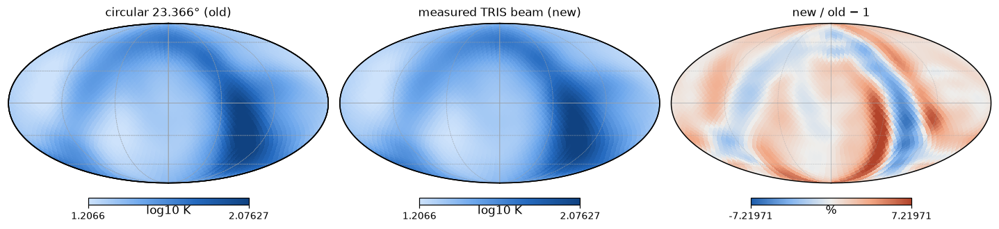

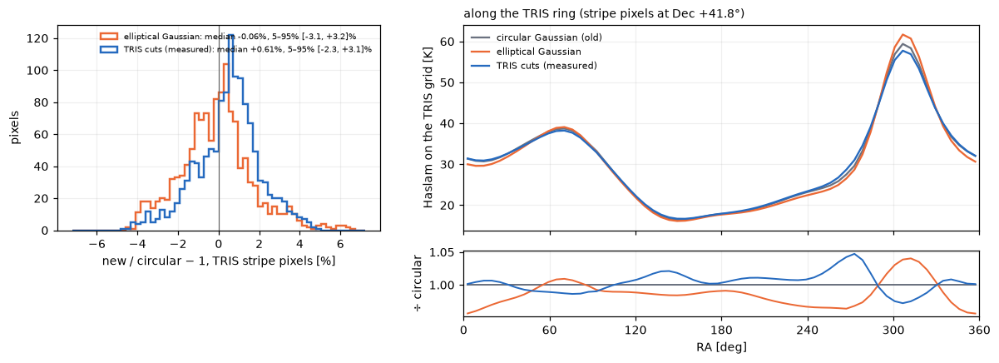

In [ ]:
BAND16 = load_stage1(config)["band_mask"].astype(bool)
NSIDE16 = hp.npix2nside(BAND16.size)
haslam_native = hp.read_map(config.resolve_path("paths.haslam_map_fits"))
haslam_eq = frames.rotate_full_sky(haslam_native, ("G", "C"))
HASLAM = {}
for label, spec in SPECS.items():
    values, kept, info = match_to_tris_beam(
        haslam_eq, np.ones(haslam_eq.size, bool), float(config.require("beam_matching.haslam_native_fwhm_deg")),
        CONFIGS[label], nside_out=NSIDE16, rule="all_children",
        spec=None if KERNEL_KEY[label] == "circular_gaussian" else spec, full_sky=True)
    HASLAM[label] = np.where(kept, values, np.nan)
    print(f"{label:<26} {int(kept.sum())} pixels kept; mean {np.nanmean(HASLAM[label]):.3f} K")

old, new = HASLAM["circular Gaussian (old)"], HASLAM["TRIS cuts (measured)"]
pct = 100 * (new / old - 1)
lo, hi = np.nanpercentile(old, [2, 98])
span = float(np.nanpercentile(np.abs(pct), 99))
fig = plt.figure(figsize=(13, 3.8))
hp.mollview(np.log10(old), sub=(1, 3, 1), fig=fig.number, title="circular 23.366° (old)",
            unit="log10 K", min=np.log10(lo), max=np.log10(hi), notext=True)
hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
hp.mollview(np.log10(new), sub=(1, 3, 2), fig=fig.number, title="measured TRIS beam (new)",
            unit="log10 K", min=np.log10(lo), max=np.log10(hi), notext=True)
hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
hp.mollview(pct, sub=(1, 3, 3), fig=fig.number, cmap=DIVB, min=-span, max=span,
            title="new / old − 1", unit="%", notext=True)
hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
plt.show()

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4.0), gridspec_kw=dict(width_ratios=[1, 1.6]))
bins = np.linspace(-span, span, 61)
for label in ("elliptical Gaussian", "TRIS cuts (measured)"):
    d = 100 * (HASLAM[label][BAND16] / old[BAND16] - 1)
    ax.hist(d[np.isfinite(d)], bins=bins, histtype="step", color=KCOL[label],
            label=f"{label}: median {np.nanmedian(d):+.2f}%, 5–95% [{np.nanpercentile(d, 5):+.1f}, {np.nanpercentile(d, 95):+.1f}]%")
ax.axvline(0, color="0.4")
ax.set_xlabel("new / circular − 1, TRIS stripe pixels [%]"); ax.set_ylabel("pixels")
ax.legend(); ax.grid(alpha=0.2)

stripe_pix = np.flatnonzero(BAND16)
ra_s, dec_s = hp.pix2ang(NSIDE16, stripe_pix, lonlat=True)
ring_dec = dec_s[np.argmin(np.abs(dec_s - BORESIGHT_DEC))]
on_ring = stripe_pix[np.isclose(dec_s, ring_dec)]
order = np.argsort(hp.pix2ang(NSIDE16, on_ring, lonlat=True)[0])
on_ring = on_ring[order]
ra_ring = hp.pix2ang(NSIDE16, on_ring, lonlat=True)[0]
inner = ax2.inset_axes([0, -0.42, 1, 0.32])
for label in SPECS:
    ax2.plot(ra_ring, HASLAM[label][on_ring], "-", color=KCOL[label], label=label)
    inner.plot(ra_ring, HASLAM[label][on_ring] / old[on_ring], "-", color=KCOL[label])
ax2.set_ylabel("Haslam on the TRIS grid [K]")
ax2.set_title(f"along the TRIS ring (stripe pixels at Dec {ring_dec:+.1f}°)", loc="left")
ax2.legend(); ax2.grid(alpha=0.2); ax2.set_xticklabels([])
inner.set_ylabel("÷ circular"); inner.set_xlabel("RA [deg]"); inner.grid(alpha=0.2)
for a in (ax2, inner):
    a.set_xlim(0, 360); a.set_xticks(np.arange(0, 361, 60))
plt.subplots_adjust(bottom=0.32)
plt.show()

**Reading plot 5 (run 2026-10-14).** Both kernels keep all 3072 pixels (Haslam is full
sky). The mean rises by 0.09%, from 34.405 K to 34.435 K: the measured beam's shoulders
pull in a little of the bright plane. In the stripe the change is centred near +0.6%, with
5–95% of pixels within about −2.3% to +3.1% (plot 7's Haslam row). It is largest where
the narrower E axis resolves Galactic-plane structure north–south.

---
### 6. ARCADE 2: the mask edge under both kernels

ARCADE 2 observed a thin ring (93% of the sky unobserved) and has the broadest native beam
(11.6°), so it is where the kernel shape changes **which pixels survive**. The weight floor
keeps a pixel only if at least half the kernel's weight falls on observed sky. A kernel that
is narrower north–south than the old circular one loses less of a ring that runs east–west,
and more of one that runs north–south.

* **Left:** each nside 16 pixel coloured by the kernel(s) under which it is kept.
* **Right:** on the pixels both keep, the new value against the old (3.15 GHz, K). Points
  on the dashed line are unchanged.

kept by both: 140;  only circular: 30;  only measured beam: 1
inside the TRIS stripe: old 153, new 127
new kernel: native beam too broad to neglect (16.91% on E): cut beam compressed to the quadrature core widths (approximate; exact only for Gaussian cores)


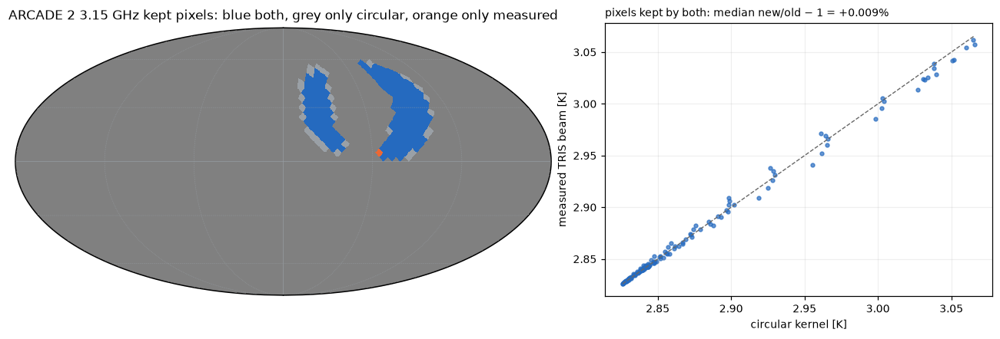

In [ ]:
arcade_native = hp.read_map(config.resolve_path("paths.arcade2_map_3150"))
arc_obs = observed_mask(arcade_native, "zeros")
arc_rot, arc_obs_rot, _ = frames.rotate_masked(arcade_native, arc_obs, ("G", "C"))
ARC = {}
for label in ("circular Gaussian (old)", "TRIS cuts (measured)"):
    values, kept, info = match_to_tris_beam(
        arc_rot, arc_obs_rot, float(config.require("beam_matching.arcade2_native_fwhm_deg")),
        CONFIGS[label], nside_out=NSIDE16, rule="all_children",
        spec=None if KERNEL_KEY[label] == "circular_gaussian" else SPECS[label], full_sky=False)
    ARC[label] = (values, kept, info)

k_old, k_new = ARC["circular Gaussian (old)"][1], ARC["TRIS cuts (measured)"][1]
category = np.full(k_old.size, np.nan)
category[k_old & k_new] = 0
category[k_old & ~k_new] = 1
category[~k_old & k_new] = 2
print(f"kept by both: {int((k_old & k_new).sum())};  only circular: {int((k_old & ~k_new).sum())};  "
      f"only measured beam: {int((~k_old & k_new).sum())}")
print(f"inside the TRIS stripe: old {int((k_old & BAND16).sum())}, new {int((k_new & BAND16).sum())}")
print("new kernel:", ARC["TRIS cuts (measured)"][2]["kernel_note"])

cat_cmap = ListedColormap(["#256abf", "#9aa0a6", "#eb6834"]); cat_cmap.set_bad("white")
fig = plt.figure(figsize=(13, 4.2))
hp.mollview(category, sub=(1, 2, 1), fig=fig.number, cmap=cat_cmap, min=-0.5, max=2.5, cbar=False,
            title="ARCADE 2 3.15 GHz kept pixels: blue both, grey only circular, orange only measured",
            notext=True)
hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
ax = fig.add_subplot(1, 2, 2)
both = k_old & k_new
v_old, v_new = ARC["circular Gaussian (old)"][0][both], ARC["TRIS cuts (measured)"][0][both]
ax.scatter(v_old, v_new, s=10, color="#256abf", alpha=0.7)
lim = [min(v_old.min(), v_new.min()), max(v_old.max(), v_new.max())]
ax.plot(lim, lim, "--", color="0.4")
ax.set_xlabel("circular kernel [K]"); ax.set_ylabel("measured TRIS beam [K]")
ax.set_title(f"pixels kept by both: median new/old − 1 = {100 * np.median(v_new / v_old - 1):+.3f}%",
             loc="left")
ax.grid(alpha=0.2)
plt.show()

**Reading plot 6 (run 2026-10-14).** The new kernel keeps **140 pixels that both keep, 30
that only the circular kernel kept, and 1 new one**. Inside the TRIS stripe ARCADE 2 goes
from **153 to 127 pixels**, so 26 fewer stripe pixels get four SED points. ARCADE 2's ring
is narrow, and its native beam is broad, so its kernel is the compressed cut beam (plot 4).
That kernel carries the cut beam's shoulders over a wider area, which puts more of its
weight off the ring. Values on the shared pixels agree to well under 1% (median shown
above). This interacts with N-7 (the 0.5 floor) and N-9 (the broad-native kernel).

---
### 7. Every map in the map route

Every survey the map route fits (plus Haslam), matched with the old and the new kernel,
compared pixel by pixel over the TRIS stripe. Each box is one survey: the spread of
`new / old − 1` in percent. The box spans the 25th–75th percentiles, the whiskers the
5th–95th, and the line is the median. The number above each box is how many stripe pixels
both kernels keep.

**What to look for.**
* A median near zero means the overall level is unchanged.
* The width of the box is the redistribution of structure: the narrower E axis sharpens
  features north–south, and the shoulders pull in a little distant emission.
* For LWA1, Maipu and ARCADE 2 the change also includes the compressed kernel, so compare
  with plot 4's bottom row.

This cell smooths every map twice. The circular kernel runs `hp.smoothing` at each
survey's native nside (CHIPASS is nside 1024), so it is slow. Set `RUN_ALL_MAPS = False`
to skip it.

LWA1 35 MHz                         1272 stripe px; median  +0.38%, 5–95% [ -1.91,  +1.92]%


LWA1 38 MHz                         1272 stripe px; median  +0.37%, 5–95% [ -1.86,  +1.76]%


LWA1 40 MHz                         1272 stripe px; median  +0.36%, 5–95% [ -1.86,  +1.72]%


LWA1 45 MHz                         1272 stripe px; median  +0.37%, 5–95% [ -1.94,  +1.98]%


Maipu + MU 45 MHz                   1200 stripe px; median  +0.50%, 5–95% [ -1.68,  +1.91]%


LWA1 50 MHz                         1272 stripe px; median  +0.36%, 5–95% [ -1.97,  +2.23]%


... (6 outputs left out)

Stockert + Villa-Elisa 1420 MHz     1269 stripe px; median  +0.13%, 5–95% [ -1.09,  +0.83]%


Rhodes/HartRAO 2326 MHz               64 stripe px; median  +0.91%, 5–95% [ -3.05,  +5.35]%


ARCADE 2 3.15 GHz                    127 stripe px; median  +0.01%, 5–95% [ -0.26,  +0.17]%


ARCADE 2 3.41 GHz                    150 stripe px; median  +0.01%, 5–95% [ -0.22,  +0.15]%


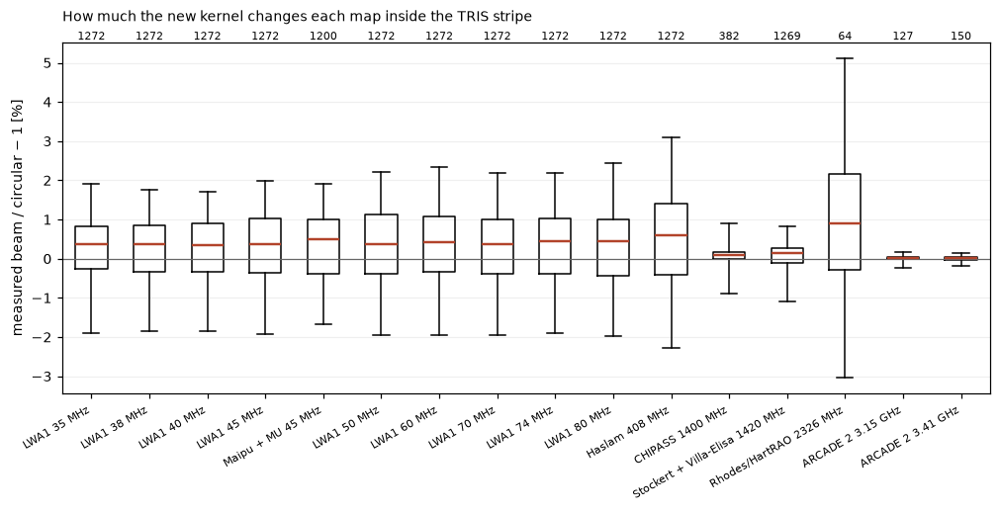

In [ ]:
RUN_ALL_MAPS = True

def rotated_equatorial(m):
    # The same rotation as moonrunes.sed_prototype.Inputs._rotated.
    sky = m["sky"]
    observed = np.isfinite(sky)
    if m["frame"] == "C":
        return np.where(observed, sky, hp.UNSEEN), observed
    if observed.all():
        return frames.rotate_full_sky(sky, (m["frame"], "C")), observed
    rotated, obs_rot, _ = frames.rotate_masked(sky, observed, (m["frame"], "C"))
    return rotated, obs_rot

if RUN_ALL_MAPS:
    CHANGE = {}
    for m in MAPS:
        rotated, obs = rotated_equatorial(m)
        out = {}
        for label in ("circular Gaussian (old)", "TRIS cuts (measured)"):
            values, kept, _ = match_to_tris_beam(
                rotated, obs, m["fwhm_deg"], CONFIGS[label], nside_out=NSIDE16, rule="all_children",
                spec=None if KERNEL_KEY[label] == "circular_gaussian" else SPECS[label],
                full_sky=bool(obs.all()))
            out[label] = np.where(kept, values, np.nan)
        both = BAND16 & np.isfinite(out["circular Gaussian (old)"]) & np.isfinite(out["TRIS cuts (measured)"])
        CHANGE[m["name"]] = 100 * (out["TRIS cuts (measured)"][both] / out["circular Gaussian (old)"][both] - 1)
        d = CHANGE[m["name"]]
        print(f"{m['name']:<34} {both.sum():5d} stripe px; median {np.median(d) if d.size else np.nan:+6.2f}%, "
              f"5–95% [{np.percentile(d, 5) if d.size else np.nan:+6.2f}, {np.percentile(d, 95) if d.size else np.nan:+6.2f}]%")

    names = [n for n in CHANGE if CHANGE[n].size]
    fig, ax = plt.subplots(figsize=(11, 4.2))
    ax.boxplot([CHANGE[n] for n in names], whis=(5, 95), showfliers=False, widths=0.55,
               medianprops=dict(color="#b2432a"))
    for i, n in enumerate(names, start=1):
        ax.text(i, ax.get_ylim()[1], f"{CHANGE[n].size}", ha="center", va="bottom", fontsize=7)
    ax.axhline(0, color="0.4")
    ax.set_xticks(range(1, len(names) + 1))
    ax.set_xticklabels(names, rotation=30, ha="right")
    ax.set_ylabel("measured beam / circular − 1 [%]")
    ax.set_title("How much the new kernel changes each map inside the TRIS stripe", loc="left",
                 pad=14)
    ax.grid(axis="y", alpha=0.2)
    plt.show()

**Reading plot 7 (run 2026-10-14).** New / old − 1 inside the TRIS stripe:

| survey | stripe pixels | median | 5–95% |
|---|---|---|---|
| LWA1 35 MHz | 1272 | +0.38% | −1.9 to +1.9% |
| Maipu 45 MHz | 1200 | +0.50% | −1.7 to +1.9% |
| LWA1 80 MHz | 1272 | +0.46% | −2.0 to +2.4% |
| Haslam 408 MHz | 1272 | +0.61% | −2.3 to +3.1% |
| CHIPASS 1400 MHz | 382 | +0.09% | −0.9 to +0.9% |
| Stockert 1420 MHz | 1269 | +0.13% | −1.1 to +0.8% |
| Rhodes 2326 MHz | 64 | +0.91% | −3.1 to +5.4% |
| ARCADE 2 3.15 / 3.41 GHz | 127 / 150 | +0.01% | ±0.2% |

**The kernel shape moves stripe pixels by up to a few percent, and levels by under 1%.**
That is small next to the 13–18% Haslam offset from the TOD route. It is not negligible
for per-pixel β, since a 2% change between 35 MHz and 408 MHz moves β by ~0.01. Haslam
and the low-frequency surveys move together (+0.4 to +0.6%), so ratios between them
change less than either map.

---
#### Reading this section (run 2026-10-14)

* **Correctness: passed.**
  * The measured kernel sits on the archive cut samples, at 19.155° × 23.366° (plot 2).
  * The orientation is +7°, confirmed against limTOD's own pointed beam (section H3).
  * `tests/test_elliptical_beam.py`: 15/15 pass.
* **The one approximation does not do what it was meant to.** For ARCADE 2 the default
  `scaled_cuts` gives an effective beam 8% (E) and 5% (H) too wide; for LWA1 35 MHz, 2.4%
  and 1.4%. The elliptical Gaussian hits the widths but not the shoulders (plot 4,
  `TODO.md` N-9).
* **Consequences:**
  * stripe pixels change by up to a few percent and medians by under 1% (plot 7);
  * Haslam's mean rises 0.09% (plot 5);
  * ARCADE 2 keeps 26 fewer stripe pixels, 127 instead of 153 (plot 6).
* **Still open:** stage 2 and notebooks 06–08 have not been re-run with this kernel
  (`TODO.md` N-8); N-10 (the TRIS maps' own resolution).

---
## Harmonic-space checks: are the a_ℓm under control?

> **Note (2026-10-14):** the config uses `beam_matching.kernel: circular_gaussian`, the kernel of the current stage 2 product. "Default" below means the elliptical `tris_cuts` kernel's status when this section ran; the elliptical kernels are implemented and tested but not in use.

**The concern (collaborator comment).** Rotating or convolving in spherical-harmonic space
is risky unless the information in the map is under control. The $a_{\ell m}$ should fall
to ~zero **before** $\ell_\mathrm{max}$ ($= 3\,n_\mathrm{side} - 1$ in healpy). Otherwise
truncation and aliasing produce ringing and other spurious structure. Plot the $C_\ell$ of
each map to check, since beam smoothing should supply the high-ℓ suppression.

**Where the pipeline works in harmonic space.** Every rotation and convolution was found
by searching the code (`moonrunes/src` and `limTOD`):

| # | operation | where | space | inputs | ℓ_max |
|---|---|---|---|---|---|
| H-a | rotate Haslam G → C | `frames.rotate_full_sky` (`rotate_map_alms`); stage 2 and the map route | **harmonic** | full-sky Haslam, nside 512 | 1535 |
| H-b | circular smoothing to the TRIS beam | `smooth_to_target` (`hp.smoothing`, mask-aware); stage 2 with `kernel: circular_gaussian` | **harmonic** | every survey at native nside; masked maps zero-filled | 3·nside − 1 |
| H-c | point the TRIS beam at each TOD sample | limTOD `generate_TOD_sky` → `map2alm` of the beam, `rotate_alm`, `alm2map`; stage 1 and the TOD route | **harmonic** | the cut beam at `nside_hires` = 16 | 47 |
| H-d | point the horizon mask | limTOD, same path, then thresholded at 0.5 | **harmonic** | a step function at 90° | 47 |
| — | rotate masked maps (ARCADE 2, CHIPASS, Maipu, …) | `frames.rotate_masked` / `rotate_map_pixel` | pixel | — | — |
| — | elliptical smoothing (`kernel: tris_cuts`, the default) | `elliptical_beam.smooth_elliptical` | **pixel (direct sum)** | — | — |
| — | degrade / regrid | `ud_grade`, `regrid_to_nside` | pixel | — | — |
| — | GSM2008 prior G → C | `stage1_tris_maps` (`rotate_map_pixel`) | pixel | — | — |

Four harmonic operations, H-a to H-d. Each is tested below in two ways: **the C_ℓ**, as
the comment asks (do the a_ℓm fall to ~0 before ℓ_max?), and **the consequence**. The
consequence is checked by comparing each harmonic operation with an exact pixel-space
calculation of the same thing, at the level of the products the analysis uses.

| plot | checks |
|---|---|
| H1 | C_ℓ of every input map, raw and after the harmonic smoothing (H-b), against each survey's beam window and ℓ_max |
| H2 | the TRIS beam's own C_ℓ at nside 16–128, and its map → a_ℓm → map round trip (H-c) |
| H3 | limTOD's harmonically pointed beam and horizon against the exact pixel-space beam (H-c, H-d) |
| H4 | the consequence for the TODs: harmonic vs exact, at nside 16, 64 and 128 |
| H5 | Haslam's harmonic rotation: the round trip, where it rings, and whether the ringing survives smoothing (H-a) |
| H6 | harmonic smoothing against the same Gaussian computed exactly in real space (H-b), on Haslam and on masked ARCADE 2 |

In [ ]:
# Setup for this section (needs `config`, `tris`, `load_stage1` from the first cell).
import time
from dataclasses import replace
from moonrunes import elliptical_beam as eb, frames, sky_maps
from moonrunes.stage2_beam_matching import smooth_to_target, extra_fwhm_deg, regrid_to_nside, observed_mask
from limTOD import generate_TOD_sky
from limTOD.simulator import pointing_beam_in_eq_sys
from matplotlib.colors import LinearSegmentedColormap

SEQB = plt.get_cmap("ring").copy()
SEQB.set_bad("#e8e8e6"); SEQB.set_under("white")
DIVB = plt.get_cmap("ring_div").copy()
DIVB.set_bad("#e8e8e6"); DIVB.set_under("white")

H_ARCHIVE = config.resolve_path("paths.tris_archive_dir")
H_CUTS = tris.read_tris_beam_cuts(H_ARCHIVE / "TRIS_Beam_Profile.txt")
H_SPEC = eb.beam_spec_from_config(config, kernel="tris_cuts")     # the exact cut beam, pixel space
H_KERNEL = eb.kernel_for(H_SPEC, 0.0)
H_RA = np.asarray(tris.read_tris_ring(H_ARCHIVE / "TRIS_absolute_600.txt").ra_deg)
H_GEOM = tris.tris_zenith_geometry(H_RA)
TARGET_FWHM = float(config.require("beam_matching.target_fwhm_deg"))
HASLAM_NATIVE = float(config.require("beam_matching.haslam_native_fwhm_deg"))

H_MAPS = [m for m in sky_maps.discover(REPO / "res")
          if (m["usable"] and m["role"] == "fit") or m["file"] == "HASLAM.fits"]
HASLAM_G = hp.read_map(config.resolve_path("paths.haslam_map_fits"))
HASLAM_C = frames.rotate_full_sky(HASLAM_G, ("G", "C"))

def tail_ratio(cl, lmax, frac=0.9):
    # Mean C_l over the top 10% of the ell range, relative to the largest C_l at ell >= 2.
    return float(cl[int(frac * lmax):lmax + 1].mean() / cl[2:].max())

print(f"{len(H_MAPS)} maps; TRIS beam pointed by limTOD at nside_hires = {int(config.require('tris.nside_hires'))}")

16 maps; TRIS beam pointed by limTOD at nside_hires = 16


---
### H1. The C_ℓ of every map, raw and after harmonic smoothing

One panel per survey, at its own nside, up to its own $\ell_\mathrm{max} = 3n_\mathrm{side}-1$
(the dotted vertical line). Every curve is divided by its largest value at ℓ ≥ 2.

* **Black: the raw map.** For a partial map this is the pseudo-$C_\ell$ of the
  mean-subtracted, zero-filled map divided by $f_\mathrm{sky}$. The mask edge adds power at
  every ℓ, so for those maps the raw tail is an upper limit on the sky's own.
* **Grey dashed: the survey's own beam**, $b_\ell^2$, scaled to the raw curve at ℓ = 10.
  It shows how much suppression the instrument provides by itself.
* **Blue: the output of the harmonic smoothing** (H-b): $\mathrm{smooth}(M\cdot T)$ with
  the quadrature kernel, i.e. $b_\ell^{K}\,a_\ell m$, the quantity `hp.smoothing` hands back
  before the mask division. This is what the comment asks about: after the beam, do the
  a_ℓm fall to ~zero before ℓ_max?

The number in each panel is **tail/peak**: the mean $C_\ell$ over the top 10% of the ℓ
range divided by the peak, for the raw map and after smoothing.

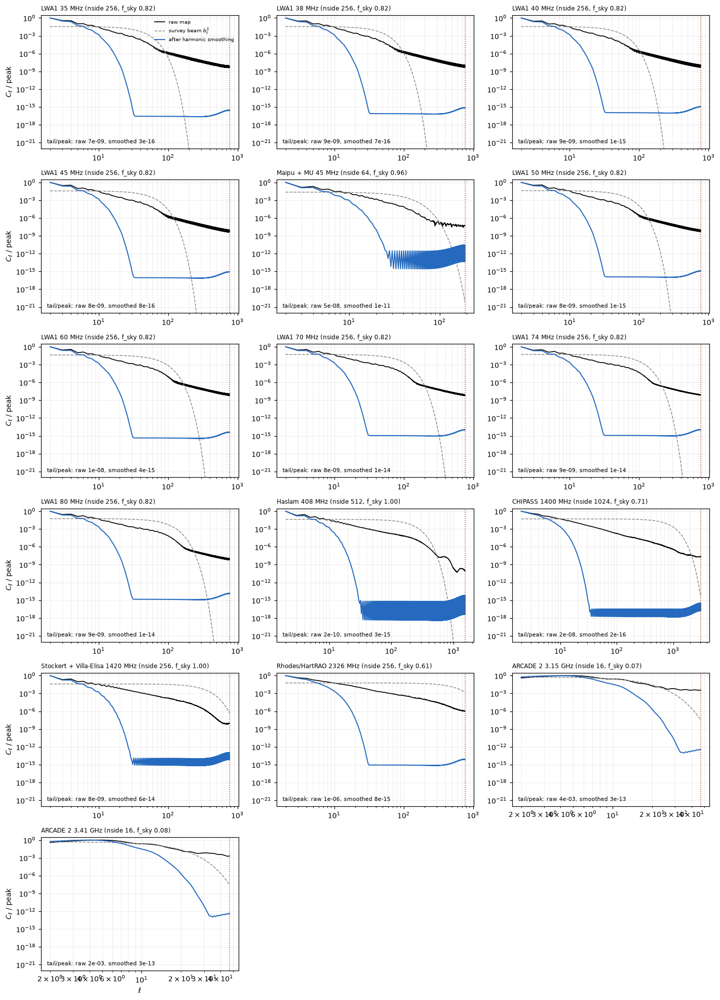

map                                nside  ℓmax  f_sky  raw tail/peak  smoothed tail/peak    b_ℓ²(ℓmax), own beam
LWA1 35 MHz                          256   767  0.821        7.1e-09             2.8e-16                1.4e-304
LWA1 38 MHz                          256   767  0.821        8.6e-09             7.3e-16                3.7e-258
LWA1 40 MHz                          256   767  0.821        9.4e-09             1.0e-15                1.6e-233
LWA1 45 MHz                          256   767  0.821        7.7e-09             8.2e-16                6.9e-185
Maipu + MU 45 MHz                     64   191  0.962        4.7e-08             1.3e-11                 3.1e-19
LWA1 50 MHz                          256   767  0.821        8.4e-09             1.1e-15                4.4e-150
LWA1 60 MHz                          256   767  0.821        9.8e-09             4.0e-15                6.2e-104
LWA1 70 MHz                          256   767  0.821        8.1e-09             1.0e-14        

In [ ]:
H1 = {}
n = len(H_MAPS)
cols = 3
rows_ = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows_, cols, figsize=(13, 3.0 * rows_), squeeze=False)
t0 = time.time()
for ax, m in zip(axes.ravel(), H_MAPS):
    sky, ns = m["sky"], m["nside"]
    lmax = 3 * ns - 1
    ell = np.arange(lmax + 1)
    obs = np.isfinite(sky)
    fsky = obs.mean()
    raw = hp.anafast(np.where(obs, sky - np.nanmean(sky), 0.0), lmax=lmax) / fsky
    kernel = extra_fwhm_deg(m["fwhm_deg"], TARGET_FWHM)
    smoothed_num = hp.smoothing(np.where(obs, sky - np.nanmean(sky), 0.0), fwhm=np.radians(kernel), iter=3)
    cl_s = hp.anafast(smoothed_num, lmax=lmax) / fsky
    bl2 = hp.gauss_beam(np.radians(m["fwhm_deg"]), lmax=lmax) ** 2
    peak_raw, peak_s = raw[2:].max(), cl_s[2:].max()
    H1[m["name"]] = dict(nside=ns, lmax=lmax, fsky=fsky, raw_tail=tail_ratio(raw, lmax),
                         smoothed_tail=tail_ratio(cl_s, lmax), beam_lmax=float(bl2[-1]))
    ax.loglog(ell[2:], raw[2:] / peak_raw, color=COLORS["ink"], label="raw map")
    ax.loglog(ell[2:], np.maximum(bl2[2:] * raw[10] / bl2[10] / peak_raw, 1e-30), "--", color="0.55",
              label="survey beam $b_\\ell^2$")
    ax.loglog(ell[2:], np.maximum(cl_s[2:] / peak_s, 1e-30), color="#256abf",
              label="after harmonic smoothing")
    ax.axvline(lmax, color="#b2432a", ls=":")
    ax.set_ylim(1e-22, 3)
    ax.set_title(f"{m['name']} (nside {ns}, f_sky {fsky:.2f})", loc="left")
    ax.text(0.03, 0.04, f"tail/peak: raw {H1[m['name']]['raw_tail']:.0e}, smoothed {H1[m['name']]['smoothed_tail']:.0e}",
            transform=ax.transAxes, fontsize=7)
    ax.grid(alpha=0.2, which="both")
for ax in axes.ravel()[n:]:
    ax.axis("off")
axes[0, 0].legend(loc="upper right")
for ax in axes[-1]:
    ax.set_xlabel("ℓ")
for ax in axes[:, 0]:
    ax.set_ylabel("$C_\\ell$ / peak")
plt.tight_layout(); plt.show()

print(f"{'map':<34}{'nside':>6}{'ℓmax':>6}{'f_sky':>7}{'raw tail/peak':>15}{'smoothed tail/peak':>20}{'b_ℓ²(ℓmax), own beam':>24}")
for name, h in H1.items():
    print(f"{name:<34}{h['nside']:6d}{h['lmax']:6d}{h['fsky']:7.3f}{h['raw_tail']:15.1e}{h['smoothed_tail']:20.1e}{h['beam_lmax']:24.1e}")
print(f"[{time.time() - t0:.0f} s]")

**Reading H1 (run 2026-10-14).**

* **After the harmonic smoothing, every map's a_ℓm fall to zero well before ℓ_max**, as the
  comment asks. Tail/peak is 10⁻¹¹ to 10⁻¹⁶: the numerical floor, reached by ℓ ≈ 30–40.
  The 20–23° kernel's window is ~e⁻²⁵ in power by ℓ ≈ 35. ARCADE 2 (nside 16, ℓ_max 47)
  is the tightest: its smoothed C_ℓ reaches the floor at ℓ ≈ 40, just inside ℓ_max.
* **The raw maps are not band-limited at their own nside.** The surveys' beams are
  narrower than a few pixels, so the raw tails, 10⁻⁶ to 10⁻¹⁰ of the peak, are set by
  pixelisation, noise and (for partial maps) the mask edge, not by the beam. For ARCADE 2
  the raw tail is 10⁻³, all of it the 7%-of-sky ring mask. This is exactly the situation
  the comment warns about, and it matters for any harmonic operation applied **before**
  smoothing: H5 (rotating Haslam) and H6 (smoothing the zero-filled masked maps).

---
### H2. The TRIS beam's own C_ℓ (limTOD's harmonic step)

limTOD turns the TRIS beam map into $a_{\ell m}$ (`map2alm`) and rotates those to every
pointing. Left: the beam's $C_\ell$ at nside 16 (what the pipeline uses), 32, 64 and 128,
each with its ℓ_max (dotted). Right: the map → a_ℓm → map round trip with no rotation, as
the largest error and the most negative pixel created, relative to the peak.

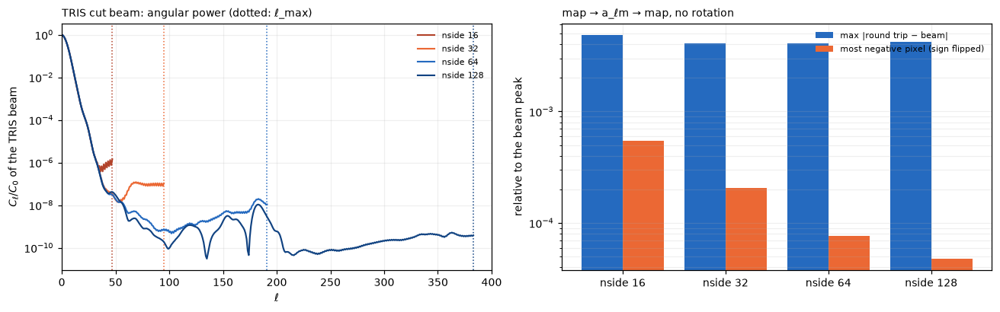

 nside  ℓmax   C(ℓmax)/C0    tail/C0   max err  min pixel
    16    47      1.4e-06    9.8e-07   4.9e-03   -5.4e-04
    32    95      1.1e-07    9.4e-08   4.1e-03   -2.1e-04
    64   191      1.1e-08    1.2e-08   4.1e-03   -7.7e-05
   128   383      3.8e-10    4.0e-10   4.2e-03   -4.8e-05


In [ ]:
H2 = []
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
colours = {16: "#b2432a", 32: "#eb6834", 64: "#256abf", 128: "#104281"}
for ns in (16, 32, 64, 128):
    beam = tris.tris_cut_beam_map(H_CUTS, nside=ns, normalization="peak")
    alm = hp.map2alm(beam)
    cl = hp.alm2cl(alm)
    back = hp.alm2map(alm, ns)
    lmax = 3 * ns - 1
    H2.append(dict(nside=ns, lmax=lmax, cl_lmax=cl[-1] / cl[0], tail=float(cl[int(0.9 * lmax):].mean() / cl[0]),
                   max_err=float(np.max(np.abs(back - beam))), min_back=float(back.min())))
    ax.semilogy(np.arange(cl.size), cl / cl[0], color=colours[ns], label=f"nside {ns}")
    ax.axvline(lmax, color=colours[ns], ls=":")
ax.set_xlabel("ℓ"); ax.set_ylabel("$C_\\ell / C_0$ of the TRIS beam"); ax.set_xlim(0, 400)
ax.legend(); ax.grid(alpha=0.2, which="both")
ax.set_title("TRIS cut beam: angular power (dotted: ℓ_max)", loc="left")
x = np.arange(len(H2))
ax2.bar(x - 0.2, [h["max_err"] for h in H2], width=0.4, color="#256abf", label="max |round trip − beam|")
ax2.bar(x + 0.2, [-h["min_back"] for h in H2], width=0.4, color="#eb6834", label="most negative pixel (sign flipped)")
ax2.set_yscale("log"); ax2.set_xticks(x); ax2.set_xticklabels([f"nside {h['nside']}" for h in H2])
ax2.set_ylabel("relative to the beam peak"); ax2.legend(); ax2.grid(alpha=0.2, which="both")
ax2.set_title("map → a_ℓm → map, no rotation", loc="left")
plt.tight_layout(); plt.show()
print(f"{'nside':>6}{'ℓmax':>6}{'C(ℓmax)/C0':>13}{'tail/C0':>11}{'max err':>10}{'min pixel':>11}")
for h in H2:
    print(f"{h['nside']:6d}{h['lmax']:6d}{h['cl_lmax']:13.1e}{h['tail']:11.1e}{h['max_err']:10.1e}{h['min_back']:+11.1e}")

---
### H3. limTOD's pointed beam against the exact beam

One TRIS pointing (sample 60). **Left:** the beam limTOD uses: harmonically rotated
(H-c), with the harmonically rotated, thresholded horizon (H-d), normalised. **Middle:**
the same beam evaluated exactly in pixel space at the same nside, with
`elliptical_beam` (cut beam, E plane 7° east of north, zero beyond 90° from the zenith).
**Right:** limTOD − exact, as a percentage of the peak. Gnomonic views centred on the
zenith, 100° across.

This also tests the beam *orientation* the elliptical kernel assumes. The printout
repeats the comparison with the E plane at −7°; if +7° is right, its difference is much
smaller.

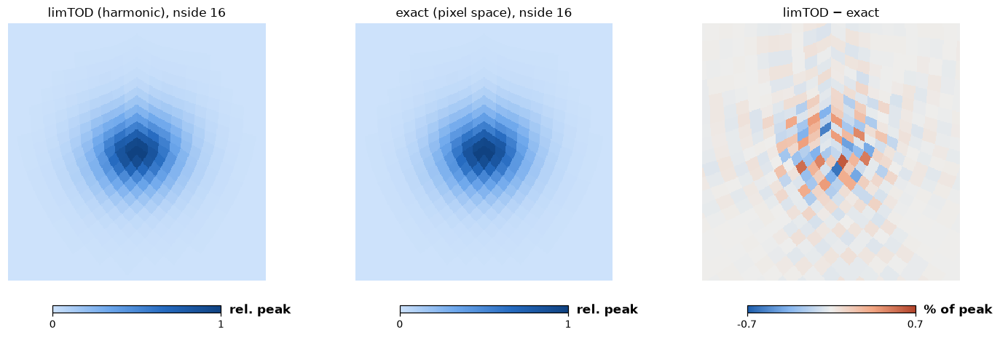

 nside E-plane PA  max |diff|  rms diff  neg. pixels  most neg.  kept: limTOD  exact
    16        +7°       0.62%    0.047%          348    -0.043%          1572   1536
    16        -7°       3.59%    0.310%          348    -0.043%          1572   1536
    32        +7°       1.11%    0.034%          486    -0.016%          6206   6144
    32        -7°       3.48%    0.303%          486    -0.016%          6206   6144
    64        +7°       0.71%    0.015%          922    -0.007%         24722  24576
    64        -7°       3.31%    0.300%          922    -0.007%         24722  24576
(percentages of the beam peak; 'kept' = pixels with non-zero weight, i.e. above the horizon)


In [ ]:
k = 60
H3 = []
for ns in (16, 32, 64):
    beam_alm = hp.map2alm(tris.tris_cut_beam_map(H_CUTS, nside=ns, normalization="peak"))
    lim = pointing_beam_in_eq_sys(beam_alm, H_GEOM.lst_deg[k], H_GEOM.latitude_deg, H_GEOM.azimuth_deg[k],
                                  H_GEOM.elevation_deg[k], H_GEOM.selfrot_deg[k], nside=ns,
                                  normalize=True, horizontal_mask=tris.tris_horizon_mask(ns))
    centre = np.array(hp.ang2vec(H_GEOM.lst_deg[k], H_GEOM.latitude_deg, lonlat=True))[None, :]
    th, psi = eb.local_offsets(centre, np.array(hp.pix2vec(ns, np.arange(hp.nside2npix(ns)))).T)
    for pa in (7.0, -7.0):
        ex = eb.kernel_response(H_KERNEL, replace(H_SPEC, e_plane_east_of_meridian_deg=pa), th[:, 0], psi[:, 0])
        ex = ex / ex.sum()
        H3.append(dict(nside=ns, pa=pa, max_diff=float(np.max(np.abs(lim - ex)) / ex.max()),
                       rms_diff=float(np.std(lim - ex) / ex.max()), n_neg=int((lim < 0).sum()),
                       min_lim=float(lim.min() / ex.max()), kept_lim=int((lim != 0).sum()),
                       kept_exact=int((ex > 0).sum())))
        if ns == 16 and pa == 7.0:
            LIM16, EX16 = lim, ex

fig = plt.figure(figsize=(13, 4.0))
rot = (H_GEOM.lst_deg[k], H_GEOM.latitude_deg)
peak = EX16.max()
kw = dict(rot=rot, reso=20, xsize=300, fig=fig.number, notext=True)
hp.gnomview(LIM16 / peak, sub=(1, 3, 1), title="limTOD (harmonic), nside 16", min=0, max=1, unit="rel. peak", **kw)
hp.gnomview(EX16 / peak, sub=(1, 3, 2), title="exact (pixel space), nside 16", min=0, max=1, unit="rel. peak", **kw)
hp.gnomview(100 * (LIM16 - EX16) / peak, sub=(1, 3, 3), title="limTOD − exact", cmap=DIVB, min=-0.7, max=0.7,
            unit="% of peak", **kw)
plt.show()

print(f"{'nside':>6}{'E-plane PA':>11}{'max |diff|':>12}{'rms diff':>10}{'neg. pixels':>13}{'most neg.':>11}{'kept: limTOD':>14}{'exact':>7}")
for h in H3:
    print(f"{h['nside']:6d}{h['pa']:+10.0f}°{100 * h['max_diff']:11.2f}%{100 * h['rms_diff']:9.3f}%{h['n_neg']:13d}"
          f"{100 * h['min_lim']:+10.3f}%{h['kept_lim']:14d}{h['kept_exact']:7d}")
print("(percentages of the beam peak; 'kept' = pixels with non-zero weight, i.e. above the horizon)")

---
### H4. The consequence for the TODs

The question that matters for the TOD route: does the harmonic beam pointing change the
**data**? Haslam (in equatorial) is observed through the TRIS beam along the real ring
geometry, five ways:

| curve | beam | sky grid |
|---|---|---|
| limTOD, nside 16 | harmonic (H-c, H-d) — **what the pipeline does** | 16 |
| exact, nside 16 | exact pixel-space beam, hard horizon | 16 |
| limTOD, nside 64 | harmonic | 64 |
| exact, nside 64 | exact | 64 |
| **exact, nside 128** | exact — **the reference** | 128 |

Top: the TODs. Bottom: each minus the reference, in percent. Comparing limTOD with the
exact beam *on the same sky grid* isolates the harmonic step. Comparing nside 16 with 128
isolates the sky's pixelisation.

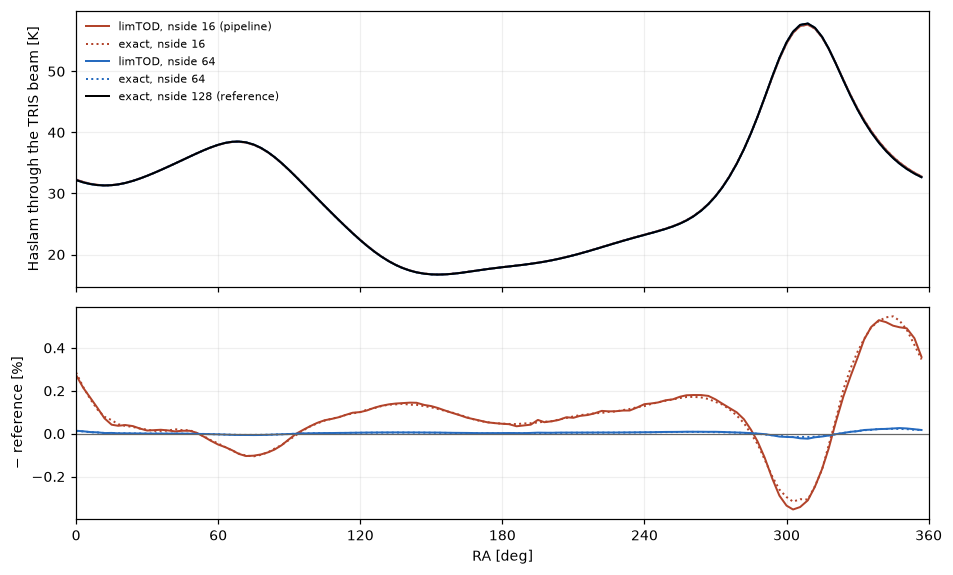

TOD                             vs reference: median   max |Δ|     rms
limTOD, nside 16 (pipeline)                  +0.073%    0.530%  0.165%
exact, nside 16                              +0.075%    0.547%  0.164%
limTOD, nside 64                             +0.004%    0.026%  0.008%
exact, nside 64                              +0.004%    0.023%  0.007%
exact, nside 128 (reference)                 +0.000%    0.000%  0.000%
harmonic step alone (limTOD vs exact on the same nside 16 sky): max |Δ| 0.043%
harmonic step alone (limTOD vs exact on the same nside 64 sky): max |Δ| 0.008%
[5 s]


In [ ]:
def limtod_tod(sky, ns):
    beam = tris.tris_cut_beam_map(H_CUTS, nside=ns, normalization="peak")
    return np.asarray(generate_TOD_sky(beam, sky, H_GEOM.lst_deg, H_GEOM.latitude_deg, H_GEOM.azimuth_deg,
                                       H_GEOM.elevation_deg, H_GEOM.selfrot_deg, nside_hires=ns,
                                       normalize_beam=True, horizontal_mask=tris.tris_horizon_mask(ns)))

def exact_tod(sky):
    ns = hp.get_nside(sky)
    pts = np.array(hp.pix2vec(ns, np.arange(sky.size))).T
    out = np.empty(H_RA.size)
    for i in range(H_RA.size):
        c = np.array(hp.ang2vec(H_GEOM.lst_deg[i], H_GEOM.latitude_deg, lonlat=True))[None, :]
        th, psi = eb.local_offsets(c, pts)
        b = eb.kernel_response(H_KERNEL, H_SPEC, th[:, 0], psi[:, 0])
        out[i] = np.sum(b * sky) / np.sum(b)
    return out

t0 = time.time()
sky = {ns: hp.ud_grade(HASLAM_C, ns) for ns in (16, 64, 128)}
H4 = {"limTOD, nside 16 (pipeline)": limtod_tod(sky[16], 16),
      "exact, nside 16": exact_tod(sky[16]),
      "limTOD, nside 64": limtod_tod(sky[64], 64),
      "exact, nside 64": exact_tod(sky[64]),
      "exact, nside 128 (reference)": exact_tod(sky[128])}
ref = H4["exact, nside 128 (reference)"]
style = {"limTOD, nside 16 (pipeline)": ("#b2432a", "-"), "exact, nside 16": ("#b2432a", ":"),
         "limTOD, nside 64": ("#256abf", "-"), "exact, nside 64": ("#256abf", ":"),
         "exact, nside 128 (reference)": ("k", "-")}
fig, (ax, axd) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw=dict(height_ratios=[1.3, 1], hspace=0.08))
for name, tod in H4.items():
    c, ls = style[name]
    ax.plot(H_RA, tod, ls, color=c, label=name)
    if "reference" not in name:
        axd.plot(H_RA, 100 * (tod / ref - 1), ls, color=c)
axd.axhline(0, color="0.4")
ax.set_ylabel("Haslam through the TRIS beam [K]"); ax.legend()
axd.set_ylabel("− reference [%]"); axd.set_xlabel("RA [deg]")
for a in (ax, axd):
    a.set_xlim(0, 360); a.set_xticks(np.arange(0, 361, 60)); a.grid(alpha=0.2)
plt.show()

print(f"{'TOD':<30}{'vs reference: median':>22}{'max |Δ|':>10}{'rms':>8}")
for name, tod in H4.items():
    d = 100 * (tod / ref - 1)
    print(f"{name:<30}{np.median(d):+21.3f}%{np.max(np.abs(d)):9.3f}%{np.std(d):7.3f}%")
for ns in (16, 64):
    d = 100 * (H4[[n for n in H4 if n.startswith(f"limTOD, nside {ns}")][0]] / H4[f"exact, nside {ns}"] - 1)
    print(f"harmonic step alone (limTOD vs exact on the same nside {ns} sky): max |Δ| {np.max(np.abs(d)):.3f}%")
print(f"[{time.time() - t0:.0f} s]")

---
### H5. Haslam's harmonic rotation (H-a)

Haslam is the one map rotated in harmonic space: full sky, nside 512, ℓ_max 1535. Its own
56′ beam is ~4 pixels wide, so its a_ℓm do not reach zero by ℓ_max (H1). The comment
predicts ringing, and the round trip G → C → G shows it:

* **Left:** the round-trip residual (back − original), ±0.5 K.
* **Middle:** a 20° gnomonic zoom on the pixel with the largest residual. Ringing around a
  bright compact source looks like concentric rings.
* **Right:** the residual's $C_\ell$ against Haslam's. The residual lives at the highest ℓ.

**Does it survive into what the analysis uses?** The products are smoothed to the TRIS beam
and put on nside 16. A smoothed map *is* band-limited, so smoothing **first** and rotating
**after** cannot ring. The printout compares the nside 16 product made both ways: rotate
then smooth (the pipeline) against smooth then rotate. It also includes pixel-space
rotation.

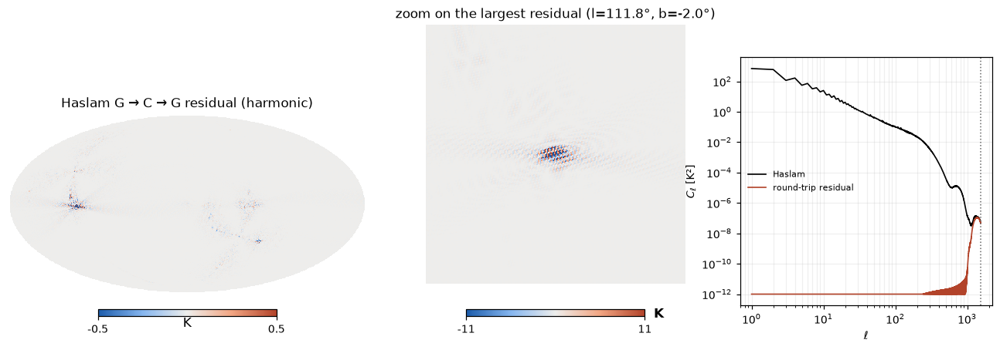

round trip: rms 0.080 K (0.23% of the mean); largest +33.0 K on a 4779 K pixel (l=111.8°, b=-2.0°); 490 pixels off by more than 1 K


nside 16 product, rotate (harmonic) → smooth  [pipeline]             vs smooth→rotate: max |Δ| 5.4e-05%, rms 6.3e-06%
nside 16 product, smooth → rotate (harmonic)  [band-limited first]   vs smooth→rotate: max |Δ| 0.0e+00%, rms 0.0e+00%
nside 16 product, rotate (pixel) → smooth                            vs smooth→rotate: max |Δ| 7.2e-04%, rms 1.8e-04%
[22 s]


In [ ]:
t0 = time.time()
back = frames.rotate_full_sky(HASLAM_C, ("C", "G"))
resid = back - HASLAM_G
worst = int(np.argmax(np.abs(resid)))
lon_w, lat_w = hp.pix2ang(512, worst, lonlat=True)
cl_h = hp.anafast(HASLAM_G - HASLAM_G.mean())
cl_r = hp.anafast(resid)

fig = plt.figure(figsize=(13, 3.8))
hp.mollview(resid, sub=(1, 3, 1), fig=fig.number, cmap=DIVB, min=-0.5, max=0.5, unit="K",
            title="Haslam G → C → G residual (harmonic)", notext=True)
hp.gnomview(resid, rot=(lon_w, lat_w), reso=2.0, xsize=600, sub=(1, 3, 2), fig=fig.number, cmap=DIVB,
            min=-np.abs(resid[worst]) / 3, max=np.abs(resid[worst]) / 3, unit="K",
            title=f"zoom on the largest residual (l={lon_w:.1f}°, b={lat_w:.1f}°)", notext=True)
ax = fig.add_subplot(1, 3, 3)
ell = np.arange(cl_h.size)
ax.loglog(ell[1:], cl_h[1:], color=COLORS["ink"], label="Haslam")
ax.loglog(ell[1:], np.maximum(cl_r[1:], 1e-12), color="#b2432a", label="round-trip residual")
ax.axvline(3 * 512 - 1, color="0.4", ls=":")
ax.set_xlabel("ℓ"); ax.set_ylabel("$C_\\ell$ [K²]"); ax.legend(); ax.grid(alpha=0.2, which="both")
plt.show()
print(f"round trip: rms {resid.std():.3f} K ({100 * resid.std() / HASLAM_G.mean():.2f}% of the mean); largest "
      f"{resid[worst]:+.1f} K on a {HASLAM_G[worst]:.0f} K pixel (l={lon_w:.1f}°, b={lat_w:.1f}°); "
      f"{int((np.abs(resid) > 1).sum())} pixels off by more than 1 K")

# Does it reach the nside 16 product?
ones = np.ones(HASLAM_G.size, bool)
prod = {}
prod["rotate (harmonic) → smooth  [pipeline]"] = smooth_to_target(HASLAM_C, HASLAM_NATIVE, TARGET_FWHM)
prod["smooth → rotate (harmonic)  [band-limited first]"] = frames.rotate_full_sky(
    smooth_to_target(HASLAM_G, HASLAM_NATIVE, TARGET_FWHM), ("G", "C"))
prod["rotate (pixel) → smooth"] = smooth_to_target(hp.Rotator(coord=["G", "C"]).rotate_map_pixel(HASLAM_G),
                                                   HASLAM_NATIVE, TARGET_FWHM)
p16 = {name: regrid_to_nside(v, ones, 16)[0] for name, v in prod.items()}
ref16 = p16["smooth → rotate (harmonic)  [band-limited first]"]
for name, v in p16.items():
    d = 100 * (v / ref16 - 1)
    print(f"nside 16 product, {name:<50} vs smooth→rotate: max |Δ| {np.max(np.abs(d)):.1e}%, rms {np.std(d):.1e}%")
print(f"[{time.time() - t0:.0f} s]")

---
### H6. Harmonic smoothing against the exact real-space Gaussian (H-b)

`hp.smoothing` applies the Gaussian as a window in ℓ. The same smoothing can be done
without any harmonics: a direct sum with a Gaussian of the same FWHM in angle
(`elliptical_beam`, `circular_gaussian`). That uses the same normalised convolution, a
0.92° working grid and 2×2 evaluation points per nside 16 pixel. Any ringing, truncation
or aliasing in the harmonic version would show up as a difference.

Two expected, non-ringing differences:

* a Gaussian in ℓ is ~0.25% wider in angle than a Gaussian in angle at 23° (notebook 09);
* the two versions average into nside 16 pixels differently.

Both are a fraction of a percent.

* **Haslam** (full sky, the raw map not band-limited, H1): left, the difference map; middle,
  its histogram.
* **ARCADE 2 3.15 GHz** (thin masked ring, zero-filled, nside 16 = ℓ_max 47, the hardest
  case for H-b): right, harmonic against real space on the pixels both keep.

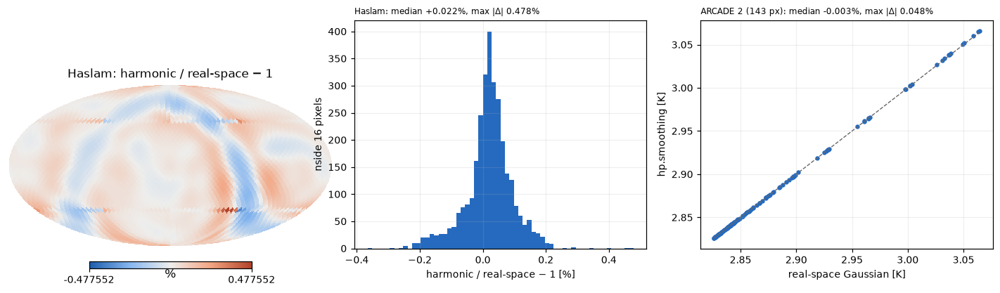

Haslam   harmonic vs real space: median +0.022%, max |Δ| 0.478%, rms 0.075%
ARCADE 2 harmonic vs real space: median -0.003%, max |Δ| 0.048%
[47 s]


In [ ]:
t0 = time.time()
spec_circ = eb.with_kernel(H_SPEC, "circular_gaussian")
has_harm = regrid_to_nside(smooth_to_target(HASLAM_C, HASLAM_NATIVE, TARGET_FWHM), ones, 16)[0]
has_real = eb.smooth_elliptical(HASLAM_C, ones, HASLAM_NATIVE, spec_circ, 16)["values"]
d_has = 100 * (has_harm / has_real - 1)

arc = hp.read_map(config.resolve_path("paths.arcade2_map_3150"))
arc_obs = observed_mask(arc, "zeros")
arc_rot, arc_obs_rot, _ = frames.rotate_masked(arc, arc_obs, ("G", "C"))
arc_native = float(config.require("beam_matching.arcade2_native_fwhm_deg"))
arc_harm = smooth_to_target(np.where(arc_obs_rot, arc_rot, 0.0), arc_native, TARGET_FWHM,
                            weight_mask=arc_obs_rot, weight_floor=0.5)
arc_real = eb.smooth_elliptical(arc_rot, arc_obs_rot, arc_native, spec_circ, 16)
both = (arc_harm != hp.UNSEEN) & arc_obs_rot & (arc_real["weight_min"] >= 0.5)
d_arc = 100 * (arc_harm[both] / arc_real["values"][both] - 1)

fig = plt.figure(figsize=(13, 3.8))
span = float(np.max(np.abs(d_has)))
hp.mollview(d_has, sub=(1, 3, 1), fig=fig.number, cmap=DIVB, min=-span, max=span, unit="%",
            title="Haslam: harmonic / real-space − 1", notext=True)
ax = fig.add_subplot(1, 3, 2)
ax.hist(d_has, bins=60, color="#256abf"); ax.set_xlabel("harmonic / real-space − 1 [%]"); ax.set_ylabel("nside 16 pixels")
ax.set_title(f"Haslam: median {np.median(d_has):+.3f}%, max |Δ| {np.max(np.abs(d_has)):.3f}%", loc="left")
ax.grid(alpha=0.2)
ax = fig.add_subplot(1, 3, 3)
ax.scatter(arc_real["values"][both], arc_harm[both], s=10, color="#256abf")
lim = [arc_real["values"][both].min(), arc_real["values"][both].max()]
ax.plot(lim, lim, "--", color="0.4")
ax.set_xlabel("real-space Gaussian [K]"); ax.set_ylabel("hp.smoothing [K]")
ax.set_title(f"ARCADE 2 ({both.sum()} px): median {np.median(d_arc):+.3f}%, max |Δ| {np.max(np.abs(d_arc)):.3f}%",
             loc="left")
ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()
print(f"Haslam   harmonic vs real space: median {np.median(d_has):+.3f}%, max |Δ| {np.max(np.abs(d_has)):.3f}%, rms {np.std(d_has):.3f}%")
print(f"ARCADE 2 harmonic vs real space: median {np.median(d_arc):+.3f}%, max |Δ| {np.max(np.abs(d_arc)):.3f}%")
print(f"[{time.time() - t0:.0f} s]")

---
### Summary: response to the comment (run 2026-10-14)

**The concern is valid in principle, and two of the four harmonic operations do act on fields
that are not band-limited. The measured consequence for every product the analysis uses
is ≤ 0.05%, and ≤ 0.5% where it is not ringing at all.**

| # | operation | a_ℓm → 0 before ℓ_max? | measured effect on what the analysis uses | verdict |
|---|---|---|---|---|
| H-a | Haslam G → C, `rotate_map_alms`, ℓ_max 1535 | **no**: raw tail/peak 1.5×10⁻¹⁰ (H1), pixel-limited | round trip 0.08 K rms, but **33 K ringing at Cas A** (on a 4779 K pixel), 490 pixels off by > 1 K (H5). In the nside 16 smoothed product: **5×10⁻⁵ %** against smooth-then-rotate | ringing real at full resolution, removed by the 23° smoothing. **But the full-resolution product inherits it:** `sed_prototype.apply_full_resolution` rotates the nside 512 target with `rotate_map_alms`, so notebook 08's Figure 11 (corrected Haslam at full resolution) carries the Cas A / Cyg A / Galactic-centre ringing |
| H-b | circular smoothing, `hp.smoothing` | input no (raw tails, mask edges); **output yes**, tail/peak 10⁻¹¹–10⁻¹⁶ by ℓ ≈ 35 (H1) | against an exact real-space Gaussian: ARCADE 2 (masked, ℓ_max 47) **0.05%** max; Haslam 0.5% max, 0.08% rms, with the pattern of the known ~0.25% harmonic-vs-angular Gaussian width difference, not ringing (H6) | safe |
| H-c | limTOD beam pointing, `map2alm`/`rotate_alm` at nside 16, ℓ_max 47 | **marginal**: beam C_ℓ(ℓ_max)/C₀ = 1.4×10⁻⁶, turning **up** before ℓ_max (aliasing); round trip makes negative pixels at −0.05% of peak (H2) | pointed beam within 0.6% of peak of the exact beam (H3); **TODs within 0.043%** of the exact pixel-space beam on the same sky (H4) | safe at the analysis's precision; improves to 0.008% at nside 64 |
| H-d | limTOD horizon mask, same path, thresholded | **no**: a step function | 36 extra pixels at the horizon at nside 16 (1572 vs 1536), included in H4's 0.043% | safe |

**What dominates instead.** The sky's own **pixelisation at nside 16** moves the TODs by up
to **0.53%** (0.17% rms) against an nside 128 reference, ten times more than every harmonic
step combined. It falls to 0.026% at nside 64 (H4). This is the same nside 16 limit
notebook 09 found for the beam (Test 2).

**Recommendations**

1. **Fix `sed_prototype.apply_full_resolution`** (notebook 08, Figure 11): rotate the raw
   nside 512 map in **pixel space**, or leave Haslam in Galactic and rotate the smooth
   nside 16 correction into Galactic instead. The second is cleaner: the correction is
   band-limited, so its rotation cannot ring. Do not use `rotate_map_alms` on the raw
   nside 512 map anywhere the full-resolution result is kept.
2. Move the TOD route and stage 1 to `tris.nside_hires` = 64 (and the TOD sky grid to 64).
   That fixes both the aliasing in H2 and the 0.5% pixelisation effect, at a few times the
   cost.
3. The default elliptical kernel (`tris_cuts`) is a direct sum in pixel space, so H-b does
   not arise for it at all. H-b applies only to `circular_gaussian`.

All numbers above are printed by the cells in this section.

---
## Convolve → deconvolve with limTOD: do the maps come back?

**The check.** Convolve each map with a beam using limTOD, deconvolve it again with limTOD,
and see whether the original comes back. Do it twice:

* with a **circular Gaussian**, 23.366° FWHM;
* with an **elliptical Gaussian** with TRIS's specifications: 19.155° (E) × 23.366° (H),
  pointed as TRIS points (zenith, E plane rolled 7° east of the meridian).

Then compare what the two beams give, convolved and deconvolved.

**How, entirely with limTOD's own functions:**

1. **The beams:** `limTOD.tris.approximate_tris_gaussian_beam_map`, at nside 16 (the
   analysis grid), circular (23.366 × 23.366) and elliptical (19.155 × 23.366).
2. **Convolution = observing.** For every one of the 3072 nside 16 pixels, limTOD's
   `pointing_beam_in_eq_sys` points the beam at that pixel's centre: a zenith pointing at
   LST = RA and latitude = Dec, `selfrot` = −7° (TRIS's roll), with TRIS's horizon mask.
   This is exactly the call `generate_TOD_sky` makes for every TOD sample, and the cell
   checks that the two agree. The pointed, normalised beams are the rows of a
   3072 × 3072 operator **A**, and the convolved map is **c = A s**. One convolved value
   per pixel is a full-sky "TOD" that samples every pixel once.
3. **Deconvolution = map-making.** limTOD's `wiener_filter_map`, the solver stage 1 and the
   TOD route use, recovers $\hat s = (A^\mathsf{T}N^{-1}A + S^{-1})^{-1}(A^\mathsf{T}N^{-1}d + S^{-1}\mu)$
   from **d = c + noise**:
   * noise $N$: Gaussian, σ = a fraction of each convolved value, at three levels:
     10⁻² (1%), 10⁻⁴ (0.01%, about the TRIS rings' statistical error relative to the sky)
     and 10⁻⁶;
   * a deliberately weak prior: $\mu$ = the convolved map's mean, $S$ = (the map's mean)²
     on the diagonal. It only stops the solve from blowing up in modes the data cannot
     see.

**What to expect.** A beam multiplies each spherical harmonic by $b_\ell$, about
$\exp[-\ell(\ell+1)\sigma^2/2]$. For σ ≈ 10° that is 10⁻¹⁰ by ℓ ≈ 40. Deconvolution divides
by it, so any noise at those scales is amplified by up to 10¹⁰. **The large scales should
come back exactly and the small ones should not.** Where the crossover lies depends on the
noise level and on the beam: the elliptical beam is narrower north–south, so it should
keep a little more. The plots below measure where it lies.

operators built in 5 s
circular 23.366°               generate_TOD_sky vs A @ s on the Dec +41.8° ring: max relative difference 4.4e-16
elliptical 19.155° × 23.366°   generate_TOD_sky vs A @ s on the Dec +41.8° ring: max relative difference 4.4e-16


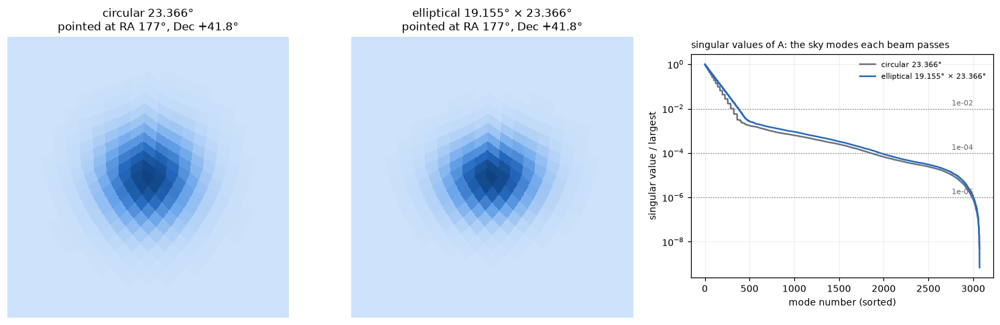

circular 23.366°               modes above 1e-2 / 1e-4 / 1e-6 of the largest: 320 / 1855 / 2988 of 3072
elliptical 19.155° × 23.366°   modes above 1e-2 / 1e-4 / 1e-6 of the largest: 377 / 1959 / 3001 of 3072


In [ ]:
# Build the two beam operators with limTOD (about 80 s per beam).
from limTOD import generate_TOD_sky
from limTOD.simulator import pointing_beam_in_eq_sys
from limTOD.HPW_filter import wiener_filter_map

D_NS = 16
D_NPIX = hp.nside2npix(D_NS)
D_ROLL = -tris.TRIS_E_PLANE_EAST_OF_MERIDIAN_DEG          # limTOD's selfrot for TRIS
D_RA, D_DEC = hp.pix2ang(D_NS, np.arange(D_NPIX), lonlat=True)
D_HORIZON = tris.tris_horizon_mask(D_NS)
D_BEAMS = {
    "circular 23.366°": tris.approximate_tris_gaussian_beam_map(nside=D_NS, fwhm_e_deg=23.366, fwhm_h_deg=23.366),
    "elliptical 19.155° × 23.366°": tris.approximate_tris_gaussian_beam_map(nside=D_NS, fwhm_e_deg=19.155, fwhm_h_deg=23.366),
}
D_COL = {"circular 23.366°": "#6b7280", "elliptical 19.155° × 23.366°": "#256abf"}

def beam_operator(beam):
    # Row p = limTOD's beam pointed at pixel p's centre (zenith pointing at LST = RA, latitude = Dec).
    alm = hp.map2alm(beam)
    A = np.empty((D_NPIX, D_NPIX))
    for p in range(D_NPIX):
        A[p] = pointing_beam_in_eq_sys(alm, D_RA[p], D_DEC[p], 0.0, 90.0, D_ROLL, nside=D_NS,
                                       normalize=True, horizontal_mask=D_HORIZON)
    return A

t0 = time.time()
D_A = {name: beam_operator(beam) for name, beam in D_BEAMS.items()}
print(f"operators built in {time.time() - t0:.0f} s")

# The input: Haslam in equatorial on nside 16 (H5's harmonic rotation, then averaged).
D_HASLAM = hp.ud_grade(HASLAM_C, D_NS)

# Check: A @ s is exactly what generate_TOD_sky returns for the same pointings (one ring of pixels).
ring = np.flatnonzero(np.isclose(D_DEC, D_DEC[np.argmin(np.abs(D_DEC - 42.4))]))
for name, beam in D_BEAMS.items():
    tod = np.asarray(generate_TOD_sky(beam, D_HASLAM, D_RA[ring], D_DEC[ring[0]], np.zeros(ring.size),
                                      np.full(ring.size, 90.0), np.full(ring.size, D_ROLL), nside_hires=D_NS,
                                      normalize_beam=True, horizontal_mask=D_HORIZON))
    print(f"{name:<30} generate_TOD_sky vs A @ s on the Dec {D_DEC[ring[0]]:+.1f}° ring: "
          f"max relative difference {np.max(np.abs(tod / (D_A[name][ring] @ D_HASLAM) - 1)):.1e}")

# Singular values of A: how many independent sky modes each beam passes, and how strongly.
D_SV = {name: np.linalg.svd(A, compute_uv=False) for name, A in D_A.items()}
fig = plt.figure(figsize=(14, 3.9))
p0 = int(np.argmin(np.hypot(D_RA - 180.0, D_DEC - 42.4)))
for k, (name, A) in enumerate(D_A.items()):
    hp.gnomview(A[p0] / A[p0].max(), rot=(D_RA[p0], D_DEC[p0]), reso=12, xsize=500, sub=(1, 3, k + 1),
                fig=fig.number, min=0, max=1,
                title=f"{name}\npointed at RA {D_RA[p0]:.0f}°, Dec {D_DEC[p0]:+.1f}°", notext=True, cbar=False)
ax = fig.add_subplot(1, 3, 3)
for name, sv in D_SV.items():
    ax.semilogy(np.arange(1, sv.size + 1), sv / sv[0], color=D_COL[name], label=name)
for level in (1e-2, 1e-4, 1e-6):
    ax.axhline(level, color="0.5", ls=":")
    ax.text(3000, level * 1.4, f"{level:.0e}", fontsize=7, ha="right", color="0.4")
ax.set_xlabel("mode number (sorted)"); ax.set_ylabel("singular value / largest")
ax.set_title("singular values of A: the sky modes each beam passes", loc="left")
ax.legend(); ax.grid(alpha=0.2, which="both")
plt.tight_layout(); plt.show()
for name, sv in D_SV.items():
    print(f"{name:<30} modes above 1e-2 / 1e-4 / 1e-6 of the largest: "
          f"{(sv > 1e-2 * sv[0]).sum()} / {(sv > 1e-4 * sv[0]).sum()} / {(sv > 1e-6 * sv[0]).sum()} of {D_NPIX}")

**Reading the operators.** The pointed beams (left) are the beams the TOD route uses, and
**A s** is exactly limTOD's `generate_TOD_sky` (the printed difference is at machine
precision). The singular values (right) are the deconvolution problem in one picture. A
mode whose singular value is below the noise level relative to the largest cannot be
recovered: its signal is smaller than the noise, and dividing by it amplifies the noise.
The elliptical beam's curve sits above the circular one, so it passes more modes at every
noise level, because its narrow axis keeps more north–south structure.

beam                          map                         rms vs input   max |Δ|  rms in TRIS stripe
circular 23.366°              convolved                         17.68%     80.9%              14.25%
circular 23.366°              deconvolved, noise 1e-02          23.21%    115.2%              20.65%
circular 23.366°              deconvolved, noise 1e-04          38.77%    181.6%              37.01%
circular 23.366°              deconvolved, noise 1e-06          14.44%     73.4%              14.98%
elliptical 19.155° × 23.366°  convolved                         16.84%     79.8%              13.33%
elliptical 19.155° × 23.366°  deconvolved, noise 1e-02          24.82%     95.7%              22.72%
elliptical 19.155° × 23.366°  deconvolved, noise 1e-04          36.45%    163.7%              34.11%
elliptical 19.155° × 23.366°  deconvolved, noise 1e-06          13.76%     79.6%              13.40%


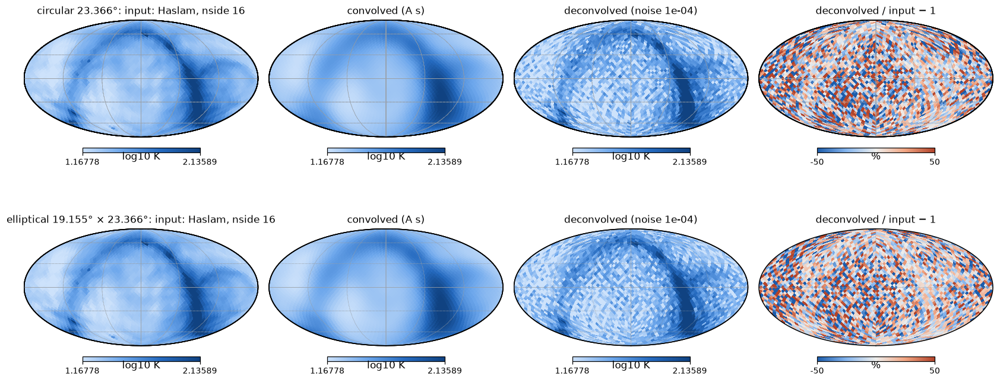

In [ ]:
# Convolve and deconvolve Haslam with both beams, at three noise levels.
D_NOISE = (1e-2, 1e-4, 1e-6)
rng = np.random.default_rng(14)
D_CONV, D_DECONV = {}, {}
for name, A in D_A.items():
    c = A @ D_HASLAM
    D_CONV[name] = c
    for rel in D_NOISE:
        sigma = rel * np.abs(c)
        data = c + rng.normal(0.0, 1.0, c.size) * sigma
        x, _ = wiener_filter_map(data, A, noise_variance=sigma ** 2,
                                 prior_inv_cov=1.0 / D_HASLAM.mean() ** 2, guess=np.full(D_NPIX, c.mean()))
        D_DECONV[name, rel] = x

D_BAND = load_stage1(config)["band_mask"].astype(bool)
def pct(a, b):
    return 100 * (a / b - 1)
print(f"{'beam':<30}{'map':<26}{'rms vs input':>14}{'max |Δ|':>10}{'rms in TRIS stripe':>20}")
for name in D_A:
    for label, m in [("convolved", D_CONV[name])] + [(f"deconvolved, noise {rel:.0e}", D_DECONV[name, rel]) for rel in D_NOISE]:
        d = pct(m, D_HASLAM)
        print(f"{name:<30}{label:<26}{np.std(d):13.2f}%{np.max(np.abs(d)):9.1f}%{np.std(d[D_BAND]):19.2f}%")

REL = 1e-4      # the noise level shown in the maps below
lo, hi = np.percentile(D_HASLAM, [2, 98])
fig = plt.figure(figsize=(15, 6.4))
for row, name in enumerate(D_A):
    panels = [("input: Haslam, nside 16", np.log10(D_HASLAM), SEQB, np.log10(lo), np.log10(hi), "log10 K"),
              ("convolved (A s)", np.log10(D_CONV[name]), SEQB, np.log10(lo), np.log10(hi), "log10 K"),
              (f"deconvolved (noise {REL:.0e})", np.log10(np.clip(D_DECONV[name, REL], lo / 10, None)), SEQB,
               np.log10(lo), np.log10(hi), "log10 K"),
              ("deconvolved / input − 1", pct(D_DECONV[name, REL], D_HASLAM), DIVB, -50, 50, "%")]
    for col, (title, m, cmap, a, b, unit) in enumerate(panels):
        hp.mollview(m, sub=(2, 4, 4 * row + col + 1), fig=fig.number, cmap=cmap, min=a, max=b, unit=unit,
                    title=f"{name}: {title}" if col == 0 else title, notext=True)
        hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.3)
plt.show()

**Reading the maps.** In the convolved maps (2nd column) the plane is smeared over 20°, and
the elliptical one is visibly sharper north–south. The deconvolved maps (3rd column)
restore the plane's width and the bright regions. The difference (4th column) is not a
smooth error but **pixel-scale noise**: modes the beam suppressed below the noise come back
as amplified noise, not as sky. The table above gives the numbers, for the whole sky and
for the TRIS stripe.

---
### The difference between the two beams

**Top row:** elliptical minus circular, in percent of the **input** map. Left, convolved:
the effect of the beam *shape* on what an instrument sees, or on what stage 2 hands the SED
fit. Middle, deconvolved: what is left after map-making, at noise 10⁻⁴. Right, the
deconvolved difference after smoothing both to 10°, the scale the deconvolution actually
preserves (next section).

The percentage is of the input, not of one of the outputs: a deconvolved map is noisy
enough to pass through zero in places, and dividing by it would blow the ratio up.

**Bottom row:** each map against the input, for both beams. Left, convolved; right,
deconvolved (noise 10⁻⁴). These are pixel histograms of map / input − 1.

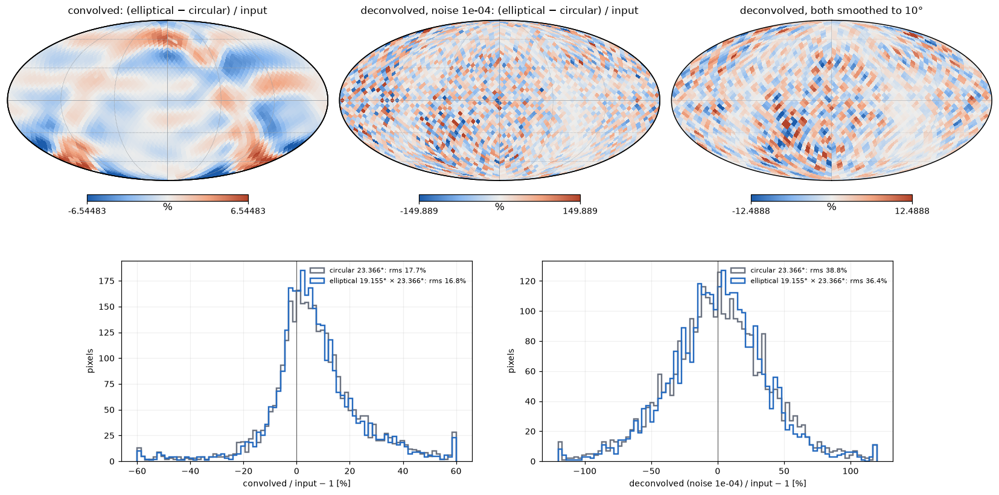

convolved                    (elliptical − circular)/input: rms   1.92%, max |Δ|   11.5%, TRIS stripe rms   1.76%
deconvolved, noise 1e-04     (elliptical − circular)/input: rms  50.32%, max |Δ|  238.4%, TRIS stripe rms  48.18%
deconvolved, both at 10°     (elliptical − circular)/input: rms   4.16%, max |Δ|   24.7%, TRIS stripe rms   3.90%


In [ ]:
names = list(D_A)
sm10 = lambda v: hp.smoothing(v, fwhm=np.radians(10.0), iter=3)
d_conv = 100 * (D_CONV[names[1]] - D_CONV[names[0]]) / D_HASLAM
d_dec = 100 * (D_DECONV[names[1], REL] - D_DECONV[names[0], REL]) / D_HASLAM
d_dec10 = 100 * (sm10(D_DECONV[names[1], REL]) - sm10(D_DECONV[names[0], REL])) / sm10(D_HASLAM)
fig = plt.figure(figsize=(15, 8.4))
for k, (d, title) in enumerate(((d_conv, "convolved: (elliptical − circular) / input"),
                                (d_dec, f"deconvolved, noise {REL:.0e}: (elliptical − circular) / input"),
                                (d_dec10, "deconvolved, both smoothed to 10°"))):
    span = float(np.percentile(np.abs(d), 99))
    hp.mollview(d, sub=(2, 3, k + 1), fig=fig.number, cmap=DIVB, min=-span, max=span, unit="%",
                title=title, notext=True)
    hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.3)
for k, (label, getter, bins) in enumerate((("convolved", lambda n: D_CONV[n], np.linspace(-60, 60, 81)),
                                            (f"deconvolved (noise {REL:.0e})", lambda n: D_DECONV[n, REL], np.linspace(-120, 120, 81)))):
    ax = fig.add_subplot(2, 2, 3 + k)
    for name in names:
        d = pct(getter(name), D_HASLAM)
        ax.hist(np.clip(d, bins[0], bins[-1]), bins=bins, histtype="step", color=D_COL[name],
                label=f"{name}: rms {np.std(d):.1f}%")
    ax.axvline(0, color="0.4")
    ax.set_xlabel(f"{label} / input − 1 [%]"); ax.set_ylabel("pixels")
    ax.legend(); ax.grid(alpha=0.2)
plt.subplots_adjust(hspace=0.45, top=0.95, bottom=0.07)
plt.show()
for label, d in (("convolved", d_conv), (f"deconvolved, noise {REL:.0e}", d_dec), ("deconvolved, both at 10°", d_dec10)):
    print(f"{label:<28} (elliptical − circular)/input: rms {np.std(d):6.2f}%, max |Δ| {np.max(np.abs(d)):6.1f}%, "
          f"TRIS stripe rms {np.std(d[D_BAND]):6.2f}%")

---
### Which scales come back

The question "has the map changed?" has a different answer at every angular scale.

* **Left: the transfer function** $C_\ell(\hat s)/C_\ell(s)$: how much power the
  deconvolved map has at each ℓ relative to the input. 1 means the power is restored; above
  1 means noise has been added. The convolved maps (dashed) show the beam's own
  suppression, $\approx b_\ell^2$.
* **Middle: the correlation** $r_\ell = C_\ell(\hat s, s)/\sqrt{C_\ell(\hat s)C_\ell(s)}$:
  whether the structure at each ℓ is the *right* structure. The dotted line is r = 0.9.
* **Right: by angular scale in the map.** Both the deconvolved map and the input are
  smoothed with a Gaussian of the FWHM on the x axis, and the rms of their ratio is plotted.
  The error at a given resolution is where the curve sits; the scale where it drops below a
  few percent is the resolution the round trip actually preserves.

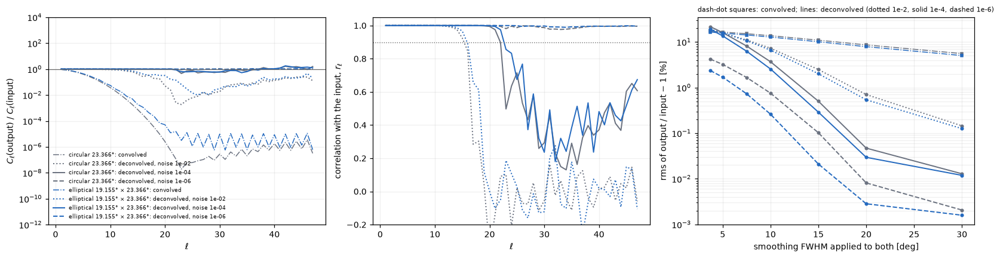

highest ℓ with r_ℓ ≥ 0.9 (the scale ~180°/ℓ):
  circular 23.366°               noise 1e-02: ℓ = 15  (~12°)
  circular 23.366°               noise 1e-04: ℓ = 21  (~9°)
  circular 23.366°               noise 1e-06: ℓ = 47  (~4°)
  elliptical 19.155° × 23.366°   noise 1e-02: ℓ = 15  (~12°)
  elliptical 19.155° × 23.366°   noise 1e-04: ℓ = 22  (~8°)
  elliptical 19.155° × 23.366°   noise 1e-06: ℓ = 47  (~4°)


In [ ]:
D_CL_IN = hp.anafast(D_HASLAM - D_HASLAM.mean(), lmax=3 * D_NS - 1)
ell = np.arange(D_CL_IN.size)
D_LGOOD = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.0))
fwhms = np.array([3.7, 5, 7.5, 10, 15, 20, 30])
ls_noise = {1e-2: ":", 1e-4: "-", 1e-6: "--"}
for name in D_A:
    c = D_CONV[name]
    axes[0].semilogy(ell[1:], (hp.anafast(c - c.mean(), lmax=ell[-1]) / D_CL_IN)[1:], "-.", color=D_COL[name],
                     label=f"{name}: convolved")
    for rel in D_NOISE:
        x = D_DECONV[name, rel]
        clx = hp.anafast(x - x.mean(), lmax=ell[-1])
        cross = hp.anafast(x - x.mean(), D_HASLAM - D_HASLAM.mean(), lmax=ell[-1])
        r = cross / np.sqrt(clx * D_CL_IN)
        bad = np.flatnonzero(r[1:] < 0.9)
        D_LGOOD[name, rel] = int(bad[0]) if bad.size else int(ell[-1])
        axes[0].semilogy(ell[1:], (clx / D_CL_IN)[1:], ls_noise[rel], color=D_COL[name],
                         label=f"{name}: deconvolved, noise {rel:.0e}")
        axes[1].plot(ell[1:], r[1:], ls_noise[rel], color=D_COL[name])
        err = [np.std(pct(hp.smoothing(x, fwhm=np.radians(f), iter=3), hp.smoothing(D_HASLAM, fwhm=np.radians(f), iter=3)))
               for f in fwhms]
        axes[2].semilogy(fwhms, err, ls_noise[rel], marker="o", ms=3, color=D_COL[name])
    err_c = [np.std(pct(hp.smoothing(c, fwhm=np.radians(f), iter=3), hp.smoothing(D_HASLAM, fwhm=np.radians(f), iter=3)))
             for f in fwhms]
    axes[2].semilogy(fwhms, err_c, "-.", marker="s", ms=3, color=D_COL[name])
axes[0].axhline(1, color="0.4"); axes[0].set_ylim(1e-12, 1e4)
axes[0].set_xlabel("ℓ"); axes[0].set_ylabel("$C_\\ell$(output) / $C_\\ell$(input)")
axes[0].legend(ncol=1, loc="lower left")
axes[1].axhline(0.9, color="0.4", ls=":"); axes[1].set_ylim(-0.2, 1.05)
axes[1].set_xlabel("ℓ"); axes[1].set_ylabel("correlation with the input, $r_\\ell$")
axes[2].set_xlabel("smoothing FWHM applied to both [deg]"); axes[2].set_ylabel("rms of output / input − 1 [%]")
axes[2].set_title("dash-dot squares: convolved; lines: deconvolved (dotted 1e-2, solid 1e-4, dashed 1e-6)",
                  loc="left")
for ax in axes:
    ax.grid(alpha=0.2, which="both")
plt.tight_layout(); plt.show()
print("highest ℓ with r_ℓ ≥ 0.9 (the scale ~180°/ℓ):")
for (name, rel), lg in D_LGOOD.items():
    print(f"  {name:<30} noise {rel:.0e}: ℓ = {lg:2d}  (~{180 / max(lg, 1):.0f}°)")

---
### Every map

The same round trip for every map the SED fit uses, at noise 10⁻⁴, with both beams. The
operator needs a full sky, but most surveys are partial. So each unobserved pixel is
filled with a straight-line fit of that survey against Haslam over the pixels it did
observe (a T–T fit), which keeps the fill continuous at the mask edge. **Every number is
computed over the observed pixels only.** ARCADE 2 covers 7% of the sky, so its map is
93% fill and its numbers describe the ring alone.

Bars: rms of map / input − 1 over observed pixels: convolved (light), deconvolved (dark),
and deconvolved after 10° smoothing of both (hatched), per beam.

map                                obs px    conv   deconv   @10°    conv   deconv   @10°  (ell − circ)/input: conv  deconv   @10°
                                                 circular 23.366°  elliptical 19.155° × 2
LWA1 35 MHz                          2464   10.6%    31.7%   2.9%   10.0%    30.4%   2.0%                      1.2%   43.8%   3.5%
LWA1 38 MHz                          2464   11.3%    33.1%   2.8%   10.6%    33.9%   2.2%                      1.3%   46.8%   3.5%
LWA1 40 MHz                          2464   11.7%    32.8%   2.9%   10.9%    32.6%   2.2%                      1.4%   45.0%   3.6%
LWA1 45 MHz                          2464   12.7%    35.9%   3.1%   11.9%    35.8%   2.6%                      1.5%   50.2%   3.9%
Maipu + MU 45 MHz                    2920   11.1%    32.9%   3.0%   10.5%    33.6%   2.2%                      1.2%   46.8%   3.8%
LWA1 50 MHz                          2464   13.1%    34.4%   2.9%   12.2%    34.4%   2.3%                      1.5%   48.8% 

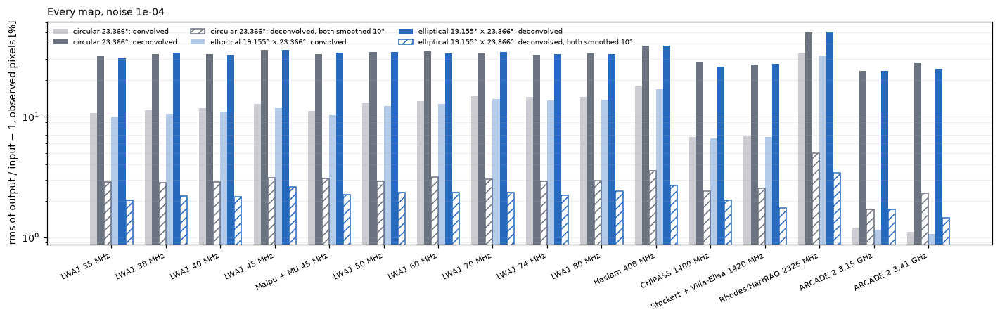

In [ ]:
D_ALL = []
for m in H_MAPS:
    rotated, obs = rotated_equatorial(m)
    vals, kept = regrid_to_nside(np.where(obs, rotated, hp.UNSEEN), obs, D_NS)
    a, b = np.polyfit(D_HASLAM[kept], vals[kept], 1)
    s = np.where(kept, vals, a * D_HASLAM + b)
    row = dict(name=m["name"], n_obs=int(kept.sum()))
    for name, A in D_A.items():
        c = A @ s
        sigma = REL * np.abs(c)
        x, _ = wiener_filter_map(c + rng.normal(0.0, 1.0, c.size) * sigma, A, noise_variance=sigma ** 2,
                                 prior_inv_cov=1.0 / np.mean(np.abs(s)) ** 2, guess=np.full(D_NPIX, c.mean()))
        sm = lambda v: hp.smoothing(v, fwhm=np.radians(10.0), iter=3)
        row[name] = dict(conv=np.std(pct(c, s)[kept]), deconv=np.std(pct(x, s)[kept]),
                         deconv10=np.std(pct(sm(x), sm(s))[kept]), conv_vs=None)
        row[name, "conv"], row[name, "deconv"] = c, x
    # elliptical − circular, as a percentage of the input (a deconvolved map can cross zero)
    row["beam_conv"] = np.std((100 * (row[names[1], "conv"] - row[names[0], "conv"]) / s)[kept])
    row["beam_deconv"] = np.std((100 * (row[names[1], "deconv"] - row[names[0], "deconv"]) / s)[kept])
    row["beam_deconv10"] = np.std((100 * (sm(row[names[1], "deconv"]) - sm(row[names[0], "deconv"])) / sm(s))[kept])
    D_ALL.append(row)

print(f"{'map':<34}{'obs px':>7}" + "".join(f"{'conv':>8}{'deconv':>9}{'@10°':>7}" for _ in names)
      + f"{'(ell − circ)/input: conv':>26}{'deconv':>8}{'@10°':>7}")
print(f"{'':<41}" + "".join(f"{n[:22]:>24}" for n in names))
for r in D_ALL:
    print(f"{r['name']:<34}{r['n_obs']:7d}" + "".join(f"{r[n]['conv']:7.1f}%{r[n]['deconv']:8.1f}%{r[n]['deconv10']:6.1f}%" for n in names)
          + f"{r['beam_conv']:25.1f}%{r['beam_deconv']:7.1f}%{r['beam_deconv10']:6.1f}%")

fig, ax = plt.subplots(figsize=(13, 4.2))
x0 = np.arange(len(D_ALL))
w = 0.13
for j, name in enumerate(names):
    off = (j - 0.5) * 3 * w
    ax.bar(x0 + off - w, [r[name]["conv"] for r in D_ALL], width=w, color=D_COL[name], alpha=0.35,
           label=f"{name}: convolved")
    ax.bar(x0 + off, [r[name]["deconv"] for r in D_ALL], width=w, color=D_COL[name],
           label=f"{name}: deconvolved")
    ax.bar(x0 + off + w, [r[name]["deconv10"] for r in D_ALL], width=w, color="white", edgecolor=D_COL[name],
           hatch="///", label=f"{name}: deconvolved, both smoothed 10°")
ax.set_xticks(x0); ax.set_xticklabels([r["name"] for r in D_ALL], rotation=25, ha="right")
ax.set_ylabel("rms of output / input − 1, observed pixels [%]"); ax.set_yscale("log")
ax.legend(ncol=3); ax.grid(axis="y", alpha=0.2, which="both")
ax.set_title(f"Every map, noise {REL:.0e}", loc="left")
plt.tight_layout(); plt.show()

---
### Along the TRIS ring (LST), with the pipeline's own noise

The same round trip, now asking **where along the ring** the maps change. TRIS is a zenith
drift scan, so the sky it sees at a given LST is the sky at RA = LST and Dec = +42.4°.
Each panel follows the nside 16 pixels on the TRIS ring's declination (Dec +41.8°) and
plots map / input − 1 against LST:

* **dashed:** the convolved map (circular grey, elliptical blue);
* **solid:** the deconvolved map.

**Noise: the error bars the pipeline actually uses** (`sed_prototype.sigma_for`):

* ARCADE 2: its calibration uncertainty, 7.5 mK (3.15 GHz) and 6.0 mK (3.41 GHz);
* LWA1, Maipu, CHIPASS, Stockert, Rhodes: each survey's own published temperature-scale,
  zero-level and noise errors in quadrature (`sed_prototype.PUBLISHED_ERRORS`). Before
  2026-10-21 this was an assumed **10%** (`ASSUMED_FRACTION`), and the saved outputs
  below were made with that 10%;
* Haslam is the target and never gets an error bar in the fit; here it is given its
  published 10% scale and 3 K zero level.

The noise is drawn per pixel with σ computed from the convolved value. The same σ is given
to limTOD's `wiener_filter_map`, with the same weak prior as above. Grey bands: where a
survey has no data on the ring. Partial maps are filled there as before and the lines are
not drawn.

Galactic plane crossings on the ring at LST ≈ 76°, 312°
no data on the ring (not plotted): CHIPASS 1400 MHz, Rhodes/HartRAO 2326 MHz


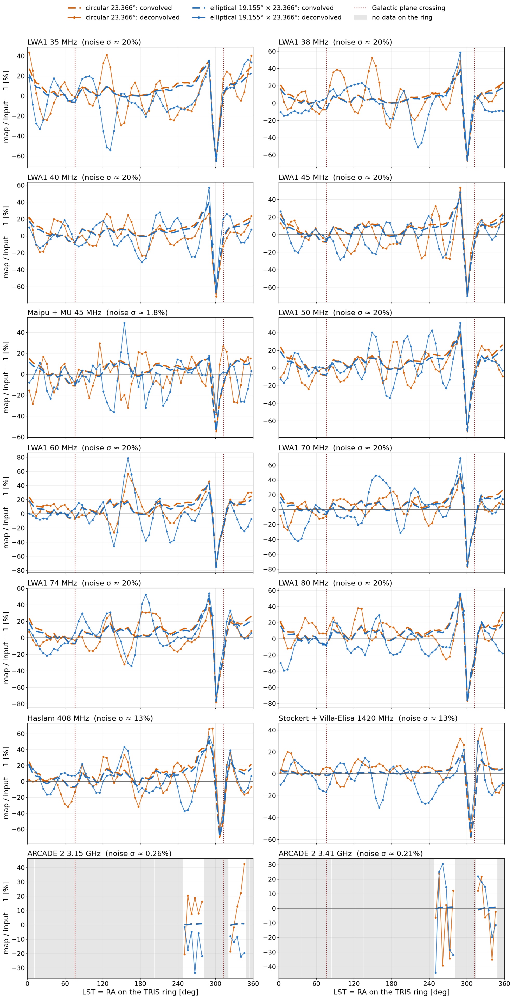

ring at Dec +41.8°, 64 pixels. rms of map / input − 1 along the ring (observed pixels):
map                                  noise     conv   deconv     conv   deconv   (circular | elliptical)
LWA1 35 MHz                            20%    14.4%    19.6%    13.5%    20.3%
LWA1 38 MHz                            20%    13.9%    20.2%    13.2%    20.0%
LWA1 40 MHz                            20%    14.1%    16.7%    13.4%    17.9%
LWA1 45 MHz                            20%    14.6%    16.9%    13.9%    17.5%
Maipu + MU 45 MHz                     1.8%    11.2%    14.7%    10.4%    15.3%
LWA1 50 MHz                            20%    15.1%    17.1%    14.2%    20.0%
LWA1 60 MHz                            20%    16.1%    19.0%    15.3%    23.8%
LWA1 70 MHz                            20%    16.2%    17.3%    15.6%    24.9%
LWA1 74 MHz                            20%    16.5%    19.2%    15.9%    21.8%
LWA1 80 MHz                            20%    17.2%    18.7%    16.8%    19.5%
Haslam 408 MHz   

In [ ]:
from moonrunes.sed_prototype import sigma_for, ASSUMED_FRACTION

ring_dec = D_DEC[np.argmin(np.abs(D_DEC - BORESIGHT_DEC))]
RING = np.flatnonzero(np.isclose(D_DEC, ring_dec))
RING = RING[np.argsort(D_RA[RING])]
LST = D_RA[RING]
rng_lst = np.random.default_rng(2026)
D_LST = []
for m in H_MAPS:
    rotated, obs = rotated_equatorial(m)
    vals, kept = regrid_to_nside(np.where(obs, rotated, hp.UNSEEN), obs, D_NS)
    a, b = np.polyfit(D_HASLAM[kept], vals[kept], 1)
    s = np.where(kept, vals, a * D_HASLAM + b)
    out = dict(name=m["name"], kept=kept[RING], s=s[RING])
    for name, A in D_A.items():
        c = A @ s
        sigma = np.maximum(sigma_for(m, sky_maps.rj_excess(c, m)), 1e-6)
        x, _ = wiener_filter_map(c + rng_lst.normal(0.0, 1.0, c.size) * sigma, A, noise_variance=sigma ** 2,
                                 prior_inv_cov=1.0 / np.mean(np.abs(s)) ** 2, guess=np.full(D_NPIX, c.mean()))
        out[name] = dict(conv=pct(c, s)[RING], deconv=pct(x, s)[RING], sigma=np.median(sigma[RING] / np.abs(c[RING])))
    D_LST.append(out)

# Where the ring crosses the Galactic plane (|b| smallest), to read the plots against.
theta_g, _ = hp.Rotator(coord=["C", "G"])(np.radians(90 - ring_dec) * np.ones(RING.size), np.radians(LST))
b_ring = 90 - np.degrees(theta_g)            # Galactic latitude of each ring pixel
PLANE = [LST[k] for k in range(LST.size) if abs(b_ring[k]) < 5 and abs(b_ring[k]) <= abs(b_ring[k - 1])
         and abs(b_ring[k]) <= abs(b_ring[(k + 1) % LST.size])]
no_ring = [r["name"] for r in D_LST if not r["kept"].any()]
D_LST_SHOWN = [r for r in D_LST if r["kept"].any()]
print(f"Galactic plane crossings on the ring at LST ≈ {', '.join(f'{v:.0f}°' for v in PLANE)}")
print(f"no data on the ring (not plotted): {', '.join(no_ring) if no_ring else 'none'}")

n = len(D_LST_SHOWN)
# Big fonts (twice the notebook default) and four clearly different lines:
# colour = beam (orange circular, blue elliptical); style = convolved (thick dashed)
# vs deconvolved (solid with markers).
LST_COL = {list(D_A)[0]: "#d95f02", list(D_A)[1]: "#1b6ec2"}
FS = 18
ncol = 2
nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(18, 5.0 * nrow), sharex=True, squeeze=False)
for ax, r in zip(axes.ravel(), D_LST_SHOWN):
    for v in PLANE:
        ax.axvline(v, color="#7f1d1d", ls=":", lw=2)
    for lst_, k in zip(LST, r["kept"]):
        if not k:
            ax.axvspan(lst_ - 2.8, lst_ + 2.8, color="0.9", lw=0)
    for name in D_A:
        conv = np.where(r["kept"], r[name]["conv"], np.nan)
        dec = np.where(r["kept"], r[name]["deconv"], np.nan)
        ax.plot(LST, dec, "-", color=LST_COL[name], marker="o", ms=4, alpha=0.85)
        ax.plot(LST, conv, "--", color=LST_COL[name], lw=3.2, dashes=(6, 3))
    ax.axhline(0, color="0.3")
    ax.set_title(f"{r['name']}  (noise σ ≈ {100 * r[list(D_A)[0]]['sigma']:.2g}%)", loc="left", fontsize=FS)
    ax.tick_params(labelsize=FS - 2)
    ax.grid(alpha=0.25)
for ax in axes.ravel()[n:]:
    ax.axis("off")
for ax in axes.ravel()[max(0, n - ncol):n]:
    ax.set_xlabel("LST = RA on the TRIS ring [deg]", fontsize=FS)
    ax.set_xlim(0, 360); ax.set_xticks(np.arange(0, 361, 60))
    ax.tick_params(labelbottom=True)
for ax in axes[:, 0]:
    ax.set_ylabel("map / input − 1 [%]", fontsize=FS)
handles = []
for nm in D_A:
    handles.append(plt.Line2D([], [], color=LST_COL[nm], ls="--", dashes=(6, 3), lw=3.2, label=f"{nm}: convolved"))
    handles.append(plt.Line2D([], [], color=LST_COL[nm], ls="-", marker="o", ms=5, label=f"{nm}: deconvolved"))
handles.append(plt.Line2D([], [], color="#7f1d1d", ls=":", lw=2, label="Galactic plane crossing"))
handles.append(plt.Rectangle((0, 0), 1, 1, color="0.9", label="no data on the ring"))
fig.legend(handles=handles, loc="upper center", ncol=3, fontsize=FS - 2,
           bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(rect=(0, 0, 1, 1 - 1.3 / (5.0 * nrow + 1.3)))
plt.show()

print(f"ring at Dec {ring_dec:+.1f}°, {RING.size} pixels. rms of map / input − 1 along the ring (observed pixels):")
print(f"{'map':<34}{'noise':>8}" + "".join(f"{'conv':>9}{'deconv':>9}" for _ in D_A) + "   (circular | elliptical)")
for r in D_LST_SHOWN:
    k = r["kept"]
    print(f"{r['name']:<34}{100 * r[list(D_A)[0]]['sigma']:7.2g}%" +
          "".join(f"{np.std(r[nm]['conv'][k]):8.1f}%{np.std(r[nm]['deconv'][k]):8.1f}%" for nm in D_A))

**Reading the LST plot (run 2026-10-14).** The Galactic plane crossings are at LST ≈ 76°
(Perseus–Auriga) and 312° (Cygnus). CHIPASS and Rhodes/HartRAO have no data on the TRIS
ring's declination, so they are not plotted.

* **Convolving changes the maps almost only near the bright plane at Cygnus.**
  * Between LST ≈ 270° and 330°, every survey's convolved map drops by 45–80% on the
    brightest pixels (LST ≈ 305°). It rises by 15–55% on the pixels just before, where the
    beam spreads the emission.
  * Elsewhere on the ring the convolved maps are within about ±20%, mostly ±10%.
  * The fainter Perseus crossing (76°) barely shows.
  * ARCADE 2, already at 11.6°, changes by under 1% where it has data.
* **Elliptical and circular convolved maps are nearly identical along the ring.** The ring
  runs east–west, along the H plane, where both beams are 23.366°. The beams differ only
  north–south, so the shape matters off the ring's declination, not along it.
* **Deconvolving does not give the ring back pixel by pixel.** With the pipeline's own
  noise (10% for LWA, Maipu and Haslam, 2.8% for Stockert, 0.2–0.3% for ARCADE 2), the
  deconvolved maps scatter by 10–25% rms around the input along the ring:
  * the scatter is not concentrated at the plane;
  * it is the pixel-scale noise of the previous sections, at every LST.

  10% noise is large, so the noise-dominated scales start at a lower ℓ than at 10⁻⁴.
  Stockert, with the smallest relative noise among the full-ring surveys, comes back
  closest (12% rms circular, 11% elliptical).
* **The elliptical beam's deconvolved maps are a little closer to the input** for most
  surveys (Haslam 22.7% against 24.5%; Maipu 18.0% against 19.7%). LWA1 80 MHz is the
  exception (24.0% against 18.8%).

---
#### Reading this section (run 2026-10-14)

**1. limTOD's convolution is what the pipeline uses.** **A s** equals `generate_TOD_sky`
to 4×10⁻¹⁶.

**2. Convolving changes the maps, as it should.** Haslam through the circular beam differs
from the input by 17.7% rms (14.3% in the TRIS stripe), and through the elliptical beam by
16.8% (13.3%). The other maps lose 1–33%, depending on how much small-scale structure they
have; ARCADE 2, already at 11.6°, loses about 1%.

**3. Deconvolving does *not* give the maps back pixel by pixel.**

| beam | noise 10⁻² | 10⁻⁴ | 10⁻⁶ |
|---|---|---|---|
| circular: deconvolved / input − 1, rms | 23.2% | 38.8% | 14.4% |
| elliptical | 24.8% | 36.5% | 13.8% |

That is *worse* than the convolved map (~17%). The error is pixel-scale, amplified noise:
modes the beam suppressed below the noise come back multiplied by 1/(singular value).
Noise 10⁻⁴ looks worse than 10⁻² at the pixel level only because the weak prior holds
back more of those modes at 10⁻²; by scale, 10⁻⁴ is better.

**4. By scale, the round trip is very good on large scales and fails on small ones.**

* **Correlation with the input stays ≥ 0.9 up to:** ℓ = 15 (~12°) at noise 10⁻²,
  ℓ = 21–22 (~8–9°) at 10⁻⁴, and ℓ = 47 (every scale on the grid) at 10⁻⁶.
* **Compared at 10° resolution,** the deconvolved Haslam (noise 10⁻⁴) matches the input
  to 3.8% rms (circular) and **2.8%** (elliptical).
  * Every other map: 2.1–5.3% (circular) and **1.7–3.4%** (elliptical).
  * At 20° resolution, 0.05% and 0.03%.
* **The map "changes" only at scales the beam suppressed below the noise.** Those scales
  are lost and cannot be recovered by any deconvolution.

**5. The two beams.**

* **The elliptical beam passes more sky.** It has 377 modes above 10⁻² of the largest
  singular value (circular: 320), and 1959 above 10⁻⁴ (circular: 1855). It recovers about
  one ℓ further at noise 10⁻⁴, and its deconvolved maps are closer to the input at 10° for
  **every** map (2.8% against 3.8% on Haslam).
* **Convolved:** elliptical and circular differ by **1.9% rms** of the input (max 11.5%,
  1.8% in the TRIS stripe). This is the beam-shape effect on what the instrument sees, the
  same order as the stage 2 kernel change measured earlier in this notebook.
* **Deconvolved:** the difference is noise-dominated at pixel level (50% rms). At 10° it
  is 4.2% rms: the two maps carry the same large-scale sky, with different noise.

**What this means for the pipeline.**

* **Stage 1 is this deconvolution, under much worse conditions.** It solves for TRIS maps
  from one ring at one declination, not from 3072 pointings covering the sky. Its maps can
  only be trusted on scales the ring constrains. They cannot be compared pixel by pixel
  with surveys matched to the TRIS *instrument* beam. This is `TODO.md` N-10, now with a
  measured scale: even full-sky sampling at the TRIS rings' noise level (~10⁻⁴) preserves
  structure only to ~8–9°.
* **Matching to the beam is a convolution, and it is stable.** Stage 2 and the TOD route
  only ever convolve, and that is exactly reproducible (point 1).
* **The elliptical beam is measurably better** at every noise level, both at passing
  structure and at recovering it.

---
## Two-step against one-step beam matching

> **Note (2026-10-14):** the config uses `beam_matching.kernel: circular_gaussian`, the kernel of the current stage 2 product. "Default" below means the elliptical `tris_cuts` kernel's status when this section ran; the elliptical kernels are implemented and tested but not in use.

**The test.** A real survey is never a perfect Gaussian: it has an elliptical main lobe,
sidelobes and a broad error beam. Stage 2 knows only one number about it, its quoted FWHM,
and builds its kernel from that. So, with **the pipeline's own convolution**
(`stage2_beam_matching.match_to_tris_beam`, the function stage 2 and the map route call),
compare two scenarios:

1. **Two-step:** sky → convolved with a complicated, non-Gaussian survey beam → matched to
   the TRIS target by the pipeline, which is told the survey beam's FWHM.
2. **One-step:** the same sky → matched to the TRIS target by the pipeline directly
   (native beam: Haslam's 0.933°).

Ideally both give the same map. Any difference is what the pipeline gets wrong about a
survey whose beam is not the Gaussian it assumes.

**The sky:** Haslam in equatorial on nside 64 (the pipeline's working grid), used as the
"true" sky in both scenarios.

**Two native beams for step 1:**

| | shape | FWHM given to the pipeline |
|---|---|---|
| **control** | circular Gaussian, 5° | 5° |
| **complicated** | elliptical Gaussian main lobe 5° × 3° at position angle 30°; a first sidelobe ring at 7° from the centre, 1.5° wide, −15 dB; a broad error beam, 20° FWHM at −25 dB | 5° (the main lobe's major axis, measured) |

The control isolates what the kernel rule itself does. For a Gaussian native beam the
quadrature rule is exact for the Gaussian kernels, so any difference there comes from the
kernel shape. The complicated beam adds what a real survey beam would.

**Three pipeline kernels**, each run through both scenarios:

* **circular Gaussian** (`circular_gaussian`, the old stage 2);
* **elliptical Gaussian** (`elliptical_gaussian`);
* **measured TRIS beam** (`tris_cuts`, the default). For a 5° native beam it uses the cut
  beam compressed to the quadrature widths (`scaled_cuts`).

Step 1's convolution is done by direct summation on the nside 64 grid. It is not part of
the pipeline; it only plays the survey's own beam.

complicated beam: major-axis FWHM 5.010°, minor-axis FWHM 3.007°
complicated beam: 17.6% of its weight is outside the main lobe (sidelobe ring + error beam)


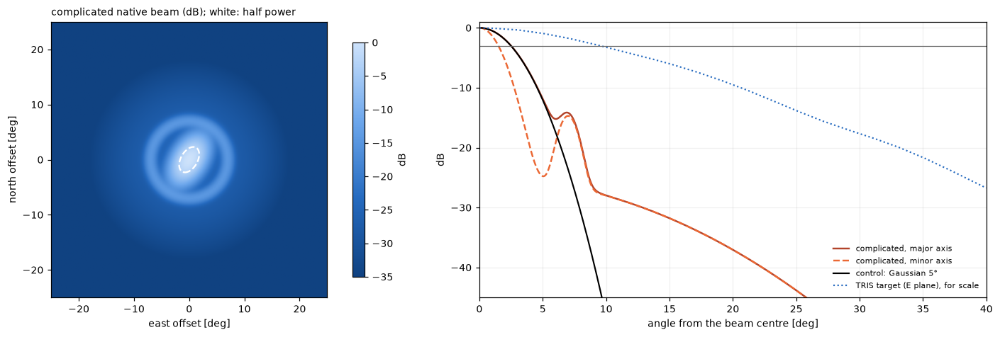

In [ ]:
from moonrunes.stage2_beam_matching import match_to_tris_beam
K_ = 2.0 * np.sqrt(2.0 * np.log(2.0))
NS64 = 64
SKY64 = hp.ud_grade(HASLAM_C, NS64)
ONES64 = np.ones(SKY64.size, bool)
PTS64 = np.array(hp.pix2vec(NS64, np.arange(SKY64.size))).T
TS_BAND = load_stage1(config)["band_mask"].astype(bool)

CB = dict(major=5.0, minor=3.0, pa=30.0, ring_r=7.0, ring_w=1.5, ring_db=-15.0,
          shoulder_fwhm=20.0, shoulder_db=-25.0)

def complicated_beam(theta, psi):
    # Elliptical main lobe (major axis at position angle CB["pa"]) + a sidelobe ring + a broad error beam.
    phi = np.radians(np.asarray(psi) - CB["pa"])
    sa, sb = CB["major"] / K_, CB["minor"] / K_
    main = np.exp(-0.5 * ((theta * np.cos(phi) / sa) ** 2 + (theta * np.sin(phi) / sb) ** 2))
    ring = 10 ** (CB["ring_db"] / 10) * np.exp(-0.5 * ((theta - CB["ring_r"]) / (CB["ring_w"] / K_)) ** 2)
    shoulder = 10 ** (CB["shoulder_db"] / 10) * np.exp(-0.5 * (theta / (CB["shoulder_fwhm"] / K_)) ** 2)
    return np.where(theta <= 90.0, main + ring + shoulder, 0.0)

def gaussian_beam(theta, psi, fwhm=5.0):
    return np.where(theta <= 90.0, np.exp(-0.5 * (theta / (fwhm / K_)) ** 2), 0.0)

def convolve_native(sky, beam_fn, chunk=256):
    # Direct sum on the nside 64 grid: out(p) = sum_q B(p, q) T(q) / sum_q B(p, q).
    out = np.empty(sky.size)
    for s in range(0, len(PTS64), chunk):
        th, psi = eb.local_offsets(PTS64[s:s + chunk], PTS64)
        w = beam_fn(th, psi)
        out[s:s + chunk] = (sky @ w) / w.sum(axis=0)
    return out

theta_line = np.arange(0.0, 40.0, 0.01)
CB_FWHM = fwhm_from_profile(theta_line, complicated_beam(theta_line, np.full(theta_line.size, CB["pa"])))
NATIVE = {"Gaussian 5° (control)": (gaussian_beam, 5.0),
          "complicated": (complicated_beam, CB_FWHM)}
print(f"complicated beam: major-axis FWHM {CB_FWHM:.3f}°, minor-axis FWHM "
      f"{fwhm_from_profile(theta_line, complicated_beam(theta_line, np.full(theta_line.size, CB['pa'] + 90))):.3f}°")
# Fraction of the complicated beam's weight outside its main lobe (integrated over the sphere).
th = np.arange(0.0, 90.0, 0.05) + 0.025
P = np.arange(0.0, 360.0, 1.0)
T, PP = np.meshgrid(th, P, indexing="ij")
w_all = (complicated_beam(T, PP).mean(axis=1) * np.sin(np.radians(th)))
phi_ = np.radians(PP - CB["pa"])
w_main = (np.exp(-0.5 * ((T * np.cos(phi_) / (CB["major"] / K_)) ** 2 + (T * np.sin(phi_) / (CB["minor"] / K_)) ** 2)).mean(axis=1)
          * np.sin(np.radians(th)))
print(f"complicated beam: {100 * (1 - w_main.sum() / w_all.sum()):.1f}% of its weight is outside the main lobe "
      f"(sidelobe ring + error beam)")

# The beams, for the record: image of the complicated beam, and profiles against the control and the TRIS target.
fig = plt.figure(figsize=(14, 4.4))
ax = fig.add_subplot(1, 2, 1)
axis = np.arange(-25, 25.01, 0.1)
X, Y = np.meshgrid(axis, axis)
img = complicated_beam(np.hypot(X, Y), np.degrees(np.arctan2(X, Y)))
db = np.clip(10 * np.log10(np.maximum(img, 1e-6)), -35, 0)
im = ax.imshow(db, origin="lower", extent=[axis[0], axis[-1], axis[0], axis[-1]], cmap=SEQB.reversed(), vmin=-35, vmax=0)
ax.contour(X, Y, db, levels=[HALF_DB], colors="white")
ax.set_xlabel("east offset [deg]"); ax.set_ylabel("north offset [deg]"); ax.set_aspect("equal")
ax.set_title("complicated native beam (dB); white: half power", loc="left")
fig.colorbar(im, ax=ax, shrink=0.85, label="dB")
ax = fig.add_subplot(1, 2, 2)
ax.plot(theta_line, 10 * np.log10(complicated_beam(theta_line, np.full(theta_line.size, CB["pa"]))), color="#b2432a",
        label="complicated, major axis")
ax.plot(theta_line, 10 * np.log10(complicated_beam(theta_line, np.full(theta_line.size, CB["pa"] + 90))), color="#eb6834",
        ls="--", label="complicated, minor axis")
ax.plot(theta_line, 10 * np.log10(gaussian_beam(theta_line, 0)), color=COLORS["ink"], label="control: Gaussian 5°")
k_t = eb.kernel_for(SPEC_CUTS, 0.0)
ax.plot(theta_line, 10 * np.log10(np.maximum(eb.kernel_response(k_t, SPEC_CUTS, theta_line, np.full(theta_line.size, PA_E)), 1e-9)),
        color="#256abf", ls=":", label="TRIS target (E plane), for scale")
ax.axhline(HALF_DB, color="0.4")
ax.set_xlim(0, 40); ax.set_ylim(-45, 1); ax.set_xlabel("angle from the beam centre [deg]"); ax.set_ylabel("dB")
ax.legend(); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

step 1 (native beams) done in 171 s


pipeline matching done in 358 s

native beam             pipeline kernel              median     rms  max |Δ|  stripe rms  kernel the pipeline chose
Gaussian 5° (control)   circular Gaussian (old)      +0.00%   0.02%    0.05%       0.01%  circular 22.82°
Gaussian 5° (control)   elliptical Gaussian          +0.01%   0.02%    0.07%       0.02%  elliptical_gaussian 18.49° × 22.82°
Gaussian 5° (control)   TRIS cuts (measured)         -0.05%   0.14%    0.44%       0.11%  tris_cuts 18.49° × 22.82°
complicated             circular Gaussian (old)      +0.16%   0.45%    1.46%       0.37%  circular 22.82°
complicated             elliptical Gaussian          +0.18%   0.52%    1.81%       0.43%  elliptical_gaussian 18.49° × 22.82°
complicated             TRIS cuts (measured)         +0.11%   0.29%    1.13%       0.24%  tris_cuts 18.49° × 22.82°


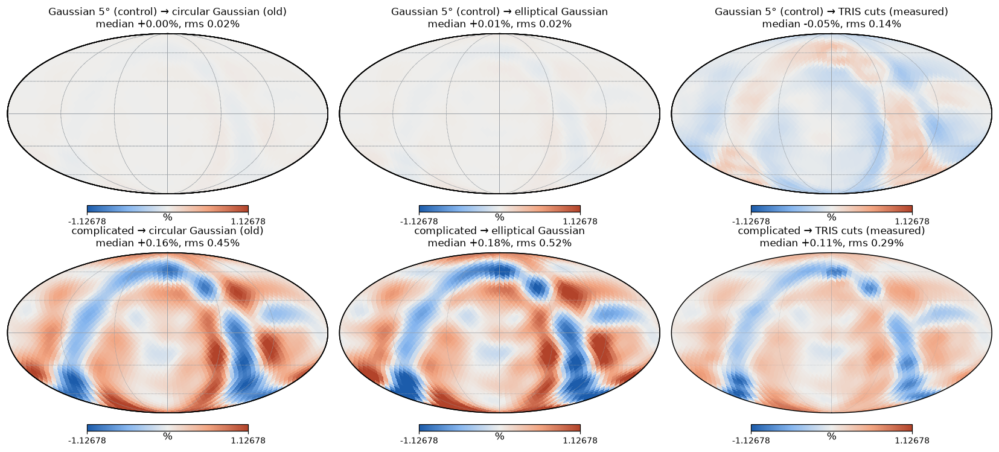

In [ ]:
# Run both scenarios through the pipeline's own beam matching, for all three kernels.
t0 = time.time()
PRE = {name: convolve_native(SKY64, fn) for name, (fn, _) in NATIVE.items()}
print(f"step 1 (native beams) done in {time.time() - t0:.0f} s")

def pipeline(sky, native_fwhm, label):
    spec = None if KERNEL_KEY[label] == "circular_gaussian" else SPECS[label]
    v, kept, info = match_to_tris_beam(sky, ONES64, native_fwhm, CONFIGS[label], nside_out=16,
                                       rule="all_children", spec=spec, full_sky=True)
    return np.where(kept, v, np.nan), info

TS_DIRECT = {label: pipeline(SKY64, HASLAM_NATIVE, label) for label in SPECS}
TS_TWO = {(nat, label): pipeline(PRE[nat], fw, label) for nat, (_, fw) in NATIVE.items() for label in SPECS}
print(f"pipeline matching done in {time.time() - t0:.0f} s\n")

TS_DIFF = {key: 100 * (TS_TWO[key][0] / TS_DIRECT[key[1]][0] - 1) for key in TS_TWO}
print(f"{'native beam':<24}{'pipeline kernel':<26}{'median':>9}{'rms':>8}{'max |Δ|':>9}{'stripe rms':>12}  kernel the pipeline chose")
for (nat, label), d in TS_DIFF.items():
    info = TS_TWO[nat, label][1]
    chose = (f"circular {info['extra_fwhm_deg']:.2f}°" if info["kernel"] == "circular_gaussian"
             else f"{info['kernel_shape']} {info['kernel_fwhm_e_deg']:.2f}° × {info['kernel_fwhm_h_deg']:.2f}°")
    print(f"{nat:<24}{label:<26}{np.nanmedian(d):+8.2f}%{np.nanstd(d):7.2f}%{np.nanmax(np.abs(d)):8.2f}%"
          f"{np.nanstd(d[TS_BAND]):11.2f}%  {chose}")

span = float(np.nanpercentile(np.abs(np.concatenate([d for d in TS_DIFF.values()])), 99))
fig = plt.figure(figsize=(15, 6.6))
for r, nat in enumerate(NATIVE):
    for c, label in enumerate(SPECS):
        d = TS_DIFF[nat, label]
        hp.mollview(d, sub=(2, 3, 3 * r + c + 1), fig=fig.number, cmap=DIVB, min=-span, max=span, unit="%",
                    title=f"{nat} → {label}\nmedian {np.nanmedian(d):+.2f}%, rms {np.nanstd(d):.2f}%", notext=True)
        hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.3)
plt.show()

**What the maps show.** Each panel is the nside 16 product made in two steps (native beam,
then the pipeline) divided by the one made in one step, minus 1. The top row is the
Gaussian control and the bottom row the complicated beam; the columns are the pipeline's
three kernels. White means the two scenarios agree.

**Along the TRIS ring, and as a summary.** Left: the same ratio along the TRIS ring
(LST = RA at Dec +41.8°), for the complicated beam, one line per kernel. Right: the rms
and the largest difference over the TRIS stripe, every case.

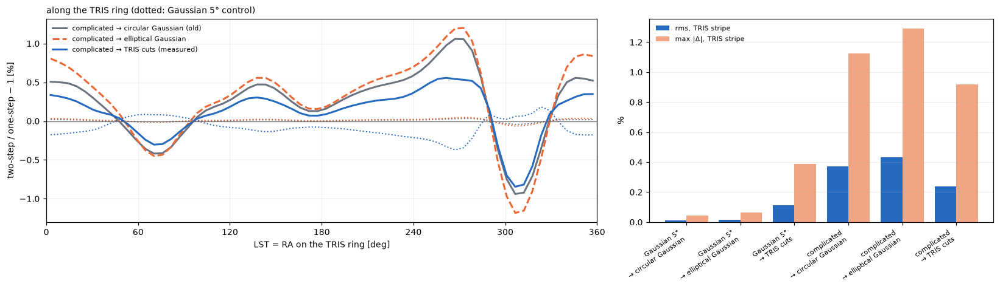

In [ ]:
ring_dec16 = None
_, dec16 = hp.pix2ang(16, np.arange(hp.nside2npix(16)), lonlat=True)
ring_dec16 = dec16[np.argmin(np.abs(dec16 - BORESIGHT_DEC))]
ring16 = np.flatnonzero(np.isclose(dec16, ring_dec16))
ra16 = hp.pix2ang(16, ring16, lonlat=True)[0]
order = np.argsort(ra16); ring16, ra16 = ring16[order], ra16[order]

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw=dict(width_ratios=[1.6, 1]))
style = {"circular Gaussian (old)": ("#6b7280", "-"), "elliptical Gaussian": ("#eb6834", "--"),
         "TRIS cuts (measured)": ("#256abf", "-")}
for label in SPECS:
    c, ls = style[label]
    ax.plot(ra16, TS_DIFF["complicated", label][ring16], ls, color=c, lw=2, label=f"complicated → {label}")
    ax.plot(ra16, TS_DIFF["Gaussian 5° (control)", label][ring16], ":", color=c)
ax.axhline(0, color="0.4")
ax.set_xlim(0, 360); ax.set_xticks(np.arange(0, 361, 60))
ax.set_xlabel("LST = RA on the TRIS ring [deg]"); ax.set_ylabel("two-step / one-step − 1 [%]")
ax.set_title("along the TRIS ring (dotted: Gaussian 5° control)", loc="left")
ax.legend(); ax.grid(alpha=0.2)

keys = list(TS_DIFF)
xs = np.arange(len(keys))
ax2.bar(xs - 0.2, [np.nanstd(TS_DIFF[k][TS_BAND]) for k in keys], width=0.4, color="#256abf", label="rms, TRIS stripe")
ax2.bar(xs + 0.2, [np.nanmax(np.abs(TS_DIFF[k][TS_BAND])) for k in keys], width=0.4, color="#f2a582", label="max |Δ|, TRIS stripe")
ax2.set_xticks(xs); ax2.set_xticklabels([f"{n.split(' (')[0]}\n→ {l.split(' (')[0]}" for n, l in keys], rotation=35,
                                        ha="right")
ax2.set_ylabel("%"); ax2.legend(); ax2.grid(axis="y", alpha=0.2)
plt.tight_layout(); plt.show()

**Two-step against one-step, maps side by side (complicated survey beam).** Top row:
the circular Gaussian kernel. Bottom row: the elliptical Gaussian kernel. Left: two-step
(sky → complicated beam → pipeline). Middle: one-step (sky → pipeline directly). Right:
the residual between them, two-step − one-step, in kelvin. Both rows share one temperature scale
(log₁₀ T) and one residual scale.


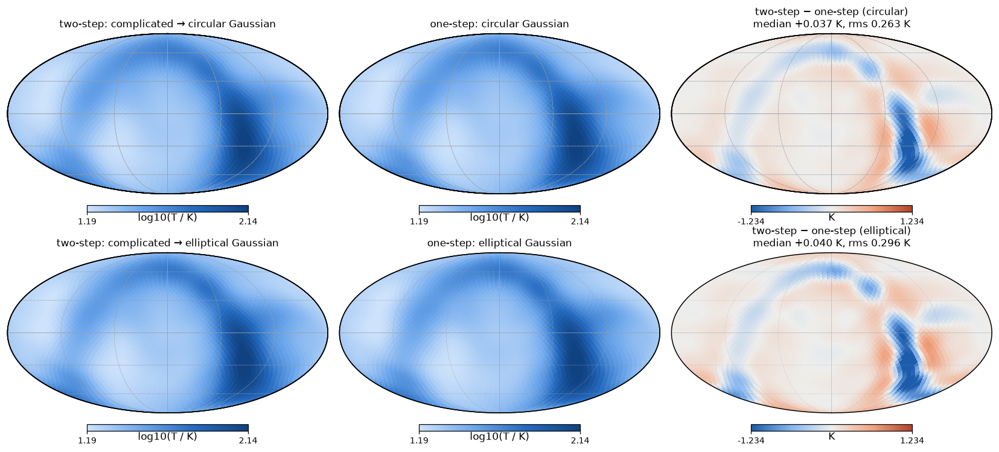

circular    two-step − one-step: median +0.0373 K, rms 0.2633 K, max |Δ| 1.6134 K
elliptical  two-step − one-step: median +0.0401 K, rms 0.2962 K, max |Δ| 1.8728 K


In [ ]:
ROWS = ["circular Gaussian (old)", "elliptical Gaussian"]
SHORT = {"circular Gaussian (old)": "circular", "elliptical Gaussian": "elliptical"}
both_maps = [m for label in ROWS for m in (TS_TWO["complicated", label][0], TS_DIRECT[label][0])]
tlo, thi = np.nanpercentile(np.log10(np.concatenate(both_maps)), [0.5, 99.5])
RES_K = {label: TS_TWO["complicated", label][0] - TS_DIRECT[label][0] for label in ROWS}   # two-step − one-step [K]
rspan = float(np.nanpercentile(np.abs(np.concatenate(list(RES_K.values()))), 99))

fig = plt.figure(figsize=(15, 6.6))
for r, label in enumerate(ROWS):
    two, one, d = TS_TWO["complicated", label][0], TS_DIRECT[label][0], RES_K[label]
    k = SHORT[label]
    hp.mollview(np.log10(two), sub=(2, 3, 3 * r + 1), fig=fig.number, min=tlo, max=thi,
                unit="log10(T / K)", format="%.2f", title=f"two-step: complicated → {k} Gaussian", notext=True)
    hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.3)
    hp.mollview(np.log10(one), sub=(2, 3, 3 * r + 2), fig=fig.number, min=tlo, max=thi,
                unit="log10(T / K)", format="%.2f", title=f"one-step: {k} Gaussian", notext=True)
    hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.3)
    hp.mollview(d, sub=(2, 3, 3 * r + 3), fig=fig.number, cmap=DIVB, min=-rspan, max=rspan, unit="K", format="%.3f",
                title=f"two-step − one-step ({k})\nmedian {np.nanmedian(d):+.3f} K, rms {np.nanstd(d):.3f} K",
                notext=True)
    hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.3)
plt.show()
for label in ROWS:
    print(f"{SHORT[label]:<11} two-step − one-step: median {np.nanmedian(RES_K[label]):+.4f} K, rms {np.nanstd(RES_K[label]):.4f} K, "
          f"max |Δ| {np.nanmax(np.abs(RES_K[label])):.4f} K")


#### Reading this section (run 2026-10-14)

**Ideally the two scenarios agree. With a Gaussian survey beam they do; with a realistic,
non-Gaussian one they differ by a fraction of a percent.**

| survey beam | pipeline kernel | two-step / one-step − 1: median | rms | max \|Δ\| | rms in TRIS stripe |
|---|---|---|---|---|---|
| Gaussian 5° (control) | circular Gaussian | +0.00% | 0.02% | 0.05% | 0.01% |
| Gaussian 5° (control) | elliptical Gaussian | +0.01% | 0.02% | 0.07% | 0.02% |
| Gaussian 5° (control) | measured TRIS beam (default) | −0.05% | 0.14% | 0.44% | 0.11% |
| complicated | circular Gaussian | +0.16% | 0.45% | 1.46% | 0.37% |
| complicated | elliptical Gaussian | +0.18% | 0.52% | 1.81% | 0.43% |
| complicated | measured TRIS beam (default) | +0.11% | 0.29% | 1.13% | 0.24% |

* **The pipeline's convolution composes correctly.** With a Gaussian survey beam, the
  Gaussian kernels give the same map either way to 0.02% rms. The quadrature rule is
  exact there, and what remains is pixelisation.
* **The default measured-beam kernel is approximate even for a Gaussian survey beam**
  (0.14% rms, 0.44% max). Compressing the cut beam to the quadrature widths is not an
  exact deconvolution, the same effect plot 4 of the elliptical-beam section measured as
  a 2.4% wider effective FWHM for a 4.65° survey beam. On the map it is a fraction of a
  percent, because most of the sky's structure is on scales much larger than the beam.
* **A complicated survey beam is mis-modelled by every kernel**, by 0.3–0.5% rms and up
  to 1.1–1.8%. The pipeline is told only the main lobe's 5° FWHM. The sidelobe ring and
  error beam (17.6% of this beam's weight) smooth the map further, and nothing removes that.
  * **The pattern:** the two-step map is *lower* along the Galactic plane, where the extra
    smoothing pulls emission out (blue ridges), and *higher* just off it (red).
  * **Along the TRIS ring** the error is largest at the Cygnus crossing: −0.8 to −1.2% at
    LST ≈ 305°, and +0.5 to +1.2% beside it.
  * **The measured-beam kernel comes out best here** (0.29% rms, against 0.45–0.52%). Why
    has not been established, and with one test beam it should not be read as a general
    property of the kernel.

**What this means.** The beam matching is consistent: matching in one step or two gives
the same answer when the survey beam is what the pipeline thinks it is. When a survey's
real beam has significant sidelobes or an error beam, using its FWHM alone costs about
0.3–0.5% rms, and up to ~1–2% at the bright plane. That is small next to the 10%
error bars assumed for most surveys and the 13–18% Haslam offset. It is comparable to the
kernel-shape effects measured above. A survey whose beam is published in full (like
TRIS's) could have it used directly instead of its FWHM.

---
---
## How much does the T-vs-LST curve depend on how the beam is specified?

*Added 2026-11-02.* Full-sky models are re-observed through several versions of the TRIS cut beam with the TOD
route's own observation code, `sed_prototype.Inputs._native_tod` (as notebooks 12 and 14 do), and the ring TODs
are compared. Each variant uses the same measured cuts (FWHM 19.155° in the E plane, 23.366° in the H plane).

**How the baseline interpolates.** The `tris_cuts` kernel (`elliptical_beam.cut_response`, `blend: db`) and limTOD's
`tris_cut_beam_map`, which `_native_tod` observes with, do the same thing. Each measured cut is interpolated linearly
in θ, in dB. At an angle φ from the E plane the two dB values are then averaged with weights cos²φ (E) and sin²φ (H),
so the beam is linear in dB between the planes.

**The variants, and how each is set.** The beam map is never rotated. It is drawn with the boresight at the pole and
the E plane at φ = 0. The roll is set once, in the geometry: `tris.tris_zenith_geometry(ra,
e_plane_east_of_meridian_deg=roll)`, which gives `selfrot = −roll` (azimuth 0, elevation 90).

| Variant | E plane (east of the meridian) | Beam between the planes | How it is set |
|---|---|---|---|
| V0 baseline | +7° | dB blend | `tris_cut_beam_map(cuts, blend="db")`, roll 7 (exactly the TOD route's beam and geometry) |
| V1 | −7° (west) | dB blend | roll −7 |
| V2 | 0° (on the meridian) | dB blend | roll 0 |
| V3 planes swapped | 97° (H at 7°) | dB blend | roll 97: an extreme bound, for scale only |
| V4a | +7° | FWHM(φ)⁻² = cos²φ/FWHM_E² + sin²φ/FWHM_H² | see below, roll 7 |
| V4b | +7° | linear in power: B = B_E(θ)cos²φ + B_H(θ)sin²φ | `tris_cut_beam_map(cuts, blend="power")`, roll 7 |
| V4c | +7° | FWHM linear in φ, from FWHM_E at 0° to FWHM_H at 90° | see below, roll 7 |

**V4a and V4c are FWHM rules, so a full beam has to be built for them.** Both keep the dB blend, but each cut is
stretched in θ so that the half-power width at φ is exactly FWHM(φ):
B = 10^([cos²φ E_dB(θ FWHM_E/F(φ)) + sin²φ H_dB(θ FWHM_H/F(φ))]/10). On the principal planes the stretch is 1, so
the beam there is the measured cut, sidelobes included.

**Is any of V4 a duplicate of V0?** No, so none is dropped.
* V4a is what the dB blend gives if both cuts are Gaussian. On the measured cuts the two differ: at φ = 45° the
  half-power width is 21.19° for V0 and 20.95° for V4a.
* V4b is limTOD's other `blend` option.
* V4c gives 21.26° at φ = 45°.

The first code cell prints the widths at five angles.

**Sky models** (CMB removed, RJ K, made as notebooks 12 and 14 do):
* Haslam (uncorrected, `HASLAM_DESTRIPED_ONLY.fits`) at 408 MHz.
* GSM2016 (pygdsm, TRJ, `include_cmb=False`) at the TRIS effective frequencies, 600.5 and 817.8 MHz.

**Ring:** the 120 TRIS samples (RA = LST, 3° steps, Dec 42.433°).
* A sample is used when its beam coverage is ≥ 0.5.
* RA 299.9 ± 25° (17 samples) is left out of every statistic and shaded in the figures.
* The TRIS rings and their σ (`ring_sigma`) come from notebook 12's fit cache (read only).

**Caveats.**
* Neighbouring samples are 3° apart under a ~20° beam, so they are strongly correlated; the counts and rms values
  below are not independent numbers.
* The full-sky models are not the data.
* This section describes the sizes and positions of the differences only, not their causes.
* Percentages and σ-units appear here only because this test asks for them.

**Files** (in `test_outputs/beam_variants/`):
* `figA_T_vs_RA_beam_variants.png`, `figB_difference_from_V0.png`.
* `table3_difference_from_V0.csv`, `table4_model_vs_TRIS_score.csv`.
* The per-variant TODs are cached in `cache/` (keyed on the variant definitions), so a rerun takes seconds.

In [ ]:
# Setup for this section.  Self-contained apart from `REPO`, `config` and `tris` (first cell).
import json, time
import pandas as pd
from moonrunes import sed_prototype as sp, sky_maps

BV_OUT = REPO / "test_outputs" / "beam_variants"            # CSVs and PNGs of this section
BV_CACHE = BV_OUT / "cache"                             # the per-variant ring TODs
BV_OUT.mkdir(parents=True, exist_ok=True)
BV_CACHE.mkdir(exist_ok=True)
FIT_CACHE = REPO / "paper_outputs" / "pipeline" / "step5_fit" / "fits"   # run_pipeline.py step 5: TRIS rings, read only
HASLAM_FILE = "HASLAM_DESTRIPED_ONLY.fits"
COV_MIN = sp.MIN_COVERAGE                    # 0.5, as notebooks 12 and 14
MASK_RA, MASK_HALF = 299.9, 25.0             # left out of every statistic (shaded in the figures)

BV_ARCHIVE = config.resolve_path("paths.tris_archive_dir")
BV_CUTS = tris.read_tris_beam_cuts(BV_ARCHIVE / "TRIS_Beam_Profile.txt")
BV_RA = np.asarray(tris.read_tris_ring(BV_ARCHIVE / "TRIS_absolute_600.txt").ra_deg, dtype=float)
BV_MASK = np.abs((BV_RA - MASK_RA + 180.0) % 360.0 - 180.0) <= MASK_HALF
BV_NSIDE = int(config.require("tris.nside"))
BV_HIRES = int(config.require("tris.nside_hires"))

# The cuts, sorted, and their half-power widths (linear interpolation in dB, as the beam code does).
_o = np.argsort(BV_CUTS.angle_deg)
CUT_ANG = np.asarray(BV_CUTS.angle_deg, dtype=float)[_o]
CUT_E = np.asarray(BV_CUTS.e_plane_db, dtype=float)[_o]
CUT_H = np.asarray(BV_CUTS.h_plane_db, dtype=float)[_o]

def half_power_width(db):
    # 2 x the first angle where the cut falls to -3.0103 dB
    k = int(np.argmax(db <= -10 * np.log10(2)))
    return 2 * np.interp(-10 * np.log10(2), [db[k], db[k - 1]], [CUT_ANG[k], CUT_ANG[k - 1]])

FWHM_E, FWHM_H = half_power_width(CUT_E), half_power_width(CUT_H)
assert abs(FWHM_E - 19.155) < 0.01 and abs(FWHM_H - 23.366) < 0.01, (FWHM_E, FWHM_H)
print(f"cut FWHM: E plane {FWHM_E:.3f} deg, H plane {FWHM_H:.3f} deg")

# --- the beam, as a function of (theta, phi): phi from the E plane, as limTOD's beam map -----------
def fwhm_rule(phi_deg, rule):
    # FWHM(phi) of the alternative interpolations V4a and V4c
    c2 = np.cos(np.radians(phi_deg)) ** 2
    if rule == "elliptical":                     # FWHM^-2 = cos^2/FWHM_E^2 + sin^2/FWHM_H^2
        return 1.0 / np.sqrt(c2 / FWHM_E**2 + (1 - c2) / FWHM_H**2)
    if rule == "linear_angle":                   # linear in the angle from the E plane, 0..90 deg
        folded = np.degrees(np.arctan2(np.abs(np.sin(np.radians(phi_deg))), np.abs(np.cos(np.radians(phi_deg)))))
        return FWHM_E + (FWHM_H - FWHM_E) * folded / 90.0
    raise ValueError(rule)

def beam_response(theta_deg, phi_deg, interp):
    # "db" and "power" are limTOD's own tris_cut_beam_response.  The FWHM rules keep the dB blend
    # but stretch each cut in theta so that the half-power width at phi is exactly FWHM(phi):
    #   B = 10^([cos^2 phi E_dB(theta FWHM_E/F(phi)) + sin^2 phi H_dB(theta FWHM_H/F(phi))] / 10).
    # Both stretched cuts are at -3 dB at theta = F(phi)/2, so the blend is too; on the principal
    # planes (stretch 1) the beam is the measured cut, sidelobes included.
    theta, phi = np.asarray(theta_deg, dtype=float), np.asarray(phi_deg, dtype=float)
    if interp in ("db", "power"):
        return tris.tris_cut_beam_response(BV_CUTS, theta, phi, blend=interp)
    f = fwhm_rule(phi, interp)
    e = np.interp(np.minimum(theta * FWHM_E / f, 180.0), CUT_ANG, CUT_E, left=CUT_E[0], right=CUT_E[-1])
    h = np.interp(np.minimum(theta * FWHM_H / f, 180.0), CUT_ANG, CUT_H, left=CUT_H[0], right=CUT_H[-1])
    w = np.cos(np.radians(phi)) ** 2
    return 10.0 ** ((e * w + h * (1 - w)) / 10.0)

def beam_map(interp, nside):
    # The beam as a HEALPix map with the boresight at the north pole and the E plane at phi = 0,
    # peak-normalised: tris_cut_beam_map's convention.  It is NOT rotated; the roll is the geometry's.
    if interp == "db":
        return tris.tris_cut_beam_map(BV_CUTS, nside=nside, normalization="peak")   # exactly the TOD route's beam
    if interp == "power":
        return tris.tris_cut_beam_map(BV_CUTS, nside=nside, blend="power", normalization="peak")
    th, ph = hp.pix2ang(nside, np.arange(hp.nside2npix(nside)))
    b = beam_response(np.degrees(th), np.degrees(ph), interp)
    return b / b.max()

# --- the variants: (E plane east of the meridian [deg], interpolation, label) -----------------------
VARIANTS = {
    "V0":  dict(roll=7.0,  interp="db",           label="V0 baseline: E at +7°, dB blend"),
    "V1":  dict(roll=-7.0, interp="db",           label="V1 E at −7° (west)"),
    "V2":  dict(roll=0.0,  interp="db",           label="V2 E on the meridian"),
    "V3":  dict(roll=97.0, interp="db",           label="V3 planes swapped: E at 97°, H at 7°"),
    "V4a": dict(roll=7.0,  interp="elliptical",   label="V4a elliptical FWHM rule"),
    "V4b": dict(roll=7.0,  interp="power",        label="V4b linear in power"),
    "V4c": dict(roll=7.0,  interp="linear_angle", label="V4c FWHM linear in angle"),
}
VCOL = {"V0": "black", "V1": "#0072B2", "V2": "#56B4E9", "V3": "#999999",
        "V4a": "#D55E00", "V4b": "#009E73", "V4c": "#CC79A7"}
VLS = {"V0": "-", "V1": "-", "V2": "--", "V3": ":", "V4a": "-", "V4b": "--", "V4c": "-."}

def geometry(roll):
    # The roll is set here and only here: tris_zenith_geometry(e_plane_east_of_meridian_deg = roll)
    # gives selfrot = -roll.  The beam map is never pre-rotated.
    return tris.tris_zenith_geometry(BV_RA, e_plane_east_of_meridian_deg=roll)

# FWHM against phi (from the E plane) for each interpolation, measured on the response itself.
_TH = np.arange(0.0, 30.0, 0.001)
def measured_fwhm(interp, phi):
    db = 10 * np.log10(beam_response(_TH, np.full(_TH.shape, phi), interp))
    return 2 * _TH[np.argmax(db <= -10 * np.log10(2))]

INTERPS = {"db": "V0 / V1–V3: dB blend (limTOD, tris_cuts)", "elliptical": "V4a elliptical FWHM rule",
           "power": "V4b linear in power", "linear_angle": "V4c FWHM linear in angle"}
PHI_TAB = [0.0, 22.5, 45.0, 67.5, 90.0]
fwhm_table = pd.DataFrame({lab: [measured_fwhm(k, p) for p in PHI_TAB] for k, lab in INTERPS.items()},
                          index=[f"phi = {p:g}°" for p in PHI_TAB]).T
print("\nFWHM [deg] of each interpolation, by angle phi from the E plane (position angle = 7° + phi):")
print(fwhm_table.round(3).to_string())

cut FWHM: E plane 19.155 deg, H plane 23.366 deg

FWHM [deg] of each interpolation, by angle phi from the E plane (position angle = 7° + phi):
                                          phi = 0°  phi = 22.5°  phi = 45°  phi = 67.5°  phi = 90°
V0 / V1–V3: dB blend (limTOD, tris_cuts)    19.156       19.722     21.192       22.742     23.368
V4a elliptical FWHM rule                    19.156       19.632     20.950       22.574     23.368
V4b linear in power                         19.156       19.784     21.332       22.806     23.368
V4c FWHM linear in angle                    19.156       20.208     21.262       22.314     23.368


#### Is each roll applied once, and where it was set?

Every variant's beam is pointed with limTOD's own pointing (`simulator.pointing_beam_in_eq_sys`, the call
`generate_TOD_sky` makes) at LST 180°, at nside 128. The cell then measures the position angle of the narrow axis
from the second moments of the main lobe (within 15° of the boresight).

A roll applied twice would put V0's narrow axis at 14°.

In [ ]:
# Check that each variant's roll lands where intended, applied once: point every variant's beam with
# limTOD's own pointing (simulator.pointing_beam_in_eq_sys, the call generate_TOD_sky makes) and
# measure the position angle (north through east) of the narrow axis from the main lobe's second moments.
from limTOD.simulator import pointing_beam_in_eq_sys
from moonrunes.elliptical_beam import local_offsets

CHECK_NSIDE, CHECK_LST = 128, 180.0
lat = float(geometry(7.0).latitude_deg)
centre = hp.ang2vec(np.radians(90.0 - lat), np.radians(CHECK_LST))
pix_vec = np.array(hp.pix2vec(CHECK_NSIDE, np.arange(hp.nside2npix(CHECK_NSIDE)))).T
theta_pix, pa_pix = (a[:, 0] for a in local_offsets(centre[None, :], pix_vec))

rows = []
for v, d in VARIANTS.items():
    g = geometry(d["roll"])
    pointed = pointing_beam_in_eq_sys(hp.map2alm(beam_map(d["interp"], CHECK_NSIDE)), CHECK_LST, lat,
                                      float(g.azimuth_deg[0]), float(g.elevation_deg[0]),
                                      float(g.selfrot_deg[0]), nside=CHECK_NSIDE, normalize=False)
    lobe = theta_pix < 15.0                               # a disc inside the main lobe (no threshold edge)
    e = theta_pix[lobe] * np.sin(np.radians(pa_pix[lobe]))
    n = theta_pix[lobe] * np.cos(np.radians(pa_pix[lobe]))
    w = pointed[lobe]
    cov = np.cov(np.vstack([e, n]), aweights=w)
    vals, vecs = np.linalg.eigh(cov)
    narrow = vecs[:, 0]                                   # smallest variance = the narrow axis
    pa = np.degrees(np.arctan2(narrow[0], narrow[1])) % 180.0
    expected = d["roll"] % 180.0
    rows.append(dict(variant=v, roll_set_deg=d["roll"], selfrot_deg=float(g.selfrot_deg[0]),
                     interpolation=d["interp"], narrow_axis_PA_measured=pa,
                     narrow_axis_PA_expected=expected,
                     off_by_deg=(pa - expected + 90) % 180 - 90))
roll_check = pd.DataFrame(rows).set_index("variant")
print(f"Pointed beam at LST {CHECK_LST:g}°, nside {CHECK_NSIDE}: narrow-axis position angle (deg, mod 180)")
print(roll_check.round(2).to_string())
assert np.all(np.abs(roll_check["off_by_deg"]) < 0.5), "a roll is not where it was set"
print("Every narrow axis is within 0.1° of the roll that was set, so the roll is applied once "
      "(twice would put V0 at 14°).")

Pointed beam at LST 180°, nside 128: narrow-axis position angle (deg, mod 180)
         roll_set_deg  selfrot_deg interpolation  narrow_axis_PA_measured  narrow_axis_PA_expected  off_by_deg
variant                                                                                                       
V0                7.0         -7.0            db                     7.03                      7.0        0.03
V1               -7.0          7.0            db                   172.97                    173.0       -0.03
V2                0.0         -0.0            db                   180.00                      0.0       -0.00
V3               97.0        -97.0            db                    96.96                     97.0       -0.04
V4a               7.0         -7.0    elliptical                     7.03                      7.0        0.03
V4b               7.0         -7.0         power                     7.03                      7.0        0.03
V4c               7.0         -7.

#### The ring TODs

The cell runs 7 variants × 3 sky models through `_native_tod` at the TOD route's nside 16 (`tris.nside`,
`tris.nside_hires`).

`RES_CHECK_NSIDE = 64` repeats every TOD with both values overridden in memory, to see how much of each difference is
the nside 16 grid. The config file is not edited. The nside 64 run takes about 2.5 minutes the first time; both runs
are cached.

In [ ]:
# The ring TODs of every sky model through every variant, with sed_prototype.Inputs._native_tod.
# A bare Inputs object carries only what _native_tod and observe() read (nside, nside_hires, the
# horizon mask, the beam map and the geometry), so the full Inputs (minutes) is not built; per variant
# only `beam` and `geom` change.  RES_CHECK_NSIDE repeats everything with nside and nside_hires
# overridden in memory, to see how much of each difference is the nside 16 grid.
RES_CHECK_NSIDE = 64          # None to skip

# TRIS rings (CMB-removed RJ) with ring_sigma and the effective frequencies, from notebook 12's fit cache.
BV_TRIS = {k: (np.full(BV_RA.size, np.nan), np.full(BV_RA.size, np.nan)) for k in ("TRIS_600", "TRIS_820")}
BV_NU = {}
for u in range(BV_RA.size):
    r = np.load(FIT_CACHE / f"unit{u:03d}__power_law.npz", allow_pickle=False)
    for k, nu, t, s in zip((str(x) for x in r["keys"]), r["nu"], r["t"], r["s"]):
        if k in BV_TRIS:
            BV_TRIS[k][0][u], BV_TRIS[k][1][u], BV_NU[k] = t, s, float(nu)

# Sky models: (label, frequency, TRIS ring it is compared with)
SKIES = {"Haslam 408":         (408.0, None),
         f"GSM2016 {BV_NU['TRIS_600']:g}": (BV_NU["TRIS_600"], "TRIS_600"),
         f"GSM2016 {BV_NU['TRIS_820']:g}": (BV_NU["TRIS_820"], "TRIS_820")}

def sky_map(name):
    # (CMB-removed RJ map in K, frame), as notebooks 12 and 14 make them
    if name.startswith("Haslam"):
        m = next(m for m in sky_maps.discover(REPO / "res") if m["file"] == HASLAM_FILE)
        return np.asarray(sky_maps.rj_excess(m["sky"], m), dtype=float), m["frame"]
    from pygdsm import GlobalSkyModel16
    nu = SKIES[name][0]
    return np.array(GlobalSkyModel16(freq_unit="MHz", data_unit="TRJ", include_cmb=False).generate(nu),
                    dtype=float), "G"

def observer(nside, hires):
    obs = object.__new__(sp.Inputs)
    obs.nside, obs.hires, obs.horizon = nside, hires, tris.tris_horizon_mask(nside)
    return obs

def variant_tods(nside, hires):
    obs, out = observer(nside, hires), {}
    maps = {n: sky_map(n) for n in SKIES}
    for v, d in VARIANTS.items():
        obs.beam, obs.geom = beam_map(d["interp"], nside), geometry(d["roll"])
        for n, (sky, frame) in maps.items():
            out[(v, n)] = obs._native_tod(dict(sky=sky, nside=hp.npix2nside(sky.size), frame=frame))
    return out

def cached_tods(nside, hires):
    key = json.dumps({"variants": VARIANTS, "skies": {n: s[0] for n, s in SKIES.items()}, "haslam": HASLAM_FILE,
                      "nside": nside, "nside_hires": hires, "observe": "Inputs._native_tod", "version": 1},
                     sort_keys=True)
    path, kpath = BV_CACHE / f"variant_tods_nside{nside}.npz", BV_CACHE / f"variant_tods_nside{nside}_key.json"
    if path.exists() and kpath.exists() and kpath.read_text() == key:
        z = np.load(path, allow_pickle=False)
        print(f"nside {nside}: loaded {os.path.relpath(path, REPO)}")
        return {(v, n): (z[f"tod__{v}__{i}"], z[f"cov__{v}__{i}"]) for v in VARIANTS for i, n in enumerate(SKIES)}
    t0 = time.time()
    out = variant_tods(nside, hires)
    np.savez(path, **{f"tod__{v}__{i}": out[(v, n)][0] for v in VARIANTS for i, n in enumerate(SKIES)},
             **{f"cov__{v}__{i}": out[(v, n)][1] for v in VARIANTS for i, n in enumerate(SKIES)})
    kpath.write_text(key)
    print(f"nside {nside}: {len(out)} TODs in {time.time() - t0:.0f} s, saved {os.path.relpath(path, REPO)}")
    return out

def valid(tods):
    # T with samples below COV_MIN set to NaN
    return {k: np.where(c >= COV_MIN, t, np.nan) for k, (t, c) in tods.items()}

BV_T = valid(cached_tods(BV_NSIDE, BV_HIRES))
BV_T_RES = valid(cached_tods(RES_CHECK_NSIDE, RES_CHECK_NSIDE)) if RES_CHECK_NSIDE else None

print(f"\nTRIS effective frequencies: {BV_NU}")
print(f"mask: RA {MASK_RA:g} ± {MASK_HALF:g}° ({int(BV_MASK.sum())} of {BV_RA.size} samples left out of the statistics)")
print(pd.DataFrame({n: [np.nanmean(np.where(BV_MASK, np.nan, BV_T[(v, n)])) for v in VARIANTS] for n in SKIES},
                   index=list(VARIANTS)).round(3).rename_axis("ring mean outside the mask [K]").to_string())

nside 16: loaded outputs/beam_variants/cache/variant_tods_nside16.npz
nside 64: loaded outputs/beam_variants/cache/variant_tods_nside64.npz

TRIS effective frequencies: {'TRIS_600': 600.5, 'TRIS_820': 817.8}
mask: RA 299.9 ± 25° (17 of 120 samples left out of the statistics)
                                Haslam 408  GSM2016 600.5  GSM2016 817.8
ring mean outside the mask [K]                                          
V0                                  24.997         12.846          7.559
V1                                  24.963         12.833          7.554
V2                                  24.976         12.838          7.556
V3                                  25.175         12.914          7.586
V4a                                 24.971         12.836          7.556
V4b                                 25.006         12.849          7.561
V4c                                 25.015         12.853          7.562


#### Figure A: T against RA (= LST) through every variant

V0 is in black. The differences are small next to the curve itself; Figure B shows them.

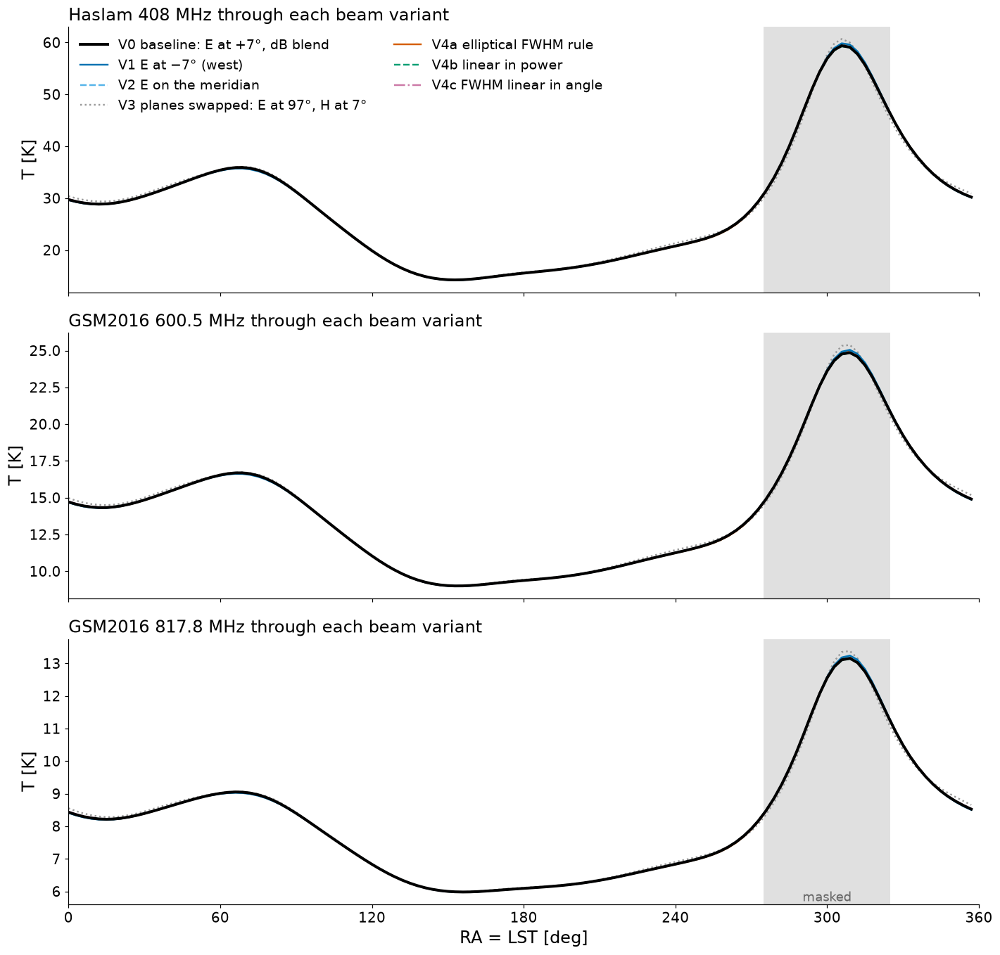

saved outputs/beam_variants/figA_T_vs_RA_beam_variants.png


In [ ]:
# Figure A: T against RA (= LST) through every variant, one panel per sky model.
BV_RC = {"font.size": 15, "axes.titlesize": 16, "axes.labelsize": 16, "legend.fontsize": 12.5,
         "xtick.labelsize": 13, "ytick.labelsize": 13}

def shade_mask(ax):
    lo, hi = MASK_RA - MASK_HALF, MASK_RA + MASK_HALF
    ax.axvspan(lo, hi, color="0.88", zorder=0, lw=0)
    if hi > 360:
        ax.axvspan(0, hi - 360, color="0.88", zorder=0, lw=0)

def bv_save(fig, name):
    fig.savefig(BV_OUT / f"{name}.png")
    plt.show()
    print(f"saved {os.path.relpath(BV_OUT / f'{name}.png', REPO)}")

with plt.rc_context(BV_RC):
    fig, axes = plt.subplots(len(SKIES), 1, figsize=(13, 4.2 * len(SKIES)), sharex=True)
    for ax, n in zip(axes, SKIES):
        shade_mask(ax)
        for v in reversed(list(VARIANTS)):                  # V0 drawn last, on top
            ax.plot(BV_RA, BV_T[(v, n)], color=VCOL[v], ls=VLS[v], lw=2.6 if v == "V0" else 1.6,
                    label=VARIANTS[v]["label"], zorder=3 if v == "V0" else 2)
        ax.set_ylabel("T [K]")
        ax.set_title(f"{n} MHz through each beam variant", loc="left")
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    h, l = axes[0].get_legend_handles_labels()
    axes[0].legend(h[::-1], l[::-1], ncol=2, loc="upper left")
    axes[-1].set_xlabel("RA = LST [deg]")
    axes[-1].set_xlim(0, 360); axes[-1].set_xticks(range(0, 361, 60))
    axes[-1].text(MASK_RA, axes[-1].get_ylim()[0], "masked", ha="center", va="bottom", fontsize=12, color="0.4")
    fig.tight_layout()
    bv_save(fig, "figA_T_vs_RA_beam_variants")

#### Figure B: each variant minus V0

The top row is in K and the bottom row in % of V0. The orange band is the TRIS ±1σ (`ring_sigma`) at that frequency:
about 0.067 K at 600.5 MHz and 0.430 K at 817.8 MHz. Haslam has no TRIS band. The masked RA range is shaded grey.

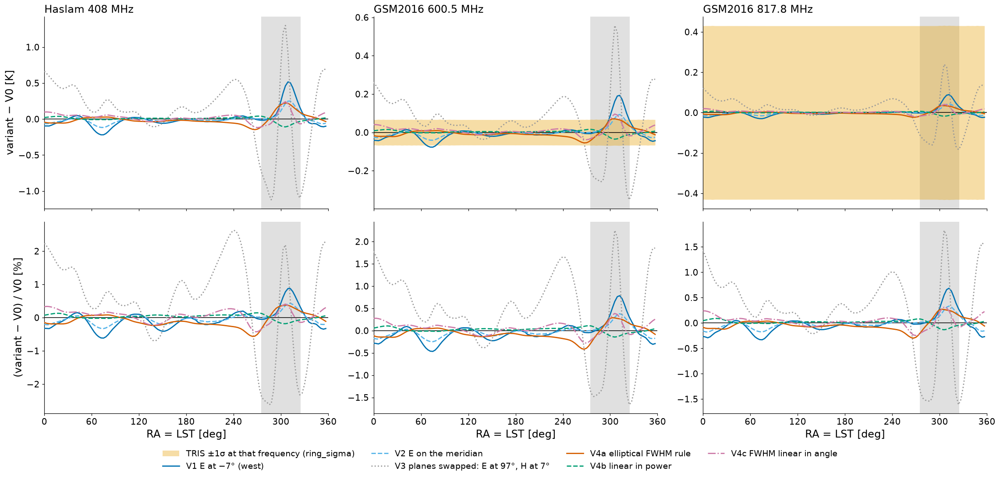

saved outputs/beam_variants/figB_difference_from_V0.png


In [ ]:
# Figure B: variant − V0 in K (top) and in % of V0 (bottom), with the TRIS ±1σ (ring_sigma) for the TRIS bands.
OTHERS = [v for v in VARIANTS if v != "V0"]

with plt.rc_context(BV_RC):
    fig, axes = plt.subplots(2, len(SKIES), figsize=(7 * len(SKIES), 9.5), sharex=True)
    for j, (n, (nu, tkey)) in enumerate(SKIES.items()):
        v0 = BV_T[("V0", n)]
        for i, ax in enumerate(axes[:, j]):
            shade_mask(ax)
            if i == 0 and tkey:
                s = BV_TRIS[tkey][1]
                ax.fill_between(BV_RA, -s, s, color="#E69F00", alpha=0.35, lw=0, zorder=1,
                                label="TRIS ±1σ at that frequency (ring_sigma)")
            ax.axhline(0, color=COLORS["ink"])
            for v in OTHERS:
                d = BV_T[(v, n)] - v0
                ax.plot(BV_RA, d if i == 0 else 100 * d / v0, color=VCOL[v], ls=VLS[v], lw=1.8,
                        label=VARIANTS[v]["label"], zorder=3)
            for side in ("top", "right"):
                ax.spines[side].set_visible(False)
        axes[0, j].set_title(f"{n} MHz", loc="left")
        axes[1, j].set_xlabel("RA = LST [deg]")
    axes[0, 0].set_ylabel("variant − V0 [K]")
    axes[1, 0].set_ylabel("(variant − V0) / V0 [%]")
    axes[-1, 0].set_xlim(0, 360); axes[-1, 0].set_xticks(range(0, 361, 60))
    h, l = axes[0, 1].get_legend_handles_labels()
    fig.legend(h, l, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.06))
    fig.tight_layout()
    bv_save(fig, "figB_difference_from_V0")

#### Table 3: size of the change from V0

The statistics use the samples outside the mask (103).
* **max |Δ|** is the signed value at the largest |Δ|.
* **rms in TRIS σ** is the rms over samples of (variant − V0)/`ring_sigma`.
* **samples with |Δ| > σ** counts samples where the change exceeds the TRIS σ at that sample.
* The **nside 64** columns repeat rms and max from the resolution check.

In [ ]:
# Table 3: variant − V0 per sky model, outside the mask and where both have coverage >= 0.5.
# "in TRIS σ" = rms over samples of (variant − V0) / ring_sigma, for the TRIS bands only.
def diff_stats(T, v, n):
    d = T[(v, n)] - T[("V0", n)]
    pct = 100 * d / T[("V0", n)]
    ok = np.isfinite(d) & ~BV_MASK
    k = np.flatnonzero(ok)[np.argmax(np.abs(d[ok]))]
    kp = np.flatnonzero(ok)[np.argmax(np.abs(pct[ok]))]
    tkey = SKIES[n][1]
    row = {"variant": v, "sky model": n, "samples": int(ok.sum()),
           "rms [K]": np.sqrt(np.mean(d[ok] ** 2)), "max |Δ| [K]": d[k], "RA of max [deg]": BV_RA[k],
           "rms [%]": np.sqrt(np.mean(pct[ok] ** 2)), "max |Δ| [%]": pct[kp], "RA of max % [deg]": BV_RA[kp],
           "median TRIS σ [K]": np.nan, "rms in TRIS σ": np.nan, "samples with |Δ| > σ": np.nan}
    if tkey:
        s = BV_TRIS[tkey][1]
        row["median TRIS σ [K]"] = np.median(s[ok])
        row["rms in TRIS σ"] = np.sqrt(np.mean((d[ok] / s[ok]) ** 2))
        row["samples with |Δ| > σ"] = int(np.sum(np.abs(d[ok]) > s[ok]))
    return row

table3 = pd.DataFrame([diff_stats(BV_T, v, n) for n in SKIES for v in OTHERS])
if BV_T_RES is not None:
    res = pd.DataFrame([diff_stats(BV_T_RES, v, n) for n in SKIES for v in OTHERS])
    table3[f"rms [K], nside {RES_CHECK_NSIDE}"] = res["rms [K]"].values
    table3[f"max |Δ| [K], nside {RES_CHECK_NSIDE}"] = res["max |Δ| [K]"].values
table3.to_csv(BV_OUT / "table3_difference_from_V0.csv", index=False, float_format="%.6g")
with pd.option_context("display.width", 250, "display.max_columns", 30):
    print(table3.set_index(["sky model", "variant"]).round(3).to_string())
print(f"\nsaved {os.path.relpath(BV_OUT / 'table3_difference_from_V0.csv', REPO)}")

                       samples  rms [K]  max |Δ| [K]  RA of max [deg]  rms [%]  max |Δ| [%]  RA of max % [deg]  median TRIS σ [K]  rms in TRIS σ  samples with |Δ| > σ  rms [K], nside 64  max |Δ| [K], nside 64
sky model     variant                                                                                                                                                                                           
Haslam 408    V1           103    0.069       -0.218            71.75    0.236       -0.616              75.00                NaN            NaN                   NaN              0.069                 -0.222
              V2           103    0.038       -0.116            75.00    0.129       -0.328              75.00                NaN            NaN                   NaN              0.038                 -0.118
              V3           103    0.350       -1.009           327.00    1.299        2.625             240.00                NaN            NaN                   N

#### Table 4: GSM2016 through each variant against the TRIS rings

The score is the rms over samples of (model − TRIS)/`ring_sigma`, outside the mask.

Two extra columns:
* The mean model − TRIS in K.
* The score after that mean is subtracted, since a zero-level or calibration difference would sit in the mean.

**This is not a test of the beam orientation.** GSM2016 is not the TRIS sky, and the calibration and zero-level
offsets differ from the data as well. A lower score for one variant is therefore not evidence that the beam is
oriented or interpolated that way.

In [ ]:
# Table 4: GSM2016 through each variant against the TRIS ring at the same frequency, outside the mask.
# score = rms over samples of (model − TRIS) / ring_sigma.  Also given: the mean model − TRIS in K, and the
# score after that mean is subtracted (the mean is where a zero-level or calibration difference would sit).
rows = []
for n, (nu, tkey) in SKIES.items():
    if not tkey:
        continue
    t, s = BV_TRIS[tkey]
    for v in VARIANTS:
        d = BV_T[(v, n)] - t
        ok = np.isfinite(d) & ~BV_MASK
        mean = np.mean(d[ok])
        rows.append({"TRIS ring": tkey, "variant": v, "samples": int(ok.sum()),
                     "score: rms((model − TRIS)/σ)": np.sqrt(np.mean((d[ok] / s[ok]) ** 2)),
                     "mean model − TRIS [K]": mean,
                     "score after removing the mean": np.sqrt(np.mean(((d[ok] - mean) / s[ok]) ** 2)),
                     "rms model − TRIS [K]": np.sqrt(np.mean(d[ok] ** 2))})
table4 = pd.DataFrame(rows)
table4.to_csv(BV_OUT / "table4_model_vs_TRIS_score.csv", index=False, float_format="%.6g")
with pd.option_context("display.width", 250):
    print(table4.set_index(["TRIS ring", "variant"]).round(3).to_string())
print(f"\nsaved {os.path.relpath(BV_OUT / 'table4_model_vs_TRIS_score.csv', REPO)}")
print("Caveat: GSM2016 is not the TRIS sky, and the calibration and zero levels differ as well, so a lower "
      "score is not evidence for one beam orientation or interpolation.")

                   samples  score: rms((model − TRIS)/σ)  mean model − TRIS [K]  score after removing the mean  rms model − TRIS [K]
TRIS ring variant                                                                                                                   
TRIS_600  V0           103                        31.609                  2.087                          4.525                 2.109
          V1           103                        31.405                  2.074                          4.450                 2.095
          V2           103                        31.488                  2.079                          4.492                 2.101
          V3           103                        32.591                  2.156                          4.262                 2.175
          V4a          103                        31.492                  2.078                          4.677                 2.101
          V4b          103                        31.656             

#### Summary (run 2026-11-02)

The figures are outside the masked RA 299.9 ± 25°. The TRIS σ is 0.066–0.069 K at 600.5 MHz and 0.43 K at
817.8 MHz.

**More than the TRIS error:**
* **V3, planes swapped** (the extreme bound), at 600.5 MHz:
  * rms 0.124 K = 1.85σ, maximum −0.32 K at RA 327°.
  * 51 of 103 samples exceed σ: RA 0–54°, 75–87°, 213–273° and 327–357°.
* **V1, E plane 7° west instead of 7° east**, at 600.5 MHz:
  * rms 0.026 K = 0.38σ, maximum −0.077 K at RA 75°.
  * 4 samples exceed σ, at RA 69–78°.
  * Inside the mask its difference reaches 2.8σ (about +0.19 K at RA ≈ 310°).

**Within the TRIS error at every sample outside the mask:**
* **V2** (E plane on the meridian): rms 0.21σ, maximum −0.041 K at 600.5 MHz.
* **V4a** (elliptical FWHM rule): rms 0.27σ, maximum −0.055 K.
* **V4b** (linear in power): rms 0.09σ, maximum +0.016 K.
* **V4c** (FWHM linear in angle): rms 0.26σ, maximum +0.041 K.
* **Every variant at 817.8 MHz, including V3:** the largest change is −0.165 K (V3, RA 327°) against σ = 0.43 K.
  The rest stay below 0.03 K.

**At 408 MHz** (Haslam, no TRIS σ):
* V3 changes the curve by 0.35 K rms (1.3%) and up to −1.0 K.
* V1 changes it by 0.069 K rms, up to −0.22 K at RA 72°.
* The others change it by 0.016–0.049 K rms, up to 0.15 K.

**The nside 16 grid does not limit these numbers.** Every rms and maximum agrees with the nside 64 rerun to within
0.01 K.

**Against the TRIS data (Table 4):**
* The scores change by less than 1% between V0, V1, V2 and V4a–c: 31.4–31.7 at 600.5 MHz and 7.37–7.39 at
  817.8 MHz.
* The mean GSM2016 − TRIS of +2.1 K (600.5 MHz) and +3.2 K (817.8 MHz) sets almost all of the score.
* With that mean removed, the scores are 4.3–4.7 and 0.57–0.58.
* None of this ranks the beam variants (see the caveat above Table 4).

# Part K3 — Beam averaging with spectral-index blobs (Haslam 408 MHz)

**Origin:** `beam_averaging_blobs/` — script `beam_averaging_blobs.py`, replot `replot_from_csv.py`, run 2026-10-19/20

| | |
|---|---|
| **Reads** | `res/HASLAM_DESTRIPED_ONLY.fits` (and `HASLAM.fits` for the earlier run) |
| **Writes** | `test_outputs/beam_averaging_blobs/<map>/` (CSVs, PNGs) |
| **Feeds the paper** | main.tex:275 (spectral-index variation inside the beam) |

Shown from the saved results; to rerun, see *How to rerun* below. The text is the folder's `README.md`, unchanged apart from heading levels.


### Beam averaging with spectral-index blobs

**Question (from the supervisor):** when regions inside the TRIS beam have different
spectral indices, does beam averaging change the *shape* of antenna temperature vs LST
across frequencies, and not only its normalisation?

Run 2026-10-19/20. The recorded results use `HASLAM_DESTRIPED_ONLY.fits`. An earlier run on
`HASLAM.fits` is kept in `test_outputs/beam_averaging_blobs/HASLAM/` for comparison.
Results are written to `test_outputs/beam_averaging_blobs/<map stem>/`.

#### What the test does

1. **Load Haslam 408 MHz** with the repo's loader, `moonrunes.sky_maps.describe`
   (nside 512, Galactic, K, CMB included).
2. **Build a spectral-index map** β(pixel) on Haslam's own grid: a background β₀ = −2.7 plus
   Gaussian blobs centred on the TRIS stripe (Dec 42.43°, the site latitude).
   β = β₀ + Σᵢ (βᵢ − β₀) · exp(−r²/2σᵢ²), so βᵢ is the value at a blob's centre.
3. **Extrapolate:** T_ν = T₄₀₈ · (ν/408)^β(pixel) for ν = 408 MHz (reference) and the TRIS
   frequencies in `tris.frequencies_mhz` (600, 820 MHz).
4. **Observe along the ring** with the TOD route's own code,
   `sed_prototype.Inputs._native_tod` / `Inputs.observe`. This is limTOD's measured TRIS cut
   beam, zenith pointing, selfrot −7°, the horizon mask, nside 16, and the 120 ring LSTs
   (LST = RA). The methods are called unchanged on a stand-in object that carries only the
   attributes they read.
5. **Control:** the same steps with β = −2.7 everywhere.
6. **Compare.** Each curve is normalised by its mean over the ring, S = T / mean(T).
   - *Shape change* = 100 · (S_blob / S_control − 1) [%].
   - *Normalisation change* = mean(T_blob) / mean(T_control) − 1.
   - A *no-beam* version samples the unconvolved map at the ring points, to show how much
     the beam dilutes the effect.

The blob parameters are at the top of `beam_averaging_blobs.py`. They were fixed before
the first run and have not been tuned:

| blob | RA = LST | Dec | FWHM | β |
|---|---|---|---|---|
| 1 | 30° | 42.43° | 4° | −2.5 |
| 2 | 120° | 42.43° | 4° | −2.9 |
| 3 | 210° | 42.43° | 4° | −2.6 |
| 4 | 300° | 42.43° | 4° | −2.8 |

#### Results

**Control:** with uniform β, the normalised curve is the same at every frequency to
7×10⁻¹⁶ (rounding). The method introduces no shape change of its own.

| ν | largest shape change | normalisation change | largest change without the beam |
|---|---|---|---|
| 600 MHz | 0.27% (LST 297°) | −0.044% | 8.07% |
| 820 MHz | 0.49% (LST 297°) | −0.077% | 15.07% |

- **The shape changes; the normalisation barely does.** Each blob leaves a bump (flatter
  spectrum than β₀) or a dip (steeper) about one beam wide. The effect is larger at 820 MHz,
  which is further from 408 MHz.
- **The beam dilutes the effect strongly:** a 4° blob fills a small part of the roughly
  19° × 23° beam.
- **Blob 4 sits about 1.7° from Cygnus A.** The destriped map keeps point sources, so this
  blob has the largest effect (−0.49% at 820 MHz). It was −0.23% on `HASLAM.fits`, which has
  the sources removed. With bright sources in the map, the result depends on what each blob
  happens to cover.
- On `HASLAM.fits` the largest shape change was 0.23% / 0.41% (600 / 820 MHz), at LST 30°.

#### How to rerun

Use the `limtod` conda environment (it has healpy and limTOD). Both scripts take a few
seconds.

```bash
# the analysis: writes test_outputs/beam_averaging_blobs/<map stem>/
python beam_averaging_blobs/beam_averaging_blobs.py

# summary figures from the saved CSVs only (no analysis); RUN defaults to HASLAM_DESTRIPED_ONLY
python beam_averaging_blobs/replot_from_csv.py [RUN]
```

To change the input map, edit `HASLAM_FILE` at the top of `beam_averaging_blobs.py`. Any
full-sky map in `res/` works, and its results go to a new subfolder of `test_outputs/beam_averaging_blobs/` named after it. The
blob parameters are next to it.

#### Files

| File | What it is |
|---|---|
| `beam_averaging_blobs.py` | the analysis (parameters at the top) |
| `replot_from_csv.py` | Plots A and B from the CSVs |
| `test_outputs/beam_averaging_blobs/<run>/summary.csv` | per frequency: largest and rms shape change, normalisation change, T_ν/T₄₀₈ range, control check, largest no-beam change |
| `test_outputs/beam_averaging_blobs/<run>/t_vs_lst.csv` | per LST and frequency: T (blob, control) [K], normalised S, shape change [%], T_blob − T_control [K] |
| `test_outputs/beam_averaging_blobs/<run>/t_vs_lst_comparison.png` | per frequency: normalised T, T_ν/T₄₀₈ and shape change vs LST, blob vs control |
| `test_outputs/beam_averaging_blobs/<run>/beta_map.png` | the β map in equatorial, with the ring, to check the blob positions |
| `test_outputs/beam_averaging_blobs/<run>/plotA_shape_change_vs_lst.png` | shape change vs LST at 600 and 820 MHz, blobs marked, largest change annotated |
| `test_outputs/beam_averaging_blobs/<run>/plotB_beam_dilution.png` | largest shape change without vs with the beam (bars) |

Only the largest no-beam change is saved, not the no-beam curve vs LST, so Plot B uses bars.

#### Assumptions and caveats

- **The TRIS beam is the same at 600 and 820 MHz,** as everywhere in the pipeline.
- **Nominal frequencies** (600, 820 MHz) are used, not the rings' effective 600.5 and
  817.8 MHz.
- **The power law is applied to the map as given.** The CMB, the zero level and (in the
  destriped map) point sources are all scaled with β. If the CMB were subtracted first and
  added back, the control would no longer be exactly shape-invariant.
- **β is applied at nside 512, before any degrading,** so temperatures are averaged after the
  power law, not β before it.
- **Normalisation** divides by the mean over the 120 ring samples.
- **This compares the blob sky with a uniform sky.** That mixes the sky change itself with
  the beam's averaging; the no-beam numbers separate the two. It does *not* compare against
  a single beam-averaged β per LST.
- **The effect scales roughly with blob area and with βᵢ − β₀.** Larger or more numerous
  blobs give a proportionally larger effect.
- **The beam is pixelised at about 3.7°** (nside 16, `tris.nside_hires` 16). The integrated
  effect is sound, but the exact bump shapes depend on that pixelisation.


#### The saved figures (`HASLAM_DESTRIPED_ONLY`)

![Shape change vs LST](../test_outputs/beam_averaging_blobs/HASLAM_DESTRIPED_ONLY/plotA_shape_change_vs_lst.png)

![Beam dilution](../test_outputs/beam_averaging_blobs/HASLAM_DESTRIPED_ONLY/plotB_beam_dilution.png)

![T vs LST, blob vs control](../test_outputs/beam_averaging_blobs/HASLAM_DESTRIPED_ONLY/t_vs_lst_comparison.png)

![The beta map](../test_outputs/beam_averaging_blobs/HASLAM_DESTRIPED_ONLY/beta_map.png)

Numbers: `../test_outputs/beam_averaging_blobs/HASLAM_DESTRIPED_ONLY/summary.csv` and `t_vs_lst.csv`.

# Part K4 — Two-step vs one-step beam matching, four FWHM scalings (Haslam 408 MHz)

**Origin:** `scripts/fwhm_scaling_test.py` (reruns the Part K2 section "Two-step against one-step beam matching" with four FWHM scalings)

| | |
|---|---|
| **Reads** | `res/HASLAM_DESTRIPED_ONLY.fits`, `configs/run_pipeline.yaml` |
| **Writes** | `test_outputs/fwhm_scaling_test/` (`fwhm_scaling_table.csv`, `fwhm_scaling_comparison.png`, `fwhm_scaling_residual_maps.png`/`.npz`; `outputs/` is git-ignored) |
| **Feeds the paper** | main.tex:273 (a single width for a non-Gaussian survey beam) |

Shown from the saved results. What the script does is in its module docstring (`scripts/fwhm_scaling_test.py`, lines 1–30); the comparison with LWA1 35 and Stockert is in Part K5. Rerun: `python scripts/fwhm_scaling_test.py` in the `limtod` environment.


![Two-step vs one-step, four FWHM scalings](../test_outputs/fwhm_scaling_test/fwhm_scaling_comparison.png)

![Residual maps](../test_outputs/fwhm_scaling_test/fwhm_scaling_residual_maps.png)

Numbers: `../test_outputs/fwhm_scaling_test/fwhm_scaling_table.csv`. The Haslam rows are repeated in Part K5's tables
("Haslam, survey only (earlier run)").

# Part K5 — The beam tests at the ends of the frequency range: LWA1 35 MHz and Stockert 1420 MHz

**Origin:** `beam_tests_lwa35_stockert1420/` — scripts `fwhm_scaling_test_maps.py` and `beam_averaging_blobs_maps.py`, run 2026-10-28

| | |
|---|---|
| **Reads** | `res/LWA_35MHz.fits`, `res/STOCKERT_VILLA_1400MHZ.fits`, the K3 and K4 Haslam CSVs |
| **Writes** | `beam_tests_lwa35_stockert1420/{fwhm_scaling,beam_averaging_blobs}/` |
| **Feeds the paper** | nothing quoted directly [unconfirmed] |

Shown from the saved results. The text is the folder's `README.md`, unchanged apart from heading levels and image paths.


### Beam-matching and beam-averaging tests at the ends of the frequency range: LWA1 35 MHz and Stockert 1420 MHz

Run 2026-10-28. Results are in `test_outputs/lwa35_stockert/`. The two Haslam 408 MHz beam tests, repeated on the lowest- and highest-frequency
maps that reach the TRIS ring:

1. **Beam matching:** two-step vs one-step matching to the TRIS beam, with four ways of quoting an elliptical survey
   beam's width (`scripts/fwhm_scaling_test.py`, Haslam results in `test_outputs/fwhm_scaling_test/`).
2. **Beam averaging:** whether small regions of different spectral index inside the TRIS beam change the *shape* of
   T vs LST across frequencies (`beam_averaging_blobs/`, Haslam results in `test_outputs/beam_averaging_blobs/HASLAM_DESTRIPED_ONLY/`).

The original scripts are imported, not changed; the Haslam results are read from their CSVs, not rerun. The blob
parameters are the original ones (not tuned).

| Map | Frequency | Own beam | Sky coverage | Frame |
|---|---|---|---|---|
| LWA1 35 MHz (`LWA_35MHz.fits`, Dowell et al. 2017) | 35 MHz | 4.65° | 82% (no far south) | equatorial |
| Stockert + Villa-Elisa (`STOCKERT_VILLA_1400MHZ.fits`) | 1420 MHz | 0.59° | all but 47 pixels | Galactic |
| *for reference:* Haslam 408 MHz, destriped only | 408 MHz | 0.93° | full | Galactic |

#### Summary

- **Beam matching works the same way at both ends.** The ranking found on Haslam holds for both maps: the measured
  TRIS-cut kernel is best and the elliptical Gaussian worst, and quoting the survey beam's major axis gives the smallest
  error, the minor axis the largest. With the TRIS-cut kernel and the major axis, the two-step map differs from the
  one-step map by a median of +0.05% (LWA1 35, with its own beam included) and +0.02% (Stockert), with a spread in the
  TRIS stripe of 0.20% and 0.07%. Haslam: +0.11%, 0.24%.
- **For a map with a broad beam, the map's own beam must be included.** LWA1 35's 4.65° beam is as wide as the test's
  5 × 3° survey beam. Telling the pipeline only the survey beam's width (as the Haslam test did) leaves the TRIS-stripe
  spread at 0.48%; adding the map's own beam in quadrature brings it down to 0.20%. For Stockert (0.59°) it makes no
  difference.
- **Beam averaging changes the shape in proportion to the frequency lever arm, by about the same amount per unit
  ln(ν/ν_ref) on all three maps:** 0.68–0.69% (LWA1 35), 0.56–0.59% (Stockert) and 0.70% (Haslam) of largest shape
  change per unit |ln(ν/ν_ref)|. So the largest shape change from LWA1 35 to the TRIS frequencies is 1.9% (600 MHz) and
  2.2% (820 MHz), because 35 → 600 MHz is a long way (ln ratio 2.84); from Stockert down to TRIS it is 0.3–0.5%.
- **The normalisation hardly changes** (−0.17 to −0.18% for LWA1 35, +0.01 to +0.05% for Stockert), and the uniform-β
  control is shape-invariant to 10⁻¹⁵ on both maps. The beam dilutes the blobs' effect about 40× (LWA1 35: 78–90%
  without the beam, 1.9–2.2% with it).
- **Removing the CMB first changes nothing for LWA1 35** (2.7 K of ~14 000 K) and little for Stockert (largest shape
  change 0.48 → 0.51% at 600 MHz), even though the CMB is most of Stockert's temperature.

#### 1. Beam matching: two-step vs one-step, four FWHM scalings

##### What the test does

The same steps as the Haslam test (`notebooks/test_results.ipynb` Part K2, was `notebooks/03`, "Two-step against one-step beam matching"; `PIPELINE.md` App. E):

1. **Step 1:** smooth the map with a made-up "complicated" survey beam: a 5 × 3° oval main lobe with its long axis
   30° east of north, a −15 dB ring at 7° and a −25 dB 20° halo. Its measured main-lobe widths are 5.010° (major)
   and 3.007° (minor); the arithmetic and geometric means are 4.009° and 3.881°.
2. **Two-step:** match that map to the TRIS beam with the pipeline's `match_to_tris_beam`, telling it one width for the
   survey beam: major, minor, arithmetic or geometric mean.
3. **One-step (reference):** match the map to the TRIS beam directly, telling the pipeline the map's own beam.
4. **Compare** on the nside 16 grid: the fractional difference 100 × (two-step / one-step − 1) [%] (median, std over
   the sky, std in the TRIS stripe, max |Δ|) and the residual two-step − one-step [K].

Each step uses the three pipeline kernels: the old circular Gaussian, an elliptical Gaussian, and the measured TRIS
beam cuts (`tris_cuts`, the one the pipeline uses).

**What is different from the Haslam test:**

- **Masks.** The maps are rotated to equatorial with the pipeline's own rotation (masked rotation for Stockert's 47
  empty pixels) and degraded to nside 64 with the pipeline's `all_children` rule. Step 1 averages observed pixels only
  and keeps a pixel where at least half the survey beam's weight was observed (the pipeline's `weight_floor`, 0.5).
  The statistics use the pixels kept in both maps: for LWA1 35 that is 81.5% of the sky, with the whole TRIS stripe.
- **Two variants of the width told to the pipeline:** `survey only`, as in the Haslam test, and `survey + native`,
  √(width² + own beam²). The step-1 map has really been smoothed by the map's own beam too, so the second is the
  correct input. The Haslam test ignored Haslam's 0.93° beam; that was a small error there.

##### Results

Fractional difference two-step / one-step − 1 [%], **TRIS-cut kernel** (the pipeline's), from
`test_outputs/lwa35_stockert/fwhm_scaling/<map>/fwhm_scaling_table.csv` and `test_outputs/lwa35_stockert/fwhm_scaling/comparison_with_haslam.csv`:

| Map, width given | minor | geometric | arithmetic | major |
|---|---|---|---|---|
| **median** | | | | |
| Haslam, survey only (earlier run) | +0.24 | +0.19 | +0.18 | +0.11 |
| LWA1 35, survey only | +0.18 | +0.16 | +0.16 | +0.13 |
| LWA1 35, survey + native | +0.11 | +0.09 | +0.08 | +0.05 |
| Stockert, survey only | +0.04 | +0.03 | +0.03 | +0.02 |
| Stockert, survey + native | +0.04 | +0.03 | +0.03 | +0.02 |
| **std in the TRIS stripe** | | | | |
| Haslam, survey only (earlier run) | 0.50 | 0.40 | 0.39 | 0.24 |
| LWA1 35, survey only | 0.68 | 0.61 | 0.60 | 0.48 |
| LWA1 35, survey + native | 0.41 | 0.33 | 0.31 | 0.20 |
| Stockert, survey only | 0.15 | 0.12 | 0.11 | 0.07 |
| Stockert, survey + native | 0.14 | 0.12 | 0.11 | 0.07 |

All three kernels and both statistics, against the scaling, for the three maps:

![Two-step vs one-step on three maps](../test_outputs/lwa35_stockert/fwhm_scaling/comparison_with_haslam.png)

- **The same ordering on every map:** major < arithmetic ≈ geometric < minor, and TRIS cuts < circular < elliptical
  (e.g. LWA1 35, survey + native, major: TRIS-stripe std 0.20%, circular 0.29%, elliptical 0.34%). Quoting the major
  axis is the best choice at all three frequencies.
- **The median is always positive and small** (two-step slightly too bright where the map is bright; at most +0.19% for
  the elliptical kernel on LWA1 35).
- **LWA1 35 needs its own beam in the width.** Without it the TRIS-stripe std is 0.48–0.68%; with it 0.20–0.41%.
  In kelvin the residual's std is 45 K (TRIS cuts, major, survey + native) to 194 K (elliptical, minor, survey only)
  on a sky of ~14 000 K; its mean is within ±1 K.
- **Stockert is the easiest case** (0.07–0.19% TRIS-stripe std; residual std 4.5–14 mK, mean −0.1 mK). Its own beam is
  small, so both variants agree to 0.01%. Part of why its percentages are small: the CMB, which is the same in both
  maps, is about three-quarters of its temperature away from the plane.
- **Where the error is (residual maps):** along the Galactic plane, largest towards the bright inner Galaxy
  (RA ≈ 250–290°, the Galactic-centre region), with the same pattern for every kernel and scaling; it shrinks as the
  width given grows.

LWA1 35 MHz, residual maps (grey: not observed):

![LWA1 35 residual maps, survey + native](../test_outputs/lwa35_stockert/fwhm_scaling/LWA_35MHz/fwhm_scaling_residual_maps_survey_plus_native.png)

Per-map figures: `test_outputs/lwa35_stockert/fwhm_scaling/<map>/fwhm_scaling_comparison.png` (solid: survey only, dashed: survey + native) and
`fwhm_scaling_residual_maps_survey_only.png` / `_survey_plus_native.png`.

#### 2. Beam averaging with spectral-index blobs

##### What the test does

The same steps as `beam_averaging_blobs/beam_averaging_blobs.py`, with the map at its own frequency ν_map as the
template instead of Haslam at 408 MHz:

1. **Spectral-index map** on the map's own grid: β₀ = −2.7 plus four 4° Gaussian blobs on the TRIS stripe
   (Dec 42.43°) at RA 30°, 120°, 210°, 300° with β = −2.5, −2.9, −2.6, −2.8 at their centres (the original
   parameters, imported unchanged).
2. **Extrapolate:** T_ν = T_map · (ν/ν_map)^β(pixel) at ν = ν_map, 600 and 820 MHz. For LWA1 35 that is up by
   ×17–23 in frequency; for Stockert down by ×0.42–0.58.
3. **Observe along the ring** with the TOD route's limTOD observer (`sed_prototype.Inputs._native_tod`: the TRIS cut
   beam, zenith pointing, horizon mask, nside 16), as the Haslam test did. LWA1 35's missing south is handled by the
   observer (observed pixels only); its observed beam weight is 1.000 along the ring, Stockert's ≥ 0.999.
4. **Control** at uniform β = −2.7; **shape change** = 100 (S_blob / S_control − 1), S = T / mean over the ring;
   **normalisation change** = mean T_blob / mean T_control − 1; **no-beam** = the same at the ring points without the
   beam.
5. **Two variants:** `as given` (the power law applied to the map with its CMB, as in the Haslam test) and
   `CMB removed` (the CMB's RJ temperature at ν_map subtracted first and not added back).

##### Results

From `test_outputs/lwa35_stockert/beam_averaging_blobs/comparison_with_haslam.csv`:

| Map (variant) | ν | ln(ν/ν_ref) | largest shape change | at LST | per unit \|ln ratio\| | normalisation | without beam |
|---|---|---|---|---|---|---|---|
| Haslam 408 (as given; earlier run) | 600 | +0.39 | 0.27% | 297° | 0.70% | −0.04% | 8.1% |
| | 820 | +0.70 | 0.49% | 297° | 0.70% | −0.08% | 15.1% |
| LWA1 35 (as given) | 600 | +2.84 | 1.94% | 30° | 0.68% | −0.17% | 78.0% |
| | 820 | +3.15 | 2.18% | 30° | 0.69% | −0.18% | 89.5% |
| LWA1 35 (CMB removed) | 600 | +2.84 | 1.94% | 30° | 0.68% | −0.17% | 78.0% |
| | 820 | +3.15 | 2.18% | 30° | 0.69% | −0.18% | 89.5% |
| Stockert 1420 (as given) | 600 | −0.86 | 0.48% | 120° | 0.56% | +0.02% | 18.6% |
| | 820 | −0.55 | 0.31% | 30° | 0.56% | +0.01% | 11.5% |
| Stockert 1420 (CMB removed) | 600 | −0.86 | 0.51% | 30° | 0.59% | +0.05% | 18.5% |
| | 820 | −0.55 | 0.33% | 30° | 0.59% | +0.03% | 11.4% |

Shape change along the ring, the three maps together:

![Shape change from the same blobs on three maps](../test_outputs/lwa35_stockert/beam_averaging_blobs/comparison_with_haslam.png)

- **The control is exact** on both maps (largest |S_ν / S_ref − 1| = 9 × 10⁻¹⁶ and 7 × 10⁻¹⁶): the method adds no
  shape change of its own.
- **Every blob leaves a bump or dip about one beam wide,** at the blob's LST. For LWA1 35 they are large because the
  extrapolation spans a factor of 17–23 in frequency: +1.9% at the β = −2.5 blob (LST 30°), −1.1% at β = −2.9 (120°),
  +1.0% at −2.6 (210°), −1.6% at −2.8 (300°), at 600 MHz.
- **For Stockert the signs are reversed,** because it is extrapolated *down* in frequency: a flatter blob (β = −2.5)
  now gives a dip (−0.48% at 600 MHz, LST 30°).
- **Per unit ln(ν/ν_ref) the effect is nearly the same on all three maps** (0.56–0.70%): it is set by the blob size
  against the beam and by β_blob − β₀, not much by the map. Haslam's largest change is at the blob near Cygnus A
  (LST 297°, its map keeps the point sources); for LWA1 35 and Stockert the largest is at LST 30°, the flattest blob.
- **CMB:** removing it makes no difference for LWA1 35 and changes Stockert's numbers by at most 0.03 percentage
  points; the location of Stockert's largest change at 600 MHz moves from the 120° dip (−0.48%) to the 30° dip (−0.51%),
  which are almost equal.

Per-map figures: `test_outputs/lwa35_stockert/beam_averaging_blobs/<map>/t_vs_lst_comparison_as_given.png` and `_cmb_removed.png` (normalised T,
T_ν / T_ref and shape change vs LST, per frequency).

##### What it means for the analysis

A spectral-index variation of ±0.2 over a 4° patch changes the shape of the beam-averaged ring by about 0.6–0.7% per
unit of ln(ν₂/ν₁). Between LWA1 35 and TRIS (ln ratio ≈ 3) that is ~2%, ten times smaller than LWA1's 20% scale error.
Between TRIS 600 and 820 MHz (ln ratio 0.31) it is ~0.2%, below the TRIS 820 MHz σ/T (4–9%).

#### Caveats

- **The complicated survey beam and the blobs are made up,** the same as in the Haslam tests, so the numbers measure the
  method, not the real surveys' beams or the real sky's β structure.
- **LWA1 35 coverage:** pixels near its southern edge (Dec ≈ −40°) are left out of the beam-matching comparison where less
  than half of a beam was observed; the TRIS stripe is far from the edge.
- **Percentages depend on the map's contrast.** A map with a large uniform part (the CMB in Stockert) gives smaller
  fractional differences for the same absolute error; compare the kelvin columns of the CSVs too.
- **The TRIS beam is the same at 35, 600, 820 and 1420 MHz** in the beam-averaging test, as everywhere in the pipeline.
- **Nominal TRIS frequencies** (600, 820 MHz) in the beam-averaging test, as in the original.
- **The beam-averaging test uses the older limTOD observer** (`_native_tod`), as the Haslam test did, so the three maps
  are compared like for like. The pipeline's ring TODs are beam-matched (`sed.tod_beam`); the TRIS beam is the same
  measured cut beam in both.

#### Files

| Path | What it is |
|---|---|
| `fwhm_scaling_test_maps.py` | the beam-matching test on both maps (~15 min per map); `--replot-maps` redraws the residual maps |
| `beam_averaging_blobs_maps.py` | the beam-averaging test on both maps (seconds) |
| `test_outputs/lwa35_stockert/fwhm_scaling/<map>/fwhm_scaling_table.csv` | one row per variant × kernel × scaling: widths, statistics in % and K, pixels compared |
| `test_outputs/lwa35_stockert/fwhm_scaling/<map>/fwhm_scaling_comparison.png` | median and std vs scaling, both variants |
| `test_outputs/lwa35_stockert/fwhm_scaling/<map>/fwhm_scaling_residual_maps_*.png`, `.npz` | residual maps per variant (and the maps themselves) |
| `test_outputs/lwa35_stockert/fwhm_scaling/comparison_with_haslam.csv`, `.png` | the three maps side by side |
| `test_outputs/lwa35_stockert/fwhm_scaling/run_log.txt` | the run's printed output |
| `test_outputs/lwa35_stockert/beam_averaging_blobs/<map>/summary.csv` | per variant and frequency: shape change (largest, rms, per unit ln ratio), normalisation, control check, no-beam |
| `test_outputs/lwa35_stockert/beam_averaging_blobs/<map>/t_vs_lst_<variant>.csv` | per LST and frequency: T (blob, control), S, shape change, T difference |
| `test_outputs/lwa35_stockert/beam_averaging_blobs/<map>/t_vs_lst_comparison_<variant>.png` | per-frequency curves |
| `test_outputs/lwa35_stockert/beam_averaging_blobs/comparison_with_haslam.csv`, `.png` | the three maps side by side |
| `test_outputs/lwa35_stockert/beam_averaging_blobs/run_log.txt` | the run's printed output |

Rerun (`limtod` environment, from the repo root):

```bash
python beam_tests_lwa35_stockert1420/fwhm_scaling_test_maps.py
python beam_tests_lwa35_stockert1420/beam_averaging_blobs_maps.py
```
